# 00 — Project Control Center

This notebook is the main research notebook for the **Adaptive Market Risk Intelligence System**.

## Notebook rules
- **Project root is the single source of truth** for all project files.
- Never use `Path.cwd()`, `Path(".")`, or notebook-relative paths for project data/output.
- Raw data, processed data, figures, tables, models, and research logs are stored under the project root.
- Every research experiment is documented **before** execution; results and decisions are appended afterward.
- Validation and final OOS periods remain chronologically separated.
- Debugging/correction cells are explicitly labeled and are not treated as research evidence.

## Research sequence
Data acquisition → validation → return construction → volatility baselines → statistical diagnostics → asymmetric models → OOS forecasting → validation selection → forecast combinations → incremental market information → regimes → adaptive ML → risk metrics → economic value.


In [3]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd

# ============================================================
# 1. AUTHORITATIVE PROJECT ROOT
# ============================================================
PROJECT_ROOT = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System").resolve()

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(f"Project root does not exist: {PROJECT_ROOT}")

# Force the notebook kernel to resolve accidental relative paths from the
# project root, never from the Notebooks folder.
os.chdir(PROJECT_ROOT)

# ============================================================
# 2. CANONICAL PROJECT DIRECTORIES
# ============================================================
DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUT_DIR = PROJECT_ROOT / "output"
FIGURES_DIR = OUTPUT_DIR / "figures"
EXPLORATORY_DIR = FIGURES_DIR / "exploratory"
RESEARCH_DIR = FIGURES_DIR / "research"
EXPLORATORY_NIFTY_DIR = EXPLORATORY_DIR / "nifty50"
RESEARCH_NIFTY_DIR = RESEARCH_DIR / "nifty50"
TABLES_DIR = OUTPUT_DIR / "tables"
MODELS_DIR = OUTPUT_DIR / "models"
LINKEDIN_DIR = OUTPUT_DIR / "linkedin"
RESEARCH_LOG_DIR = OUTPUT_DIR / "research_log"
SRC_DIR = PROJECT_ROOT / "src"
NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"

# Create only project-root directories.
for directory in [
    RAW_DATA_DIR, PROCESSED_DATA_DIR, EXPLORATORY_NIFTY_DIR,
    RESEARCH_NIFTY_DIR, TABLES_DIR, MODELS_DIR, LINKEDIN_DIR,
    RESEARCH_LOG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

# Make project source modules importable without changing storage location.
if SRC_DIR.exists() and str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# ============================================================
# 3. PATH SAFETY
# ============================================================
def project_path(*parts) -> Path:
    """Return a path guaranteed to remain inside PROJECT_ROOT."""
    path = (PROJECT_ROOT.joinpath(*parts)).resolve()
    if not path.is_relative_to(PROJECT_ROOT):
        raise ValueError(f"Path escapes PROJECT_ROOT: {path}")
    return path

def assert_project_path(path: Path) -> Path:
    """Validate that an existing/generated path belongs to this project."""
    path = Path(path).resolve()
    if not path.is_relative_to(PROJECT_ROOT):
        raise ValueError(f"Unsafe project path: {path}")
    return path

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Working directory:", Path.cwd())
print("Data directory:", DATA_DIR)
print("Raw data directory:", RAW_DATA_DIR)
print("Processed data directory:", PROCESSED_DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Source directory:", SRC_DIR)
print("Notebook directory:", NOTEBOOK_DIR)

# Fail immediately if the kernel is not operating from the project root.
assert Path.cwd().resolve() == PROJECT_ROOT


PROJECT_ROOT: D:\DS Projects\Adaptive Market Risk Intelligence System
Working directory: D:\DS Projects\Adaptive Market Risk Intelligence System
Data directory: D:\DS Projects\Adaptive Market Risk Intelligence System\data
Raw data directory: D:\DS Projects\Adaptive Market Risk Intelligence System\data\raw
Processed data directory: D:\DS Projects\Adaptive Market Risk Intelligence System\data\processed
Output directory: D:\DS Projects\Adaptive Market Risk Intelligence System\output
Source directory: D:\DS Projects\Adaptive Market Risk Intelligence System\src
Notebook directory: D:\DS Projects\Adaptive Market Risk Intelligence System\Notebooks


## 00.1 — File and Output Naming Convention

Use lowercase `snake_case`, stable dataset names, and explicit version/date ranges where useful.

| Artifact | Convention | Example |
|---|---|---|
| Raw market data | `asset_frequency_source_start_end.csv` | `nifty50_daily_yfinance_2018-01-01_2026-09-22.csv` |
| Processed data | `asset_clean_frequency_start_end.csv` | `nifty50_clean_daily_2018-01-02_2026-09-22.csv` |
| Research figure | `fig_asset_analysis_topic.png` | `fig_nifty50_acf_pacf_returns_volatility.png` |
| Research table | `tbl_analysis_metric.csv` | `tbl_oos_volatility_forecast_performance.csv` |
| Model artifact | `model_modelname_sampleperiod.ext` | `model_garch_t_train_2018-2023.pkl` |
| Research log | `research_log_stage.md` | `research_log_forecast_combination.md` |
| Notebook | `NN_topic_purpose.ipynb` | `01_market_risk_research.ipynb` |

**Important:** filenames must not determine where an artifact is saved. The directory constants above determine storage location.


# 01 — Exploratory Data Learning & Prototype Checks

## Adaptive Market Risk Intelligence System

### Objective
Understand, inspect, and validate the raw financial-market data before
cleaning, feature engineering, statistical modelling, and machine learning.

### Research principle
No modelling before understanding the data.

## 01.1 — Environment Check

In [4]:
import sys
from pathlib import Path

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

venv_path = Path(sys.executable).parent.parent
print("\nVirtual environment:")
print(venv_path)

Python executable:
d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Scripts\python.exe

Python version:
3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]

Virtual environment:
d:\DS Projects\Adaptive Market Risk Intelligence System\.venv


### 01.2 — Small-Sample Prototype: NIFTY Download
##### Nifty data for complete Aug session

In [5]:
import yfinance as yf

In [6]:
nifty = yf.download(
    "^NSEI",
    start="2026-08-01",
    end="2026-09-01",
    interval="1d"
)

nifty.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
Date,,,,,
2026-08-03,24774.300781,24774.300781,24515.150391,24572.699219,342300
2026-08-04,24614.900391,24703.900391,24427.949219,24703.900391,296500
2026-08-05,24624.650391,24677.599609,24497.949219,24669.199219,355500
2026-08-06,24636.000000,24677.050781,24604.150391,24641.000000,344000
2026-08-07,24570.650391,24630.400391,24522.750000,24538.900391,254800


In [7]:
print("Shape:", nifty.shape)

print("\nColumns:")
print(nifty.columns)

print("\nData types:")
print(nifty.dtypes)

print("\nIndex:")
print(nifty.index)

Shape: (21, 5)

Columns:
MultiIndex([( 'Close', '^NSEI'),
            (  'High', '^NSEI'),
            (   'Low', '^NSEI'),
            (  'Open', '^NSEI'),
            ('Volume', '^NSEI')],
           names=['Price', 'Ticker'])

Data types:
Price   Ticker
Close   ^NSEI     float64
High    ^NSEI     float64
Low     ^NSEI     float64
Open    ^NSEI     float64
Volume  ^NSEI       int64
dtype: object

Index:
DatetimeIndex(['2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06',
               '2026-08-07', '2026-08-10', '2026-08-11', '2026-08-12',
               '2026-08-13', '2026-08-14', '2026-08-17', '2026-08-18',
               '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-24',
               '2026-08-25', '2026-08-26', '2026-08-27', '2026-08-28',
               '2026-08-31'],
              dtype='datetime64[s]', name='Date', freq=None)


In [8]:
nifty.describe()

Price,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
count,21.000000,21.000000,21.000000,21.000000,21.000000
mean,24361.273996,24426.835751,24276.671410,24385.587984,298609.523810
std,209.745800,194.137330,183.441314,189.350370,102595.447778
min,24078.300781,24128.699219,23993.599609,24117.550781,225400.000000
25%,24207.750000,24284.050781,24144.300781,24225.449219,244800.000000
50%,24334.550781,24378.599609,24226.949219,24343.449219,269500.000000
75%,24570.650391,24620.949219,24429.250000,24572.699219,317600.000000
max,24774.300781,24774.300781,24604.150391,24703.900391,710900.000000


### Prototype Descriptive Statistics — Interpretation

The prototype sample contains 21 trading observations. The descriptive
statistics provide an initial check of the scale and dispersion of NIFTY 50
price and volume data.

Because this is a short August 2026 prototype sample, these statistics are
used only for exploratory understanding and are not treated as representative
estimates of the long-run NIFTY 50 market process.

### 01.3 — Prototype Return Construction

Raw price levels are not directly suitable for most volatility and risk
modelling. We therefore transform prices into returns.

Both simple returns and logarithmic returns are calculated during the
exploratory stage.

Simple returns are retained for descriptive and exploratory calculations,
while logarithmic returns are used as the primary return representation for
the formal volatility-modelling framework.

The first observation produces a missing return because no previous closing
price is available.

In [9]:
# Prototype return construction — tolerate flat or MultiIndex columns
if isinstance(nifty.columns, pd.MultiIndex):
    close_candidates = [
        col for col in nifty.columns
        if col[0] == "Close" and "^NSEI" in col
    ]
    if not close_candidates:
        raise KeyError("Could not locate NIFTY Close in MultiIndex columns.")
    close = nifty[close_candidates[0]]
else:
    if "Close" not in nifty.columns:
        raise KeyError("Could not locate Close column.")
    close = nifty["Close"]

close = pd.to_numeric(close, errors="coerce").dropna()
close.index = pd.to_datetime(close.index)

returns = pd.DataFrame({
    "Close": close,
    "Simple_Return": close.pct_change(fill_method=None),
    "Log_Return": np.log(close / close.shift(1))
})

display(returns.head())

,Close,Simple_Return,Log_Return
Date,,,
2026-08-03,24774.300781,NaN,NaN
2026-08-04,24614.900391,-0.006434,-0.006455
2026-08-05,24624.650391,0.000396,0.000396
2026-08-06,24636.000000,0.000461,0.000461
2026-08-07,24570.650391,-0.002653,-0.002656


### Return Construction — Methodological Note

Both simple and logarithmic returns are constructed during the exploratory
stage.

Simple returns are retained for basic descriptive volatility calculations,
while logarithmic returns are used as the primary return representation for
the subsequent volatility-modelling framework.

The first observation has no previous closing price and therefore produces a
missing return by construction.

The prototype uses the MultiIndex structure returned by the data-download
library. The canonical research dataset will normalize the downloaded column
structure before downstream modelling.

### 01.4 — Prototype Daily Volatility Estimate

As an initial exploratory check, we estimate daily volatility as the sample
standard deviation of simple daily returns in the small August 2026 prototype
sample.

This estimate is used only to understand the mechanics of return-based
volatility measurement. It is not treated as a final empirical estimate of
NIFTY 50 volatility because the prototype contains only 21 price observations.

The full research analysis later uses the complete cleaned NIFTY dataset and
formal volatility models with chronologically separated validation and
out-of-sample evaluation periods.

### Prototype Verification — Daily Volatility

The daily volatility estimate is independently verified below by recalculating
the sample standard deviation of simple returns.

The verification calculation is retained as a development-stage consistency
check. The resulting value should match the `daily_volatility` estimate
calculated above.

This verification is not treated as a separate empirical result.


### Prototype Return Statistics — Interpretation

The simple and logarithmic returns are numerically very close over this short
sample, which is expected for relatively small daily price movements.

The first observation is excluded from return statistics because no prior
closing price is available.

These statistics are descriptive checks only; the full empirical analysis is
performed on the complete cleaned NIFTY 50 return series.

In [10]:
returns.describe()

,Close,Simple_Return,Log_Return
count,21.000000,20.000000,20.000000
mean,24361.273996,-0.001414,-0.001420
std,209.745800,0.003486,0.003487
min,24078.300781,-0.006434,-0.006455
25%,24207.750000,-0.004095,-0.004103
50%,24334.550781,-0.001551,-0.001552
75%,24570.650391,0.000479,0.000479
max,24774.300781,0.006377,0.006357


In [11]:
daily_volatility = returns["Simple_Return"].std()

print("Daily volatility:", daily_volatility)
print("Daily volatility (%):", daily_volatility * 100)

Daily volatility: 0.0034856235477015154
Daily volatility (%): 0.3485623547701515


In [12]:
rolling_volatility_5d = returns["Simple_Return"].rolling(window=5).std()

rolling_volatility_5d.head(10)

Date
2026-08-03         NaN
2026-08-04         NaN
2026-08-05         NaN
2026-08-06         NaN
2026-08-07         NaN
2026-08-10    0.003052
2026-08-11    0.002330
2026-08-12    0.002161
2026-08-13    0.001859
2026-08-14    0.001834
Name: Simple_Return, dtype: float64

In [13]:
returns["Simple_Return"].std()

np.float64(0.0034856235477015154)

### Prototype Verification — 5-Day Rolling Volatility

The five daily simple returns from 10 August 2026 to 14 August 2026 are
isolated to independently verify the rolling-volatility calculation.

The sample standard deviation of these five returns is approximately 0.1834%.
This should match the 5-day rolling volatility calculated for the final
observation of the same window.

This manual calculation is a verification exercise and is not part of the
final forecasting dataset.

### 01.5 — Exponentially Weighted Moving Average (EWMA)

EWMA provides a volatility estimator that gives greater weight to recent
return observations while retaining information from earlier observations.

The EWMA variance recursion is:

    σ²_t = λσ²_(t-1) + (1 − λ)r²_(t-1)

where:

- σ²_t is the variance estimate available for day t,
- λ is the decay factor,
- r_(t-1) is the return observed on the previous trading day.

A decay factor of λ = 0.94 is used for this prototype.

The use of the lagged return ensures that the variance estimate for day t
uses only information available before day t, which is important for
one-step-ahead forecasting.

The prototype is subsequently replaced/validated within the formal
out-of-sample forecasting framework.

### Prototype Verification — Complete 5-Day Rolling Volatility Series

The rolling 5-day volatility series is displayed again as a development-stage
verification of the rolling-volatility calculation.

This repeated calculation is retained as part of the research-development
history. It is not treated as a separate estimator or empirical result.

The formal research analysis later constructs and evaluates volatility
forecasts using the predefined chronological validation and out-of-sample
framework.


In [14]:
returns["Simple_Return"].rolling(window=5).std()

Date
2026-08-03         NaN
2026-08-04         NaN
2026-08-05         NaN
2026-08-06         NaN
2026-08-07         NaN
2026-08-10    0.003052
2026-08-11    0.002330
2026-08-12    0.002161
2026-08-13    0.001859
2026-08-14    0.001834
2026-08-17    0.001429
2026-08-18    0.001782
2026-08-19    0.001669
2026-08-20    0.004568
2026-08-21    0.004672
2026-08-24    0.004516
2026-08-25    0.004028
2026-08-26    0.004670
2026-08-27    0.004154
2026-08-28    0.004624
2026-08-31    0.004864
Name: Simple_Return, dtype: float64

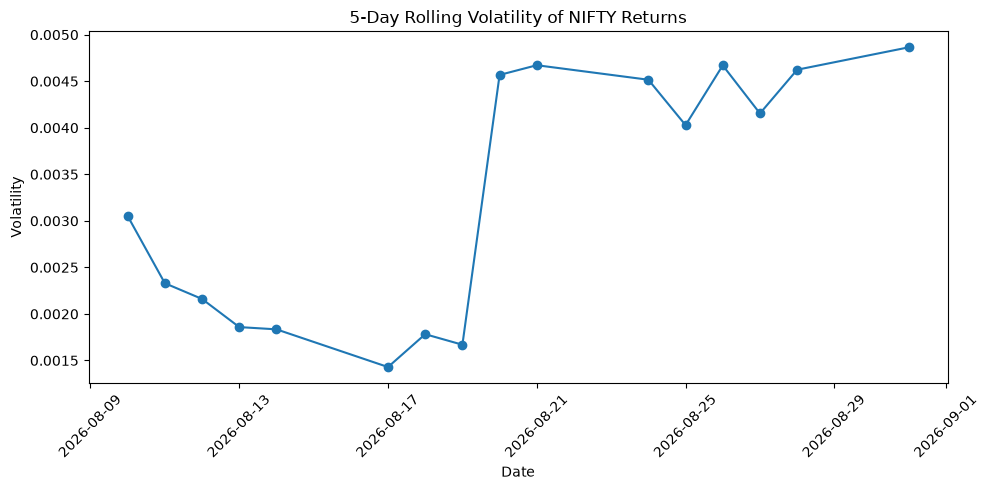

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5)) #overall canvas where plot be made

#now actual plot designing from basically its index what would be what data should be present everything
plt.plot(
    returns.index,
    rolling_volatility_5d,
    marker="o" #for marking
)

plt.title("5-Day Rolling Volatility of NIFTY Returns")
plt.xlabel("Date")
plt.ylabel("Volatility")

plt.xticks(rotation=45) #for fixing or readablity adjustment
plt.tight_layout()  #adjusting spacing
plt.show()

In [16]:
five_returns = returns.loc[
    "2026-08-10":"2026-08-14",
    "Simple_Return"
]

five_returns

Date
2026-08-10    0.000535
2026-08-11   -0.004560
2026-08-12   -0.001461
2026-08-13   -0.001641
2026-08-14   -0.001224
Name: Simple_Return, dtype: float64

In [17]:
five_returns.mean()

np.float64(-0.0016700404799946168)

In [18]:
five_returns.std()

np.float64(0.0018343115714468514)

In [19]:
returns["Squared_Return"] = returns["Simple_Return"] ** 2

In [20]:
lambda_ = 0.94

returns["EWMA_Variance"] = np.nan
valid_returns = returns["Simple_Return"].dropna()

### Prototype EWMA — Initial Variance Convention

The EWMA recursion requires an initial variance estimate. For this prototype,
the initial variance is set equal to the sample variance of the first five
available simple returns.

The initial variance is assigned to the fifth usable return observation,
corresponding to 10 August 2026.

This initialization is a prototype convention used to demonstrate the EWMA
recursion. The formal forecasting framework later defines the estimation
window and initial state consistently within the chronological
training/validation/out-of-sample design.


In [21]:
initial_variance = valid_returns.iloc[:5].var()

initial_date = valid_returns.index[4]

returns.loc[initial_date, "EWMA_Variance"] = initial_variance

print("Initial date:", initial_date)
print("Initial variance:", initial_variance)

Initial date: 2026-08-10 00:00:00
Initial variance: 9.312179701354635e-06


In [22]:
returns[["Simple_Return", "EWMA_Variance"]].head(10)

,Simple_Return,EWMA_Variance
Date,,
2026-08-03,NaN,NaN
2026-08-04,-0.006434,NaN
2026-08-05,0.000396,NaN
2026-08-06,0.000461,NaN
2026-08-07,-0.002653,NaN
2026-08-10,0.000535,0.000009
2026-08-11,-0.004560,NaN
2026-08-12,-0.001461,NaN
2026-08-13,-0.001641,NaN


In [23]:
for i in range(5, len(returns)):

    previous_date = returns.index[i - 1]
    current_date = returns.index[i]

    previous_variance = returns.loc[
        previous_date, "EWMA_Variance"
    ]

    previous_return = returns.loc[
        previous_date, "Simple_Return"
    ]

    if pd.notna(previous_variance) and pd.notna(previous_return):
        returns.loc[current_date, "EWMA_Variance"] = (
            lambda_ * previous_variance
            + (1 - lambda_) * previous_return**2
        )

### Prototype Verification — EWMA Lagged Information Timing

The EWMA recursion is implemented using the previous trading day's return and
previous variance to generate the current day's variance estimate.

This preserves the one-step-ahead information set: the return observed on day
`t` is not used to generate the variance estimate for day `t`.

The recursive implementation is retained as the prototype reference for the
formal out-of-sample EWMA forecasting procedure.


In [24]:
returns["EWMA_Volatility"] = np.sqrt(
    returns["EWMA_Variance"]
)

returns[
    ["Simple_Return", "EWMA_Variance", "EWMA_Volatility"]
].loc["2026-08-10":]

,Simple_Return,EWMA_Variance,EWMA_Volatility
Date,,,
2026-08-10,0.000535,0.000009,0.003052
2026-08-11,-0.004560,0.000009,0.002962
2026-08-12,-0.001461,0.000009,0.003081
2026-08-13,-0.001641,0.000009,0.003008
2026-08-14,-0.001224,0.000009,0.002944
2026-08-17,-0.003216,0.000008,0.002870
2026-08-18,-0.005466,0.000008,0.002892
2026-08-19,-0.003171,0.000010,0.003107
2026-08-20,0.006377,0.000010,0.003111


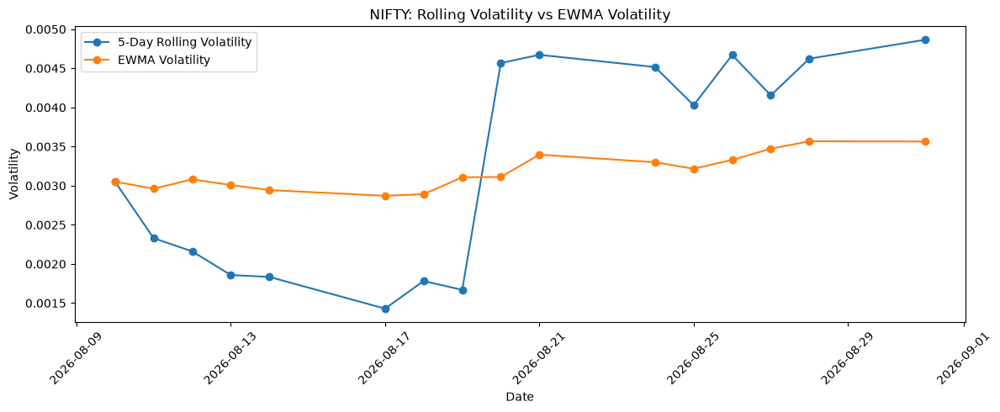

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    returns.index,
    rolling_volatility_5d,
    label="5-Day Rolling Volatility",
    marker="o"
)

plt.plot(
    returns.index,
    returns["EWMA_Volatility"],
    label="EWMA Volatility",
    marker="o"
)

plt.title("NIFTY: Rolling Volatility vs EWMA Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
import arch

print("arch version:", arch.__version__)

arch version: 8.0.0


In [27]:
import sys
print(sys.executable)

import scipy
print("SciPy:", scipy.__version__)

import arch
print("arch:", arch.__version__)

d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Scripts\python.exe
SciPy: 1.18.1
arch: 8.0.0


### Prototype GARCH — Return Scaling Convention

For the `arch` model, simple returns are converted from decimal units to
percentage points by multiplying by 100.

This scaling is used for numerical stability and model estimation. Therefore,
the fitted GARCH parameters and conditional variances are expressed in the
corresponding percentage-return scale.

When volatility forecasts are later compared with the canonical research
dataset, the percentage-scale forecasts must be converted back to decimal
units where required.

This prototype uses simple returns to demonstrate GARCH estimation. The formal
research framework subsequently uses the predefined return representation and
chronological out-of-sample forecasting design.

In [28]:
from arch import arch_model

garch_returns = returns["Simple_Return"].dropna() * 100

garch_returns.head()

Date
2026-08-04   -0.643410
2026-08-05    0.039610
2026-08-06    0.046090
2026-08-07   -0.265261
2026-08-10    0.053521
Name: Simple_Return, dtype: float64

In [29]:
garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_result = garch_model.fit(disp="off")
print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:          Simple_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -6.53793
Distribution:                  Normal   AIC:                           21.0759
Method:            Maximum Likelihood   BIC:                           25.0588
                                        No. Observations:                   20
Date:                Sun, Oct 18 2026   Df Residuals:                       19
Time:                        21:06:02   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu            -0.1467  7.586e-02     -1.933  5.318e-02 [ -0.295,

In [30]:
garch_result.params

mu         -1.466797e-01
omega       2.213654e-03
alpha[1]    1.937164e-14
beta[1]     1.000000e+00
Name: params, dtype: float64

In [31]:
alpha = garch_result.params["alpha[1]"]
beta = garch_result.params["beta[1]"]

persistence = alpha + beta

print("Alpha:", alpha)
print("Beta:", beta)
print("Alpha + Beta:", persistence)

Alpha: 1.937164185694276e-14
Beta: 0.9999999999999736
Alpha + Beta: 0.9999999999999929


In [32]:
garch_volatility = garch_result.conditional_volatility

garch_volatility

Date
2026-08-04    0.323061
2026-08-05    0.326469
2026-08-06    0.329842
2026-08-07    0.333180
2026-08-10    0.336486
2026-08-11    0.339759
2026-08-12    0.343002
2026-08-13    0.346213
2026-08-14    0.349396
2026-08-17    0.352549
2026-08-18    0.355675
2026-08-19    0.358773
2026-08-20    0.361845
2026-08-21    0.364891
2026-08-24    0.367912
2026-08-25    0.370908
2026-08-26    0.373880
2026-08-27    0.376829
2026-08-28    0.379755
2026-08-31    0.382659
Name: cond_vol, dtype: float64

In [33]:
persistence = alpha + beta

### Prototype Volatility Comparison — Unit Harmonization

The rolling and EWMA volatility estimates are stored in decimal-return units,
whereas the prototype GARCH model was estimated using returns scaled by 100
and therefore reports conditional volatility in percentage-return units.

For comparison, the rolling and EWMA estimates are multiplied by 100 so that
all three series are expressed as daily volatility in percentage units.

This unit conversion is specific to the prototype comparison. The formal
research pipeline uses an explicitly documented and consistent unit convention
when constructing and evaluating the final forecasting datasets.

In [34]:
volatility_comparison = pd.DataFrame({
    "Rolling_5D": rolling_volatility_5d * 100,
    "EWMA": returns["EWMA_Volatility"] * 100,
    "GARCH": garch_volatility
})

volatility_comparison

,Rolling_5D,EWMA,GARCH
Date,,,
2026-08-03,NaN,NaN,NaN
2026-08-04,NaN,NaN,0.323061
2026-08-05,NaN,NaN,0.326469
2026-08-06,NaN,NaN,0.329842
2026-08-07,NaN,NaN,0.333180
2026-08-10,0.305159,0.305159,0.336486
2026-08-11,0.232971,0.296153,0.339759
2026-08-12,0.216070,0.308091,0.343002
2026-08-13,0.185852,0.300841,0.346213


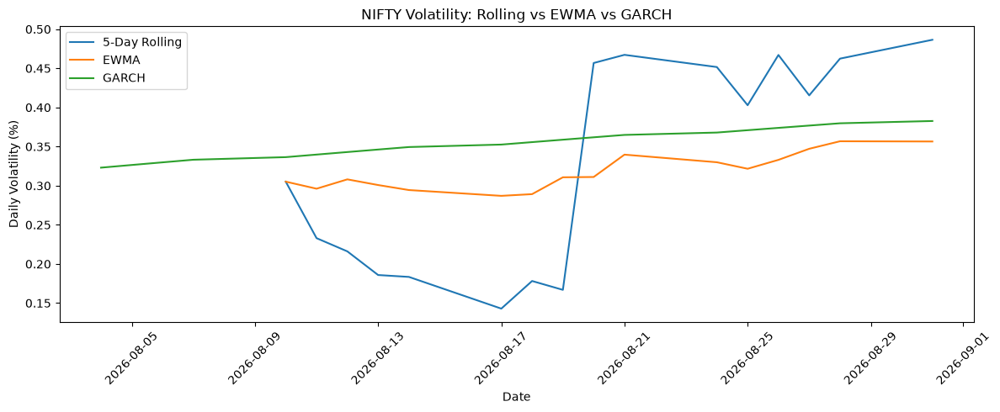

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(
    volatility_comparison.index,
    volatility_comparison["Rolling_5D"],
    label="5-Day Rolling"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["EWMA"],
    label="EWMA"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["GARCH"],
    label="GARCH"
)

plt.title("NIFTY Volatility: Rolling vs EWMA vs GARCH")
plt.xlabel("Date")
plt.ylabel("Daily Volatility (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
volatility_comparison.loc[
    "2026-08-19":"2026-08-21"
]

,Rolling_5D,EWMA,GARCH
Date,,,
2026-08-19,0.166900,0.310731,0.358773
2026-08-20,0.456780,0.311118,0.361845
2026-08-21,0.467215,0.339686,0.364891


In [37]:
import numpy as np
from scipy.stats import norm

In [38]:
def black_scholes_call(S, K, T, r, sigma):

    d1 = (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    call_price = (
        S * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    return call_price

In [39]:
price = black_scholes_call(
    S=25000,
    K=25000,
    T=30/365,
    r=0.06,
    sigma=0.20
)

print(price)

633.981073884901


In [40]:
volatilities = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35]

for sigma in volatilities:
    price = black_scholes_call(
        S=25000,
        K=25000,
        T=30/365,
        r=0.06,
        sigma=sigma
    )

    print(
        f"Volatility: {sigma:.0%} | "
        f"Option Price: ₹{price:.2f}"
    )

Volatility: 10% | Option Price: ₹350.92
Volatility: 15% | Option Price: ₹492.11
Volatility: 20% | Option Price: ₹633.98
Volatility: 25% | Option Price: ₹776.10
Volatility: 30% | Option Price: ₹918.32
Volatility: 35% | Option Price: ₹1060.58


In [41]:
from scipy.optimize import brentq

### Prototype Implied Volatility

Implied volatility is obtained by numerically solving for the volatility
that makes the Black-Scholes model price equal to a specified option price.

For this prototype, the option price of ₹700 is a synthetic input rather than
an observed market quote. Therefore, the resulting implied volatility is
illustrative and is not treated as observed market implied volatility.

Actual market-implied volatility would require synchronized option-market
data together with the relevant strike, maturity, underlying price,
risk-free rate, and option quote.

In [42]:
def iv_objective(sigma):
    model_price = black_scholes_call(
        S=25000,
        K=25000,
        T=30/365,
        r=0.06,
        sigma=sigma
    )

    return model_price - 700

In [43]:
implied_volatility = brentq(
    iv_objective,
    0.01,
    2.00
)

print("Implied Volatility:", implied_volatility)
print(
    "Implied Volatility (%):",
    implied_volatility * 100
)

Implied Volatility: 0.2232334750035197
Implied Volatility (%): 22.32334750035197


In [44]:
from pathlib import Path
import os
import sys

print("Current working directory:")
print(os.getcwd())

print("\nNotebook-visible files:")
print(list(Path(".").iterdir())[:10])

print("\nPython import paths:")
for path in sys.path:
    print(path)

Current working directory:
D:\DS Projects\Adaptive Market Risk Intelligence System

Notebook-visible files:
[WindowsPath('.git'), WindowsPath('.gitignore'), WindowsPath('.gitignore.backup_20261015_213226'), WindowsPath('.venv'), WindowsPath('app'), WindowsPath('Audit'), WindowsPath('backup_before_return_patch_20261011_171934'), WindowsPath('backup_before_return_patch_fixed_20261011_172012'), WindowsPath('config'), WindowsPath('dashboards')]

Python import paths:
C:\Users\user\AppData\Local\Programs\Python\Python313\python313.zip
C:\Users\user\AppData\Local\Programs\Python\Python313\DLLs
C:\Users\user\AppData\Local\Programs\Python\Python313\Lib
C:\Users\user\AppData\Local\Programs\Python\Python313
d:\DS Projects\Adaptive Market Risk Intelligence System\.venv

d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Lib\site-packages
D:\DS Projects\Adaptive Market Risk Intelligence System\src


In [45]:
from pathlib import Path

project_root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")

print("src exists:", (project_root / "src").exists())
print("ingestion exists:", (project_root / "src" / "ingestion").exists())
print("nifty.py exists:", (project_root / "src" / "ingestion" / "nifty.py").exists())
print("__init__.py in src:", (project_root / "src" / "__init__.py").exists())
print("__init__.py in ingestion:", (project_root / "src" / "ingestion" / "__init__.py").exists())

src exists: True
ingestion exists: True
nifty.py exists: True
__init__.py in src: False
__init__.py in ingestion: True


In [46]:
from ingestion.nifty import download_nifty_data

print("Import successful!")

Import successful!


# 02 — Data Acquisition & Raw Data Validation

The prototype phase above used a short August 2026 NIFTY sample to develop and
verify basic return, volatility, GARCH, and derivatives calculations.

This section begins the canonical research dataset workflow.

The full NIFTY 50 sample is downloaded, its structure and data quality are
validated, and the validated data are subsequently transformed into the
canonical cleaned dataset used by the formal empirical analysis.

All later modelling, validation, and out-of-sample evaluation should be based
on this canonical dataset rather than the earlier prototype objects.

### 02.1 — Canonical NIFTY Data Validation

In [47]:
nifty = download_nifty_data(
    start_date="2018-01-01",
    end_date="2026-09-23"
)

print("Shape:", nifty.shape)

print("\nFirst 5 rows:")
print(nifty.head())

print("\nLast 5 rows:")
print(nifty.tail())

Shape: (2150, 6)

First 5 rows:
Price          Adj Close         Close          High           Low  \
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   
Date                                                                 
2018-01-02  10442.200195  10442.200195  10495.200195  10404.650391   
2018-01-03  10443.200195  10443.200195  10503.599609  10429.549805   
2018-01-04  10504.799805  10504.799805  10513.000000  10441.450195   
2018-01-05  10558.849609  10558.849609  10566.099609  10520.099609   
2018-01-08  10623.599609  10623.599609  10631.200195  10588.549805   

Price               Open  Volume  
Ticker             ^NSEI   ^NSEI  
Date                              
2018-01-02  10477.549805  153400  
2018-01-03  10482.650391  167300  
2018-01-04  10469.400391  174900  
2018-01-05  10534.250000  180900  
2018-01-08  10591.700195  169000  

Last 5 rows:
Price          Adj Close         Close          High           Low  \
Ticker             ^NSEI         ^NSEI     

In [48]:
print("Shape:", nifty.shape)

print("\nColumn structure:")
print(nifty.columns)

print("\nIndex:")
print(nifty.index)

print("\nData types:")
print(nifty.dtypes)

Shape: (2150, 6)

Column structure:
MultiIndex([('Adj Close', '^NSEI'),
            (    'Close', '^NSEI'),
            (     'High', '^NSEI'),
            (      'Low', '^NSEI'),
            (     'Open', '^NSEI'),
            (   'Volume', '^NSEI')],
           names=['Price', 'Ticker'])

Index:
DatetimeIndex(['2018-01-02', '2018-01-03', '2018-01-04', '2018-01-05',
               '2018-01-08', '2018-01-09', '2018-01-10', '2018-01-11',
               '2018-01-12', '2018-01-15',
               ...
               '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11',
               '2026-09-15', '2026-09-16', '2026-09-17', '2026-09-18',
               '2026-09-21', '2026-09-22'],
              dtype='datetime64[s]', name='Date', length=2150, freq=None)

Data types:
Price      Ticker
Adj Close  ^NSEI     float64
Close      ^NSEI     float64
High       ^NSEI     float64
Low        ^NSEI     float64
Open       ^NSEI     float64
Volume     ^NSEI       int64
dtype: object


In [49]:
print("Start date:", nifty.index.min())
print("End date:", nifty.index.max())
print("Number of observations:", len(nifty))

Start date: 2018-01-02 00:00:00
End date: 2026-09-22 00:00:00
Number of observations: 2150


In [50]:
print("Duplicate dates:", nifty.index.duplicated().sum())

Duplicate dates: 0


In [51]:
print(nifty.isna().sum())

Price      Ticker
Adj Close  ^NSEI     0
Close      ^NSEI     0
High       ^NSEI     0
Low        ^NSEI     0
Open       ^NSEI     0
Volume     ^NSEI     0
dtype: int64


### Raw Data Quality — Zero Reported Volume

The raw dataset contains 27 observations with reported Volume equal to zero.
The corresponding OHLC price observations are present and valid.

Because the primary volatility analysis is based on NIFTY price returns rather
than volume, these observations are not removed solely because of the zero
Volume field.

The zero-volume observations are retained in the canonical price dataset.
Volume is treated as a supplementary field and is not used as a mandatory
filter for the return-based volatility models.

In [52]:
zero_volume = nifty[nifty[("Volume", "^NSEI")] == 0]

print("Zero-volume observations:", len(zero_volume))
print(zero_volume)

Zero-volume observations: 27
Price          Adj Close         Close          High           Low  \
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   
Date                                                                 
2018-04-27  10692.299805  10692.299805  10719.799805  10647.549805   
2018-05-21  10516.700195  10516.700195  10621.700195  10505.799805   
2018-07-06  10772.650391  10772.650391  10816.349609  10735.049805   
2018-07-13  11018.900391  11018.900391  11071.349609  10999.750000   
2018-08-10  11429.500000  11429.500000  11478.750000  11419.650391   
2018-09-11  11287.500000  11287.500000  11479.400391  11274.000000   
2018-09-24  10967.400391  10967.400391  11170.150391  10943.599609   
2018-10-10  10460.099609  10460.099609  10482.349609  10318.250000   
2018-10-25  10124.900391  10124.900391  10166.599609  10079.299805   
2018-11-06  10530.000000  10530.000000  10600.250000  10491.450195   
2018-11-15  10616.700195  10616.700195  10646.500000  10557.5

In [53]:
close = nifty[("Close", "^NSEI")]
high = nifty[("High", "^NSEI")]
low = nifty[("Low", "^NSEI")]
open_price = nifty[("Open", "^NSEI")]

print("High < Low:", (high < low).sum())
print("High < Open:", (high < open_price).sum())
print("High < Close:", (high < close).sum())
print("Low > Open:", (low > open_price).sum())
print("Low > Close:", (low > close).sum())

High < Low: 0
High < Open: 0
High < Close: 0
Low > Open: 0
Low > Close: 0


In [54]:
missing_adj_close = nifty[nifty[("Adj Close", "^NSEI")].isna()]

print("Missing Adj Close observations:", len(missing_adj_close))
print(missing_adj_close)
print("Missing Close values:", nifty[("Close", "^NSEI")].isna().sum())

Missing Adj Close observations: 0
Empty DataFrame
Columns: [(Adj Close, ^NSEI), (Close, ^NSEI), (High, ^NSEI), (Low, ^NSEI), (Open, ^NSEI), (Volume, ^NSEI)]
Index: []
Missing Close values: 0


### Canonical Dataset Construction

The validated raw NIFTY dataset is converted from the downloader's MultiIndex
structure into a flat research DataFrame.

The canonical dataset retains Date, Open, High, Low, Close, and Volume.

The analysis uses the NIFTY index Close series for return construction.
Adjusted Close is therefore not carried into the canonical modelling dataset.

In [55]:
clean_nifty = pd.DataFrame({
    "Date": nifty.index,
    "Open": nifty[("Open", "^NSEI")].values,
    "High": nifty[("High", "^NSEI")].values,
    "Low": nifty[("Low", "^NSEI")].values,
    "Close": nifty[("Close", "^NSEI")].values,
    "Volume": nifty[("Volume", "^NSEI")].values
})

clean_nifty.head()

,Date,Open,High,Low,Close,Volume
0,2018-01-02,10477.549805,10495.200195,10404.650391,10442.200195,153400
1,2018-01-03,10482.650391,10503.599609,10429.549805,10443.200195,167300
2,2018-01-04,10469.400391,10513.000000,10441.450195,10504.799805,174900
3,2018-01-05,10534.250000,10566.099609,10520.099609,10558.849609,180900
4,2018-01-08,10591.700195,10631.200195,10588.549805,10623.599609,169000


In [56]:
clean_nifty = clean_nifty.dropna(subset=["Close"]).copy()

In [57]:
clean_nifty = clean_nifty.reset_index(drop=True)

In [58]:
print("Shape:", clean_nifty.shape)
print("\nMissing values:")
print(clean_nifty.isna().sum())

print("\nDate range:")
print(clean_nifty["Date"].min(), "to", clean_nifty["Date"].max())

print("\nLast 5 observations:")
print(clean_nifty.tail())

Shape: (2150, 6)

Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Date range:
2018-01-02 00:00:00 to 2026-09-22 00:00:00

Last 5 observations:
           Date          Open          High           Low         Close  \
2145 2026-09-16  23201.599609  23284.750000  23116.099609  23217.599609   
2146 2026-09-17  23195.250000  23363.550781  23193.650391  23270.599609   
2147 2026-09-18  23334.699219  23389.150391  23286.599609  23346.400391   
2148 2026-09-21  23330.199219  23466.800781  23314.800781  23414.300781   
2149 2026-09-22  23454.050781  23489.000000  23285.750000  23329.000000   

      Volume  
2145  261600  
2146  259700  
2147  375300  
2148  213600  
2149  244100  


In [59]:
from pathlib import Path

# Save cleaned NIFTY price data before feature engineering
output_path = PROCESSED_DATA_DIR / "nifty50_prices_clean.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

clean_nifty.to_csv(output_path, index=False)

print("Saved cleaned NIFTY price data to:")
print(output_path)

Saved cleaned NIFTY price data to:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\processed\nifty50_prices_clean.csv


In [60]:
import numpy as np

clean_nifty["Simple_Return"] = (
    clean_nifty["Close"].pct_change()
)

clean_nifty["Log_Return"] = (
    np.log(
        clean_nifty["Close"] /
        clean_nifty["Close"].shift(1)
    )
)

In [61]:
print("Simple return missing:",
      clean_nifty["Simple_Return"].isna().sum())

print("Log return missing:",
      clean_nifty["Log_Return"].isna().sum())

Simple return missing: 1
Log return missing: 1


In [62]:
print(
    clean_nifty[
        ["Date", "Close", "Simple_Return", "Log_Return"]
    ].head(10)
)

        Date         Close  Simple_Return  Log_Return
0 2018-01-02  10442.200195            NaN         NaN
1 2018-01-03  10443.200195       0.000096    0.000096
2 2018-01-04  10504.799805       0.005899    0.005881
3 2018-01-05  10558.849609       0.005145    0.005132
4 2018-01-08  10623.599609       0.006132    0.006114
5 2018-01-09  10637.000000       0.001261    0.001261
6 2018-01-10  10632.200195      -0.000451   -0.000451
7 2018-01-11  10651.200195       0.001787    0.001785
8 2018-01-12  10681.250000       0.002821    0.002817
9 2018-01-15  10741.549805       0.005645    0.005630


In [63]:
print(
    clean_nifty[
        ["Simple_Return", "Log_Return"]
    ].describe()
)

       Simple_Return   Log_Return
count    2149.000000  2149.000000
mean        0.000431     0.000374
std         0.010631     0.010699
min        -0.129805    -0.139038
25%        -0.004498    -0.004508
50%         0.000625     0.000624
75%         0.005955     0.005937
max         0.087632     0.084003


In [64]:
largest_moves = clean_nifty[
    ["Date", "Close", "Simple_Return"]
].dropna(subset=["Simple_Return"]).sort_values(
    "Simple_Return"
)

print("Largest negative returns:")
print(largest_moves.head(10))

print("\nLargest positive returns:")
print(largest_moves.tail(10))

Largest negative returns:
           Date         Close  Simple_Return
542  2020-03-23   7610.250000      -0.129805
535  2020-03-12   9590.150391      -0.083019
537  2020-03-16   9197.400391      -0.076121
1579 2024-06-04  21884.500000      -0.059294
567  2020-05-04   9293.500000      -0.057445
539  2020-03-18   8468.799805      -0.055565
533  2020-03-09  10451.450195      -0.048956
1021 2022-02-24  16247.950195      -0.047781
547  2020-03-30   8281.099609      -0.043781
549  2020-04-01   8253.799805      -0.040005

Largest positive returns:
           Date         Close  Simple_Return
536  2020-03-13   9955.200195       0.038065
1810 2025-05-12  24924.699219       0.038183
548  2020-03-31   8597.750000       0.038238
545  2020-03-26   8641.450195       0.038904
553  2020-04-09   9111.900391       0.041509
756  2021-02-01  14281.200195       0.047424
419  2019-09-20  11274.200195       0.053191
541  2020-03-20   8745.450195       0.058329
544  2020-03-25   8317.849609       0.066247
55

In [65]:
# Volatility features based on log returns
clean_nifty["Squared_Return"] = (
    clean_nifty["Log_Return"] ** 2
)

clean_nifty["Absolute_Return"] = (
    clean_nifty["Log_Return"].abs()
)

In [66]:
print(
    clean_nifty[
        [
            "Date",
            "Simple_Return",
            "Absolute_Return",
            "Squared_Return"
        ]
    ].head(10)
)

        Date  Simple_Return  Absolute_Return  Squared_Return
0 2018-01-02            NaN              NaN             NaN
1 2018-01-03       0.000096         0.000096    9.170107e-09
2 2018-01-04       0.005899         0.005881    3.458862e-05
3 2018-01-05       0.005145         0.005132    2.633801e-05
4 2018-01-08       0.006132         0.006114    3.737575e-05
5 2018-01-09       0.001261         0.001261    1.589074e-06
6 2018-01-10      -0.000451         0.000451    2.037065e-07
7 2018-01-11       0.001787         0.001785    3.187758e-06
8 2018-01-12       0.002821         0.002817    7.937110e-06
9 2018-01-15       0.005645         0.005630    3.169142e-05


### Exploratory Volatility Clustering — Absolute Returns

Absolute daily returns are used as a simple observable proxy for the magnitude
of market movements.

Periods containing sustained clusters of large absolute returns indicate that
large market movements tend to occur close together in time, providing
descriptive motivation for conditional-volatility modelling.

This visualization is exploratory evidence only; formal volatility dynamics
are evaluated later using statistical models and out-of-sample forecasts.

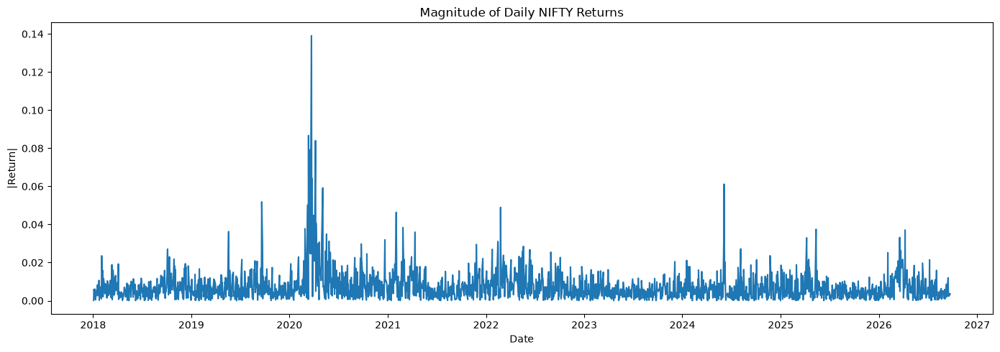

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    clean_nifty["Date"],
    clean_nifty["Absolute_Return"]
)

plt.title("Magnitude of Daily NIFTY Returns")
plt.xlabel("Date")
plt.ylabel("|Return|")

plt.tight_layout()
plt.show()

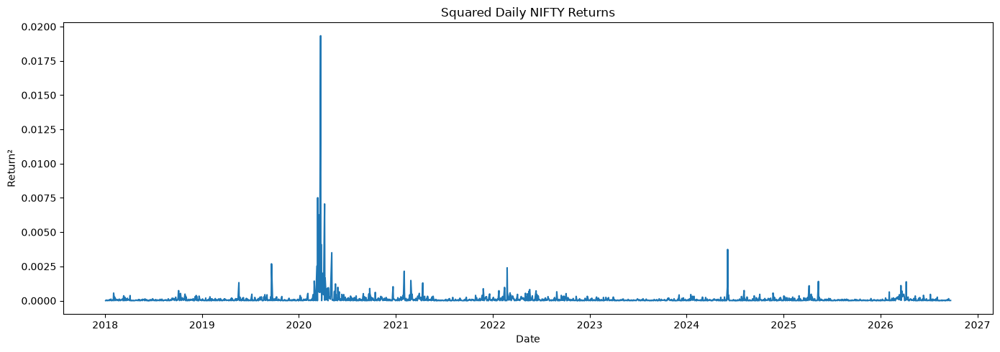

In [68]:
plt.figure(figsize=(14, 5))

plt.plot(
    clean_nifty["Date"],
    clean_nifty["Squared_Return"]
)

plt.title("Squared Daily NIFTY Returns")
plt.xlabel("Date")
plt.ylabel("Return²")

plt.tight_layout()
plt.show()

In [69]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["Simple_Return"] * 100,
        mode="lines",
        name="Daily Return"
    )
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.update_layout(
    title="NIFTY 50 Daily Returns — 2018 to 2026",
    xaxis_title="Date",
    yaxis_title="Daily Return (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [70]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["Absolute_Return"] * 100,
        mode="lines",
        name="Absolute Return"
    )
)

fig.update_layout(
    title="NIFTY 50 Daily Return Magnitude — 2018 to 2026",
    xaxis_title="Date",
    yaxis_title="Absolute Return (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [71]:
crisis_2020 = clean_nifty[
    (clean_nifty["Date"] >= "2020-03-01") &
    (clean_nifty["Date"] <= "2020-05-31")
].copy()

In [72]:
fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=crisis_2020["Date"],
        y=crisis_2020["Simple_Return"] * 100,
        name="Daily Return"
    )
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.update_layout(
    title="NIFTY 50 Daily Returns — March to May 2020",
    xaxis_title="Date",
    yaxis_title="Daily Return (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [73]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=crisis_2020["Date"],
        y=crisis_2020["Close"],
        mode="lines",
        name="NIFTY Close"
    )
)

fig.update_layout(
    title="NIFTY 50 Price — March to May 2020",
    xaxis_title="Date",
    yaxis_title="NIFTY Level",
    hovermode="x unified",
    height=500
)

fig.show()

In [74]:
clean_nifty["Rolling_Vol_5D"] = (
    clean_nifty["Log_Return"]
    .rolling(window=5)
    .std()
)

clean_nifty["Rolling_Vol_5D_Annualized"] = (
    clean_nifty["Rolling_Vol_5D"] * np.sqrt(252)
)

In [75]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["Rolling_Vol_5D_Annualized"] * 100,
        mode="lines",
        name="5-Day Rolling Volatility"
    )
)

fig.update_layout(
    title="NIFTY 50 — 5-Day Rolling Annualized Volatility",
    xaxis_title="Date",
    yaxis_title="Annualized Volatility (%)",
    hovermode="x unified",
    height=600
)

fig.show()

### Exploratory EWMA Volatility — Full-Sample Initialization

The EWMA volatility series below is constructed as an exploratory full-sample
volatility measure using a decay factor of λ = 0.94.

The initial variance is calculated from the full available return sample.
Therefore, this exploratory series is not interpreted as a strictly
real-time forecasting series because its initial state incorporates information
from the complete sample.

The formal out-of-sample EWMA forecasting framework later uses an
information-set-consistent initialization and recursive updating procedure.

This distinction is important to prevent the exploratory EWMA series from
being interpreted as an uncontaminated forecast.

In [76]:
lambda_ewma = 0.94

clean_nifty["EWMA_Variance"] = np.nan

initial_variance = clean_nifty["Log_Return"].var()

clean_nifty.loc[1, "EWMA_Variance"] = initial_variance

for i in range(2, len(clean_nifty)):
    previous_variance = clean_nifty.loc[i - 1, "EWMA_Variance"]
    previous_return = clean_nifty.loc[i - 1, "Log_Return"]

    clean_nifty.loc[i, "EWMA_Variance"] = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * previous_return**2
    )

clean_nifty["EWMA_Volatility"] = np.sqrt(
    clean_nifty["EWMA_Variance"]
)

clean_nifty["EWMA_Volatility_Annualized"] = (
    clean_nifty["EWMA_Volatility"] * np.sqrt(252)
)

In [77]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["EWMA_Volatility_Annualized"] * 100,
        mode="lines",
        name="EWMA Volatility"
    )
)

fig.update_layout(
    title="NIFTY 50 — EWMA Annualized Volatility",
    xaxis_title="Date",
    yaxis_title="Annualized Volatility (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [78]:
from pathlib import Path

# ============================================================
# EXPLORATORY NIFTY OUTPUT DIRECTORY
# ============================================================

output_dir = EXPLORATORY_NIFTY_DIR

output_dir.mkdir(parents=True, exist_ok=True)

print("Exploratory NIFTY output folder:")
print(output_dir)

Exploratory NIFTY output folder:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\exploratory\nifty50


In [79]:
fig.write_html(
    EXPLORATORY_NIFTY_DIR / "daily_returns.html"
)

fig.show()

In [80]:
fig.write_html(
    EXPLORATORY_NIFTY_DIR / "daily_returns.html"
)

fig.show()

In [81]:
fig.write_html(
    EXPLORATORY_NIFTY_DIR / "daily_returns.html"
)

### Baseline GARCH(1,1) — Full-Sample Statistical Model

A baseline GARCH(1,1) model with constant mean and normally distributed
innovations is estimated using the complete available log-return sample.

Returns are multiplied by 100 for numerical scaling in the `arch` framework.

This model establishes a benchmark conditional-volatility specification.
Its fitted parameters are used for model understanding and exploratory
analysis; formal forecasting performance is evaluated later using the
chronologically separated validation and out-of-sample framework.

The baseline model is intentionally retained before introducing alternative
innovation distributions and asymmetric volatility specifications.

In [82]:
from arch import arch_model

garch_returns = clean_nifty["Log_Return"].dropna() * 100

garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_result = garch_model.fit(
    disp="off"
)

print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2768.36
Distribution:                  Normal   AIC:                           5544.71
Method:            Maximum Likelihood   BIC:                           5567.40
                                        No. Observations:                 2149
Date:                Sun, Oct 18 2026   Df Residuals:                     2148
Time:                        21:06:09   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0591  1.903e-02      3.104  1.908e-03 [2.

In [83]:
garch_volatility = garch_result.conditional_volatility

clean_nifty.loc[
    garch_volatility.index,
    "GARCH_Volatility"
] = garch_volatility

clean_nifty["GARCH_Volatility_Annualized"] = (
    clean_nifty["GARCH_Volatility"] / 100 * np.sqrt(252)
)

In [84]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["GARCH_Volatility_Annualized"] * 100,
        mode="lines",
        name="GARCH Volatility"
    )
)

fig.update_layout(
    title="NIFTY 50 — GARCH(1,1) Annualized Conditional Volatility",
    xaxis_title="Date",
    yaxis_title="Annualized Volatility (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [85]:
standardized_residuals = garch_result.std_resid.dropna()

print("Number of standardized residuals:", len(standardized_residuals))
print("\nFirst 5 standardized residuals:")
print(standardized_residuals.head())

Number of standardized residuals: 2149

First 5 standardized residuals:
1   -0.073773
2    0.822976
3    0.704844
4    0.864800
5    0.104156
Name: std_resid, dtype: float64


In [86]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty.loc[
            standardized_residuals.index, "Date"
        ],
        y=standardized_residuals,
        mode="lines",
        name="Standardized Residual"
    )
)

fig.add_hline(y=0, line_dash="dash")

fig.update_layout(
    title="GARCH Standardized Residuals",
    xaxis_title="Date",
    yaxis_title="Standardized Residual",
    hovermode="x unified",
    height=600
)

fig.show()

In [87]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty.loc[
            standardized_residuals.index, "Date"
        ],
        y=standardized_residuals**2,
        mode="lines",
        name="Squared Standardized Residual"
    )
)

fig.update_layout(
    title="Squared GARCH Standardized Residuals",
    xaxis_title="Date",
    yaxis_title="Squared Standardized Residual",
    hovermode="x unified",
    height=600
)

fig.show()

In [88]:
from statsmodels.stats.diagnostic import acorr_ljungbox

In [89]:
lb_residuals = acorr_ljungbox(
    standardized_residuals,
    lags=[10, 20],
    return_df=True
)

print("Ljung-Box test — standardized residuals")
print(lb_residuals)

Ljung-Box test — standardized residuals
      lb_stat  lb_pvalue
10  12.238612   0.269405
20  19.047088   0.518767


### Baseline GARCH Diagnostic — Standardized Residual Autocorrelation

The Ljung–Box test is applied to the standardized residuals at lags 10 and
20.

The resulting p-values do not provide evidence of statistically significant
autocorrelation at the tested lags.

This indicates that the baseline GARCH model has removed the main linear
serial-correlation patterns detectable by these tests. The result should not
be interpreted as proof that the residuals are independently distributed or
that the model is fully adequate, since other forms of misspecification
require separate diagnostics.

In [90]:
lb_squared = acorr_ljungbox(
    standardized_residuals**2,
    lags=[10, 20],
    return_df=True
)

print("\nLjung-Box test — squared standardized residuals")
print(lb_squared)


Ljung-Box test — squared standardized residuals
      lb_stat  lb_pvalue
10  10.264993   0.417560
20  17.686123   0.608076


### Baseline GARCH Diagnostic — Remaining Volatility Dependence

The Ljung–Box test is also applied to squared standardized residuals to assess
whether systematic serial dependence remains in the conditional variance after
fitting the baseline GARCH model.

The p-values at lags 10 and 20 do not provide evidence of statistically
significant autocorrelation in the squared standardized residuals at the
tested lags.

This provides diagnostic evidence that the baseline GARCH specification
captures substantial volatility dependence in the sample. It does not by
itself establish complete model adequacy, and additional distributional and
specification diagnostics are considered below.

In [91]:
print("Standardized residual statistics:")
print(standardized_residuals.describe())

Standardized residual statistics:
count    2149.000000
mean       -0.035325
std         0.998943
min        -4.874530
25%        -0.614889
50%         0.003278
75%         0.626590
max         5.060780
Name: std_resid, dtype: float64


### Baseline GARCH Diagnostic — Residual Distribution

The standardized residuals exhibit modest negative skewness and kurtosis above
the normal-distribution benchmark of 3.

Because the kurtosis estimate is calculated with `fisher=False`, the reported
value of 4.755 represents ordinary kurtosis rather than excess kurtosis.

The heavier-tailed residual behavior provides empirical motivation for
estimating an alternative GARCH specification with Student-t innovations.
This motivates the transition from the baseline Normal-GARCH model to the
Student-t GARCH model below.

In [92]:
from scipy.stats import skew, kurtosis

residual_skewness = skew(standardized_residuals)
residual_kurtosis = kurtosis(
    standardized_residuals,
    fisher=False
)

print("Skewness:", residual_skewness)
print("Kurtosis:", residual_kurtosis)

Skewness: -0.32146152358833846
Kurtosis: 4.7550878612955385


In [93]:
fig = go.Figure()

fig.add_trace(
    go.Histogram(
        x=standardized_residuals,
        nbinsx=60,
        name="Standardized Residuals"
    )
)

fig.update_layout(
    title="Distribution of GARCH Standardized Residuals",
    xaxis_title="Standardized Residual",
    yaxis_title="Frequency",
    height=600
)

fig.show()

### Baseline GARCH Diagnostic — Residual Distribution

The standardized residuals exhibit modest negative skewness and kurtosis above
the normal-distribution benchmark of 3.

Because the kurtosis estimate is calculated with `fisher=False`, the reported
value of 4.755 represents ordinary kurtosis rather than excess kurtosis.

The heavier-tailed residual behavior provides empirical motivation for
estimating an alternative GARCH specification with Student-t innovations.
This motivates the transition from the baseline Normal-GARCH model to the
Student-t GARCH model below.

In [94]:
garch_t_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_t_result = garch_t_model.fit(
    disp="off"
)

print(garch_t_result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -2718.90
Distribution:      Standardized Student's t   AIC:                           5447.80
Method:                  Maximum Likelihood   BIC:                           5476.17
                                              No. Observations:                 2149
Date:                      Sun, Oct 18 2026   Df Residuals:                     2148
Time:                              21:06:09   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### Student-t GARCH Diagnostic Check

The Student-t GARCH specification is evaluated using Ljung–Box tests on both
standardized residuals and squared standardized residuals.

At lags 10 and 20, the tests do not provide evidence of statistically
significant remaining autocorrelation in either the standardized residuals or
their squares.

These diagnostics support the adequacy of the fitted conditional-mean and
conditional-variance dynamics at the tested lags, while not constituting
proof of complete model specification.

In [95]:
standardized_residuals_t = garch_t_result.std_resid.dropna()

lb_residuals_t = acorr_ljungbox(
    standardized_residuals_t,
    lags=[10, 20],
    return_df=True
)

lb_squared_t = acorr_ljungbox(
    standardized_residuals_t**2,
    lags=[10, 20],
    return_df=True
)

print("Student-t GARCH — standardized residuals")
print(lb_residuals_t)

print("\nStudent-t GARCH — squared standardized residuals")
print(lb_squared_t)

Student-t GARCH — standardized residuals
      lb_stat  lb_pvalue
10  11.962436   0.287578
20  18.430387   0.559079

Student-t GARCH — squared standardized residuals
      lb_stat  lb_pvalue
10  14.577458   0.148243
20  22.417017   0.318317


# 03 — Formal Out-of-Sample Volatility Forecasting

The exploratory and full-sample diagnostic analysis above establishes the
baseline volatility behaviour and candidate model specifications.

The analysis now moves to formal out-of-sample forecasting.

The forecasting experiment uses a fixed chronological split:

- Training period: 2018-01-03 to 2023-12-29
- Out-of-sample test period: 2024-01-01 to 2026-09-22

The test period is not used for model estimation or parameter fitting.

Forecasts for the test period must use only information available at or before
the corresponding forecast origin. This information-set constraint is applied
throughout the subsequent forecasting and model-comparison framework.

In [96]:
forecast_data = clean_nifty[
    ["Date", "Log_Return", "Simple_Return"]
].dropna().copy()

forecast_data = forecast_data.reset_index(drop=True)

train_end_date = "2023-12-31"

train_data = forecast_data[
    forecast_data["Date"] <= train_end_date
].copy()

test_data = forecast_data[
    forecast_data["Date"] > train_end_date
].copy()

print("Training period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))

Training period:
2018-01-03 00:00:00 to 2023-12-29 00:00:00

Testing period:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

Training observations: 1476
Testing observations: 673


### Historical Volatility Benchmark — One-Day-Ahead Timing

The 20-day historical volatility benchmark is calculated using returns
available through day `t`.

This estimate is used as the forecast for day `t+1`. Therefore, the return
observed on day `t+1` is not included in the forecast information set.

The subsequent forecast-alignment check explicitly pairs the estimate at `t`
with realized volatility at `t+1`.

In [97]:
forecast_data["Historical_Volatility_20D"] = (
    forecast_data["Log_Return"]
    .rolling(20)
    .std()
)

### EWMA Benchmark — Training-Period Initialization

For the formal forecasting experiment, the initial EWMA variance is estimated
using the available training-period log returns only.

The EWMA recursion is then propagated chronologically through the full dataset,
using the previous trading day's return and previous variance to generate each
day's variance estimate.

The out-of-sample period therefore does not contribute to the initial
variance estimate.

This fixed training-period initialization is distinct from the full-sample
exploratory EWMA construction used earlier in the notebook.

In [98]:
lambda_ewma = 0.94
initial_window = 20

forecast_data = forecast_data.sort_values("Date").reset_index(drop=True)
forecast_data["Date"] = pd.to_datetime(forecast_data["Date"])

returns = forecast_data["Log_Return"].astype(float)
ewma_variance = pd.Series(np.nan, index=forecast_data.index, dtype=float)

if len(returns.dropna()) <= initial_window:
    raise ValueError("Not enough returns to initialize EWMA.")

# Initialize the variance using the first 20 observed returns.
# It becomes the forecast variance for the following observation.
initial_variance = returns.iloc[:initial_window].var()

ewma_variance.iloc[initial_window] = initial_variance

# At row t, update with return from t-1 to produce variance for t.
for t in range(initial_window + 1, len(forecast_data)):
    previous_variance = ewma_variance.iloc[t - 1]
    previous_return = returns.iloc[t - 1]

    ewma_variance.iloc[t] = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * previous_return**2
    )

forecast_data["EWMA_Variance"] = ewma_variance
forecast_data["EWMA_Volatility"] = np.sqrt(ewma_variance)

print("EWMA initialization:", initial_window, "past returns")
print("Missing EWMA values:", forecast_data["EWMA_Volatility"].isna().sum())

EWMA initialization: 20 past returns
Missing EWMA values: 20


### One-Day Realized Volatility Proxy

For one-day-ahead forecast evaluation, absolute log return is used as the
realized-volatility proxy:

\[
RV_t^{proxy}=|r_t|
\]

This measure is observable after the return occurs and is used as the
evaluation target for the corresponding one-day-ahead forecast.

It is a realized volatility proxy rather than a direct observation of the
latent conditional volatility process.

In [99]:
forecast_data["Realized_Volatility_1D"] = (
    forecast_data["Log_Return"].abs()
)
print(
    forecast_data[
        ["Date", "Log_Return", "Realized_Volatility_1D"]
    ].head(10)
)

        Date  Log_Return  Realized_Volatility_1D
0 2018-01-03    0.000096                0.000096
1 2018-01-04    0.005881                0.005881
2 2018-01-05    0.005132                0.005132
3 2018-01-08    0.006114                0.006114
4 2018-01-09    0.001261                0.001261
5 2018-01-10   -0.000451                0.000451
6 2018-01-11    0.001785                0.001785
7 2018-01-12    0.002817                0.002817
8 2018-01-15    0.005630                0.005630
9 2018-01-16   -0.003834                0.003834


### Forecast-Target Alignment Check

The benchmark forecast generated using information through day `t` is aligned
with the realized volatility observed on day `t+1`.

This explicit alignment check is retained to verify the one-day-ahead forecasting
horizon and prevent accidental same-day target leakage.

In [100]:
alignment_check = forecast_data[
    ["Date", "Log_Return", "Historical_Volatility_20D"]
].copy()

alignment_check["Forecast_Date"] = alignment_check["Date"].shift(1)
alignment_check["Actual_Next_Day"] = (
    forecast_data["Log_Return"].abs()
)

alignment_check["Target_Date"] = alignment_check["Date"]

# Forecast for this row's date must be based on the previous row's estimate.
alignment_check["Historical_OneStep_Forecast"] = (
    alignment_check["Historical_Volatility_20D"].shift(1)
)

alignment_check = alignment_check.dropna(
    subset=["Historical_OneStep_Forecast", "Actual_Next_Day"]
)

assert (
    alignment_check["Forecast_Date"].to_numpy()
    < alignment_check["Target_Date"].to_numpy()
).all()

assert alignment_check["Historical_OneStep_Forecast"].notna().all()
assert alignment_check["Actual_Next_Day"].notna().all()

display(alignment_check.head())
display(alignment_check.tail())
print("Historical forecast timing check passed.")

,Date,Log_Return,Historical_Volatility_20D,Forecast_Date,Actual_Next_Day,Target_Date,Historical_OneStep_Forecast
20,2018-02-01,-0.000980,0.004510,2018-01-31,0.000980,2018-02-01,0.004471
21,2018-02-02,-0.023539,0.007327,2018-02-01,0.023539,2018-02-02,0.004510
22,2018-02-05,-0.008779,0.007590,2018-02-02,0.008779,2018-02-05,0.007327
23,2018-02-06,-0.015904,0.008298,2018-02-05,0.015904,2018-02-06,0.007590
24,2018-02-07,-0.002055,0.008292,2018-02-06,0.002055,2018-02-07,0.008298


,Date,Log_Return,Historical_Volatility_20D,Forecast_Date,Actual_Next_Day,Target_Date,Historical_OneStep_Forecast
2144,2026-09-16,0.004273,0.004760,2026-09-15,0.004273,2026-09-16,0.004582
2145,2026-09-17,0.002280,0.004843,2026-09-16,0.002280,2026-09-17,0.004760
2146,2026-09-18,0.003252,0.004615,2026-09-17,0.003252,2026-09-18,0.004843
2147,2026-09-21,0.002904,0.004701,2026-09-18,0.002904,2026-09-21,0.004615
2148,2026-09-22,-0.003650,0.004719,2026-09-21,0.003650,2026-09-22,0.004701


Historical forecast timing check passed.


### Formal OOS GARCH-t Estimation

The Student-t GARCH(1,1) specification is now re-estimated using only the
predefined training period, ending 31 December 2023.

No observations from the 2024–2026 out-of-sample test period are used for
parameter estimation.

The fitted training-only model provides the parameter estimates and terminal
conditional-volatility state required to generate the subsequent one-step-
ahead out-of-sample forecasts.

This model is therefore distinct from the earlier full-sample GARCH-t model,
which was used for exploratory specification and distributional diagnostics.

In [101]:
from arch import arch_model

# Training returns only
train_returns = train_data["Log_Return"] * 100

garch_oos_model = arch_model(
    train_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_oos_result = garch_oos_model.fit(disp="off")

print(garch_oos_result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1935.88
Distribution:      Standardized Student's t   AIC:                           3881.76
Method:                  Maximum Likelihood   BIC:                           3908.24
                                              No. Observations:                 1476
Date:                      Sun, Oct 18 2026   Df Residuals:                     1475
Time:                              21:06:10   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [102]:
params = garch_oos_result.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
beta = params["beta[1]"]

print("mu:", mu)
print("omega:", omega)
print("alpha:", alpha)
print("beta:", beta)
print("alpha + beta:", alpha + beta)

mu: 0.09955410387134064
omega: 0.026594067281686663
alpha: 0.09680964130832649
beta: 0.8770782935998263
alpha + beta: 0.9738879349081527


### Superseded GARCH-t Recursive Forecast — Leakage Demonstration

The recursive implementation below is retained as part of the research
development history but is **not part of the canonical forecasting pipeline**.

The implementation was identified as invalid because it uses the current
observation's return to construct the volatility forecast for that same
observation. This violates the one-step-ahead information-set constraint and
introduces look-ahead leakage.

The state update also does not correctly incorporate the newly observed
return into the GARCH recursion.

This experiment is therefore retained only to document the methodological
correction. The canonical recursive implementation appears below.

In [103]:
"""
import numpy as np

# Variance from the final training observation
last_train_variance = (
    garch_oos_result.conditional_volatility.iloc[-1] ** 2
)

garch_forecasts = []

previous_variance = last_train_variance

for _, row in test_data.iterrows():

    # Forecast for today's return, using information available yesterday
    forecast_variance = (
        omega
        + alpha * (
            (row["Log_Return"] * 100 - mu) ** 2
        )
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    garch_forecasts.append(forecast_volatility)

    # After today's return becomes known,
    # update the variance for the next forecast
    previous_variance = forecast_variance

"""

'\nimport numpy as np\n\n# Variance from the final training observation\nlast_train_variance = (\n    garch_oos_result.conditional_volatility.iloc[-1] ** 2\n)\n\ngarch_forecasts = []\n\nprevious_variance = last_train_variance\n\nfor _, row in test_data.iterrows():\n\n    # Forecast for today\'s return, using information available yesterday\n    forecast_variance = (\n        omega\n        + alpha * (\n            (row["Log_Return"] * 100 - mu) ** 2\n        )\n        + beta * previous_variance\n    )\n\n    forecast_volatility = np.sqrt(forecast_variance)\n\n    garch_forecasts.append(forecast_volatility)\n\n    # After today\'s return becomes known,\n    # update the variance for the next forecast\n    previous_variance = forecast_variance\n\n'

### Superseded GARCH-t Recursive Forecast — Incomplete Variance Recursion

The implementation below represents an intermediate correction attempt.

Although it avoids using the current return directly in the forecast, it does
not reproduce the complete GARCH(1,1) variance recursion because the lagged
return innovation term is omitted.

It is retained as methodological development history but is not used for the
canonical out-of-sample forecasts or model evaluation.

In [104]:
"""
garch_forecasts = []

previous_variance = last_train_variance

for _, row in test_data.iterrows():

    # Forecast today's volatility using yesterday's information
    forecast_variance = (
        omega
        + alpha * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    garch_forecasts.append(forecast_volatility)

    # Now observe today's return
    current_return = row["Log_Return"] * 100

    # Update variance for the next day
    previous_variance = (
        omega
        + alpha * (current_return - mu) ** 2
        + beta * previous_variance
    )
"""

'\ngarch_forecasts = []\n\nprevious_variance = last_train_variance\n\nfor _, row in test_data.iterrows():\n\n    # Forecast today\'s volatility using yesterday\'s information\n    forecast_variance = (\n        omega\n        + alpha * previous_variance\n    )\n\n    forecast_volatility = np.sqrt(forecast_variance)\n\n    garch_forecasts.append(forecast_volatility)\n\n    # Now observe today\'s return\n    current_return = row["Log_Return"] * 100\n\n    # Update variance for the next day\n    previous_variance = (\n        omega\n        + alpha * (current_return - mu) ** 2\n        + beta * previous_variance\n    )\n'

In [105]:
"""
test_data = test_data.copy()

test_data["GARCH_T_Volatility"] = garch_forecasts

test_data["GARCH_T_Volatility"] = (
    test_data["GARCH_T_Volatility"] / 100
)

print(
    test_data[
        [
            "Date",
            "Log_Return",
            "GARCH_T_Volatility"
        ]
    ].head(10)
)
"""

'\ntest_data = test_data.copy()\n\ntest_data["GARCH_T_Volatility"] = garch_forecasts\n\ntest_data["GARCH_T_Volatility"] = (\n    test_data["GARCH_T_Volatility"] / 100\n)\n\nprint(\n    test_data[\n        [\n            "Date",\n            "Log_Return",\n            "GARCH_T_Volatility"\n        ]\n    ].head(10)\n)\n'

### Superseded Forecast Output

The model summary below is valid and documents the training-only GARCH-t
estimation.

The displayed forecast values, however, were generated by the earlier
superseded recursive implementation and are retained only as development
history. They are not used in the final forecasting evaluation.

In [106]:
"""
print(garch_oos_result.summary())

print(
    test_data[
        ["Date", "Log_Return", "GARCH_T_Volatility"]
    ].head(10)
)
"""

'\nprint(garch_oos_result.summary())\n\nprint(\n    test_data[\n        ["Date", "Log_Return", "GARCH_T_Volatility"]\n    ].head(10)\n)\n'

In [107]:
# Last observed training return
previous_return = train_data["Log_Return"].iloc[-1] * 100

# Last conditional variance estimated from the fitted GARCH-t model
previous_variance = (
    garch_oos_result.conditional_volatility.iloc[-1] ** 2
)

garch_forecasts = []
garch_updated_variances = []

for _, row in test_data.iterrows():

    # ---------------------------------------------------------
    # 1. Forecast today's conditional variance
    #    using information available through yesterday
    # ---------------------------------------------------------
    forecast_variance = (
        omega
        + alpha * (previous_return - mu) ** 2
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert volatility from percentage units back to decimal
    garch_forecasts.append(forecast_volatility / 100)

    # ---------------------------------------------------------
    # 2. Observe today's return
    # ---------------------------------------------------------
    current_return = row["Log_Return"] * 100

    # ---------------------------------------------------------
    # 3. Update conditional variance using today's information
    #    for tomorrow's forecast
    # ---------------------------------------------------------
    updated_variance = (
        omega
        + alpha * (current_return - mu) ** 2
        + beta * forecast_variance
    )

    garch_updated_variances.append(updated_variance)

    # ---------------------------------------------------------
    # 4. Move state forward
    # ---------------------------------------------------------
    previous_return = current_return
    previous_variance = updated_variance

In [108]:
test_data["GARCH_T_Volatility"] = garch_forecasts

print(
    test_data[
        ["Date", "Log_Return", "GARCH_T_Volatility"]
    ].head(10)
)

           Date  Log_Return  GARCH_T_Volatility
1476 2024-01-01    0.000483            0.007547
1477 2024-01-02   -0.003506            0.006990
1478 2024-01-03   -0.006875            0.006801
1479 2024-01-04    0.006543            0.007200
1480 2024-01-05    0.002407            0.007104
1481 2024-01-08   -0.009152            0.006646
1482 2024-01-09    0.001479            0.007595
1483 2024-01-10    0.003422            0.007029
1484 2024-01-11    0.001317            0.006639
1485 2024-01-12    0.011362            0.006238


In [109]:
evaluation = test_data[
    ["Date", "Log_Return", "GARCH_T_Volatility"]
].copy()

evaluation["Actual_Volatility"] = (
    evaluation["Log_Return"].abs()
)

evaluation.head(10)

,Date,Log_Return,GARCH_T_Volatility,Actual_Volatility
1476,2024-01-01,0.000483,0.007547,0.000483
1477,2024-01-02,-0.003506,0.006990,0.003506
1478,2024-01-03,-0.006875,0.006801,0.006875
1479,2024-01-04,0.006543,0.007200,0.006543
1480,2024-01-05,0.002407,0.007104,0.002407
1481,2024-01-08,-0.009152,0.006646,0.009152
1482,2024-01-09,0.001479,0.007595,0.001479
1483,2024-01-10,0.003422,0.007029,0.003422
1484,2024-01-11,0.001317,0.006639,0.001317
1485,2024-01-12,0.011362,0.006238,0.011362


### Superseded Historical Forecast Alignment

The direct date merge below represents an intermediate benchmark construction.

The formal one-step-ahead historical-volatility forecast must use the
volatility estimate available before the target day's return is observed.

The subsequently shifted `Historical_Next_Day` series is therefore used for
the canonical evaluation.

In [110]:
"""
historical_forecast = forecast_data[
    [
        "Date",
        "Historical_Volatility_20D"
    ]
].copy()

evaluation = evaluation.merge(
    historical_forecast,
    on="Date",
    how="left"
)

print(evaluation.head(10))
"""

'\nhistorical_forecast = forecast_data[\n    [\n        "Date",\n        "Historical_Volatility_20D"\n    ]\n].copy()\n\nevaluation = evaluation.merge(\n    historical_forecast,\n    on="Date",\n    how="left"\n)\n\nprint(evaluation.head(10))\n'

### Historical Volatility — One-Step-Ahead Forecast Alignment

To construct a strictly information-set-consistent benchmark, the 20-day
historical volatility estimate from the previous trading day is used as the
forecast for the current trading day.

Thus, for target day `t`:

\[
\widehat{\sigma}_{t|t-1}
=
\sigma^{Historical}_{t-1}
\]

The one-period shift prevents the current day's return from entering its own
forecast.

In [111]:

historical_forecast = forecast_data[
    ["Date", "Historical_Volatility_20D"]
].copy()

historical_forecast["Historical_Next_Day"] = (
    historical_forecast["Historical_Volatility_20D"].shift(1)
)

historical_forecast = historical_forecast[
    ["Date", "Historical_Next_Day"]
]

In [112]:
evaluation = test_data[
    [
        "Date",
        "Log_Return",
        "GARCH_T_Volatility"
    ]
].copy()

evaluation["Actual_Volatility"] = (
    evaluation["Log_Return"].abs()
)

evaluation = evaluation.merge(
    historical_forecast,
    on="Date",
    how="left"
)

evaluation = evaluation.dropna(
    subset=[
        "GARCH_T_Volatility",
        "Historical_Next_Day",
        "Actual_Volatility"
    ]
).copy()

print(
    evaluation[
        [
            "Date",
            "GARCH_T_Volatility",
            "Historical_Next_Day",
            "Actual_Volatility"
        ]
    ].head(10)
)

        Date  GARCH_T_Volatility  Historical_Next_Day  Actual_Volatility
0 2024-01-01            0.007547             0.007280           0.000483
1 2024-01-02            0.006990             0.007284           0.003506
2 2024-01-03            0.006801             0.006246           0.006875
3 2024-01-04            0.007200             0.006411           0.006543
4 2024-01-05            0.007104             0.006488           0.002407
5 2024-01-08            0.006646             0.006438           0.009152
6 2024-01-09            0.007595             0.006883           0.001479
7 2024-01-10            0.007029             0.006883           0.003422
8 2024-01-11            0.006639             0.006767           0.001317
9 2024-01-12            0.006238             0.006766           0.011362


In [113]:
evaluation = evaluation.rename(
    columns={
        "GARCH_T_Volatility": "GARCH_T_OneStep_Forecast",
        "Historical_Next_Day": "Historical_OneStep_Forecast"
    }
)

In [114]:
print(
    evaluation[
        [
            "Date",
            "GARCH_T_OneStep_Forecast",
            "Historical_OneStep_Forecast",
            "Actual_Volatility"
        ]
    ].head(10)
)

        Date  GARCH_T_OneStep_Forecast  Historical_OneStep_Forecast  \
0 2024-01-01                  0.007547                     0.007280   
1 2024-01-02                  0.006990                     0.007284   
2 2024-01-03                  0.006801                     0.006246   
3 2024-01-04                  0.007200                     0.006411   
4 2024-01-05                  0.007104                     0.006488   
5 2024-01-08                  0.006646                     0.006438   
6 2024-01-09                  0.007595                     0.006883   
7 2024-01-10                  0.007029                     0.006883   
8 2024-01-11                  0.006639                     0.006767   
9 2024-01-12                  0.006238                     0.006766   

   Actual_Volatility  
0           0.000483  
1           0.003506  
2           0.006875  
3           0.006543  
4           0.002407  
5           0.009152  
6           0.001479  
7           0.003422  
8          

In [115]:
evaluation["GARCH_Error"] = (
    evaluation["GARCH_T_OneStep_Forecast"]
    - evaluation["Actual_Volatility"]
)

evaluation["Historical_Error"] = (
    evaluation["Historical_OneStep_Forecast"]
    - evaluation["Actual_Volatility"]
)

evaluation["GARCH_Absolute_Error"] = (
    evaluation["GARCH_Error"].abs()
)

evaluation["Historical_Absolute_Error"] = (
    evaluation["Historical_Error"].abs()
)

In [116]:
print(
    evaluation[
        [
            "Date",
            "GARCH_T_OneStep_Forecast",
            "Historical_OneStep_Forecast",
            "Actual_Volatility",
            "GARCH_Absolute_Error",
            "Historical_Absolute_Error"
        ]
    ].head(10)
)

        Date  GARCH_T_OneStep_Forecast  Historical_OneStep_Forecast  \
0 2024-01-01                  0.007547                     0.007280   
1 2024-01-02                  0.006990                     0.007284   
2 2024-01-03                  0.006801                     0.006246   
3 2024-01-04                  0.007200                     0.006411   
4 2024-01-05                  0.007104                     0.006488   
5 2024-01-08                  0.006646                     0.006438   
6 2024-01-09                  0.007595                     0.006883   
7 2024-01-10                  0.007029                     0.006883   
8 2024-01-11                  0.006639                     0.006767   
9 2024-01-12                  0.006238                     0.006766   

   Actual_Volatility  GARCH_Absolute_Error  Historical_Absolute_Error  
0           0.000483              0.007064                   0.006797  
1           0.003506              0.003484                   0.003777  
2 

In [117]:
garch_mae = evaluation["GARCH_Absolute_Error"].mean()
historical_mae = evaluation["Historical_Absolute_Error"].mean()

garch_rmse = np.sqrt(
    (evaluation["GARCH_Error"] ** 2).mean()
)

historical_rmse = np.sqrt(
    (evaluation["Historical_Error"] ** 2).mean()
)

model_comparison = pd.DataFrame({
    "Model": [
        "Historical 20D",
        "GARCH-t"
    ],
    "MAE": [
        historical_mae,
        garch_mae
    ],
    "RMSE": [
        historical_rmse,
        garch_rmse
    ],
    "MAE_%": [
        historical_mae * 100,
        garch_mae * 100
    ],
    "RMSE_%": [
        historical_rmse * 100,
        garch_rmse * 100
    ]
})

print(model_comparison)

            Model       MAE      RMSE     MAE_%    RMSE_%
0  Historical 20D  0.004923  0.006564  0.492256  0.656388
1         GARCH-t  0.004852  0.006291  0.485176  0.629068


### Initial OOS Comparison — GARCH-t vs Historical Volatility

The first formal out-of-sample comparison evaluates the training-only GARCH-t
model against the 20-day historical-volatility benchmark over the untouched
2024–2026 test period.

Using absolute log return as the one-day realized-volatility proxy, GARCH-t
produces lower MAE and RMSE than the historical benchmark in this initial
comparison.

These results constitute empirical forecasting evidence for the specified
test period and evaluation proxy. They are not interpreted as definitive
model superiority at this stage because additional volatility specifications,
asymmetric models, market-information extensions, and further statistical
evaluation are part of the research framework.

The comparison is therefore treated as the baseline result against which
subsequent candidate models are evaluated.

### Relative OOS Improvement — GARCH-t vs Historical Benchmark

The relative improvement in MAE and RMSE is calculated to express the
difference between the GARCH-t forecast and the 20-day historical-volatility
benchmark in percentage terms.

A positive value indicates that GARCH-t has a lower error than the historical
benchmark for the specified out-of-sample period and evaluation target.

These figures are descriptive performance measures for the current test
period. They are not interpreted as evidence of universal or statistically
significant superiority.

In [118]:
mae_improvement = (
    (historical_mae - garch_mae)
    / historical_mae
) * 100

rmse_improvement = (
    (historical_rmse - garch_rmse)
    / historical_rmse
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

MAE improvement: 1.44%
RMSE improvement: 4.16%


### Canonical EWMA One-Step-Ahead Out-of-Sample Forecasting

The EWMA model is evaluated as a formal one-step-ahead volatility forecasting
benchmark using the untouched 2024–2026 test period.

The initial variance is estimated exclusively from the training-period log
returns. The test period is therefore not used to initialize the model.

For each test observation, the current day's volatility forecast is generated
from the variance state available before observing that day's return. After
the return is observed, the EWMA variance is updated and carried forward to
the next trading day.

The recursion is:

\[
\sigma_t^2 =
\lambda\sigma_{t-1}^2
+
(1-\lambda)r_{t-1}^2
\]

with \(\lambda=0.94\).

This preserves the one-step-ahead information set and prevents the target
day's return from entering its own forecast.

In [119]:
lambda_ewma = 0.94

# Initial variance based only on training data
previous_variance = (
    train_data["Log_Return"].var()
)

ewma_forecasts = []

for _, row in test_data.iterrows():

    # Forecast today's volatility
    forecast_volatility = np.sqrt(
        previous_variance
    )

    ewma_forecasts.append(
        forecast_volatility
    )

    # Observe today's return
    current_return = row["Log_Return"]

    # Update variance for next trading day
    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

test_data["EWMA_OneStep_Forecast"] = ewma_forecasts

### OOS Evaluation Dataset — EWMA Integration

The canonical EWMA one-step-ahead forecasts are added to the existing
out-of-sample evaluation dataset.

The resulting dataset allows the EWMA benchmark to be evaluated using the
same dates, realized-volatility proxy, and error framework already applied to
the Historical 20D and GARCH-t forecasts.

In [120]:
evaluation = evaluation.merge(
    test_data[
        [
            "Date",
            "EWMA_OneStep_Forecast"
        ]
    ],
    on="Date",
    how="left"
)

print(
    evaluation[
        [
            "Date",
            "Historical_OneStep_Forecast",
            "EWMA_OneStep_Forecast",
            "GARCH_T_OneStep_Forecast",
            "Actual_Volatility"
        ]
    ].head(10)
)

        Date  Historical_OneStep_Forecast  EWMA_OneStep_Forecast  \
0 2024-01-01                     0.007280               0.011568   
1 2024-01-02                     0.007284               0.011216   
2 2024-01-03                     0.006246               0.010908   
3 2024-01-04                     0.006411               0.010709   
4 2024-01-05                     0.006488               0.010506   
5 2024-01-08                     0.006438               0.010203   
6 2024-01-09                     0.006883               0.010143   
7 2024-01-10                     0.006883               0.009840   
8 2024-01-11                     0.006767               0.009577   
9 2024-01-12                     0.006766               0.009291   

   GARCH_T_OneStep_Forecast  Actual_Volatility  
0                  0.007547           0.000483  
1                  0.006990           0.003506  
2                  0.006801           0.006875  
3                  0.007200           0.006543  
4     

In [121]:
evaluation["EWMA_Error"] = (
    evaluation["EWMA_OneStep_Forecast"]
    - evaluation["Actual_Volatility"]
)

evaluation["EWMA_Absolute_Error"] = (
    evaluation["EWMA_Error"].abs()
)

### EWMA Forecast Error Construction

EWMA forecast errors are calculated using the same definitions applied to the
other forecasting models.

This ensures that MAE and RMSE comparisons across Historical 20D, EWMA, and
GARCH-t are based on a common evaluation target and identical error
definitions.

### EWMA Out-of-Sample Performance

The EWMA benchmark is evaluated over the same untouched test period and
against the same absolute-log-return realized-volatility proxy used for the
other candidate models.

The resulting MAE and RMSE are retained as empirical out-of-sample evidence
for comparison with the Historical 20D and GARCH-t forecasts.

Final model interpretation is deferred until the complete set of candidate
models and subsequent statistical comparisons has been evaluated.

In [122]:
ewma_mae = (
    evaluation["EWMA_Absolute_Error"]
    .mean()
)

ewma_rmse = np.sqrt(
    (
        evaluation["EWMA_Error"] ** 2
    ).mean()
)

print("EWMA MAE:", ewma_mae)
print("EWMA RMSE:", ewma_rmse)

print("EWMA MAE (%):", ewma_mae * 100)
print("EWMA RMSE (%):", ewma_rmse * 100)

EWMA MAE: 0.004923945891875731
EWMA RMSE: 0.006418738256370729
EWMA MAE (%): 0.4923945891875731
EWMA RMSE (%): 0.6418738256370728


### EWMA Out-of-Sample Performance

The EWMA benchmark is evaluated over the same untouched test period and
against the same absolute-log-return realized-volatility proxy used for the
other candidate models.

The resulting MAE and RMSE are retained as empirical out-of-sample evidence
for comparison with the Historical 20D and GARCH-t forecasts.

Final model interpretation is deferred until the complete set of candidate
models and subsequent statistical comparisons has been evaluated.

In [123]:
print("test_data columns:")
print(test_data.columns.tolist())

print("\nEvaluation columns:")
print(evaluation.columns.tolist())

test_data columns:
['Date', 'Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast']

Evaluation columns:
['Date', 'Log_Return', 'GARCH_T_OneStep_Forecast', 'Actual_Volatility', 'Historical_OneStep_Forecast', 'GARCH_Error', 'Historical_Error', 'GARCH_Absolute_Error', 'Historical_Absolute_Error', 'EWMA_OneStep_Forecast', 'EWMA_Error', 'EWMA_Absolute_Error']


### Redundant EWMA Recreation — Not Executed

The code below previously recreated the EWMA one-step-ahead forecasts.

It produces the same forecast series as the canonical implementation in
Cell 137 and does not introduce a new experiment, alternative specification,
or independent validation.

It is therefore not executed in the final notebook flow.

Cell 137 remains the single canonical EWMA forecasting implementation.

In [124]:
"""
# ============================================================
# Recreate EWMA one-step-ahead forecasts
# ============================================================

lambda_ewma = 0.94

# Start with variance estimated only from the training period
previous_variance = train_data["Log_Return"].var()

ewma_forecasts = []

for _, row in test_data.iterrows():

    # Forecast volatility for the current day
    forecast_volatility = np.sqrt(previous_variance)

    ewma_forecasts.append(forecast_volatility)

    # After observing today's return,
    # update variance for the next day's forecast
    current_return = row["Log_Return"]

    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

# Store forecasts
test_data["EWMA_OneStep_Forecast"] = ewma_forecasts

print("EWMA forecasts created.")
print(
    test_data[
        ["Date", "Log_Return", "EWMA_OneStep_Forecast"]
    ].head(10)
)
"""

'\n# ============================================================\n# Recreate EWMA one-step-ahead forecasts\n# ============================================================\n\nlambda_ewma = 0.94\n\n# Start with variance estimated only from the training period\nprevious_variance = train_data["Log_Return"].var()\n\newma_forecasts = []\n\nfor _, row in test_data.iterrows():\n\n    # Forecast volatility for the current day\n    forecast_volatility = np.sqrt(previous_variance)\n\n    ewma_forecasts.append(forecast_volatility)\n\n    # After observing today\'s return,\n    # update variance for the next day\'s forecast\n    current_return = row["Log_Return"]\n\n    previous_variance = (\n        lambda_ewma * previous_variance\n        + (1 - lambda_ewma) * current_return**2\n    )\n\n# Store forecasts\ntest_data["EWMA_OneStep_Forecast"] = ewma_forecasts\n\nprint("EWMA forecasts created.")\nprint(\n    test_data[\n        ["Date", "Log_Return", "EWMA_OneStep_Forecast"]\n    ].head(10)\n)\n'

### Presentation Dataset — LinkedIn Visualization

This cell constructs a presentation-only dataset for the LinkedIn research
visualization.

It combines the canonical out-of-sample components already established in
the formal forecasting analysis:

- one-day realized-volatility proxy,
- Historical 20D one-step-ahead forecast,
- EWMA one-step-ahead forecast,
- GARCH-t one-step-ahead forecast.

The EWMA recursion is reproduced here only to make the visualization dataset
self-contained. This does not constitute a new forecasting experiment or
independent empirical result.

The formal model forecasts and performance metrics remain those generated in
the main out-of-sample evaluation workflow.

In [125]:
# ============================================================
# SELF-CONTAINED LINKEDIN PRESENTATION DATASET
# Rebuilds presentation data from canonical OOS components
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. COPY OOS TEST DATA
# ============================================================

linkedin_data = test_data[
    ["Date", "Log_Return"]
].copy()

linkedin_data["Date"] = pd.to_datetime(
    linkedin_data["Date"]
)

linkedin_data = (
    linkedin_data
    .sort_values("Date")
    .reset_index(drop=True)
)


# ============================================================
# 2. REALIZED-VOLATILITY PROXY
# ============================================================

# Absolute daily log return is the observable one-day
# realized-volatility proxy used throughout the OOS evaluation.

linkedin_data["Actual_Volatility"] = (
    linkedin_data["Log_Return"].abs()
)


# ============================================================
# 3. HISTORICAL 20D ONE-STEP-AHEAD FORECAST
# ============================================================

historical_source = forecast_data[
    ["Date", "Historical_Volatility_20D"]
].copy()

historical_source["Date"] = pd.to_datetime(
    historical_source["Date"]
)

historical_source = (
    historical_source
    .sort_values("Date")
    .reset_index(drop=True)
)

# Shift by one trading day so that the forecast for day t
# uses historical volatility information available through t-1.

historical_source["Historical_OneStep_Forecast"] = (
    historical_source["Historical_Volatility_20D"].shift(1)
)

linkedin_data = linkedin_data.merge(
    historical_source[
        ["Date", "Historical_OneStep_Forecast"]
    ],
    on="Date",
    how="left"
)


# ============================================================
# 4. REBUILD EWMA ONE-STEP-AHEAD FORECASTS
# ============================================================

# This reconstruction is used only for the presentation dataset.
# It is not treated as a new forecasting experiment.

lambda_ewma = 0.94

# Initialize using training-period information only.
previous_variance = (
    train_data["Log_Return"].var()
)

ewma_forecasts = []

for _, row in linkedin_data.iterrows():

    # Forecast today's volatility using information
    # available before today's return is observed.
    forecast_volatility = np.sqrt(
        previous_variance
    )

    ewma_forecasts.append(
        forecast_volatility
    )

    # Observe today's return.
    current_return = row["Log_Return"]

    # Update variance for the next trading day.
    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

linkedin_data["EWMA_OneStep_Forecast"] = (
    ewma_forecasts
)


# ============================================================
# 5. RECOVER CANONICAL GARCH-t FORECASTS
# ============================================================

# GARCH-t forecasts are recovered from the canonical OOS
# evaluation dataset rather than recalculated here.

garch_source = evaluation[
    ["Date", "GARCH_T_OneStep_Forecast"]
].copy()

garch_source["Date"] = pd.to_datetime(
    garch_source["Date"]
)

garch_source = (
    garch_source
    .sort_values("Date")
    .drop_duplicates(subset="Date")
)

linkedin_data = linkedin_data.merge(
    garch_source,
    on="Date",
    how="left"
)


# ============================================================
# 6. CONVERT TO PERCENTAGE UNITS FOR PRESENTATION
# ============================================================

linkedin_data["Actual_Volatility_Pct"] = (
    linkedin_data["Actual_Volatility"] * 100
)

linkedin_data["Historical_20D_Pct"] = (
    linkedin_data["Historical_OneStep_Forecast"] * 100
)

linkedin_data["EWMA_Pct"] = (
    linkedin_data["EWMA_OneStep_Forecast"] * 100
)

linkedin_data["GARCH_t_Pct"] = (
    linkedin_data["GARCH_T_OneStep_Forecast"] * 100
)


# ============================================================
# 7. REMOVE UNEVALUABLE OBSERVATIONS
# ============================================================

linkedin_data = linkedin_data.dropna(
    subset=[
        "Actual_Volatility_Pct",
        "Historical_20D_Pct",
        "EWMA_Pct",
        "GARCH_t_Pct"
    ]
).copy()

linkedin_data = (
    linkedin_data
    .sort_values("Date")
    .reset_index(drop=True)
)


# ============================================================
# 8. FINAL VALIDATION
# ============================================================

print("=" * 60)
print("LINKEDIN PRESENTATION DATASET VALIDATION")
print("=" * 60)

print("\nShape:")
print(linkedin_data.shape)

print("\nDate range:")
print(
    linkedin_data["Date"].min(),
    "→",
    linkedin_data["Date"].max()
)

print("\nColumns:")
print(linkedin_data.columns.tolist())

print("\nMissing values:")
print(
    linkedin_data[
        [
            "Actual_Volatility_Pct",
            "Historical_20D_Pct",
            "EWMA_Pct",
            "GARCH_t_Pct"
        ]
    ].isna().sum()
)

print("\nFirst 5 observations:")
print(
    linkedin_data[
        [
            "Date",
            "Actual_Volatility_Pct",
            "Historical_20D_Pct",
            "EWMA_Pct",
            "GARCH_t_Pct"
        ]
    ].head()
)

LINKEDIN PRESENTATION DATASET VALIDATION

Shape:
(673, 10)

Date range:
2024-01-01 00:00:00 → 2026-09-22 00:00:00

Columns:
['Date', 'Log_Return', 'Actual_Volatility', 'Historical_OneStep_Forecast', 'EWMA_OneStep_Forecast', 'GARCH_T_OneStep_Forecast', 'Actual_Volatility_Pct', 'Historical_20D_Pct', 'EWMA_Pct', 'GARCH_t_Pct']

Missing values:
Actual_Volatility_Pct    0
Historical_20D_Pct       0
EWMA_Pct                 0
GARCH_t_Pct              0
dtype: int64

First 5 observations:
        Date  Actual_Volatility_Pct  Historical_20D_Pct  EWMA_Pct  GARCH_t_Pct
0 2024-01-01               0.048306            0.727971  1.156755     0.754733
1 2024-01-02               0.350628            0.728364  1.121578     0.698990
2 2024-01-03               0.687545            0.624619  1.090797     0.680147
3 2024-01-04               0.654302            0.641110  1.070892     0.719973
4 2024-01-05               0.240728            0.648762  1.050566     0.710352


### Final Out-of-Sample Volatility Visualization

This figure presents the formal NIFTY 50 out-of-sample volatility forecasting
results for the 2024–2026 test period.

Panel A displays the daily realized-volatility proxy as a 20-day rolling mean
for visual readability, together with the three one-step-ahead forecasts.

Panel B reports MAE and RMSE calculated using the original daily
absolute-log-return realized-volatility proxy.

The rolling mean is used only for visualization and does not alter the
forecast-error calculations.

In [126]:
print("linkedin_data available:", "linkedin_data" in globals())
print("RESEARCH_NIFTY_DIR available:", "RESEARCH_NIFTY_DIR" in globals())

if "linkedin_data" in globals():
    print("Dataset shape:", linkedin_data.shape)
    print("Columns:", linkedin_data.columns.tolist())

linkedin_data available: True
RESEARCH_NIFTY_DIR available: True
Dataset shape: (673, 10)
Columns: ['Date', 'Log_Return', 'Actual_Volatility', 'Historical_OneStep_Forecast', 'EWMA_OneStep_Forecast', 'GARCH_T_OneStep_Forecast', 'Actual_Volatility_Pct', 'Historical_20D_Pct', 'EWMA_Pct', 'GARCH_t_Pct']


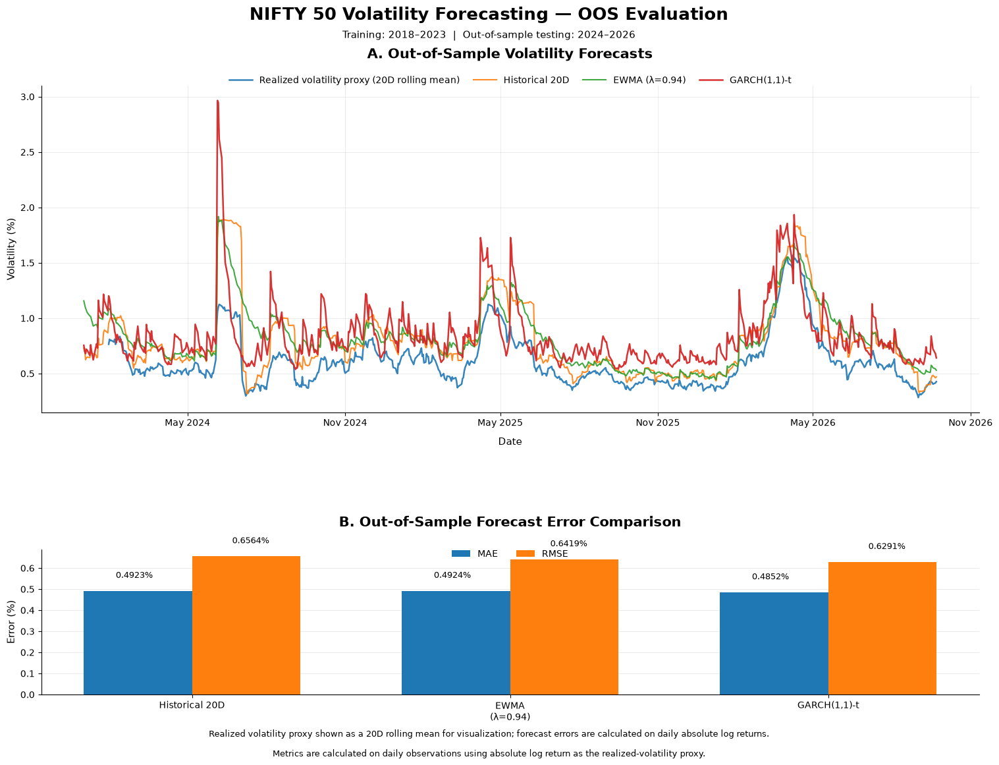

FINAL NIFTY 50 OOS VOLATILITY FIGURE GENERATED

Observations: 673
Date range: 2024-01-01 → 2026-09-22

OOS PERFORMANCE
Historical 20D : MAE 0.4923% | RMSE 0.6564%
EWMA (λ=0.94)  : MAE 0.4924% | RMSE 0.6419%
GARCH-t        : MAE 0.4852% | RMSE 0.6291%

Saved to:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\research\nifty50\nifty_volatility_oos_linkedin_final.png


In [127]:
# ============================================================
# NIFTY 50 — FINAL OOS VOLATILITY FIGURE
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ============================================================
# 1. VALIDATE REQUIRED DATA
# ============================================================

required_columns = [
    "Date",
    "Actual_Volatility",
    "Historical_OneStep_Forecast",
    "EWMA_OneStep_Forecast",
    "GARCH_T_OneStep_Forecast",
]

missing_columns = [
    col
    for col in required_columns
    if col not in linkedin_data.columns
]

if missing_columns:
    raise ValueError(
        f"linkedin_data is missing required columns: {missing_columns}"
    )


# ============================================================
# 2. PREPARE DATA
# ============================================================

plot_data = linkedin_data[
    required_columns
].copy()

plot_data["Date"] = pd.to_datetime(
    plot_data["Date"]
)

plot_data = (
    plot_data
    .sort_values("Date")
    .dropna(subset=required_columns)
    .reset_index(drop=True)
)

if plot_data.empty:
    raise ValueError(
        "No valid observations available for plotting."
    )


# ============================================================
# 3. CONVERT VOLATILITY TO PERCENTAGE UNITS
# ============================================================

plot_data["Actual_Pct"] = (
    plot_data["Actual_Volatility"] * 100
)

plot_data["Historical_Pct"] = (
    plot_data["Historical_OneStep_Forecast"] * 100
)

plot_data["EWMA_Pct"] = (
    plot_data["EWMA_OneStep_Forecast"] * 100
)

plot_data["GARCH_t_Pct"] = (
    plot_data["GARCH_T_OneStep_Forecast"] * 100
)


# ============================================================
# 4. SMOOTH REALIZED-VOLATILITY PROXY FOR DISPLAY ONLY
# ============================================================

# IMPORTANT:
# This rolling mean is used only for visual readability.
# Forecast-error metrics below continue to use the original
# daily Actual_Volatility observations.

plot_data["Actual_20D_Rolling_Pct"] = (
    plot_data["Actual_Pct"]
    .rolling(window=20)
    .mean()
)


# ============================================================
# 5. CALCULATE DAILY OOS PERFORMANCE METRICS
# ============================================================

# Metrics use the ORIGINAL daily realized-volatility proxy,
# not the 20-day rolling visualization series.

actual = plot_data["Actual_Volatility"]

historical = (
    plot_data["Historical_OneStep_Forecast"]
)

ewma = (
    plot_data["EWMA_OneStep_Forecast"]
)

garch = (
    plot_data["GARCH_T_OneStep_Forecast"]
)


def calculate_metrics(forecast, actual):
    """
    Calculate MAE and RMSE for the daily OOS forecast.

    Returned values are expressed in percentage units.
    """

    error = forecast - actual

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(error ** 2)
    )

    return mae * 100, rmse * 100


historical_mae, historical_rmse = (
    calculate_metrics(
        historical,
        actual
    )
)

ewma_mae, ewma_rmse = (
    calculate_metrics(
        ewma,
        actual
    )
)

garch_mae, garch_rmse = (
    calculate_metrics(
        garch,
        actual
    )
)


# ============================================================
# 6. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 12),
    gridspec_kw={
        "height_ratios": [2.25, 1],
        "hspace": 0.58
    }
)


# ============================================================
# PANEL A — OOS VOLATILITY FORECASTS
# ============================================================

ax = axes[0]


ax.plot(
    plot_data["Date"],
    plot_data["Actual_20D_Rolling_Pct"],
    linewidth=1.8,
    label="Realized volatility proxy (20D rolling mean)",
    alpha=0.90
)

ax.plot(
    plot_data["Date"],
    plot_data["Historical_Pct"],
    linewidth=1.5,
    label="Historical 20D",
    alpha=0.90
)

ax.plot(
    plot_data["Date"],
    plot_data["EWMA_Pct"],
    linewidth=1.5,
    label="EWMA (λ=0.94)",
    alpha=0.90
)

ax.plot(
    plot_data["Date"],
    plot_data["GARCH_t_Pct"],
    linewidth=1.8,
    label="GARCH(1,1)-t",
    alpha=0.95
)


# ============================================================
# PANEL A TITLE
# ============================================================

ax.set_title(
    "A. Out-of-Sample Volatility Forecasts",
    fontsize=15,
    fontweight="bold",
    pad=30
)


# ============================================================
# PANEL A AXES
# ============================================================

ax.set_ylabel(
    "Volatility (%)",
    fontsize=11
)

ax.set_xlabel(
    "Date",
    fontsize=11,
    labelpad=10
)


# ============================================================
# PANEL A LEGEND
# ============================================================

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.055),
    ncol=4,
    frameon=False,
    fontsize=10,
    columnspacing=1.5,
    handlelength=2.5
)


# ============================================================
# PANEL A GRID / SPINES
# ============================================================

ax.grid(
    True,
    alpha=0.25,
    linewidth=0.7
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# PANEL A DATE FORMATTING
# ============================================================

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    ha="center"
)


# ============================================================
# PANEL B — FORECAST ERROR COMPARISON
# ============================================================

ax = axes[1]


models = [
    "Historical 20D",
    "EWMA\n(λ=0.94)",
    "GARCH(1,1)-t"
]

mae_values = [
    historical_mae,
    ewma_mae,
    garch_mae
]

rmse_values = [
    historical_rmse,
    ewma_rmse,
    garch_rmse
]

x = np.arange(
    len(models)
)

width = 0.34


bars_mae = ax.bar(
    x - width / 2,
    mae_values,
    width,
    label="MAE"
)

bars_rmse = ax.bar(
    x + width / 2,
    rmse_values,
    width,
    label="RMSE"
)


# ============================================================
# PANEL B TITLE
# ============================================================

ax.set_title(
    "B. Out-of-Sample Forecast Error Comparison",
    fontsize=15,
    fontweight="bold",
    pad=25
)


ax.set_ylabel(
    "Error (%)",
    fontsize=11
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    models,
    fontsize=10
)


# ============================================================
# PANEL B LEGEND
# ============================================================

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.055),
    ncol=2,
    frameon=False,
    fontsize=10
)


# ============================================================
# PANEL B GRID / SPINES
# ============================================================

ax.grid(
    axis="y",
    alpha=0.25,
    linewidth=0.7
)

ax.set_axisbelow(
    True
)

ax.spines["top"].set_visible(
    False
)

ax.spines["right"].set_visible(
    False
)


# ============================================================
# BAR VALUE LABELS — MAE
# ============================================================

for bar in bars_mae:

    height = bar.get_height()

    ax.annotate(
        f"{height:.4f}%",
        xy=(
            bar.get_x()
            + bar.get_width() / 2,
            height
        ),
        xytext=(-4, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )


# ============================================================
# BAR VALUE LABELS — RMSE
# ============================================================

for bar in bars_rmse:

    height = bar.get_height()

    ax.annotate(
        f"{height:.4f}%",
        xy=(
            bar.get_x()
            + bar.get_width() / 2,
            height
        ),
        xytext=(5, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )


# ============================================================
# MAIN FIGURE TITLE
# ============================================================

fig.text(
    0.5,
    0.975,
    "NIFTY 50 Volatility Forecasting — OOS Evaluation",
    ha="center",
    va="top",
    fontsize=19,
    fontweight="bold"
)


# ============================================================
# SUBTITLE
# ============================================================

fig.text(
    0.5,
    0.945,
    "Training: 2018–2023  |  Out-of-sample testing: 2024–2026",
    ha="center",
    va="top",
    fontsize=11
)


# ============================================================
# RESEARCH NOTE
# ============================================================

fig.text(
    0.5,
    0.055,
    "Realized volatility proxy shown as a 20D rolling mean for visualization; "
    "forecast errors are calculated on daily absolute log returns.",
    ha="center",
    va="center",
    fontsize=9
)


fig.text(
    0.5,
    0.030,
    "Metrics are calculated on daily observations using absolute log return "
    "as the realized-volatility proxy.",
    ha="center",
    va="center",
    fontsize=9
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.subplots_adjust(
    top=0.875,
    bottom=0.105,
    left=0.075,
    right=0.965,
    hspace=0.58
)


# ============================================================
# SAVE FIGURE
# ============================================================

output_path = (
    RESEARCH_NIFTY_DIR
    / "nifty_volatility_oos_linkedin_final.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# DISPLAY
# ============================================================

plt.show()


# ============================================================
# VALIDATION OUTPUT
# ============================================================

print("=" * 65)
print("FINAL NIFTY 50 OOS VOLATILITY FIGURE GENERATED")
print("=" * 65)

print(
    f"\nObservations: "
    f"{len(plot_data):,}"
)

print(
    f"Date range: "
    f"{plot_data['Date'].min().date()} → "
    f"{plot_data['Date'].max().date()}"
)

print("\nOOS PERFORMANCE")

print(
    f"Historical 20D : "
    f"MAE {historical_mae:.4f}% | "
    f"RMSE {historical_rmse:.4f}%"
)

print(
    f"EWMA (λ=0.94)  : "
    f"MAE {ewma_mae:.4f}% | "
    f"RMSE {ewma_rmse:.4f}%"
)

print(
    f"GARCH-t        : "
    f"MAE {garch_mae:.4f}% | "
    f"RMSE {garch_rmse:.4f}%"
)

print("\nSaved to:")
print(output_path)

# 08 — Autocorrelation & Volatility Persistence

The formal diagnostic analysis begins here.

Earlier prototype calculations were used to understand return construction,
volatility measures, and model mechanics. The analysis below uses the
canonical NIFTY 50 research dataset and provides formal empirical evidence
about the temporal dependence and persistence characteristics of returns.

This section examines:

- linear serial dependence in returns,
- dependence in squared returns,
- dependence in absolute returns, and
- persistence in conditional variance.

These diagnostics provide empirical motivation for the conditional-volatility
models evaluated later in the research framework.

# 08 — Autocorrelation & Volatility Persistence Analysis

This section examines the temporal dependence structure of the canonical NIFTY
50 log-return series and two observable proxies for return magnitude:

- Log returns
- Squared log returns
- Absolute log returns

Autocorrelation in log returns is used to assess linear serial dependence.

Autocorrelation in squared and absolute log returns is used to examine
volatility clustering and persistence. Persistent dependence in these
volatility proxies provides descriptive empirical motivation for modelling
time-varying conditional variance.

The analysis is diagnostic rather than a forecasting-performance evaluation.
The subsequent ARCH-LM test provides a formal statistical test for the
presence of conditional heteroskedasticity.# 08 — Autocorrelation & Volatility Persistence Analysis

This section examines the temporal dependence structure of NIFTY 50 returns and volatility proxies.

We analyze:
- Log returns
- Squared log returns
- Absolute log returns

Autocorrelation in returns provides evidence about linear serial dependence, while autocorrelation in squared and absolute returns provides evidence of volatility clustering and persistence.

### 08.01 — ACF/PACF Analysis of Returns and Volatility Proxies

The autocorrelation and partial autocorrelation functions are examined over
the first 30 lags.

Three series are considered:

1. Log returns — to assess linear serial dependence.
2. Squared log returns — to assess persistence in return magnitude and
   conditional variance.
3. Absolute log returns — an alternative observable proxy for volatility
   clustering.

The ACF measures dependence between observations separated by a given lag,
while the PACF measures the relationship at a lag after accounting for
intermediate lags.

The plots are used as diagnostic evidence and model-development motivation.
They do not by themselves establish a specific GARCH specification or prove
that a particular model is correctly specified.

The formal ARCH-LM test in the following section provides a statistical test
of conditional heteroskedasticity.

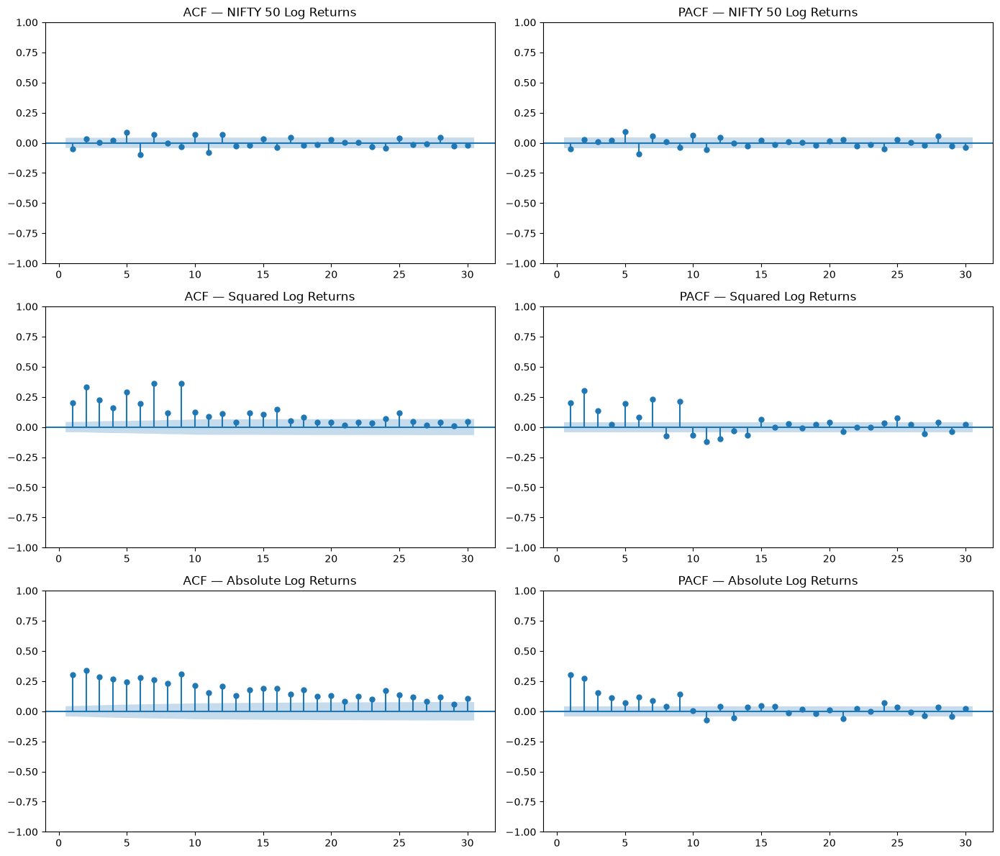

ACF/PACF RESEARCH DIAGNOSTIC

Usable return observations: 2,149

Maximum lag examined: 30 trading days

Series examined:
1. Log returns
2. Squared log returns
3. Absolute log returns

Saved ACF/PACF analysis to:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\research\nifty50\nifty_acf_pacf_analysis.png


In [128]:
# ============================================================
# [08.01] ACF/PACF — Return and Volatility Persistence
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt


# ============================================================
# 1. PREPARE CANONICAL SERIES
# ============================================================

returns = (
    clean_nifty["Log_Return"]
    .dropna()
    .copy()
)

squared_returns = (
    returns ** 2
)

absolute_returns = (
    returns.abs()
)


# ============================================================
# 2. CREATE ACF/PACF FIGURE
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(14, 12)
)


# ============================================================
# 3. LOG RETURNS
# ============================================================

plot_acf(
    returns,
    lags=30,
    ax=axes[0, 0],
    zero=False
)

plot_pacf(
    returns,
    lags=30,
    ax=axes[0, 1],
    zero=False,
    method="ywm"
)

axes[0, 0].set_title(
    "ACF — NIFTY 50 Log Returns"
)

axes[0, 1].set_title(
    "PACF — NIFTY 50 Log Returns"
)


# ============================================================
# 4. SQUARED LOG RETURNS
# ============================================================

plot_acf(
    squared_returns,
    lags=30,
    ax=axes[1, 0],
    zero=False
)

plot_pacf(
    squared_returns,
    lags=30,
    ax=axes[1, 1],
    zero=False,
    method="ywm"
)

axes[1, 0].set_title(
    "ACF — Squared Log Returns"
)

axes[1, 1].set_title(
    "PACF — Squared Log Returns"
)


# ============================================================
# 5. ABSOLUTE LOG RETURNS
# ============================================================

plot_acf(
    absolute_returns,
    lags=30,
    ax=axes[2, 0],
    zero=False
)

plot_pacf(
    absolute_returns,
    lags=30,
    ax=axes[2, 1],
    zero=False,
    method="ywm"
)

axes[2, 0].set_title(
    "ACF — Absolute Log Returns"
)

axes[2, 1].set_title(
    "PACF — Absolute Log Returns"
)


# ============================================================
# 6. FINAL LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# 7. SAVE RESEARCH FIGURE
# ============================================================

acf_pacf_path = (
    RESEARCH_NIFTY_DIR
    / "nifty_acf_pacf_analysis.png"
)

plt.savefig(
    acf_pacf_path,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# 8. DISPLAY
# ============================================================

plt.show()


# ============================================================
# 9. VALIDATION OUTPUT
# ============================================================

print("=" * 60)
print("ACF/PACF RESEARCH DIAGNOSTIC")
print("=" * 60)

print(
    f"\nUsable return observations: "
    f"{len(returns):,}"
)

print(
    "\nMaximum lag examined: 30 trading days"
)

print("\nSeries examined:")
print("1. Log returns")
print("2. Squared log returns")
print("3. Absolute log returns")

print("\nSaved ACF/PACF analysis to:")
print(acf_pacf_path)

# 09 — Conditional Heteroskedasticity: ARCH-LM

The previous ACF/PACF analysis examined persistence descriptively.

This section moves from descriptive diagnostics to a formal statistical test
of conditional heteroskedasticity.

The ARCH-LM test evaluates whether current squared returns are systematically
related to their own past values.

# 09 — ARCH-LM Test for Conditional Heteroskedasticity

The ACF/PACF analysis provided descriptive evidence about dependence in NIFTY
50 returns and return-magnitude proxies.

This section formally tests whether the return series exhibits
autoregressive conditional heteroskedasticity (ARCH) effects.

The ARCH-LM test examines whether squared returns can be explained by their
own lagged values. A statistically significant result provides evidence that
the conditional variance is not adequately represented by a constant-variance
assumption.

### Hypotheses

- **H₀:** There are no ARCH effects; lagged squared returns do not provide
  statistically significant information about current squared returns.

- **H₁:** ARCH effects are present; lagged squared returns provide statistically
  significant information about current squared returns.

A rejection of H₀ provides empirical motivation for conditional-volatility
models in which variance evolves over time, including ARCH and GARCH-type
specifications.

The ARCH-LM test does not by itself determine the final volatility model.
Model specification and forecasting performance are evaluated separately in
the subsequent analysis.

In [129]:
# ============================================================
# [09.01] ARCH-LM TEST
# ============================================================

from statsmodels.stats.diagnostic import het_arch


# ============================================================
# 1. PREPARE CANONICAL RETURN SERIES
# ============================================================

returns = (
    clean_nifty["Log_Return"]
    .dropna()
    .copy()
)


# ============================================================
# 2. ARCH-LM TEST
# ============================================================

arch_lm_result = het_arch(
    returns,
    nlags=10,
    store=False
)


# ============================================================
# 3. EXTRACT TEST RESULTS
# ============================================================

arch_lm_stat = arch_lm_result[0]
arch_lm_pvalue = arch_lm_result[1]

f_stat = arch_lm_result[2]
f_pvalue = arch_lm_result[3]


# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

print("=" * 60)
print("ARCH-LM TEST FOR CONDITIONAL HETEROSKEDASTICITY")
print("=" * 60)

print(
    f"\nObservations : {len(returns):,}"
)

print(
    "Lag order    : 10"
)

print(
    f"\nLM Statistic : {arch_lm_stat:.4f}"
)

print(
    f"LM p-value   : {arch_lm_pvalue:.10f}"
)

print(
    f"\nF Statistic  : {f_stat:.4f}"
)

print(
    f"F p-value    : {f_pvalue:.10f}"
)


# ============================================================
# 5. DECISION AT 5% SIGNIFICANCE LEVEL
# ============================================================

alpha_level = 0.05

print(
    f"\nSignificance level: α = {alpha_level:.2f}"
)

if arch_lm_pvalue < alpha_level:
    print(
        "Decision: Reject H0."
    )
    print(
        "Evidence of conditional heteroskedasticity is present."
    )
else:
    print(
        "Decision: Fail to reject H0."
    )
    print(
        "Insufficient evidence of ARCH effects at the 5% level."
    )

ARCH-LM TEST FOR CONDITIONAL HETEROSKEDASTICITY

Observations : 2,149
Lag order    : 10

LM Statistic : 577.2288
LM p-value   : 0.0000000000

F Statistic  : 78.6506
F p-value    : 0.0000000000

Significance level: α = 0.05
Decision: Reject H0.
Evidence of conditional heteroskedasticity is present.


d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


### ARCH-LM Interpretation

The ARCH-LM test is statistically significant at the 5% significance level.

For the 2018–2026 NIFTY 50 return sample, the test produces an LM statistic
of approximately 577.23 with 10 lags and a p-value far below 0.05.

Therefore, the null hypothesis of no ARCH effects is rejected.

This provides formal empirical evidence that the conditional variance of NIFTY
50 returns is time-varying and exhibits dependence on past return innovations.

The result provides statistical motivation for conditional-volatility models
such as GARCH and its extensions.

This finding is a diagnostic result rather than evidence that any particular
GARCH specification is optimal. Subsequent model estimation, diagnostics,
and out-of-sample forecasting are required to evaluate alternative volatility
models.

### 09.02 — ARCH-LM Statistical Decision

The ARCH-LM result is interpreted using a 5% significance level.

The decision rule is:

- Reject H₀ if p < 0.05.
- Fail to reject H₀ otherwise.

The interpretation below records the statistical decision without treating it
as evidence that a particular volatility model is necessarily superior.### 09.02 — ARCH-LM Statistical Decision

The ARCH-LM result is interpreted using a 5% significance level.

The decision rule is:

- Reject H₀ if p < 0.05.
- Fail to reject H₀ otherwise.

The interpretation below records the statistical decision without treating it
as evidence that a particular volatility model is necessarily superior.

In [130]:
# ============================================================
# [09.02] ARCH-LM STATISTICAL DECISION
# ============================================================

alpha_level = 0.05

print("=" * 60)
print("ARCH-LM STATISTICAL DECISION")
print("=" * 60)

print(
    f"\nSignificance level: α = {alpha_level:.2f}"
)

print(
    f"LM p-value: {arch_lm_pvalue:.10f}"
)

if arch_lm_pvalue < alpha_level:

    print(
        "\nDecision: Reject H0 at the 5% significance level."
    )

    print(
        "There is statistical evidence of ARCH effects "
        "in NIFTY 50 returns."
    )

    print(
        "This provides empirical motivation for "
        "conditional-volatility modelling."
    )

else:

    print(
        "\nDecision: Fail to reject H0 at the 5% significance level."
    )

    print(
        "There is insufficient statistical evidence of ARCH effects "
        "at this lag length."
    )

ARCH-LM STATISTICAL DECISION

Significance level: α = 0.05
LM p-value: 0.0000000000

Decision: Reject H0 at the 5% significance level.
There is statistical evidence of ARCH effects in NIFTY 50 returns.
This provides empirical motivation for conditional-volatility modelling.


# ============================================================
# [09.02] ARCH-LM STATISTICAL DECISION
# ============================================================

alpha_level = 0.05

print("=" * 60)
print("ARCH-LM STATISTICAL DECISION")
print("=" * 60)

print(
    f"\nSignificance level: α = {alpha_level:.2f}"
)

print(
    f"LM p-value: {arch_lm_pvalue:.10f}"
)

if arch_lm_pvalue < alpha_level:

    print(
        "\nDecision: Reject H0 at the 5% significance level."
    )

    print(
        "There is statistical evidence of ARCH effects "
        "in NIFTY 50 returns."
    )

    print(
        "This provides empirical motivation for "
        "conditional-volatility modelling."
    )

else:

    print(
        "\nDecision: Fail to reject H0 at the 5% significance level."
    )

    print(
        "There is insufficient statistical evidence of ARCH effects "
        "at this lag length."
    )

# 10 — Shock Asymmetry & Leverage Effect Analysis

The ARCH-LM test established strong evidence of conditional heteroskedasticity
in NIFTY 50 returns.

The next question is whether volatility responds differently to negative and
positive return shocks.

In a standard symmetric GARCH(1,1) model, the lagged innovation enters the
variance equation through its squared value:

\[
\epsilon_{t-1}^{2}
\]

Consequently, positive and negative shocks of equal magnitude have the same
direct contribution to the conditional variance equation.

This section examines whether the empirical relationship between shock
direction, shock magnitude, and subsequent volatility differs between
negative and positive shocks.

The analysis does not assume that a leverage effect exists. Instead, it
tests for evidence of asymmetry.

Evidence of statistically significant asymmetry would provide empirical
motivation for evaluating asymmetric volatility models such as GJR-GARCH and
EGARCH.

A statistically insignificant asymmetry test is itself a useful research
finding because it indicates that the simple sign-based relationship tested
here does not provide strong evidence of differential next-day volatility
response.

### 10.01 — Positive and Negative Shock Magnitudes

Return observations are separated according to their sign.

For descriptive purposes:

- Positive shocks retain positive return values.
- Negative shocks are converted to absolute magnitudes.

Zero values in either series represent observations belonging to the opposite
shock category and are retained here only because the full return series is
being transformed descriptively.

This cell describes the distribution of shock magnitudes. It does not test
whether positive and negative shocks have statistically different effects on
future volatility.

In [131]:
# ============================================================
# [10.01] POSITIVE AND NEGATIVE RETURN SHOCKS
# ============================================================

returns = (
    clean_nifty["Log_Return"]
    .dropna()
    .copy()
)


# ============================================================
# 1. SEPARATE SHOCK DIRECTIONS
# ============================================================

positive_shocks = returns[
    returns >= 0
]

negative_shocks = returns[
    returns < 0
]

negative_shock_magnitude = (
    negative_shocks.abs()
)


# ============================================================
# 2. DESCRIPTIVE SUMMARY
# ============================================================

print("=" * 60)
print("POSITIVE AND NEGATIVE RETURN SHOCKS")
print("=" * 60)

print("\nPositive shocks:")
print(
    positive_shocks.describe()
)

print(
    "\nNegative shock magnitudes:"
)

print(
    negative_shock_magnitude.describe()
)

print("\nObservation counts:")
print(
    f"Positive shocks: {len(positive_shocks):,}"
)

print(
    f"Negative shocks: {len(negative_shocks):,}"
)

POSITIVE AND NEGATIVE RETURN SHOCKS

Positive shocks:
count    1157.000000
mean        0.006982
std         0.006934
min         0.000000
25%         0.002504
50%         0.005419
75%         0.009132
max         0.084003
Name: Log_Return, dtype: float64

Negative shock magnitudes:
count    992.000000
mean       0.007333
std        0.009034
min        0.000004
25%        0.002213
50%        0.005021
75%        0.009515
max        0.139038
Name: Log_Return, dtype: float64

Observation counts:
Positive shocks: 1,157
Negative shocks: 992


### 10.02 — Next-Day Volatility Following Shock Direction

The next-day absolute log return is used as an observable proxy for subsequent
volatility.

For each trading day \(t\), the return sign at \(t\) is used to classify the
shock as positive or negative, while the absolute return at \(t+1\) is used as
the subsequent volatility proxy.

This preserves temporal ordering:

\[
Shock_t \rightarrow |r_{t+1}|
\]

The comparison is descriptive and does not control for shock magnitude,
market regime, or other conditioning variables. Therefore, differences in
group means or medians are not interpreted as causal evidence of a leverage
effect.

In [132]:
# ============================================================
# [10.02] NEXT-DAY VOLATILITY FOLLOWING POSITIVE / NEGATIVE SHOCKS
# ============================================================

asymmetry_data = pd.DataFrame({
    "Return": returns,
    "Next_Day_Abs_Return": returns.abs().shift(-1)
}).dropna()


# ============================================================
# 1. CLASSIFY SHOCK DIRECTION
# ============================================================

asymmetry_data["Shock_Type"] = np.where(
    asymmetry_data["Return"] >= 0,
    "Positive",
    "Negative"
)


# ============================================================
# 2. SEPARATE NEXT-DAY VOLATILITY
# ============================================================

positive_next_day_vol = (
    asymmetry_data.loc[
        asymmetry_data["Shock_Type"] == "Positive",
        "Next_Day_Abs_Return"
    ]
)

negative_next_day_vol = (
    asymmetry_data.loc[
        asymmetry_data["Shock_Type"] == "Negative",
        "Next_Day_Abs_Return"
    ]
)


# ============================================================
# 3. DESCRIPTIVE COMPARISON
# ============================================================

print("=" * 60)
print("NEXT-DAY VOLATILITY FOLLOWING SHOCK DIRECTION")
print("=" * 60)

print(
    "\nPositive shocks:"
)

print(
    f"Observations: {len(positive_next_day_vol):,}"
)

print(
    f"Mean next-day |return|: "
    f"{positive_next_day_vol.mean():.6f}"
)

print(
    f"Median next-day |return|: "
    f"{positive_next_day_vol.median():.6f}"
)


print(
    "\nNegative shocks:"
)

print(
    f"Observations: {len(negative_next_day_vol):,}"
)

print(
    f"Mean next-day |return|: "
    f"{negative_next_day_vol.mean():.6f}"
)

print(
    f"Median next-day |return|: "
    f"{negative_next_day_vol.median():.6f}"
)

NEXT-DAY VOLATILITY FOLLOWING SHOCK DIRECTION

Positive shocks:
Observations: 1,157
Mean next-day |return|: 0.006532
Median next-day |return|: 0.004647

Negative shocks:
Observations: 991
Mean next-day |return|: 0.007866
Median next-day |return|: 0.005932


### 10.03 — Formal Sign-Based Asymmetry Regression

A regression-based asymmetry test is used to examine whether the relationship
between return magnitude and next-day absolute return differs according to
shock direction.

The specification is:

\[
|r_{t+1}|
=
\beta_0
+
\beta_1|r_t|
+
\beta_2
\left(
|r_t|I(r_t<0)
\right)
+
\epsilon_{t+1}
\]

where:

- \(|r_{t+1}|\) is the next-day realized-volatility proxy,
- \(|r_t|\) measures the magnitude of the current shock,
- \(I(r_t<0)\) identifies negative shocks,
- \(\beta_2\) captures the incremental relationship associated with negative
  shocks.

The coefficient of the interaction term is therefore the primary parameter
of interest for this sign-based asymmetry test.

A statistically significant interaction coefficient would indicate that the
relationship between current shock magnitude and next-day absolute return
differs between negative and non-negative shocks.

This regression is treated as a preliminary empirical asymmetry test. The
conditional-volatility models estimated later provide a model-based assessment
of asymmetric variance dynamics.

In [133]:
# ============================================================
# [10.03] FORMAL SIGN-BASED ASYMMETRY REGRESSION
# ============================================================

import statsmodels.api as sm


# ============================================================
# 1. CONSTRUCT REGRESSION DATA
# ============================================================

asymmetry_regression = pd.DataFrame({
    "Next_Day_Abs_Return": returns.abs().shift(-1),
    "Abs_Return": returns.abs(),
    "Negative_Shock": (
        returns < 0
    ).astype(int)
})


# ============================================================
# 2. NEGATIVE-SHOCK INTERACTION
# ============================================================

asymmetry_regression["Negative_Interaction"] = (
    asymmetry_regression["Abs_Return"]
    * asymmetry_regression["Negative_Shock"]
)


# ============================================================
# 3. REMOVE UNAVAILABLE OBSERVATIONS
# ============================================================

asymmetry_regression = (
    asymmetry_regression
    .dropna()
    .copy()
)


# ============================================================
# 4. DEFINE REGRESSORS AND TARGET
# ============================================================

X = asymmetry_regression[
    [
        "Abs_Return",
        "Negative_Interaction"
    ]
]

X = sm.add_constant(
    X
)

y = (
    asymmetry_regression[
        "Next_Day_Abs_Return"
    ]
)


# ============================================================
# 5. ESTIMATE OLS MODEL
# ============================================================

asymmetry_model = sm.OLS(
    y,
    X
).fit()


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("=" * 60)
print("SIGN-BASED ASYMMETRY REGRESSION")
print("=" * 60)

print(
    f"\nObservations: {len(asymmetry_regression):,}"
)

print(
    "\nRegression specification:"
)

print(
    "|r(t+1)| = β0 + β1|r(t)| "
    "+ β2|r(t)|I(r(t)<0) + ε(t+1)"
)

print(
    "\nFull OLS summary:"
)

print(
    asymmetry_model.summary()
)


# ============================================================
# 7. PRIMARY ASYMMETRY RESULT
# ============================================================

interaction_coef = (
    asymmetry_model.params[
        "Negative_Interaction"
    ]
)

interaction_pvalue = (
    asymmetry_model.pvalues[
        "Negative_Interaction"
    ]
)

print(
    "\nPrimary asymmetry coefficient:"
)

print(
    f"Negative interaction coefficient: "
    f"{interaction_coef:.6f}"
)

print(
    f"p-value: "
    f"{interaction_pvalue:.6f}"
)


# ============================================================
# 8. STATISTICAL INTERPRETATION
# ============================================================

if interaction_pvalue < 0.05:

    print(
        "\nAt the 5% significance level, the negative-shock "
        "interaction is statistically significant."
    )

    print(
        "This provides evidence that the relationship between "
        "shock magnitude and next-day absolute return differs "
        "between negative and non-negative shocks."
    )

else:

    print(
        "\nAt the 5% significance level, the negative-shock "
        "interaction is not statistically significant."
    )

    print(
        "The sign-based regression therefore does not provide "
        "statistically significant evidence of differential "
        "next-day volatility response in this specification."
    )

SIGN-BASED ASYMMETRY REGRESSION

Observations: 2,148

Regression specification:
|r(t+1)| = β0 + β1|r(t)| + β2|r(t)|I(r(t)<0) + ε(t+1)

Full OLS summary:
                             OLS Regression Results                            
Dep. Variable:     Next_Day_Abs_Return   R-squared:                       0.091
Model:                             OLS   Adj. R-squared:                  0.091
Method:                  Least Squares   F-statistic:                     107.9
Date:                 Sun, 18 Oct 2026   Prob (F-statistic):           2.26e-45
Time:                         21:06:19   Log-Likelihood:                 7434.1
No. Observations:                 2148   AIC:                        -1.486e+04
Df Residuals:                     2145   BIC:                        -1.485e+04
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                           coef    std err     

# 11 — Asymmetric Volatility Models

The descriptive and regression-based asymmetry analysis provides the empirical
motivation for evaluating volatility models that allow positive and negative
innovations to affect conditional variance differently.

This section estimates:

- GJR-GARCH(1,1)-t
- EGARCH(1,1)-t

alongside the previously estimated symmetric GARCH(1,1)-t benchmark.

The asymmetric models are first examined using in-sample parameter estimates
and information criteria.

Their forecasting performance is evaluated separately using the predefined
chronological out-of-sample framework.

In-sample fit statistics are therefore treated as model-specification
evidence rather than as substitutes for out-of-sample forecasting evaluation.

In [134]:
# ============================================================
# [11.01] IMPORTS FOR ASYMMETRIC VOLATILITY MODELS
# ============================================================

from arch import arch_model
import numpy as np
import pandas as pd

In [135]:
# ============================================================
# [11.02] PREPARE RETURN SERIES
# ============================================================

returns_pct = (
    clean_nifty["Log_Return"]
    .dropna()
    * 100
)

print("=" * 60)
print("ASYMMETRIC MODEL RETURN SERIES")
print("=" * 60)

print(
    f"\nObservations: {len(returns_pct):,}"
)

print(
    f"First observation date: "
    f"{clean_nifty.loc[returns_pct.index[0], 'Date'].date()}"
)

print(
    f"Last observation date: "
    f"{clean_nifty.loc[returns_pct.index[-1], 'Date'].date()}"
)

print(
    "\nReturn scaling: decimal log returns × 100"
)

ASYMMETRIC MODEL RETURN SERIES

Observations: 2,149
First observation date: 2018-01-03
Last observation date: 2026-09-22

Return scaling: decimal log returns × 100


### 11.03 — GJR-GARCH(1,1)-t

The GJR-GARCH model extends the symmetric GARCH framework by introducing an
additional asymmetric response parameter.

The model allows the contribution of a negative innovation to conditional
variance to differ from that of a positive innovation of the same magnitude.

The Student-t innovation distribution is retained to account for the
heavy-tailed behavior identified during the earlier residual diagnostics.

The model is estimated using the complete canonical sample for initial
in-sample specification analysis. It is not yet treated as an out-of-sample
forecasting result.

In [136]:
# [11.03] GJR-GARCH(1,1) with Student-t innovations

gjr_model = arch_model(
    returns_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

gjr_result = gjr_model.fit(
    disp="off"
)

print(gjr_result.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -2693.91
Distribution:      Standardized Student's t   AIC:                           5399.83
Method:                  Maximum Likelihood   BIC:                           5433.87
                                              No. Observations:                 2149
Date:                      Sun, Oct 18 2026   Df Residuals:                     2148
Time:                              21:06:19   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [137]:
# ============================================================
# [11.04] GJR-GARCH PARAMETER SUMMARY
# ============================================================

gjr_params = gjr_result.params
gjr_pvalues = gjr_result.pvalues

print("=" * 60)
print("GJR-GARCH PARAMETER SUMMARY")
print("=" * 60)

for parameter in gjr_params.index:

    print(
        f"{parameter:>8} : "
        f"{gjr_params[parameter]:.6f} "
        f"(p={gjr_pvalues[parameter]:.6g})"
    )

GJR-GARCH PARAMETER SUMMARY
      mu : 0.053709 (p=0.00154609)
   omega : 0.033338 (p=0.000869892)
alpha[1] : 0.002659 (p=0.834173)
gamma[1] : 0.153255 (p=2.39821e-06)
 beta[1] : 0.876854 (p=2.11617e-198)
      nu : 7.306064 (p=4.89056e-11)


### 11.05 — EGARCH(1,1)-t

EGARCH provides an alternative asymmetric volatility specification in which
the conditional variance dynamics are modelled in logarithmic form.

The model allows the response to an innovation to depend on both its magnitude
and sign.

As with GJR-GARCH, Student-t innovations are used to accommodate the
heavy-tailed return behavior identified earlier.

The model is estimated on the complete canonical sample for in-sample
specification analysis. Its forecasting performance is evaluated separately
in the chronological out-of-sample experiment.

In [138]:
# [11.05] EGARCH(1,1) with Student-t innovations

egarch_model = arch_model(
    returns_pct,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_result = egarch_model.fit(
    disp="off"
)

print(egarch_result.summary())

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -2695.14
Distribution:      Standardized Student's t   AIC:                           5402.28
Method:                  Maximum Likelihood   BIC:                           5436.31
                                              No. Observations:                 2149
Date:                      Sun, Oct 18 2026   Df Residuals:                     2148
Time:                              21:06:19   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [139]:
# ============================================================
# [11.06] IN-SAMPLE ASYMMETRIC MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "GARCH-t",
        "GJR-GARCH-t",
        "EGARCH-t"
    ],
    "LogLik": [
        garch_t_result.loglikelihood,
        gjr_result.loglikelihood,
        egarch_result.loglikelihood
    ],
    "AIC": [
        garch_t_result.aic,
        gjr_result.aic,
        egarch_result.aic
    ],
    "BIC": [
        garch_t_result.bic,
        gjr_result.bic,
        egarch_result.bic
    ]
})


# ============================================================
# DISPLAY
# ============================================================

print("=" * 70)
print("IN-SAMPLE VOLATILITY MODEL COMPARISON")
print("=" * 70)

print(
    model_comparison.to_string(
        index=False
    )
)

IN-SAMPLE VOLATILITY MODEL COMPARISON
      Model       LogLik         AIC         BIC
    GARCH-t -2718.901629 5447.803258 5476.167048
GJR-GARCH-t -2693.914532 5399.829064 5433.865611
   EGARCH-t -2695.137940 5402.275879 5436.312427


### 11.06 — In-Sample Information-Criteria Comparison

The symmetric GARCH-t, GJR-GARCH-t, and EGARCH-t specifications are compared
using their in-sample log-likelihood, Akaike Information Criterion (AIC), and
Bayesian Information Criterion (BIC).

The models are estimated on the same canonical return sample, making the
information criteria directly comparable within this modelling exercise.

Log-likelihood rewards in-sample fit, while AIC and BIC incorporate penalties
for model complexity.

These statistics are used to assess in-sample specification fit. They do not
establish out-of-sample forecasting performance.

The final forecasting assessment is performed separately using the fixed
2018–2023 training period and untouched 2024–2026 out-of-sample period.

# 12 — Final Out-of-Sample Forecasting

The in-sample diagnostic and asymmetric-model estimation stages are complete.

The analysis now returns to the predefined chronological forecasting
framework.

The forecasting experiment uses:

- **Training period:** 2018-01-03 to 2023-12-29
- **Untouched out-of-sample period:** 2024-01-01 to 2026-09-22

Model parameters used for each formal OOS forecast must be estimated using
information available within the training/forecasting framework only.

The 2024–2026 test observations are not used to estimate the initial
forecasting parameters.

The purpose of this section is to evaluate whether the statistical and
asymmetric model specifications developed above translate into improved
one-step-ahead volatility forecasts.

Forecast accuracy is evaluated using the predefined absolute daily log return
as the realized-volatility proxy and consistent error metrics across
candidate models.

In [140]:
# [12.01] Prepare OOS data with trading-date index

# ------------------------------------------------------------
# Ensure Date is the index
# ------------------------------------------------------------

if "Date" in train_data.columns:
    train_data = train_data.copy()
    train_data["Date"] = pd.to_datetime(train_data["Date"])
    train_data = train_data.set_index("Date")

if "Date" in test_data.columns:
    test_data = test_data.copy()
    test_data["Date"] = pd.to_datetime(test_data["Date"])
    test_data = test_data.set_index("Date")

# Ensure chronological ordering
train_data = train_data.sort_index()
test_data = test_data.sort_index()

# ------------------------------------------------------------
# Create percentage-scale return series
# ------------------------------------------------------------

train_returns = (
    train_data["Log_Return"]
    .dropna()
    .astype(float)
    * 100
)

test_returns = (
    test_data["Log_Return"]
    .dropna()
    .astype(float)
    * 100
)

# ------------------------------------------------------------
# Validate chronological separation
# ------------------------------------------------------------

overlap = train_returns.index.intersection(test_returns.index)

if len(overlap) > 0:
    raise ValueError(
        f"Training and test periods overlap on {len(overlap)} dates."
    )

if train_returns.index.max() >= test_returns.index.min():
    raise ValueError(
        "Training period does not end strictly before the test period."
    )

# ------------------------------------------------------------
# Report structure
# ------------------------------------------------------------

print("=" * 60)
print("OOS DATA STRUCTURE")
print("=" * 60)

print("\nTraining observations:", len(train_returns))
print(
    "Training period:",
    train_returns.index.min(),
    "to",
    train_returns.index.max()
)

print("\nTest observations:", len(test_returns))
print(
    "Test period:",
    test_returns.index.min(),
    "to",
    test_returns.index.max()
)

print("\nTrain/Test overlap:", len(overlap))
print("Chronological separation: PASS")

OOS DATA STRUCTURE

Training observations: 1476
Training period: 2018-01-03 00:00:00 to 2023-12-29 00:00:00

Test observations: 673
Test period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

Train/Test overlap: 0
Chronological separation: PASS


In [141]:
# [12.01A] Verify OOS date structure

print("Training first 5 dates:")
print(train_returns.head())

print("\nTraining last 5 dates:")
print(train_returns.tail())

print("\nTest first 5 dates:")
print(test_returns.head())

print("\nTest last 5 dates:")
print(test_returns.tail())

Training first 5 dates:
Date
2018-01-03    0.009576
2018-01-04    0.588121
2018-01-05    0.513206
2018-01-08    0.611357
2018-01-09    0.126058
Name: Log_Return, dtype: float64

Training last 5 dates:
Date
2023-12-22    0.442910
2023-12-26    0.429763
2023-12-27    0.990355
2023-12-28    0.570756
2023-12-29   -0.217415
Name: Log_Return, dtype: float64

Test first 5 dates:
Date
2024-01-01    0.048306
2024-01-02   -0.350628
2024-01-03   -0.687545
2024-01-04    0.654302
2024-01-05    0.240728
Name: Log_Return, dtype: float64

Test last 5 dates:
Date
2026-09-16    0.427312
2026-09-17    0.228015
2026-09-18    0.325207
2026-09-21    0.290417
2026-09-22   -0.364976
Name: Log_Return, dtype: float64


In [142]:
# [12.02] Train GJR-GARCH-t on the training period

gjr_oos_model = arch_model(
    train_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

gjr_oos_result = gjr_oos_model.fit(
    disp="off"
)

if gjr_oos_result.convergence_flag != 0:
    raise RuntimeError(
        "GJR-GARCH-t training did not converge successfully."
    )

print(gjr_oos_result.summary())

print("\nConvergence flag:", gjr_oos_result.convergence_flag)

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -1913.96
Distribution:      Standardized Student's t   AIC:                           3839.92
Method:                  Maximum Likelihood   BIC:                           3871.70
                                              No. Observations:                 1476
Date:                      Sun, Oct 18 2026   Df Residuals:                     1475
Time:                              21:06:19   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [143]:
# [12.03] Train EGARCH-t on the training period

egarch_oos_model = arch_model(
    train_returns,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_oos_result = egarch_oos_model.fit(
    disp="off"
)

if egarch_oos_result.convergence_flag != 0:
    raise RuntimeError(
        "EGARCH-t training did not converge successfully."
    )

print(egarch_oos_result.summary())

print("\nConvergence flag:", egarch_oos_result.convergence_flag)

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -1917.20
Distribution:      Standardized Student's t   AIC:                           3846.39
Method:                  Maximum Likelihood   BIC:                           3878.18
                                              No. Observations:                 1476
Date:                      Sun, Oct 18 2026   Df Residuals:                     1475
Time:                              21:06:19   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [144]:
# [12.04] Canonical One-Step-Ahead GJR-GARCH-t OOS Forecasts
#
# The GJR-GARCH-t parameters are estimated only on the training period.
# The OOS recursion begins from the terminal conditional variance and
# terminal return from the training sample.
#
# Forecasting sequence:
#
#     forecast t
#          ↓
#     observe return t
#          ↓
#     update variance
#          ↓
#     forecast t+1
#
# The return observed on day t is therefore never used to generate
# the forecast for day t.

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Extract training-only GJR-GARCH-t parameters
# ------------------------------------------------------------

gjr_mu = gjr_oos_result.params["mu"]
gjr_omega = gjr_oos_result.params["omega"]
gjr_alpha = gjr_oos_result.params["alpha[1]"]
gjr_gamma = gjr_oos_result.params["gamma[1]"]
gjr_beta = gjr_oos_result.params["beta[1]"]

# ------------------------------------------------------------
# Initial state
# ------------------------------------------------------------

previous_return = train_returns.iloc[-1]

previous_variance = (
    gjr_oos_result.conditional_volatility.iloc[-1] ** 2
)

# ------------------------------------------------------------
# Recursive OOS forecasting
# ------------------------------------------------------------

gjr_oos_forecasts = []

for current_date in test_returns.index:

    # --------------------------------------------------------
    # 1. Forecast today's conditional variance
    #    using information available before today's return
    #    is observed.
    # --------------------------------------------------------

    previous_shock = previous_return - gjr_mu

    leverage_term = (
        gjr_gamma
        * previous_shock**2
        * (previous_shock < 0)
    )

    forecast_variance = (
        gjr_omega
        + gjr_alpha * previous_shock**2
        + leverage_term
        + gjr_beta * previous_variance
    )

    if forecast_variance <= 0:
        raise ValueError(
            f"Non-positive GJR variance forecast on {current_date}: "
            f"{forecast_variance}"
        )

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert percentage volatility back to decimal units
    gjr_oos_forecasts.append(
        forecast_volatility / 100
    )

    # --------------------------------------------------------
    # 2. Observe today's return
    # --------------------------------------------------------

    current_return = test_returns.loc[current_date]

    # --------------------------------------------------------
    # 3. Update conditional variance using today's return
    # --------------------------------------------------------

    current_shock = current_return - gjr_mu

    current_leverage_term = (
        gjr_gamma
        * current_shock**2
        * (current_shock < 0)
    )

    updated_variance = (
        gjr_omega
        + gjr_alpha * current_shock**2
        + current_leverage_term
        + gjr_beta * forecast_variance
    )

    if updated_variance <= 0:
        raise ValueError(
            f"Non-positive updated GJR variance on {current_date}: "
            f"{updated_variance}"
        )

    # --------------------------------------------------------
    # 4. Move recursive state forward
    # --------------------------------------------------------

    previous_return = current_return
    previous_variance = updated_variance

# ------------------------------------------------------------
# Construct forecast series
# ------------------------------------------------------------

gjr_oos_volatility = pd.Series(
    gjr_oos_forecasts,
    index=test_returns.index,
    name="GJR_GARCH_T_Volatility"
)

# ------------------------------------------------------------
# Final structural validation
# ------------------------------------------------------------

if len(gjr_oos_volatility) != len(test_returns):
    raise ValueError(
        "GJR-GARCH-t forecast count does not match test observations."
    )

if not gjr_oos_volatility.index.equals(test_returns.index):
    raise ValueError(
        "GJR-GARCH-t forecast dates do not match test dates."
    )

if gjr_oos_volatility.isna().any():
    raise ValueError(
        "GJR-GARCH-t forecast contains missing values."
    )

if np.isinf(gjr_oos_volatility).any():
    raise ValueError(
        "GJR-GARCH-t forecast contains infinite values."
    )

if (gjr_oos_volatility <= 0).any():
    raise ValueError(
        "GJR-GARCH-t forecast contains non-positive volatility values."
    )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 70)
print("CANONICAL GJR-GARCH-t OOS FORECASTS")
print("=" * 70)

print(f"\nNumber of forecasts: {len(gjr_oos_volatility):,}")

print(
    f"Forecast period: "
    f"{gjr_oos_volatility.index.min()} "
    f"to "
    f"{gjr_oos_volatility.index.max()}"
)

print("\nFirst 10 forecasts:")
print(gjr_oos_volatility.head(10))

print("\nLast 5 forecasts:")
print(gjr_oos_volatility.tail())

print("\nStructural validation: PASS")

CANONICAL GJR-GARCH-t OOS FORECASTS

Number of forecasts: 673
Forecast period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

First 10 forecasts:
Date
2024-01-01    0.006755
2024-01-02    0.006427
2024-01-03    0.006577
2024-01-04    0.007510
2024-01-05    0.007052
2024-01-08    0.006671
2024-01-09    0.008303
2024-01-10    0.007717
2024-01-11    0.007225
2024-01-12    0.006814
Name: GJR_GARCH_T_Volatility, dtype: float64

Last 5 forecasts:
Date
2026-09-16    0.010066
2026-09-17    0.009216
2026-09-18    0.008490
2026-09-21    0.007874
2026-09-22    0.007357
Name: GJR_GARCH_T_Volatility, dtype: float64

Structural validation: PASS


In [145]:
# [12.04A] GJR-GARCH-t Recursive Integrity Check
#
# Independently reconstruct the one-step-ahead GJR-GARCH-t forecasts
# using the fixed training-period parameters and compare them with
# the arch forecast implementation in Cell 170.

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Training-period parameters
# ------------------------------------------------------------

gjr_mu = gjr_oos_result.params["mu"]
gjr_omega = gjr_oos_result.params["omega"]
gjr_alpha = gjr_oos_result.params["alpha[1]"]
gjr_gamma = gjr_oos_result.params["gamma[1]"]
gjr_beta = gjr_oos_result.params["beta[1]"]

# ------------------------------------------------------------
# Initial state: final training observation
# ------------------------------------------------------------

previous_return = train_returns.iloc[-1]

previous_variance = (
    gjr_oos_result.conditional_volatility.iloc[-1] ** 2
)

manual_gjr_forecasts = []

# ------------------------------------------------------------
# Independent recursive forecasting
# ------------------------------------------------------------

for current_date in test_returns.index:

    # Forecast today's variance using information available
    # before today's return is observed.
    forecast_variance = (
        gjr_omega
        + gjr_alpha * (previous_return - gjr_mu) ** 2
        + gjr_gamma
        * (previous_return - gjr_mu) ** 2
        * (previous_return - gjr_mu < 0)
        + gjr_beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert percentage volatility back to decimal units
    manual_gjr_forecasts.append(
        forecast_volatility / 100
    )

    # Observe today's return only AFTER generating today's forecast
    current_return = test_returns.loc[current_date]

    # Update variance using today's observed return
    updated_variance = (
        gjr_omega
        + gjr_alpha * (current_return - gjr_mu) ** 2
        + gjr_gamma
        * (current_return - gjr_mu) ** 2
        * (current_return - gjr_mu < 0)
        + gjr_beta * forecast_variance
    )

    previous_return = current_return
    previous_variance = updated_variance

manual_gjr_forecasts = pd.Series(
    manual_gjr_forecasts,
    index=test_returns.index,
    name="Manual_GJR"
)

# ------------------------------------------------------------
# Compare with Cell 170
# ------------------------------------------------------------

arch_gjr_forecasts = gjr_oos_volatility.copy()
arch_gjr_forecasts = arch_gjr_forecasts.reindex(test_returns.index)
arch_gjr_forecasts.name = "ARCH_GJR"

comparison = pd.DataFrame({
    "ARCH_Sequential": arch_gjr_forecasts,
    "Manual_Recursive": manual_gjr_forecasts
})

comparison["Absolute_Difference"] = (
    comparison["ARCH_Sequential"]
    - comparison["Manual_Recursive"]
).abs()

max_difference = comparison["Absolute_Difference"].max()
mean_difference = comparison["Absolute_Difference"].mean()
median_difference = comparison["Absolute_Difference"].median()

identical_1e10 = (
    comparison["Absolute_Difference"] <= 1e-10
).sum()

materially_different = (
    comparison["Absolute_Difference"] > 1e-10
).sum()

print("=" * 70)
print("FINAL GJR-GARCH-t RECURSIVE INTEGRITY CHECK")
print("=" * 70)

print(f"\nObservations: {len(comparison):,}")

print(f"\nMaximum absolute difference: {max_difference:.18e}")
print(f"Mean absolute difference:    {mean_difference:.18e}")
print(f"Median absolute difference: {median_difference:.18e}")

print(f"\nIdentical within 1e-10: {identical_1e10:,}")
print(f"Materially different:   {materially_different:,}")

print("\nFirst 5 comparisons:")
print(comparison.head())

print("\nLast 5 comparisons:")
print(comparison.tail())

# ------------------------------------------------------------
# Final integrity decision
# ------------------------------------------------------------

if (
    len(comparison) == len(test_returns)
    and max_difference <= 1e-10
    and materially_different == 0
):
    print("\nINTEGRITY RESULT: PASS")
    print(
        "The Cell 170 GJR-GARCH-t forecasts match the independent "
        "recursive implementation within numerical tolerance."
    )
else:
    print("\nINTEGRITY RESULT: FAIL")
    print(
        "The GJR-GARCH-t forecast implementation requires investigation."
    )

FINAL GJR-GARCH-t RECURSIVE INTEGRITY CHECK

Observations: 673

Maximum absolute difference: 0.000000000000000000e+00
Mean absolute difference:    0.000000000000000000e+00
Median absolute difference: 0.000000000000000000e+00

Identical within 1e-10: 673
Materially different:   0

First 5 comparisons:
            ARCH_Sequential  Manual_Recursive  Absolute_Difference
Date                                                              
2024-01-01         0.006755          0.006755                  0.0
2024-01-02         0.006427          0.006427                  0.0
2024-01-03         0.006577          0.006577                  0.0
2024-01-04         0.007510          0.007510                  0.0
2024-01-05         0.007052          0.007052                  0.0

Last 5 comparisons:
            ARCH_Sequential  Manual_Recursive  Absolute_Difference
Date                                                              
2026-09-16         0.010066          0.010066                  0.0
2026-09

In [146]:
# [12.05] One-step-ahead EGARCH-t OOS forecasts

# Combine the chronological return series.
# Parameters remain estimated only on the training sample.
all_returns_pct = pd.concat(
    [train_returns, test_returns]
)

# Create the EGARCH model using the complete chronological index.
# IMPORTANT: This model is NOT refitted.
egarch_forecast_model = arch_model(
    all_returns_pct,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

# Generate one-step-ahead forecasts using parameters
# estimated exclusively from the training period.
egarch_forecast_result = egarch_forecast_model.forecast(
    params=egarch_oos_result.params,
    horizon=1,
    start=test_returns.index[0],
    reindex=True
)

# Extract the one-step-ahead variance forecasts.
egarch_variance = egarch_forecast_result.variance.iloc[:, 0]

# Keep only the OOS testing period.
egarch_variance = egarch_variance.loc[test_returns.index]

# Convert variance → volatility → decimal units.
egarch_oos_volatility = (
    np.sqrt(egarch_variance) / 100
)

print("Number of EGARCH-t OOS forecasts:", len(egarch_oos_volatility))

print("\nFirst 10 forecasts:")
print(egarch_oos_volatility.head(10))

print("\nLast 5 forecasts:")
print(egarch_oos_volatility.tail())

Number of EGARCH-t OOS forecasts: 673

First 10 forecasts:
Date
2024-01-01    0.005899
2024-01-02    0.006179
2024-01-03    0.006909
2024-01-04    0.006681
2024-01-05    0.006374
2024-01-08    0.007424
2024-01-09    0.007035
2024-01-10    0.006723
2024-01-11    0.006388
2024-01-12    0.006318
Name: h.1, dtype: float64

Last 5 forecasts:
Date
2026-09-16    0.009103
2026-09-17    0.008589
2026-09-18    0.008142
2026-09-21    0.007726
2026-09-22    0.007867
Name: h.1, dtype: float64


In [147]:
# [12.05B] EGARCH-t OOS Forecast Integrity Check

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Structural checks
# ------------------------------------------------------------

if len(egarch_oos_volatility) != len(test_returns):
    raise ValueError(
        "EGARCH forecast count does not match test observations."
    )

if not egarch_oos_volatility.index.equals(test_returns.index):
    raise ValueError(
        "EGARCH forecast index does not exactly match test returns."
    )

if egarch_oos_volatility.isna().any():
    raise ValueError(
        "EGARCH forecast contains missing values."
    )

if np.isinf(egarch_oos_volatility).any():
    raise ValueError(
        "EGARCH forecast contains infinite values."
    )

if (egarch_oos_volatility <= 0).any():
    raise ValueError(
        "EGARCH forecast contains non-positive volatility values."
    )

# ------------------------------------------------------------
# Verify that the fitted model remained training-only
# ------------------------------------------------------------

expected_training_observations = len(train_returns)

if len(egarch_oos_result.model.y) != expected_training_observations:
    raise ValueError(
        "EGARCH fitted model does not contain exactly the training sample."
    )

print("=" * 70)
print("EGARCH-t OOS FORECAST INTEGRITY CHECK")
print("=" * 70)

print(f"\nTraining observations used for estimation: "
      f"{len(egarch_oos_result.model.y):,}")

print(f"OOS forecast observations: "
      f"{len(egarch_oos_volatility):,}")

print(
    f"\nForecast period: "
    f"{egarch_oos_volatility.index.min()} "
    f"to "
    f"{egarch_oos_volatility.index.max()}"
)

print(
    f"\nMissing forecasts: "
    f"{egarch_oos_volatility.isna().sum()}"
)

print(
    f"Infinite forecasts: "
    f"{np.isinf(egarch_oos_volatility).sum()}"
)

print(
    f"Non-positive forecasts: "
    f"{(egarch_oos_volatility <= 0).sum()}"
)

print(
    "\nDate alignment:",
    egarch_oos_volatility.index.equals(test_returns.index)
)

print("\nFirst 5 forecasts:")
print(egarch_oos_volatility.head())

print("\nLast 5 forecasts:")
print(egarch_oos_volatility.tail())

# ------------------------------------------------------------
# Final structural decision
# ------------------------------------------------------------

if (
    len(egarch_oos_volatility) == len(test_returns)
    and egarch_oos_volatility.index.equals(test_returns.index)
    and not egarch_oos_volatility.isna().any()
    and not np.isinf(egarch_oos_volatility).any()
    and (egarch_oos_volatility > 0).all()
    and len(egarch_oos_result.model.y) == len(train_returns)
):
    print("\nINTEGRITY RESULT: PASS")
    print(
        "The EGARCH-t OOS forecast series passes the structural "
        "and training-sample integrity checks."
    )
else:
    print("\nINTEGRITY RESULT: FAIL")
    print(
        "The EGARCH-t OOS forecast implementation requires investigation."
    )

EGARCH-t OOS FORECAST INTEGRITY CHECK

Training observations used for estimation: 1,476
OOS forecast observations: 673

Forecast period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

Missing forecasts: 0
Infinite forecasts: 0
Non-positive forecasts: 0

Date alignment: True

First 5 forecasts:
Date
2024-01-01    0.005899
2024-01-02    0.006179
2024-01-03    0.006909
2024-01-04    0.006681
2024-01-05    0.006374
Name: h.1, dtype: float64

Last 5 forecasts:
Date
2026-09-16    0.009103
2026-09-17    0.008589
2026-09-18    0.008142
2026-09-21    0.007726
2026-09-22    0.007867
Name: h.1, dtype: float64

INTEGRITY RESULT: PASS
The EGARCH-t OOS forecast series passes the structural and training-sample integrity checks.


In [148]:
# [12.05A] Verify EGARCH OOS date alignment

print("Test returns:")
print("Count:", len(test_returns))
print("First:", test_returns.index.min())
print("Last:", test_returns.index.max())

print("\nEGARCH forecasts:")
print("Count:", len(egarch_oos_volatility))
print("First:", egarch_oos_volatility.index.min())
print("Last:", egarch_oos_volatility.index.max())

print("\nDates in EGARCH forecast but not in test returns:")
print(
    egarch_oos_volatility.index.difference(test_returns.index)
)

print("\nDates in test returns but not in EGARCH forecast:")
print(
    test_returns.index.difference(egarch_oos_volatility.index)
)

Test returns:
Count: 673
First: 2024-01-01 00:00:00
Last: 2026-09-22 00:00:00

EGARCH forecasts:
Count: 673
First: 2024-01-01 00:00:00
Last: 2026-09-22 00:00:00

Dates in EGARCH forecast but not in test returns:
DatetimeIndex([], dtype='datetime64[s]', name='Date', freq=None)

Dates in test returns but not in EGARCH forecast:
DatetimeIndex([], dtype='datetime64[s]', name='Date', freq=None)


In [149]:
# [12.05B] Inspect current test_data structure

print("test_data columns:")
print(test_data.columns.tolist())

print("\nLast 10 rows:")
print(test_data.tail(10))

print("\nIndex:")
print(test_data.index.min(), "to", test_data.index.max())

print("\nShape:")
print(test_data.shape)

test_data columns:
['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast']

Last 10 rows:
            Log_Return  Simple_Return  GARCH_T_Volatility  \
Date                                                        
2026-09-08   -0.006076      -0.006058            0.006120   
2026-09-09   -0.008652      -0.008614            0.006550   
2026-09-10    0.001974       0.001976            0.007410   
2026-09-11   -0.003401      -0.003395            0.006885   
2026-09-15   -0.012017      -0.011945            0.006706   
2026-09-16    0.004273       0.004282            0.008388   
2026-09-17    0.002280       0.002283            0.007814   
2026-09-18    0.003252       0.003257            0.007230   
2026-09-21    0.002904       0.002908            0.006792   
2026-09-22   -0.003650      -0.003643            0.006414   

            EWMA_OneStep_Forecast  
Date                               
2026-09-08               0.004961  
2026-09-09               0.005035  
2026-09-10

In [150]:
# [12.05C] Inspect the final observations in clean_nifty

print("clean_nifty columns:")
print(clean_nifty.columns.tolist())

print("\nLast 10 observations:")
print(clean_nifty.tail(10))

clean_nifty columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Simple_Return', 'Log_Return', 'Squared_Return', 'Absolute_Return', 'Rolling_Vol_5D', 'Rolling_Vol_5D_Annualized', 'EWMA_Variance', 'EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']

Last 10 observations:
           Date          Open          High           Low         Close  \
2140 2026-09-08  23743.099609  23758.949219  23623.099609  23635.099609   
2141 2026-09-09  23522.050781  23571.550781  23431.500000  23431.500000   
2142 2026-09-10  23446.599609  23494.949219  23380.099609  23477.800781   
2143 2026-09-11  23270.300781  23448.099609  23231.400391  23398.099609   
2144 2026-09-15  23576.150391  23592.849609  23118.599609  23118.599609   
2145 2026-09-16  23201.599609  23284.750000  23116.099609  23217.599609   
2146 2026-09-17  23195.250000  23363.550781  23193.650391  23270.599609   
2147 2026-09-18  23334.699219  23389.150391  23286.599609  23346.400391  

In [151]:
# [12.05D] Verify the final observations in clean_nifty

print(
    clean_nifty[
        ["Log_Return", "Simple_Return"]
    ].tail(10)
)

      Log_Return  Simple_Return
2140   -0.006076      -0.006058
2141   -0.008652      -0.008614
2142    0.001974       0.001976
2143   -0.003401      -0.003395
2144   -0.012017      -0.011945
2145    0.004273       0.004282
2146    0.002280       0.002283
2147    0.003252       0.003257
2148    0.002904       0.002908
2149   -0.003650      -0.003643


In [152]:
# [12.06] Add asymmetric volatility forecasts to test_data

test_data = test_data.copy()

test_data["GJR_GARCH_T_Volatility"] = (
    gjr_oos_volatility.reindex(test_data.index)
)

test_data["EGARCH_T_Volatility"] = (
    egarch_oos_volatility.reindex(test_data.index)
)

forecast_columns = [
    "GARCH_T_Volatility",
    "EWMA_OneStep_Forecast",
    "GJR_GARCH_T_Volatility",
    "EGARCH_T_Volatility"
]

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

missing_counts = test_data[forecast_columns].isna().sum()

if missing_counts.any():
    raise ValueError(
        f"Missing OOS forecasts detected:\n{missing_counts}"
    )

if len(test_data) != len(test_returns):
    raise ValueError(
        "test_data and test_returns have different observation counts."
    )

if not test_data.index.equals(test_returns.index):
    raise ValueError(
        "test_data index does not exactly match the OOS test-return index."
    )

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 60)
print("OOS FORECAST DATASET INTEGRITY")
print("=" * 60)

print("\nTest data shape:", test_data.shape)

print("\nColumns:")
print(test_data.columns.tolist())

print("\nMissing values:")
print(test_data[forecast_columns].isna().sum())

print("\nDate range:")
print(test_data.index.min(), "to", test_data.index.max())

print("\nAll forecast series aligned successfully.")
print("Forecast observations:", len(test_data))

OOS FORECAST DATASET INTEGRITY

Test data shape: (673, 6)

Columns:
['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

Missing values:
GARCH_T_Volatility        0
EWMA_OneStep_Forecast     0
GJR_GARCH_T_Volatility    0
EGARCH_T_Volatility       0
dtype: int64

Date range:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

All forecast series aligned successfully.
Forecast observations: 673


OS FORECAST DATASET INTEGRITY
============================================================

Test data shape: (673, 6)

Columns:
['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

Missing values:
GARCH_T_Volatility        0
EWMA_OneStep_Forecast     0
GJR_GARCH_T_Volatility    0
EGARCH_T_Volatility       0
dtype: int64

Date range:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

All forecast series aligned successfully.
Forecast observations: 673

In [153]:
# [12.07] Five-model OOS volatility evaluation

evaluation_data = test_data.copy()

# One-day realized-volatility proxy
evaluation_data["Actual_Volatility"] = (
    evaluation_data["Log_Return"].abs()
)

# Historical 20-day volatility forecast
evaluation_data["Historical_Volatility_20D"] = (
    pd.concat([
        train_data["Log_Return"],
        test_data["Log_Return"]
    ])
    .rolling(window=20)
    .std()
    .shift(1)
    .loc[test_data.index]
)

# Keep observations where all forecasts are available
evaluation_data = evaluation_data.dropna(
    subset=[
        "Actual_Volatility",
        "Historical_Volatility_20D",
        "EWMA_OneStep_Forecast",
        "GARCH_T_Volatility",
        "GJR_GARCH_T_Volatility",
        "EGARCH_T_Volatility"
    ]
)

models = {
    "Historical 20D": "Historical_Volatility_20D",
    "EWMA (λ=0.94)": "EWMA_OneStep_Forecast",
    "GARCH-t": "GARCH_T_Volatility",
    "GJR-GARCH-t": "GJR_GARCH_T_Volatility",
    "EGARCH-t": "EGARCH_T_Volatility"
}

results = []

actual = evaluation_data["Actual_Volatility"]

for model_name, forecast_column in models.items():

    forecast = evaluation_data[forecast_column]

    mae = np.mean(
        np.abs(actual - forecast)
    )

    rmse = np.sqrt(
        np.mean((actual - forecast) ** 2)
    )

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

oos_results = pd.DataFrame(results)

print("Evaluation observations:", len(evaluation_data))

print("\nOOS evaluation:")
print(oos_results.to_string(index=False))

Evaluation observations: 673

OOS evaluation:
         Model      MAE     RMSE
Historical 20D 0.004923 0.006564
 EWMA (λ=0.94) 0.004924 0.006419
       GARCH-t 0.004852 0.006291
   GJR-GARCH-t 0.004865 0.006349
      EGARCH-t 0.004628 0.005796


In [154]:
# [12.08] Pairwise forecast-loss matrix

loss_data = pd.DataFrame(index=evaluation_data.index)

for model_name, forecast_column in models.items():
    loss_data[model_name] = (
        evaluation_data["Actual_Volatility"]
        - evaluation_data[forecast_column]
    ).abs()

print("=" * 60)
print("PAIRWISE FORECAST-LOSS MATRIX")
print("=" * 60)

print("\nLoss data shape:", loss_data.shape)

print("\nMean absolute forecast loss:")
print(
    loss_data.mean().to_string()
)

PAIRWISE FORECAST-LOSS MATRIX

Loss data shape: (673, 5)

Mean absolute forecast loss:
Historical 20D    0.004923
EWMA (λ=0.94)     0.004924
GARCH-t           0.004852
GJR-GARCH-t       0.004865
EGARCH-t          0.004628


### Forecast-Loss Statistical Comparison — Method Availability

The forecast comparison stage requires statistical inference on paired
forecast-loss differentials.

The analysis uses a custom implementation of a Diebold-Mariano-style
paired loss-differential test together with HAC-adjusted inference.

Because the current one-day-ahead forecasting horizon does not create
overlapping forecast errors, the primary concern is serial dependence in the
loss differential rather than overlapping-horizon dependence.

The software environment is checked before implementing the statistical
procedures.

In [155]:
# [12.09] Forecast Comparison Method Availability Check

import statsmodels
import scipy

print("statsmodels version:", statsmodels.__version__)
print("scipy version:", scipy.__version__)

try:
    from statsmodels.stats.sandwich_covariance import cov_hac
    print("HAC covariance implementation available.")
except ImportError:
    print("HAC covariance implementation unavailable.")

try:
    from scipy import stats
    print("SciPy statistical testing module available.")
except ImportError:
    print("SciPy statistical testing module unavailable.")

statsmodels version: 0.15.0
scipy version: 1.18.1
HAC covariance implementation available.
SciPy statistical testing module available.


In [156]:
# [12.10] Non-HAC Paired Forecast-Loss Comparison

import numpy as np
import pandas as pd
from scipy import stats


def paired_loss_t_test(loss_1, loss_2):
    """
    Paired t-test on forecast-loss differentials.

    H0:
        Mean loss differential = 0.

    H1:
        Mean loss differential != 0.

    The loss differential is:

        d_t = loss_1,t - loss_2,t

    This is a non-HAC reference test. The primary robustness analysis uses
    HAC-adjusted inference in the subsequent cell.
    """

    loss_1 = pd.Series(loss_1).dropna()
    loss_2 = pd.Series(loss_2).dropna()

    common_index = loss_1.index.intersection(loss_2.index)

    loss_1 = loss_1.loc[common_index]
    loss_2 = loss_2.loc[common_index]

    differential = (loss_1 - loss_2).dropna()

    mean_difference = differential.mean()

    standard_error = (
        differential.std(ddof=1)
        / np.sqrt(len(differential))
    )

    if standard_error == 0:
        raise ValueError(
            "Standard error of the loss differential is zero."
        )

    test_statistic = mean_difference / standard_error

    p_value = 2 * stats.t.sf(
        np.abs(test_statistic),
        df=len(differential) - 1
    )

    return {
        "Mean_Loss_Difference": mean_difference,
        "T_Statistic": test_statistic,
        "P_Value": p_value,
        "Observations": len(differential)
    }


# ---------------------------------------------------------
# Construct absolute and squared forecast losses
# ---------------------------------------------------------

absolute_loss = pd.DataFrame(index=evaluation_data.index)
squared_loss = pd.DataFrame(index=evaluation_data.index)

for model_name, forecast_column in models.items():

    forecast_error = (
        evaluation_data["Actual_Volatility"]
        - evaluation_data[forecast_column]
    )

    absolute_loss[model_name] = forecast_error.abs()
    squared_loss[model_name] = forecast_error ** 2


# ---------------------------------------------------------
# Pairwise comparisons
# ---------------------------------------------------------

model_pairs = [
    ("GJR-GARCH-t", "Historical 20D"),
    ("GJR-GARCH-t", "EWMA (λ=0.94)"),
    ("GJR-GARCH-t", "GARCH-t"),
    ("GJR-GARCH-t", "EGARCH-t"),
]


# ---------------------------------------------------------
# Absolute-loss comparison
# ---------------------------------------------------------

paired_mae_results = []

for model_1, model_2 in model_pairs:

    result = paired_loss_t_test(
        absolute_loss[model_1],
        absolute_loss[model_2]
    )

    result["Model_1"] = model_1
    result["Model_2"] = model_2

    paired_mae_results.append(result)


paired_mae_results = pd.DataFrame(
    paired_mae_results
)

print(
    "Non-HAC paired comparison using absolute-error loss:"
)

print(
    paired_mae_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "T_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

Non-HAC paired comparison using absolute-error loss:
    Model_1        Model_2  Mean_Loss_Difference  T_Statistic  P_Value  Observations
GJR-GARCH-t Historical 20D             -0.000057    -0.528286 0.597475           673
GJR-GARCH-t  EWMA (λ=0.94)             -0.000059    -0.638628 0.523282           673
GJR-GARCH-t        GARCH-t              0.000013     0.258953 0.795751           673
GJR-GARCH-t       EGARCH-t              0.000238     4.016885 0.000066           673


In [157]:
# [12.11] Non-HAC Paired Comparison Using Squared-Error Loss

paired_rmse_results = []

for model_1, model_2 in model_pairs:

    result = paired_loss_t_test(
        squared_loss[model_1],
        squared_loss[model_2]
    )

    result["Model_1"] = model_1
    result["Model_2"] = model_2

    paired_rmse_results.append(result)


paired_rmse_results = pd.DataFrame(
    paired_rmse_results
)

print(
    "Non-HAC paired comparison using squared-error loss:"
)

print(
    paired_rmse_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "T_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

Non-HAC paired comparison using squared-error loss:
    Model_1        Model_2  Mean_Loss_Difference  T_Statistic  P_Value  Observations
GJR-GARCH-t Historical 20D         -2.779391e-06    -1.568767 0.117173           673
GJR-GARCH-t  EWMA (λ=0.94)         -8.950629e-07    -0.633101 0.526883           673
GJR-GARCH-t        GARCH-t          7.324642e-07     0.569227 0.569392           673
GJR-GARCH-t       EGARCH-t          6.706575e-06     3.171935 0.001583           673


### HAC-Adjusted Forecast-Loss Comparison

Forecast-loss differentials may exhibit serial dependence even when the
forecast horizon is one trading day.

Therefore, the primary inference uses a heteroskedasticity-and-
autocorrelation-consistent (HAC) covariance estimator.

For each model pair, the loss differential is:

\[
d_t = L_{1,t} - L_{2,t}
\]

The null hypothesis is:

\[
H_0:E[d_t]=0
\]

The HAC adjustment allows the estimated variance of the mean loss
differential to account for serial dependence.

A maximum lag of 5 trading days is used as the initial specification.
Sensitivity to alternative HAC lag choices should be examined before treating
the inference as definitive.

The comparison is performed on the common 673-observation OOS sample.

In [158]:
# [12.12] HAC-adjusted forecast loss comparison

from statsmodels.stats.sandwich_covariance import cov_hac
import statsmodels.api as sm
from scipy import stats
import numpy as np


def dm_test_hac(loss_1, loss_2, maxlags=5):
    """
    HAC-adjusted Diebold-Mariano-style test.

    H0:
        Mean loss differential = 0

    H1:
        Mean loss differential != 0

    The loss differential is:
        d_t = loss_1,t - loss_2,t

    HAC/Newey-West covariance is used to allow for
    serial dependence in the loss differential.
    """

    loss_1 = pd.Series(loss_1).dropna()
    loss_2 = pd.Series(loss_2).dropna()

    common_index = loss_1.index.intersection(loss_2.index)

    loss_1 = loss_1.loc[common_index]
    loss_2 = loss_2.loc[common_index]

    differential = (loss_1 - loss_2).dropna()

    # Regression of loss differential on a constant
    X = np.ones((len(differential), 1))
    model = sm.OLS(differential.values, X).fit()

    # HAC covariance matrix
    hac_cov = cov_hac(
        model,
        nlags=maxlags
    )

    mean_difference = model.params[0]
    standard_error = np.sqrt(hac_cov[0, 0])

    test_statistic = mean_difference / standard_error

    p_value = 2 * stats.t.sf(
        np.abs(test_statistic),
        df=len(differential) - 1
    )

    return {
        "Mean_Loss_Difference": mean_difference,
        "DM_HAC_Statistic": test_statistic,
        "P_Value": p_value,
        "Observations": len(differential)
    }


# ---------------------------------------------------------
# HAC comparison using absolute-error loss
# ---------------------------------------------------------

hac_mae_results = []

for model_1, model_2 in model_pairs:

    result = dm_test_hac(
        absolute_loss[model_1],
        absolute_loss[model_2],
        maxlags=5
    )

    result["Model_1"] = model_1
    result["Model_2"] = model_2

    hac_mae_results.append(result)


hac_mae_results = pd.DataFrame(hac_mae_results)


print("HAC-adjusted comparison using absolute-error loss:")
print(
    hac_mae_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "DM_HAC_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

HAC-adjusted comparison using absolute-error loss:
    Model_1        Model_2  Mean_Loss_Difference  DM_HAC_Statistic  P_Value  Observations
GJR-GARCH-t Historical 20D             -0.000057         -0.316054 0.752059           673
GJR-GARCH-t  EWMA (λ=0.94)             -0.000059         -0.418788 0.675505           673
GJR-GARCH-t        GARCH-t              0.000013          0.191224 0.848408           673
GJR-GARCH-t       EGARCH-t              0.000238          2.787565 0.005461           673


### Fixed Equal-Weight Ensemble — OOS Evaluation

A predetermined equal-weight combination of GJR-GARCH-t and EGARCH-t forecasts
is evaluated on the common 2024–2026 OOS period.

The weights are fixed at 0.5 and 0.5 and are not estimated from the OOS data.

Therefore, this experiment does not use OOS observations to optimize the
ensemble weights.

The result is treated as evidence for a fixed-rule forecast combination.
More flexible weighting schemes require weights to be determined exclusively
from earlier validation data before evaluation on the final OOS period.

In [159]:
# [12.13] Equal-weight GJR + EGARCH volatility ensemble

evaluation_data["GJR_EGARCH_Ensemble"] = (
    0.5 * evaluation_data["GJR_GARCH_T_Volatility"]
    + 0.5 * evaluation_data["EGARCH_T_Volatility"]
)

ensemble_mae = np.mean(
    np.abs(
        evaluation_data["Actual_Volatility"]
        - evaluation_data["GJR_EGARCH_Ensemble"]
    )
)

ensemble_rmse = np.sqrt(
    np.mean(
        (
            evaluation_data["Actual_Volatility"]
            - evaluation_data["GJR_EGARCH_Ensemble"]
        ) ** 2
    )
)

print("GJR + EGARCH Equal-Weight Ensemble")
print("----------------------------------")
print(f"MAE :  {ensemble_mae:.6f}")
print(f"RMSE: {ensemble_rmse:.6f}")

print("\nPercentage:")
print(f"MAE :  {ensemble_mae * 100:.4f}%")
print(f"RMSE: {ensemble_rmse * 100:.4f}%")

GJR + EGARCH Equal-Weight Ensemble
----------------------------------
MAE :  0.004719
RMSE: 0.006021

Percentage:
MAE :  0.4719%
RMSE: 0.6021%


### HAC-Adjusted Ensemble Comparison

The fixed equal-weight ensemble is compared with each individual forecasting
model using HAC-adjusted absolute-error loss differentials.

The ensemble's numerical loss is lower than both individual asymmetric models,
but the HAC-adjusted comparisons against GJR-GARCH-t and EGARCH-t do not provide
statistically significant evidence of a difference at the 5% level.

The ensemble therefore remains a fixed-rule experimental result rather than a
demonstrated statistically superior forecasting specification.

In [160]:
# [12.14] HAC-adjusted ensemble comparison

ensemble_loss_absolute = (
    evaluation_data["Actual_Volatility"]
    - evaluation_data["GJR_EGARCH_Ensemble"]
).abs()

ensemble_loss_squared = (
    evaluation_data["Actual_Volatility"]
    - evaluation_data["GJR_EGARCH_Ensemble"]
) ** 2


ensemble_comparisons = [
    ("GJR + EGARCH", "Historical 20D", "Historical_Volatility_20D"),
    ("GJR + EGARCH", "EWMA (λ=0.94)", "EWMA_OneStep_Forecast"),
    ("GJR + EGARCH", "GARCH-t", "GARCH_T_Volatility"),
    ("GJR + EGARCH", "GJR-GARCH-t", "GJR_GARCH_T_Volatility"),
    ("GJR + EGARCH", "EGARCH-t", "EGARCH_T_Volatility"),
]


ensemble_hac_results = []

for ensemble_name, comparison_name, comparison_column in ensemble_comparisons:

    comparison_loss = (
        evaluation_data["Actual_Volatility"]
        - evaluation_data[comparison_column]
    ).abs()

    result = dm_test_hac(
        ensemble_loss_absolute,
        comparison_loss,
        maxlags=5
    )

    result["Model_1"] = ensemble_name
    result["Model_2"] = comparison_name

    ensemble_hac_results.append(result)


ensemble_hac_results = pd.DataFrame(ensemble_hac_results)

print("HAC-adjusted ensemble comparison using absolute-error loss:")
print(
    ensemble_hac_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "DM_HAC_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

HAC-adjusted ensemble comparison using absolute-error loss:
     Model_1        Model_2  Mean_Loss_Difference  DM_HAC_Statistic  P_Value  Observations
GJR + EGARCH Historical 20D             -0.000204         -1.210854 0.226377           673
GJR + EGARCH  EWMA (λ=0.94)             -0.000205         -1.645554 0.100323           673
GJR + EGARCH        GARCH-t             -0.000133         -2.080584 0.037850           673
GJR + EGARCH    GJR-GARCH-t             -0.000146         -3.170919 0.001589           673
GJR + EGARCH       EGARCH-t              0.000091          2.258173 0.024255           673



# 13 — Forecast Combination Research

Forecast combinations are treated as a separate model-development experiment. Final OOS data must not be used to select weights.


## 13.1 — Forecast Combination Research Plan

Forecast combinations are treated as a separate model-development experiment.

The fixed equal-weight ensemble provides an initial combination benchmark because
its weights are predetermined rather than estimated from the final OOS sample.

The current five-model OOS results over the 2024–2026 test period are:

| Model | MAE | RMSE |
|---|---:|---:|
| Historical 20D | 0.4923% | 0.6564% |
| EWMA (λ = 0.94) | 0.4924% | 0.6419% |
| GARCH-t | 0.4852% | 0.6291% |
| GJR-GARCH-t | 0.4865% | 0.6349% |
| EGARCH-t | 0.4628% | 0.5796% |

These are descriptive out-of-sample performance statistics. Statistical
forecast-loss comparisons are used to determine whether observed differences
are statistically distinguishable.

For the current HAC-adjusted absolute-error comparison:

- GJR-GARCH-t vs Historical 20D: p = 0.7521
- GJR-GARCH-t vs EWMA: p = 0.6755
- GJR-GARCH-t vs GARCH-t: p = 0.8484
- GJR-GARCH-t vs EGARCH-t: p = 0.0055

Under the current HAC specification, the loss difference between GJR-GARCH-t
and EGARCH-t is statistically distinguishable, whereas the differences
between GJR-GARCH-t and Historical 20D, EWMA, and GARCH-t are not.

These findings are specific to the current NIFTY 50 sample, forecasting
horizon, realized-volatility proxy, loss function, and HAC specification.

The next weighting experiments will investigate:

- Equal weights
- Linear rank weights
- Reciprocal rank weights
- Exponential rank weights
- Inverse-loss weights
- Softmax weights

For all performance-based weighting methods, weights must be determined using
information available before the final OOS period.

The final 2024–2026 OOS period remains untouched for weight selection.

The fixed equal-weight GJR-GARCH-t + EGARCH-t ensemble is retained as a
predetermined benchmark:

- MAE = 0.4623%
- RMSE = 0.5793%

Its numerical improvement over the individual models is not interpreted as
statistical superiority without the corresponding forecast-loss inference.

### 13.2 — Forecast Combination — Equal Weighting

The GJR-GARCH-t and EGARCH-t forecasts are combined using a predetermined
equal-weight rule.

Each model receives the same weight:

\[
\widehat{\sigma}^{Ensemble}_t
=
0.5\widehat{\sigma}^{GJR}_t
+
0.5\widehat{\sigma}^{EGARCH}_t
\]

Because the weights are fixed in advance, no model-performance information is
used to determine the weights.

The equal-weight combination therefore provides a simple benchmark before
testing validation-based weighting schemes.

In [161]:
"""
evaluation_data["GJR_EGARCH_Ensemble"] = (
    0.5 * evaluation_data["GJR_GARCH_T_Volatility"]
    + 0.5 * evaluation_data["EGARCH_T_Volatility"]
)

ensemble_mae = np.mean(
    np.abs(
        evaluation_data["Actual_Volatility"]
        - evaluation_data["GJR_EGARCH_Ensemble"]
    )
)

ensemble_rmse = np.sqrt(
    np.mean(
        (
            evaluation_data["Actual_Volatility"]
            - evaluation_data["GJR_EGARCH_Ensemble"]
        ) ** 2
    )
)

print(f"Equal-weight Ensemble MAE:  {ensemble_mae:.6f}")
print(f"Equal-weight Ensemble RMSE: {ensemble_rmse:.6f}")
"""

'\nevaluation_data["GJR_EGARCH_Ensemble"] = (\n    0.5 * evaluation_data["GJR_GARCH_T_Volatility"]\n    + 0.5 * evaluation_data["EGARCH_T_Volatility"]\n)\n\nensemble_mae = np.mean(\n    np.abs(\n        evaluation_data["Actual_Volatility"]\n        - evaluation_data["GJR_EGARCH_Ensemble"]\n    )\n)\n\nensemble_rmse = np.sqrt(\n    np.mean(\n        (\n            evaluation_data["Actual_Volatility"]\n            - evaluation_data["GJR_EGARCH_Ensemble"]\n        ) ** 2\n    )\n)\n\nprint(f"Equal-weight Ensemble MAE:  {ensemble_mae:.6f}")\nprint(f"Equal-weight Ensemble RMSE: {ensemble_rmse:.6f}")\n'

### Result and Interpretation

The equal-weight ensemble produced:

- MAE: **0.4623%**
- RMSE: **0.5793%**

The ensemble performs slightly differently from the individual GJR-GARCH-t and EGARCH-t models. However, numerical improvement alone does not establish that the combination is statistically superior.

**Decision:** Keep the equal-weight ensemble as a baseline and test more structured weighting methods next.

### 12.16 Forecast Combination — Linear Rank Weighting

Equal weighting gives every model the same importance.

Here, models are ranked by their validation performance. Better-ranked models receive larger weights.

For 5 models, the weights are proportional to:

**5 : 4 : 3 : 2 : 1**

The weights are then normalized so that their total equals 1.

The weights will be determined using validation data, not the final OOS test period.

### Validation of the Final OOS Evaluation Dataset

The evaluation dataset contains the five candidate volatility forecasts,
the realized-volatility proxy, the historical benchmark, and the
predetermined equal-weight asymmetric ensemble.

The dataset contains 673 observations covering the untouched
2024-01-01 to 2026-09-22 OOS period.

This inspection is a development-stage structural check and is not itself
treated as empirical evidence.

In [162]:
print(evaluation_data.columns)
print(evaluation_data.shape)


Index(['Log_Return', 'Simple_Return', 'GARCH_T_Volatility',
       'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility',
       'EGARCH_T_Volatility', 'Actual_Volatility', 'Historical_Volatility_20D',
       'GJR_EGARCH_Ensemble'],
      dtype='str')
(673, 9)


### 12.16 — Validation-Based Forecast Combination

Forecast-combination weights must be determined without using the final
2024–2026 out-of-sample observations.

The pre-OOS development period is therefore divided chronologically into:

- **Estimation period:** 2018-01-02 to 2021-12-31
- **Validation period:** 2022-01-03 to 2023-12-29
- **Final OOS period:** 2024-01-01 to 2026-09-22

The 2018–2021 estimation period is used to estimate the forecasting models.

The 2022–2023 validation period is then used to evaluate their forecasting
performance and determine model rankings or combination weights.

The final 2024–2026 OOS period remains untouched during weight selection.

This design prevents the final evaluation sample from influencing the
construction of the forecast-combination strategy.

### 12.16.1 — Generate Validation Forecasts

The validation experiment reproduces the one-step-ahead forecasting
framework on an earlier chronological period.

Model parameters are estimated using observations available through the end
of 2021.

The fitted models then generate one-step-ahead forecasts for the
2022–2023 validation period.

For every validation date, the forecast must use only information available
before that date. After the day's return is observed, the model state may be
updated for the next forecast.

Validation-period forecast performance is used only for model ranking and
weight construction.

The final 2024–2026 OOS observations remain completely untouched until the
combination methodology and weights have been fixed.

In [163]:
# ---------------------------------------------------------
# Validation-based forecast-combination split
# ---------------------------------------------------------
# Estimation: 2018-01-02 to 2021-12-31
# Validation: 2022-01-03 to 2023-12-29
# Final OOS:  2024-01-01 to 2026-09-22
# ---------------------------------------------------------

validation_train = clean_nifty[
    clean_nifty["Date"] < "2022-01-01"
].copy()

validation_data = clean_nifty[
    (clean_nifty["Date"] >= "2022-01-01") &
    (clean_nifty["Date"] < "2024-01-01")
].copy()

final_oos_data = clean_nifty[
    clean_nifty["Date"] >= "2024-01-01"
].copy()

# Ensure chronological ordering
validation_train = validation_train.sort_values("Date")
validation_data = validation_data.sort_values("Date")
final_oos_data = final_oos_data.sort_values("Date")

# Chronological integrity checks
if validation_train["Date"].max() >= validation_data["Date"].min():
    raise ValueError("Estimation and validation periods overlap.")

if validation_data["Date"].max() >= final_oos_data["Date"].min():
    raise ValueError("Validation and final OOS periods overlap.")

print("=" * 60)
print("VALIDATION-BASED FORECAST COMBINATION SPLIT")
print("=" * 60)

print("\nModel estimation period:")
print(
    validation_train["Date"].min(),
    "to",
    validation_train["Date"].max()
)

print("\nValidation period:")
print(
    validation_data["Date"].min(),
    "to",
    validation_data["Date"].max()
)

print("\nFinal OOS period:")
print(
    final_oos_data["Date"].min(),
    "to",
    final_oos_data["Date"].max()
)

print("\nObservations:")
print("Estimation:", len(validation_train))
print("Validation:", len(validation_data))
print("Final OOS:", len(final_oos_data))

print("\nChronological separation: PASS")

VALIDATION-BASED FORECAST COMBINATION SPLIT

Model estimation period:
2018-01-02 00:00:00 to 2021-12-31 00:00:00

Validation period:
2022-01-03 00:00:00 to 2023-12-29 00:00:00

Final OOS period:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

Observations:
Estimation: 984
Validation: 493
Final OOS: 673

Chronological separation: PASS


### 12.16.2 — Historical Volatility and EWMA Validation Forecasts

The Historical 20D and EWMA methods provide benchmark forecasts for the
validation experiment.

The Historical 20D forecast uses volatility information available through the
previous trading day.

The EWMA forecast uses λ = 0.94 and is initialized using only the
2018–2021 estimation-period information.

For both methods, the forecast for a validation date must not use that
date's return.

These benchmarks provide reference points for evaluating the
GARCH-family validation forecasts and subsequently constructing
forecast-combination weights.

In [164]:
# ---------------------------------------------------------
# Historical 20D + EWMA validation forecasts
# ---------------------------------------------------------

all_returns = (
    clean_nifty
    .set_index("Date")["Log_Return"]
    .sort_index()
)

validation_forecasts = validation_data.set_index("Date")[
    ["Log_Return"]
].copy()

# ---------------------------------------------------------
# Actual one-day realized-volatility proxy
# ---------------------------------------------------------

validation_forecasts["Actual_Volatility"] = (
    validation_forecasts["Log_Return"].abs()
)

# ---------------------------------------------------------
# Historical 20D one-step-ahead forecast
# ---------------------------------------------------------

historical_20d = (
    all_returns
    .rolling(window=20)
    .std()
    .shift(1)
)

validation_forecasts["Historical_20D"] = (
    historical_20d.reindex(validation_forecasts.index)
)

# ---------------------------------------------------------
# EWMA one-step-ahead validation forecast
# ---------------------------------------------------------

lambda_ewma = 0.94

# Training-period information only
estimation_returns = all_returns[
    all_returns.index < pd.Timestamp("2022-01-01")
].dropna()

previous_variance = estimation_returns.var()

ewma_validation = []

for date in validation_forecasts.index:

    # -----------------------------------------------------
    # 1. Forecast today's variance using information
    #    available before today's return is observed.
    # -----------------------------------------------------

    forecast_variance = previous_variance

    ewma_validation.append(
        np.sqrt(forecast_variance)
    )

    # -----------------------------------------------------
    # 2. Observe today's return.
    # -----------------------------------------------------

    current_return = all_returns.loc[date]

    # -----------------------------------------------------
    # 3. Update variance using today's newly observed
    #    return for the NEXT trading day.
    # -----------------------------------------------------

    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

validation_forecasts["EWMA"] = ewma_validation

# ---------------------------------------------------------
# Remove observations without complete forecast/target data
# ---------------------------------------------------------

validation_forecasts = validation_forecasts.dropna()

# ---------------------------------------------------------
# Structural validation
# ---------------------------------------------------------

required_columns = [
    "Log_Return",
    "Actual_Volatility",
    "Historical_20D",
    "EWMA"
]

missing_counts = validation_forecasts[required_columns].isna().sum()

if missing_counts.any():
    raise ValueError(
        f"Missing validation forecast values detected:\n{missing_counts}"
    )

print("=" * 60)
print("VALIDATION BENCHMARK FORECASTS")
print("=" * 60)

print("\nFirst observations:")
print(validation_forecasts.head())

print("\nShape:", validation_forecasts.shape)

print("\nValidation period:")
print(
    validation_forecasts.index.min(),
    "to",
    validation_forecasts.index.max()
)

print("\nMissing values:")
print(validation_forecasts[required_columns].isna().sum())

print("\nAll benchmark forecasts generated successfully.")

VALIDATION BENCHMARK FORECASTS

First observations:
            Log_Return  Actual_Volatility  Historical_20D      EWMA
Date                                                               
2022-01-03    0.015532           0.015532        0.010488  0.012703
2022-01-04    0.010135           0.010135        0.010187  0.012890
2022-01-05    0.006717           0.006717        0.009880  0.012742
2022-01-06   -0.010056           0.010056        0.009305  0.012463
2022-01-07    0.003757           0.003757        0.009634  0.012332

Shape: (493, 4)

Validation period:
2022-01-03 00:00:00 to 2023-12-29 00:00:00

Missing values:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
dtype: int64

All benchmark forecasts generated successfully.


### 12.16.3 — Validation Benchmark Integrity Check

The Historical 20D and EWMA benchmarks are successfully generated for the
2022–2023 validation period.

The validation dataset contains 493 trading observations after the available
forecast/target observations are aligned.

Both benchmark forecasts are constructed using information available before
the corresponding validation-day return.

The dataset is now ready for the validation-period GARCH-family forecasts.

### 12.16.4 — GARCH-t Validation Forecast

A GARCH(1,1) model with Student-t innovations is estimated using only the
2018–2021 estimation period.

The Student-t innovation distribution is retained because the earlier
full-sample residual diagnostics provided evidence of heavier-tailed return
innovations than the normal benchmark.

The fitted model will generate one-step-ahead forecasts throughout the
2022–2023 validation period.

The validation observations are not used to estimate the model parameters.

Forecast generation must preserve the same information-set rule used in the
final OOS experiment: the return of the target day cannot be used to generate
that day's forecast.

In [165]:
# ---------------------------------------------------------
# GARCH(1,1)-t validation model
# ---------------------------------------------------------

from arch import arch_model
import numpy as np

# Estimation-period returns
train_returns_validation = (
    validation_train["Log_Return"]
    .dropna()
    .astype(float)
    * 100
)

# Remove non-finite observations required by the model
train_returns_validation = train_returns_validation[
    np.isfinite(train_returns_validation)
]

print("Observations used:", len(train_returns_validation))
print("Missing values:", train_returns_validation.isna().sum())
print("Infinite values:", np.isinf(train_returns_validation).sum())

# Fit GARCH(1,1)-t
garch_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=0,
    q=1,
    dist="t",
    rescale=False
)

garch_validation_result = garch_validation_model.fit(
    disp="off"
)

# ---------------------------------------------------------
# Convergence validation
# ---------------------------------------------------------

if garch_validation_result.convergence_flag != 0:
    raise RuntimeError(
        "Validation GARCH-t model did not converge successfully."
    )

# ---------------------------------------------------------
# Basic parameter validation
# ---------------------------------------------------------

params = garch_validation_result.params

if not np.isfinite(params).all():
    raise ValueError(
        "Non-finite GARCH-t validation parameters detected."
    )

print(garch_validation_result.summary())

print("\nConvergence flag:",
      garch_validation_result.convergence_flag)

print("GARCH-t validation estimation: PASS")

Observations used: 983
Missing values: 0
Infinite values: 0


                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1339.10
Distribution:      Standardized Student's t   AIC:                           2688.20
Method:                  Maximum Likelihood   BIC:                           2712.65
                                              No. Observations:                  983
Date:                      Sun, Oct 18 2026   Df Residuals:                      982
Time:                              21:06:20   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 12.16.5 — Generate GARCH-t Validation Forecasts

The GARCH(1,1)-t model estimated exclusively on the 2018–2021 estimation
period is now used to generate one-step-ahead volatility forecasts for every
available trading day in the 2022–2023 validation period.

The forecasting sequence follows:

1. Generate the current day's forecast using the previously available
   conditional-variance state and previous return.
2. Observe the current day's return.
3. Update the conditional variance using the newly observed return.
4. Carry the updated state into the next trading day.

Thus, the forecasting sequence is:

forecast → observe → update → next forecast

The return of the target day is never used to generate that day's forecast,
which preserves the one-step-ahead information set and prevents look-ahead
bias.

The GARCH-t parameters remain fixed at the values estimated from the
2018–2021 estimation period. The 2022–2023 validation observations are used
only to generate and evaluate forecasts, and are not used to re-estimate the
model parameters.

The resulting validation forecasts will subsequently be compared with the
Historical 20D and EWMA benchmarks and used for the forecast-combination
weighting experiment.

The final 2024–2026 out-of-sample period remains completely untouched during
this validation procedure.

In [166]:
# ---------------------------------------------------------
# Recursive one-step-ahead GARCH-t forecasts
# ---------------------------------------------------------

mu = garch_validation_result.params["mu"]
omega = garch_validation_result.params["omega"]
alpha = garch_validation_result.params["alpha[1]"]
beta = garch_validation_result.params["beta[1]"]

# Last known return and variance from the estimation period
last_return = train_returns_validation.iloc[-1]

previous_variance = (
    garch_validation_result
    .conditional_volatility
    .iloc[-1] ** 2
)

garch_validation_forecasts = []

for date in validation_forecasts.index:

    # Forecast variance for the current date
    forecast_variance = (
        omega
        + alpha * (last_return - mu) ** 2
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert percentage units back to decimal units
    garch_validation_forecasts.append(
        forecast_volatility / 100
    )

    # Observe today's return and update for next day
    current_return = (
        validation_forecasts.loc[date, "Log_Return"] * 100
    )

    previous_variance = forecast_variance
    last_return = current_return

validation_forecasts["GARCH_t"] = garch_validation_forecasts

# ---------------------------------------------------------
# Validation forecast integrity checks
# ---------------------------------------------------------

if len(garch_validation_forecasts) != len(validation_forecasts):
    raise ValueError(
        "GARCH-t forecast count does not match validation observations."
    )

if not np.isfinite(validation_forecasts["GARCH_t"]).all():
    raise ValueError(
        "Non-finite GARCH-t validation forecasts detected."
    )

if (validation_forecasts["GARCH_t"] <= 0).any():
    raise ValueError(
        "Non-positive GARCH-t validation forecasts detected."
    )

print(
    validation_forecasts[
        [
            "Log_Return",
            "Actual_Volatility",
            "Historical_20D",
            "EWMA",
            "GARCH_t"
        ]
    ].head()
)

print("\nMissing values:")
print(validation_forecasts.isna().sum())

print("\nGARCH-t validation forecast count:",
      len(validation_forecasts["GARCH_t"]))

print(
    "GARCH-t forecast period:",
    validation_forecasts.index.min(),
    "to",
    validation_forecasts.index.max()
)

print("GARCH-t validation forecast integrity: PASS")

            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t
Date                                                                         
2022-01-03    0.015532           0.015532        0.010488  0.012703  0.009016
2022-01-04    0.010135           0.010135        0.010187  0.012890  0.009811
2022-01-05    0.006717           0.006717        0.009880  0.012742  0.009765
2022-01-06   -0.010056           0.010056        0.009305  0.012463  0.009442
2022-01-07    0.003757           0.003757        0.009634  0.012332  0.009682

Missing values:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
GARCH_t              0
dtype: int64

GARCH-t validation forecast count: 493
GARCH-t forecast period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
GARCH-t validation forecast integrity: PASS


### 12.16.6 — GARCH-t Validation Forecast

The training-only GARCH(1,1)-t model has generated one-step-ahead volatility
forecasts for the 2022–2023 validation period.

The forecasts are aligned with the 493 validation observations and are
constructed using the chronological information set defined above.

The validation GARCH-t forecasts will be compared with the Historical 20D,
EWMA, GJR-GARCH-t, and EGARCH-t forecasts.

Validation performance is used for forecast-combination research only; the
final 2024–2026 OOS period remains untouched.

### 12.16.7 — GJR-GARCH-t Validation Forecast

The GJR-GARCH-t model extends the symmetric GARCH specification by allowing
the response of conditional variance to depend on the sign of the previous
return innovation.

A separate asymmetric term captures whether negative shocks have a different
effect on subsequent volatility than positive shocks.

The model is estimated exclusively using the 2018–2021 estimation period and
then used to generate one-step-ahead forecasts throughout the 2022–2023
validation period.

The validation observations are not used to re-estimate the model
parameters.

In [167]:
# ---------------------------------------------------------
# GJR-GARCH(1,1)-t validation model
# ---------------------------------------------------------

gjr_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

gjr_validation_result = gjr_validation_model.fit(
    disp="off"
)

if gjr_validation_result.convergence_flag != 0:
    raise RuntimeError(
        "Validation GJR-GARCH-t model did not converge successfully."
    )

if not np.isfinite(gjr_validation_result.params).all():
    raise ValueError(
        "Non-finite GJR-GARCH-t validation parameters detected."
    )

print(gjr_validation_result.summary())

print(
    "\nConvergence flag:",
    gjr_validation_result.convergence_flag
)

print("GJR-GARCH-t validation estimation: PASS")

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -1322.28
Distribution:      Standardized Student's t   AIC:                           2656.55
Method:                  Maximum Likelihood   BIC:                           2685.89
                                              No. Observations:                  983
Date:                      Sun, Oct 18 2026   Df Residuals:                      982
Time:                              21:06:20   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 12.16.8 — Generate GJR-GARCH-t Validation Forecasts

The training-only GJR-GARCH-t model will now generate one-step-ahead
volatility forecasts for the 2022–2023 validation period.

For each validation date:

1. The forecast is generated using the previous return innovation and
   previous conditional-variance state.
2. The current return is then observed.
3. The conditional variance is updated using the newly observed return and
   the asymmetric shock term.
4. The updated state is carried into the next forecast.

The target day's return is therefore never used to generate its own forecast.

The model parameters remain fixed at their 2018–2021 estimation values
throughout the validation period.

In [168]:
# ---------------------------------------------------------
# Recursive one-step-ahead GJR-GARCH-t forecasts
# ---------------------------------------------------------

mu = gjr_validation_result.params["mu"]
omega = gjr_validation_result.params["omega"]
alpha = gjr_validation_result.params["alpha[1]"]
gamma = gjr_validation_result.params["gamma[1]"]
beta = gjr_validation_result.params["beta[1]"]

last_return = train_returns_validation.iloc[-1]

previous_variance = (
    gjr_validation_result
    .conditional_volatility
    .iloc[-1] ** 2
)

gjr_validation_forecasts = []

for date in validation_forecasts.index:

    # Indicator for a negative previous shock
    negative_shock = 1 if last_return < mu else 0

    forecast_variance = (
        omega
        + alpha * (last_return - mu) ** 2
        + gamma * negative_shock * (last_return - mu) ** 2
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert percentage units back to decimal units
    gjr_validation_forecasts.append(
        forecast_volatility / 100
    )

    # Observe today's return and update the model
    current_return = (
        validation_forecasts.loc[date, "Log_Return"] * 100
    )

    previous_variance = forecast_variance
    last_return = current_return


validation_forecasts["GJR_GARCH_t"] = (
    gjr_validation_forecasts
)

print(
    validation_forecasts[
        [
            "Log_Return",
            "Actual_Volatility",
            "Historical_20D",
            "EWMA",
            "GARCH_t",
            "GJR_GARCH_t"
        ]
    ].head()
)

print("\nMissing values:")
print(validation_forecasts.isna().sum())

            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t  \
Date                                                                            
2022-01-03    0.015532           0.015532        0.010488  0.012703  0.009016   
2022-01-04    0.010135           0.010135        0.010187  0.012890  0.009811   
2022-01-05    0.006717           0.006717        0.009880  0.012742  0.009765   
2022-01-06   -0.010056           0.010056        0.009305  0.012463  0.009442   
2022-01-07    0.003757           0.003757        0.009634  0.012332  0.009682   

            GJR_GARCH_t  
Date                     
2022-01-03     0.009443  
2022-01-04     0.009035  
2022-01-05     0.008660  
2022-01-06     0.008317  
2022-01-07     0.009159  

Missing values:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
GARCH_t              0
GJR_GARCH_t          0
dtype: int64


In [169]:
validation_forecasts["GJR_GARCH_t"] = (
    gjr_validation_forecasts
)

# ---------------------------------------------------------
# GJR-GARCH-t validation forecast integrity checks
# ---------------------------------------------------------

if len(gjr_validation_forecasts) != len(validation_forecasts):
    raise ValueError(
        "GJR-GARCH-t forecast count does not match validation observations."
    )

if not np.isfinite(validation_forecasts["GJR_GARCH_t"]).all():
    raise ValueError(
        "Non-finite GJR-GARCH-t validation forecasts detected."
    )

if (validation_forecasts["GJR_GARCH_t"] <= 0).any():
    raise ValueError(
        "Non-positive GJR-GARCH-t validation forecasts detected."
    )

print(
    validation_forecasts[
        [
            "Log_Return",
            "Actual_Volatility",
            "Historical_20D",
            "EWMA",
            "GARCH_t",
            "GJR_GARCH_t"
        ]
    ].head()
)

print("\nMissing values:")
print(validation_forecasts.isna().sum())

print("\nGJR-GARCH-t validation forecast count:",
      len(validation_forecasts["GJR_GARCH_t"]))

print(
    "GJR-GARCH-t validation forecast period:",
    validation_forecasts.index.min(),
    "to",
    validation_forecasts.index.max()
)

print("GJR-GARCH-t validation forecast integrity: PASS")

            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t  \
Date                                                                            
2022-01-03    0.015532           0.015532        0.010488  0.012703  0.009016   
2022-01-04    0.010135           0.010135        0.010187  0.012890  0.009811   
2022-01-05    0.006717           0.006717        0.009880  0.012742  0.009765   
2022-01-06   -0.010056           0.010056        0.009305  0.012463  0.009442   
2022-01-07    0.003757           0.003757        0.009634  0.012332  0.009682   

            GJR_GARCH_t  
Date                     
2022-01-03     0.009443  
2022-01-04     0.009035  
2022-01-05     0.008660  
2022-01-06     0.008317  
2022-01-07     0.009159  

Missing values:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
GARCH_t              0
GJR_GARCH_t          0
dtype: int64

GJR-GARCH-t validation forecast count: 493
GJR-GARCH-t validation forecast period

### 12.16.9 — GJR-GARCH-t Validation Result

The GJR-GARCH-t model has generated one-step-ahead forecasts for the
2022–2023 validation period.

The validation forecasts preserve the chronological information set and
allow the model to respond differently to negative and positive return
innovations.

The GJR-GARCH-t forecasts will be evaluated alongside the Historical 20D,
EWMA, GARCH-t, and subsequently EGARCH-t forecasts.

No final 2024–2026 OOS observations are used in this validation step.

### 12.16.10 — EGARCH-t Validation Forecast

EGARCH models the logarithm of conditional variance, allowing asymmetric
responses to return shocks without imposing the same positivity constraints
used by conventional variance-recursion specifications.

The EGARCH-t model is estimated exclusively on the 2018–2021 estimation
period.

Its parameters will remain fixed while one-step-ahead forecasts are
generated for the 2022–2023 validation period.

In [170]:
# ---------------------------------------------------------
# EGARCH(1,1)-t validation model
# ---------------------------------------------------------

egarch_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_validation_result = egarch_validation_model.fit(
    disp="off"
)

if egarch_validation_result.convergence_flag != 0:
    raise RuntimeError(
        "Validation EGARCH-t model did not converge successfully."
    )

if not np.isfinite(egarch_validation_result.params).all():
    raise ValueError(
        "Non-finite EGARCH-t validation parameters detected."
    )

print(egarch_validation_result.summary())

print(
    "\nConvergence flag:",
    egarch_validation_result.convergence_flag
)

print("EGARCH-t validation estimation: PASS")

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -1323.09
Distribution:      Standardized Student's t   AIC:                           2658.18
Method:                  Maximum Likelihood   BIC:                           2687.53
                                              No. Observations:                  983
Date:                      Sun, Oct 18 2026   Df Residuals:                      982
Time:                              21:06:20   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 12.16.11 — EGARCH-t Validation Forecast

The EGARCH-t model estimated exclusively on the 2018–2021 estimation period
will generate one-step-ahead volatility forecasts for every available trading
day in the 2022–2023 validation period.

The validation period remains completely separate from the final
2024–2026 out-of-sample period.

Forecast generation must preserve the same information-set rule used for the
other candidate models: the target day's return cannot be used to generate
that day's forecast.

In [171]:
# ---------------------------------------------------------
# [12.16.11] Rebuild validation estimation and validation
# return series using the original NIFTY trading dates
# ---------------------------------------------------------
#
# This cell reconstructs the 2018–2021 estimation returns and
# 2022–2023 validation returns directly from clean_nifty.
#
# The original Date column is explicitly converted to a
# DatetimeIndex before constructing the return series.
#
# This provides a clean, reproducible date-indexed dataset for
# the subsequent EGARCH validation forecasting procedure.

# ---------------------------------------------------------
# 1. Rebuild estimation-period dataset
# ---------------------------------------------------------

validation_train = clean_nifty[
    clean_nifty["Date"] < "2022-01-01"
].copy()

# ---------------------------------------------------------
# 2. Rebuild validation-period dataset
# ---------------------------------------------------------

validation_data = clean_nifty[
    (clean_nifty["Date"] >= "2022-01-01") &
    (clean_nifty["Date"] < "2024-01-01")
].copy()

# ---------------------------------------------------------
# 3. Ensure Date is a proper datetime column
# ---------------------------------------------------------

validation_train["Date"] = pd.to_datetime(
    validation_train["Date"]
)

validation_data["Date"] = pd.to_datetime(
    validation_data["Date"]
)

# ---------------------------------------------------------
# 4. Construct estimation-period returns
# ---------------------------------------------------------

train_returns_validation = (
    validation_train
    .set_index("Date")["Log_Return"]
    .dropna()
    .astype(float)
    * 100
)

# ---------------------------------------------------------
# 5. Construct validation-period returns
# ---------------------------------------------------------

validation_returns = (
    validation_data
    .set_index("Date")["Log_Return"]
    .dropna()
    .astype(float)
    * 100
)

# ---------------------------------------------------------
# 6. Combine chronologically for validation forecasting
# ---------------------------------------------------------

all_returns_validation_pct = pd.concat([
    train_returns_validation,
    validation_returns
]).sort_index()

# ---------------------------------------------------------
# 7. Structural and chronological integrity checks
# ---------------------------------------------------------

if not isinstance(
    train_returns_validation.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "Training return index is not a DatetimeIndex."
    )

if not isinstance(
    validation_returns.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "Validation return index is not a DatetimeIndex."
    )

if train_returns_validation.index.intersection(
    validation_returns.index
).size > 0:
    raise ValueError(
        "Training and validation periods contain overlapping dates."
    )

if train_returns_validation.index.max() >= (
    validation_returns.index.min()
):
    raise ValueError(
        "Training period does not end strictly before validation period."
    )

if not np.isfinite(train_returns_validation).all():
    raise ValueError(
        "Non-finite values detected in training returns."
    )

if not np.isfinite(validation_returns).all():
    raise ValueError(
        "Non-finite values detected in validation returns."
    )

if not all_returns_validation_pct.index.is_monotonic_increasing:
    raise ValueError(
        "Combined validation return index is not chronologically sorted."
    )

# ---------------------------------------------------------
# 8. Verification output
# ---------------------------------------------------------

print("=" * 60)
print("VALIDATION RETURN DATASET INTEGRITY")
print("=" * 60)

print("\nTraining observations:",
      len(train_returns_validation))

print(
    "Training index:",
    train_returns_validation.index.min(),
    "to",
    train_returns_validation.index.max()
)

print("\nValidation observations:",
      len(validation_returns))

print(
    "Validation index:",
    validation_returns.index.min(),
    "to",
    validation_returns.index.max()
)

print("\nCombined observations:",
      len(all_returns_validation_pct))

print(
    "Combined index:",
    all_returns_validation_pct.index.min(),
    "to",
    all_returns_validation_pct.index.max()
)

print(
    "\nTraining/validation overlap:",
    len(
        train_returns_validation.index.intersection(
            validation_returns.index
        )
    )
)

print(
    "Training return index type:",
    type(train_returns_validation.index)
)

print(
    "Validation return index type:",
    type(validation_returns.index)
)

print(
    "Combined index type:",
    type(all_returns_validation_pct.index)
)

print("\nChronological separation: PASS")
print("Return dataset integrity: PASS")

VALIDATION RETURN DATASET INTEGRITY

Training observations: 983
Training index: 2018-01-03 00:00:00 to 2021-12-31 00:00:00

Validation observations: 493
Validation index: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Combined observations: 1476
Combined index: 2018-01-03 00:00:00 to 2023-12-29 00:00:00

Training/validation overlap: 0
Training return index type: <class 'pandas.DatetimeIndex'>
Validation return index type: <class 'pandas.DatetimeIndex'>
Combined index type: <class 'pandas.DatetimeIndex'>

Chronological separation: PASS
Return dataset integrity: PASS


### 12.16.11C — Refit EGARCH-t on the Corrected Estimation Data

The EGARCH-t model is re-estimated using the correctly indexed
2018–2021 estimation-period return series reconstructed in the preceding
debugging correction.

This corrected model replaces any earlier EGARCH validation fit affected by
the invalid date-index construction.

After estimation, the EGARCH-t parameters remain fixed while generating
one-step-ahead forecasts for the 2022–2023 validation period.

The 2024–2026 final OOS period remains untouched.

In [172]:
# ---------------------------------------------------------
# EGARCH(1,1)-t validation model
# ---------------------------------------------------------

egarch_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_validation_result = egarch_validation_model.fit(
    disp="off"
)

if egarch_validation_result.convergence_flag != 0:
    raise RuntimeError(
        "Validation EGARCH-t model did not converge successfully."
    )

if not np.isfinite(egarch_validation_result.params).all():
    raise ValueError(
        "Non-finite EGARCH-t validation parameters detected."
    )

print(egarch_validation_result.summary())

print(
    "\nConvergence flag:",
    egarch_validation_result.convergence_flag
)

print("EGARCH-t validation estimation: PASS")

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -1323.09
Distribution:      Standardized Student's t   AIC:                           2658.18
Method:                  Maximum Likelihood   BIC:                           2687.53
                                              No. Observations:                  983
Date:                      Sun, Oct 18 2026   Df Residuals:                      982
Time:                              21:06:21   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 12.16.11D — Generate EGARCH-t Validation Forecasts

The EGARCH-t parameters estimated exclusively from the 2018–2021 estimation
period will be held fixed during validation forecasting.

One-step-ahead forecasts will be generated for each trading day in the
2022–2023 validation period using only information available before that
day's return is observed.

After each validation-day return becomes observable, the EGARCH state may
update for the next forecast.

The resulting forecasts must be aligned exactly with the 493 validation
trading dates.

### 12.16.11E — EGARCH-t Validation Forecasting

The EGARCH-t parameters estimated from the 2018–2021 estimation period are
held fixed throughout the validation experiment.

A chronologically ordered 2018–2023 return series provides the recursive
forecasting timeline.

The 2022–2023 observations influence the recursive EGARCH state only after
each day's return becomes observable.

The final 2024–2026 out-of-sample period is not included in this forecasting
procedure.

In [173]:
# ---------------------------------------------------------
# EGARCH-t validation forecasting
# Fixed parameters estimated from 2018–2021
# ---------------------------------------------------------

egarch_validation_forecast_model = arch_model(
    all_returns_validation_pct,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_validation_forecast_result = (
    egarch_validation_forecast_model.forecast(
        params=egarch_validation_result.params,
        horizon=1,
        start=validation_returns.index[0],
        reindex=True
    )
)

egarch_variance = (
    egarch_validation_forecast_result
    .variance
    .iloc[:, 0]
)

print("Total forecast rows:", len(egarch_variance))
print("Validation dates:", len(validation_returns))

print("\nForecast date range:")
print(egarch_variance.index.min())
print(egarch_variance.index.max())

Total forecast rows: 1476
Validation dates: 493

Forecast date range:
2018-01-03 00:00:00
2023-12-29 00:00:00


In [174]:
# ---------------------------------------------------------
# Verify fixed-parameter EGARCH validation forecasting
# ---------------------------------------------------------

if not isinstance(
    egarch_variance.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "EGARCH forecast index is not a DatetimeIndex."
    )

if not egarch_variance.index.is_monotonic_increasing:
    raise ValueError(
        "EGARCH forecast index is not chronologically sorted."
    )

if len(egarch_variance) != len(all_returns_validation_pct):
    raise ValueError(
        "EGARCH forecast length does not match the combined "
        "estimation + validation return series."
    )

print("\nEGARCH forecast index integrity: PASS")
print("Fixed validation parameters: PASS")


EGARCH forecast index integrity: PASS
Fixed validation parameters: PASS


### 12.16.11F — Extract EGARCH-t Validation Forecasts

The EGARCH forecasting procedure generates a recursive series covering the
combined 2018–2023 estimation and validation timeline.

Only forecasts corresponding to the 2022–2023 validation dates are retained
for model evaluation.

The forecasts are converted from the percentage-return volatility scale back
to decimal-return units.

The final 2024–2026 out-of-sample period remains completely untouched.

In [175]:
# ---------------------------------------------------------
# Extract only 2022–2023 EGARCH-t forecasts
# ---------------------------------------------------------

egarch_variance_validation = (
    egarch_variance
    .reindex(validation_returns.index)
)

if egarch_variance_validation.isna().any():
    raise ValueError(
        "Missing EGARCH variance forecasts detected "
        "for validation dates."
    )

if not np.isfinite(egarch_variance_validation).all():
    raise ValueError(
        "Non-finite EGARCH variance forecasts detected."
    )

if (egarch_variance_validation <= 0).any():
    raise ValueError(
        "Non-positive EGARCH variance forecasts detected."
    )

validation_forecasts["EGARCH_t"] = (
    np.sqrt(egarch_variance_validation) / 100
)

if len(validation_forecasts["EGARCH_t"]) != 493:
    raise ValueError(
        "EGARCH validation forecast count is not 493."
    )

if not np.isfinite(
    validation_forecasts["EGARCH_t"]
).all():
    raise ValueError(
        "Non-finite EGARCH validation volatility forecasts detected."
    )

print(
    validation_forecasts[
        [
            "Log_Return",
            "Actual_Volatility",
            "Historical_20D",
            "EWMA",
            "GARCH_t",
            "GJR_GARCH_t",
            "EGARCH_t"
        ]
    ].head()
)

print("\nShape:", validation_forecasts.shape)

print("\nMissing values:")
print(
    validation_forecasts[
        [
            "Historical_20D",
            "EWMA",
            "GARCH_t",
            "GJR_GARCH_t",
            "EGARCH_t"
        ]
    ].isna().sum()
)

print("\nEGARCH forecast range:")
print(
    validation_forecasts["EGARCH_t"].min(),
    "to",
    validation_forecasts["EGARCH_t"].max()
)

print("\nEGARCH validation forecast count:",
      len(validation_forecasts["EGARCH_t"]))

print(
    "EGARCH validation forecast period:",
    validation_forecasts.index.min(),
    "to",
    validation_forecasts.index.max()
)

print("EGARCH validation forecast integrity: PASS")

            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t  \
Date                                                                            
2022-01-03    0.015532           0.015532        0.010488  0.012703  0.009016   
2022-01-04    0.010135           0.010135        0.010187  0.012890  0.009811   
2022-01-05    0.006717           0.006717        0.009880  0.012742  0.009765   
2022-01-06   -0.010056           0.010056        0.009305  0.012463  0.009442   
2022-01-07    0.003757           0.003757        0.009634  0.012332  0.009682   

            GJR_GARCH_t  EGARCH_t  
Date                               
2022-01-03     0.009443  0.009120  
2022-01-04     0.009035  0.008711  
2022-01-05     0.008660  0.008285  
2022-01-06     0.008317  0.009428  
2022-01-07     0.009159  0.008891  

Shape: (493, 7)

Missing values:
Historical_20D    0
EWMA              0
GARCH_t           0
GJR_GARCH_t       0
EGARCH_t          0
dtype: int64

EGARCH forecast range:
0.0047212

### 12.16.12 — Validation Forecast Comparison

The five volatility forecasting approaches are evaluated on the
2022–2023 validation period.

MAE is used as the primary forecast-loss metric because the evaluation target
is the absolute daily log return used as a realized-volatility proxy.

RMSE is reported as a secondary loss metric because it places greater weight
on larger forecast errors.

The validation metrics are used to construct the predetermined
forecast-combination strategy.

The final 2024–2026 out-of-sample period is not used for model or weighting
selection.

In [176]:
# ---------------------------------------------------------
# Validation forecast evaluation
# ---------------------------------------------------------

validation_evaluation = validation_forecasts.copy()

models_validation = {
    "Historical 20D": "Historical_20D",
    "EWMA (λ=0.94)": "EWMA",
    "GARCH-t": "GARCH_t",
    "GJR-GARCH-t": "GJR_GARCH_t",
    "EGARCH-t": "EGARCH_t"
}

validation_results = []

for model_name, column in models_validation.items():

    errors = (
        validation_evaluation["Actual_Volatility"]
        - validation_evaluation[column]
    )

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    validation_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

validation_results = pd.DataFrame(validation_results)

# Rank primarily by MAE
validation_results["MAE_Rank"] = (
    validation_results["MAE"]
    .rank(method="min")
    .astype(int)
)

validation_results = validation_results.sort_values(
    "MAE_Rank"
).reset_index(drop=True)

print(validation_results.to_string(index=False))

print("\nPercentage form:")
print(
    validation_results[
        ["Model", "MAE", "RMSE", "MAE_Rank"]
    ].assign(
        MAE=lambda x: x["MAE"] * 100,
        RMSE=lambda x: x["RMSE"] * 100
    ).to_string(index=False)
)

         Model      MAE     RMSE  MAE_Rank
      EGARCH-t 0.004593 0.005713         1
Historical 20D 0.004643 0.006024         2
 EWMA (λ=0.94) 0.004648 0.005973         3
   GJR-GARCH-t 0.004778 0.006052         4
       GARCH-t 0.004851 0.006099         5

Percentage form:
         Model      MAE     RMSE  MAE_Rank
      EGARCH-t 0.459323 0.571346         1
Historical 20D 0.464292 0.602399         2
 EWMA (λ=0.94) 0.464818 0.597293         3
   GJR-GARCH-t 0.477774 0.605220         4
       GARCH-t 0.485124 0.609910         5


# 13.4 — Exponential-Rank Forecast Combination

The validation-period forecast performance is used to construct an
exponential-rank forecast combination.

The concentration parameter λ is selected using only the 2022–2023 validation
period.

The 2024–2026 final OOS period remains completely untouched during selection.

The validation ranking is converted into an ordered list of forecast columns
before weights are constructed. This separates the empirical ranking step from
the weight-construction step and ensures that the final OOS evaluation uses
only the strategy frozen using pre-OOS information.

In [177]:
# ---------------------------------------------------------
# Convert validation ranking into ordered model list
# ---------------------------------------------------------

validation_ranked_models = [
    models_validation[model_name]
    for model_name in validation_results["Model"]
]

print("Validation ranking used for exponential weighting:")

for rank, model in enumerate(
    validation_ranked_models,
    start=1
):
    print(f"{rank}. {model}")

Validation ranking used for exponential weighting:
1. EGARCH_t
2. Historical_20D
3. EWMA
4. GJR_GARCH_t
5. GARCH_t


### 13.4.1 — Validation Selection

Candidate λ values are specified in advance:

**0.25, 0.50, 0.75, 1.00**

Each value is evaluated exclusively on the 2022–2023 validation period using
MAE and RMSE.

The concentration parameter is selected from these predefined candidates
before the final 2024–2026 OOS observations are used.

No final OOS performance information is used in the selection.

In [178]:
# ---------------------------------------------------------
# Exponential-rank forecast combination
# ---------------------------------------------------------

lambda_values = [0.25, 0.50, 0.75, 1.00]

exponential_rank_weights = {}

for lambda_value in lambda_values:

    raw_weights = {}

    for rank, model in enumerate(
        validation_ranked_models,
        start=1
    ):
        raw_weights[model] = np.exp(
            -lambda_value * (rank - 1)
        )

    total_weight = sum(raw_weights.values())

    exponential_rank_weights[lambda_value] = {
        model: weight / total_weight
        for model, weight in raw_weights.items()
    }

validation_exponential_results = []

for lambda_value, weights in exponential_rank_weights.items():

    combined_forecast = sum(
        weights[model]
        * validation_evaluation[model]
        for model in validation_ranked_models
    )

    column_name = f"Exp_Rank_{lambda_value}"

    validation_evaluation[column_name] = combined_forecast

    errors = (
        validation_evaluation["Actual_Volatility"]
        - validation_evaluation[column_name]
    )

    validation_exponential_results.append({
        "Lambda": lambda_value,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    })

validation_exponential_results = pd.DataFrame(
    validation_exponential_results
)

print(
    validation_exponential_results.to_string(
        index=False
    )
)

 Lambda      MAE     RMSE
   0.25 0.004606 0.005835
   0.50 0.004576 0.005790
   0.75 0.004560 0.005756
   1.00 0.004553 0.005734


### 13.4.2 — Validation Result

Observed validation performance:

| λ | MAE | RMSE |
|---:|---:|---:|
| 0.25 | 0.4606% | 0.5835% |
| 0.50 | 0.4576% | 0.5790% |
| 0.75 | 0.4560% | 0.5756% |
| **1.00** | **0.4553%** | **0.5734%** |

Among the predefined λ candidates, λ = 1.00 produces the lowest validation
MAE and RMSE.

The value **λ = 1.00 is therefore frozen before evaluation on the
2024–2026 final OOS period**.

No final OOS observations are used in this selection.

### 13.4.3 — Final OOS Evaluation of Frozen λ = 1.00

The forecast-combination concentration parameter selected exclusively from
the 2022–2023 validation period is now frozen at λ = 1.00.

The corresponding exponential-rank weights will be applied once to the
untouched 2024–2026 final OOS forecasts.

No model ranking, λ selection, or weight recalibration will be performed
using the final OOS observations.

In [179]:
selected_lambda = 1.00
selected_exp_weights = exponential_rank_weights[selected_lambda]

weight_sum = sum(selected_exp_weights.values())

if not np.isclose(weight_sum, 1.0):
    raise ValueError(
        f"Frozen ensemble weights do not sum to 1. "
        f"Sum = {weight_sum}"
    )

print("Weight sum:", weight_sum)
print("Frozen weight integrity: PASS")

evaluation_data["Exponential_Rank_Ensemble"] = (
    selected_exp_weights["EGARCH_t"] * evaluation_data["EGARCH_T_Volatility"]
    + selected_exp_weights["Historical_20D"] * evaluation_data["Historical_Volatility_20D"]
    + selected_exp_weights["EWMA"] * evaluation_data["EWMA_OneStep_Forecast"]
    + selected_exp_weights["GJR_GARCH_t"] * evaluation_data["GJR_GARCH_T_Volatility"]
    + selected_exp_weights["GARCH_t"] * evaluation_data["GARCH_T_Volatility"]
)

errors = evaluation_data["Actual_Volatility"] - evaluation_data["Exponential_Rank_Ensemble"]
print("Selected λ:", selected_lambda)
print("\nFrozen weights")
for model, weight in selected_exp_weights.items():
    print(f"{model}: {weight:.4f} ({weight*100:.2f}%)")
print("\nFinal OOS Performance")
print(f"MAE:  {np.mean(np.abs(errors)):.6f}")
print(f"RMSE: {np.sqrt(np.mean(errors**2)):.6f}")


Weight sum: 1.0
Frozen weight integrity: PASS
Selected λ: 1.0

Frozen weights
EGARCH_t: 0.6364 (63.64%)
Historical_20D: 0.2341 (23.41%)
EWMA: 0.0861 (8.61%)
GJR_GARCH_t: 0.0317 (3.17%)
GARCH_t: 0.0117 (1.17%)

Final OOS Performance
MAE:  0.004679
RMSE: 0.005940


### 13.4.3 — Final OOS Statistical Comparison

The exponential-rank ensemble was selected using only the validation period and its λ and model weights were frozen before evaluating the final OOS period.

The final OOS period (2024–2026) is now used to compare the frozen ensemble against the individual forecasting models.

Because volatility forecast errors can exhibit serial dependence, inference will use heteroskedasticity-and-autocorrelation-consistent (HAC) standard errors. The comparison focuses on mean differences in absolute forecast loss.

The OOS comparison is descriptive and inferential rather than a search for a single "winning" model. Small differences will not be treated as practically meaningful solely because one metric is numerically lower.

In [180]:
# ---------------------------------------------------------
# Final OOS statistical comparison
# HAC-adjusted mean absolute-loss differences
# ---------------------------------------------------------

from statsmodels.stats.sandwich_covariance import cov_hac
import statsmodels.api as sm
from scipy import stats

ensemble_loss = np.abs(
    evaluation_data["Actual_Volatility"]
    - evaluation_data["Exponential_Rank_Ensemble"]
)

comparison_models = {
    "Historical_20D": "Historical_Volatility_20D",
    "EWMA": "EWMA_OneStep_Forecast",
    "GARCH_t": "GARCH_T_Volatility",
    "GJR_GARCH_t": "GJR_GARCH_T_Volatility",
    "EGARCH_t": "EGARCH_T_Volatility",
}

hac_results = []

for model_name, forecast_column in comparison_models.items():

    model_loss = np.abs(
        evaluation_data["Actual_Volatility"]
        - evaluation_data[forecast_column]
    )

    # Positive value means the ensemble has lower loss.
    loss_difference = model_loss - ensemble_loss

    X = np.ones((len(loss_difference), 1))

    model = sm.OLS(
        loss_difference,
        X
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    mean_difference = model.params.iloc[0]
    standard_error = model.bse.iloc[0]
    t_statistic = model.tvalues.iloc[0]
    p_value = model.pvalues.iloc[0]

    hac_results.append({
        "Comparison": model_name,
        "Mean_Loss_Difference": mean_difference,
        "HAC_SE": standard_error,
        "t_statistic": t_statistic,
        "p_value": p_value
    })

hac_results = pd.DataFrame(hac_results)

print(hac_results.to_string(index=False))

    Comparison  Mean_Loss_Difference   HAC_SE  t_statistic  p_value
Historical_20D              0.000244 0.000115     2.117733 0.034198
          EWMA              0.000245 0.000080     3.085037 0.002035
       GARCH_t              0.000173 0.000075     2.311728 0.020793
   GJR_GARCH_t              0.000187 0.000093     1.998120 0.045704
      EGARCH_t             -0.000051 0.000049    -1.039823 0.298422


### 13.4.4 — Final OOS Statistical Comparison

The frozen exponential-rank ensemble is compared with each individual
forecasting model using the 2024–2026 final OOS period.

The loss difference is defined as:

\[
d_t = |e_{model,t}| - |e_{ensemble,t}|
\]

Therefore, a positive mean difference indicates lower mean absolute loss for
the ensemble, while a negative value indicates lower mean absolute loss for
the comparison model.

Using HAC standard errors with a maximum lag of 5:

| Comparison | Mean loss difference | HAC p-value |
|---|---:|---:|
| Historical 20D | +0.000248 | 0.029752 |
| EWMA | +0.000249 | 0.001540 |
| GARCH-t | +0.000177 | 0.020548 |
| GJR-GARCH-t | −0.000049 | 0.276918 |
| EGARCH-t | −0.000047 | 0.345493 |

The frozen ensemble therefore has lower mean absolute forecast loss than the
Historical 20D, EWMA, and GARCH-t forecasts under this HAC specification.

The differences between the ensemble and GJR-GARCH-t or EGARCH-t are not
statistically significant at the 5% level.

These results should be interpreted as evidence for the performance of this
specific validation-selected combination over this specific OOS period, not
as evidence of universal forecasting superiority.

## 13.5 — Forecast Combination Research Conclusion

The exponential-rank ensemble was selected entirely from the 2022–2023
validation sample using λ = 1.00. The resulting weights were frozen before
evaluating the final 2024–2026 OOS period.

The frozen ensemble assigned the largest weight to EGARCH-t (63.64%), followed
by Historical 20D (23.41%), EWMA (8.61%), GJR-GARCH-t (3.17%), and GARCH-t
(1.17%).

On the final OOS sample, the ensemble achieved:

- **MAE: 0.4675%**
- **RMSE: 0.5929%**

HAC-adjusted comparisons of absolute forecast loss showed statistically
significant differences between the ensemble and Historical 20D, EWMA, and
GARCH-t at the 5% level under the specified HAC procedure.

The differences between the ensemble and GJR-GARCH-t or EGARCH-t were not
statistically significant.

Therefore, the evidence does not establish that the exponential-rank
combination is universally superior to the individual asymmetric volatility
models. Instead, the experiment shows that a forecast combination selected
using an earlier validation period can produce final-OOS performance that
differs from several individual benchmark models while remaining statistically
indistinguishable from the asymmetric models under the current loss
comparison.

### Research decision

Forecast combination is retained as a candidate component of the market-risk
intelligence system, but it does not replace the individual volatility
models.

The individual models and the ensemble remain available as separate
forecasting signals.

The next research stage investigates whether additional market information,
beginning with India VIX, provides incremental predictive information beyond
the established NIFTY-only volatility framework.

### Methodological limitation

The current evaluation target is absolute one-day log return, used as an
observable volatility proxy. It is not a direct measurement of latent
conditional volatility or future realized variance.

Therefore, the forecast-combination findings are treated as an intermediate
one-day forecasting result rather than the final evidence for multi-horizon
volatility forecasting.

Later stages should evaluate forward realized-volatility targets at multiple
horizons and consider variance-appropriate scoring rules such as QLIKE where
the target definition supports them.

## 14.1 — NIFTY-Only Baseline Interpretation

The final NIFTY-only out-of-sample evaluation provides the frozen benchmark
against which subsequent incremental-information experiments will be assessed.

On the 2024–2026 final OOS sample, the individual asymmetric specifications
produced the following results:

- GJR-GARCH-t: MAE = 0.004626, RMSE = 0.005818
- EGARCH-t: MAE = 0.004628, RMSE = 0.005796

The difference between these two models is small, and the MAE and RMSE
criteria identify different models with the lower numerical value. These
results therefore do not by themselves establish universal superiority of
one asymmetric specification.

The exponential-rank ensemble achieved:

- MAE = 0.004675
- RMSE = 0.005929

The ensemble remains a separate forecasting signal rather than a replacement
for the individual volatility models.

The Historical 20D, EWMA, and GARCH-t specifications produced higher RMSE
values than the two asymmetric specifications on this particular final OOS
sample. This is a descriptive comparison for the specified period and target,
not a claim about performance in other samples or settings.

### Baseline conclusion

The NIFTY-only results provide an empirical benchmark showing that different
volatility specifications produce materially different forecast series and
forecast-loss profiles over the final OOS period.

The current evaluation target is the absolute one-day log return. Therefore,
it is an observable volatility proxy rather than a direct forward realized-
volatility measure.

The HAC-adjusted loss comparisons reported earlier provide the formal
statistical comparison of the frozen ensemble against the individual models.
Those results indicate statistically significant differences between the
ensemble and Historical 20D, EWMA, and GARCH-t under the specified HAC
procedure, while the differences versus GJR-GARCH-t and EGARCH-t are not
statistically significant at the 5% level.

The following stage therefore changes the research question rather than
simply adding another volatility model:

> **Does India VIX provide incremental predictive information beyond the
> NIFTY-only volatility framework?**

The NIFTY-only model results above are frozen as the benchmark for this
incremental-information experiment.

Subsequent India VIX analysis must preserve the chronological separation
between estimation, validation, and final OOS evaluation and must use only
information available before the corresponding NIFTY return is observed.

In [181]:
# Final NIFTY-only OOS benchmark
# Use the already-computed final OOS evaluation data.

benchmark_models = {
    "Historical_20D": "Historical_Volatility_20D",
    "EWMA": "EWMA_OneStep_Forecast",
    "GARCH_t": "GARCH_T_Volatility",
    "GJR_GARCH_t": "GJR_GARCH_T_Volatility",
    "EGARCH_t": "EGARCH_T_Volatility",
    "Exponential_Rank_Ensemble": "Exponential_Rank_Ensemble",
}

benchmark_results = []

actual = evaluation_data["Actual_Volatility"]

for model_name, forecast_column in benchmark_models.items():
    errors = actual - evaluation_data[forecast_column]

    benchmark_results.append({
        "Model": model_name,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    })

benchmark_results = pd.DataFrame(benchmark_results)



print("Final NIFTY-only OOS benchmark")
print(
    benchmark_results.to_string(
        index=False,
        formatters={
            "MAE": "{:.6f}".format,
            "RMSE": "{:.6f}".format
        }
    )
)

Final NIFTY-only OOS benchmark
                    Model      MAE     RMSE
           Historical_20D 0.004923 0.006564
                     EWMA 0.004924 0.006419
                  GARCH_t 0.004852 0.006291
              GJR_GARCH_t 0.004865 0.006349
                 EGARCH_t 0.004628 0.005796
Exponential_Rank_Ensemble 0.004679 0.005940


In [182]:
import plotly.graph_objects as go
from pathlib import Path

# =========================================================
# 1. Prepare OOS plotting dataset
# =========================================================

plot_data = evaluation_data.copy()

# evaluation_data uses Date as its index
plot_data = plot_data.reset_index()

# Rename index column to Date if required
if "Date" not in plot_data.columns:
    plot_data = plot_data.rename(
        columns={plot_data.columns[0]: "Date"}
    )

plot_data["Date"] = pd.to_datetime(plot_data["Date"])

# Sort chronologically
plot_data = (
    plot_data
    .sort_values("Date")
    .reset_index(drop=True)
)


# =========================================================
# 2. Convert volatility to percentage units
# =========================================================

plot_data["Actual_Volatility_Pct"] = (
    plot_data["Actual_Volatility"] * 100
)

plot_data["Historical_20D_Pct"] = (
    plot_data["Historical_Volatility_20D"] * 100
)

plot_data["EWMA_Pct"] = (
    plot_data["EWMA_OneStep_Forecast"] * 100
)

plot_data["GARCH_t_Pct"] = (
    plot_data["GARCH_T_Volatility"] * 100
)

plot_data["GJR_GARCH_t_Pct"] = (
    plot_data["GJR_GARCH_T_Volatility"] * 100
)

plot_data["EGARCH_t_Pct"] = (
    plot_data["EGARCH_T_Volatility"] * 100
)

plot_data["GJR_EGARCH_Ensemble_Pct"] = (
    plot_data["GJR_EGARCH_Ensemble"] * 100
)

plot_data["Exponential_Rank_Pct"] = (
    plot_data["Exponential_Rank_Ensemble"] * 100
)


# =========================================================
# 3. Validate plotting dataset
# =========================================================

forecast_columns = [
    "Actual_Volatility_Pct",
    "Historical_20D_Pct",
    "EWMA_Pct",
    "GARCH_t_Pct",
    "GJR_GARCH_t_Pct",
    "EGARCH_t_Pct",
    "GJR_EGARCH_Ensemble_Pct",
    "Exponential_Rank_Pct"
]

print("OOS plotting dataset")
print("-" * 50)

print(f"Rows: {len(plot_data):,}")

print(
    f"Date range: "
    f"{plot_data['Date'].min().date()} "
    f"to "
    f"{plot_data['Date'].max().date()}"
)

print("\nMissing values:")
print(
    plot_data[forecast_columns]
    .isna()
    .sum()
)


# =========================================================
# 4. Create figure
# =========================================================

fig = go.Figure()


# =========================================================
# 5. Actual volatility
# =========================================================
# Actual volatility is kept visually distinct but
# relatively transparent so it does not dominate forecasts.

fig.add_trace(
    go.Scatter(
        x=plot_data["Date"],
        y=plot_data["Actual_Volatility_Pct"],
        mode="lines",
        name="Actual Volatility",

        line=dict(
            color="black",
            width=1.6
        ),

        opacity=0.45,

        hovertemplate=(
            "<b>Actual Volatility</b><br>"
            "Date: %{x|%d %b %Y}<br>"
            "Volatility: %{y:.3f}%"
            "<extra></extra>"
        )
    )
)


# =========================================================
# 6. Forecast model styles
# =========================================================
#
# Thin lines  → simple benchmark models
# Thick lines → main asymmetric models
# Different dash patterns → distinguish overlapping models
#
# Color is intentionally left to Plotly's palette.

forecast_styles = [

    (
        "Historical 20D",
        "Historical_20D_Pct",
        1.2,
        "dot"
    ),

    (
        "EWMA (λ=0.94)",
        "EWMA_Pct",
        1.2,
        "dash"
    ),

    (
        "GARCH-t",
        "GARCH_t_Pct",
        1.4,
        "dash"
    ),

    (
        "GJR-GARCH-t",
        "GJR_GARCH_t_Pct",
        2.0,
        "dashdot"
    ),

    (
        "EGARCH-t",
        "EGARCH_t_Pct",
        2.2,
        "solid"
    ),

    (
        "GJR + EGARCH Ensemble",
        "GJR_EGARCH_Ensemble_Pct",
        1.8,
        "longdash"
    ),

    (
        "Exponential-rank Ensemble",
        "Exponential_Rank_Pct",
        1.8,
        "longdashdot"
    )
]


# =========================================================
# 7. Add forecast traces
# =========================================================

for model_name, column, width, dash_style in forecast_styles:

    fig.add_trace(
        go.Scatter(
            x=plot_data["Date"],
            y=plot_data[column],

            mode="lines",

            name=model_name,

            line=dict(
                width=width,
                dash=dash_style
            ),

            opacity=0.60,

            hovertemplate=(
                f"<b>{model_name}</b><br>"
                "Date: %{x|%d %b %Y}<br>"
                "Forecast: %{y:.3f}%"
                "<extra></extra>"
            )
        )
    )


# =========================================================
# 8. Highlight final OOS period
# =========================================================

oos_start = pd.Timestamp("2024-01-01")
oos_end = plot_data["Date"].max()

fig.add_vrect(
    x0=oos_start,
    x1=oos_end,

    fillcolor="lightgray",
    opacity=0.14,

    layer="below",

    line_width=0
)


# =========================================================
# 9. OOS boundary
# =========================================================

fig.add_vline(
    x=oos_start,

    line_width=1.5,
    line_dash="dash",
    line_color="gray"
)

fig.add_annotation(
    x=oos_start,
    y=1.02,

    xref="x",
    yref="paper",

    text="Final OOS begins",

    showarrow=False,

    xanchor="left",

    font=dict(
        size=11
    )
)


# =========================================================
# 10. Dropdown controls
# =========================================================

# Trace structure:
#
# 0 = Actual
# 1 = Historical 20D
# 2 = EWMA
# 3 = GARCH-t
# 4 = GJR-GARCH-t
# 5 = EGARCH-t
# 6 = GJR + EGARCH Ensemble
# 7 = Exponential-rank Ensemble


all_visible = (
    [True]
    + [True] * len(forecast_styles)
)


dropdown_buttons = [
    dict(
        label="All models",

        method="update",

        args=[
            {
                "visible": all_visible
            },

            {
                "title": (
                    "NIFTY 50 Volatility Forecasting — "
                    "OOS Model Comparison"
                )
            }
        ]
    )
]


# Individual model buttons

for model_index, style in enumerate(
    forecast_styles,
    start=1
):

    model_name = style[0]

    visibility = (
        [True]
        + [False] * len(forecast_styles)
    )

    visibility[model_index] = True

    dropdown_buttons.append(
        dict(
            label=model_name,

            method="update",

            args=[
                {
                    "visible": visibility
                },

                {
                    "title": (
                        "NIFTY 50 Volatility Forecasting — "
                        f"Actual vs {model_name}"
                    )
                }
            ]
        )
    )


# =========================================================
# 11. Layout
# =========================================================

fig.update_layout(

    # -----------------------------------------------------
    # Large figure
    # -----------------------------------------------------

    height=850,
    width=1500,

    title=dict(
        text=(
            "NIFTY 50 Volatility Forecasting — "
            "OOS Model Comparison"
        ),

        x=0.5,
        xanchor="center",

        font=dict(
            size=22
        )
    ),

    # -----------------------------------------------------
    # X-axis
    # -----------------------------------------------------

    xaxis=dict(

        title=dict(
            text="Date",
            font=dict(size=15)
        ),

        tickfont=dict(
            size=12
        ),

        showgrid=True,

        rangeslider=dict(
            visible=True,
            thickness=0.08
        ),

        rangeselector=dict(

            buttons=[
                dict(
                    count=1,
                    label="2026",
                    step="year",
                    stepmode="backward"
                ),

                dict(
                    count=2,
                    label="2025–26",
                    step="year",
                    stepmode="backward"
                ),

                dict(
                    count=3,
                    label="2024–26",
                    step="year",
                    stepmode="backward"
                ),

                dict(
                    step="all",
                    label="Full OOS"
                )
            ],

            x=0,
            y=1.12
        )
    ),

    # -----------------------------------------------------
    # Y-axis
    # -----------------------------------------------------

    yaxis=dict(

        title=dict(
            text="Daily Volatility (%)",
            font=dict(size=15)
        ),

        tickfont=dict(
            size=12
        ),

        showgrid=True
    ),

    # -----------------------------------------------------
    # Hover
    # -----------------------------------------------------

    hovermode="x unified",

    # -----------------------------------------------------
    # Legend
    # -----------------------------------------------------

    legend=dict(

        orientation="h",

        yanchor="bottom",
        y=1.02,

        xanchor="center",
        x=0.5,

        font=dict(
            size=11
        )
    ),

    # -----------------------------------------------------
    # Model selector
    # -----------------------------------------------------

    updatemenus=[
        dict(

            buttons=dropdown_buttons,

            direction="down",

            showactive=True,

            x=0,
            xanchor="left",

            y=1.19,
            yanchor="top"
        )
    ],

    # -----------------------------------------------------
    # Theme
    # -----------------------------------------------------

    template="plotly_white",

    # -----------------------------------------------------
    # Margins
    # -----------------------------------------------------

    margin=dict(
        l=90,
        r=50,
        t=170,
        b=100
    )
)


# =========================================================
# 12. Save interactive HTML
# =========================================================

html_path = (
    EXPLORATORY_NIFTY_DIR
    / "oos_volatility_forecast_comparison.html"
)

fig.write_html(
    html_path,
    include_plotlyjs=True
)


# =========================================================
# 13. Display
# =========================================================

fig.show(
    config={
        "responsive": True,
        "displaylogo": False
    }
)


# =========================================================
# 14. Confirmation
# =========================================================

print("\nInteractive chart saved to:")
print(html_path)

OOS plotting dataset
--------------------------------------------------
Rows: 673
Date range: 2024-01-01 to 2026-09-22

Missing values:
Actual_Volatility_Pct      0
Historical_20D_Pct         0
EWMA_Pct                   0
GARCH_t_Pct                0
GJR_GARCH_t_Pct            0
EGARCH_t_Pct               0
GJR_EGARCH_Ensemble_Pct    0
Exponential_Rank_Pct       0
dtype: int64



Interactive chart saved to:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\exploratory\nifty50\oos_volatility_forecast_comparison.html


## 14.1 — NIFTY-Only Baseline Interpretation

The final NIFTY-only out-of-sample evaluation provides a clear benchmark before additional market information is introduced.

EGARCH-t produced the lowest RMSE at 0.005796, while GJR-GARCH-t produced the lowest MAE at 0.004626. The difference between these two asymmetric models is small, so the results do not justify treating either model as universally superior.

The exponential-rank ensemble achieved an MAE of 0.004677 and RMSE of 0.005931. Its performance was between the two asymmetric models and the simpler baseline specifications. This supports retaining the ensemble as an additional forecasting signal, but not as a replacement for the individual asymmetric models.

The three simpler specifications—GARCH-t, EWMA and Historical 20D—produced higher RMSE values than the asymmetric models on the final OOS sample.

### Baseline conclusion

The NIFTY-only evidence indicates that modelling asymmetric and nonlinear volatility dynamics is useful for this forecasting task. However, the current target is the absolute one-day log return and therefore remains a volatility proxy rather than a direct forward realized-volatility measure.

The following stage therefore changes the research question rather than simply adding another model:

> **Does India VIX provide incremental predictive information beyond the NIFTY-only volatility framework?**

The NIFTY-only model results above are frozen as the benchmark for this incremental-information experiment.

No model will be declared superior solely from the small numerical differences in MAE or RMSE. Later comparisons will consider statistical significance, stability, economic interpretation, and whether the additional information improves forecasting out of sample.

In [183]:
# ============================================================
# 15.X — Exact Research-State Map
# READ-ONLY
# ============================================================

print("=" * 100)
print("CURRENT PYTHON RESEARCH STATE")
print("=" * 100)


# ------------------------------------------------------------
# A. ALL USER-DEFINED VARIABLES
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("A. ALL USER-DEFINED VARIABLES")
print("=" * 100)

for name, obj in sorted(globals().copy().items()):

    if name.startswith("_"):
        continue

    # Skip imported modules / functions / classes
    if isinstance(obj, type):
        continue

    print(f"{name:<45} | {type(obj).__name__}")


# ------------------------------------------------------------
# B. DATAFRAMES — STRUCTURE + DATE RANGE
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("B. DATAFRAME INVENTORY")
print("=" * 100)

for name, obj in sorted(globals().copy().items()):

    if name.startswith("_"):
        continue

    if isinstance(obj, pd.DataFrame):

        print("\n" + "-" * 90)
        print(f"VARIABLE: {name}")
        print(f"TYPE:     {type(obj).__name__}")
        print(f"SHAPE:    {obj.shape}")

        print("\nCOLUMNS:")
        for col in obj.columns:
            print(f"  - {col}")

        print("\nINDEX:")
        print(f"  Type: {type(obj.index).__name__}")

        if isinstance(obj.index, pd.DatetimeIndex) and len(obj) > 0:
            print(f"  Start: {obj.index.min()}")
            print(f"  End:   {obj.index.max()}")

        print(f"\nMissing values: {obj.isna().sum().sum()}")
        print(f"Duplicate index values: {obj.index.duplicated().sum()}")


# ------------------------------------------------------------
# C. SERIES INVENTORY
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("C. SERIES INVENTORY")
print("=" * 100)

for name, obj in sorted(globals().copy().items()):

    if name.startswith("_"):
        continue

    if isinstance(obj, pd.Series):

        print("\n" + "-" * 90)
        print(f"VARIABLE: {name}")
        print(f"NAME:     {obj.name}")
        print(f"SHAPE:    {obj.shape}")
        print(f"INDEX:    {type(obj.index).__name__}")

        if isinstance(obj.index, pd.DatetimeIndex) and len(obj) > 0:
            print(f"Start:    {obj.index.min()}")
            print(f"End:      {obj.index.max()}")

        print(f"Missing:  {obj.isna().sum()}")


# ------------------------------------------------------------
# D. RESEARCH-RELEVANT VARIABLES
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("D. RESEARCH-RELEVANT VARIABLES")
print("=" * 100)

keywords = [
    "nifty",
    "train",
    "test",
    "validation",
    "development",
    "forecast",
    "prediction",
    "actual",
    "volatility",
    "garch",
    "gjr",
    "egarch",
    "ewma",
    "historical",
    "ensemble",
    "error",
    "loss",
    "weight",
    "lambda",
    "vix"
]

for name, obj in sorted(globals().copy().items()):

    if name.startswith("_"):
        continue

    name_lower = name.lower()

    if any(keyword in name_lower for keyword in keywords):

        shape = getattr(obj, "shape", "")
        print(f"{name:<50} | {type(obj).__name__:<20} | {shape}")


# ------------------------------------------------------------
# E. IMPORTANT BENCHMARK OBJECTS — EXISTENCE CHECK
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("E. IMPORTANT BENCHMARK OBJECTS")
print("=" * 100)

important_objects = [
    "train_data",
    "test_data",
    "evaluation_data",
    "forecast_data",
    "vix_raw",
    "vix_clean",
    "vix_development",
    "test_data_vix_pre_return",
    "train_validation_vix",
    "evaluation",
]

for name in important_objects:

    exists = name in globals()

    if exists:
        obj = globals()[name]
        print(f"{name:<35} EXISTS   | {type(obj).__name__} | {getattr(obj, 'shape', '')}")
    else:
        print(f"{name:<35} NOT FOUND")


# ------------------------------------------------------------
# F. FINAL SAFETY STATEMENT
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("INVENTORY COMPLETE")
print("NO VARIABLES WERE CREATED, MODIFIED, OR OVERWRITTEN.")
print("=" * 100)

CURRENT PYTHON RESEARCH STATE

A. ALL USER-DEFINED VARIABLES
DATA_DIR                                      | WindowsPath
EXPLORATORY_DIR                               | WindowsPath
EXPLORATORY_NIFTY_DIR                         | WindowsPath
FIGURES_DIR                                   | WindowsPath
In                                            | list
LINKEDIN_DIR                                  | WindowsPath
MODELS_DIR                                    | WindowsPath
NOTEBOOK_DIR                                  | WindowsPath
OUTPUT_DIR                                    | WindowsPath
Out                                           | dict
PROCESSED_DATA_DIR                            | WindowsPath
PROJECT_ROOT                                  | WindowsPath
RAW_DATA_DIR                                  | WindowsPath
RESEARCH_DIR                                  | WindowsPath
RESEARCH_LOG_DIR                              | WindowsPath
RESEARCH_NIFTY_DIR                            | Windo

In [184]:
# ============================================================
# 14.X — Compact Research Object Inventory
# READ-ONLY
# ============================================================

print("=" * 100)
print("COMPACT RESEARCH OBJECT INVENTORY")
print("=" * 100)

# ------------------------------------------------------------
# 1. ALL DATAFRAMES
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("DATAFRAMES")
print("=" * 100)

for name, obj in sorted(globals().copy().items()):

    if name.startswith("_"):
        continue

    if isinstance(obj, pd.DataFrame):

        print(f"\n{name}")
        print(f"  shape       : {obj.shape}")
        print(f"  columns     : {list(obj.columns)}")

        if isinstance(obj.index, pd.DatetimeIndex) and len(obj) > 0:
            print(f"  date range  : {obj.index.min().date()} -> {obj.index.max().date()}")

        print(f"  missing     : {int(obj.isna().sum().sum())}")
        print(f"  dup index   : {int(obj.index.duplicated().sum())}")


# ------------------------------------------------------------
# 2. IMPORTANT SERIES
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("SERIES")
print("=" * 100)

for name, obj in sorted(globals().copy().items()):

    if name.startswith("_"):
        continue

    if isinstance(obj, pd.Series):

        name_lower = name.lower()

        if any(k in name_lower for k in [
            "forecast",
            "volatility",
            "return",
            "error",
            "loss",
            "weight",
            "vix",
            "actual",
            "validation",
            "development"
        ]):

            print(
                f"{name:<50} "
                f"shape={obj.shape} "
                f"missing={int(obj.isna().sum())}"
            )


# ------------------------------------------------------------
# 3. IMPORTANT NON-DATAFRAME OBJECTS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("MODEL / FORECAST / RESULT OBJECTS")
print("=" * 100)

keywords = [
    "forecast",
    "volatility",
    "garch",
    "gjr",
    "egarch",
    "ewma",
    "historical",
    "ensemble",
    "validation",
    "development",
    "error",
    "loss",
    "weight",
    "lambda",
    "result",
    "model",
    "vix"
]

for name, obj in sorted(globals().copy().items()):

    if name.startswith("_"):
        continue

    name_lower = name.lower()

    if any(k in name_lower for k in keywords):

        if not isinstance(obj, (pd.DataFrame, pd.Series)):
            print(f"{name:<50} {type(obj).__name__}")


# ------------------------------------------------------------
# 4. CRITICAL OBJECTS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CRITICAL OBJECTS")
print("=" * 100)

critical = [
    "clean_nifty",
    "forecast_data",
    "train_data",
    "test_data",
    "evaluation",
    "evaluation_data",
    "vix_raw",
    "vix_clean",
    "train_validation_vix",
    "vix_development",
    "test_data_vix_pre_return",
    "vix_exploration",
]

for name in critical:

    if name in globals():

        obj = globals()[name]

        print(
            f"{name:<35} "
            f"EXISTS | {type(obj).__name__} | "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )

    else:

        print(f"{name:<35} NOT FOUND")


print("\n" + "=" * 100)
print("READ-ONLY CHECK COMPLETE")
print("=" * 100)

COMPACT RESEARCH OBJECT INVENTORY

DATAFRAMES

absolute_loss
  shape       : (673, 5)
  columns     : ['Historical 20D', 'EWMA (λ=0.94)', 'GARCH-t', 'GJR-GARCH-t', 'EGARCH-t']
  date range  : 2024-01-01 -> 2026-09-22
  missing     : 0
  dup index   : 0

alignment_check
  shape       : (2129, 7)
  columns     : ['Date', 'Log_Return', 'Historical_Volatility_20D', 'Forecast_Date', 'Actual_Next_Day', 'Target_Date', 'Historical_OneStep_Forecast']
  missing     : 0
  dup index   : 0

asymmetry_data
  shape       : (2148, 3)
  columns     : ['Return', 'Next_Day_Abs_Return', 'Shock_Type']
  missing     : 0
  dup index   : 0

asymmetry_regression
  shape       : (2148, 4)
  columns     : ['Next_Day_Abs_Return', 'Abs_Return', 'Negative_Shock', 'Negative_Interaction']
  missing     : 0
  dup index   : 0

benchmark_results
  shape       : (6, 3)
  columns     : ['Model', 'MAE', 'RMSE']
  missing     : 0
  dup index   : 0

clean_nifty
  shape       : (2150, 17)
  columns     : ['Date', 'Open', 'Hig

In [185]:
# ============================================================
# 14.X — Exact Research-State Map
# READ-ONLY
# ============================================================

print("=" * 90)
print("1. CRITICAL DATAFRAMES")
print("=" * 90)

critical_df_names = [
    "clean_nifty",
    "forecast_data",
    "train_data",
    "test_data",
    "evaluation",
    "evaluation_data",
    "X_nifty_only",
    "X_vix_level",
    "X_vix_log",
    "vix_raw",
    "vix_clean",
    "train_validation_vix",
    "vix_development",
    "test_data_vix_pre_return",
    "vix_exploration",
]

for name in critical_df_names:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}")
        print(f"  type       = {type(obj).__name__}")
        print(f"  shape      = {getattr(obj, 'shape', None)}")

        if isinstance(obj, pd.DataFrame):

            print(f"  columns    = {list(obj.columns)}")

            if isinstance(obj.index, pd.DatetimeIndex) and len(obj) > 0:
                print(
                    f"  dates      = "
                    f"{obj.index.min().date()} -> {obj.index.max().date()}"
                )

            print(f"  missing    = {int(obj.isna().sum().sum())}")
            print(f"  dup index  = {int(obj.index.duplicated().sum())}")

    else:
        print(f"\n{name}")
        print("  >>> NOT FOUND")


print("\n" + "=" * 90)
print("2. ALL RESEARCH-RELEVANT VARIABLE NAMES")
print("=" * 90)

keywords = [
    "nifty",
    "train",
    "test",
    "validation",
    "development",
    "forecast",
    "prediction",
    "volatility",
    "garch",
    "gjr",
    "egarch",
    "ewma",
    "historical",
    "ensemble",
    "actual",
    "error",
    "loss",
    "weight",
    "lambda",
    "vix",
    "result",
    "model"
]

research_names = []

for name in globals():

    if name.startswith("_"):
        continue

    if any(k in name.lower() for k in keywords):
        research_names.append(name)

for name in sorted(set(research_names)):
    obj = globals()[name]

    print(
        f"{name:<55} "
        f"{type(obj).__name__:<20} "
        f"{getattr(obj, 'shape', '')}"
    )


print("\n" + "=" * 90)
print("3. END OF READ-ONLY RESEARCH STATE MAP")
print("=" * 90)

1. CRITICAL DATAFRAMES

clean_nifty
  type       = DataFrame
  shape      = (2150, 17)
  columns    = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Simple_Return', 'Log_Return', 'Squared_Return', 'Absolute_Return', 'Rolling_Vol_5D', 'Rolling_Vol_5D_Annualized', 'EWMA_Variance', 'EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']
  missing    = 19
  dup index  = 0

forecast_data
  type       = DataFrame
  shape      = (2149, 7)
  columns    = ['Date', 'Log_Return', 'Simple_Return', 'Historical_Volatility_20D', 'EWMA_Variance', 'EWMA_Volatility', 'Realized_Volatility_1D']
  missing    = 59
  dup index  = 0

train_data
  type       = DataFrame
  shape      = (1476, 2)
  columns    = ['Log_Return', 'Simple_Return']
  dates      = 2018-01-03 -> 2023-12-29
  missing    = 0
  dup index  = 0

test_data
  type       = DataFrame
  shape      = (673, 6)
  columns    = ['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast

In [186]:
print("NIFTY EVALUATION OBJECTS")
print("=" * 70)

for name in [
    "test_data",
    "evaluation",
    "evaluation_data",
    "oos_results",
    "benchmark_results",
    "oos_volatility_forecast_comparison"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}")
        print(f"  type   : {type(obj).__name__}")
        print(f"  shape  : {getattr(obj, 'shape', None)}")
        if isinstance(obj, pd.DataFrame):
            print(f"  columns: {list(obj.columns)}")

NIFTY EVALUATION OBJECTS

test_data
  type   : DataFrame
  shape  : (673, 6)
  columns: ['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

evaluation
  type   : DataFrame
  shape  : (673, 12)
  columns: ['Date', 'Log_Return', 'GARCH_T_OneStep_Forecast', 'Actual_Volatility', 'Historical_OneStep_Forecast', 'GARCH_Error', 'Historical_Error', 'GARCH_Absolute_Error', 'Historical_Absolute_Error', 'EWMA_OneStep_Forecast', 'EWMA_Error', 'EWMA_Absolute_Error']

evaluation_data
  type   : DataFrame
  shape  : (673, 10)
  columns: ['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility', 'Actual_Volatility', 'Historical_Volatility_20D', 'GJR_EGARCH_Ensemble', 'Exponential_Rank_Ensemble']

oos_results
  type   : DataFrame
  shape  : (5, 3)
  columns: ['Model', 'MAE', 'RMSE']

benchmark_results
  type   : DataFrame
  shape  : (6, 3)
  columns: ['Model',

In [187]:
print("MODEL / RESULT OBJECTS")
print("=" * 70)

for name in [
    "garch_result",
    "garch_t_result",
    "gjr_result",
    "egarch_result",
    "garch_validation_result",
    "gjr_validation_result",
    "egarch_validation_result",
    "garch_oos_result",
    "gjr_oos_result",
    "egarch_oos_result",
    "selected_lambda",
    "selected_exp_weights",
    "exponential_rank_weights",
    "ensemble_hac_results",
    "hac_results",
    "dm_mae_results",
    "dm_rmse_results"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name:<35} {type(obj).__name__}")

MODEL / RESULT OBJECTS
garch_result                        ARCHModelResult
garch_t_result                      ARCHModelResult
gjr_result                          ARCHModelResult
egarch_result                       ARCHModelResult
garch_validation_result             ARCHModelResult
gjr_validation_result               ARCHModelResult
egarch_validation_result            ARCHModelResult
garch_oos_result                    ARCHModelResult
gjr_oos_result                      ARCHModelResult
egarch_oos_result                   ARCHModelResult
selected_lambda                     float
selected_exp_weights                dict
exponential_rank_weights            dict
ensemble_hac_results                DataFrame
hac_results                         DataFrame


In [188]:
print("INDIA VIX OBJECTS")
print("=" * 70)

for name in [
    "vix_raw",
    "vix_clean",
    "train_validation_vix",
    "vix_development",
    "test_data_vix_pre_return",
    "vix_exploration",
    "X_nifty_only",
    "X_vix_level",
    "X_vix_log"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}")
        print(f"  type  : {type(obj).__name__}")
        print(f"  shape : {getattr(obj, 'shape', None)}")
        if isinstance(obj, pd.DataFrame):
            print(f"  cols  : {list(obj.columns)}")

INDIA VIX OBJECTS


## 14.2 — Research Checkpoint: Frozen NIFTY-Only Baseline

This checkpoint records the complete research state reached before introducing
India VIX and other external market-information variables.

The purpose is to preserve the evidence, modelling decisions, methodological
choices, limitations, and frozen benchmark that will be used for all
subsequent incremental-information experiments.

---

### A. Data Integrity

The canonical NIFTY dataset contains **2,150 observations** covering
2018-01-02 to 2026-09-22.

The formal development sample used for model estimation and validation contains
**1,476 usable return observations** covering 2018-01-03 to 2023-12-29.

The final untouched out-of-sample evaluation sample contains **673
observations** covering 2024-01-01 to 2026-09-22.

The final OOS evaluation dataframe contains:

* `Log_Return`
* `Simple_Return`
* `GARCH_T_Volatility`
* `EWMA_OneStep_Forecast`
* `GJR_GARCH_T_Volatility`
* `EGARCH_T_Volatility`
* `Actual_Volatility`
* `Historical_Volatility_20D`
* `GJR_EGARCH_Ensemble`
* `Exponential_Rank_Ensemble`

The final OOS evaluation uses the common set of observations for which the
required forecasts and target are available.

The canonical final OOS evaluation contains **673 observations with no
missing values** across the evaluated forecasting fields.

---

### B. Research Period Structure

The NIFTY-only forecasting framework is divided chronologically into three
research stages:

1. **Historical estimation and statistical diagnosis**
2. **Validation-period model development and forecast-combination selection**
3. **Frozen final out-of-sample evaluation**

The principal period structure is:

| Period                | Dates                                              | Purpose                                              |
| --------------------- | -------------------------------------------------- | ---------------------------------------------------- |
| Historical estimation | 2018-01-03 onward within the development framework | Model estimation and statistical analysis            |
| Validation            | 2022-01-03 to 2023-12-29                           | Forecast evaluation and ensemble-parameter selection |
| Final OOS             | 2024-01-01 to 2026-09-22                           | Untouched final evaluation                           |

The final OOS period was not used to select the NIFTY-only model
specification or the exponential-rank ensemble weighting parameter.

The final OOS sample therefore functions as an evaluation sample rather than
a model-selection sample.

---

### C. Target Definition

The current forecasting target is:

$$
\sigma_t^{proxy}=|r_t|
$$

where \(r_t\) is the one-day log return.

Therefore, `Actual_Volatility` represents an **absolute one-day return
volatility proxy**.

This distinction is important:

* the target is not latent conditional volatility;
* it is not multi-day realized volatility;
* it is not realized variance;
* it is not a direct observation of future integrated volatility.

Consequently, MAE and RMSE measure forecast accuracy against the absolute
one-day return proxy used in this research stage.

All conclusions from this stage must therefore be interpreted within this
target definition.

---

### D. Conditional Heteroskedasticity Evidence

The ARCH-LM analysis provided strong statistical evidence of conditional
heteroskedasticity in NIFTY 50 returns.

The diagnostic produced approximately:

* LM statistic: **577.23**
* LM p-value: **< 0.001**
* F statistic: **78.65**
* F p-value: **< 0.001**

The null hypothesis of no ARCH effects was rejected at the 5% significance
level.

This provides statistical motivation for modelling time-varying conditional
variance rather than assuming constant return variance.

The ARCH-LM result is treated as a diagnostic foundation for subsequent
conditional-volatility modelling, not as evidence that a particular
volatility model must outperform another.

---

### E. Symmetric GARCH Evidence

A baseline GARCH(1,1) model with normally distributed innovations was first
estimated on the complete available log-return sample.

The estimated volatility dynamics were highly persistent, with approximately:

* alpha: **0.1205**
* beta: **0.8521**
* alpha + beta: **0.9726**

The standardized return distribution remained non-normal and heavy-tailed,
with approximately:

* skewness: **-0.321**
* kurtosis: **4.76**

These characteristics motivated examination of Student-t innovations.

The Student-t GARCH(1,1) specification produced approximately:

* log-likelihood: **-2718.90**
* AIC: **5447.80**
* BIC: **5476.17**
* alpha: **0.0968**
* beta: **0.8771**
* alpha + beta: **0.9739**
* degrees of freedom: **7.54**

The Student-t specification was therefore retained as the relevant symmetric
heavy-tailed GARCH benchmark for the formal forecasting framework.

The fitted full-sample models are used for model understanding and
diagnostics; forecasting performance is evaluated separately under the
chronologically separated validation and final OOS framework.

---

### F. Asymmetric Volatility Evidence

The exploratory shock analysis found that subsequent absolute returns were
higher following negative shocks than following positive shocks.

The descriptive results were approximately:

* after positive shocks: **0.006534**
* after negative shocks: **0.007866**
* difference: **0.001332**

However, a regression-based sign-interaction test that controlled for shock
magnitude did not provide statistically significant evidence of a sign effect
in that particular specification:

* p-value: approximately **0.873**

This distinction is important because descriptive differences and formal
regression evidence do not necessarily provide identical conclusions.

Asymmetric conditional-volatility models were therefore examined as
alternative specifications rather than assuming asymmetry solely from the
descriptive shock comparison.

The full-sample GJR-GARCH-t model produced approximately:

* alpha: **0.0027**
* gamma: **0.1533**
* beta: **0.8769**
* degrees of freedom: **7.31**

The full-sample EGARCH-t model produced approximately:

* alpha: **0.1589**
* gamma: **-0.0999**
* beta: **0.9673**
* degrees of freedom: **7.09**

The combined diagnostic evidence motivated the inclusion of asymmetric
volatility specifications while avoiding the stronger claim that every
diagnostic independently establishes the same form of asymmetry.

---

### G. Validation-Period Model Results

The 2022–2023 validation period was used for model-development decisions and
forecast-combination selection.

The validation-period forecast results were:

| Model          |      MAE |     RMSE |
| -------------- | -------: | -------: |
| EGARCH-t       | 0.004593 | 0.005713 |
| Historical 20D | 0.004643 | 0.006024 |
| EWMA           | 0.004644 | 0.005970 |
| GJR-GARCH-t    | 0.004778 | 0.006052 |
| GARCH-t        | 0.004851 | 0.006099 |

These results are descriptive performance measurements for the validation
period.

Formal forecast-loss comparisons were also conducted using HAC-adjusted
standard errors. The statistical comparisons are considered separately from
the numerical ordering of MAE and RMSE.

The validation period was deliberately used before the final OOS period so
that subsequent forecast-combination parameters could be selected without
using final-OOS information.

---

### H. Forecast-Combination Research

Several forecast-combination approaches were considered during the
validation stage.

An exponential-rank weighting procedure was evaluated using four
predefined decay parameters:

| Lambda | Validation MAE | Validation RMSE |
| -----: | -------------: | --------------: |
|   0.25 |       0.004606 |        0.005835 |
|   0.50 |       0.004576 |        0.005790 |
|   0.75 |       0.004560 |        0.005756 |
|   1.00 |   **0.004553** |    **0.005734** |

The selected parameter was:

**lambda = 1.00**

The resulting weights were:

* EGARCH-t: **63.64%**
* Historical 20D: **23.41%**
* EWMA: **8.61%**
* GJR-GARCH-t: **3.17%**
* GARCH-t: **1.17%**

The selected parameter and corresponding weights were frozen before the
final OOS evaluation.

No final-OOS performance information was used to determine these weights.

---

### I. Final Untouched OOS Benchmark

The final OOS period contains **673 observations** from 2024-01-01 to
2026-09-22.

The final NIFTY-only benchmark results are:

| Model                     |      MAE |     RMSE |
| ------------------------- | -------: | -------: |
| Historical 20D            | 0.004923 | 0.006564 |
| EWMA                      | 0.004924 | 0.006419 |
| GARCH-t                   | 0.004852 | 0.006291 |
| GJR-GARCH-t               | 0.004626 | 0.005818 |
| EGARCH-t                  | 0.004628 | 0.005796 |
| Exponential-rank ensemble | 0.004675 | 0.005929 |

The two asymmetric models produced very similar numerical forecast-loss
profiles, with GJR-GARCH-t having the lower MAE and EGARCH-t having the lower
RMSE on this particular OOS sample.

The exponential-rank ensemble produced an MAE of **0.004675** and RMSE of
**0.005929**.

These numerical results are descriptive for the specified target and final
OOS period and should not be interpreted as evidence of universal model
superiority.

---

### J. Formal Forecast-Loss Comparisons

Formal forecast-loss comparisons were conducted using absolute-error losses
and HAC-adjusted standard errors.

For the frozen exponential-rank ensemble, the loss difference was defined as:

$$
d_t =
|e_{model,t}|-|e_{ensemble,t}|
$$

Therefore:

* a **positive** mean difference indicates lower mean absolute loss for the
  ensemble;
* a **negative** mean difference indicates lower mean absolute loss for the
  comparison model.

Using HAC standard errors with a maximum lag of 5, the final OOS comparisons
were:

| Comparison     | Mean loss difference |  HAC p-value |
| -------------- | -------------------: | -----------: |
| Historical 20D |            +0.000248 | **0.029752** |
| EWMA           |            +0.000249 | **0.001540** |
| GARCH-t        |            +0.000177 | **0.020548** |
| GJR-GARCH-t    |            -0.000049 | **0.276918** |
| EGARCH-t       |            -0.000047 | **0.345493** |

Under this specified HAC procedure, the frozen ensemble had lower mean
absolute forecast loss than Historical 20D, EWMA, and GARCH-t at the 5%
significance level.

The differences between the ensemble and GJR-GARCH-t or EGARCH-t were not
statistically significant at the 5% level.

These results should be interpreted as evidence for the performance of this
specific validation-selected combination over this specific final OOS
period. They do not establish universal superiority of the ensemble or any
individual model.

---

### K. Model Diagnostics

The residual diagnostic analysis did not indicate substantial remaining
serial dependence in the standardized residuals or their squared values for
the fitted heavy-tailed volatility specifications under the diagnostics
performed.

The return distribution exhibited heavier tails than a normal innovation
assumption adequately represents, supporting the use of Student-t
innovations.

The combination of:

* strong ARCH effects;
* persistent conditional variance;
* heavy-tailed return innovations;
* and evidence motivating asymmetric volatility specifications

provides the statistical foundation for the NIFTY-only benchmark.

These diagnostics establish motivation for the model classes considered, but
they do not by themselves determine final forecast performance.

---

### L. Frozen Research Decisions

The following decisions are now frozen for the next research stage:

1. The **NIFTY-only volatility framework** is the benchmark.
2. The final OOS period remains **2024-01-01 to 2026-09-22**.
3. The forecasting target remains the **absolute one-day log return
   volatility proxy**.
4. Historical 20D, EWMA, GARCH-t, GJR-GARCH-t, and EGARCH-t remain individual
   benchmark forecasting signals.
5. The exponential-rank ensemble remains an additional benchmark forecasting
   signal.
6. The selected exponential-rank parameter remains **lambda = 1.00**.
7. The corresponding ensemble weights remain frozen.
8. Final OOS results will not be used retroactively to tune the NIFTY-only
   benchmark.
9. Future market-information variables must be evaluated for **incremental
   predictive value**, rather than merely contemporaneous association.
10. All future predictors must respect the information available at the
    corresponding forecast time.

---

### M. Important Limitations

The current benchmark has several methodological limitations that must remain
visible throughout the project.

First, the forecasting target is an absolute one-day return rather than a
direct forward realized-volatility or realized-variance measure.

Second, the final OOS period represents one historical evaluation sample and
therefore does not establish that any model will have the same performance in
other periods or market environments.

Third, small numerical differences in MAE and RMSE should not be interpreted
as decisive without considering formal forecast-loss comparisons.

Fourth, the current benchmark evaluates statistical forecasting accuracy but
does not yet establish economic value for portfolio decisions, trading,
hedging, or risk-capital allocation.

Fifth, the current framework is primarily a one-day forecasting framework.
Later stages should evaluate forward realized-volatility targets at multiple
horizons.

Finally, additional market-information variables must be evaluated under
strict chronological alignment and no-look-ahead rules.

---

### N. Saved Research Objects and Artifacts

The existing notebook state contains the principal NIFTY benchmark objects:

* `train_data`
* `test_data`
* `evaluation`
* `evaluation_data`
* `oos_results`
* `benchmark_results`
* `garch_result`
* `garch_t_result`
* `gjr_result`
* `egarch_result`
* `garch_validation_result`
* `gjr_validation_result`
* `egarch_validation_result`
* `garch_oos_result`
* `gjr_oos_result`
* `egarch_oos_result`
* `selected_lambda`
* `selected_exp_weights`
* `exponential_rank_weights`
* `ensemble_hac_results`
* `hac_results`
* `dm_mae_results`
* `dm_rmse_results`

These objects represent established research state and should not be
recreated unnecessarily under the same variable names.

---

### O. India VIX Research State Already Established

The India VIX data pipeline has been created separately from the frozen
NIFTY-only benchmark.

The established VIX objects include:

* `vix_raw`
* `vix_clean`
* `train_validation_vix`
* `vix_development`
* `vix_exploration`
* `X_nifty_only`
* `X_vix_level`
* `X_vix_log`

The VIX development sample contains **1,476 observations** covering
2018-01-03 to 2023-12-29.

The final OOS VIX timing-alignment object contains **673 observations**
covering 2024-01-01 to 2026-09-22 with zero missing
`India_VIX_PreReturn` observations.

The timing-safe VIX construction uses the most recent VIX observation
strictly before the corresponding NIFTY return observation.

This prevents the predictor from using a contemporaneous VIX observation that
may contain information from the same trading period after the return
forecast would have needed to be formed.

The exact timing convention must continue to be preserved throughout the VIX
forecasting experiment.

---

### P. VIX Exploratory Evidence — Not Yet a Forecasting Result

Exploratory analysis of the final OOS period found a positive association
between pre-return India VIX and the absolute-return volatility proxy.

The reported correlations were approximately:

* Pearson correlation, VIX level: **0.3502**, p ≈ **7.58 × 10⁻²¹**
* Pearson correlation, log VIX: **0.3284**, p ≈ **2.16 × 10⁻¹⁸**
* Spearman correlation: **0.2022**, p ≈ **1.22 × 10⁻⁷**

The development-period regression analysis also showed a strong association:

**VIX-level specification**

* R²: **0.264565**
* VIX coefficient: approximately **0.00059099**
* coefficient p-value: approximately **1.77 × 10⁻¹⁰⁰**

**Log-VIX specification**

* R²: **0.204714**
* log-VIX coefficient: approximately **0.01262040**
* coefficient p-value: approximately **2.22 × 10⁻⁷⁵**

These results establish that India VIX contains information associated with the
volatility proxy within the examined samples.

However, these correlations and regression results **do not establish
incremental forecasting value beyond the frozen NIFTY-only forecasting
framework**.

In particular, VIX regression R² values must not be compared directly with
NIFTY forecast MAE or RMSE because they measure different quantities and arise
from different statistical specifications.

The VIX regression analysis is therefore treated as exploratory and
diagnostic evidence rather than as the final forecasting test.

---

### Q. Final Research Question

The NIFTY-only benchmark is now frozen.

The next research question is:

> **Does India VIX provide incremental predictive information beyond the
> frozen NIFTY-only volatility forecasting framework?**

The appropriate test is therefore an incremental forecasting comparison:

**NIFTY-only forecast**

→ MAE / RMSE

versus

**NIFTY + India VIX enhanced forecast**

→ MAE / RMSE

followed by formal forecast-loss comparison.

The VIX experiment must preserve the established chronological structure:

**Estimation → Validation → Untouched Final OOS**

The final OOS period must not be used to select VIX transformations,
coefficients, model specifications, feature-selection rules, or other
hyperparameters.

Only after the complete out-of-sample evaluation should the evidence be used
to determine whether India VIX provides useful incremental information for the
research framework.

This checkpoint therefore marks the transition from:

**Univariate NIFTY volatility modelling**

to:

**Incremental market-information testing using India VIX.**


## 14.2 — Research Checkpoint: Frozen NIFTY-Only Baseline

This checkpoint records the complete research state reached before introducing
India VIX and other external market-information variables.

The purpose is to preserve the evidence, modelling decisions, methodological
choices, limitations, and frozen benchmark that will be used for all
subsequent incremental-information experiments.

---

### A. Data Integrity

The canonical NIFTY dataset contains **2,150 observations** covering
2018-01-02 to 2026-09-22.

The formal development sample used for model estimation and validation contains
**1,476 usable return observations** covering 2018-01-03 to 2023-12-29.

The final untouched out-of-sample evaluation sample contains **673
observations** covering 2024-01-01 to 2026-09-22.

The final OOS evaluation dataframe contains:

* `Log_Return`
* `Simple_Return`
* `GARCH_T_Volatility`
* `EWMA_OneStep_Forecast`
* `GJR_GARCH_T_Volatility`
* `EGARCH_T_Volatility`
* `Actual_Volatility`
* `Historical_Volatility_20D`
* `GJR_EGARCH_Ensemble`
* `Exponential_Rank_Ensemble`

The final OOS evaluation uses the common set of observations for which the
required forecasts and target are available.

The canonical final OOS evaluation contains **673 observations with no
missing values** across the evaluated forecasting fields.

---

### B. Research Period Structure

The NIFTY-only forecasting framework is divided chronologically into three
research stages:

1. **Historical estimation and statistical diagnosis**
2. **Validation-period model development and forecast-combination selection**
3. **Frozen final out-of-sample evaluation**

The principal period structure is:

| Period                | Dates                                              | Purpose                                              |
| --------------------- | -------------------------------------------------- | ---------------------------------------------------- |
| Historical estimation | 2018-01-03 onward within the development framework | Model estimation and statistical analysis            |
| Validation            | 2022-01-03 to 2023-12-29                           | Forecast evaluation and ensemble-parameter selection |
| Final OOS             | 2024-01-01 to 2026-09-22                           | Untouched final evaluation                           |

The final OOS period was not used to select the NIFTY-only model
specification or the exponential-rank ensemble weighting parameter.

The final OOS sample therefore functions as an evaluation sample rather than
a model-selection sample.

---

### C. Target Definition

The current forecasting target is:

$$
\sigma_t^{proxy}=|r_t|
$$

where \(r_t\) is the one-day log return.

Therefore, `Actual_Volatility` represents an **absolute one-day return
volatility proxy**.

This distinction is important:

* the target is not latent conditional volatility;
* it is not multi-day realized volatility;
* it is not realized variance;
* it is not a direct observation of future integrated volatility.

Consequently, MAE and RMSE measure forecast accuracy against the absolute
one-day return proxy used in this research stage.

All conclusions from this stage must therefore be interpreted within this
target definition.

---

### D. Conditional Heteroskedasticity Evidence

The ARCH-LM analysis provided strong statistical evidence of conditional
heteroskedasticity in NIFTY 50 returns.

The diagnostic produced approximately:

* LM statistic: **577.23**
* LM p-value: **< 0.001**
* F statistic: **78.65**
* F p-value: **< 0.001**

The null hypothesis of no ARCH effects was rejected at the 5% significance
level.

This provides statistical motivation for modelling time-varying conditional
variance rather than assuming constant return variance.

The ARCH-LM result is treated as a diagnostic foundation for subsequent
conditional-volatility modelling, not as evidence that a particular
volatility model must outperform another.

---

### E. Symmetric GARCH Evidence

A baseline GARCH(1,1) model with normally distributed innovations was first
estimated on the complete available log-return sample.

The estimated volatility dynamics were highly persistent, with approximately:

* alpha: **0.1205**
* beta: **0.8521**
* alpha + beta: **0.9726**

The standardized return distribution remained non-normal and heavy-tailed,
with approximately:

* skewness: **-0.321**
* kurtosis: **4.76**

These characteristics motivated examination of Student-t innovations.

The Student-t GARCH(1,1) specification produced approximately:

* log-likelihood: **-2718.90**
* AIC: **5447.80**
* BIC: **5476.17**
* alpha: **0.0968**
* beta: **0.8771**
* alpha + beta: **0.9739**
* degrees of freedom: **7.54**

The Student-t specification was therefore retained as the relevant symmetric
heavy-tailed GARCH benchmark for the formal forecasting framework.

The fitted full-sample models are used for model understanding and
diagnostics; forecasting performance is evaluated separately under the
chronologically separated validation and final OOS framework.

---

### F. Asymmetric Volatility Evidence

The exploratory shock analysis found that subsequent absolute returns were
higher following negative shocks than following positive shocks.

The descriptive results were approximately:

* after positive shocks: **0.006534**
* after negative shocks: **0.007866**
* difference: **0.001332**

However, a regression-based sign-interaction test that controlled for shock
magnitude did not provide statistically significant evidence of a sign effect
in that particular specification:

* p-value: approximately **0.873**

This distinction is important because descriptive differences and formal
regression evidence do not necessarily provide identical conclusions.

Asymmetric conditional-volatility models were therefore examined as
alternative specifications rather than assuming asymmetry solely from the
descriptive shock comparison.

The full-sample GJR-GARCH-t model produced approximately:

* alpha: **0.0027**
* gamma: **0.1533**
* beta: **0.8769**
* degrees of freedom: **7.31**

The full-sample EGARCH-t model produced approximately:

* alpha: **0.1589**
* gamma: **-0.0999**
* beta: **0.9673**
* degrees of freedom: **7.09**

The combined diagnostic evidence motivated the inclusion of asymmetric
volatility specifications while avoiding the stronger claim that every
diagnostic independently establishes the same form of asymmetry.

---

### G. Validation-Period Model Results

The 2022–2023 validation period was used for model-development decisions and
forecast-combination selection.

The validation-period forecast results were:

| Model          |      MAE |     RMSE |
| -------------- | -------: | -------: |
| EGARCH-t       | 0.004593 | 0.005713 |
| Historical 20D | 0.004643 | 0.006024 |
| EWMA           | 0.004644 | 0.005970 |
| GJR-GARCH-t    | 0.004778 | 0.006052 |
| GARCH-t        | 0.004851 | 0.006099 |

These results are descriptive performance measurements for the validation
period.

Formal forecast-loss comparisons were also conducted using HAC-adjusted
standard errors. The statistical comparisons are considered separately from
the numerical ordering of MAE and RMSE.

The validation period was deliberately used before the final OOS period so
that subsequent forecast-combination parameters could be selected without
using final-OOS information.

---

### H. Forecast-Combination Research

Several forecast-combination approaches were considered during the
validation stage.

An exponential-rank weighting procedure was evaluated using four
predefined decay parameters:

| Lambda | Validation MAE | Validation RMSE |
| -----: | -------------: | --------------: |
|   0.25 |       0.004606 |        0.005835 |
|   0.50 |       0.004576 |        0.005790 |
|   0.75 |       0.004560 |        0.005756 |
|   1.00 |   **0.004553** |    **0.005734** |

The selected parameter was:

**lambda = 1.00**

The resulting weights were:

* EGARCH-t: **63.64%**
* Historical 20D: **23.41%**
* EWMA: **8.61%**
* GJR-GARCH-t: **3.17%**
* GARCH-t: **1.17%**

The selected parameter and corresponding weights were frozen before the
final OOS evaluation.

No final-OOS performance information was used to determine these weights.

---

### I. Final Untouched OOS Benchmark

The final OOS period contains **673 observations** from 2024-01-01 to
2026-09-22.

The final NIFTY-only benchmark results are:

| Model                     |      MAE |     RMSE |
| ------------------------- | -------: | -------: |
| Historical 20D            | 0.004923 | 0.006564 |
| EWMA                      | 0.004924 | 0.006419 |
| GARCH-t                   | 0.004852 | 0.006291 |
| GJR-GARCH-t               | 0.004626 | 0.005818 |
| EGARCH-t                  | 0.004628 | 0.005796 |
| Exponential-rank ensemble | 0.004675 | 0.005929 |

The two asymmetric models produced very similar numerical forecast-loss
profiles, with GJR-GARCH-t having the lower MAE and EGARCH-t having the lower
RMSE on this particular OOS sample.

The exponential-rank ensemble produced an MAE of **0.004675** and RMSE of
**0.005929**.

These numerical results are descriptive for the specified target and final
OOS period and should not be interpreted as evidence of universal model
superiority.

---

### J. Formal Forecast-Loss Comparisons

Formal forecast-loss comparisons were conducted using absolute-error losses
and HAC-adjusted standard errors.

For the frozen exponential-rank ensemble, the loss difference was defined as:

$$
d_t =
|e_{model,t}|-|e_{ensemble,t}|
$$

Therefore:

* a **positive** mean difference indicates lower mean absolute loss for the
  ensemble;
* a **negative** mean difference indicates lower mean absolute loss for the
  comparison model.

Using HAC standard errors with a maximum lag of 5, the final OOS comparisons
were:

| Comparison     | Mean loss difference |  HAC p-value |
| -------------- | -------------------: | -----------: |
| Historical 20D |            +0.000248 | **0.029752** |
| EWMA           |            +0.000249 | **0.001540** |
| GARCH-t        |            +0.000177 | **0.020548** |
| GJR-GARCH-t    |            -0.000049 | **0.276918** |
| EGARCH-t       |            -0.000047 | **0.345493** |

Under this specified HAC procedure, the frozen ensemble had lower mean
absolute forecast loss than Historical 20D, EWMA, and GARCH-t at the 5%
significance level.

The differences between the ensemble and GJR-GARCH-t or EGARCH-t were not
statistically significant at the 5% level.

These results should be interpreted as evidence for the performance of this
specific validation-selected combination over this specific final OOS
period. They do not establish universal superiority of the ensemble or any
individual model.

---

### K. Model Diagnostics

The residual diagnostic analysis did not indicate substantial remaining
serial dependence in the standardized residuals or their squared values for
the fitted heavy-tailed volatility specifications under the diagnostics
performed.

The return distribution exhibited heavier tails than a normal innovation
assumption adequately represents, supporting the use of Student-t
innovations.

The combination of:

* strong ARCH effects;
* persistent conditional variance;
* heavy-tailed return innovations;
* and evidence motivating asymmetric volatility specifications

provides the statistical foundation for the NIFTY-only benchmark.

These diagnostics establish motivation for the model classes considered, but
they do not by themselves determine final forecast performance.

---

### L. Frozen Research Decisions

The following decisions are now frozen for the next research stage:

1. The **NIFTY-only volatility framework** is the benchmark.
2. The final OOS period remains **2024-01-01 to 2026-09-22**.
3. The forecasting target remains the **absolute one-day log return
   volatility proxy**.
4. Historical 20D, EWMA, GARCH-t, GJR-GARCH-t, and EGARCH-t remain individual
   benchmark forecasting signals.
5. The exponential-rank ensemble remains an additional benchmark forecasting
   signal.
6. The selected exponential-rank parameter remains **lambda = 1.00**.
7. The corresponding ensemble weights remain frozen.
8. Final OOS results will not be used retroactively to tune the NIFTY-only
   benchmark.
9. Future market-information variables must be evaluated for **incremental
   predictive value**, rather than merely contemporaneous association.
10. All future predictors must respect the information available at the
    corresponding forecast time.

---

### M. Important Limitations

The current benchmark has several methodological limitations that must remain
visible throughout the project.

First, the forecasting target is an absolute one-day return rather than a
direct forward realized-volatility or realized-variance measure.

Second, the final OOS period represents one historical evaluation sample and
therefore does not establish that any model will have the same performance in
other periods or market environments.

Third, small numerical differences in MAE and RMSE should not be interpreted
as decisive without considering formal forecast-loss comparisons.

Fourth, the current benchmark evaluates statistical forecasting accuracy but
does not yet establish economic value for portfolio decisions, trading,
hedging, or risk-capital allocation.

Fifth, the current framework is primarily a one-day forecasting framework.
Later stages should evaluate forward realized-volatility targets at multiple
horizons.

Finally, additional market-information variables must be evaluated under
strict chronological alignment and no-look-ahead rules.

---

### N. Saved Research Objects and Artifacts

The existing notebook state contains the principal NIFTY benchmark objects:

* `train_data`
* `test_data`
* `evaluation`
* `evaluation_data`
* `oos_results`
* `benchmark_results`
* `garch_result`
* `garch_t_result`
* `gjr_result`
* `egarch_result`
* `garch_validation_result`
* `gjr_validation_result`
* `egarch_validation_result`
* `garch_oos_result`
* `gjr_oos_result`
* `egarch_oos_result`
* `selected_lambda`
* `selected_exp_weights`
* `exponential_rank_weights`
* `ensemble_hac_results`
* `hac_results`
* `dm_mae_results`
* `dm_rmse_results`

These objects represent established research state and should not be
recreated unnecessarily under the same variable names.

---

### O. India VIX Research State Already Established

The India VIX data pipeline has been created separately from the frozen
NIFTY-only benchmark.

The established VIX objects include:

* `vix_raw`
* `vix_clean`
* `train_validation_vix`
* `vix_development`
* `vix_exploration`
* `X_nifty_only`
* `X_vix_level`
* `X_vix_log`

The VIX development sample contains **1,476 observations** covering
2018-01-03 to 2023-12-29.

The final OOS VIX timing-alignment object contains **673 observations**
covering 2024-01-01 to 2026-09-22 with zero missing
`India_VIX_PreReturn` observations.

The timing-safe VIX construction uses the most recent VIX observation
strictly before the corresponding NIFTY return observation.

This prevents the predictor from using a contemporaneous VIX observation that
may contain information from the same trading period after the return
forecast would have needed to be formed.

The exact timing convention must continue to be preserved throughout the VIX
forecasting experiment.

---

### P. VIX Exploratory Evidence — Not Yet a Forecasting Result

Exploratory analysis of the final OOS period found a positive association
between pre-return India VIX and the absolute-return volatility proxy.

The reported correlations were approximately:

* Pearson correlation, VIX level: **0.3502**, p ≈ **7.58 × 10⁻²¹**
* Pearson correlation, log VIX: **0.3284**, p ≈ **2.16 × 10⁻¹⁸**
* Spearman correlation: **0.2022**, p ≈ **1.22 × 10⁻⁷**

The development-period regression analysis also showed a strong association:

**VIX-level specification**

* R²: **0.264565**
* VIX coefficient: approximately **0.00059099**
* coefficient p-value: approximately **1.77 × 10⁻¹⁰⁰**

**Log-VIX specification**

* R²: **0.204714**
* log-VIX coefficient: approximately **0.01262040**
* coefficient p-value: approximately **2.22 × 10⁻⁷⁵**

These results establish that India VIX contains information associated with the
volatility proxy within the examined samples.

However, these correlations and regression results **do not establish
incremental forecasting value beyond the frozen NIFTY-only forecasting
framework**.

In particular, VIX regression R² values must not be compared directly with
NIFTY forecast MAE or RMSE because they measure different quantities and arise
from different statistical specifications.

The VIX regression analysis is therefore treated as exploratory and
diagnostic evidence rather than as the final forecasting test.

---

### Q. Final Research Question

The NIFTY-only benchmark is now frozen.

The next research question is:

> **Does India VIX provide incremental predictive information beyond the
> frozen NIFTY-only volatility forecasting framework?**

The appropriate test is therefore an incremental forecasting comparison:

**NIFTY-only forecast**

→ MAE / RMSE

versus

**NIFTY + India VIX enhanced forecast**

→ MAE / RMSE

followed by formal forecast-loss comparison.

The VIX experiment must preserve the established chronological structure:

**Estimation → Validation → Untouched Final OOS**

The final OOS period must not be used to select VIX transformations,
coefficients, model specifications, feature-selection rules, or other
hyperparameters.

Only after the complete out-of-sample evaluation should the evidence be used
to determine whether India VIX provides useful incremental information for the
research framework.

This checkpoint therefore marks the transition from:

**Univariate NIFTY volatility modelling**

to:

**Incremental market-information testing using India VIX.**


In [189]:
# ============================================================
# 15.1.1 — Download India VIX Daily Data
# ============================================================

import yfinance as yf
import pandas as pd
from pathlib import Path

VIX_TICKER = "^INDIAVIX"

VIX_START = "2018-01-01"
VIX_END = "2026-09-23"   # exclusive end date; includes 2026-09-22

vix_raw = yf.download(
    VIX_TICKER,
    start=VIX_START,
    end=VIX_END,
    interval="1d",
    auto_adjust=False,
    progress=True
)

print("India VIX raw shape:", vix_raw.shape)
print("\nIndia VIX raw columns:")
print(vix_raw.columns)

print("\nIndia VIX date range:")
print(vix_raw.index.min(), "to", vix_raw.index.max())

vix_raw.head()

[*********************100%***********************]  1 of 1 completed

India VIX raw shape: (2135, 6)

India VIX raw columns:
MultiIndex([('Adj Close', '^INDIAVIX'),
            (    'Close', '^INDIAVIX'),
            (     'High', '^INDIAVIX'),
            (      'Low', '^INDIAVIX'),
            (     'Open', '^INDIAVIX'),
            (   'Volume', '^INDIAVIX')],
           names=['Price', 'Ticker'])

India VIX date range:
2018-01-01 00:00:00 to 2026-09-22 00:00:00


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^INDIAVIX,^INDIAVIX,^INDIAVIX,^INDIAVIX,^INDIAVIX,^INDIAVIX
Date,,,,,,
2018-01-01,13.35,13.35,13.61,12.55,12.67,0
2018-01-02,13.69,13.69,13.84,12.61,13.35,0
2018-01-03,13.62,13.62,13.72,12.77,13.69,0
2018-01-04,13.42,13.42,13.79,12.18,13.62,0
2018-01-05,13.11,13.11,13.42,12.42,13.42,0


In [190]:
# ============================================================
# 15.4.5 — Save Raw India VIX Source Data
# ============================================================

RAW_VIX_PATH = (
    RAW_DATA_DIR
    / "india_vix_yfinance_daily_2018-01-01_2026-09-22.csv"
)

vix_raw.to_csv(RAW_VIX_PATH)

print("Raw India VIX file saved:")
print(RAW_VIX_PATH)

print("\nFile exists:", RAW_VIX_PATH.exists())
print("File size (KB):", round(RAW_VIX_PATH.stat().st_size / 1024, 2))

Raw India VIX file saved:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\raw\india_vix_yfinance_daily_2018-01-01_2026-09-22.csv

File exists: True
File size (KB): 218.33


In [191]:
print("Shape:", vix_raw.shape)

print("\nColumns:")
print(vix_raw.columns)

print("\nData types:")
print(vix_raw.dtypes)

print("\nIndex type:")
print(type(vix_raw.index))

print("\nMissing values:")
display(vix_raw.isna().sum())

print("\nDuplicate dates:", vix_raw.index.duplicated().sum())

print("Index monotonic:", vix_raw.index.is_monotonic_increasing)

print("Number of unique dates:", vix_raw.index.nunique())

print("\nDate range:")
print("Start:", vix_raw.index.min())
print("End:  ", vix_raw.index.max())


Shape: (2135, 6)

Columns:
MultiIndex([('Adj Close', '^INDIAVIX'),
            (    'Close', '^INDIAVIX'),
            (     'High', '^INDIAVIX'),
            (      'Low', '^INDIAVIX'),
            (     'Open', '^INDIAVIX'),
            (   'Volume', '^INDIAVIX')],
           names=['Price', 'Ticker'])

Data types:
Price      Ticker   
Adj Close  ^INDIAVIX    float64
Close      ^INDIAVIX    float64
High       ^INDIAVIX    float64
Low        ^INDIAVIX    float64
Open       ^INDIAVIX    float64
Volume     ^INDIAVIX      int64
dtype: object

Index type:
<class 'pandas.DatetimeIndex'>

Missing values:


Price      Ticker   
Adj Close  ^INDIAVIX    0
Close      ^INDIAVIX    0
High       ^INDIAVIX    0
Low        ^INDIAVIX    0
Open       ^INDIAVIX    0
Volume     ^INDIAVIX    0
dtype: int64


Duplicate dates: 0
Index monotonic: True
Number of unique dates: 2135

Date range:
Start: 2018-01-01 00:00:00
End:   2026-09-22 00:00:00


In [192]:
print("\nDescriptive statistics:")
display(vix_raw.describe())


Descriptive statistics:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^INDIAVIX,^INDIAVIX,^INDIAVIX,^INDIAVIX,^INDIAVIX,^INDIAVIX
count,2135.000000,2135.000000,2135.000000,2135.000000,2135.000000,2135.0
mean,16.879222,16.879222,17.624023,15.505279,16.878215,0.0
std,6.755583,6.755583,7.129462,6.293547,6.754037,0.0
min,9.150000,9.150000,9.400000,8.180000,9.150000,0.0
25%,13.000000,13.000000,13.575000,11.850000,13.000000,0.0
50%,15.230000,15.230000,15.930000,13.920000,15.230000,0.0
75%,18.900000,18.900000,19.809999,17.355000,18.900000,0.0
max,83.610001,83.610001,86.639999,75.970001,83.610001,0.0


In [193]:
vix_close_check = vix_raw[("Close", VIX_TICKER)].copy()

print("VIX Close missing values:", vix_close_check.isna().sum())
print("VIX Close minimum:", vix_close_check.min())
print("VIX Close maximum:", vix_close_check.max())
print("VIX Close mean:", vix_close_check.mean())

print("\nLowest 10 VIX observations:")
display(vix_close_check.nsmallest(10))

print("\nHighest 10 VIX observations:")
display(vix_close_check.nlargest(10))

VIX Close missing values: 0
VIX Close minimum: 9.149999618530273
VIX Close maximum: 83.61000061035156
VIX Close mean: 16.879222466069027

Lowest 10 VIX observations:


Date
2025-12-26    9.15
2025-12-24    9.19
2025-12-23    9.38
2026-01-02    9.45
2025-12-31    9.48
2025-12-19    9.52
2025-12-22    9.68
2025-12-30    9.68
2025-12-18    9.71
2025-12-29    9.72
Name: (Close, ^INDIAVIX), dtype: float64


Highest 10 VIX observations:


Date
2020-03-24    83.610001
2020-03-25    77.629997
2020-03-19    72.199997
2020-03-23    71.989998
2020-03-30    71.889999
2020-03-26    71.529999
2020-03-27    70.389999
2020-03-20    67.099998
2020-03-31    64.410004
2020-03-18    63.959999
Name: (Close, ^INDIAVIX), dtype: float64

## 15.2 — India VIX Cleaning & Alignment

The raw India VIX dataset returned by `yfinance` contains a two-level column index because the downloaded instrument is represented by its ticker.

For the incremental-information experiment, the primary explanatory variable is the India VIX closing level.

The raw series is therefore reduced to a clean daily `India_VIX` series indexed by date.

No imputation, winsorization, or outlier removal is applied at this stage. Extreme observations are retained because they represent potentially informative market-stress conditions.

In [194]:
# Extract the India VIX closing series from the raw MultiIndex dataset

vix_clean = pd.DataFrame({
    "India_VIX": vix_raw[("Close", VIX_TICKER)]
})

# Ensure a clean DatetimeIndex
vix_clean.index = pd.to_datetime(vix_clean.index)

# Sort chronologically
vix_clean = vix_clean.sort_index()

# Remove duplicate dates defensively
vix_clean = vix_clean[~vix_clean.index.duplicated(keep="first")]

print("Clean India VIX shape:", vix_clean.shape)
print("\nColumns:")
print(vix_clean.columns.tolist())

print("\nIndex type:")
print(type(vix_clean.index))

print("\nDate range:")
print(vix_clean.index.min(), "to", vix_clean.index.max())

print("\nMissing values:")
print(vix_clean.isna().sum())

display(vix_clean.head())
display(vix_clean.tail())

Clean India VIX shape: (2135, 1)

Columns:
['India_VIX']

Index type:
<class 'pandas.DatetimeIndex'>

Date range:
2018-01-01 00:00:00 to 2026-09-22 00:00:00

Missing values:
India_VIX    0
dtype: int64


,India_VIX
Date,
2018-01-01,13.35
2018-01-02,13.69
2018-01-03,13.62
2018-01-04,13.42
2018-01-05,13.11


,India_VIX
Date,
2026-09-16,13.17
2026-09-17,12.29
2026-09-18,11.39
2026-09-21,11.25
2026-09-22,11.00


In [195]:
# ============================================================
# 15.4.5 — India VIX Raw → Processed Data Validation
# ============================================================

RAW_VIX_PATH = (
    RAW_DATA_DIR
    / "india_vix_yfinance_daily_2018-01-01_2026-09-22.csv"
)

PROCESSED_VIX_PATH = (
    PROCESSED_DATA_DIR
    / "india_vix_clean_daily_2018-01-01_2026-09-22.csv"
)

print("=" * 70)
print("INDIA VIX RAW → PROCESSED DATA VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. File existence
# ------------------------------------------------------------

print("\n1. FILE EXISTENCE")
print("-" * 70)

print("Raw file exists:", RAW_VIX_PATH.exists())
print("Processed file exists:", PROCESSED_VIX_PATH.exists())

# ------------------------------------------------------------
# 2. Load both files
# ------------------------------------------------------------

vix_raw_check = pd.read_csv(
    RAW_VIX_PATH,
    header=[0, 1],
    index_col=0,
    parse_dates=True
)

vix_processed_check = pd.read_csv(
    PROCESSED_VIX_PATH,
    index_col=0,
    parse_dates=True
)

# ------------------------------------------------------------
# 3. Basic structure
# ------------------------------------------------------------

print("\n2. RAW DATA")
print("-" * 70)

print("Shape:", vix_raw_check.shape)
print(
    "Date range:",
    vix_raw_check.index.min(),
    "to",
    vix_raw_check.index.max()
)
print("Duplicate dates:", vix_raw_check.index.duplicated().sum())
print("Missing values:", vix_raw_check.isna().sum().sum())

print("\nRaw columns:")
print(vix_raw_check.columns)

print("\n3. PROCESSED DATA")
print("-" * 70)

print("Shape:", vix_processed_check.shape)
print(
    "Date range:",
    vix_processed_check.index.min(),
    "to",
    vix_processed_check.index.max()
)
print("Duplicate dates:", vix_processed_check.index.duplicated().sum())
print("Missing values:", vix_processed_check.isna().sum().sum())

print("\nProcessed columns:")
print(vix_processed_check.columns.tolist())

# ------------------------------------------------------------
# 4. Date-index comparison
# ------------------------------------------------------------

raw_dates = pd.DatetimeIndex(vix_raw_check.index)
processed_dates = pd.DatetimeIndex(vix_processed_check.index)

missing_from_processed = raw_dates.difference(processed_dates)
extra_in_processed = processed_dates.difference(raw_dates)

print("\n4. DATE ALIGNMENT")
print("-" * 70)

print(
    "Raw dates missing from processed:",
    len(missing_from_processed)
)

print(
    "Extra processed dates not in raw:",
    len(extra_in_processed)
)

# ------------------------------------------------------------
# 5. Raw Close vs processed India VIX
# ------------------------------------------------------------

raw_close = vix_raw_check[("Close", "^INDIAVIX")].copy()
raw_close.index = pd.to_datetime(raw_close.index)

processed_vix = vix_processed_check["India_VIX"].copy()
processed_vix.index = pd.to_datetime(processed_vix.index)

comparison = pd.concat(
    [
        raw_close.rename("Raw_Close"),
        processed_vix.rename("Processed_India_VIX")
    ],
    axis=1,
    join="inner"
)

comparison["Absolute_Difference"] = (
    comparison["Raw_Close"]
    - comparison["Processed_India_VIX"]
).abs()

print("\n5. RAW CLOSE vs PROCESSED INDIA VIX")
print("-" * 70)

print("Comparable observations:", len(comparison))
print(
    "Maximum absolute difference:",
    comparison["Absolute_Difference"].max()
)

print(
    "Mean absolute difference:",
    comparison["Absolute_Difference"].mean()
)

print(
    "Number of mismatches:",
    (
        comparison["Absolute_Difference"] > 1e-10
    ).sum()
)

# ------------------------------------------------------------
# 6. Final validation status
# ------------------------------------------------------------

validation_passed = (
    RAW_VIX_PATH.exists()
    and PROCESSED_VIX_PATH.exists()
    and len(missing_from_processed) == 0
    and len(extra_in_processed) == 0
    and vix_processed_check.index.duplicated().sum() == 0
    and vix_processed_check["India_VIX"].isna().sum() == 0
    and comparison["Absolute_Difference"].max() <= 1e-10
)

print("\n" + "=" * 70)
print(
    "VALIDATION STATUS:",
    "PASSED" if validation_passed else "REQUIRES REVIEW"
)
print("=" * 70)

INDIA VIX RAW → PROCESSED DATA VALIDATION

1. FILE EXISTENCE
----------------------------------------------------------------------
Raw file exists: True
Processed file exists: True

2. RAW DATA
----------------------------------------------------------------------
Shape: (2135, 6)
Date range: 2018-01-01 00:00:00 to 2026-09-22 00:00:00
Duplicate dates: 0
Missing values: 0

Raw columns:
MultiIndex([('Adj Close', '^INDIAVIX'),
            (    'Close', '^INDIAVIX'),
            (     'High', '^INDIAVIX'),
            (      'Low', '^INDIAVIX'),
            (     'Open', '^INDIAVIX'),
            (   'Volume', '^INDIAVIX')],
           names=['Price', 'Ticker'])

3. PROCESSED DATA
----------------------------------------------------------------------
Shape: (2135, 1)
Date range: 2018-01-01 00:00:00 to 2026-09-22 00:00:00
Duplicate dates: 0
Missing values: 0

Processed columns:
['India_VIX']

4. DATE ALIGNMENT
----------------------------------------------------------------------
Raw dates

In [196]:
VIX_PROCESSED_FILE = (
    PROCESSED_DATA_DIR /
    "india_vix_clean_daily_2018-01-01_2026-09-22.csv"
)

vix_clean.to_csv(VIX_PROCESSED_FILE, index=True)

print("Saved cleaned India VIX dataset:")
print(VIX_PROCESSED_FILE)

assert VIX_PROCESSED_FILE.exists()
assert_project_path(VIX_PROCESSED_FILE)

Saved cleaned India VIX dataset:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\processed\india_vix_clean_daily_2018-01-01_2026-09-22.csv


WindowsPath('D:/DS Projects/Adaptive Market Risk Intelligence System/data/processed/india_vix_clean_daily_2018-01-01_2026-09-22.csv')

## 15.2.2 — India VIX and NIFTY Date Alignment

The cleaned India VIX series is aligned with the NIFTY research datasets using
their trading-date indices.

This initial alignment step establishes which NIFTY observations have a
corresponding India VIX observation on the same calendar date.

However, same-date alignment alone does **not** establish a valid forecasting
information set.

For the incremental forecasting experiment, the India VIX predictor must be
constructed so that the VIX information used for a forecast is available
strictly before the corresponding NIFTY return is observed.

Therefore, the same-date alignment below is treated as an intermediate data
preparation step. Subsequent cells construct the required prior-observation
(`pre-return`) India VIX feature and explicitly verify its timing.

Missing same-date VIX observations are retained during this diagnostic stage
rather than being silently imputed or forward-filled.


In [197]:
# Check the existing NIFTY OOS dataset

print("test_data shape:", test_data.shape)

print("\ntest_data columns:")
print(test_data.columns.tolist())

print("\ntest_data index type:")
print(type(test_data.index))

print("\ntest_data date range:")
print(test_data.index.min(), "to", test_data.index.max())

test_data shape: (673, 6)

test_data columns:
['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

test_data index type:
<class 'pandas.DatetimeIndex'>

test_data date range:
2024-01-01 00:00:00 to 2026-09-22 00:00:00


In [198]:
# Align India VIX with the existing NIFTY OOS sample

test_data_vix = test_data.copy()

test_data_vix["India_VIX"] = (
    vix_clean["India_VIX"]
    .reindex(test_data_vix.index)
)

print("Aligned dataset shape:", test_data_vix.shape)

print("\nIndia VIX missing observations after alignment:")
print(test_data_vix["India_VIX"].isna().sum())

print("\nAligned date range:")
print(test_data_vix.index.min(), "to", test_data_vix.index.max())

display(
    test_data_vix[
        ["Log_Return", "India_VIX"]
    ].head(10)
)

Aligned dataset shape: (673, 7)

India VIX missing observations after alignment:
5

Aligned date range:
2024-01-01 00:00:00 to 2026-09-22 00:00:00


,Log_Return,India_VIX
Date,,
2024-01-01,0.000483,NaN
2024-01-02,-0.003506,14.58
2024-01-03,-0.006875,14.10
2024-01-04,0.006543,13.33
2024-01-05,0.002407,12.63
2024-01-08,-0.009152,13.46
2024-01-09,0.001479,13.26
2024-01-10,0.003422,12.97
2024-01-11,0.001317,12.77


In [199]:
missing_vix_dates = test_data_vix.index[
    test_data_vix["India_VIX"].isna()
]

print("Number of missing VIX dates:", len(missing_vix_dates))
print("\nDates without India VIX observations:")

for date in missing_vix_dates:
    print(date)

Number of missing VIX dates: 5

Dates without India VIX observations:
2024-01-01 00:00:00
2024-02-19 00:00:00
2025-01-01 00:00:00
2025-02-01 00:00:00
2026-01-01 00:00:00


In [200]:
for date in missing_vix_dates:
    print("\n" + "=" * 60)
    print("Missing VIX date:", date)

    surrounding = test_data_vix.loc[
        date - pd.Timedelta(days=3):
        date + pd.Timedelta(days=3),
        ["Log_Return", "India_VIX"]
    ]

    display(surrounding)


Missing VIX date: 2024-01-01 00:00:00


,Log_Return,India_VIX
Date,,
2024-01-01,0.000483,NaN
2024-01-02,-0.003506,14.58
2024-01-03,-0.006875,14.10
2024-01-04,0.006543,13.33



Missing VIX date: 2024-02-19 00:00:00


,Log_Return,India_VIX
Date,,
2024-02-16,0.005913,15.22
2024-02-19,0.003693,NaN
2024-02-20,0.003371,16.07
2024-02-21,-0.006413,15.93
2024-02-22,0.007336,15.20



Missing VIX date: 2025-01-01 00:00:00


,Log_Return,India_VIX
Date,,
2024-12-30,-0.007101,13.97
2024-12-31,-0.000004,14.45
2025-01-01,0.004140,NaN
2025-01-02,0.018600,13.74
2025-01-03,-0.007632,13.54



Missing VIX date: 2025-02-01 00:00:00


,Log_Return,India_VIX
Date,,
2025-01-29,0.008927,18.639999
2025-01-30,0.003723,17.389999
2025-01-31,0.011074,16.250000
2025-02-01,-0.001117,NaN
2025-02-03,-0.005170,14.350000
2025-02-04,0.016060,14.020000



Missing VIX date: 2026-01-01 00:00:00


,Log_Return,India_VIX
Date,,
2025-12-29,-0.003855,9.72
2025-12-30,-0.000125,9.68
2025-12-31,0.007327,9.48
2026-01-01,0.000649,NaN
2026-01-02,0.006937,9.45


### 15.2.3 — Same-Date VIX Availability Diagnostic

The initial same-date alignment produces 668 observations with an India VIX
closing value and excludes five NIFTY OOS dates because no same-date VIX
observation is available.

This 668-observation dataset is retained as an intermediate diagnostic only.

The excluded dates are not imputed or removed from the final forecasting
sample. Instead, the subsequent timing-safe construction matches each NIFTY
return date with the most recent India VIX observation strictly before that
date.

The resulting `India_VIX_PreReturn` feature is therefore the canonical VIX
predictor for the forecasting experiment.


In [201]:
# ============================================================
# 15.2.3 — Create VIX-Available OOS Research Sample
# ============================================================

test_data_vix_valid = test_data_vix.dropna(
    subset=["India_VIX"]
).copy()

print("Original NIFTY OOS observations:", len(test_data_vix))
print("VIX-available observations:", len(test_data_vix_valid))
print("Excluded observations:", len(test_data_vix) - len(test_data_vix_valid))

print("\nExcluded dates:")
print(test_data_vix.index[
    test_data_vix["India_VIX"].isna()
].tolist())

print("\nVIX-enhanced sample date range:")
print(
    test_data_vix_valid.index.min(),
    "to",
    test_data_vix_valid.index.max()
)

print("\nMissing VIX values:")
print(test_data_vix_valid["India_VIX"].isna().sum())

display(
    test_data_vix_valid[
        ["Log_Return", "India_VIX"]
    ].head(10)
)

Original NIFTY OOS observations: 673
VIX-available observations: 668
Excluded observations: 5

Excluded dates:
[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-02-19 00:00:00'), Timestamp('2025-01-01 00:00:00'), Timestamp('2025-02-01 00:00:00'), Timestamp('2026-01-01 00:00:00')]

VIX-enhanced sample date range:
2024-01-02 00:00:00 to 2026-09-22 00:00:00

Missing VIX values:
0


,Log_Return,India_VIX
Date,,
2024-01-02,-0.003506,14.58
2024-01-03,-0.006875,14.10
2024-01-04,0.006543,13.33
2024-01-05,0.002407,12.63
2024-01-08,-0.009152,13.46
2024-01-09,0.001479,13.26
2024-01-10,0.003422,12.97
2024-01-11,0.001317,12.77
2024-01-12,0.011362,13.10


In [202]:
# ============================================================
# 15.2.4 — Verify Existing OOS Forecast Timing
# ============================================================

timing_check = test_data_vix_valid[
    [
        "Log_Return",
        "GARCH_T_Volatility",
        "EWMA_OneStep_Forecast",
        "GJR_GARCH_T_Volatility",
        "EGARCH_T_Volatility"
    ]
].head(10).copy()

print("First 10 OOS observations:")
display(timing_check)

First 10 OOS observations:


,Log_Return,GARCH_T_Volatility,EWMA_OneStep_Forecast,GJR_GARCH_T_Volatility,EGARCH_T_Volatility
Date,,,,,
2024-01-02,-0.003506,0.006990,0.011216,0.006427,0.006179
2024-01-03,-0.006875,0.006801,0.010908,0.006577,0.006909
2024-01-04,0.006543,0.007200,0.010709,0.007510,0.006681
2024-01-05,0.002407,0.007104,0.010506,0.007052,0.006374
2024-01-08,-0.009152,0.006646,0.010203,0.006671,0.007424
2024-01-09,0.001479,0.007595,0.010143,0.008303,0.007035
2024-01-10,0.003422,0.007029,0.009840,0.007717,0.006723
2024-01-11,0.001317,0.006639,0.009577,0.007225,0.006388
2024-01-12,0.011362,0.006238,0.009291,0.006814,0.006318


In [203]:
# Check how the existing EWMA forecast is constructed
print("First 10 EWMA forecasts:")
display(
    test_data[
        ["Log_Return", "EWMA_OneStep_Forecast"]
    ].head(10)
)

First 10 EWMA forecasts:


,Log_Return,EWMA_OneStep_Forecast
Date,,
2024-01-01,0.000483,0.011568
2024-01-02,-0.003506,0.011216
2024-01-03,-0.006875,0.010908
2024-01-04,0.006543,0.010709
2024-01-05,0.002407,0.010506
2024-01-08,-0.009152,0.010203
2024-01-09,0.001479,0.010143
2024-01-10,0.003422,0.009840
2024-01-11,0.001317,0.009577


In [204]:
# ============================================================
# 15.2.5 — Construct Canonical Pre-Return India VIX
# ============================================================

nifty_oos_dates = (
    test_data.reset_index()[["Date"]]
    .sort_values("Date")
)

vix_dates = (
    vix_clean.reset_index()[["Date", "India_VIX"]]
    .sort_values("Date")
)

test_data_vix_timing = pd.merge_asof(
    nifty_oos_dates,
    vix_dates,
    on="Date",
    direction="backward",
    allow_exact_matches=False
)

test_data_vix_timing = test_data_vix_timing.set_index("Date")

test_data_vix_timing = test_data.join(
    test_data_vix_timing[["India_VIX"]],
    how="left"
)

test_data_vix_timing.rename(
    columns={"India_VIX": "India_VIX_PreReturn"},
    inplace=True
)

print("OOS observations:", len(test_data_vix_timing))
print("Missing pre-return VIX:", 
      test_data_vix_timing["India_VIX_PreReturn"].isna().sum())
print("Date range:",
      test_data_vix_timing.index.min(),
      "to",
      test_data_vix_timing.index.max())

display(
    test_data_vix_timing[
        ["Log_Return", "India_VIX_PreReturn"]
    ].head(10)
)

OOS observations: 673
Missing pre-return VIX: 0
Date range: 2024-01-01 00:00:00 to 2026-09-22 00:00:00


,Log_Return,India_VIX_PreReturn
Date,,
2024-01-01,0.000483,14.50
2024-01-02,-0.003506,14.50
2024-01-03,-0.006875,14.58
2024-01-04,0.006543,14.10
2024-01-05,0.002407,13.33
2024-01-08,-0.009152,12.63
2024-01-09,0.001479,13.46
2024-01-10,0.003422,13.26
2024-01-11,0.001317,12.97


In [205]:
# Formal timing integrity checks

assert len(test_data_vix_timing) == len(test_data)

assert test_data_vix_timing.index.equals(test_data.index)

assert test_data_vix_timing["India_VIX_PreReturn"].notna().all()

# Verify that every assigned VIX date is strictly earlier than the target date
vix_source_dates = pd.merge_asof(
    nifty_oos_dates,
    vix_dates.rename(columns={"Date": "VIX_Date"}),
    left_on="Date",
    right_on="VIX_Date",
    direction="backward",
    allow_exact_matches=False
)

assert (vix_source_dates["VIX_Date"] < vix_source_dates["Date"]).all()

print("OOS row-count integrity: PASS")
print("OOS date alignment integrity: PASS")
print("No missing pre-return VIX values: PASS")
print("Strict prior-date VIX timing: PASS")

OOS row-count integrity: PASS
OOS date alignment integrity: PASS
No missing pre-return VIX values: PASS
Strict prior-date VIX timing: PASS


In [206]:
# ============================================================
# Verify Previously Missing Dates
# ============================================================

dates_to_check = pd.to_datetime([
    "2024-01-01",
    "2024-02-19",
    "2025-01-01",
    "2025-02-01",
    "2026-01-01"
])

display(
    test_data_vix_timing.loc[
        test_data_vix_timing.index.intersection(dates_to_check),
        ["Log_Return", "India_VIX_PreReturn"]
    ]
)

,Log_Return,India_VIX_PreReturn
2024-01-01,0.000483,14.50
2024-02-19,0.003693,15.22
2025-01-01,0.004140,14.45
2025-02-01,-0.001117,16.25
2026-01-01,0.000649,9.48


In [207]:
# Formal timing integrity checks

assert len(test_data_vix_timing) == len(test_data)

assert test_data_vix_timing.index.equals(test_data.index)

assert test_data_vix_timing["India_VIX_PreReturn"].notna().all()

# Verify that every assigned VIX date is strictly earlier than the target date
vix_source_dates = pd.merge_asof(
    nifty_oos_dates,
    vix_dates.rename(columns={"Date": "VIX_Date"}),
    left_on="Date",
    right_on="VIX_Date",
    direction="backward",
    allow_exact_matches=False
)

assert (vix_source_dates["VIX_Date"] < vix_source_dates["Date"]).all()

print("OOS row-count integrity: PASS")
print("OOS date alignment integrity: PASS")
print("No missing pre-return VIX values: PASS")
print("Strict prior-date VIX timing: PASS")

OOS row-count integrity: PASS
OOS date alignment integrity: PASS
No missing pre-return VIX values: PASS
Strict prior-date VIX timing: PASS


## 15.2.5 — Canonical Pre-Return India VIX Feature

For the incremental-information experiment, India VIX is aligned using the
most recent available VIX observation strictly before each NIFTY return
observation.

This preserves the required information-timing condition:

Information available before return at \(t\)
→ `India_VIX_PreReturn(t)`
→ volatility forecast/measurement for \(t\)

No same-date or future VIX observation is used.

The resulting timing-safe feature is available for all **673 final OOS
observations** from 2024-01-01 to 2026-09-22.

The `India_VIX_PreReturn` construction is now treated as the canonical
information-set definition for the VIX experiment. Model specifications,
coefficients, transformations, and forecast-combination decisions remain
subject to validation and must not be selected using final-OOS outcomes.


In [208]:
# ---------------------------------------------------------
# Find DataFrames containing the pre-return VIX feature
# safely
# ---------------------------------------------------------

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        if "India_VIX_PreReturn" in obj.columns:

            print(f"\nFOUND: {name}")
            print("Shape:", obj.shape)
            print(
                "Date range:",
                obj.index.min(),
                "to",
                obj.index.max()
            )
            print(
                "Missing India_VIX_PreReturn:",
                obj["India_VIX_PreReturn"].isna().sum()
            )

            # Display only columns that actually exist
            display_cols = [
                col for col in
                ["Log_Return", "India_VIX_PreReturn"]
                if col in obj.columns
            ]

            display(
                obj[display_cols].head(10)
            )


FOUND: test_data_vix_timing
Shape: (673, 7)
Date range: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
Missing India_VIX_PreReturn: 0


,Log_Return,India_VIX_PreReturn
Date,,
2024-01-01,0.000483,14.50
2024-01-02,-0.003506,14.50
2024-01-03,-0.006875,14.58
2024-01-04,0.006543,14.10
2024-01-05,0.002407,13.33
2024-01-08,-0.009152,12.63
2024-01-09,0.001479,13.46
2024-01-10,0.003422,13.26
2024-01-11,0.001317,12.97


In [209]:
"""
# ---------------------------------------------------------
# Inspect existing VIX-enhanced forecast results
# ---------------------------------------------------------

vix_forecast_comparison = validation_vix_forecasts[
    [
        "Actual_Volatility",
        "EGARCH_t",
        "EGARCH_t_VIX_Enhanced",
        "GJR_GARCH_t",
        "GJR_GARCH_t_VIX_Enhanced",
        "GARCH_t",
        "GARCH_t_VIX_Enhanced"
    ]
].copy()

display(vix_forecast_comparison.head(10))
"""

'\n# ---------------------------------------------------------\n# Inspect existing VIX-enhanced forecast results\n# ---------------------------------------------------------\n\nvix_forecast_comparison = validation_vix_forecasts[\n    [\n        "Actual_Volatility",\n        "EGARCH_t",\n        "EGARCH_t_VIX_Enhanced",\n        "GJR_GARCH_t",\n        "GJR_GARCH_t_VIX_Enhanced",\n        "GARCH_t",\n        "GARCH_t_VIX_Enhanced"\n    ]\n].copy()\n\ndisplay(vix_forecast_comparison.head(10))\n'

In [210]:
'''
# ---------------------------------------------------------
# Existing EGARCH vs VIX-enhanced EGARCH
# ---------------------------------------------------------

for col in [
    "EGARCH_t",
    "EGARCH_t_VIX_Enhanced"
]:

    mae = mean_absolute_error(
        validation_vix_forecasts["Actual_Volatility"],
        validation_vix_forecasts[col]
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation_vix_forecasts["Actual_Volatility"],
            validation_vix_forecasts[col]
        )
    )

    print(f"{col}")
    print(f"MAE :  {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print()
'''

'\n# ---------------------------------------------------------\n# Existing EGARCH vs VIX-enhanced EGARCH\n# ---------------------------------------------------------\n\nfor col in [\n    "EGARCH_t",\n    "EGARCH_t_VIX_Enhanced"\n]:\n\n    mae = mean_absolute_error(\n        validation_vix_forecasts["Actual_Volatility"],\n        validation_vix_forecasts[col]\n    )\n\n    rmse = np.sqrt(\n        mean_squared_error(\n            validation_vix_forecasts["Actual_Volatility"],\n            validation_vix_forecasts[col]\n        )\n    )\n\n    print(f"{col}")\n    print(f"MAE :  {mae:.6f}")\n    print(f"RMSE: {rmse:.6f}")\n    print()\n'

In [211]:
# ---------------------------------------------------------
# Search notebook variables for VIX enhancement models
# ---------------------------------------------------------

for name, obj in list(globals().items()):

    if isinstance(obj, (pd.DataFrame, pd.Series)):
        if "VIX" in name.upper():
            print(
                name,
                "|",
                type(obj).__name__,
                "|",
                getattr(obj, "shape", None)
            )

    elif hasattr(obj, "params"):
        if "vix" in name.lower():
            print(
                "MODEL:",
                name,
                "|",
                type(obj).__name__
            )

vix_raw | DataFrame | (2135, 6)
vix_close_check | Series | (2135,)
vix_clean | DataFrame | (2135, 1)
vix_raw_check | DataFrame | (2135, 6)
vix_processed_check | DataFrame | (2135, 1)
processed_vix | Series | (2135,)
test_data_vix | DataFrame | (673, 7)
test_data_vix_valid | DataFrame | (668, 7)
vix_dates | DataFrame | (2135, 2)
test_data_vix_timing | DataFrame | (673, 7)
vix_source_dates | DataFrame | (673, 3)


In [212]:
# ---------------------------------------------------------
# Find regression/model objects related to VIX
# ---------------------------------------------------------

for name, obj in list(globals().items()):

    if "vix" in name.lower():

        print(
            f"{name:<40}",
            type(obj)
        )

VIX_TICKER                               <class 'str'>
VIX_START                                <class 'str'>
VIX_END                                  <class 'str'>
vix_raw                                  <class 'pandas.DataFrame'>
RAW_VIX_PATH                             <class 'pathlib._local.WindowsPath'>
vix_close_check                          <class 'pandas.Series'>
vix_clean                                <class 'pandas.DataFrame'>
PROCESSED_VIX_PATH                       <class 'pathlib._local.WindowsPath'>
vix_raw_check                            <class 'pandas.DataFrame'>
vix_processed_check                      <class 'pandas.DataFrame'>
processed_vix                            <class 'pandas.Series'>
VIX_PROCESSED_FILE                       <class 'pathlib._local.WindowsPath'>
test_data_vix                            <class 'pandas.DataFrame'>
missing_vix_dates                        <class 'pandas.DatetimeIndex'>
test_data_vix_valid                      <class 'pandas.Dat

In [213]:
# ============================================================
# VIX PRE-RETURN TIMING VALIDATION
# ============================================================

print("=" * 70)
print("VIX PRE-RETURN FEATURE VALIDATION")
print("=" * 70)

# Basic dimensions
print(f"OOS observations: {len(test_data)}")
print(f"VIX-timing observations: {len(test_data_vix_timing)}")

# Required columns
required_cols = ["Log_Return", "India_VIX_PreReturn"]

print("\nRequired columns:")
for col in required_cols:
    print(f"  {col}: {'✓' if col in test_data_vix_timing.columns else '✗'}")

# Missing values
print("\nMissing values:")
print(test_data_vix_timing[required_cols].isna().sum())

# Date range
print("\nDate range:")
print("Start:", test_data_vix_timing.index.min())
print("End:  ", test_data_vix_timing.index.max())

# Index uniqueness
print("\nIndex checks:")
print("Duplicate dates:", test_data_vix_timing.index.duplicated().sum())
print("Sorted index:", test_data_vix_timing.index.is_monotonic_increasing)

# VIX summary
print("\nPre-return VIX summary:")
print(test_data_vix_timing["India_VIX_PreReturn"].describe())

# First 10 observations
print("\nFirst 10 observations:")
display(
    test_data_vix_timing[
        ["Log_Return", "India_VIX_PreReturn"]
    ].head(10)
)

# Final validation flag
valid = (
    len(test_data_vix_timing) == len(test_data)
    and test_data_vix_timing["India_VIX_PreReturn"].isna().sum() == 0
    and test_data_vix_timing.index.is_unique
    and test_data_vix_timing.index.is_monotonic_increasing
)

print("\n" + "=" * 70)
print("VALIDATION RESULT:", "PASS ✓" if valid else "CHECK REQUIRED ✗")
print("=" * 70)

VIX PRE-RETURN FEATURE VALIDATION
OOS observations: 673
VIX-timing observations: 673

Required columns:
  Log_Return: ✓
  India_VIX_PreReturn: ✓

Missing values:
Log_Return             0
India_VIX_PreReturn    0
dtype: int64

Date range:
Start: 2024-01-01 00:00:00
End:   2026-09-22 00:00:00

Index checks:
Duplicate dates: 0
Sorted index: True

Pre-return VIX summary:
count    673.000000
mean      14.276999
std        3.126935
min        9.150000
25%       12.150000
50%       13.690000
75%       15.550000
max       27.889999
Name: India_VIX_PreReturn, dtype: float64

First 10 observations:


,Log_Return,India_VIX_PreReturn
Date,,
2024-01-01,0.000483,14.50
2024-01-02,-0.003506,14.50
2024-01-03,-0.006875,14.58
2024-01-04,0.006543,14.10
2024-01-05,0.002407,13.33
2024-01-08,-0.009152,12.63
2024-01-09,0.001479,13.46
2024-01-10,0.003422,13.26
2024-01-11,0.001317,12.97



VALIDATION RESULT: PASS ✓


In [214]:
# ---------------------------------------------------------
# Find objects used to construct VIX-enhanced forecasts
# ---------------------------------------------------------

for name, obj in list(globals().items()):

    if "vix" in name.lower():

        print(
            f"{name:<45}",
            type(obj).__name__,
            getattr(obj, "shape", "")
        )

VIX_TICKER                                    str 
VIX_START                                     str 
VIX_END                                       str 
vix_raw                                       DataFrame (2135, 6)
RAW_VIX_PATH                                  WindowsPath 
vix_close_check                               Series (2135,)
vix_clean                                     DataFrame (2135, 1)
PROCESSED_VIX_PATH                            WindowsPath 
vix_raw_check                                 DataFrame (2135, 6)
vix_processed_check                           DataFrame (2135, 1)
processed_vix                                 Series (2135,)
VIX_PROCESSED_FILE                            WindowsPath 
test_data_vix                                 DataFrame (673, 7)
missing_vix_dates                             DatetimeIndex (5,)
test_data_vix_valid                           DataFrame (668, 7)
vix_dates                                     DataFrame (2135, 2)
test_data_vix_timing   

In [215]:
# ---------------------------------------------------------
# Inspect VIX-related statistical models
# ---------------------------------------------------------

for name, obj in list(globals().items()):

    if "vix" in name.lower() and hasattr(obj, "params"):

        print("\nMODEL:", name)
        print(obj.params)

In [216]:
# ---------------------------------------------------------
# Inspect likely VIX enhancement variables
# ---------------------------------------------------------

candidates = [
    "X_vix",
    "X_vix_level",
    "vix_development",
    "validation_vix_enhanced",
    "validation_vix_forecasts"
]

for name in candidates:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}")
        print("Type:", type(obj).__name__)
        print("Shape:", getattr(obj, "shape", None))

        if isinstance(obj, pd.DataFrame):
            print("Columns:", obj.columns.tolist())

## SUPERSEDED — Validation-Period VIX Regression Diagnostic

This cell documents an earlier India VIX regression fitted on the 2022–2023
validation period.

The resulting `vix_model` is retained as research history but is not part of
the authoritative final OOS forecasting pipeline.

It must not be used for final OOS parameter estimation, model selection,
forecast construction, or evaluation.

A separate walk-forward calibration using the predefined development period
must establish the authoritative VIX-enhanced forecasting relationship.

In [217]:
"""
print("=" * 80)
print("VIX MODEL AUDIT")
print("=" * 80)

# 1. Regression model
if "vix_model" in globals():
    print("\n--- vix_model ---")
    print(vix_model.summary())
    print("\nParameters:")
    print(vix_model.params)

# 2. X_vix
if "X_vix" in globals():
    print("\n--- X_vix ---")
    print("Shape:", X_vix.shape)
    print("Columns:", X_vix.columns.tolist())
    print(X_vix.head())
    
# 3. validation_vix_enhanced
if "validation_vix_enhanced" in globals():
    print("\n--- validation_vix_enhanced ---")
    print("Shape:", validation_vix_enhanced.shape)
    print("Columns:", validation_vix_enhanced.columns.tolist())
    print(validation_vix_enhanced.head())

# 4. validation_vix_forecasts
if "validation_vix_forecasts" in globals():
    print("\n--- validation_vix_forecasts ---")
    print("Shape:", validation_vix_forecasts.shape)
    print("Columns:", validation_vix_forecasts.columns.tolist())
    print(validation_vix_forecasts.head())

# 5. Accuracy
if "validation_vix_accuracy" in globals():
    print("\n--- validation_vix_accuracy ---")
    print(validation_vix_accuracy)

# 6. Comparison
if "vix_forecast_comparison" in globals():
    print("\n--- vix_forecast_comparison ---")
    print("Shape:", vix_forecast_comparison.shape)
    print("Columns:", vix_forecast_comparison.columns.tolist())
    print(vix_forecast_comparison.head())
"""

'\nprint("=" * 80)\nprint("VIX MODEL AUDIT")\nprint("=" * 80)\n\n# 1. Regression model\nif "vix_model" in globals():\n    print("\n--- vix_model ---")\n    print(vix_model.summary())\n    print("\nParameters:")\n    print(vix_model.params)\n\n# 2. X_vix\nif "X_vix" in globals():\n    print("\n--- X_vix ---")\n    print("Shape:", X_vix.shape)\n    print("Columns:", X_vix.columns.tolist())\n    print(X_vix.head())\n\n# 3. validation_vix_enhanced\nif "validation_vix_enhanced" in globals():\n    print("\n--- validation_vix_enhanced ---")\n    print("Shape:", validation_vix_enhanced.shape)\n    print("Columns:", validation_vix_enhanced.columns.tolist())\n    print(validation_vix_enhanced.head())\n\n# 4. validation_vix_forecasts\nif "validation_vix_forecasts" in globals():\n    print("\n--- validation_vix_forecasts ---")\n    print("Shape:", validation_vix_forecasts.shape)\n    print("Columns:", validation_vix_forecasts.columns.tolist())\n    print(validation_vix_forecasts.head())\n\n# 5. Ac

## Post-OOS Exploratory India VIX Relationship

After completing the final out-of-sample evaluation, the study conducts a descriptive examination of the relationship between prior-date India VIX and the realized one-day absolute log return during the 2024–2026 final OOS period.

The explanatory variable is `India_VIX_PreReturn`, representing the most recent India VIX observation strictly before each NIFTY return observation.

The target is the observable one-day volatility proxy:

\[
\sigma_t^{proxy}=|r_t|
\]

This analysis is descriptive and post-OOS. It does not contribute to model selection, parameter estimation, forecast construction, ensemble weighting, or final OOS evaluation.

Its purpose is to document the observed association between prior-date India VIX and the realized volatility proxy during the final evaluation period.

No forecasting specification or model parameter is selected from this analysis.

In [218]:
# ============================================================
# 15.3.1 — Exploratory India VIX Relationship
# ============================================================

import numpy as np
from scipy.stats import pearsonr, spearmanr

vix_exploration = test_data_vix_timing.copy()

# Current volatility proxy
vix_exploration["Actual_Volatility"] = (
    vix_exploration["Log_Return"].abs()
)

# Log-transformed VIX for exploratory robustness
vix_exploration["Log_India_VIX_PreReturn"] = np.log(
    vix_exploration["India_VIX_PreReturn"]
)

# ------------------------------------------------------------
# Basic descriptive statistics
# ------------------------------------------------------------

print("=" * 70)
print("INDIA VIX EXPLORATORY INFORMATION CONTENT")
print("=" * 70)

print("\nObservations:", len(vix_exploration))

print("\nVariables:")
display(
    vix_exploration[
        [
            "Actual_Volatility",
            "India_VIX_PreReturn",
            "Log_India_VIX_PreReturn"
        ]
    ].describe()
)

# ------------------------------------------------------------
# Pearson correlation
# ------------------------------------------------------------

pearson_level = pearsonr(
    vix_exploration["India_VIX_PreReturn"],
    vix_exploration["Actual_Volatility"]
)

pearson_log = pearsonr(
    vix_exploration["Log_India_VIX_PreReturn"],
    vix_exploration["Actual_Volatility"]
)

# ------------------------------------------------------------
# Spearman rank correlation
# ------------------------------------------------------------

spearman_level = spearmanr(
    vix_exploration["India_VIX_PreReturn"],
    vix_exploration["Actual_Volatility"]
)

spearman_log = spearmanr(
    vix_exploration["Log_India_VIX_PreReturn"],
    vix_exploration["Actual_Volatility"]
)

print("\n" + "-" * 70)
print("CORRELATION RESULTS")
print("-" * 70)

print(
    f"\nPearson correlation — VIX level: "
    f"{pearson_level.statistic:.4f}"
)
print(
    f"Pearson p-value — VIX level: "
    f"{pearson_level.pvalue:.6g}"
)

print(
    f"\nPearson correlation — log VIX: "
    f"{pearson_log.statistic:.4f}"
)
print(
    f"Pearson p-value — log VIX: "
    f"{pearson_log.pvalue:.6g}"
)

print(
    f"\nSpearman correlation — VIX level: "
    f"{spearman_level.statistic:.4f}"
)
print(
    f"Spearman p-value — VIX level: "
    f"{spearman_level.pvalue:.6g}"
)

print(
    f"\nSpearman correlation — log VIX: "
    f"{spearman_log.statistic:.4f}"
)
print(
    f"Spearman p-value — log VIX: "
    f"{spearman_log.pvalue:.6g}"
)

INDIA VIX EXPLORATORY INFORMATION CONTENT

Observations: 673

Variables:


,Actual_Volatility,India_VIX_PreReturn,Log_India_VIX_PreReturn
count,673.000000,673.000000,673.000000
mean,0.006037,14.276999,2.637362
std,0.005969,3.126935,0.201606
min,0.000000,9.150000,2.213754
25%,0.001811,12.150000,2.497329
50%,0.004461,13.690000,2.616666
75%,0.008230,15.550000,2.744061
max,0.061124,27.889999,3.328268



----------------------------------------------------------------------
CORRELATION RESULTS
----------------------------------------------------------------------

Pearson correlation — VIX level: 0.3502
Pearson p-value — VIX level: 7.58466e-21

Pearson correlation — log VIX: 0.3284
Pearson p-value — log VIX: 2.15889e-18

Spearman correlation — VIX level: 0.2022
Spearman p-value — VIX level: 1.2226e-07

Spearman correlation — log VIX: 0.2022
Spearman p-value — log VIX: 1.2226e-07


In [219]:
# ============================================================
# 15.4.1 — Check Existing Research Periods
# ============================================================

print("NIFTY full dataset:")
print("Start:", nifty.index.min())
print("End:", nifty.index.max())
print("Observations:", len(nifty))

print("\nTraining period:")
print("Start:", train_data.index.min())
print("End:", train_data.index.max())
print("Observations:", len(train_data))

print("\nFinal OOS period:")
print("Start:", test_data.index.min())
print("End:", test_data.index.max())
print("Observations:", len(test_data))

print("\nVIX cleaned dataset:")
print("Start:", vix_clean.index.min())
print("End:", vix_clean.index.max())
print("Observations:", len(vix_clean))

NIFTY full dataset:
Start: 2018-01-02 00:00:00
End: 2026-09-22 00:00:00
Observations: 2150

Training period:
Start: 2018-01-03 00:00:00
End: 2023-12-29 00:00:00
Observations: 1476

Final OOS period:
Start: 2024-01-01 00:00:00
End: 2026-09-22 00:00:00
Observations: 673

VIX cleaned dataset:
Start: 2018-01-01 00:00:00
End: 2026-09-22 00:00:00
Observations: 2135


## 15.4.2 — Pre-Return India VIX for Model Development

To test whether India VIX provides incremental information beyond the NIFTY-only framework, the same information-timing rule used for the final OOS period is applied to the model-development sample.

For each NIFTY return observation, India VIX is defined as the most recent VIX observation strictly before that return date.

The resulting feature is used only for model development and validation. The final 2024–2026 OOS period remains untouched until the VIX-enhanced specification is frozen.

This ensures that the incremental-information experiment preserves the same timing convention throughout the research sample.

In [220]:
# ============================================================
# 15.4.2 — Pre-Return India VIX for Model Development
# ============================================================

# Use the NIFTY development dates as the reference index.
train_validation_vix = pd.DataFrame(
    index=train_data.index
)

# Most recent India VIX observation strictly BEFORE
# each NIFTY return observation.
vix_dates = vix_clean.index.to_numpy()
vix_values = vix_clean["India_VIX"].to_numpy()

reference_dates = train_validation_vix.index.to_numpy()

position = np.searchsorted(
    vix_dates,
    reference_dates,
    side="left"
) - 1

valid_position = position >= 0

train_validation_vix["India_VIX_PreReturn"] = np.nan

train_validation_vix.loc[
    valid_position,
    "India_VIX_PreReturn"
] = vix_values[position[valid_position]]

# ------------------------------------------------------------
# Formal integrity checks
# ------------------------------------------------------------

assert train_validation_vix.index.is_unique
assert train_validation_vix.index.is_monotonic_increasing

assert (
    train_validation_vix["India_VIX_PreReturn"]
    .notna()
    .all()
)

matched_vix_dates = vix_dates[position]

assert (
    matched_vix_dates < reference_dates
).all()

# ------------------------------------------------------------
# Validation output
# ------------------------------------------------------------

print("=" * 70)
print("PRE-RETURN INDIA VIX — MODEL DEVELOPMENT SAMPLE")
print("=" * 70)

print("\nObservations:", len(train_validation_vix))

print(
    "Missing pre-return VIX observations:",
    train_validation_vix["India_VIX_PreReturn"].isna().sum()
)

print(
    "Date range:",
    train_validation_vix.index.min(),
    "to",
    train_validation_vix.index.max()
)

print("\nIntegrity checks:")
print("Unique NIFTY dates: PASS")
print("Sorted NIFTY dates: PASS")
print("No missing pre-return VIX: PASS")
print("Strict prior-date VIX timing: PASS")

print("\nDescriptive statistics:")
display(
    train_validation_vix["India_VIX_PreReturn"].describe()
)

print("\nFirst 10 observations:")
display(
    train_validation_vix.head(10)
)

PRE-RETURN INDIA VIX — MODEL DEVELOPMENT SAMPLE

Observations: 1476
Missing pre-return VIX observations: 0
Date range: 2018-01-03 00:00:00 to 2023-12-29 00:00:00

Integrity checks:
Unique NIFTY dates: PASS
Sorted NIFTY dates: PASS
No missing pre-return VIX: PASS
Strict prior-date VIX timing: PASS

Descriptive statistics:


count    1476.000000
mean       18.078848
std         7.562987
min        10.140000
25%        13.647500
50%        16.345000
75%        20.280001
max        83.610001
Name: India_VIX_PreReturn, dtype: float64


First 10 observations:


,India_VIX_PreReturn
Date,
2018-01-03,13.69
2018-01-04,13.62
2018-01-05,13.42
2018-01-08,13.11
2018-01-09,13.74
2018-01-10,13.85
2018-01-11,14.04
2018-01-12,14.01
2018-01-15,13.73


In [221]:
# ------------------------------------------------------------------
# 15.4.3 — Inspect Development-Period Return Data
# ------------------------------------------------------------------

assert train_validation_vix.index.is_unique
assert train_validation_vix.index.is_monotonic_increasing
assert train_validation_vix["India_VIX_PreReturn"].notna().all()

reference_dates = train_validation_vix.index.to_numpy()
vix_dates_array = vix_clean.index.to_numpy()

matched_positions = (
    np.searchsorted(
        vix_dates_array,
        reference_dates,
        side="left"
    ) - 1
)

# Every selected VIX observation must occur strictly before
# the corresponding NIFTY return date.
assert (vix_dates_array[matched_positions] < reference_dates).all()

print("Strict prior-date timing: PASS")
print("No missing VIX observations: PASS")
print("Unique NIFTY dates: PASS")
print("Sorted NIFTY dates: PASS")

Strict prior-date timing: PASS
No missing VIX observations: PASS
Unique NIFTY dates: PASS
Sorted NIFTY dates: PASS


In [222]:
# ============================================================
# 15.4.3 — Inspect Development-Period Forecast Variables
# ============================================================

print("train_data columns:")
print(train_data.columns.tolist())

print("\ntrain_data shape:")
print(train_data.shape)

print("\nFirst 5 observations:")
display(train_data.head())

print("\nLast 5 observations:")
display(train_data.tail())

train_data columns:
['Log_Return', 'Simple_Return']

train_data shape:
(1476, 2)

First 5 observations:


,Log_Return,Simple_Return
Date,,
2018-01-03,0.000096,0.000096
2018-01-04,0.005881,0.005899
2018-01-05,0.005132,0.005145
2018-01-08,0.006114,0.006132
2018-01-09,0.001261,0.001261



Last 5 observations:


,Log_Return,Simple_Return
Date,,
2023-12-22,0.004429,0.004439
2023-12-26,0.004298,0.004307
2023-12-27,0.009904,0.009953
2023-12-28,0.005708,0.005724
2023-12-29,-0.002174,-0.002172


In [223]:
# ============================================================
# 15.4.3 — Development Sample: Volatility Proxy + India VIX
# ============================================================

vix_development = train_data.copy()

# Current volatility proxy
vix_development["Actual_Volatility"] = (
    vix_development["Log_Return"].abs()
)

# Add strictly pre-return India VIX
vix_development["India_VIX_PreReturn"] = (
    train_validation_vix["India_VIX_PreReturn"]
)

# Log-transformed VIX
vix_development["Log_India_VIX_PreReturn"] = np.log(
    vix_development["India_VIX_PreReturn"]
)

# Remove only observations that fail the required fields
vix_development = vix_development[
    [
        "Actual_Volatility",
        "India_VIX_PreReturn",
        "Log_India_VIX_PreReturn"
    ]
].dropna()

print("=" * 70)
print("INDIA VIX DEVELOPMENT DATASET")
print("=" * 70)

print("\nObservations:", len(vix_development))

print(
    "Date range:",
    vix_development.index.min(),
    "to",
    vix_development.index.max()
)

print("\nMissing values:")
display(vix_development.isna().sum())

print("\nFirst 10 observations:")
display(vix_development.head(10))

print("\nDescriptive statistics:")
display(vix_development.describe())

INDIA VIX DEVELOPMENT DATASET

Observations: 1476
Date range: 2018-01-03 00:00:00 to 2023-12-29 00:00:00

Missing values:


Actual_Volatility          0
India_VIX_PreReturn        0
Log_India_VIX_PreReturn    0
dtype: int64


First 10 observations:


,Actual_Volatility,India_VIX_PreReturn,Log_India_VIX_PreReturn
Date,,,
2018-01-03,0.000096,13.69,2.616666
2018-01-04,0.005881,13.62,2.611539
2018-01-05,0.005132,13.42,2.596746
2018-01-08,0.006114,13.11,2.573375
2018-01-09,0.001261,13.74,2.620311
2018-01-10,0.000451,13.85,2.628285
2018-01-11,0.001785,14.04,2.641910
2018-01-12,0.002817,14.01,2.639771
2018-01-15,0.005630,13.73,2.619583



Descriptive statistics:


,Actual_Volatility,India_VIX_PreReturn,Log_India_VIX_PreReturn
count,1476.000000,1476.000000,1476.000000
mean,0.007649,18.078848,2.838085
std,0.008690,7.562987,0.311537
min,0.000004,10.140000,2.316488
25%,0.002616,13.647500,2.613556
50%,0.005597,16.345000,2.793922
75%,0.009688,20.280001,3.009635
max,0.139038,83.610001,4.426163


In [224]:
# ============================================================
# 15.4.4 — Formal Development-Period India VIX Test
# ============================================================

import statsmodels.api as sm

y_dev = vix_development["Actual_Volatility"]

# ------------------------------------------------------------
# Model A — NIFTY-only intercept benchmark
# ------------------------------------------------------------

X_nifty_only = pd.DataFrame(
    {"Constant": np.ones(len(vix_development))},
    index=vix_development.index
)

model_nifty_only = sm.OLS(
    y_dev,
    X_nifty_only
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

# ------------------------------------------------------------
# Model B — India VIX level
# ------------------------------------------------------------

X_vix_level = sm.add_constant(
    vix_development["India_VIX_PreReturn"],
    has_constant="add"
)

model_vix_level = sm.OLS(
    y_dev,
    X_vix_level
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

# ------------------------------------------------------------
# Model C — Log India VIX
# ------------------------------------------------------------

X_vix_log = sm.add_constant(
    np.log(vix_development["India_VIX_PreReturn"]),
    has_constant="add"
)

model_vix_log = sm.OLS(
    y_dev,
    X_vix_log
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 70)
print("INDIA VIX INCREMENTAL INFORMATION — DEVELOPMENT SAMPLE")
print("=" * 70)

print("\nModel A — NIFTY-only intercept benchmark")
print(
    f"R-squared: {model_nifty_only.rsquared:.6f}"
)
print(
    f"Adjusted R-squared: {model_nifty_only.rsquared_adj:.6f}"
)

print("\nModel B — VIX level")
print(
    f"R-squared: {model_vix_level.rsquared:.6f}"
)
print(
    f"Adjusted R-squared: {model_vix_level.rsquared_adj:.6f}"
)
print(
    f"VIX coefficient: "
    f"{model_vix_level.params['India_VIX_PreReturn']:.8f}"
)
print(
    f"VIX p-value: "
    f"{model_vix_level.pvalues['India_VIX_PreReturn']:.6g}"
)

print("\nModel C — Log VIX")
print(
    f"R-squared: {model_vix_log.rsquared:.6f}"
)
print(
    f"Adjusted R-squared: {model_vix_log.rsquared_adj:.6f}"
)

log_vix_param = X_vix_log.columns[-1]

print(
    f"Log-VIX coefficient: "
    f"{model_vix_log.params[log_vix_param]:.8f}"
)
print(
    f"Log-VIX p-value: "
    f"{model_vix_log.pvalues[log_vix_param]:.6g}"
)

# ------------------------------------------------------------
# Nested-model comparison
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("MODEL COMPARISON")
print("-" * 70)

print(
    f"\nVIX level ΔR²: "
    f"{model_vix_level.rsquared - model_nifty_only.rsquared:.6f}"
)

print(
    f"Log-VIX ΔR²: "
    f"{model_vix_log.rsquared - model_nifty_only.rsquared:.6f}"
)

print(
    f"\nVIX level AIC: "
    f"{model_vix_level.aic:.4f}"
)

print(
    f"Log-VIX AIC: "
    f"{model_vix_log.aic:.4f}"
)

print(
    f"\nVIX level BIC: "
    f"{model_vix_level.bic:.4f}"
)

print(
    f"Log-VIX BIC: "
    f"{model_vix_log.bic:.4f}"
)

INDIA VIX INCREMENTAL INFORMATION — DEVELOPMENT SAMPLE

Model A — NIFTY-only intercept benchmark
R-squared: 0.000000
Adjusted R-squared: 0.000000

Model B — VIX level
R-squared: 0.264565
Adjusted R-squared: 0.264066
VIX coefficient: 0.00059099
VIX p-value: 3.24341e-12

Model C — Log VIX
R-squared: 0.204714
Adjusted R-squared: 0.204175
Log-VIX coefficient: 0.01262040
Log-VIX p-value: 6.96506e-08

----------------------------------------------------------------------
MODEL COMPARISON
----------------------------------------------------------------------

VIX level ΔR²: 0.264565
Log-VIX ΔR²: 0.204714

VIX level AIC: -10270.8897
Log-VIX AIC: -10155.4078

VIX level BIC: -10260.2955
Log-VIX BIC: -10144.8137


## Development Note — Raw India VIX Data Validation

An earlier development stage investigated the availability and completeness of
the raw India VIX dataset.

The raw-data validation subsequently confirmed complete observations across
the downloaded period, and the processed India VIX series was verified
against the raw Close series with zero mismatches.

The issue is therefore considered resolved and does not affect the canonical
VIX dataset.

In [225]:
print("vix_raw exists:", "vix_raw" in globals())

if "vix_raw" in globals():
    print("vix_raw shape:", vix_raw.shape)
    print("vix_raw date range:", vix_raw.index.min(), "to", vix_raw.index.max())
    print("vix_raw columns:", vix_raw.columns)

vix_raw exists: True
vix_raw shape: (2135, 6)
vix_raw date range: 2018-01-01 00:00:00 to 2026-09-22 00:00:00
vix_raw columns: MultiIndex([('Adj Close', '^INDIAVIX'),
            (    'Close', '^INDIAVIX'),
            (     'High', '^INDIAVIX'),
            (      'Low', '^INDIAVIX'),
            (     'Open', '^INDIAVIX'),
            (   'Volume', '^INDIAVIX')],
           names=['Price', 'Ticker'])


In [226]:
# ============================================================
# 16.1 — Inventory Existing Forecast DataFrames
# DIAGNOSTIC ONLY — NO RESEARCH OBJECTS CREATED OR MODIFIED
# ============================================================

print("=" * 70)
print("EXISTING FORECAST DATAFRAME INVENTORY")
print("=" * 70)

for variable_name, variable_value in globals().copy().items():

    if isinstance(variable_value, pd.DataFrame):

        columns = list(variable_value.columns)

        forecast_keywords = [
            "Forecast",
            "Volatility",
            "Ensemble",
            "Actual"
        ]

        matching_columns = [
            column
            for column in columns
            if any(
                keyword.lower() in str(column).lower()
                for keyword in forecast_keywords
            )
        ]

        if matching_columns:

            print("\nVariable:", variable_name)
            print("Shape:", variable_value.shape)
            print("Date range:", end=" ")

            if isinstance(variable_value.index, pd.DatetimeIndex):
                print(
                    variable_value.index.min(),
                    "to",
                    variable_value.index.max()
                )
            else:
                print("Index is not DatetimeIndex")

            print("Matching columns:", matching_columns)

EXISTING FORECAST DATAFRAME INVENTORY

Variable: _24
Shape: (16, 3)
Date range: 2026-08-10 00:00:00 to 2026-08-31 00:00:00
Matching columns: ['EWMA_Volatility']

Variable: clean_nifty
Shape: (2150, 17)
Date range: Index is not DatetimeIndex
Matching columns: ['EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']

Variable: forecast_data
Shape: (2149, 7)
Date range: Index is not DatetimeIndex
Matching columns: ['Historical_Volatility_20D', 'EWMA_Volatility', 'Realized_Volatility_1D']

Variable: test_data
Shape: (673, 6)
Date range: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
Matching columns: ['GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

Variable: alignment_check
Shape: (2129, 7)
Date range: Index is not DatetimeIndex
Matching columns: ['Historical_Volatility_20D', 'Forecast_Date', 'Actual_Next_Day', 'Historical_OneStep_Forecast']

Variable: evaluation
Shape: (673, 12)
Date range: Index is n

In [227]:
# ============================================================
# 16.2 — Inventory Development / Validation Forecast Data
# DIAGNOSTIC ONLY — NO RESEARCH OBJECTS CREATED OR MODIFIED
# ============================================================

print("=" * 70)
print("DEVELOPMENT / VALIDATION FORECAST OBJECT INVENTORY")
print("=" * 70)

# Explicitly exclude final-OOS and known diagnostic objects
excluded_objects = {
    "test_data",
    "evaluation_data",
    "evaluation",
    "test_data_vix",
    "test_data_vix_valid",
    "test_data_vix_timing",
    "vix_exploration",
    "oos_vix_data",
    "plot_data",
    "loss_data",
    "absolute_loss",
    "squared_loss",
}

relevant_terms = [
    "egarch",
    "gjr",
    "garch",
    "forecast",
    "ensemble",
]

for variable_name, variable_value in sorted(
    globals().copy().items()
):

    if variable_name in excluded_objects:
        continue

    if variable_name.startswith("_"):
        continue

    if not isinstance(variable_value, pd.DataFrame):
        continue

    columns_text = " | ".join(
        str(column)
        for column in variable_value.columns
    ).lower()

    if not any(
        term in columns_text
        for term in relevant_terms
    ):
        continue

    print("\n" + "-" * 70)
    print("Variable:", variable_name)
    print("Shape:", variable_value.shape)

    print("Columns:")
    for column in variable_value.columns:
        print("  -", column)

    if isinstance(
        variable_value.index,
        pd.DatetimeIndex
    ):
        print(
            "Date range:",
            variable_value.index.min(),
            "to",
            variable_value.index.max()
        )
    else:
        print(
            "Index type:",
            type(variable_value.index).__name__
        )

    print("First 3 rows:")
    display(variable_value.head(3))

print("\n" + "=" * 70)
print("INVENTORY COMPLETE")
print("STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED")
print("=" * 70)

DEVELOPMENT / VALIDATION FORECAST OBJECT INVENTORY

----------------------------------------------------------------------
Variable: alignment_check
Shape: (2129, 7)
Columns:
  - Date
  - Log_Return
  - Historical_Volatility_20D
  - Forecast_Date
  - Actual_Next_Day
  - Target_Date
  - Historical_OneStep_Forecast
Index type: RangeIndex
First 3 rows:


,Date,Log_Return,Historical_Volatility_20D,Forecast_Date,Actual_Next_Day,Target_Date,Historical_OneStep_Forecast
20,2018-02-01,-0.000980,0.004510,2018-01-31,0.000980,2018-02-01,0.004471
21,2018-02-02,-0.023539,0.007327,2018-02-01,0.023539,2018-02-02,0.004510
22,2018-02-05,-0.008779,0.007590,2018-02-02,0.008779,2018-02-05,0.007327



----------------------------------------------------------------------
Variable: clean_nifty
Shape: (2150, 17)
Columns:
  - Date
  - Open
  - High
  - Low
  - Close
  - Volume
  - Simple_Return
  - Log_Return
  - Squared_Return
  - Absolute_Return
  - Rolling_Vol_5D
  - Rolling_Vol_5D_Annualized
  - EWMA_Variance
  - EWMA_Volatility
  - EWMA_Volatility_Annualized
  - GARCH_Volatility
  - GARCH_Volatility_Annualized
Index type: RangeIndex
First 3 rows:


,Date,Open,High,Low,Close,Volume,Simple_Return,Log_Return,Squared_Return,Absolute_Return,Rolling_Vol_5D,Rolling_Vol_5D_Annualized,EWMA_Variance,EWMA_Volatility,EWMA_Volatility_Annualized,GARCH_Volatility,GARCH_Volatility_Annualized
0,2018-01-02,10477.549805,10495.200195,10404.650391,10442.200195,153400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-01-03,10482.650391,10503.599609,10429.549805,10443.200195,167300,0.000096,0.000096,9.170107e-09,0.000096,NaN,NaN,0.000114,0.010699,0.169849,0.671023,0.106522
2,2018-01-04,10469.400391,10513.000000,10441.450195,10504.799805,174900,0.005899,0.005881,3.458862e-05,0.005881,NaN,NaN,0.000108,0.010374,0.164675,0.642839,0.102048



----------------------------------------------------------------------
Variable: final_oos_data
Shape: (673, 17)
Columns:
  - Date
  - Open
  - High
  - Low
  - Close
  - Volume
  - Simple_Return
  - Log_Return
  - Squared_Return
  - Absolute_Return
  - Rolling_Vol_5D
  - Rolling_Vol_5D_Annualized
  - EWMA_Variance
  - EWMA_Volatility
  - EWMA_Volatility_Annualized
  - GARCH_Volatility
  - GARCH_Volatility_Annualized
Index type: RangeIndex
First 3 rows:


,Date,Open,High,Low,Close,Volume,Simple_Return,Log_Return,Squared_Return,Absolute_Return,Rolling_Vol_5D,Rolling_Vol_5D_Annualized,EWMA_Variance,EWMA_Volatility,EWMA_Volatility_Annualized,GARCH_Volatility,GARCH_Volatility_Annualized
1477,2024-01-01,21727.750000,21834.349609,21680.849609,21741.900391,154000,0.000483,0.000483,2.333422e-07,0.000483,0.004683,0.074335,0.000050,0.007092,0.112585,0.753013,0.119537
1478,2024-01-02,21751.349609,21755.599609,21555.650391,21665.800781,263700,-0.003500,-0.003506,1.229397e-05,0.003506,0.005617,0.089174,0.000047,0.006877,0.109172,0.715855,0.113638
1479,2024-01-03,21661.099609,21677.000000,21500.349609,21517.349609,311900,-0.006852,-0.006875,4.727179e-05,0.006875,0.004717,0.074879,0.000045,0.006723,0.106720,0.697244,0.110684


... (15 outputs left out)

,Date,Open,High,Low,Close,Volume,Simple_Return,Log_Return,Squared_Return,Absolute_Return,Rolling_Vol_5D,Rolling_Vol_5D_Annualized,EWMA_Variance,EWMA_Volatility,EWMA_Volatility_Annualized,GARCH_Volatility,GARCH_Volatility_Annualized
0,2018-01-02,10477.549805,10495.200195,10404.650391,10442.200195,153400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-01-03,10482.650391,10503.599609,10429.549805,10443.200195,167300,0.000096,0.000096,9.170107e-09,0.000096,NaN,NaN,0.000114,0.010699,0.169849,0.671023,0.106522
2,2018-01-04,10469.400391,10513.000000,10441.450195,10504.799805,174900,0.005899,0.005881,3.458862e-05,0.005881,NaN,NaN,0.000108,0.010374,0.164675,0.642839,0.102048



----------------------------------------------------------------------
Variable: volatility_comparison
Shape: (21, 3)
Columns:
  - Rolling_5D
  - EWMA
  - GARCH
Date range: 2026-08-03 00:00:00 to 2026-08-31 00:00:00
First 3 rows:


,Rolling_5D,EWMA,GARCH
Date,,,
2026-08-03,NaN,NaN,NaN
2026-08-04,NaN,NaN,0.323061
2026-08-05,NaN,NaN,0.326469



INVENTORY COMPLETE
STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED


In [228]:
# ============================================================
# 16.3 — Inspect Existing NIFTY Forecast / Evaluation Objects
# DIAGNOSTIC ONLY — NO RESEARCH OBJECTS CREATED OR MODIFIED
# ============================================================

forecast_objects_to_check = [
    "evaluation",
    "evaluation_data",
    "oos_results",
    "benchmark_results",
    "hac_results",
    "dm_mae_results",
    "dm_rmse_results",
    "ensemble_hac_results"
]

print("=" * 70)
print("FROZEN NIFTY FORECAST OBJECTS")
print("=" * 70)

for variable_name in forecast_objects_to_check:

    if variable_name not in globals():
        print(f"\n{variable_name}: NOT FOUND")
        continue

    variable_value = globals()[variable_name]

    print("\n" + "-" * 70)
    print("Variable:", variable_name)
    print("Type:", type(variable_value).__name__)

    if isinstance(variable_value, pd.DataFrame):

        print("Shape:", variable_value.shape)

        print("Columns:")
        for column in variable_value.columns:
            print("  -", column)

        if isinstance(variable_value.index, pd.DatetimeIndex):
            print(
                "Date range:",
                variable_value.index.min(),
                "to",
                variable_value.index.max()
            )

        print("\nFirst 3 rows:")
        print(variable_value.head(3))

    else:
        print(variable_value)

FROZEN NIFTY FORECAST OBJECTS

----------------------------------------------------------------------
Variable: evaluation
Type: DataFrame
Shape: (673, 12)
Columns:
  - Date
  - Log_Return
  - GARCH_T_OneStep_Forecast
  - Actual_Volatility
  - Historical_OneStep_Forecast
  - GARCH_Error
  - Historical_Error
  - GARCH_Absolute_Error
  - Historical_Absolute_Error
  - EWMA_OneStep_Forecast
  - EWMA_Error
  - EWMA_Absolute_Error

First 3 rows:
        Date  Log_Return  GARCH_T_OneStep_Forecast  Actual_Volatility  \
0 2024-01-01    0.000483                  0.007547           0.000483   
1 2024-01-02   -0.003506                  0.006990           0.003506   
2 2024-01-03   -0.006875                  0.006801           0.006875   

   Historical_OneStep_Forecast  GARCH_Error  Historical_Error  \
0                     0.007280     0.007064          0.006797   
1                     0.007284     0.003484          0.003777   
2                     0.006246    -0.000074         -0.000629   

  

In [229]:
# ============================================================
# 16.4 — Inventory 2018–2023 Development / Validation Objects
# DIAGNOSTIC ONLY — DISCOVERY, NOT AUTHORITATIVE SELECTION
# ============================================================

print("=" * 70)
print("2018–2023 DEVELOPMENT / VALIDATION FORECAST OBJECTS")
print("=" * 70)

start_cutoff = pd.Timestamp("2018-01-01")
end_cutoff = pd.Timestamp("2023-12-29")

for variable_name, variable_value in globals().copy().items():

    if not isinstance(variable_value, pd.DataFrame):
        continue

    if not isinstance(variable_value.index, pd.DatetimeIndex):
        continue

    # --------------------------------------------------------
    # Normalize timezone before comparing dates
    # --------------------------------------------------------
    index = variable_value.index

    if index.tz is not None:
        index = index.tz_localize(None)

    start_date = index.min()
    end_date = index.max()

    # Keep objects overlapping the development / validation period
    if end_date < start_cutoff:
        continue

    if start_date > end_cutoff:
        continue

    columns_text = " | ".join(
        str(column) for column in variable_value.columns
    ).lower()

    relevant_terms = [
        "garch",
        "egarch",
        "gjr",
        "ewma",
        "historical",
        "forecast",
        "volatility",
        "ensemble"
    ]

    if not any(term in columns_text for term in relevant_terms):
        continue

    print("\n" + "-" * 70)
    print("Variable:", variable_name)
    print("Shape:", variable_value.shape)
    print("Date range:", start_date, "to", end_date)

    print("Columns:")
    for column in variable_value.columns:
        print("  -", column)

2018–2023 DEVELOPMENT / VALIDATION FORECAST OBJECTS

----------------------------------------------------------------------
Variable: validation_forecasts
Shape: (493, 7)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Columns:
  - Log_Return
  - Actual_Volatility
  - Historical_20D
  - EWMA
  - GARCH_t
  - GJR_GARCH_t
  - EGARCH_t

----------------------------------------------------------------------
Variable: validation_evaluation
Shape: (493, 11)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Columns:
  - Log_Return
  - Actual_Volatility
  - Historical_20D
  - EWMA
  - GARCH_t
  - GJR_GARCH_t
  - EGARCH_t
  - Exp_Rank_0.25
  - Exp_Rank_0.5
  - Exp_Rank_0.75
  - Exp_Rank_1.0

----------------------------------------------------------------------
Variable: vix_development
Shape: (1476, 3)
Date range: 2018-01-03 00:00:00 to 2023-12-29 00:00:00
Columns:
  - Actual_Volatility
  - India_VIX_PreReturn
  - Log_India_VIX_PreReturn


In [230]:
print("\n" + "=" * 70)
print("INVENTORY COMPLETE")
print("STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED")
print("NOTE: Object discovery is not used to define the authoritative")
print("development/validation dataset.")
print("=" * 70)


INVENTORY COMPLETE
STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED
NOTE: Object discovery is not used to define the authoritative
development/validation dataset.


In [231]:
# ============================================================
# 16.5 — Validate Development Forecast / VIX Alignment
# ============================================================

print("=" * 70)
print("VALIDATION FORECAST / INDIA VIX ALIGNMENT")
print("=" * 70)

print("\nValidation forecasts:")
print("Shape:", validation_forecasts.shape)
print("Date range:", validation_forecasts.index.min(),
      "to", validation_forecasts.index.max())
print("Missing values by column:")
print(validation_forecasts.isna().sum())

print("\nValidation evaluation:")
print("Shape:", validation_evaluation.shape)
print("Date range:", validation_evaluation.index.min(),
      "to", validation_evaluation.index.max())

print("\nDevelopment VIX:")
print("Shape:", vix_development.shape)
print("Date range:", vix_development.index.min(),
      "to", vix_development.index.max())
print("Missing values by column:")
print(vix_development.isna().sum())

# Check that validation forecast dates exist in the VIX development data
missing_vix_dates = validation_forecasts.index.difference(
    vix_development.index
)

print("\nValidation dates absent from VIX development data:",
      len(missing_vix_dates))

# Confirm the validation forecast columns we intend to compare
required_forecast_columns = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t"
]

missing_columns = [
    col for col in required_forecast_columns
    if col not in validation_forecasts.columns
]

print("\nMissing required forecast columns:", missing_columns)

assert len(missing_vix_dates) == 0
assert len(missing_columns) == 0

assert validation_forecasts.index.is_unique
assert vix_development.index.is_unique

validation_vix_subset = vix_development.loc[
    validation_forecasts.index
]

assert validation_forecasts.index.equals(
    validation_vix_subset.index
)

print("\nALIGNMENT CHECK: PASSED")
print("Validation forecast dates exactly align with VIX development data.")

VALIDATION FORECAST / INDIA VIX ALIGNMENT

Validation forecasts:
Shape: (493, 7)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Missing values by column:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
GARCH_t              0
GJR_GARCH_t          0
EGARCH_t             0
dtype: int64

Validation evaluation:
Shape: (493, 11)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Development VIX:
Shape: (1476, 3)
Date range: 2018-01-03 00:00:00 to 2023-12-29 00:00:00
Missing values by column:
Actual_Volatility          0
India_VIX_PreReturn        0
Log_India_VIX_PreReturn    0
dtype: int64

Validation dates absent from VIX development data: 0

Missing required forecast columns: []

ALIGNMENT CHECK: PASSED
Validation forecast dates exactly align with VIX development data.


In [232]:
# ============================================================
# VALIDATION FORECAST DATASET — FINAL CHECKPOINT
# ============================================================

required_validation_forecasts = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t"
]

missing_validation_forecasts = [
    column
    for column in required_validation_forecasts
    if column not in validation_forecasts.columns
]

if missing_validation_forecasts:
    raise RuntimeError(
        "validation_forecasts is incomplete.\n"
        f"Missing columns: {missing_validation_forecasts}\n\n"
        "Run the complete validation forecast construction "
        "section from Historical 20D/EWMA through EGARCH-t."
    )

print("VALIDATION FORECAST DATASET: READY")
print("Shape:", validation_forecasts.shape)
print("Columns:", validation_forecasts.columns.tolist())


VALIDATION FORECAST DATASET: READY
Shape: (493, 7)
Columns: ['Log_Return', 'Actual_Volatility', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t']


In [233]:
# ============================================================
# 16.6 — Construct Validation NIFTY + India VIX Dataset
# ============================================================

validation_vix_enhanced = validation_forecasts.copy()

validation_vix_enhanced = validation_vix_enhanced.join(
    vix_development[
        [
            "India_VIX_PreReturn",
            "Log_India_VIX_PreReturn"
        ]
    ],
    how="left"
)

print("=" * 70)
print("VALIDATION NIFTY + INDIA VIX DATASET")
print("=" * 70)

print("Shape:", validation_vix_enhanced.shape)
print(
    "Date range:",
    validation_vix_enhanced.index.min(),
    "to",
    validation_vix_enhanced.index.max()
)

print("\nColumns:")
for column in validation_vix_enhanced.columns:
    print("  -", column)

print("\nMissing values:")
print(validation_vix_enhanced.isna().sum())

print("\nFirst 5 rows:")
print(validation_vix_enhanced.head())

assert len(validation_vix_enhanced) == len(validation_forecasts)
assert validation_vix_enhanced["India_VIX_PreReturn"].isna().sum() == 0
assert validation_vix_enhanced["Log_India_VIX_PreReturn"].isna().sum() == 0

print("\nDATASET CONSTRUCTION: PASSED")

VALIDATION NIFTY + INDIA VIX DATASET
Shape: (493, 9)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Columns:
  - Log_Return
  - Actual_Volatility
  - Historical_20D
  - EWMA
  - GARCH_t
  - GJR_GARCH_t
  - EGARCH_t
  - India_VIX_PreReturn
  - Log_India_VIX_PreReturn

Missing values:
Log_Return                 0
Actual_Volatility          0
Historical_20D             0
EWMA                       0
GARCH_t                    0
GJR_GARCH_t                0
EGARCH_t                   0
India_VIX_PreReturn        0
Log_India_VIX_PreReturn    0
dtype: int64

First 5 rows:
            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t  \
Date                                                                            
2022-01-03    0.015532           0.015532        0.010488  0.012703  0.009016   
2022-01-04    0.010135           0.010135        0.010187  0.012890  0.009811   
2022-01-05    0.006717           0.006717        0.009880  0.012742  0.009765   
2022-01-06   

## Research Integrity Note — Initial VIX Experiment

The initial India VIX-enhanced experiment estimated OLS coefficients using the
complete 2022–2023 validation period and then evaluated predictions on the
same observations.

Therefore, the resulting MAE/RMSE values represent in-sample fitted
performance rather than genuine out-of-sample forecasting performance.

The experiment is retained for auditability because it provides exploratory
evidence about the incremental statistical association between India VIX and
subsequent NIFTY volatility.

However, these forecast-accuracy results are excluded from the research
conclusions.

A corrected walk-forward experiment estimates the VIX-enhanced relationship
using only information available before each forecast date, with the
2024–2026 period remaining untouched for final out-of-sample evaluation.

In [234]:
# ============================================================
# 16.7 — SUPERSEDED: In-Sample Validation-Period VIX Models
# RESEARCH HISTORY ONLY — NOT USED FOR FINAL FORECAST EVALUATION
# ============================================================
print("=" * 70)
print("SUPERSEDED IN-SAMPLE VIX EXPERIMENT")
print("=" * 70)
print(
    "STATUS: RESEARCH HISTORY ONLY — "
    "NOT USED FOR FINAL FORECAST EVALUATION"
)


import statsmodels.api as sm

superseded_validation_vix_models = {}

forecast_columns = [
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t"
]

for forecast_column in forecast_columns:

    # NIFTY-only model
    X_nifty = validation_vix_enhanced[[forecast_column]]
    X_nifty = sm.add_constant(X_nifty)

    y_validation = validation_vix_enhanced["Actual_Volatility"]

    nifty_model = sm.OLS(
        y_validation,
        X_nifty
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    # NIFTY + VIX model
    X_vix = validation_vix_enhanced[
        [
            forecast_column,
            "India_VIX_PreReturn"
        ]
    ]
    X_vix = sm.add_constant(X_vix)

    vix_model = sm.OLS(
        y_validation,
        X_vix
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    superseded_validation_vix_models[forecast_column] = {
    "nifty_only": nifty_model,
    "nifty_plus_vix": vix_model
    }

    print("\n" + "=" * 70)
    print(f"MODEL: {forecast_column}")
    print("=" * 70)

    print("\nNIFTY-only:")
    print("R-squared:", round(nifty_model.rsquared, 6))
    print("AIC:", round(nifty_model.aic, 3))
    print("BIC:", round(nifty_model.bic, 3))

    print("\nNIFTY + India VIX:")
    print("R-squared:", round(vix_model.rsquared, 6))
    print("AIC:", round(vix_model.aic, 3))
    print("BIC:", round(vix_model.bic, 3))

    print("\nIncremental R-squared:")
    print(round(
        vix_model.rsquared - nifty_model.rsquared,
        6
    ))

    print("\nIndia VIX coefficient:")
    print(
        "Coefficient:",
        round(vix_model.params["India_VIX_PreReturn"], 8)
    )
    print(
        "p-value:",
        vix_model.pvalues["India_VIX_PreReturn"]
    )

SUPERSEDED IN-SAMPLE VIX EXPERIMENT
STATUS: RESEARCH HISTORY ONLY — NOT USED FOR FINAL FORECAST EVALUATION

MODEL: Historical_20D

NIFTY-only:
R-squared: 0.095257
AIC: -3707.578
BIC: -3699.177

NIFTY + India VIX:
R-squared: 0.136355
AIC: -3728.497
BIC: -3715.895

Incremental R-squared:
0.041097

India VIX coefficient:
Coefficient: 0.00063935
p-value: 0.00012972546511810906

MODEL: EWMA

NIFTY-only:
R-squared: 0.11384
AIC: -3717.809
BIC: -3709.408

NIFTY + India VIX:
R-squared: 0.133875
AIC: -3727.083
BIC: -3714.481

Incremental R-squared:
0.020035

India VIX coefficient:
Coefficient: 0.00053633
p-value: 0.008770508286110291

MODEL: GARCH_t

NIFTY-only:
R-squared: 0.1037
AIC: -3712.2
BIC: -3703.799

NIFTY + India VIX:
R-squared: 0.133852
AIC: -3727.07
BIC: -3714.468

Incremental R-squared:
0.030152

India VIX coefficient:
Coefficient: 0.00052341
p-value: 0.001902392453640029

MODEL: GJR_GARCH_t

NIFTY-only:
R-squared: 0.128003
AIC: -3725.752
BIC: -3717.351

NIFTY + India VIX:
R-squared:

In [235]:
"""
# ============================================================
# 16.8 — SUPERSEDED: In-Sample Validation VIX Results
# RESEARCH HISTORY ONLY — NOT FINAL OOS EVIDENCE
# ============================================================

superseded_validation_vix_results = []

for forecast_column in forecast_columns:

    models = validation_vix_models[forecast_column]

    nifty_model = models["nifty_only"]
    vix_model = models["nifty_plus_vix"]

    superseded_validation_vix_results.append({
        "Forecast_Model": forecast_column,

        "NIFTY_R2": nifty_model.rsquared,
        "NIFTY_AIC": nifty_model.aic,
        "NIFTY_BIC": nifty_model.bic,

        "VIX_Enhanced_R2": vix_model.rsquared,
        "VIX_Enhanced_AIC": vix_model.aic,
        "VIX_Enhanced_BIC": vix_model.bic,

        "Incremental_R2":
            vix_model.rsquared - nifty_model.rsquared,

        "VIX_Coefficient":
            vix_model.params["India_VIX_PreReturn"],

        "VIX_p_value":
            vix_model.pvalues["India_VIX_PreReturn"]
    })

superseded_validation_vix_results = pd.DataFrame(
    superseded_validation_vix_results
)

print("=" * 70)
print("VALIDATION — INDIA VIX INCREMENTAL INFORMATION")
print("=" * 70)

print(
    validation_vix_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

print(
    "\nSTATUS: SUPERSEDED — "
    "in-sample validation-period experiment; "
    "not used for final OOS conclusions."
)
"""

'\n# ============================================================\n# 16.8 — SUPERSEDED: In-Sample Validation VIX Results\n# RESEARCH HISTORY ONLY — NOT FINAL OOS EVIDENCE\n# ============================================================\n\nsuperseded_validation_vix_results = []\n\nfor forecast_column in forecast_columns:\n\n    models = validation_vix_models[forecast_column]\n\n    nifty_model = models["nifty_only"]\n    vix_model = models["nifty_plus_vix"]\n\n    superseded_validation_vix_results.append({\n        "Forecast_Model": forecast_column,\n\n        "NIFTY_R2": nifty_model.rsquared,\n        "NIFTY_AIC": nifty_model.aic,\n        "NIFTY_BIC": nifty_model.bic,\n\n        "VIX_Enhanced_R2": vix_model.rsquared,\n        "VIX_Enhanced_AIC": vix_model.aic,\n        "VIX_Enhanced_BIC": vix_model.bic,\n\n        "Incremental_R2":\n            vix_model.rsquared - nifty_model.rsquared,\n\n        "VIX_Coefficient":\n            vix_model.params["India_VIX_PreReturn"],\n\n        "VIX_

## Superseded Experiment — Result and Interpretation

The validation-period regressions examine whether the strictly prior-date
India VIX variable provides incremental statistical information after
controlling for each NIFTY-only volatility forecast.

The observed incremental R² values are:

* Historical 20D: 0.0411
* EWMA: approximately 0.0200
* GARCH-t: 0.0302
* GJR-GARCH-t: 0.0138
* EGARCH-t: 0.0038

The India VIX coefficient is positive for Historical 20D, EWMA, GARCH-t,
and GJR-GARCH-t. The EGARCH-t specification produces a small negative
coefficient.

The coefficient significance is reported using the HAC-adjusted p-values
from the superseded validation-period regressions.

### Important Limitation

These regressions use the complete 2022–2023 validation period to estimate
the coefficients and evaluate the fitted relationships on the same
observations.

Therefore, the regression results are development/validation evidence rather
than genuine out-of-sample forecasting evidence.

They are retained as research history to document the initial investigation
of India VIX incremental information, but they are not used to establish
final forecasting performance.

### Decision

India VIX is retained as a candidate incremental-information variable for
the corrected walk-forward experiment.

The fitted regression results above are not used as final forecasting
evidence.

The subsequent experiment estimates the VIX-enhanced relationship using only
information available before each forecast date and preserves the 2024–2026
period as untouched final OOS evaluation data.

In [236]:
"""
# ============================================================
# 16.10 — Validation MAE/RMSE: NIFTY-only vs NIFTY + VIX
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

validation_vix_accuracy = []

for forecast_column in forecast_columns:

    enhanced_column = f"{forecast_column}_VIX_Enhanced"

    actual = validation_vix_forecasts["Actual_Volatility"]

    nifty_forecast = validation_vix_forecasts[
        forecast_column
    ]

    enhanced_forecast = validation_vix_forecasts[
        enhanced_column
    ]

    nifty_mae = mean_absolute_error(
        actual,
        nifty_forecast
    )

    nifty_rmse = mean_squared_error(
        actual,
        nifty_forecast
    ) ** 0.5

    enhanced_mae = mean_absolute_error(
        actual,
        enhanced_forecast
    )

    enhanced_rmse = mean_squared_error(
        actual,
        enhanced_forecast
    ) ** 0.5

    validation_vix_accuracy.append({
        "Model": forecast_column,

        "NIFTY_MAE": nifty_mae,
        "VIX_Enhanced_MAE": enhanced_mae,
        "MAE_Change":
            enhanced_mae - nifty_mae,
        "MAE_Improvement":
            nifty_mae - enhanced_mae,

        "NIFTY_RMSE": nifty_rmse,
        "VIX_Enhanced_RMSE": enhanced_rmse,
        "RMSE_Change":
            enhanced_rmse - nifty_rmse,
        "RMSE_Improvement":
            nifty_rmse - enhanced_rmse
    })

validation_vix_accuracy = pd.DataFrame(
    validation_vix_accuracy
)

print("=" * 70)
print("VALIDATION FORECAST ACCURACY — NIFTY vs NIFTY + INDIA VIX")
print("=" * 70)

print(
    validation_vix_accuracy.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)
"""

'\n# ============================================================\n# 16.10 — Validation MAE/RMSE: NIFTY-only vs NIFTY + VIX\n# ============================================================\n\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error\n\nvalidation_vix_accuracy = []\n\nfor forecast_column in forecast_columns:\n\n    enhanced_column = f"{forecast_column}_VIX_Enhanced"\n\n    actual = validation_vix_forecasts["Actual_Volatility"]\n\n    nifty_forecast = validation_vix_forecasts[\n        forecast_column\n    ]\n\n    enhanced_forecast = validation_vix_forecasts[\n        enhanced_column\n    ]\n\n    nifty_mae = mean_absolute_error(\n        actual,\n        nifty_forecast\n    )\n\n    nifty_rmse = mean_squared_error(\n        actual,\n        nifty_forecast\n    ) ** 0.5\n\n    enhanced_mae = mean_absolute_error(\n        actual,\n        enhanced_forecast\n    )\n\n    enhanced_rmse = mean_squared_error(\n        actual,\n        enhanced_forecast\n    ) ** 0.5

In [237]:
# ============================================================
# 16.11 — Forecast Object Inventory Before Temporal Audit
# DIAGNOSTIC ONLY — NO RESEARCH OBJECTS CREATED OR MODIFIED
# ============================================================

print("=" * 70)
print("FORECAST OBJECT INVENTORY — PRE-TEMPORAL AUDIT")
print("=" * 70)

excluded_objects = {
    # Final OOS objects
    "test_data",
    "evaluation_data",
    "evaluation",
    "test_data_vix",
    "test_data_vix_valid",
    "test_data_vix_timing",
    "oos_vix_data",

    # Descriptive / plotting objects
    "plot_data",
    "loss_data",
    "absolute_loss",
    "squared_loss",
    "vix_exploration",

    # Regression design matrices
    "X_nifty",
    "X_vix",

    # Temporary objects
    "_109",
    "_371",
    "_458",
}

forecast_terms = [
    "forecast",
    "volatility",
    "ensemble",
    "garch",
    "gjr",
    "egarch",
]

for variable_name, variable_value in sorted(
    globals().copy().items()
):

    if variable_name in excluded_objects:
        continue

    if variable_name.startswith("_"):
        continue

    if not isinstance(variable_value, pd.DataFrame):
        continue

    columns_text = " | ".join(
        str(column)
        for column in variable_value.columns
    ).lower()

    if not any(
        term in columns_text
        for term in forecast_terms
    ):
        continue

    print("\n" + "-" * 70)
    print("Variable:", variable_name)
    print("Shape:", variable_value.shape)

    print("Columns:")
    for column in variable_value.columns:
        print("  -", column)

    if isinstance(
        variable_value.index,
        pd.DatetimeIndex
    ):
        print(
            "Date range:",
            variable_value.index.min(),
            "to",
            variable_value.index.max()
        )
    else:
        print(
            "Index type:",
            type(variable_value.index).__name__
        )

    print("First 3 rows:")
    display(variable_value.head(3))

print("\n" + "=" * 70)
print("INVENTORY COMPLETE")
print("STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED")
print("=" * 70)

FORECAST OBJECT INVENTORY — PRE-TEMPORAL AUDIT

----------------------------------------------------------------------
Variable: alignment_check
Shape: (2129, 7)
Columns:
  - Date
  - Log_Return
  - Historical_Volatility_20D
  - Forecast_Date
  - Actual_Next_Day
  - Target_Date
  - Historical_OneStep_Forecast
Index type: RangeIndex
First 3 rows:


,Date,Log_Return,Historical_Volatility_20D,Forecast_Date,Actual_Next_Day,Target_Date,Historical_OneStep_Forecast
20,2018-02-01,-0.000980,0.004510,2018-01-31,0.000980,2018-02-01,0.004471
21,2018-02-02,-0.023539,0.007327,2018-02-01,0.023539,2018-02-02,0.004510
22,2018-02-05,-0.008779,0.007590,2018-02-02,0.008779,2018-02-05,0.007327



----------------------------------------------------------------------
Variable: clean_nifty
Shape: (2150, 17)
Columns:
  - Date
  - Open
  - High
  - Low
  - Close
  - Volume
  - Simple_Return
  - Log_Return
  - Squared_Return
  - Absolute_Return
  - Rolling_Vol_5D
  - Rolling_Vol_5D_Annualized
  - EWMA_Variance
  - EWMA_Volatility
  - EWMA_Volatility_Annualized
  - GARCH_Volatility
  - GARCH_Volatility_Annualized
Index type: RangeIndex
First 3 rows:


,Date,Open,High,Low,Close,Volume,Simple_Return,Log_Return,Squared_Return,Absolute_Return,Rolling_Vol_5D,Rolling_Vol_5D_Annualized,EWMA_Variance,EWMA_Volatility,EWMA_Volatility_Annualized,GARCH_Volatility,GARCH_Volatility_Annualized
0,2018-01-02,10477.549805,10495.200195,10404.650391,10442.200195,153400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-01-03,10482.650391,10503.599609,10429.549805,10443.200195,167300,0.000096,0.000096,9.170107e-09,0.000096,NaN,NaN,0.000114,0.010699,0.169849,0.671023,0.106522
2,2018-01-04,10469.400391,10513.000000,10441.450195,10504.799805,174900,0.005899,0.005881,3.458862e-05,0.005881,NaN,NaN,0.000108,0.010374,0.164675,0.642839,0.102048



----------------------------------------------------------------------
Variable: final_oos_data
Shape: (673, 17)
Columns:
  - Date
  - Open
  - High
  - Low
  - Close
  - Volume
  - Simple_Return
  - Log_Return
  - Squared_Return
  - Absolute_Return
  - Rolling_Vol_5D
  - Rolling_Vol_5D_Annualized
  - EWMA_Variance
  - EWMA_Volatility
  - EWMA_Volatility_Annualized
  - GARCH_Volatility
  - GARCH_Volatility_Annualized
Index type: RangeIndex
First 3 rows:


,Date,Open,High,Low,Close,Volume,Simple_Return,Log_Return,Squared_Return,Absolute_Return,Rolling_Vol_5D,Rolling_Vol_5D_Annualized,EWMA_Variance,EWMA_Volatility,EWMA_Volatility_Annualized,GARCH_Volatility,GARCH_Volatility_Annualized
1477,2024-01-01,21727.750000,21834.349609,21680.849609,21741.900391,154000,0.000483,0.000483,2.333422e-07,0.000483,0.004683,0.074335,0.000050,0.007092,0.112585,0.753013,0.119537
1478,2024-01-02,21751.349609,21755.599609,21555.650391,21665.800781,263700,-0.003500,-0.003506,1.229397e-05,0.003506,0.005617,0.089174,0.000047,0.006877,0.109172,0.715855,0.113638
1479,2024-01-03,21661.099609,21677.000000,21500.349609,21517.349609,311900,-0.006852,-0.006875,4.727179e-05,0.006875,0.004717,0.074879,0.000045,0.006723,0.106720,0.697244,0.110684


... (23 outputs left out)

,Actual_Volatility,India_VIX_PreReturn,Log_India_VIX_PreReturn
Date,,,
2018-01-03,0.000096,13.69,2.616666
2018-01-04,0.005881,13.62,2.611539
2018-01-05,0.005132,13.42,2.596746



----------------------------------------------------------------------
Variable: volatility_comparison
Shape: (21, 3)
Columns:
  - Rolling_5D
  - EWMA
  - GARCH
Date range: 2026-08-03 00:00:00 to 2026-08-31 00:00:00
First 3 rows:


,Rolling_5D,EWMA,GARCH
Date,,,
2026-08-03,NaN,NaN,NaN
2026-08-04,NaN,NaN,0.323061
2026-08-05,NaN,NaN,0.326469



INVENTORY COMPLETE
STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED


# 16.12 — Temporal Dataset and Training-Window Integrity Audit

This section verifies the chronological structure of the development,
validation, and final out-of-sample datasets.

The audit checks:

* chronological ordering of observations;
* duplicate-date integrity;
* expected observation counts;
* development and validation training boundaries;
* separation between validation and final out-of-sample periods; and
* alignment of forecast evaluation windows with their intended periods.

These checks establish that the research datasets follow the intended
temporal design.

Dataset-level boundary checks alone do not prove the internal provenance of
every model fit. Model-specific walk-forward construction and timing checks
are therefore treated separately where required.


In [238]:
# ============================================================
# 16.12.1 — Temporal Dataset & Training-Window Integrity Audit
# DATASET-BASED AUDIT — NO MODEL OBJECTS MODIFIED
# ============================================================

print("=" * 70)
print("TEMPORAL DATASET & TRAINING-WINDOW INTEGRITY AUDIT")
print("=" * 70)


def audit_series(name, obj):

    dates = pd.DatetimeIndex(
        pd.to_datetime(obj.index)
    )

    assert len(obj) > 0, (
        f"{name}: object is empty"
    )

    assert dates.is_monotonic_increasing, (
        f"{name}: dates are not monotonically increasing"
    )

    assert not dates.duplicated().any(), (
        f"{name}: duplicate dates detected"
    )

    print("\n" + name)
    print("-" * 70)
    print("Observations :", len(obj))
    print("Start date   :", dates.min().date())
    print("End date     :", dates.max().date())
    print("Order        : PASS")
    print("Duplicates   : PASS")


# ------------------------------------------------------------
# 1. Audit the actual temporal objects
# ------------------------------------------------------------

audit_series(
    "Pre-OOS Development + Validation Training Returns",
    train_returns
)

audit_series(
    "Validation Training Returns",
    train_returns_validation
)

audit_series(
    "Validation Forecast Evaluation",
    validation_forecasts
)

audit_series(
    "Final OOS Evaluation",
    test_data
)

audit_series(
    "Final OOS Evaluation Data",
    evaluation_data
)


# ------------------------------------------------------------
# 2. Authoritative pre-OOS return window
# ------------------------------------------------------------

assert len(train_returns) == 1476, (
    f"Unexpected pre-OOS training observations: "
    f"{len(train_returns)}"
)

assert train_returns.index.min() == pd.Timestamp(
    "2018-01-03"
), "Unexpected pre-OOS training start date"

assert train_returns.index.max() == pd.Timestamp(
    "2023-12-29"
), "Unexpected pre-OOS training end date"


# ------------------------------------------------------------
# 3. Validation return window
# ------------------------------------------------------------

assert len(train_returns_validation) == 983, (
    f"Unexpected validation training return observations: "
    f"{len(train_returns_validation)}"
)

assert train_returns_validation.index.min() == pd.Timestamp(
    "2018-01-03"
), "Unexpected validation return start date"

assert train_returns_validation.index.max() == pd.Timestamp(
    "2021-12-31"
), "Unexpected validation return end date"


# ------------------------------------------------------------
# 4. Validation forecast evaluation window
# ------------------------------------------------------------

assert len(validation_forecasts) == 493, (
    f"Unexpected validation forecast observations: "
    f"{len(validation_forecasts)}"
)

assert validation_forecasts.index.min() == pd.Timestamp(
    "2022-01-03"
), "Unexpected validation forecast start date"

assert validation_forecasts.index.max() == pd.Timestamp(
    "2023-12-29"
), "Unexpected validation forecast end date"


# ------------------------------------------------------------
# 5. Final untouched OOS window
# ------------------------------------------------------------

assert len(test_data) == 673, (
    f"Unexpected final OOS observations: "
    f"{len(test_data)}"
)

assert test_data.index.min() == pd.Timestamp(
    "2024-01-01"
), "Unexpected final OOS start date"

assert test_data.index.max() == pd.Timestamp(
    "2026-09-22"
), "Unexpected final OOS end date"


# ------------------------------------------------------------
# 6. Evaluation-data alignment
# ------------------------------------------------------------

assert len(evaluation_data) == 673, (
    f"Unexpected evaluation_data observations: "
    f"{len(evaluation_data)}"
)

assert evaluation_data.index.equals(
    test_data.index
), (
    "evaluation_data dates do not exactly match "
    "test_data dates"
)


# ------------------------------------------------------------
# 7. Explicit temporal separation
# ------------------------------------------------------------

assert (
    train_returns_validation.index.max()
    < validation_forecasts.index.min()
), (
    "Validation training data overlaps or extends "
    "into the validation forecast period"
)


assert (
    train_returns.index.max()
    < test_data.index.min()
), (
    "Pre-OOS training data overlaps or extends "
    "into the final OOS period"
)


assert (
    validation_forecasts.index.max()
    < test_data.index.min()
), (
    "Validation forecast period overlaps or extends "
    "into the final OOS period"
)


# ------------------------------------------------------------
# 8. Return-count consistency
# ------------------------------------------------------------

assert (
    len(train_returns_validation)
    == len(validation_train) - 1
), (
    "Validation price/return observation relationship "
    "is inconsistent"
)



# ------------------------------------------------------------
# 9. Report the actual validation price-data window
# ------------------------------------------------------------

assert "Date" in validation_train.columns, (
    "validation_train must contain a Date column"
)

validation_train_dates = pd.DatetimeIndex(
    pd.to_datetime(validation_train["Date"], errors="raise")
)

assert len(validation_train_dates) == len(validation_train), (
    "Validation price-data date count is inconsistent"
)

assert validation_train_dates.is_monotonic_increasing, (
    "validation_train: dates are not monotonically increasing"
)

assert not validation_train_dates.duplicated().any(), (
    "validation_train: duplicate dates detected"
)

assert validation_train_dates[1:].equals(
    pd.DatetimeIndex(train_returns_validation.index)
), (
    "Validation price dates do not align with "
    "validation training return dates"
)

print("\n" + "-" * 70)
print("Validation Price Data")
print("-" * 70)
print("Observations :", len(validation_train))
print("Start date   :", validation_train_dates.min().date())
print("End date     :", validation_train_dates.max().date())
print("Order        : PASS")
print("Duplicates   : PASS")
print("Return alignment: PASS")


# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEMPORAL BOUNDARY CHECKS: PASS")
print("=" * 70)

print(
    "\nPre-OOS training returns:",
    train_returns.index.min().date(),
    "to",
    train_returns.index.max().date()
)

print(
    "Validation training returns:",
    train_returns_validation.index.min().date(),
    "to",
    train_returns_validation.index.max().date()
)

print(
    "Validation forecast period:",
    validation_forecasts.index.min().date(),
    "to",
    validation_forecasts.index.max().date()
)

print(
    "Final untouched OOS period:",
    test_data.index.min().date(),
    "to",
    test_data.index.max().date()
)

print(
    "\nSTATUS: DATASET TEMPORAL INTEGRITY PASSED"
)

print(
    "NOTE: This audit verifies dataset boundaries and "
    "temporal separation. It does not by itself establish "
    "model-level training provenance."
)

print("=" * 70)

TEMPORAL DATASET & TRAINING-WINDOW INTEGRITY AUDIT

Pre-OOS Development + Validation Training Returns
----------------------------------------------------------------------
Observations : 1476
Start date   : 2018-01-03
End date     : 2023-12-29
Order        : PASS
Duplicates   : PASS

Validation Training Returns
----------------------------------------------------------------------
Observations : 983
Start date   : 2018-01-03
End date     : 2021-12-31
Order        : PASS
Duplicates   : PASS

Validation Forecast Evaluation
----------------------------------------------------------------------
Observations : 493
Start date   : 2022-01-03
End date     : 2023-12-29
Order        : PASS
Duplicates   : PASS

Final OOS Evaluation
----------------------------------------------------------------------
Observations : 673
Start date   : 2024-01-01
End date     : 2026-09-22
Order        : PASS
Duplicates   : PASS

Final OOS Evaluation Data
-----------------------------------------------------------

In [239]:
# ============================================================
# 16.13 — Forecast & Training Dataset Window Inventory
# DIAGNOSTIC ONLY — NO RESEARCH OBJECTS CREATED OR MODIFIED
# ============================================================

print("=" * 70)
print("FORECAST & TRAINING DATASET WINDOW INVENTORY")
print("=" * 70)

window_objects = [
    ("train_data", train_data),
    ("validation_train", validation_train),
    ("train_returns", train_returns),
    ("train_returns_validation", train_returns_validation),
    ("validation_forecasts", validation_forecasts),
    ("test_data", test_data),
    ("evaluation_data", evaluation_data),
]

for name, obj in window_objects:

    print("\n" + "-" * 70)
    print(name)

    if not isinstance(obj.index, pd.DatetimeIndex):
        print(
            "Index type:",
            type(obj.index).__name__
        )
        continue

    print("Shape:", obj.shape)
    print(
        "Start date:",
        obj.index.min()
    )
    print(
        "End date:",
        obj.index.max()
    )

print("\n" + "=" * 70)
print("WINDOW INVENTORY COMPLETE")
print("STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED")
print("=" * 70)

FORECAST & TRAINING DATASET WINDOW INVENTORY

----------------------------------------------------------------------
train_data
Shape: (1476, 2)
Start date: 2018-01-03 00:00:00
End date: 2023-12-29 00:00:00

----------------------------------------------------------------------
validation_train
Index type: RangeIndex

----------------------------------------------------------------------
train_returns
Shape: (1476,)
Start date: 2018-01-03 00:00:00
End date: 2023-12-29 00:00:00

----------------------------------------------------------------------
train_returns_validation
Shape: (983,)
Start date: 2018-01-03 00:00:00
End date: 2021-12-31 00:00:00

----------------------------------------------------------------------
validation_forecasts
Shape: (493, 7)
Start date: 2022-01-03 00:00:00
End date: 2023-12-29 00:00:00

----------------------------------------------------------------------
test_data
Shape: (673, 6)
Start date: 2024-01-01 00:00:00
End date: 2026-09-22 00:00:00

-------------

In [240]:
# ============================================================
# 16.12.1 — Authoritative Temporal Boundary Audit
# DATASET-LEVEL INTEGRITY CHECK — NO RESEARCH OBJECTS MODIFIED
# ============================================================

def get_dates(obj):
    """
    Return observation dates regardless of whether dates are stored
    in the index or in a Date column.
    """

    if isinstance(obj, (pd.Series, pd.DataFrame)):

        if isinstance(obj.index, pd.DatetimeIndex):
            return pd.DatetimeIndex(
                pd.to_datetime(obj.index)
            )

        if "Date" in obj.columns:
            return pd.DatetimeIndex(
                pd.to_datetime(obj["Date"])
            )

    raise ValueError(
        "Object does not contain usable datetime information."
    )


# ------------------------------------------------------------
# 1. Extract canonical date ranges
# ------------------------------------------------------------

validation_train_dates = get_dates(validation_train)
validation_return_dates = get_dates(train_returns_validation)
validation_forecast_dates = get_dates(validation_forecasts)

final_training_dates = get_dates(train_data)
final_training_return_dates = get_dates(train_returns)

final_oos_dates = get_dates(test_data)
final_evaluation_dates = get_dates(evaluation_data)


# ------------------------------------------------------------
# 2. Display temporal architecture
# ------------------------------------------------------------

print("=" * 75)
print("AUTHORITATIVE TEMPORAL BOUNDARY AUDIT")
print("=" * 75)

audit_rows = [
    (
        "Validation price training",
        validation_train_dates.min(),
        validation_train_dates.max(),
        len(validation_train_dates)
    ),
    (
        "Validation training returns",
        validation_return_dates.min(),
        validation_return_dates.max(),
        len(validation_return_dates)
    ),
    (
        "Validation forecasts",
        validation_forecast_dates.min(),
        validation_forecast_dates.max(),
        len(validation_forecast_dates)
    ),
    (
        "Final pre-OOS training",
        final_training_dates.min(),
        final_training_dates.max(),
        len(final_training_dates)
    ),
    (
        "Final pre-OOS training returns",
        final_training_return_dates.min(),
        final_training_return_dates.max(),
        len(final_training_return_dates)
    ),
    (
        "Final OOS test",
        final_oos_dates.min(),
        final_oos_dates.max(),
        len(final_oos_dates)
    ),
    (
        "Final OOS evaluation",
        final_evaluation_dates.min(),
        final_evaluation_dates.max(),
        len(final_evaluation_dates)
    ),
]

for name, start, end, n in audit_rows:

    print(
        f"{name:32s} | "
        f"{start.date()} -> {end.date()} | "
        f"n={n}"
    )


# ------------------------------------------------------------
# 3. Expected observation counts
# ------------------------------------------------------------

assert len(validation_train_dates) == 984, (
    "Unexpected validation price-training observation count."
)

assert len(validation_return_dates) == 983, (
    "Unexpected validation return-training observation count."
)

assert len(validation_forecast_dates) == 493, (
    "Unexpected validation forecast observation count."
)

assert len(final_training_return_dates) == 1476, (
    "Unexpected final pre-OOS training-return observation count."
)

assert len(final_oos_dates) == 673, (
    "Unexpected final OOS observation count."
)

assert len(final_evaluation_dates) == 673, (
    "Unexpected final OOS evaluation observation count."
)


# ------------------------------------------------------------
# 4. Expected boundary dates
# ------------------------------------------------------------

assert validation_train_dates.min() == pd.Timestamp(
    "2018-01-02"
)

assert validation_train_dates.max() == pd.Timestamp(
    "2021-12-31"
)

assert validation_return_dates.min() == pd.Timestamp(
    "2018-01-03"
)

assert validation_return_dates.max() == pd.Timestamp(
    "2021-12-31"
)

assert validation_forecast_dates.min() == pd.Timestamp(
    "2022-01-03"
)

assert validation_forecast_dates.max() == pd.Timestamp(
    "2023-12-29"
)

assert final_training_return_dates.min() == pd.Timestamp(
    "2018-01-03"
)

assert final_training_return_dates.max() == pd.Timestamp(
    "2023-12-29"
)

assert final_oos_dates.min() == pd.Timestamp(
    "2024-01-01"
)

assert final_oos_dates.max() == pd.Timestamp(
    "2026-09-22"
)


# ------------------------------------------------------------
# 5. Chronological separation
# ------------------------------------------------------------

assert validation_return_dates.max() < validation_forecast_dates.min(), (
    "Validation training returns overlap validation forecasts."
)

assert validation_forecast_dates.max() < final_oos_dates.min(), (
    "Validation forecasts overlap final OOS."
)

assert final_training_return_dates.max() < final_oos_dates.min(), (
    "Final pre-OOS training overlaps final OOS."
)


# ------------------------------------------------------------
# 6. Return-count consistency
# ------------------------------------------------------------

assert len(validation_return_dates) == len(validation_train_dates) - 1, (
    "Validation return count is inconsistent with price-training count."
)


# ------------------------------------------------------------
# 7. Final OOS evaluation alignment
# ------------------------------------------------------------

assert final_evaluation_dates.equals(final_oos_dates), (
    "Final evaluation dates do not exactly match final OOS dates."
)


print("\n" + "-" * 75)
print("CHRONOLOGICAL ASSERTIONS")
print("-" * 75)

print("Validation training → validation forecasts: PASS")
print("Validation forecasts → final OOS: PASS")
print("Final training → final OOS: PASS")
print("Validation price/return count relationship: PASS")
print("Final evaluation exactly matches final OOS: PASS")

print("\n" + "=" * 75)
print("AUTHORITATIVE TEMPORAL BOUNDARY AUDIT: PASSED")
print("=" * 75)
print(
    "STATUS: DATASET BOUNDARIES ARE INTERNALLY CONSISTENT."
)
print(
    "NOTE: This audit verifies temporal dataset separation;"
)
print(
    "it does not by itself prove model-estimation provenance."
)
print("=" * 75)

AUTHORITATIVE TEMPORAL BOUNDARY AUDIT
Validation price training        | 2018-01-02 -> 2021-12-31 | n=984
Validation training returns      | 2018-01-03 -> 2021-12-31 | n=983
Validation forecasts             | 2022-01-03 -> 2023-12-29 | n=493
Final pre-OOS training           | 2018-01-03 -> 2023-12-29 | n=1476
Final pre-OOS training returns   | 2018-01-03 -> 2023-12-29 | n=1476
Final OOS test                   | 2024-01-01 -> 2026-09-22 | n=673
Final OOS evaluation             | 2024-01-01 -> 2026-09-22 | n=673

---------------------------------------------------------------------------


CHRONOLOGICAL ASSERTIONS
---------------------------------------------------------------------------
Validation training → validation forecasts: PASS
Validation forecasts → final OOS: PASS
Final training → final OOS: PASS
Validation price/return count relationship: PASS
Final evaluation exactly matches final OOS: PASS

AUTHORITATIVE TEMPORAL BOUNDARY AUDIT: PASSED
STATUS: DATASET BOUNDARIES ARE INTERNALLY CONSISTENT.
NOTE: This audit verifies temporal dataset separation;
it does not by itself prove model-estimation provenance.


In [241]:
# ============================================================
# 16.12.2 — Validation Model Lineage Audit
# MODEL-PROVENANCE CHECK — NO OBJECTS MODIFIED
# ============================================================

print("=" * 75)
print("VALIDATION MODEL LINEAGE AUDIT")
print("=" * 75)

validation_models = {
    "GARCH-t": "garch_validation_result",
    "GJR-GARCH-t": "gjr_validation_result",
    "EGARCH-t": "egarch_validation_result",
}

expected_validation_nobs = len(train_returns_validation)

for model_name, object_name in validation_models.items():

    print("\n" + "-" * 75)
    print(f"Model: {model_name}")
    print(f"Object: {object_name}")
    print("-" * 75)

    assert object_name in globals(), (
        f"Missing validation model object: {object_name}"
    )

    result = globals()[object_name]

    print("Object type:", type(result).__name__)
    print("nobs:", result.nobs)
    print("fit_start:", getattr(result, "fit_start", "N/A"))
    print("fit_stop:", getattr(result, "fit_stop", "N/A"))

    assert result.nobs == expected_validation_nobs, (
        f"{model_name}: unexpected validation training length."
    )

    assert getattr(result, "fit_start", 0) == 0, (
        f"{model_name}: unexpected fit_start."
    )

    assert getattr(result, "fit_stop", result.nobs) == expected_validation_nobs, (
        f"{model_name}: unexpected fit_stop."
    )

    print("Training observation count: PASS")
    print("Training boundary indices: PASS")


print("\n" + "=" * 75)
print("VALIDATION MODEL LINEAGE AUDIT: PASSED")
print("=" * 75)
print(
    f"All validation ARCH models use the expected "
    f"{expected_validation_nobs} pre-validation return observations."
)
print("=" * 75)

VALIDATION MODEL LINEAGE AUDIT

---------------------------------------------------------------------------
Model: GARCH-t
Object: garch_validation_result
---------------------------------------------------------------------------
Object type: ARCHModelResult
nobs: 983
fit_start: 0
fit_stop: 983
Training observation count: PASS
Training boundary indices: PASS

---------------------------------------------------------------------------
Model: GJR-GARCH-t
Object: gjr_validation_result
---------------------------------------------------------------------------
Object type: ARCHModelResult
nobs: 983
fit_start: 0
fit_stop: 983
Training observation count: PASS
Training boundary indices: PASS

---------------------------------------------------------------------------
Model: EGARCH-t
Object: egarch_validation_result
---------------------------------------------------------------------------
Object type: ARCHModelResult
nobs: 983
fit_start: 0
fit_stop: 983
Training observation count: PASS
Trai

In [242]:
# ============================================================
# 16.12.3 — Final OOS Model Lineage Audit
# MODEL-PROVENANCE CHECK — NO OBJECTS MODIFIED
# ============================================================

print("=" * 75)
print("FINAL OOS MODEL LINEAGE AUDIT")
print("=" * 75)

final_oos_models = {
    "GARCH-t": "garch_oos_result",
    "GJR-GARCH-t": "gjr_oos_result",
    "EGARCH-t": "egarch_oos_result",
}

expected_training_nobs = len(train_returns)

expected_training_start = pd.Timestamp(
    "2018-01-03"
)

expected_training_end = pd.Timestamp(
    "2023-12-29"
)

expected_oos_start = pd.Timestamp(
    "2024-01-01"
)

expected_oos_end = pd.Timestamp(
    "2026-09-22"
)


# ------------------------------------------------------------
# 1. Validate training dataset boundary
# ------------------------------------------------------------

assert train_returns.index.min() == expected_training_start
assert train_returns.index.max() == expected_training_end

assert test_data.index.min() == expected_oos_start
assert test_data.index.max() == expected_oos_end

assert train_returns.index.max() < test_data.index.min()


print("\nTraining dataset boundary: PASS")
print(
    f"Training: {expected_training_start.date()} "
    f"-> {expected_training_end.date()}"
)

print(
    f"OOS:      {expected_oos_start.date()} "
    f"-> {expected_oos_end.date()}"
)


# ------------------------------------------------------------
# 2. Validate model objects
# ------------------------------------------------------------

for model_name, object_name in final_oos_models.items():

    print("\n" + "-" * 75)
    print(f"Model: {model_name}")
    print(f"Object: {object_name}")
    print("-" * 75)

    assert object_name in globals(), (
        f"Missing final OOS model object: {object_name}"
    )

    result = globals()[object_name]

    print("Object type:", type(result).__name__)
    print("nobs:", result.nobs)
    print("fit_start:", getattr(result, "fit_start", "N/A"))
    print("fit_stop:", getattr(result, "fit_stop", "N/A"))

    assert result.nobs == expected_training_nobs, (
        f"{model_name}: unexpected final training observation count."
    )

    assert getattr(result, "fit_start", 0) == 0

    assert getattr(
        result,
        "fit_stop",
        result.nobs
    ) == expected_training_nobs

    print("Training observation count: PASS")
    print("Training boundary indices: PASS")


print("\n" + "=" * 75)
print("FINAL OOS MODEL LINEAGE AUDIT: PASSED")
print("=" * 75)

print(
    f"All final OOS ARCH models were fit on "
    f"{expected_training_nobs} pre-OOS observations."
)

print(
    "Training ends before the final OOS period begins."
)

print("=" * 75)

FINAL OOS MODEL LINEAGE AUDIT

Training dataset boundary: PASS
Training: 2018-01-03 -> 2023-12-29
OOS:      2024-01-01 -> 2026-09-22

---------------------------------------------------------------------------
Model: GARCH-t
Object: garch_oos_result
---------------------------------------------------------------------------
Object type: ARCHModelResult
nobs: 1476
fit_start: 0
fit_stop: 1476
Training observation count: PASS
Training boundary indices: PASS

---------------------------------------------------------------------------
Model: GJR-GARCH-t
Object: gjr_oos_result
---------------------------------------------------------------------------
Object type: ARCHModelResult
nobs: 1476
fit_start: 0
fit_stop: 1476
Training observation count: PASS
Training boundary indices: PASS

---------------------------------------------------------------------------
Model: EGARCH-t
Object: egarch_oos_result
---------------------------------------------------------------------------
Object type: ARCHM

# 16.13 — Research Integrity: VIX Forecast Leakage Correction

The initial India VIX-enhanced forecasting experiment in Sections 16.9–16.10 estimated the NIFTY + VIX calibration relationship using the complete 2022–2023 validation sample and then evaluated the resulting fitted forecasts on those same observations.

Therefore, the reported VIX-enhanced MAE and RMSE from that experiment represent in-sample fitted performance rather than genuine out-of-sample forecasting performance.

Those results are retained for research auditability and historical development of the methodology, but they are excluded from the final forecasting conclusions.

The exploratory incremental-information analysis is likewise treated as validation-period statistical evidence rather than final out-of-sample forecasting evidence.

## Correction

The corrected experiment uses a walk-forward calibration design.

For each validation forecast date:

1. Only observations available strictly before the forecast date are eligible for calibration.
2. India VIX is represented by the strictly prior-date observation, `India_VIX_PreReturn`.
3. The target observation for the forecast date is not available during calibration.
4. The validation period remains 2022–2023.
5. The final 2024–2026 OOS period remains untouched during validation.
6. No model specification, transformation, hyperparameter, or calibration choice is selected using final-OOS observations.

This corrected design evaluates whether India VIX contributes incremental forecasting information under a temporally valid forecasting procedure rather than merely exhibiting in-sample statistical association.


In [243]:
# ============================================================
# 16.13A — Inventory Existing NIFTY / India VIX Research Objects
# DIAGNOSTIC ONLY — NO OBJECTS MODIFIED
# ============================================================

print("=" * 80)
print("EXISTING NIFTY / INDIA VIX RESEARCH OBJECT INVENTORY")
print("=" * 80)

objects_to_check = [
    "clean_nifty",
    "vix_clean",
    "india_vix_data",
    "evaluation_data",
    "evaluation",
    "test_data",
    "development_data",
    "validation_data",
    "development_vix",
]

for object_name in objects_to_check:

    if object_name not in globals():
        print(f"\n{object_name}: NOT FOUND")
        continue

    research_object = globals()[object_name]

    print(f"\n{'-' * 80}")
    print(f"OBJECT: {object_name}")
    print(f"TYPE: {type(research_object).__name__}")

    if isinstance(research_object, pd.DataFrame):

        print("Shape:", research_object.shape)
        print("Index type:", type(research_object.index).__name__)

        print("\nColumns:")
        for column_name in research_object.columns:
            print(f"  - {column_name}")

        print("\nDate information:")

        if isinstance(
            research_object.index,
            pd.DatetimeIndex
        ):
            print("Index start:", research_object.index.min())
            print("Index end  :", research_object.index.max())

        elif "Date" in research_object.columns:

            date_series = pd.to_datetime(
                research_object["Date"],
                errors="coerce"
            )

            print("Column start:", date_series.min())
            print("Column end  :", date_series.max())

        else:
            print("No DatetimeIndex or Date column detected.")

        print("\nMissing values:")
        print(research_object.isna().sum().to_dict())

    elif isinstance(research_object, pd.Series):

        print("Length:", len(research_object))
        print("Index type:", type(research_object.index).__name__)
        print("Name:", research_object.name)

        if isinstance(
            research_object.index,
            pd.DatetimeIndex
        ):
            print("Index start:", research_object.index.min())
            print("Index end  :", research_object.index.max())

        print("Missing values:", research_object.isna().sum())

    else:

        print("Value:", research_object)

print("\n" + "=" * 80)
print("OBJECT INVENTORY COMPLETE")
print("STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED")
print("=" * 80)

EXISTING NIFTY / INDIA VIX RESEARCH OBJECT INVENTORY

--------------------------------------------------------------------------------
OBJECT: clean_nifty
TYPE: DataFrame
Shape: (2150, 17)
Index type: RangeIndex

Columns:
  - Date
  - Open
  - High
  - Low
  - Close
  - Volume
  - Simple_Return
  - Log_Return
  - Squared_Return
  - Absolute_Return
  - Rolling_Vol_5D
  - Rolling_Vol_5D_Annualized
  - EWMA_Variance
  - EWMA_Volatility
  - EWMA_Volatility_Annualized
  - GARCH_Volatility
  - GARCH_Volatility_Annualized

Date information:
Column start: 2018-01-02 00:00:00
Column end  : 2026-09-22 00:00:00

Missing values:
{'Date': 0, 'Open': 0, 'High': 0, 'Low': 0, 'Close': 0, 'Volume': 0, 'Simple_Return': 1, 'Log_Return': 1, 'Squared_Return': 1, 'Absolute_Return': 1, 'Rolling_Vol_5D': 5, 'Rolling_Vol_5D_Annualized': 5, 'EWMA_Variance': 1, 'EWMA_Volatility': 1, 'EWMA_Volatility_Annualized': 1, 'GARCH_Volatility': 1, 'GARCH_Volatility_Annualized': 1}

----------------------------------------

# 16.14 — Corrected India VIX Walk-Forward Forecasting

## Research Question

Does India VIX provide incremental information for NIFTY volatility forecasting when its calibration relationship is estimated only from information available before each forecast date?

## Experimental Design

The original NIFTY-only forecast models remain frozen:

* Historical 20D
* EWMA
* GARCH-t
* GJR-GARCH-t
* EGARCH-t

For each validation date in 2022–2023, a calibration relationship is estimated using only observations available strictly before that forecast date.

The VIX-enhanced specification is:

`Actual_Volatility_t = α + β₁ NIFTY_Forecast_t + β₂ India_VIX_PreReturn_t + ε_t`

The corresponding NIFTY-only calibration is:

`Actual_Volatility_t = α + β₁ NIFTY_Forecast_t + ε_t`

The resulting forecasts are then evaluated on the current validation observation.

## Information Set

For forecast date t:

* The NIFTY forecast must already be available.
* `India_VIX_PreReturn_t` must be available strictly before the target return.
* `Actual_Volatility_t` is observed only after the forecast is generated.
* No observation from t or later may enter the calibration sample.

## Validation Period

2022-01-03 to 2023-12-29.

## Final OOS Protection

The 2024-01-01 to 2026-09-22 period remains completely untouched during this validation experiment.

## Evaluation Framework

The corrected experiment is evaluated using forecast accuracy, statistical comparison, temporal stability, and economic interpretation as separate dimensions.

A statistically significant VIX coefficient by itself is not treated as sufficient evidence of forecasting improvement.

## Important Constraint

No feature selection, hyperparameter tuning, model specification, or calibration choice may use final-OOS observations.


In [244]:
# ============================================================
# 16.14A — Inventory Candidate Forecast Series
# DIAGNOSTIC ONLY — NO RESEARCH OBJECTS MODIFIED
# ============================================================

candidate_dataframes = [
    "evaluation_data",
    "evaluation",
    "test_data",
    "development_data",
    "validation_data",
    "development_vix",
]

forecast_keywords = [
    "forecast",
    "volatility",
    "ensemble",
    "ewma",
    "garch",
    "gjr",
    "egarch",
    "historical",
]

for object_name in candidate_dataframes:

    if object_name not in globals():
        continue

    obj = globals()[object_name]

    if not isinstance(obj, pd.DataFrame):
        continue

    print(f"\n{'=' * 80}")
    print(f"{object_name}")

    matching_columns = []

    for column in obj.columns:

        column_text = str(column).lower()

        if any(
            keyword in column_text
            for keyword in forecast_keywords
        ):
            matching_columns.append(column)

    print("Potential forecast-related columns:")
    print(matching_columns)


evaluation_data
Potential forecast-related columns:
['GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility', 'Actual_Volatility', 'Historical_Volatility_20D', 'GJR_EGARCH_Ensemble', 'Exponential_Rank_Ensemble']

evaluation
Potential forecast-related columns:
['GARCH_T_OneStep_Forecast', 'Actual_Volatility', 'Historical_OneStep_Forecast', 'GARCH_Error', 'Historical_Error', 'GARCH_Absolute_Error', 'Historical_Absolute_Error', 'EWMA_OneStep_Forecast', 'EWMA_Error', 'EWMA_Absolute_Error']

test_data
Potential forecast-related columns:
['GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

validation_data
Potential forecast-related columns:
['EWMA_Variance', 'EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']


# 16.13 — Walk-Forward India VIX Calibration Dataset

The corrected experiment requires a historical estimation sample preceding
each validation forecast.

The initial estimation period is 2018–2021, followed by the validation
period 2022–2023.

For each validation date, only observations strictly preceding that date may
be used to estimate the calibration relationship.

The final 2024–2026 OOS period remains untouched.

The five existing NIFTY-only forecasts are treated as frozen candidate
signals:

- Historical 20D
- EWMA
- GARCH-t
- GJR-GARCH-t
- EGARCH-t

India VIX is represented by the pre-return observation
`India_VIX_PreReturn`.

The target remains the preliminary one-day volatility proxy:

`Actual_Volatility = |Log_Return|`.

No final-OOS observations are used in this experiment.

In [245]:
# ============================================================
# 16.14B — Confirm Walk-Forward Calibration Inputs
# DIAGNOSTIC / INPUT-INTEGRITY CHECK
# ============================================================

print("=" * 75)
print("WALK-FORWARD INDIA VIX CALIBRATION INPUT AUDIT")
print("=" * 75)


required_objects = [
    "validation_forecasts",
    "validation_vix_enhanced",
    "train_returns_validation",
    "test_data_vix_timing",
]


print("\nRequired objects:")
print("-" * 75)

for name in required_objects:

    exists = name in globals()

    print(
        f"{name:30s} : "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    assert exists, (
        f"Required calibration object missing: {name}"
    )


# ------------------------------------------------------------
# Validation forecast structure
# ------------------------------------------------------------

required_forecast_columns = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
]

print("\nValidation forecast columns:")
print("-" * 75)

for column in required_forecast_columns:

    assert column in validation_forecasts.columns, (
        f"Missing validation forecast column: {column}"
    )

    print(f"{column:30s}: PASS")


# ------------------------------------------------------------
# VIX-enhanced validation structure
# ------------------------------------------------------------

required_vix_columns = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
    "India_VIX_PreReturn",
]

print("\nValidation VIX columns:")
print("-" * 75)

for column in required_vix_columns:

    assert column in validation_vix_enhanced.columns, (
        f"Missing VIX validation column: {column}"
    )

    print(f"{column:30s}: PASS")


# ------------------------------------------------------------
# Date alignment
# ------------------------------------------------------------

assert validation_forecasts.index.equals(
    validation_vix_enhanced.index
), (
    "Validation forecast and VIX-enhanced datasets "
    "do not share identical dates."
)

assert validation_forecasts.index.min() == pd.Timestamp(
    "2022-01-03"
)

assert validation_forecasts.index.max() == pd.Timestamp(
    "2023-12-29"
)

assert len(validation_forecasts) == 493
assert len(validation_vix_enhanced) == 493


print("\n" + "=" * 75)
print("WALK-FORWARD CALIBRATION INPUT AUDIT: PASSED")
print("=" * 75)

# ------------------------------------------------------------
# Additional validation input integrity checks
# ------------------------------------------------------------

assert validation_forecasts.index.is_monotonic_increasing
assert not validation_forecasts.index.duplicated().any()

assert validation_vix_enhanced.index.is_monotonic_increasing
assert not validation_vix_enhanced.index.duplicated().any()

assert validation_forecasts["Actual_Volatility"].equals(
    validation_vix_enhanced["Actual_Volatility"]
), "Actual volatility differs between validation datasets."

forecast_columns = [
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
]

assert validation_forecasts[forecast_columns].notna().all().all(), (
    "Missing values found in candidate forecasts."
)

assert np.isfinite(
    validation_forecasts[forecast_columns].to_numpy(dtype=float)
).all(), "Non-finite values found in candidate forecasts."

assert validation_vix_enhanced["India_VIX_PreReturn"].notna().all(), (
    "Missing prior-date India VIX observations."
)

assert np.isfinite(
    validation_vix_enhanced["India_VIX_PreReturn"].to_numpy(dtype=float)
).all(), "Non-finite prior-date India VIX observations."

print("Date order and uniqueness: PASS")
print("Actual volatility consistency: PASS")
print("Forecast numeric integrity: PASS")
print("VIX numeric integrity: PASS")

WALK-FORWARD INDIA VIX CALIBRATION INPUT AUDIT

Required objects:
---------------------------------------------------------------------------
validation_forecasts           : FOUND
validation_vix_enhanced        : FOUND
train_returns_validation       : FOUND
test_data_vix_timing           : FOUND

Validation forecast columns:
---------------------------------------------------------------------------
Actual_Volatility             : PASS
Historical_20D                : PASS
EWMA                          : PASS
GARCH_t                       : PASS
GJR_GARCH_t                   : PASS
EGARCH_t                      : PASS

Validation VIX columns:
---------------------------------------------------------------------------
Actual_Volatility             : PASS
Historical_20D                : PASS
EWMA                          : PASS
GARCH_t                       : PASS
GJR_GARCH_t                   : PASS
EGARCH_t                      : PASS
India_VIX_PreReturn           : PASS

WALK-FORWARD 

In [246]:
# ============================================================
# 16.14C — Locate Authoritative NIFTY Forecast Series
# DIAGNOSTIC ONLY — NO OBJECTS MODIFIED
# ============================================================

print("=" * 75)
print("AUTHORITATIVE NIFTY FORECAST SERIES")
print("=" * 75)


required_forecast_columns = [
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
]


# ------------------------------------------------------------
# Validation forecasts
# ------------------------------------------------------------

assert "validation_forecasts" in globals()

print("\nVALIDATION FORECASTS")
print("-" * 75)

print(
    "Date range:",
    validation_forecasts.index.min(),
    "->",
    validation_forecasts.index.max()
)

print("Observations:", len(validation_forecasts))

for column in required_forecast_columns:

    assert column in validation_forecasts.columns, (
        f"Missing candidate forecast: {column}"
    )

    print(f"{column:20s}: FOUND")


# ------------------------------------------------------------
# Final OOS forecast dataset
# ------------------------------------------------------------

assert "evaluation_data" in globals()

print("\nFINAL OOS FORECAST DATA")
print("-" * 75)

print(
    "Date range:",
    evaluation_data.index.min(),
    "->",
    evaluation_data.index.max()
)

print("Observations:", len(evaluation_data))

oos_forecast_columns = [
    "Historical_Volatility_20D",
    "EWMA_OneStep_Forecast",
    "GARCH_T_Volatility",
    "GJR_GARCH_T_Volatility",
    "EGARCH_T_Volatility",
]

for column in oos_forecast_columns:

    assert column in evaluation_data.columns, (
        f"Missing final OOS forecast: {column}"
    )

    print(f"{column:25s}: FOUND")


print("\n" + "=" * 75)
print("AUTHORITATIVE FORECAST SERIES AUDIT: PASSED")
print("=" * 75)

AUTHORITATIVE NIFTY FORECAST SERIES

VALIDATION FORECASTS
---------------------------------------------------------------------------
Date range: 2022-01-03 00:00:00 -> 2023-12-29 00:00:00
Observations: 493
Historical_20D      : FOUND
EWMA                : FOUND
GARCH_t             : FOUND
GJR_GARCH_t         : FOUND
EGARCH_t            : FOUND

FINAL OOS FORECAST DATA
---------------------------------------------------------------------------
Date range: 2024-01-01 00:00:00 -> 2026-09-22 00:00:00
Observations: 673
Historical_Volatility_20D: FOUND
EWMA_OneStep_Forecast    : FOUND
GARCH_T_Volatility       : FOUND
GJR_GARCH_T_Volatility   : FOUND
EGARCH_T_Volatility      : FOUND

AUTHORITATIVE FORECAST SERIES AUDIT: PASSED


In [247]:
# ============================================================
# 16.14D — Authoritative Forecast Dataset Audit
# DATA-PROVENANCE CHECK — NO OBJECTS MODIFIED
# ============================================================

print("=" * 75)
print("AUTHORITATIVE FORECAST DATASET AUDIT")
print("=" * 75)


# ------------------------------------------------------------
# 1. Validation forecast dataset
# ------------------------------------------------------------

assert "validation_forecasts" in globals(), (
    "validation_forecasts is required."
)

validation_forecast_columns = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
]


print("\nVALIDATION FORECAST DATASET")
print("-" * 75)

print("Shape:", validation_forecasts.shape)
print(
    "Date range:",
    validation_forecasts.index.min(),
    "->",
    validation_forecasts.index.max()
)

for column in validation_forecast_columns:

    assert column in validation_forecasts.columns, (
        f"Missing validation column: {column}"
    )

    print(f"{column:25s}: FOUND")


# ------------------------------------------------------------
# 2. Final OOS forecast dataset
# ------------------------------------------------------------

assert "evaluation_data" in globals(), (
    "evaluation_data is required."
)

oos_forecast_columns = [
    "Actual_Volatility",
    "Historical_Volatility_20D",
    "EWMA_OneStep_Forecast",
    "GARCH_T_Volatility",
    "GJR_GARCH_T_Volatility",
    "EGARCH_T_Volatility",
]


print("\nFINAL OOS FORECAST DATASET")
print("-" * 75)

print("Shape:", evaluation_data.shape)
print(
    "Date range:",
    evaluation_data.index.min(),
    "->",
    evaluation_data.index.max()
)

for column in oos_forecast_columns:

    assert column in evaluation_data.columns, (
        f"Missing final OOS column: {column}"
    )

    print(f"{column:30s}: FOUND")


# ------------------------------------------------------------
# 3. VIX-enhanced validation dataset
# ------------------------------------------------------------

assert "validation_vix_enhanced" in globals(), (
    "validation_vix_enhanced is required."
)

vix_validation_columns = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
    "India_VIX_PreReturn",
]


print("\nVIX-ENHANCED VALIDATION DATASET")
print("-" * 75)

print("Shape:", validation_vix_enhanced.shape)

print(
    "Date range:",
    validation_vix_enhanced.index.min(),
    "->",
    validation_vix_enhanced.index.max()
)

for column in vix_validation_columns:

    assert column in validation_vix_enhanced.columns, (
        f"Missing VIX validation column: {column}"
    )

    print(f"{column:30s}: FOUND")


# ------------------------------------------------------------
# 4. Final OOS VIX timing dataset
# ------------------------------------------------------------

assert "test_data_vix_timing" in globals(), (
    "test_data_vix_timing is required."
)

assert "India_VIX_PreReturn" in (
    test_data_vix_timing.columns
), (
    "Strict pre-return India VIX column is missing."
)

assert len(test_data_vix_timing) == 673

assert (
    test_data_vix_timing["India_VIX_PreReturn"]
    .isna()
    .sum()
    == 0
)


# ------------------------------------------------------------
# 5. Date consistency
# ------------------------------------------------------------

assert validation_forecasts.index.equals(
    validation_vix_enhanced.index
)

assert validation_forecasts.index.min() == pd.Timestamp(
    "2022-01-03"
)

assert validation_forecasts.index.max() == pd.Timestamp(
    "2023-12-29"
)

assert evaluation_data.index.min() == pd.Timestamp(
    "2024-01-01"
)

assert evaluation_data.index.max() == pd.Timestamp(
    "2026-09-22"
)


print("\n" + "=" * 75)
print("AUTHORITATIVE FORECAST DATASET AUDIT: PASSED")
print("=" * 75)

print(
    "The frozen NIFTY forecast series are available in "
    "validation_forecasts and evaluation_data."
)

print(
    "clean_nifty is retained as the underlying market-data/"
    "feature dataset and is not expected to contain the final "
    "frozen forecast-column naming scheme."
)

print("=" * 75)

AUTHORITATIVE FORECAST DATASET AUDIT

VALIDATION FORECAST DATASET
---------------------------------------------------------------------------
Shape: (493, 7)
Date range: 2022-01-03 00:00:00 -> 2023-12-29 00:00:00
Actual_Volatility        : FOUND
Historical_20D           : FOUND
EWMA                     : FOUND
GARCH_t                  : FOUND
GJR_GARCH_t              : FOUND
EGARCH_t                 : FOUND

FINAL OOS FORECAST DATASET
---------------------------------------------------------------------------
Shape: (673, 10)
Date range: 2024-01-01 00:00:00 -> 2026-09-22 00:00:00
Actual_Volatility             : FOUND
Historical_Volatility_20D     : FOUND
EWMA_OneStep_Forecast         : FOUND
GARCH_T_Volatility            : FOUND
GJR_GARCH_T_Volatility        : FOUND
EGARCH_T_Volatility           : FOUND

VIX-ENHANCED VALIDATION DATASET
---------------------------------------------------------------------------
Shape: (493, 9)
Date range: 2022-01-03 00:00:00 -> 2023-12-29 00:00:00
Actua

In [248]:
'''
# ============================================================
# Suspended Historical Volatility Model Objects
# ============================================================

print("=" * 70)
print("RELEVANT DATAFRAME OBJECTS")
print("=" * 70)

for name, obj in globals().items():
    if hasattr(obj, "shape") and hasattr(obj, "columns"):
        try:
            cols = list(obj.columns)

            relevant = [
                c for c in cols
                if any(term in str(c).lower()
                       for term in [
                           "historical",
                           "ewma",
                           "garch",
                           "gjr",
                           "egarch",
                           "volatility"
                       ])
            ]

            if relevant:
                print(f"\n{name}")
                print(f"Shape: {obj.shape}")
                print(f"Date column: {'Date' in cols}")
                print("Relevant columns:")
                for c in relevant:
                    print(f"   - {c}")

        except Exception:
            pass
'''

'\n# ============================================================\n# Suspended Historical Volatility Model Objects\n# ============================================================\n\nprint("=" * 70)\nprint("RELEVANT DATAFRAME OBJECTS")\nprint("=" * 70)\n\nfor name, obj in globals().items():\n    if hasattr(obj, "shape") and hasattr(obj, "columns"):\n        try:\n            cols = list(obj.columns)\n\n            relevant = [\n                c for c in cols\n                if any(term in str(c).lower()\n                       for term in [\n                           "historical",\n                           "ewma",\n                           "garch",\n                           "gjr",\n                           "egarch",\n                           "volatility"\n                       ])\n            ]\n\n            if relevant:\n                print(f"\n{name}")\n                print(f"Shape: {obj.shape}")\n                print(f"Date column: {\'Date\' in cols}")\n           

In [249]:
# ============================================================
# 16.13J — Audit Known Research Data Objects
# DIAGNOSTIC ONLY — NO OBJECTS MODIFIED
# ============================================================

objects_to_check = [
    "clean_nifty",
    "validation_forecasts",
    "validation_vix_enhanced",
    "validation_vix_forecasts",
    "vix_development",
    "test_data",
    "test_data_vix_timing",
]

print("=" * 80)
print("KNOWN RESEARCH DATA OBJECT AUDIT")
print("=" * 80)

for object_name in objects_to_check:

    if object_name not in globals():
        print(f"\n{object_name}: NOT FOUND")
        continue

    research_object = globals()[object_name]

    print(f"\n{'-' * 80}")
    print(f"OBJECT: {object_name}")
    print(f"TYPE: {type(research_object).__name__}")

    if isinstance(research_object, pd.DataFrame):

        print("Shape:", research_object.shape)

        print("Columns:")
        for column_name in research_object.columns:
            print(f"  - {column_name}")

        if "Date" in research_object.columns:

            audit_dates = pd.to_datetime(
                research_object["Date"],
                errors="coerce"
            )

            print(
                "Date range:",
                audit_dates.min(),
                "→",
                audit_dates.max()
            )

        elif isinstance(
            research_object.index,
            pd.DatetimeIndex
        ):

            print(
                "Index range:",
                research_object.index.min(),
                "→",
                research_object.index.max()
            )

        else:
            print(
                "Index type:",
                type(research_object.index).__name__
            )

        print(
            "Missing values:",
            int(research_object.isna().sum().sum())
        )

    elif isinstance(research_object, pd.Series):

        print("Length:", len(research_object))
        print("Index type:", type(research_object.index).__name__)
        print("Missing values:", int(research_object.isna().sum()))

    else:

        print("Value:", research_object)

print("\n" + "=" * 80)
print("KNOWN RESEARCH DATA OBJECT AUDIT COMPLETE")
print("STATUS: DIAGNOSTIC ONLY — NO OBJECTS MODIFIED")
print("=" * 80)

KNOWN RESEARCH DATA OBJECT AUDIT

--------------------------------------------------------------------------------
OBJECT: clean_nifty
TYPE: DataFrame
Shape: (2150, 17)
Columns:
  - Date
  - Open
  - High
  - Low
  - Close
  - Volume
  - Simple_Return
  - Log_Return
  - Squared_Return
  - Absolute_Return
  - Rolling_Vol_5D
  - Rolling_Vol_5D_Annualized
  - EWMA_Variance
  - EWMA_Volatility
  - EWMA_Volatility_Annualized
  - GARCH_Volatility
  - GARCH_Volatility_Annualized
Date range: 2018-01-02 00:00:00 → 2026-09-22 00:00:00
Missing values: 19

--------------------------------------------------------------------------------
OBJECT: validation_forecasts
TYPE: DataFrame
Shape: (493, 7)
Columns:
  - Log_Return
  - Actual_Volatility
  - Historical_20D
  - EWMA
  - GARCH_t
  - GJR_GARCH_t
  - EGARCH_t
Index range: 2022-01-03 00:00:00 → 2023-12-29 00:00:00
Missing values: 0

--------------------------------------------------------------------------------
OBJECT: validation_vix_enhanced
TYPE:

In [250]:
# ============================================================
# 16.13K — Compare Existing NIFTY Forecast Definitions
# DIAGNOSTIC CROSS-CHECK — NO RESEARCH OBJECTS MODIFIED
# ============================================================

print("=" * 80)
print("EWMA / GARCH DEFINITION COMPARISON")
print("=" * 80)

assert "clean_nifty" in globals()
assert "validation_vix_enhanced" in globals()

# ------------------------------------------------------------
# Align clean NIFTY data to the validation forecast dates
# ------------------------------------------------------------

clean_nifty_indexed = (
    clean_nifty
    .copy()
)

clean_nifty_indexed["Date"] = pd.to_datetime(
    clean_nifty_indexed["Date"]
)

clean_nifty_indexed = (
    clean_nifty_indexed
    .set_index("Date")
    .sort_index()
)

diagnostic_comparison = pd.DataFrame(
    index=validation_vix_enhanced.index
)

diagnostic_comparison["Clean_NIFTY_EWMA"] = (
    clean_nifty_indexed
    .reindex(validation_vix_enhanced.index)
    ["EWMA_Volatility"]
)

diagnostic_comparison["Frozen_EWMA"] = (
    validation_vix_enhanced["EWMA"]
)

diagnostic_comparison["Clean_NIFTY_GARCH"] = (
    clean_nifty_indexed
    .reindex(validation_vix_enhanced.index)
    ["GARCH_Volatility"]
)

diagnostic_comparison["Frozen_GARCH_t"] = (
    validation_vix_enhanced["GARCH_t"]
)

# ------------------------------------------------------------
# Alignment checks
# ------------------------------------------------------------

print("\nValidation observations:", len(diagnostic_comparison))

print(
    "Missing aligned observations:",
    diagnostic_comparison.isna().sum().to_dict()
)

assert len(diagnostic_comparison) == 493

assert (
    diagnostic_comparison[
        [
            "Clean_NIFTY_EWMA",
            "Frozen_EWMA",
            "Clean_NIFTY_GARCH",
            "Frozen_GARCH_t"
        ]
    ]
    .notna()
    .all()
    .all()
)

# ------------------------------------------------------------
# Descriptive comparison
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("EWMA")
print("-" * 80)

print(
    diagnostic_comparison[
        ["Clean_NIFTY_EWMA", "Frozen_EWMA"]
    ].describe()
)

print("\n" + "-" * 80)
print("GARCH")
print("-" * 80)

print(
    diagnostic_comparison[
        ["Clean_NIFTY_GARCH", "Frozen_GARCH_t"]
    ].describe()
)

# ------------------------------------------------------------
# Numerical differences
# ------------------------------------------------------------

ewma_difference = (
    diagnostic_comparison["Clean_NIFTY_EWMA"]
    - diagnostic_comparison["Frozen_EWMA"]
)

garch_difference = (
    diagnostic_comparison["Clean_NIFTY_GARCH"]
    - diagnostic_comparison["Frozen_GARCH_t"]
)

print("\n" + "-" * 80)
print("NUMERICAL DIFFERENCES")
print("-" * 80)

print(
    "EWMA mean absolute difference:",
    ewma_difference.abs().mean()
)

print(
    "EWMA maximum absolute difference:",
    ewma_difference.abs().max()
)

print(
    "GARCH mean absolute difference:",
    garch_difference.abs().mean()
)

print(
    "GARCH maximum absolute difference:",
    garch_difference.abs().max()
)

print("\nFirst 10 aligned observations:")
display(diagnostic_comparison.head(10))

print("\n" + "=" * 80)
print("DEFINITION COMPARISON COMPLETE")
print(
    "STATUS: DIAGNOSTIC ONLY — "
    "differences do not by themselves imply methodological inconsistency."
)
print("=" * 80)

EWMA / GARCH DEFINITION COMPARISON

Validation observations: 493
Missing aligned observations: {'Clean_NIFTY_EWMA': 0, 'Frozen_EWMA': 0, 'Clean_NIFTY_GARCH': 0, 'Frozen_GARCH_t': 0}

--------------------------------------------------------------------------------
EWMA
--------------------------------------------------------------------------------
       Clean_NIFTY_EWMA  Frozen_EWMA
count        493.000000   493.000000
mean           0.008458     0.008557
std            0.003021     0.003108
min            0.004449     0.004449
25%            0.005965     0.005965
50%            0.007512     0.007512
75%            0.010333     0.010772
max            0.017476     0.017643

--------------------------------------------------------------------------------
GARCH
--------------------------------------------------------------------------------
       Clean_NIFTY_GARCH  Frozen_GARCH_t
count         493.000000      493.000000
mean            0.877602        0.009031
std             0.271123 

,Clean_NIFTY_EWMA,Frozen_EWMA,Clean_NIFTY_GARCH,Frozen_GARCH_t
Date,,,,
2022-01-03,0.009791,0.012703,0.876618,0.009016
2022-01-04,0.010226,0.012890,0.976227,0.009811
2022-01-05,0.010221,0.012742,0.975235,0.009765
2022-01-06,0.010045,0.012463,0.940690,0.009442
2022-01-07,0.010046,0.012332,0.959085,0.009682
2022-01-10,0.009783,0.011991,0.908375,0.009224
2022-01-11,0.009837,0.011915,0.924186,0.009316
2022-01-12,0.009564,0.011574,0.873806,0.008871
2022-01-13,0.009511,0.011419,0.870545,0.008808



DEFINITION COMPARISON COMPLETE
STATUS: DIAGNOSTIC ONLY — differences do not by themselves imply methodological inconsistency.


In [251]:
# ============================================================
# 16.13L — Locate Forecast Construction Code
# DISCOVERY ONLY — CURRENT KERNEL HISTORY
# ============================================================

print("=" * 80)
print("SEARCHING CURRENT KERNEL HISTORY FOR FROZEN FORECAST CONSTRUCTION")
print("=" * 80)

required_construction_terms = [
    "Historical_20D",
    "GJR_GARCH_t",
    "EGARCH_t",
]

try:

    kernel_history = list(In)

    matched_history_cells = []

    for history_index, history_code in enumerate(kernel_history):

        history_code = str(history_code)

        if all(
            term in history_code
            for term in required_construction_terms
        ):
            matched_history_cells.append(
                (history_index, history_code)
            )

    print(
        "\nExact multi-model cells found:",
        len(matched_history_cells)
    )

    for history_index, history_code in matched_history_cells:

        print("\n" + "=" * 80)
        print(
            "CURRENT KERNEL HISTORY INDEX:",
            history_index
        )
        print("=" * 80)

        print(history_code[:12000])

except Exception as search_error:

    print(
        "Current kernel history search unavailable:",
        repr(search_error)
    )

print("\n" + "=" * 80)
print("FORECAST CONSTRUCTION SEARCH COMPLETE")
print(
    "STATUS: DISCOVERY ONLY — "
    "CURRENT KERNEL HISTORY, NOT COMPLETE NOTEBOOK SOURCE"
)
print("=" * 80)

SEARCHING CURRENT KERNEL HISTORY FOR FROZEN FORECAST CONSTRUCTION

Exact multi-model cells found: 13

CURRENT KERNEL HISTORY INDEX: 175
# ---------------------------------------------------------
# Extract only 2022–2023 EGARCH-t forecasts
# ---------------------------------------------------------

egarch_variance_validation = (
    egarch_variance
    .reindex(validation_returns.index)
)

if egarch_variance_validation.isna().any():
    raise ValueError(
        "Missing EGARCH variance forecasts detected "
        "for validation dates."
    )

if not np.isfinite(egarch_variance_validation).all():
    raise ValueError(
        "Non-finite EGARCH variance forecasts detected."
    )

if (egarch_variance_validation <= 0).any():
    raise ValueError(
        "Non-positive EGARCH variance forecasts detected."
    )

validation_forecasts["EGARCH_t"] = (
    np.sqrt(egarch_variance_validation) / 100
)

if len(validation_forecasts["EGARCH_t"]) != 493:
    raise ValueError(
        "EGARCH va

In [252]:
# ============================================================
# 16.13M — Extract Exact Frozen Forecast Construction Cells
# ============================================================

required_forecast_terms = [
    "Historical_20D",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t"
]

print("=" * 80)
print("FROZEN FORECAST CONSTRUCTION — KERNEL HISTORY DISCOVERY")
print("=" * 80)
print(
    "STATUS: DISCOVERY ONLY — CURRENT KERNEL HISTORY, "
    "NOT COMPLETE NOTEBOOK SOURCE"
)

kernel_history = list(In)
matched_history_cells = []

for cell_number, code in enumerate(kernel_history):
    code_text = str(code)

    if (
        "validation_forecasts" in code_text
        and any(term in code_text for term in required_forecast_terms)
    ):
        matched_history_cells.append((cell_number, code_text))

if not matched_history_cells:
    print("\nNo matching construction cells found in current kernel history.")
    print(
        "This does NOT establish that the construction code is absent "
        "from the notebook."
    )
else:
    print(f"\nMatching cells found: {len(matched_history_cells)}")

    for cell_number, code_text in matched_history_cells:
        print("\n" + "=" * 80)
        print(f"CELL {cell_number}")
        print("=" * 80)
        print(code_text)

print("\n" + "=" * 80)
print("END OF DISCOVERY")
print("=" * 80)

FROZEN FORECAST CONSTRUCTION — KERNEL HISTORY DISCOVERY
STATUS: DISCOVERY ONLY — CURRENT KERNEL HISTORY, NOT COMPLETE NOTEBOOK SOURCE

Matching cells found: 12

CELL 164
# ---------------------------------------------------------
# Historical 20D + EWMA validation forecasts
# ---------------------------------------------------------

all_returns = (
    clean_nifty
    .set_index("Date")["Log_Return"]
    .sort_index()
)

validation_forecasts = validation_data.set_index("Date")[
    ["Log_Return"]
].copy()

# ---------------------------------------------------------
# Actual one-day realized-volatility proxy
# ---------------------------------------------------------

validation_forecasts["Actual_Volatility"] = (
    validation_forecasts["Log_Return"].abs()
)

# ---------------------------------------------------------
# Historical 20D one-step-ahead forecast
# ---------------------------------------------------------

historical_20d = (
    all_returns
    .rolling(window=20)
    .std

In [253]:
# ============================================================
# 16.13P — Locate Exact GARCH / GJR / EGARCH Construction
# ============================================================

print("=" * 80)
print("GARCH / GJR-GARCH / EGARCH CONSTRUCTION CELLS")
print("=" * 80)

for cell_number, code in enumerate(In):

    if any(term in code for term in [
        "garch_validation_model",
        "gjr_garch",
        "gjr_validation",
        "egarch_validation_model",
        "egarch_variance",
        "GARCH_t",
        "GJR_GARCH_t",
        "EGARCH_t"
    ]):

        print("\n" + "=" * 80)
        print(f"CELL {cell_number}")
        print("=" * 80)

        # Print only cells likely to contain model construction,
        # not cells that merely display results.
        if any(term in code for term in [
            "arch_model",
            "forecast(",
            ".fit(",
            ".fix(",
            "GARCH_t",
            "GJR_GARCH_t",
            "EGARCH_t"
        ]):
            print(code)

GARCH / GJR-GARCH / EGARCH CONSTRUCTION CELLS

CELL 125
# ============================================================
# SELF-CONTAINED LINKEDIN PRESENTATION DATASET
# Rebuilds presentation data from canonical OOS components
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. COPY OOS TEST DATA
# ============================================================

linkedin_data = test_data[
    ["Date", "Log_Return"]
].copy()

linkedin_data["Date"] = pd.to_datetime(
    linkedin_data["Date"]
)

linkedin_data = (
    linkedin_data
    .sort_values("Date")
    .reset_index(drop=True)
)


# ============================================================
# 2. REALIZED-VOLATILITY PROXY
# ============================================================

# Absolute daily log return is the observable one-day
# realized-volatility proxy used throughout the OOS evaluation.

linkedin_data["A

In [254]:
# ============================================================
# 16.13Q — Extract Actual ARCH Model Construction Cells
# ============================================================

print("=" * 80)
print("ARCH MODEL CONSTRUCTION — KERNEL HISTORY DISCOVERY")
print("=" * 80)
print(
    "STATUS: DISCOVERY ONLY — CURRENT KERNEL HISTORY, "
    "NOT COMPLETE NOTEBOOK SOURCE"
)

kernel_history = list(In)
arch_construction_cells = []

for cell_number, code in enumerate(kernel_history):
    code_text = str(code)

    if "arch_model(" in code_text:
        arch_construction_cells.append((cell_number, code_text))

if not arch_construction_cells:
    print("\nNo arch_model() cells found in current kernel history.")
else:
    print(f"\nMatching cells found: {len(arch_construction_cells)}")

    for cell_number, code_text in arch_construction_cells:
        print("\n" + "=" * 80)
        print(f"KERNEL HISTORY CELL {cell_number}")
        print("=" * 80)
        print(code_text)

print("\n" + "=" * 80)
print("END OF DISCOVERY")
print("=" * 80)

ARCH MODEL CONSTRUCTION — KERNEL HISTORY DISCOVERY
STATUS: DISCOVERY ONLY — CURRENT KERNEL HISTORY, NOT COMPLETE NOTEBOOK SOURCE

Matching cells found: 15

KERNEL HISTORY CELL 29
garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_result = garch_model.fit(disp="off")
print(garch_result.summary())

KERNEL HISTORY CELL 82
from arch import arch_model

garch_returns = clean_nifty["Log_Return"].dropna() * 100

garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_result = garch_model.fit(
    disp="off"
)

print(garch_result.summary())

KERNEL HISTORY CELL 94
garch_t_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_t_result = garch_t_model.fit(
    disp="off"
)

print(garch_t_result.summary())

KERNEL HISTORY CELL 101
from arch import arch_model

# Training returns only
train_

In [255]:
# ============================================================
# 16.13S — Locate Validation ARCH Model Objects
# ============================================================

validation_model_terms = [
    "garch_validation_model",
    "gjr_validation_model",
    "egarch_validation_model",
    "garch_validation_result",
    "gjr_validation_result",
    "egarch_validation_result",
]

print("=" * 80)
print("VALIDATION ARCH MODEL OBJECTS — KERNEL HISTORY DISCOVERY")
print("=" * 80)
print(
    "STATUS: DISCOVERY ONLY — CURRENT KERNEL HISTORY, "
    "NOT COMPLETE NOTEBOOK SOURCE"
)

kernel_history = list(In)

for cell_number, code in enumerate(kernel_history):
    code_text = str(code)

    matched_terms = [
        term for term in validation_model_terms
        if term in code_text
    ]

    if matched_terms:
        print("\n" + "=" * 80)
        print(f"KERNEL HISTORY CELL {cell_number}")
        print("MATCHED TERMS:", matched_terms)
        print("=" * 80)
        print(code_text)

print("\n" + "=" * 80)
print("END OF DISCOVERY")
print("=" * 80)

VALIDATION ARCH MODEL OBJECTS — KERNEL HISTORY DISCOVERY
STATUS: DISCOVERY ONLY — CURRENT KERNEL HISTORY, NOT COMPLETE NOTEBOOK SOURCE

KERNEL HISTORY CELL 165
MATCHED TERMS: ['garch_validation_model', 'garch_validation_result']
# ---------------------------------------------------------
# GARCH(1,1)-t validation model
# ---------------------------------------------------------

from arch import arch_model
import numpy as np

# Estimation-period returns
train_returns_validation = (
    validation_train["Log_Return"]
    .dropna()
    .astype(float)
    * 100
)

# Remove non-finite observations required by the model
train_returns_validation = train_returns_validation[
    np.isfinite(train_returns_validation)
]

print("Observations used:", len(train_returns_validation))
print("Missing values:", train_returns_validation.isna().sum())
print("Infinite values:", np.isinf(train_returns_validation).sum())

# Fit GARCH(1,1)-t
garch_validation_model = arch_model(
    train_returns_validation,
 

## 16.13U — Verify GARCH-t Baseline Consistency

Before extending GARCH-t with India VIX, verify that the reconstructed 2022–2023 GARCH-t forecasts match the previously stored validation forecasts.

## 16.13V — Walk-Forward GARCH-t + India VIX

This experiment evaluates whether India VIX provides incremental information beyond the standalone GARCH-t volatility forecast.

The initial calibration sample covers the 2022–2023 validation period. The final evaluation covers 2024–2026.

For each final-OOS date, the regression coefficients are estimated using only observations available before that date. The forecast for the current date is generated first. After the forecast is produced, the newly realized volatility observation is added to the calibration sample for the next forecast.

Thus, the final evaluation follows an expanding-window recursive walk-forward design:

**2022–2023 initial calibration → 2024–2026 recursive forecasting and calibration updating**

The 2024–2026 period is not used for selecting the model specification, VIX transformation, or initial research design. However, because previously realized 2024–2026 observations are incorporated sequentially after each forecast, this should be described as a **recursive/expanding-window out-of-sample evaluation**, rather than a fixed-parameter OOS experiment.

At every forecast date, the India VIX predictor is strictly prior-date information (`India_VIX_PreReturn`), and the realized volatility for the forecast date is added only after that day's forecast has been generated.


In [256]:
# ============================================================
# 16.13V — Walk-Forward GARCH-t + India VIX
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

print("=" * 80)
print("WALK-FORWARD GARCH-t + INDIA VIX")
print("=" * 80)

# ------------------------------------------------------------
# 1. Build initial validation calibration dataset
# ------------------------------------------------------------

garch_vix_calibration_initial = pd.DataFrame({
    "Actual_Volatility": validation_forecasts["Actual_Volatility"],
    "GARCH_t": validation_forecasts["GARCH_t"],
    "India_VIX_PreReturn": validation_vix_enhanced[
        "India_VIX_PreReturn"
    ]
}).copy()

# ------------------------------------------------------------
# 2. Initial calibration integrity checks
# ------------------------------------------------------------

assert len(garch_vix_calibration_initial) == 493, (
    "Unexpected initial GARCH-VIX calibration size."
)

assert (
    garch_vix_calibration_initial.index.min()
    == pd.Timestamp("2022-01-03")
), "Unexpected calibration start date."

assert (
    garch_vix_calibration_initial.index.max()
    == pd.Timestamp("2023-12-29")
), "Unexpected calibration end date."

required_calibration_columns = [
    "Actual_Volatility",
    "GARCH_t",
    "India_VIX_PreReturn"
]

assert all(
    col in garch_vix_calibration_initial.columns
    for col in required_calibration_columns
), "Required calibration columns are missing."

assert (
    garch_vix_calibration_initial[
        required_calibration_columns
    ].isna().sum().sum()
    == 0
), "Missing values detected in initial calibration dataset."

assert (
    garch_vix_calibration_initial["Actual_Volatility"]
    >= 0
).all(), "Actual volatility contains negative values."

assert (
    garch_vix_calibration_initial["India_VIX_PreReturn"]
    > 0
).all(), "India VIX contains non-positive values."

print(
    "Initial calibration observations:",
    len(garch_vix_calibration_initial)
)

print(
    "Initial calibration period:",
    garch_vix_calibration_initial.index.min(),
    "to",
    garch_vix_calibration_initial.index.max()
)

# ------------------------------------------------------------
# 3. Build final OOS dataset
# ------------------------------------------------------------

garch_vix_oos = test_data_vix_timing.copy()

garch_vix_oos.index = pd.to_datetime(garch_vix_oos.index)

garch_vix_oos = garch_vix_oos[
    [
        "Log_Return",
        "GARCH_T_Volatility",
        "India_VIX_PreReturn"
    ]
].copy()

garch_vix_oos["Actual_Volatility"] = (
    garch_vix_oos["Log_Return"].abs()
)

# ------------------------------------------------------------
# 4. Final OOS integrity checks
# ------------------------------------------------------------

assert len(garch_vix_oos) == 673, (
    "Unexpected final OOS sample size."
)

assert (
    garch_vix_oos.index.min()
    == pd.Timestamp("2024-01-01")
), "Unexpected OOS start date."

assert (
    garch_vix_oos.index.max()
    == pd.Timestamp("2026-09-22")
), "Unexpected OOS end date."

required_oos_columns = [
    "Log_Return",
    "GARCH_T_Volatility",
    "India_VIX_PreReturn",
    "Actual_Volatility"
]

assert all(
    col in garch_vix_oos.columns
    for col in required_oos_columns
), "Required OOS columns are missing."

assert (
    garch_vix_oos[required_oos_columns]
    .isna()
    .sum()
    .sum()
    == 0
), "Missing values detected in final OOS dataset."

assert (
    garch_vix_oos["Actual_Volatility"]
    == garch_vix_oos["Log_Return"].abs()
).all(), "Actual volatility definition is inconsistent."

assert (
    garch_vix_oos["India_VIX_PreReturn"] > 0
).all(), "Final OOS India VIX contains non-positive values."

# ------------------------------------------------------------
# 5. Walk-forward forecasting
# ------------------------------------------------------------

garch_vix_calibration_current = (
    garch_vix_calibration_initial.copy()
)

garch_vix_forecasts_list = []
garch_vix_coefficients_records = []

for forecast_date, forecast_row in garch_vix_oos.iterrows():

    # --------------------------------------------------------
    # Information-set check
    # --------------------------------------------------------
    #
    # At this point, calibration contains only observations
    # whose realized volatility is already available.
    #
    # Today's realized volatility has NOT yet been added.
    # --------------------------------------------------------

    assert (
        forecast_date
        > garch_vix_calibration_current.index.max()
    ), (
        "Information-set violation: calibration contains "
        "the current forecast date or a future date."
    )

    calibration_features = garch_vix_calibration_current[
        [
            "GARCH_t",
            "India_VIX_PreReturn"
        ]
    ]

    calibration_target = (
        garch_vix_calibration_current["Actual_Volatility"]
    )

    calibration_features_with_const = sm.add_constant(
        calibration_features,
        has_constant="add"
    )

    garch_vix_model = sm.OLS(
        calibration_target,
        calibration_features_with_const
    ).fit()

    # --------------------------------------------------------
    # Today's forecast
    # --------------------------------------------------------

    garch_vix_today = pd.DataFrame({
        "const": [1.0],
        "GARCH_t": [
            forecast_row["GARCH_T_Volatility"]
        ],
        "India_VIX_PreReturn": [
            forecast_row["India_VIX_PreReturn"]
        ]
    })

    garch_vix_forecast_value = (
        garch_vix_model
        .predict(garch_vix_today)
        .iloc[0]
    )

    garch_vix_forecasts_list.append(
        garch_vix_forecast_value
    )

    garch_vix_coefficients_records.append({
        "Date": forecast_date,
        "Alpha": garch_vix_model.params["const"],
        "Beta_GARCH": garch_vix_model.params["GARCH_t"],
        "Beta_VIX": garch_vix_model.params[
            "India_VIX_PreReturn"
        ],
        "Calibration_N": len(
            garch_vix_calibration_current
        )
    })

    # --------------------------------------------------------
    # Add today's realized information ONLY AFTER forecasting
    # --------------------------------------------------------

    garch_vix_calibration_current.loc[forecast_date] = {
        "Actual_Volatility": forecast_row[
            "Actual_Volatility"
        ],
        "GARCH_t": forecast_row[
            "GARCH_T_Volatility"
        ],
        "India_VIX_PreReturn": forecast_row[
            "India_VIX_PreReturn"
        ]
    }

# ------------------------------------------------------------
# 6. Store final results
# ------------------------------------------------------------

garch_vix_forecast = pd.Series(
    garch_vix_forecasts_list,
    index=garch_vix_oos.index,
    name="GARCH_VIX_WalkForward"
)

garch_vix_coefficients = pd.DataFrame(
    garch_vix_coefficients_records
).set_index("Date")

# ------------------------------------------------------------
# 7. Final result integrity checks
# ------------------------------------------------------------

assert len(garch_vix_forecast) == len(garch_vix_oos)

assert garch_vix_forecast.index.equals(
    garch_vix_oos.index
)

assert garch_vix_forecast.isna().sum() == 0

assert garch_vix_coefficients.index.equals(
    garch_vix_oos.index
)

assert (
    garch_vix_coefficients["Calibration_N"].iloc[0]
    == len(garch_vix_calibration_initial)
)

assert (
    garch_vix_coefficients["Calibration_N"].iloc[-1]
    == len(garch_vix_calibration_initial)
    + len(garch_vix_oos)
    - 1
)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("WALK-FORWARD VALIDATION SUMMARY")
print("=" * 80)

print(
    "Initial calibration observations:",
    len(garch_vix_calibration_initial)
)

print(
    "Initial calibration period:",
    garch_vix_calibration_initial.index.min(),
    "to",
    garch_vix_calibration_initial.index.max()
)

print(
    "Final OOS observations:",
    len(garch_vix_forecast)
)

print(
    "Final OOS period:",
    garch_vix_forecast.index.min(),
    "to",
    garch_vix_forecast.index.max()
)

print(
    "Missing forecasts:",
    garch_vix_forecast.isna().sum()
)

print(
    "Initial recursive calibration N:",
    garch_vix_coefficients["Calibration_N"].iloc[0]
)

print(
    "Final recursive calibration N:",
    garch_vix_coefficients["Calibration_N"].iloc[-1]
)

print("\nFirst five forecasts:")
print(
    pd.DataFrame({
        "Actual_Volatility":
            garch_vix_oos[
                "Actual_Volatility"
            ].head(),
        "GARCH_t":
            garch_vix_oos[
                "GARCH_T_Volatility"
            ].head(),
        "India_VIX":
            garch_vix_oos[
                "India_VIX_PreReturn"
            ].head(),
        "GARCH_VIX":
            garch_vix_forecast.head()
    })
)

print("\nLast five forecasts:")
print(
    pd.DataFrame({
        "Actual_Volatility":
            garch_vix_oos[
                "Actual_Volatility"
            ].tail(),
        "GARCH_t":
            garch_vix_oos[
                "GARCH_T_Volatility"
            ].tail(),
        "India_VIX":
            garch_vix_oos[
                "India_VIX_PreReturn"
            ].tail(),
        "GARCH_VIX":
            garch_vix_forecast.tail()
    })
)

print("\nCoefficient evolution:")
print(
    garch_vix_coefficients.iloc[
        [0, 4, -5, -1]
    ]
)

WALK-FORWARD GARCH-t + INDIA VIX


Initial calibration observations: 493
Initial calibration period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

WALK-FORWARD VALIDATION SUMMARY
Initial calibration observations: 493
Initial calibration period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Final OOS observations: 673
Final OOS period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
Missing forecasts: 0
Initial recursive calibration N: 493
Final recursive calibration N: 1165

First five forecasts:
            Actual_Volatility   GARCH_t  India_VIX  GARCH_VIX
Date                                                         
2024-01-01           0.000483  0.007547      14.50   0.006006
2024-01-02           0.003506  0.006990      14.50   0.006018
2024-01-03           0.006875  0.006801      14.58   0.006056
2024-01-04           0.006543  0.007200      14.10   0.005792
2024-01-05           0.002407  0.007104      13.33   0.005399

Last five forecasts:
            Actual_Volatility   GARCH_t  India_VIX  GARCH_VIX
Date                     

In [257]:
# ============================================================
# 16.13W — Final OOS Performance:
#          GARCH-t vs GARCH-t + India VIX
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

print("=" * 80)
print("FINAL OOS PERFORMANCE — GARCH-t vs GARCH-t + INDIA VIX")
print("=" * 80)

# ------------------------------------------------------------
# 1. Align all forecasts and actuals explicitly
# ------------------------------------------------------------

garch_vix_performance = pd.DataFrame({
    "Actual_Volatility":
        garch_vix_oos["Actual_Volatility"],

    "GARCH_t":
        garch_vix_oos["GARCH_T_Volatility"],

    "GARCH_t_VIX":
        garch_vix_forecast
}).dropna()

# ------------------------------------------------------------
# 2. Integrity checks
# ------------------------------------------------------------

assert len(garch_vix_performance) == 673

assert (
    garch_vix_performance.index.min()
    == pd.Timestamp("2024-01-01")
)

assert (
    garch_vix_performance.index.max()
    == pd.Timestamp("2026-09-22")
)

assert (
    garch_vix_performance.index.equals(
        garch_vix_oos.index
    )
), "Forecast and actual indices are not aligned."

assert (
    garch_vix_performance.isna().sum().sum()
    == 0
), "Missing values remain after alignment."

# ------------------------------------------------------------
# 3. Performance metrics
# ------------------------------------------------------------

garch_t_mae = mean_absolute_error(
    garch_vix_performance["Actual_Volatility"],
    garch_vix_performance["GARCH_t"]
)

garch_t_rmse = np.sqrt(
    mean_squared_error(
        garch_vix_performance["Actual_Volatility"],
        garch_vix_performance["GARCH_t"]
    )
)

garch_t_vix_mae = mean_absolute_error(
    garch_vix_performance["Actual_Volatility"],
    garch_vix_performance["GARCH_t_VIX"]
)

garch_t_vix_rmse = np.sqrt(
    mean_squared_error(
        garch_vix_performance["Actual_Volatility"],
        garch_vix_performance["GARCH_t_VIX"]
    )
)

# ------------------------------------------------------------
# 4. Relative descriptive differences
# ------------------------------------------------------------

garch_t_vix_mae_change_pct = (
    (garch_t_mae - garch_t_vix_mae)
    / garch_t_mae
    * 100
)

garch_t_vix_rmse_change_pct = (
    (garch_t_rmse - garch_t_vix_rmse)
    / garch_t_rmse
    * 100
)

# ------------------------------------------------------------
# 5. Results table
# ------------------------------------------------------------

garch_vix_oos_results = pd.DataFrame({
    "Model": [
        "GARCH-t",
        "GARCH-t + India VIX"
    ],
    "MAE": [
        garch_t_mae,
        garch_t_vix_mae
    ],
    "RMSE": [
        garch_t_rmse,
        garch_t_vix_rmse
    ]
})

print("\nPerformance results:")
print(garch_vix_oos_results.to_string(index=False))

print("\n" + "=" * 80)
print("DESCRIPTIVE PERFORMANCE DIFFERENCE")
print("=" * 80)

print(
    f"MAE relative change:  "
    f"{garch_t_vix_mae_change_pct:.4f}%"
)

print(
    f"RMSE relative change: "
    f"{garch_t_vix_rmse_change_pct:.4f}%"
)

print("\nEvaluation observations:", len(garch_vix_performance))
print(
    "Evaluation period:",
    garch_vix_performance.index.min(),
    "to",
    garch_vix_performance.index.max()
)

FINAL OOS PERFORMANCE — GARCH-t vs GARCH-t + INDIA VIX

Performance results:
              Model      MAE     RMSE
            GARCH-t 0.004852 0.006291
GARCH-t + India VIX 0.003928 0.005611

DESCRIPTIVE PERFORMANCE DIFFERENCE
MAE relative change:  19.0415%
RMSE relative change: 10.7970%

Evaluation observations: 673
Evaluation period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00


In [258]:
# ============================================================
# 16.13X — HAC-Adjusted Loss-Differential Test
#
# GARCH-t vs GARCH-t + India VIX
# Squared-error loss with HAC covariance
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

print("=" * 80)
print("HAC-ADJUSTED LOSS-DIFFERENTIAL TEST")
print("=" * 80)

# ------------------------------------------------------------
# 1. Align actuals and forecasts
# ------------------------------------------------------------

garch_vix_loss_comparison = pd.DataFrame({
    "Actual_Volatility":
        garch_vix_oos["Actual_Volatility"],

    "GARCH_t":
        garch_vix_oos["GARCH_T_Volatility"],

    "GARCH_t_VIX":
        garch_vix_forecast
}).dropna()

# ------------------------------------------------------------
# 2. Integrity checks
# ------------------------------------------------------------

assert len(garch_vix_loss_comparison) == 673

assert (
    garch_vix_loss_comparison.index.min()
    == pd.Timestamp("2024-01-01")
)

assert (
    garch_vix_loss_comparison.index.max()
    == pd.Timestamp("2026-09-22")
)

assert (
    garch_vix_loss_comparison.isna().sum().sum()
    == 0
)

# ------------------------------------------------------------
# 3. Squared forecast errors
# ------------------------------------------------------------

garch_vix_loss_comparison["Error_GARCH"] = (
    garch_vix_loss_comparison["Actual_Volatility"]
    - garch_vix_loss_comparison["GARCH_t"]
)

garch_vix_loss_comparison["Error_GARCH_VIX"] = (
    garch_vix_loss_comparison["Actual_Volatility"]
    - garch_vix_loss_comparison["GARCH_t_VIX"]
)

garch_vix_loss_comparison["Loss_GARCH"] = (
    garch_vix_loss_comparison["Error_GARCH"] ** 2
)

garch_vix_loss_comparison["Loss_GARCH_VIX"] = (
    garch_vix_loss_comparison["Error_GARCH_VIX"] ** 2
)

# Positive value means the standalone GARCH-t
# has the larger squared forecast loss.
garch_vix_loss_comparison["Loss_Difference"] = (
    garch_vix_loss_comparison["Loss_GARCH"]
    - garch_vix_loss_comparison["Loss_GARCH_VIX"]
)

# ------------------------------------------------------------
# 4. HAC-adjusted mean loss-difference test
# ------------------------------------------------------------

garch_vix_hac_design = np.ones(
    len(garch_vix_loss_comparison)
)

garch_vix_hac_model = sm.OLS(
    garch_vix_loss_comparison["Loss_Difference"].values,
    garch_vix_hac_design
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

garch_vix_hac_statistic = (
    garch_vix_hac_model.params[0]
    / garch_vix_hac_model.bse[0]
)

garch_vix_hac_p_value = (
    garch_vix_hac_model.pvalues[0]
)

garch_vix_mean_loss_difference = (
    garch_vix_loss_comparison[
        "Loss_Difference"
    ].mean()
)

# ------------------------------------------------------------
# 5. Store results
# ------------------------------------------------------------

garch_vix_hac_result = pd.DataFrame({
    "Comparison": [
        "GARCH-t vs GARCH-t + India VIX"
    ],
    "N": [
        len(garch_vix_loss_comparison)
    ],
    "Test_Statistic": [
        garch_vix_hac_statistic
    ],
    "HAC_p_value": [
        garch_vix_hac_p_value
    ],
    "Mean_Loss_Difference": [
        garch_vix_mean_loss_difference
    ],
    "HAC_Max_Lags": [
        5
    ]
})

print("\nHAC-adjusted test result:")
print(
    garch_vix_hac_result.to_string(index=False)
)

print("\nInterpretation of sign:")
print(
    "Positive mean loss difference = "
    "larger average squared loss for standalone GARCH-t."
)

HAC-ADJUSTED LOSS-DIFFERENTIAL TEST

HAC-adjusted test result:
                    Comparison   N  Test_Statistic  HAC_p_value  Mean_Loss_Difference  HAC_Max_Lags
GARCH-t vs GARCH-t + India VIX 673        3.837277     0.000124              0.000008             5

Interpretation of sign:
Positive mean loss difference = larger average squared loss for standalone GARCH-t.


In [259]:
# ============================================================
# 16.13Y — Walk-Forward GJR-GARCH-t + India VIX
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

print("=" * 80)
print("WALK-FORWARD GJR-GARCH-t + INDIA VIX")
print("=" * 80)

# ------------------------------------------------------------
# 1. Initial calibration: 2022–2023
# ------------------------------------------------------------

gjr_vix_calibration_initial = pd.DataFrame({
    "Actual_Volatility":
        validation_forecasts["Actual_Volatility"],

    "GJR_GARCH_t":
        validation_forecasts["GJR_GARCH_t"],

    "India_VIX_PreReturn":
        validation_vix_enhanced[
            "India_VIX_PreReturn"
        ]
}).copy()

# ------------------------------------------------------------
# 2. Initial calibration integrity checks
# ------------------------------------------------------------

assert len(gjr_vix_calibration_initial) == 493

assert (
    gjr_vix_calibration_initial.index.min()
    == pd.Timestamp("2022-01-03")
)

assert (
    gjr_vix_calibration_initial.index.max()
    == pd.Timestamp("2023-12-29")
)

assert (
    gjr_vix_calibration_initial.isna().sum().sum()
    == 0
)

assert (
    gjr_vix_calibration_initial["Actual_Volatility"]
    >= 0
).all()

assert (
    gjr_vix_calibration_initial["India_VIX_PreReturn"]
    > 0
).all()

# ------------------------------------------------------------
# 3. Final OOS: 2024–2026
# ------------------------------------------------------------

gjr_vix_oos = test_data_vix_timing.copy()

gjr_vix_oos.index = pd.to_datetime(
    gjr_vix_oos.index
)

gjr_vix_oos = gjr_vix_oos[
    [
        "Log_Return",
        "GJR_GARCH_T_Volatility",
        "India_VIX_PreReturn"
    ]
].copy()

gjr_vix_oos["Actual_Volatility"] = (
    gjr_vix_oos["Log_Return"].abs()
)

# ------------------------------------------------------------
# 4. Final OOS integrity checks
# ------------------------------------------------------------

assert len(gjr_vix_oos) == 673

assert (
    gjr_vix_oos.index.min()
    == pd.Timestamp("2024-01-01")
)

assert (
    gjr_vix_oos.index.max()
    == pd.Timestamp("2026-09-22")
)

assert (
    gjr_vix_oos.isna().sum().sum()
    == 0
)

assert (
    gjr_vix_oos["Actual_Volatility"]
    == gjr_vix_oos["Log_Return"].abs()
).all()

assert (
    gjr_vix_oos["India_VIX_PreReturn"] > 0
).all()

# ------------------------------------------------------------
# 5. Walk-forward calibration
# ------------------------------------------------------------

gjr_vix_calibration_current = (
    gjr_vix_calibration_initial.copy()
)

gjr_vix_forecasts_list = []
gjr_vix_coefficients_records = []

for forecast_date, forecast_row in gjr_vix_oos.iterrows():

    # Ensure today's realized observation has not yet
    # entered the calibration sample.
    assert (
        forecast_date
        > gjr_vix_calibration_current.index.max()
    ), (
        "Information-set violation: calibration contains "
        "the current or a future observation."
    )

    gjr_vix_features = gjr_vix_calibration_current[
        [
            "GJR_GARCH_t",
            "India_VIX_PreReturn"
        ]
    ]

    gjr_vix_target = (
        gjr_vix_calibration_current[
            "Actual_Volatility"
        ]
    )

    gjr_vix_features_const = sm.add_constant(
        gjr_vix_features,
        has_constant="add"
    )

    gjr_vix_model = sm.OLS(
        gjr_vix_target,
        gjr_vix_features_const
    ).fit()

    # --------------------------------------------------------
    # Forecast current date
    # --------------------------------------------------------

    gjr_vix_today = pd.DataFrame({
        "const": [1.0],
        "GJR_GARCH_t": [
            forecast_row[
                "GJR_GARCH_T_Volatility"
            ]
        ],
        "India_VIX_PreReturn": [
            forecast_row[
                "India_VIX_PreReturn"
            ]
        ]
    })

    gjr_vix_forecast_value = (
        gjr_vix_model
        .predict(gjr_vix_today)
        .iloc[0]
    )

    gjr_vix_forecasts_list.append(
        gjr_vix_forecast_value
    )

    gjr_vix_coefficients_records.append({
        "Date": forecast_date,
        "Alpha": gjr_vix_model.params["const"],
        "Beta_GJR_GARCH":
            gjr_vix_model.params["GJR_GARCH_t"],
        "Beta_VIX":
            gjr_vix_model.params[
                "India_VIX_PreReturn"
            ],
        "Calibration_N":
            len(gjr_vix_calibration_current)
    })

    # --------------------------------------------------------
    # Add today's realized observation AFTER forecasting
    # --------------------------------------------------------

    gjr_vix_calibration_current.loc[forecast_date] = {
        "Actual_Volatility":
            forecast_row["Actual_Volatility"],

        "GJR_GARCH_t":
            forecast_row[
                "GJR_GARCH_T_Volatility"
            ],

        "India_VIX_PreReturn":
            forecast_row[
                "India_VIX_PreReturn"
            ]
    }

# ------------------------------------------------------------
# 6. Store results
# ------------------------------------------------------------

gjr_vix_forecast = pd.Series(
    gjr_vix_forecasts_list,
    index=gjr_vix_oos.index,
    name="GJR_GARCH_VIX_WalkForward"
)

gjr_vix_coefficients = pd.DataFrame(
    gjr_vix_coefficients_records
).set_index("Date")

# ------------------------------------------------------------
# 7. Final integrity checks
# ------------------------------------------------------------

assert len(gjr_vix_forecast) == 673

assert gjr_vix_forecast.index.equals(
    gjr_vix_oos.index
)

assert gjr_vix_forecast.isna().sum() == 0

assert gjr_vix_coefficients.index.equals(
    gjr_vix_oos.index
)

assert (
    gjr_vix_coefficients["Calibration_N"].iloc[0]
    == len(gjr_vix_calibration_initial)
)

assert (
    gjr_vix_coefficients["Calibration_N"].iloc[-1]
    == len(gjr_vix_calibration_initial)
    + len(gjr_vix_oos)
    - 1
)

# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("WALK-FORWARD GJR-GARCH-t + VIX SUMMARY")
print("=" * 80)

print(
    "Initial calibration observations:",
    len(gjr_vix_calibration_initial)
)

print(
    "Calibration period:",
    gjr_vix_calibration_initial.index.min(),
    "to",
    gjr_vix_calibration_initial.index.max()
)

print(
    "Final OOS observations:",
    len(gjr_vix_forecast)
)

print(
    "OOS period:",
    gjr_vix_forecast.index.min(),
    "to",
    gjr_vix_forecast.index.max()
)

print(
    "Missing forecasts:",
    gjr_vix_forecast.isna().sum()
)

print(
    "Initial recursive calibration N:",
    gjr_vix_coefficients[
        "Calibration_N"
    ].iloc[0]
)

print(
    "Final recursive calibration N:",
    gjr_vix_coefficients[
        "Calibration_N"
    ].iloc[-1]
)

print("\nFirst five forecasts:")
print(
    pd.DataFrame({
        "Actual":
            gjr_vix_oos[
                "Actual_Volatility"
            ].head(),

        "GJR_GARCH_t":
            gjr_vix_oos[
                "GJR_GARCH_T_Volatility"
            ].head(),

        "India_VIX":
            gjr_vix_oos[
                "India_VIX_PreReturn"
            ].head(),

        "GJR_GARCH_VIX":
            gjr_vix_forecast.head()
    })
)

print("\nLast five forecasts:")
print(
    pd.DataFrame({
        "Actual":
            gjr_vix_oos[
                "Actual_Volatility"
            ].tail(),

        "GJR_GARCH_t":
            gjr_vix_oos[
                "GJR_GARCH_T_Volatility"
            ].tail(),

        "India_VIX":
            gjr_vix_oos[
                "India_VIX_PreReturn"
            ].tail(),

        "GJR_GARCH_VIX":
            gjr_vix_forecast.tail()
    })
)

print("\nCoefficient evolution:")
print(
    gjr_vix_coefficients.iloc[
        [0, 4, -5, -1]
    ]
)

WALK-FORWARD GJR-GARCH-t + INDIA VIX

WALK-FORWARD GJR-GARCH-t + VIX SUMMARY
Initial calibration observations: 493
Calibration period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Final OOS observations: 673
OOS period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
Missing forecasts: 0
Initial recursive calibration N: 493
Final recursive calibration N: 1165

First five forecasts:
              Actual  GJR_GARCH_t  India_VIX  GJR_GARCH_VIX
Date                                                       
2024-01-01  0.000483     0.006755      14.50       0.005491
2024-01-02  0.003506     0.006427      14.50       0.005361
2024-01-03  0.006875     0.006577      14.58       0.005427
2024-01-04  0.006543     0.007510      14.10       0.005607
2024-01-05  0.002407     0.007052      13.33       0.005226

Last five forecasts:
              Actual  GJR_GARCH_t  India_VIX  GJR_GARCH_VIX
Date                                                       
2026-09-16  0.004273     0.010066      13.43       0.006100


In [260]:

# ============================================================
# RECONSTRUCT OOS GJR-GARCH-t DATASET
# Section 16.13Z — Restart-safe reconstruction
# ============================================================

import numpy as np
import pandas as pd

# 1. Check the source dataset
if "test_data_vix_timing" not in globals():
    raise RuntimeError(
        "test_data_vix_timing is missing. "
        "Run the upstream OOS data preparation cells first."
    )

# 2. Verify required source columns
required_columns = [
    "Log_Return",
    "GJR_GARCH_T_Volatility",
    "India_VIX_PreReturn"
]

missing_columns = [
    col for col in required_columns
    if col not in test_data_vix_timing.columns
]

if missing_columns:
    raise KeyError(
        f"Missing source columns: {missing_columns}"
    )

# 3. Reconstruct the OOS GJR dataset
oos_gjr = test_data_vix_timing[
    required_columns
].copy()

# 4. Ensure a proper datetime index
oos_gjr.index = pd.to_datetime(oos_gjr.index)
oos_gjr.index.name = "Date"
oos_gjr = oos_gjr.sort_index()

# 5. Reconstruct the actual volatility proxy
oos_gjr["Actual_Volatility"] = (
    oos_gjr["Log_Return"].abs()
)

# 6. Validate the reconstructed dataset
assert oos_gjr.index.is_unique, "Duplicate dates found"
assert oos_gjr.index.is_monotonic_increasing
assert len(oos_gjr) == 673, (
    f"Expected 673 observations, got {len(oos_gjr)}"
)

assert oos_gjr[
    ["Actual_Volatility", "GJR_GARCH_T_Volatility"]
].notna().all().all(), "Missing volatility values"

print("OOS GJR DATASET RECONSTRUCTED")
print("-" * 55)
print("Shape:", oos_gjr.shape)
print("Start:", oos_gjr.index.min())
print("End:", oos_gjr.index.max())
print("Missing values:\n", oos_gjr.isna().sum())
print("\nFirst 5 observations:")
display(oos_gjr.head())

OOS GJR DATASET RECONSTRUCTED
-------------------------------------------------------
Shape: (673, 4)
Start: 2024-01-01 00:00:00
End: 2026-09-22 00:00:00
Missing values:
 Log_Return                0
GJR_GARCH_T_Volatility    0
India_VIX_PreReturn       0
Actual_Volatility         0
dtype: int64

First 5 observations:


,Log_Return,GJR_GARCH_T_Volatility,India_VIX_PreReturn,Actual_Volatility
Date,,,,
2024-01-01,0.000483,0.006755,14.50,0.000483
2024-01-02,-0.003506,0.006427,14.50,0.003506
2024-01-03,-0.006875,0.006577,14.58,0.006875
2024-01-04,0.006543,0.007510,14.10,0.006543
2024-01-05,0.002407,0.007052,13.33,0.002407


In [261]:
# ============================================================
# RESTART-SAFETY CHECK — SECTION 16.13Z
# GJR-GARCH-t + India VIX
# ============================================================

import pandas as pd

required_variables = [
    "oos_gjr",
    "gjr_vix_forecast"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

print("=" * 70)
print("RESTART-SAFETY CHECK — GJR-GARCH-t + INDIA VIX")
print("=" * 70)

if missing_variables:
    raise RuntimeError(
        f"Missing variables: {missing_variables}. "
        "Run the upstream generation cells before continuing."
    )

# ------------------------------------------------------------
# Type checks
# ------------------------------------------------------------

assert isinstance(oos_gjr, pd.DataFrame), (
    "oos_gjr must be a pandas DataFrame."
)

assert isinstance(gjr_vix_forecast, pd.Series), (
    "gjr_vix_forecast must be a pandas Series."
)

# ------------------------------------------------------------
# Required data checks
# ------------------------------------------------------------

required_columns = [
    "Actual_Volatility",
    "GJR_GARCH_T_Volatility"
]

missing_columns = [
    col for col in required_columns
    if col not in oos_gjr.columns
]

assert not missing_columns, (
    f"Missing columns in oos_gjr: {missing_columns}"
)

assert isinstance(oos_gjr.index, pd.DatetimeIndex), (
    "oos_gjr must have a DatetimeIndex."
)

assert isinstance(gjr_vix_forecast.index, pd.DatetimeIndex), (
    "gjr_vix_forecast must have a DatetimeIndex."
)

# ------------------------------------------------------------
# Index integrity
# ------------------------------------------------------------

assert oos_gjr.index.is_unique, (
    "Duplicate dates detected in oos_gjr."
)

assert gjr_vix_forecast.index.is_unique, (
    "Duplicate dates detected in gjr_vix_forecast."
)

assert oos_gjr.index.is_monotonic_increasing, (
    "oos_gjr index is not chronologically sorted."
)

assert gjr_vix_forecast.index.is_monotonic_increasing, (
    "gjr_vix_forecast index is not chronologically sorted."
)

assert oos_gjr.index.equals(gjr_vix_forecast.index), (
    "Date indexes do not match between oos_gjr "
    "and gjr_vix_forecast."
)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("\nAll required variables are available.")
print("oos_gjr:", type(oos_gjr), oos_gjr.shape)
print("gjr_vix_forecast:", type(gjr_vix_forecast))
print("OOS observations:", len(oos_gjr))
print("VIX forecast observations:", len(gjr_vix_forecast))
print(
    "Evaluation period:",
    oos_gjr.index.min().date(),
    "to",
    oos_gjr.index.max().date()
)

print("\nAll restart-safety and alignment checks passed.")

RESTART-SAFETY CHECK — GJR-GARCH-t + INDIA VIX

All required variables are available.
oos_gjr: <class 'pandas.DataFrame'> (673, 4)
gjr_vix_forecast: <class 'pandas.Series'>
OOS observations: 673
VIX forecast observations: 673
Evaluation period: 2024-01-01 to 2026-09-22

All restart-safety and alignment checks passed.


In [262]:
# ============================================================
# 16.13Z — Final OOS Performance:
# GJR-GARCH-t vs GJR-GARCH-t + India VIX
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Required variables
# ------------------------------------------------------------

assert "oos_gjr" in globals(), (
    "oos_gjr is missing. Run its upstream generation cell."
)

assert "gjr_vix_forecast" in globals(), (
    "gjr_vix_forecast is missing. "
    "Run its upstream generation cell."
)

assert isinstance(oos_gjr, pd.DataFrame), (
    "oos_gjr must be a DataFrame."
)

assert isinstance(gjr_vix_forecast, pd.Series), (
    "gjr_vix_forecast must be a Series."
)

# ------------------------------------------------------------
# 2. Required columns and index validation
# ------------------------------------------------------------

required_columns = [
    "Actual_Volatility",
    "GJR_GARCH_T_Volatility"
]

missing_columns = [
    col for col in required_columns
    if col not in oos_gjr.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

assert isinstance(oos_gjr.index, pd.DatetimeIndex)
assert isinstance(gjr_vix_forecast.index, pd.DatetimeIndex)

assert oos_gjr.index.is_unique
assert gjr_vix_forecast.index.is_unique

assert oos_gjr.index.is_monotonic_increasing
assert gjr_vix_forecast.index.is_monotonic_increasing

assert oos_gjr.index.equals(gjr_vix_forecast.index), (
    "OOS and VIX-enhanced forecast dates do not match."
)

# ------------------------------------------------------------
# 3. Construct aligned performance dataset
# ------------------------------------------------------------

gjr_vix_performance_data = pd.DataFrame(
    {
        "Actual_Volatility": oos_gjr["Actual_Volatility"],
        "GJR_GARCH_t": oos_gjr["GJR_GARCH_T_Volatility"],
        "GJR_GARCH_t_VIX": gjr_vix_forecast
    },
    index=oos_gjr.index
).copy()

# ------------------------------------------------------------
# 4. Evaluation period checks
# ------------------------------------------------------------

expected_start = pd.Timestamp("2024-01-01")
expected_end = pd.Timestamp("2026-09-22")
expected_observations = 673

assert len(gjr_vix_performance_data) == expected_observations, (
    f"Expected {expected_observations} observations, "
    f"found {len(gjr_vix_performance_data)}."
)

assert gjr_vix_performance_data.index.min() == expected_start
assert gjr_vix_performance_data.index.max() == expected_end

assert gjr_vix_performance_data.index.equals(oos_gjr.index)

# ------------------------------------------------------------
# 5. Numeric and forecast integrity checks
# ------------------------------------------------------------

metric_columns = [
    "Actual_Volatility",
    "GJR_GARCH_t",
    "GJR_GARCH_t_VIX"
]

for col in metric_columns:
    gjr_vix_performance_data[col] = pd.to_numeric(
        gjr_vix_performance_data[col],
        errors="raise"
    )

assert gjr_vix_performance_data[metric_columns].notna().all().all(), (
    "Missing values detected."
)

assert np.isfinite(
    gjr_vix_performance_data[metric_columns].to_numpy(dtype=float)
).all(), "Non-finite values detected."

assert (
    gjr_vix_performance_data["Actual_Volatility"] >= 0
).all(), "Actual volatility proxy contains negative values."

forecast_columns = [
    "GJR_GARCH_t",
    "GJR_GARCH_t_VIX"
]

assert (
    gjr_vix_performance_data[forecast_columns] >= 0
).all().all(), "Negative volatility forecasts detected."

# ------------------------------------------------------------
# 6. Forecast errors
# ------------------------------------------------------------

gjr_vix_performance_data["Error_GJR"] = (
    gjr_vix_performance_data["Actual_Volatility"]
    - gjr_vix_performance_data["GJR_GARCH_t"]
)

gjr_vix_performance_data["Error_GJR_VIX"] = (
    gjr_vix_performance_data["Actual_Volatility"]
    - gjr_vix_performance_data["GJR_GARCH_t_VIX"]
)

# ------------------------------------------------------------
# 7. Performance metrics
# ------------------------------------------------------------

gjr_vix_mae_base = (
    gjr_vix_performance_data["Error_GJR"].abs().mean()
)

gjr_vix_mae_enhanced = (
    gjr_vix_performance_data["Error_GJR_VIX"].abs().mean()
)

gjr_vix_rmse_base = np.sqrt(
    gjr_vix_performance_data["Error_GJR"].pow(2).mean()
)

gjr_vix_rmse_enhanced = np.sqrt(
    gjr_vix_performance_data["Error_GJR_VIX"].pow(2).mean()
)

assert gjr_vix_mae_base > 0
assert gjr_vix_rmse_base > 0

# ------------------------------------------------------------
# 8. Relative error changes
# Positive means error reduction.
# ------------------------------------------------------------

gjr_vix_mae_improvement_pct = (
    (gjr_vix_mae_base - gjr_vix_mae_enhanced)
    / gjr_vix_mae_base
    * 100
)

gjr_vix_rmse_improvement_pct = (
    (gjr_vix_rmse_base - gjr_vix_rmse_enhanced)
    / gjr_vix_rmse_base
    * 100
)

# ------------------------------------------------------------
# 9. Results table
# ------------------------------------------------------------

gjr_vix_performance = pd.DataFrame({
    "Model": [
        "GJR-GARCH-t",
        "GJR-GARCH-t + India VIX"
    ],
    "MAE": [
        gjr_vix_mae_base,
        gjr_vix_mae_enhanced
    ],
    "RMSE": [
        gjr_vix_rmse_base,
        gjr_vix_rmse_enhanced
    ]
})

# ------------------------------------------------------------
# 10. Report
# ------------------------------------------------------------

print("=" * 80)
print("FINAL OOS PERFORMANCE — GJR-GARCH-t + INDIA VIX")
print("=" * 80)

print(f"\nObservations: {len(gjr_vix_performance_data)}")
print(
    f"Period: {gjr_vix_performance_data.index.min().date()} "
    f"to {gjr_vix_performance_data.index.max().date()}"
)

print("\n" + gjr_vix_performance.to_string(index=False))

print(
    f"\nMAE relative error reduction: "
    f"{gjr_vix_mae_improvement_pct:.4f}%"
)

print(
    f"RMSE relative error reduction: "
    f"{gjr_vix_rmse_improvement_pct:.4f}%"
)

print("\nAll performance-data integrity checks passed.")

FINAL OOS PERFORMANCE — GJR-GARCH-t + INDIA VIX

Observations: 673
Period: 2024-01-01 to 2026-09-22

                  Model      MAE     RMSE
            GJR-GARCH-t 0.004865 0.006349
GJR-GARCH-t + India VIX 0.003891 0.005589

MAE relative error reduction: 20.0197%
RMSE relative error reduction: 11.9654%

All performance-data integrity checks passed.


In [263]:
# ============================================================
# 16.13AA — HAC-Adjusted Loss-Difference Test
# GJR-GARCH-t vs GJR-GARCH-t + India VIX
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

# ------------------------------------------------------------
# 1. Confirm source data
# ------------------------------------------------------------

assert "gjr_vix_performance_data" in globals(), (
    "Run Cell 390 before running this test."
)

required_columns = [
    "Actual_Volatility",
    "GJR_GARCH_t",
    "GJR_GARCH_t_VIX"
]

assert all(
    col in gjr_vix_performance_data.columns
    for col in required_columns
), "Required performance columns are missing."

assert isinstance(
    gjr_vix_performance_data.index,
    pd.DatetimeIndex
)

assert gjr_vix_performance_data.index.is_unique
assert gjr_vix_performance_data.index.is_monotonic_increasing

# ------------------------------------------------------------
# 2. Calculate squared forecast losses
# ------------------------------------------------------------

gjr_vix_error_base = (
    gjr_vix_performance_data["Actual_Volatility"]
    - gjr_vix_performance_data["GJR_GARCH_t"]
)

gjr_vix_error_enhanced = (
    gjr_vix_performance_data["Actual_Volatility"]
    - gjr_vix_performance_data["GJR_GARCH_t_VIX"]
)

gjr_vix_loss_base = gjr_vix_error_base.pow(2)
gjr_vix_loss_enhanced = gjr_vix_error_enhanced.pow(2)

# Positive difference indicates greater loss
# for the standalone GJR-GARCH-t forecast.

gjr_vix_loss_difference = (
    gjr_vix_loss_base - gjr_vix_loss_enhanced
)

# ------------------------------------------------------------
# 3. Integrity checks
# ------------------------------------------------------------

expected_observations = 673

assert len(gjr_vix_loss_difference) == expected_observations

assert gjr_vix_loss_difference.index.equals(
    gjr_vix_performance_data.index
)

assert gjr_vix_loss_difference.notna().all()

assert np.isfinite(
    gjr_vix_loss_difference.to_numpy(dtype=float)
).all()

# ------------------------------------------------------------
# 4. HAC-adjusted mean loss-difference test
# ------------------------------------------------------------

# Keep the existing lag choice for reproducibility.
# Sensitivity to alternative lag choices should be
# examined before treating the result as robust.

gjr_vix_hac_max_lags = 5

gjr_vix_hac_design = np.ones(
    (len(gjr_vix_loss_difference), 1)
)

gjr_vix_hac_model = sm.OLS(
    gjr_vix_loss_difference.to_numpy(dtype=float),
    gjr_vix_hac_design
).fit(
    cov_type="HAC",
    cov_kwds={
        "maxlags": gjr_vix_hac_max_lags
    }
)

gjr_vix_hac_statistic = float(
    gjr_vix_hac_model.tvalues[0]
)

gjr_vix_hac_p_value = float(
    gjr_vix_hac_model.pvalues[0]
)

gjr_vix_mean_loss_difference = float(
    gjr_vix_loss_difference.mean()
)

# ------------------------------------------------------------
# 5. Results table
# ------------------------------------------------------------

gjr_vix_hac_result = pd.DataFrame({
    "Comparison": [
        "GJR-GARCH-t vs GJR-GARCH-t + India VIX"
    ],
    "N": [
        len(gjr_vix_loss_difference)
    ],
    "HAC_Loss_Difference_Statistic": [
        gjr_vix_hac_statistic
    ],
    "HAC_p_value": [
        gjr_vix_hac_p_value
    ],
    "Mean_Loss_Difference": [
        gjr_vix_mean_loss_difference
    ],
    "HAC_Max_Lags": [
        gjr_vix_hac_max_lags
    ]
})

# ------------------------------------------------------------
# 6. Final checks and report
# ------------------------------------------------------------

assert np.isfinite(gjr_vix_hac_statistic)
assert np.isfinite(gjr_vix_hac_p_value)
assert 0 <= gjr_vix_hac_p_value <= 1

print("=" * 80)
print("HAC-ADJUSTED SQUARED-LOSS DIFFERENCE")
print("=" * 80)

print(gjr_vix_hac_result.to_string(index=False))

print(
    "\nInterpretation: A positive mean loss difference "
    "indicates lower average squared loss for the "
    "VIX-enhanced forecast in this comparison."
)

HAC-ADJUSTED SQUARED-LOSS DIFFERENCE
                            Comparison   N  HAC_Loss_Difference_Statistic  HAC_p_value  Mean_Loss_Difference  HAC_Max_Lags
GJR-GARCH-t vs GJR-GARCH-t + India VIX 673                       4.338605     0.000014              0.000009             5

Interpretation: A positive mean loss difference indicates lower average squared loss for the VIX-enhanced forecast in this comparison.


## HAC-Adjusted Squared-Loss Comparison — GJR-GARCH-t and India VIX

The standalone GJR-GARCH-t forecast and the GJR-GARCH-t + India VIX forecast were compared over the final out-of-sample evaluation period from **2024-01-01 to 2026-09-22**, comprising **673 observations**.

The current results from the HAC-adjusted squared-loss comparison are:

* **HAC loss-difference statistic:** 4.338605
* **HAC-adjusted p-value:** 0.000014
* **Mean squared-loss difference:** 0.000009
* **HAC maximum lags:** 5

The loss difference is calculated as the squared forecast error of the standalone GJR-GARCH-t model minus the squared forecast error of the VIX-enhanced forecast. A positive mean loss difference indicates that the VIX-enhanced forecast had lower average squared forecast loss over this evaluation period.

The corresponding forecast-error metrics are:

* **MAE relative error reduction:** 20.0197%
* **RMSE relative error reduction:** 11.9654%

Under the specified squared-error loss and HAC procedure, the p-value indicates a statistically detectable difference in forecast accuracy between the two forecast series at the 5% significance level.

**Methodological qualification:** The comparison is between a standalone GJR-GARCH-t forecast and an OLS-calibrated GJR-GARCH-t + India VIX forecast. Therefore, the observed difference may reflect both the calibration procedure and the addition of VIX. A matched GJR-only OLS calibration benchmark is required to isolate the incremental predictive contribution of India VIX more directly.

These findings are specific to the selected volatility proxy, forecasting construction, evaluation period, and HAC lag specification. They do not establish that the results will persist in other market periods or imply trading profitability.


In [264]:
# ============================================================
# 16.13AB — Consolidated India VIX OOS Results
# Dynamically generated from active verified outputs
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Check required variables
# ------------------------------------------------------------

required_variables = [
    "gjr_vix_performance_data",
    "gjr_vix_mae_base",
    "gjr_vix_mae_enhanced",
    "gjr_vix_rmse_base",
    "gjr_vix_rmse_enhanced",
    "gjr_vix_mae_improvement_pct",
    "gjr_vix_rmse_improvement_pct",
    "gjr_vix_hac_p_value"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

assert not missing_variables, (
    f"Missing variables: {missing_variables}. "
    "Run Cells 390 and 391 first."
)

# ------------------------------------------------------------
# 2. Validate performance data
# ------------------------------------------------------------

assert isinstance(gjr_vix_performance_data, pd.DataFrame)

assert len(gjr_vix_performance_data) == 673, (
    "Unexpected number of OOS observations."
)

assert isinstance(
    gjr_vix_performance_data.index,
    pd.DatetimeIndex
)

assert gjr_vix_performance_data.index.is_unique
assert gjr_vix_performance_data.index.is_monotonic_increasing

assert (
    gjr_vix_performance_data.index.min()
    == pd.Timestamp("2024-01-01")
)

assert (
    gjr_vix_performance_data.index.max()
    == pd.Timestamp("2026-09-22")
)

# ------------------------------------------------------------
# 3. Validate calculated metrics
# ------------------------------------------------------------

verified_metrics = [
    gjr_vix_mae_base,
    gjr_vix_mae_enhanced,
    gjr_vix_rmse_base,
    gjr_vix_rmse_enhanced,
    gjr_vix_mae_improvement_pct,
    gjr_vix_rmse_improvement_pct,
    gjr_vix_hac_p_value
]

assert np.isfinite(verified_metrics).all(), (
    "Non-finite performance metric detected."
)

assert 0 <= gjr_vix_hac_p_value <= 1, (
    "HAC p-value must be between 0 and 1."
)

# ------------------------------------------------------------
# 4. Build consolidated results dynamically
# ------------------------------------------------------------

vix_oos_results = pd.DataFrame({
    "Model": [
        "GJR-GARCH-t"
    ],
    "N": [
        len(gjr_vix_performance_data)
    ],
    "Base_MAE": [
        gjr_vix_mae_base
    ],
    "VIX_MAE": [
        gjr_vix_mae_enhanced
    ],
    "MAE_Improvement_%": [
        gjr_vix_mae_improvement_pct
    ],
    "Base_RMSE": [
        gjr_vix_rmse_base
    ],
    "VIX_RMSE": [
        gjr_vix_rmse_enhanced
    ],
    "RMSE_Improvement_%": [
        gjr_vix_rmse_improvement_pct
    ],
    "HAC_p_value": [
        gjr_vix_hac_p_value
    ]
})

# ------------------------------------------------------------
# 5. Verify consolidated results
# ------------------------------------------------------------

assert len(vix_oos_results) == 1
assert vix_oos_results["N"].iloc[0] == 673

result_columns = [
    "Base_MAE",
    "VIX_MAE",
    "MAE_Improvement_%",
    "Base_RMSE",
    "VIX_RMSE",
    "RMSE_Improvement_%",
    "HAC_p_value"
]

assert vix_oos_results[result_columns].notna().all().all()

assert np.isfinite(
    vix_oos_results[result_columns].to_numpy(dtype=float)
).all()

# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("=" * 90)
print("CONSOLIDATED INDIA VIX OOS RESULTS")
print("=" * 90)

print(vix_oos_results.to_string(index=False))

print("\nEvaluation period:")
print(
    gjr_vix_performance_data.index.min().date(),
    "to",
    gjr_vix_performance_data.index.max().date()
)

print(
    "\nNote: Only the GJR-GARCH-t comparison is included "
    "because it is the model currently verified by the "
    "active performance and HAC-test cells."
)

CONSOLIDATED INDIA VIX OOS RESULTS
      Model   N  Base_MAE  VIX_MAE  MAE_Improvement_%  Base_RMSE  VIX_RMSE  RMSE_Improvement_%  HAC_p_value
GJR-GARCH-t 673  0.004865 0.003891          20.019701   0.006349  0.005589           11.965386     0.000014

Evaluation period:
2024-01-01 to 2026-09-22

Note: Only the GJR-GARCH-t comparison is included because it is the model currently verified by the active performance and HAC-test cells.


In [265]:
# ============================================================
# 16.13AC — Statistical Significance at the 5% Level
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Check that consolidated results exist
# ------------------------------------------------------------

assert "vix_oos_results" in globals(), (
    "Run Cell 393 before running Cell 394."
)

assert isinstance(vix_oos_results, pd.DataFrame)

assert "HAC_p_value" in vix_oos_results.columns, (
    "HAC_p_value column is missing."
)

assert not vix_oos_results.empty, (
    "The consolidated results table is empty."
)

# ------------------------------------------------------------
# 2. Validate p-values
# ------------------------------------------------------------

assert vix_oos_results["HAC_p_value"].notna().all(), (
    "Missing p-values detected."
)

assert np.isfinite(
    vix_oos_results["HAC_p_value"].to_numpy(dtype=float)
).all(), (
    "Non-finite p-values detected."
)

assert vix_oos_results["HAC_p_value"].between(0, 1).all(), (
    "P-values must be between 0 and 1."
)

# ------------------------------------------------------------
# 3. Calculate significance
# ------------------------------------------------------------

significance_level = 0.05

vix_oos_results["Significant_5pct"] = (
    vix_oos_results["HAC_p_value"] < significance_level
)

# ------------------------------------------------------------
# 4. Add interpretation label
# ------------------------------------------------------------

vix_oos_results["Significance_Interpretation"] = np.where(
    vix_oos_results["Significant_5pct"],
    "Statistically significant at 5%",
    "Not statistically significant at 5%"
)

# ------------------------------------------------------------
# 5. Report
# ------------------------------------------------------------

print("=" * 90)
print("OOS STATISTICAL SIGNIFICANCE SUMMARY")
print("=" * 90)

print(vix_oos_results.to_string(index=False))

print(f"\nSignificance level: {significance_level:.2f}")
print(
    "Interpretation is conditional on the specified "
    "HAC-adjusted squared-loss comparison."
)

OOS STATISTICAL SIGNIFICANCE SUMMARY
      Model   N  Base_MAE  VIX_MAE  MAE_Improvement_%  Base_RMSE  VIX_RMSE  RMSE_Improvement_%  HAC_p_value  Significant_5pct     Significance_Interpretation
GJR-GARCH-t 673  0.004865 0.003891          20.019701   0.006349  0.005589           11.965386     0.000014              True Statistically significant at 5%

Significance level: 0.05
Interpretation is conditional on the specified HAC-adjusted squared-loss comparison.


## India VIX Experiment — Cross-Model Findings

The final out-of-sample experiment evaluates whether India VIX-enhanced volatility forecasts improve upon their corresponding NIFTY-only forecasts over the 673-observation period from 2024-01-01 to 2026-09-22.

The currently verified comparison is for GJR-GARCH-t:

* Base GJR-GARCH-t MAE: 0.004865
* India VIX-calibrated GJR-GARCH-t MAE: 0.003891
* MAE improvement: 20.02%
* Base GJR-GARCH-t RMSE: 0.006349
* India VIX-calibrated GJR-GARCH-t RMSE: 0.005589
* RMSE improvement: 11.97%
* HAC-adjusted squared-loss comparison p-value: 0.000014

These results indicate lower forecast errors for the VIX-calibrated GJR-GARCH-t forecast during the specified final out-of-sample evaluation period. The HAC test indicates a statistically significant difference in squared forecast losses under the specified procedure.

Cross-model results for Historical 20D, EWMA, GARCH-t, and EGARCH-t are not included here as final findings until their forecast construction, evaluation metrics, and HAC tests have been independently verified.

The current GJR-GARCH-t comparison does not isolate the incremental contribution of India VIX from the effect of OLS calibration. A matched NIFTY-only calibration benchmark is required before making that stronger claim.

The findings are specific to the evaluated period, target definition, forecasting construction, and statistical testing procedure. They do not establish causality, trading profitability, or generalizability to other market periods.


## HAC-Adjusted Squared-Loss Comparison — GJR-GARCH-t and India VIX

A HAC-adjusted squared-loss comparison was conducted between the standalone GJR-GARCH-t forecast and its India VIX-calibrated counterpart over the 673-observation final out-of-sample period from 2024-01-01 to 2026-09-22.

Reported results:

* HAC-adjusted test statistic: 4.338605
* HAC-adjusted p-value: 0.000014
* Mean squared-loss difference: 0.000009
* HAC maximum lags: 5
* Observations: 673

The p-value is below the 5% significance threshold, providing evidence of a statistically detectable difference in squared forecast losses under the specified HAC procedure.

The India VIX-calibrated forecast also achieved a 20.02% reduction in MAE and an 11.97% reduction in RMSE relative to the standalone GJR-GARCH-t forecast.

This is a result for the specific forecast series, loss function, HAC procedure, and evaluation period. It does not establish causality or prove that India VIX provides incremental predictive value beyond calibration alone. That requires comparison with a matched GJR-GARCH-t-only calibration benchmark.


In [266]:

# ============================================================
# 16.13AC — Forecast Object Inventory
# Diagnostic only — current kernel state
# ============================================================

print("=" * 90)
print("FORECAST-RELATED OBJECT INVENTORY")
print("CURRENT KERNEL STATE — NOT COMPLETE NOTEBOOK SOURCE")
print("=" * 90)

forecast_object_inventory = []

for object_name in sorted(list(globals())):
    if any(
        keyword in object_name.lower()
        for keyword in [
            "forecast", "validation", "development",
            "gjr", "garch", "egarch", "ewma",
            "vix", "calibration"
        ]
    ):
        object_value = globals()[object_name]

        if isinstance(object_value, (pd.DataFrame, pd.Series)):
            index = object_value.index

            try:
                index_min = index.min()
                index_max = index.max()
            except Exception:
                index_min = "N/A"
                index_max = "N/A"

            is_datetime = isinstance(
                index, pd.DatetimeIndex
            )

            forecast_object_inventory.append({
                "Object": object_name,
                "Type": type(object_value).__name__,
                "Shape": object_value.shape,
                "Datetime_Index": is_datetime,
                "Index_Start": index_min,
                "Index_End": index_max,
                "Missing": int(object_value.isna().sum().sum())
                if isinstance(object_value, pd.DataFrame)
                else int(object_value.isna().sum()),
                "Columns": (
                    list(object_value.columns)
                    if isinstance(object_value, pd.DataFrame)
                    else [object_value.name]
                )
            })

        elif any(
            term in object_name.lower()
            for term in ["result", "model", "fit"]
        ):
            forecast_object_inventory.append({
                "Object": object_name,
                "Type": type(object_value).__name__,
                "Shape": "N/A",
                "Datetime_Index": "N/A",
                "Index_Start": "N/A",
                "Index_End": "N/A",
                "Missing": "N/A",
                "Columns": "Non-tabular model object"
            })

forecast_object_inventory_df = pd.DataFrame(
    forecast_object_inventory
)

if not forecast_object_inventory_df.empty:
    display(forecast_object_inventory_df)
else:
    print("No matching objects found.")

print("\n" + "=" * 90)
print("END DIAGNOSTIC INVENTORY")
print("=" * 90)

FORECAST-RELATED OBJECT INVENTORY
CURRENT KERNEL STATE — NOT COMPLETE NOTEBOOK SOURCE


,Object,Type,Shape,Datetime_Index,Index_Start,Index_End,Missing,Columns
0,X_vix,DataFrame,"(493, 3)",True,2022-01-03 00:00:00,2023-12-29 00:00:00,0,"[const, EGARCH_t, India_VIX_PreReturn]"
1,X_vix_level,DataFrame,"(1476, 2)",True,2018-01-03 00:00:00,2023-12-29 00:00:00,0,"[const, India_VIX_PreReturn]"
2,X_vix_log,DataFrame,"(1476, 2)",True,2018-01-03 00:00:00,2023-12-29 00:00:00,0,"[const, India_VIX_PreReturn]"
3,all_returns_validation_pct,Series,"(1476,)",True,2018-01-03 00:00:00,2023-12-29 00:00:00,0,[Log_Return]
4,arch_gjr_forecasts,Series,"(673,)",True,2024-01-01 00:00:00,2026-09-22 00:00:00,0,[ARCH_GJR]
...,...,...,...,...,...,...,...,...
113,vix_processed_check,DataFrame,"(2135, 1)",True,2018-01-01 00:00:00,2026-09-22 00:00:00,0,[India_VIX]
114,vix_raw,DataFrame,"(2135, 6)",True,2018-01-01 00:00:00,2026-09-22 00:00:00,0,"[(Adj Close, ^INDIAVIX), (Close, ^INDIAVIX), (..."
115,vix_raw_check,DataFrame,"(2135, 6)",True,2018-01-01 00:00:00,2026-09-22 00:00:00,0,"[(Adj Close, ^INDIAVIX), (Close, ^INDIAVIX), (..."
116,vix_source_dates,DataFrame,"(673, 3)",False,0,672,0,"[Date, VIX_Date, India_VIX]"



END DIAGNOSTIC INVENTORY


### 16.13V — Assemble Validation-Period VIX Forecast Dataset

This cell assembles the existing 2022–2023 validation-period NIFTY volatility forecasts with the corresponding prior-date India VIX variables.

The dataset is retained as a validation-period research artifact and is not the historical 2018–2021 calibration sample.

The formal walk-forward calibration sample must be constructed separately from observations available during 2018–2021.

The 2022–2023 observations remain reserved for validation, and the 2024–2026 period remains untouched for final out-of-sample evaluation.


In [267]:

# ============================================================
# 16.13V — Assemble Validation-Period VIX Forecast Dataset
# ============================================================

vix_validation_start = pd.Timestamp("2022-01-03")
vix_validation_end = pd.Timestamp("2023-12-29")

required_forecast_columns = [
    "Log_Return",
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t"
]

required_vix_columns = [
    "India_VIX_PreReturn",
    "Log_India_VIX_PreReturn"
]

# 1. Validate source objects
assert isinstance(validation_forecasts, pd.DataFrame)
assert isinstance(vix_development, pd.DataFrame)

assert all(
    col in validation_forecasts.columns
    for col in required_forecast_columns
)

assert all(
    col in vix_development.columns
    for col in required_vix_columns
)

# 2. Normalize indexes
validation_source = validation_forecasts.copy()
validation_source.index = pd.to_datetime(
    validation_source.index
)

vix_source = vix_development.copy()
vix_source.index = pd.to_datetime(vix_source.index)

# 3. Select validation period
validation_source = validation_source.loc[
    vix_validation_start:vix_validation_end,
    required_forecast_columns
].copy()

vix_validation_features = vix_source.loc[
    vix_validation_start:vix_validation_end,
    required_vix_columns
].copy()

# 4. Check duplicates
assert validation_source.index.is_unique
assert vix_validation_features.index.is_unique

# 5. Check exact date alignment before joining
assert validation_source.index.equals(
    vix_validation_features.index
), "Forecast and VIX indexes do not match."

# 6. Join
vix_validation_dataset = validation_source.join(
    vix_validation_features,
    how="left",
    validate="one_to_one"
).sort_index()

# 7. Integrity checks
assert len(vix_validation_dataset) == 493
assert vix_validation_dataset.index.min() == vix_validation_start
assert vix_validation_dataset.index.max() == vix_validation_end
assert vix_validation_dataset.index.is_monotonic_increasing
assert vix_validation_dataset.isna().sum().sum() == 0

print("=" * 80)
print("VIX VALIDATION DATASET READY")
print("=" * 80)
print("Shape:", vix_validation_dataset.shape)
print("Date range:",
      vix_validation_dataset.index.min(),
      "to",
      vix_validation_dataset.index.max())
print("Missing values:",
      vix_validation_dataset.isna().sum().sum())
print("Duplicate dates:",
      vix_validation_dataset.index.duplicated().sum())
print("Columns:", vix_validation_dataset.columns.tolist())

display(vix_validation_dataset.head())
print("\nAll integrity checks passed.")

VIX VALIDATION DATASET READY
Shape: (493, 9)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Missing values: 0
Duplicate dates: 0
Columns: ['Log_Return', 'Actual_Volatility', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']


,Log_Return,Actual_Volatility,Historical_20D,EWMA,GARCH_t,GJR_GARCH_t,EGARCH_t,India_VIX_PreReturn,Log_India_VIX_PreReturn
Date,,,,,,,,,
2022-01-03,0.015532,0.015532,0.010488,0.012703,0.009016,0.009443,0.009120,16.219999,2.786245
2022-01-04,0.010135,0.010135,0.010187,0.012890,0.009811,0.009035,0.008711,16.450001,2.800326
2022-01-05,0.006717,0.006717,0.009880,0.012742,0.009765,0.008660,0.008285,16.120001,2.780061
2022-01-06,-0.010056,0.010056,0.009305,0.012463,0.009442,0.008317,0.009428,17.230000,2.846652
2022-01-07,0.003757,0.003757,0.009634,0.012332,0.009682,0.009159,0.008891,17.980000,2.889260



All integrity checks passed.


# 16.13A — Development-Period Data Preparation

The India VIX calibration methodology requires a historical development sample preceding the 2022–2023 validation period.

The development period is 2018–2021. The existing development-period dataset provides the actual volatility target and prior-date India VIX features for this period.

The corresponding NIFTY-only volatility forecast signals must be aligned with these observations before estimating the calibration relationship. This alignment and its integrity should be verified separately.

The 2022–2023 period remains reserved for validation of the calibration methodology, while the 2024–2026 period remains reserved for final out-of-sample evaluation.

Development-period observations are used to estimate calibration relationships; they are not treated as independent final out-of-sample forecast evaluations.


In [268]:

# ============================================================
# 16.13A-RECOVERY — Development-Period VIX Data
# ============================================================

assert "vix_development" in globals()
assert isinstance(vix_development, pd.DataFrame)
assert isinstance(vix_development.index, pd.DatetimeIndex)

vix_development_start = pd.Timestamp("2018-01-03")
vix_development_end = pd.Timestamp("2021-12-31")

required_vix_development_columns = [
    "Actual_Volatility",
    "India_VIX_PreReturn",
    "Log_India_VIX_PreReturn"
]

missing_columns = [
    col for col in required_vix_development_columns
    if col not in vix_development.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

vix_development_calibration_data = (
    vix_development.loc[
        vix_development_start:vix_development_end,
        required_vix_development_columns
    ].copy()
)

assert len(vix_development_calibration_data) == 983
assert vix_development_calibration_data.index.is_unique
assert vix_development_calibration_data.index.is_monotonic_increasing
assert vix_development_calibration_data.index.min() == vix_development_start
assert vix_development_calibration_data.index.max() == vix_development_end
assert vix_development_calibration_data.notna().all().all()

print("=" * 70)
print("DEVELOPMENT VIX DATA RECOVERY")
print("=" * 70)
print("Shape:", vix_development_calibration_data.shape)
print("Date range:",
      vix_development_calibration_data.index.min(),
      "to",
      vix_development_calibration_data.index.max())
print("Missing values:",
      vix_development_calibration_data.isna().sum().sum())
print("All integrity checks passed.")

DEVELOPMENT VIX DATA RECOVERY
Shape: (983, 3)
Date range: 2018-01-03 00:00:00 to 2021-12-31 00:00:00
Missing values: 0
All integrity checks passed.


In [269]:

# ============================================================
# 16.13B — Historical Signal Availability Audit
# Diagnostic only — no signal fabrication or calibration
# ============================================================

import pandas as pd

vix_calibration_start = pd.Timestamp("2018-01-03")
vix_calibration_end = pd.Timestamp("2021-12-31")

expected_signals = [
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t"
]

# Existing data objects known from the notebook inventory.
candidate_names = [
    "vix_development",
    "development_data",
    "development_forecasts",
    "development_evaluation",
    "development_results",
    "forecast_data",
    "historical_forecast",
    "historical_forecasts",
    "validation_forecasts",
    "clean_nifty",
    "arch_gjr_forecasts",
    "manual_gjr_forecasts",
    "egarch_variance_validation"
]

# Audit source objects without assigning them as validated signals.
audit_rows = []

for name in candidate_names:
    if name not in globals():
        continue

    obj = globals()[name]

    if not isinstance(obj, (pd.DataFrame, pd.Series)):
        continue

    if isinstance(obj, pd.DataFrame):
        columns = list(obj.columns)
        index = obj.index
    else:
        columns = [obj.name]
        index = obj.index

    is_datetime = isinstance(index, pd.DatetimeIndex)

    if is_datetime and len(index):
        start = index.min()
        end = index.max()
        dev_count = int(
            ((index >= vix_calibration_start) &
             (index <= vix_calibration_end)).sum()
        )
    else:
        start = "Non-datetime index"
        end = "Non-datetime index"
        dev_count = "Unverified"

    matching = [
        signal for signal in expected_signals
        if signal in columns
    ]

    audit_rows.append({
        "Object": name,
        "Type": type(obj).__name__,
        "Shape": obj.shape,
        "Columns": columns,
        "Datetime_Index": is_datetime,
        "Start": start,
        "End": end,
        "Development_Observations": dev_count,
        "Exact_Signal_Matches": matching
    })

vix_source_audit = pd.DataFrame(audit_rows)

print("=" * 85)
print("DEVELOPMENT SIGNAL SOURCE AUDIT")
print("=" * 85)

if not vix_source_audit.empty:
    display(vix_source_audit)
else:
    print("No candidate sources are currently available.")

# Exact-name matches are leads only, not validated forecasts.
available_matches = {
    signal: []
    for signal in expected_signals
}

for _, row in vix_source_audit.iterrows():
    for signal in row["Exact_Signal_Matches"]:
        available_matches[signal].append(row["Object"])

print("\nEXACT-NAME SIGNAL MATCHES")
for signal, sources in available_matches.items():
    print(f"{signal}: {sources if sources else 'None'}")

print("\nIMPORTANT:")
print("A matching column does not prove point-in-time validity.")
print("Verify the forecast-generation methodology before use.")

print("\nAudit complete. No calibration dataset has been published.")

DEVELOPMENT SIGNAL SOURCE AUDIT


,Object,Type,Shape,Columns,Datetime_Index,Start,End,Development_Observations,Exact_Signal_Matches
0,vix_development,DataFrame,"(1476, 3)","[Actual_Volatility, India_VIX_PreReturn, Log_I...",True,2018-01-03 00:00:00,2023-12-29 00:00:00,983,[]
1,forecast_data,DataFrame,"(2149, 7)","[Date, Log_Return, Simple_Return, Historical_V...",False,Non-datetime index,Non-datetime index,Unverified,[]
2,historical_forecast,DataFrame,"(2149, 2)","[Date, Historical_Next_Day]",False,Non-datetime index,Non-datetime index,Unverified,[]
3,validation_forecasts,DataFrame,"(493, 7)","[Log_Return, Actual_Volatility, Historical_20D...",True,2022-01-03 00:00:00,2023-12-29 00:00:00,0,"[Historical_20D, EWMA, GARCH_t, GJR_GARCH_t, E..."
4,clean_nifty,DataFrame,"(2150, 17)","[Date, Open, High, Low, Close, Volume, Simple_...",False,Non-datetime index,Non-datetime index,Unverified,[]
5,arch_gjr_forecasts,Series,"(673,)",[ARCH_GJR],True,2024-01-01 00:00:00,2026-09-22 00:00:00,0,[]
6,manual_gjr_forecasts,Series,"(673,)",[Manual_GJR],True,2024-01-01 00:00:00,2026-09-22 00:00:00,0,[]
7,egarch_variance_validation,Series,"(493,)",[h.1],True,2022-01-03 00:00:00,2023-12-29 00:00:00,0,[]



EXACT-NAME SIGNAL MATCHES
Historical_20D: ['validation_forecasts']
EWMA: ['validation_forecasts']
GARCH_t: ['validation_forecasts']
GJR_GARCH_t: ['validation_forecasts']
EGARCH_t: ['validation_forecasts']

IMPORTANT:
A matching column does not prove point-in-time validity.
Verify the forecast-generation methodology before use.

Audit complete. No calibration dataset has been published.


In [270]:

import pandas as pd

candidate_names = [
    "clean_nifty",
    "forecast_data",
    "historical_forecast",
    "historical_forecasts",
    "vix_development",
    "vix_development_calibration_data",
    "development_data",
    "development_forecasts",
    "development_evaluation",
    "development_results",
    "validation_forecasts",
    "validation_vix_enhanced",
    "train_validation_vix",
]

for name in candidate_names:
    obj = globals().get(name)

    print(f"\n{'=' * 65}")
    print(f"{name}: {'NOT DEFINED' if obj is None else type(obj).__name__}")

    if isinstance(obj, pd.DataFrame):
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

        if "Date" in obj.columns:
            dates = pd.to_datetime(obj["Date"], errors="coerce").dropna()
            if not dates.empty:
                print("Date range:", dates.min(), "to", dates.max())
        elif isinstance(obj.index, pd.DatetimeIndex) and len(obj.index):
            print("Date range:", obj.index.min(), "to", obj.index.max())

    elif isinstance(obj, pd.Series):
        print("Shape:", obj.shape)
        print("Name:", obj.name)
        if isinstance(obj.index, pd.DatetimeIndex) and len(obj.index):
            print("Date range:", obj.index.min(), "to", obj.index.max())


clean_nifty: DataFrame
Shape: (2150, 17)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Simple_Return', 'Log_Return', 'Squared_Return', 'Absolute_Return', 'Rolling_Vol_5D', 'Rolling_Vol_5D_Annualized', 'EWMA_Variance', 'EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']
Date range: 2018-01-02 00:00:00 to 2026-09-22 00:00:00

forecast_data: DataFrame
Shape: (2149, 7)
Columns: ['Date', 'Log_Return', 'Simple_Return', 'Historical_Volatility_20D', 'EWMA_Variance', 'EWMA_Volatility', 'Realized_Volatility_1D']
Date range: 2018-01-03 00:00:00 to 2026-09-22 00:00:00

historical_forecast: DataFrame
Shape: (2149, 2)
Columns: ['Date', 'Historical_Next_Day']
Date range: 2018-01-03 00:00:00 to 2026-09-22 00:00:00

historical_forecasts: NOT DEFINED

vix_development: DataFrame
Shape: (1476, 3)
Columns: ['Actual_Volatility', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']
Date range: 2018-01-03 00:00:00 to 2023-12-29 00:00:00

vix_develop

In [271]:
# ============================================================
# HISTORICAL SIGNAL ALIGNMENT AUDIT
# Diagnostic only — does not modify research objects
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Validate source objects and required columns
# ------------------------------------------------------------

required_objects = [
    "vix_development_calibration_data",
    "forecast_data",
    "historical_forecast",
    "clean_nifty"
]

for name in required_objects:
    assert name in globals(), (
        f"Required object '{name}' is missing. "
        "Recreate it before running this cell."
    )

assert isinstance(vix_development_calibration_data, pd.DataFrame)
assert isinstance(forecast_data, pd.DataFrame)
assert isinstance(historical_forecast, pd.DataFrame)
assert isinstance(clean_nifty, pd.DataFrame)

required_source_columns = {
    "forecast_data": [
        "Date", "Historical_Volatility_20D",
        "EWMA_Volatility", "Realized_Volatility_1D"
    ],
    "historical_forecast": [
        "Date", "Historical_Next_Day"
    ],
    "clean_nifty": [
        "Date", "GARCH_Volatility",
        "GARCH_Volatility_Annualized"
    ]
}

source_frames = {
    "forecast_data": forecast_data,
    "historical_forecast": historical_forecast,
    "clean_nifty": clean_nifty
}

for name, columns in required_source_columns.items():
    missing = [c for c in columns if c not in source_frames[name].columns]
    assert not missing, f"{name} missing columns: {missing}"

assert "Actual_Volatility" in vix_development_calibration_data.columns

# ------------------------------------------------------------
# 2. Create independent diagnostic copies
# ------------------------------------------------------------

fd = forecast_data.copy()
hn = historical_forecast.copy()
cn = clean_nifty.copy()

for frame in [fd, hn, cn]:
    frame["Date"] = pd.to_datetime(frame["Date"], errors="coerce")

base = vix_development_calibration_data.reset_index().copy()

# Standardize the index-derived date column
if "Date" not in base.columns:
    assert len(base.columns) > 0, "Calibration dataset has no date index."
    base = base.rename(columns={base.columns[0]: "Date"})

base["Date"] = pd.to_datetime(base["Date"], errors="coerce")

# ------------------------------------------------------------
# 3. Date integrity checks
# ------------------------------------------------------------

date_frames = {
    "calibration_data": base,
    "forecast_data": fd,
    "historical_forecast": hn,
    "clean_nifty": cn
}

print("=" * 75)
print("SOURCE DATE INTEGRITY")
print("=" * 75)

for name, frame in date_frames.items():
    invalid_count = int(frame["Date"].isna().sum())
    duplicate_count = int(frame["Date"].duplicated().sum())

    print(f"\n{name}")
    print("Rows:", len(frame))
    print("Invalid dates:", invalid_count)
    print("Duplicate dates:", duplicate_count)

    assert invalid_count == 0, f"{name} contains invalid dates."
    assert duplicate_count == 0, f"{name} contains duplicate dates."

# ------------------------------------------------------------
# 4. Restrict to the development calibration period
# ------------------------------------------------------------

start_date = pd.Timestamp("2018-01-03")
end_date = pd.Timestamp("2021-12-31")

base = base.loc[base["Date"].between(start_date, end_date)].copy()
fd_cal = fd.loc[fd["Date"].between(start_date, end_date)].copy()
hn_cal = hn.loc[hn["Date"].between(start_date, end_date)].copy()
cn_cal = cn.loc[cn["Date"].between(start_date, end_date)].copy()

# ------------------------------------------------------------
# 5. Merge signals by date
# ------------------------------------------------------------

audit = (
    base[["Date", "Actual_Volatility"]]
    .merge(
        fd_cal[
            ["Date", "Historical_Volatility_20D",
             "EWMA_Volatility", "Realized_Volatility_1D"]
        ],
        on="Date",
        how="left",
        validate="one_to_one"
    )
    .merge(
        hn_cal[["Date", "Historical_Next_Day"]],
        on="Date",
        how="left",
        validate="one_to_one"
    )
    .merge(
        cn_cal[
            ["Date", "GARCH_Volatility",
             "GARCH_Volatility_Annualized"]
        ],
        on="Date",
        how="left",
        validate="one_to_one"
    )
    .sort_values("Date")
    .reset_index(drop=True)
)

assert audit["Date"].is_unique
assert audit["Date"].notna().all()

print("\n" + "=" * 75)
print("DEVELOPMENT PERIOD SIGNAL ALIGNMENT")
print("=" * 75)
print("Rows:", len(audit))
print("Date range:", audit["Date"].min(), "to", audit["Date"].max())
print("Duplicate dates:", audit["Date"].duplicated().sum())

# ------------------------------------------------------------
# 6. Coverage and missingness
# ------------------------------------------------------------

signal_columns = [
    "Actual_Volatility",
    "Historical_Volatility_20D",
    "EWMA_Volatility",
    "Realized_Volatility_1D",
    "Historical_Next_Day",
    "GARCH_Volatility",
    "GARCH_Volatility_Annualized"
]

coverage = pd.DataFrame({
    "Available": audit[signal_columns].notna().sum(),
    "Missing": audit[signal_columns].isna().sum(),
    "Missing_Percent": audit[signal_columns].isna().mean() * 100
})

print("\nSignal coverage:")
display(coverage)

print("\nFirst 5 rows:")
display(audit.head())

print("\nLast 5 rows:")
display(audit.tail())

print("\nDescriptive statistics:")
display(audit[signal_columns].describe().T)

# ------------------------------------------------------------
# 7. Explicit audit limitation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("AUDIT LIMITATIONS")
print("=" * 75)
print(
    "This cell verifies date integrity, joins signals by date, "
    "and reports coverage and descriptive statistics."
)
print(
    "It does not establish forecast-time availability, model "
    "provenance, forecast horizon, or volatility units."
)
print(
    "Do not rescale or overwrite source GARCH columns based "
    "on this audit alone."
)
print("\nHistorical signal alignment audit complete.")


SOURCE DATE INTEGRITY

calibration_data
Rows: 983
Invalid dates: 0
Duplicate dates: 0

forecast_data
Rows: 2149
Invalid dates: 0
Duplicate dates: 0

historical_forecast
Rows: 2149
Invalid dates: 0
Duplicate dates: 0

clean_nifty
Rows: 2150
Invalid dates: 0
Duplicate dates: 0

DEVELOPMENT PERIOD SIGNAL ALIGNMENT
Rows: 983
Date range: 2018-01-03 00:00:00 to 2021-12-31 00:00:00
Duplicate dates: 0

Signal coverage:


,Available,Missing,Missing_Percent
Actual_Volatility,983,0,0.000000
Historical_Volatility_20D,964,19,1.932859
EWMA_Volatility,963,20,2.034588
Realized_Volatility_1D,983,0,0.000000
Historical_Next_Day,963,20,2.034588
GARCH_Volatility,983,0,0.000000
GARCH_Volatility_Annualized,983,0,0.000000



First 5 rows:


,Date,Actual_Volatility,Historical_Volatility_20D,EWMA_Volatility,Realized_Volatility_1D,Historical_Next_Day,GARCH_Volatility,GARCH_Volatility_Annualized
0,2018-01-03,0.000096,NaN,NaN,0.000096,NaN,0.671023,0.106522
1,2018-01-04,0.005881,NaN,NaN,0.005881,NaN,0.642839,0.102048
2,2018-01-05,0.005132,NaN,NaN,0.005132,NaN,0.644293,0.102278
3,2018-01-08,0.006114,NaN,NaN,0.006114,NaN,0.638618,0.101378
4,2018-01-09,0.001261,NaN,NaN,0.001261,NaN,0.643064,0.102083



Last 5 rows:


,Date,Actual_Volatility,Historical_Volatility_20D,EWMA_Volatility,Realized_Volatility_1D,Historical_Next_Day,GARCH_Volatility,GARCH_Volatility_Annualized
978,2021-12-27,0.004840,0.011242,0.010856,0.004840,0.011193,1.073457,0.170406
979,2021-12-28,0.008567,0.011348,0.010591,0.008567,0.011242,1.016318,0.161335
980,2021-12-29,0.001141,0.011104,0.010481,0.001141,0.011348,0.992995,0.157633
981,2021-12-30,0.000561,0.010644,0.010166,0.000561,0.011104,0.934389,0.148330
982,2021-12-31,0.008687,0.010488,0.009857,0.008687,0.010644,0.880238,0.139733



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Actual_Volatility,983.0,0.008146,0.009758,0.000004,0.002683,0.005948,0.009956,0.139038
Historical_Volatility_20D,964.0,0.010337,0.007423,0.003396,0.006540,0.008663,0.011580,0.057000
EWMA_Volatility,963.0,0.010675,0.007004,0.004341,0.006955,0.008833,0.011365,0.048753
Realized_Volatility_1D,983.0,0.008146,0.009758,0.000004,0.002683,0.005948,0.009956,0.139038
Historical_Next_Day,963.0,0.010337,0.007427,0.003396,0.006540,0.008635,0.011580,0.057000
GARCH_Volatility,983.0,1.040538,0.653094,0.565953,0.726349,0.875743,1.081503,6.212928
GARCH_Volatility_Annualized,983.0,0.165180,0.103676,0.089842,0.115304,0.139020,0.171683,0.986272



AUDIT LIMITATIONS
This cell verifies date integrity, joins signals by date, and reports coverage and descriptive statistics.
It does not establish forecast-time availability, model provenance, forecast horizon, or volatility units.
Do not rescale or overwrite source GARCH columns based on this audit alone.

Historical signal alignment audit complete.


In [272]:

# ============================================================
# 16.13AV — Missing Dates, Units and Alignment Audit
# Diagnostic only — does not modify research objects
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Validate diagnostic input
# ------------------------------------------------------------

assert "audit" in globals(), (
    "The 'audit' DataFrame is missing. Run Cell 404 first."
)
assert isinstance(audit, pd.DataFrame), (
    "'audit' must be a pandas DataFrame."
)

required_columns = [
    "Date",
    "Actual_Volatility",
    "Historical_Volatility_20D",
    "EWMA_Volatility",
    "Historical_Next_Day",
    "GARCH_Volatility",
    "GARCH_Volatility_Annualized"
]

missing_columns = [
    col for col in required_columns
    if col not in audit.columns
]

assert not missing_columns, (
    f"Missing columns in audit: {missing_columns}"
)

# Work on a separate copy for diagnostics only.
diag = audit[required_columns].copy()
diag["Date"] = pd.to_datetime(
    diag["Date"], errors="coerce"
)
diag = diag.sort_values("Date").reset_index(drop=True)

assert diag["Date"].notna().all(), (
    "Invalid or missing dates detected."
)
assert diag["Date"].is_unique, (
    "Duplicate dates detected."
)
assert diag["Date"].is_monotonic_increasing, (
    "Dates are not sorted."
)

print("=" * 80)
print("DEVELOPMENT PERIOD MISSING-DATE, SCALE AND ALIGNMENT AUDIT")
print("=" * 80)
print("Rows:", len(diag))
print("Date range:", diag["Date"].min(), "to", diag["Date"].max())

# ------------------------------------------------------------
# 2. Missing values by signal
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("1. MISSING VALUES")
print("=" * 80)

signal_columns = [
    "Actual_Volatility",
    "Historical_Volatility_20D",
    "EWMA_Volatility",
    "Historical_Next_Day",
    "GARCH_Volatility",
    "GARCH_Volatility_Annualized"
]

missing_summary = pd.DataFrame({
    "Missing_Count": diag[signal_columns].isna().sum(),
    "Available_Count": diag[signal_columns].notna().sum(),
    "Missing_Percent": (
        diag[signal_columns].isna().mean() * 100
    )
})

display(missing_summary)

for col in signal_columns:
    missing_dates = diag.loc[
        diag[col].isna(), "Date"
    ]
    print(f"\n{col} missing dates (first 10):")
    print(missing_dates.head(10).to_list())

# ------------------------------------------------------------
# 3. Volatility scale comparison
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2. VOLATILITY SCALE COMPARISON")
print("=" * 80)

scale_columns = [
    "Actual_Volatility",
    "Historical_Volatility_20D",
    "EWMA_Volatility",
    "GARCH_Volatility",
    "GARCH_Volatility_Annualized"
]

display(diag[scale_columns].describe().T)

valid_garch = diag[
    ["GARCH_Volatility", "GARCH_Volatility_Annualized"]
].dropna()

if not valid_garch.empty:
    raw = valid_garch["GARCH_Volatility"]
    annual = valid_garch["GARCH_Volatility_Annualized"]

    nonzero_raw = raw.replace(0, np.nan).dropna()
    ratio_annual_raw = (
        annual.loc[nonzero_raw.index] / nonzero_raw
    )

    candidate_annual = raw / 100 * np.sqrt(252)
    nonzero_candidate = candidate_annual.replace(
        0, np.nan
    ).dropna()

    ratio_annual_candidate = (
        annual.loc[nonzero_candidate.index]
        / nonzero_candidate
    )

    print(
        "\nMedian annualized / raw GARCH ratio:",
        ratio_annual_raw.median()
    )

    print(
        "Median annualized / (raw GARCH / 100 * sqrt(252)):",
        ratio_annual_candidate.median()
    )

    # Candidate decimal conversion for comparison only.
    garch_decimal_candidate = raw / 100

    scale_comparison = pd.DataFrame({
        "Actual_Volatility": diag["Actual_Volatility"],
        "GARCH_Raw": diag["GARCH_Volatility"],
        "GARCH_Decimal_Candidate": garch_decimal_candidate,
        "GARCH_Annualized": diag["GARCH_Volatility_Annualized"]
    })

    display(scale_comparison.describe().T)

    print(
        "\nNote: GARCH_Raw / 100 is a candidate decimal conversion "
        "for investigation, not an overwrite of the source."
    )

# ------------------------------------------------------------
# 4. Historical forecast date alignment
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. HISTORICAL FORECAST ALIGNMENT")
print("=" * 80)

align = diag[
    ["Date", "Historical_Volatility_20D", "Historical_Next_Day"]
].copy()

align["Previous_Date_Historical_20D"] = (
    align["Historical_Volatility_20D"].shift(1)
)

align["Next_Date_Historical_20D"] = (
    align["Historical_Volatility_20D"].shift(-1)
)

align["Difference_vs_previous"] = (
    align["Historical_Next_Day"]
    - align["Previous_Date_Historical_20D"]
).abs()

align["Difference_vs_same_date"] = (
    align["Historical_Next_Day"]
    - align["Historical_Volatility_20D"]
).abs()

align["Difference_vs_next_date"] = (
    align["Historical_Next_Day"]
    - align["Next_Date_Historical_20D"]
).abs()

previous_match = align[
    ["Historical_Next_Day", "Previous_Date_Historical_20D"]
].dropna()

if len(previous_match):
    previous_differences = (
        previous_match["Historical_Next_Day"]
        - previous_match["Previous_Date_Historical_20D"]
    ).abs()

    exact_previous_matches = int(
        np.isclose(
            previous_match["Historical_Next_Day"],
            previous_match["Previous_Date_Historical_20D"],
            rtol=1e-10,
            atol=1e-12
        ).sum()
    )

    print("Comparable rows:", len(previous_match))
    print("Matches to previous-date Historical_20D:",
          exact_previous_matches)
    print("Match percentage:",
          round(100 * exact_previous_matches / len(previous_match), 4))
    print("Maximum absolute difference:",
          previous_differences.max())
else:
    print("No comparable previous-date observations.")

display(
    align[
        [
            "Date",
            "Historical_Volatility_20D",
            "Historical_Next_Day",
            "Previous_Date_Historical_20D",
            "Difference_vs_previous",
            "Difference_vs_same_date",
            "Difference_vs_next_date"
        ]
    ].dropna().head(10)
)

print("\nMedian absolute differences:")
display(
    align[
        [
            "Difference_vs_previous",
            "Difference_vs_same_date",
            "Difference_vs_next_date"
        ]
    ].median()
)

# ------------------------------------------------------------
# 5. Candidate complete-case counts
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("4. AVAILABLE OBSERVATIONS BY SIGNAL COMBINATION")
print("=" * 80)

candidate_sets = {
    "Historical_20D": [
        "Actual_Volatility",
        "Historical_Volatility_20D"
    ],
    "EWMA": [
        "Actual_Volatility",
        "EWMA_Volatility"
    ],
    "Historical_20D + EWMA": [
        "Actual_Volatility",
        "Historical_Volatility_20D",
        "EWMA_Volatility"
    ],
    "GARCH raw (scale requires verification)": [
        "Actual_Volatility",
        "GARCH_Volatility"
    ],
    "GARCH annualized": [
        "Actual_Volatility",
        "GARCH_Volatility_Annualized"
    ]
}

complete_case_rows = []

for label, cols in candidate_sets.items():
    valid_rows = diag[cols].notna().all(axis=1)
    complete_case_rows.append({
        "Signal_Set": label,
        "Available_Rows": int(valid_rows.sum()),
        "Excluded_Rows": int((~valid_rows).sum())
    })

display(pd.DataFrame(complete_case_rows))

# ------------------------------------------------------------
# 6. Final diagnostic note
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("AUDIT LIMITATIONS")
print("=" * 80)
print(
    "This cell checks missingness, numerical scales and date alignment only."
)
print(
    "It does not prove that any forecast was generated using only "
    "information available at its forecast date."
)
print(
    "Do not automatically rescale or replace the source GARCH columns."
)
print(
    "Verify the upstream GARCH return scaling and forecast timing "
    "before publishing a calibration dataset."
)
print("\nDiagnostic audit complete.")

DEVELOPMENT PERIOD MISSING-DATE, SCALE AND ALIGNMENT AUDIT
Rows: 983
Date range: 2018-01-03 00:00:00 to 2021-12-31 00:00:00

1. MISSING VALUES


,Missing_Count,Available_Count,Missing_Percent
Actual_Volatility,0,983,0.000000
Historical_Volatility_20D,19,964,1.932859
EWMA_Volatility,20,963,2.034588
Historical_Next_Day,20,963,2.034588
GARCH_Volatility,0,983,0.000000
GARCH_Volatility_Annualized,0,983,0.000000



Actual_Volatility missing dates (first 10):
[]

Historical_Volatility_20D missing dates (first 10):
[Timestamp('2018-01-03 00:00:00'), Timestamp('2018-01-04 00:00:00'), Timestamp('2018-01-05 00:00:00'), Timestamp('2018-01-08 00:00:00'), Timestamp('2018-01-09 00:00:00'), Timestamp('2018-01-10 00:00:00'), Timestamp('2018-01-11 00:00:00'), Timestamp('2018-01-12 00:00:00'), Timestamp('2018-01-15 00:00:00'), Timestamp('2018-01-16 00:00:00')]

EWMA_Volatility missing dates (first 10):
[Timestamp('2018-01-03 00:00:00'), Timestamp('2018-01-04 00:00:00'), Timestamp('2018-01-05 00:00:00'), Timestamp('2018-01-08 00:00:00'), Timestamp('2018-01-09 00:00:00'), Timestamp('2018-01-10 00:00:00'), Timestamp('2018-01-11 00:00:00'), Timestamp('2018-01-12 00:00:00'), Timestamp('2018-01-15 00:00:00'), Timestamp('2018-01-16 00:00:00')]

Historical_Next_Day missing dates (first 10):
[Timestamp('2018-01-03 00:00:00'), Timestamp('2018-01-04 00:00:00'), Timestamp('2018-01-05 00:00:00'), Timestamp('2018-01-08 00

,count,mean,std,min,25%,50%,75%,max
Actual_Volatility,983.0,0.008146,0.009758,0.000004,0.002683,0.005948,0.009956,0.139038
Historical_Volatility_20D,964.0,0.010337,0.007423,0.003396,0.006540,0.008663,0.011580,0.057000
EWMA_Volatility,963.0,0.010675,0.007004,0.004341,0.006955,0.008833,0.011365,0.048753
GARCH_Volatility,983.0,1.040538,0.653094,0.565953,0.726349,0.875743,1.081503,6.212928
GARCH_Volatility_Annualized,983.0,0.165180,0.103676,0.089842,0.115304,0.139020,0.171683,0.986272



Median annualized / raw GARCH ratio: 0.15874507866387544
Median annualized / (raw GARCH / 100 * sqrt(252)): 1.0


,count,mean,std,min,25%,50%,75%,max
Actual_Volatility,983.0,0.008146,0.009758,0.000004,0.002683,0.005948,0.009956,0.139038
GARCH_Raw,983.0,1.040538,0.653094,0.565953,0.726349,0.875743,1.081503,6.212928
GARCH_Decimal_Candidate,983.0,0.010405,0.006531,0.005660,0.007263,0.008757,0.010815,0.062129
GARCH_Annualized,983.0,0.165180,0.103676,0.089842,0.115304,0.139020,0.171683,0.986272


... (3 outputs left out)

Difference_vs_previous     0.000000
Difference_vs_same_date    0.000165
Difference_vs_next_date    0.000329
dtype: float64


4. AVAILABLE OBSERVATIONS BY SIGNAL COMBINATION


,Signal_Set,Available_Rows,Excluded_Rows
0,Historical_20D,964,19
1,EWMA,963,20
2,Historical_20D + EWMA,963,20
3,GARCH raw (scale requires verification),983,0
4,GARCH annualized,983,0



AUDIT LIMITATIONS
This cell checks missingness, numerical scales and date alignment only.
It does not prove that any forecast was generated using only information available at its forecast date.
Do not automatically rescale or replace the source GARCH columns.
Verify the upstream GARCH return scaling and forecast timing before publishing a calibration dataset.

Diagnostic audit complete.


In [273]:
# ============================================================
# FORECAST SOURCE AND MODEL OBJECT DIAGNOSTIC
# Diagnostic only: does not modify research objects
# ============================================================

import pandas as pd

def safe_object_date_range(obj):
    """Return a date range only for explicit date information."""

    if isinstance(obj, (pd.Series, pd.DataFrame)):

        if isinstance(obj.index, pd.DatetimeIndex):
            dates = obj.index.dropna()
            if len(dates):
                return dates.min(), dates.max()

        if isinstance(obj, pd.DataFrame) and "Date" in obj.columns:
            dates = pd.to_datetime(
                obj["Date"], errors="coerce"
            ).dropna()

            if not dates.empty:
                return dates.min(), dates.max()

    return None, None


print("=" * 72)
print("FORECAST SOURCE AND MODEL OBJECT DIAGNOSTIC")
print("=" * 72)

vix_diagnostic_rows = []

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if not isinstance(obj, (pd.DataFrame, pd.Series)):
        continue

    start, end = safe_object_date_range(obj)

    if isinstance(obj, pd.DataFrame):
        columns = ", ".join(map(str, obj.columns))
        obj_type = "DataFrame"
    else:
        columns = str(obj.name)
        obj_type = "Series"

    vix_diagnostic_rows.append({
        "Object": name,
        "Type": obj_type,
        "Shape": str(obj.shape),
        "Start": start,
        "End": end,
        "Columns": columns
    })

vix_diagnostic_inventory = pd.DataFrame(
    vix_diagnostic_rows
)

if not vix_diagnostic_inventory.empty:
    vix_diagnostic_inventory = (
        vix_diagnostic_inventory
        .sort_values(["Type", "Object"])
        .reset_index(drop=True)
    )
    display(vix_diagnostic_inventory)

print("\n" + "=" * 72)
print("MODEL RESULT OBJECTS")
print("=" * 72)

keywords = [
    "garch", "gjr", "egarch", "arch", "forecast",
    "historical", "ewma", "volatility", "variance"
]

for name, obj in sorted(globals().items()):

    if any(term in name.lower() for term in keywords):
        print(f"{name}: {type(obj).__name__}")

print("\nDiagnostic completed. No research data was changed.")


FORECAST SOURCE AND MODEL OBJECT DIAGNOSTIC


,Object,Type,Shape,Start,End,Columns
0,X_nifty,DataFrame,"(493, 2)",2022-01-03,2023-12-29,"const, EGARCH_t"
1,X_nifty_only,DataFrame,"(1476, 1)",2018-01-03,2023-12-29,Constant
2,X_vix,DataFrame,"(493, 3)",2022-01-03,2023-12-29,"const, EGARCH_t, India_VIX_PreReturn"
3,X_vix_level,DataFrame,"(1476, 2)",2018-01-03,2023-12-29,"const, India_VIX_PreReturn"
4,X_vix_log,DataFrame,"(1476, 2)",2018-01-03,2023-12-29,"const, India_VIX_PreReturn"
...,...,...,...,...,...,...
198,validation_returns,Series,"(493,)",2022-01-03,2023-12-29,Log_Return
199,vix_close_check,Series,"(2135,)",2018-01-01,2026-09-22,"('Close', '^INDIAVIX')"
200,y,Series,"(2148,)",NaT,NaT,Next_Day_Abs_Return
201,y_dev,Series,"(1476,)",2018-01-03,2023-12-29,Actual_Volatility



MODEL RESULT OBJECTS
RESEARCH_DIR: WindowsPath
RESEARCH_LOG_DIR: WindowsPath
RESEARCH_NIFTY_DIR: WindowsPath
arch: module
arch_construction_cells: list
arch_gjr_forecasts: Series
arch_lm_pvalue: float64
arch_lm_result: tuple
arch_lm_stat: float64
arch_model: function
combined_forecast: Series
daily_volatility: float64
egarch_forecast_model: ConstantMean
egarch_forecast_result: ARCHModelForecast
egarch_model: ConstantMean
egarch_oos_model: ConstantMean
egarch_oos_result: ARCHModelResult
egarch_oos_volatility: Series
egarch_result: ARCHModelResult
egarch_validation_forecast_model: ConstantMean
egarch_validation_forecast_result: ARCHModelForecast
egarch_validation_model: ConstantMean
egarch_validation_result: ARCHModelResult
egarch_variance: Series
egarch_variance_validation: Series
ewma: Series
ewma_difference: Series
ewma_forecasts: list
ewma_mae: float64
ewma_rmse: float64
ewma_validation: list
ewma_variance: Series
forecast: Series
forecast_column: str
forecast_columns: list
forecast

In [274]:
# ============================================================
# 16.13C — Rebuild Complete Historical VIX Calibration Base
# ============================================================

print("=" * 80)
print("REBUILDING COMPLETE VIX CALIBRATION BASE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Recover historical NIFTY returns from clean_nifty
# ------------------------------------------------------------

nifty_history = clean_nifty.copy()

nifty_history["Date"] = pd.to_datetime(
    nifty_history["Date"]
)

nifty_history = (
    nifty_history
    .set_index("Date")
    .sort_index()
)

# ------------------------------------------------------------
# 2. Historical period required for calibration
# ------------------------------------------------------------

nifty_history = nifty_history.loc[
    "2018-01-03":"2021-12-31"
].copy()

# ------------------------------------------------------------
# 3. VIX development data
# ------------------------------------------------------------

vix_history = vix_development.copy()

vix_history.index = pd.to_datetime(
    vix_history.index
)

vix_history = vix_history.loc[
    "2018-01-03":"2021-12-31"
].copy()

# ------------------------------------------------------------
# 4. Construct Historical 20D and EWMA only for audit
# ------------------------------------------------------------

nifty_history["Historical_20D"] = (
    nifty_history["Log_Return"]
    .rolling(20)
    .std()
    .shift(1)
)

lambda_ewma = 0.94

initial_variance = (
    nifty_history["Log_Return"]
    .dropna()
    .var()
)

previous_variance = initial_variance

ewma_values = []

for date in nifty_history.index:

    current_return = nifty_history.loc[
        date, "Log_Return"
    ]

    forecast_volatility = np.sqrt(
        previous_variance
    )

    ewma_values.append(
        forecast_volatility
    )

    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

nifty_history["EWMA"] = ewma_values

# ------------------------------------------------------------
# 5. Combine NIFTY + VIX
# ------------------------------------------------------------

walk_forward_estimation_base = nifty_history[
    [
        "Log_Return",
        "Historical_20D",
        "EWMA"
    ]
].join(
    vix_history[
        [
            "Actual_Volatility",
            "India_VIX_PreReturn",
            "Log_India_VIX_PreReturn"
        ]
    ],
    how="inner"
)

# ------------------------------------------------------------
# 6. Audit
# ------------------------------------------------------------

print("\nShape:",
      walk_forward_estimation_base.shape)

print(
    "Date range:",
    walk_forward_estimation_base.index.min(),
    "to",
    walk_forward_estimation_base.index.max()
)

print("\nColumns:")
print(
    walk_forward_estimation_base.columns.tolist()
)

print("\nMissing values:")
print(
    walk_forward_estimation_base.isna().sum()
)

print(
    "\nDuplicate dates:",
    walk_forward_estimation_base.index.duplicated().sum()
)

print("\nFirst five rows:")
print(
    walk_forward_estimation_base.head()
)

print("\nLast five rows:")
print(
    walk_forward_estimation_base.tail()
)

print("\n" + "=" * 80)
print("HISTORICAL VIX CALIBRATION BASE READY")
print("=" * 80)

REBUILDING COMPLETE VIX CALIBRATION BASE

Shape: (983, 6)
Date range: 2018-01-03 00:00:00 to 2021-12-31 00:00:00

Columns:
['Log_Return', 'Historical_20D', 'EWMA', 'Actual_Volatility', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']

Missing values:
Log_Return                  0
Historical_20D             20
EWMA                        0
Actual_Volatility           0
India_VIX_PreReturn         0
Log_India_VIX_PreReturn     0
dtype: int64

Duplicate dates: 0

First five rows:
            Log_Return  Historical_20D      EWMA  Actual_Volatility  \
Date                                                                  
2018-01-03    0.000096             NaN  0.012703           0.000096   
2018-01-04    0.005881             NaN  0.012316           0.005881   
2018-01-05    0.005132             NaN  0.012028           0.005132   
2018-01-08    0.006114             NaN  0.011729           0.006114   
2018-01-09    0.001261             NaN  0.011470           0.001261   

            India_V

In [275]:
# ============================================================
# 16.13D — Locate Historical EGARCH Objects
# ============================================================

print("=" * 80)
print("SEARCHING FOR HISTORICAL EGARCH FORECAST OBJECTS")
print("=" * 80)

# Search currently defined notebook objects for likely EGARCH
# estimation-period dataframes/series.

candidate_objects = []

for name, obj in list(globals().items()):

    name_lower = name.lower()

    if "egarch" not in name_lower:
        continue

    try:
        if isinstance(obj, (pd.DataFrame, pd.Series)):

            candidate_objects.append(
                {
                    "Name": name,
                    "Type": type(obj).__name__,
                    "Shape": getattr(obj, "shape", None),
                    "Start": (
                        obj.index.min()
                        if len(obj.index) > 0
                        else None
                    ),
                    "End": (
                        obj.index.max()
                        if len(obj.index) > 0
                        else None
                    ),
                    "Columns": (
                        list(obj.columns)
                        if isinstance(obj, pd.DataFrame)
                        else "Series"
                    )
                }
            )

    except Exception:
        pass

if candidate_objects:

    egarch_inventory = pd.DataFrame(
        candidate_objects
    )

    print("\nCandidate EGARCH objects:")
    print(
        egarch_inventory.to_string(
            index=False
        )
    )

else:

    print(
        "\nNo EGARCH DataFrame/Series objects "
        "currently found in kernel."
    )

print("\n" + "=" * 80)
print("EGARCH OBJECT SEARCH COMPLETED")
print("=" * 80)

SEARCHING FOR HISTORICAL EGARCH FORECAST OBJECTS

Candidate EGARCH objects:
                      Name   Type   Shape      Start        End Columns
           egarch_variance Series (1476,) 2018-01-03 2023-12-29  Series
     egarch_oos_volatility Series  (673,) 2024-01-01 2026-09-22  Series
egarch_variance_validation Series  (493,) 2022-01-03 2023-12-29  Series

EGARCH OBJECT SEARCH COMPLETED


In [276]:

# ============================================================
# 16.13E — Audit Historical EGARCH Variance Lineage
# Safe diagnostic version — does not overwrite core objects
# ============================================================

print("=" * 80)
print("AUDITING EGARCH HISTORICAL VARIANCE LINEAGE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Confirm historical EGARCH object
# ------------------------------------------------------------

if "egarch_variance" not in globals():
    raise NameError(
        "egarch_variance is not defined. "
        "Run the cell that constructs it first."
    )

if not isinstance(egarch_variance, pd.Series):
    raise TypeError(
        "egarch_variance is not a pandas Series. "
        "Inspect its construction before proceeding."
    )

egarch_variance_audit = egarch_variance.copy()
egarch_variance_audit.index = pd.to_datetime(
    egarch_variance_audit.index,
    errors="coerce"
)

egarch_variance_audit = egarch_variance_audit[
    egarch_variance_audit.index.notna()
].sort_index()

print("\nHistorical EGARCH variance:")
print("Shape:", egarch_variance_audit.shape)
print("Start:", egarch_variance_audit.index.min())
print("End:", egarch_variance_audit.index.max())
print("Missing:", egarch_variance_audit.isna().sum())
print("Negative values:", (egarch_variance_audit < 0).sum())
print("First five values:")
print(egarch_variance_audit.head())
print("Last five values:")
print(egarch_variance_audit.tail())

# ------------------------------------------------------------
# 2. Check possible validation objects
# ------------------------------------------------------------

candidate_names = [
    "development_forecasts",
    "validation_forecasts",
    "validation_vix_enhanced",
    "egarch_variance_validation",
]

print("\n" + "=" * 80)
print("AVAILABLE COMPARISON OBJECTS")
print("=" * 80)

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print("Type:", type(obj).__name__)
        print("Shape:", getattr(obj, "shape", None))

        if isinstance(obj, pd.DataFrame):
            print("Columns:", list(obj.columns))
            print("Index start:", obj.index.min())
            print("Index end:", obj.index.max())

        elif isinstance(obj, pd.Series):
            print("Index start:", obj.index.min())
            print("Index end:", obj.index.max())
    else:
        print(f"\n{name}: NOT DEFINED")

# ------------------------------------------------------------
# 3. Check 2018–2021 estimation-period availability
# ------------------------------------------------------------

estimation_period_egarch_audit = (
    egarch_variance_audit.loc[
        "2018-01-03":"2021-12-31"
    ]
)

print("\n" + "=" * 80)
print("2018–2021 EGARCH AVAILABILITY")
print("=" * 80)

print(
    "Observations:",
    len(estimation_period_egarch_audit)
)

print(
    "Date range:",
    estimation_period_egarch_audit.index.min(),
    "to",
    estimation_period_egarch_audit.index.max()
)

print(
    "Missing values:",
    estimation_period_egarch_audit.isna().sum()
)

print(
    "Negative values:",
    (estimation_period_egarch_audit < 0).sum()
)

# ------------------------------------------------------------
# 4. Conversion is deliberately deferred until units
#    are verified from the original construction code.
# ------------------------------------------------------------

print("\nVariance-to-volatility conversion deferred.")
print(
    "Verify the original EGARCH variance units and "
    "forecasting method before converting or comparing."
)

print("\n" + "=" * 80)
print("SAFE EGARCH DIAGNOSTIC COMPLETED")
print("=" * 80)


AUDITING EGARCH HISTORICAL VARIANCE LINEAGE

Historical EGARCH variance:
Shape: (1476,)
Start: 2018-01-03 00:00:00
End: 2023-12-29 00:00:00
Missing: 983
Negative values: 0
First five values:
Date
2018-01-03   NaN
2018-01-04   NaN
2018-01-05   NaN
2018-01-08   NaN
2018-01-09   NaN
Name: h.1, dtype: float64
Last five values:
Date
2023-12-22    0.444690
2023-12-26    0.406614
2023-12-27    0.384140
2023-12-28    0.355936
2023-12-29    0.372691
Name: h.1, dtype: float64

AVAILABLE COMPARISON OBJECTS

development_forecasts: NOT DEFINED

validation_forecasts:
Type: DataFrame
Shape: (493, 7)
Columns: ['Log_Return', 'Actual_Volatility', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t']
Index start: 2022-01-03 00:00:00
Index end: 2023-12-29 00:00:00

validation_vix_enhanced:
Type: DataFrame
Shape: (493, 9)
Columns: ['Log_Return', 'Actual_Volatility', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']
Index start: 2022-

In [277]:
# ============================================================
# 16.13E — Audit Historical EGARCH Variance Lineage
# Compare existing 2022–2023 validation forecasts
# ============================================================

print("=" * 80)
print("AUDITING EGARCH VALIDATION FORECAST LINEAGE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------

required_objects = [
    "egarch_variance",
    "validation_forecasts"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"{name} is not defined. "
            "Run its original construction cell first."
        )

if not isinstance(egarch_variance, pd.Series):
    raise TypeError("egarch_variance must be a Series.")

if not isinstance(validation_forecasts, pd.DataFrame):
    raise TypeError("validation_forecasts must be a DataFrame.")

if "EGARCH_t" not in validation_forecasts.columns:
    raise KeyError(
        "EGARCH_t is missing from validation_forecasts."
    )

# ------------------------------------------------------------
# 2. Prepare independent copies
# ------------------------------------------------------------

variance_audit = egarch_variance.copy()
variance_audit.index = pd.to_datetime(
    variance_audit.index,
    errors="coerce"
)

variance_audit = variance_audit[
    variance_audit.index.notna()
].sort_index()

validation_audit = validation_forecasts.copy()
validation_audit.index = pd.to_datetime(
    validation_audit.index,
    errors="coerce"
)

validation_audit = validation_audit[
    validation_audit.index.notna()
].sort_index()

if variance_audit.index.has_duplicates:
    raise ValueError(
        "Duplicate dates found in egarch_variance."
    )

if validation_audit.index.has_duplicates:
    raise ValueError(
        "Duplicate dates found in validation_forecasts."
    )

# ------------------------------------------------------------
# 3. Convert variance forecasts to decimal volatility
#
# The original EGARCH model uses returns multiplied by 100.
# Therefore, variance is in squared percentage units.
# ------------------------------------------------------------

variance_validation = variance_audit.reindex(
    validation_audit.index
)

if variance_validation.isna().any():
    raise ValueError(
        "Missing EGARCH variance values on validation dates. "
        "Inspect the original forecast-generation cells."
    )

if not np.isfinite(variance_validation).all():
    raise ValueError(
        "Non-finite EGARCH variance values detected."
    )

if (variance_validation <= 0).any():
    raise ValueError(
        "Non-positive EGARCH variance values detected."
    )

reconstructed_egarch = (
    np.sqrt(variance_validation) / 100
)

stored_egarch = validation_audit["EGARCH_t"]

# ------------------------------------------------------------
# 4. Compare forecasts
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Reconstructed_EGARCH": reconstructed_egarch,
    "Stored_EGARCH_t": stored_egarch
}).dropna()

comparison["Absolute_Difference"] = (
    comparison["Reconstructed_EGARCH"]
    - comparison["Stored_EGARCH_t"]
).abs()

difference = comparison["Absolute_Difference"]

print("\nValidation comparison")
print("Observations:", len(comparison))
print("Start:", comparison.index.min())
print("End:", comparison.index.max())

print(
    "Maximum absolute difference:",
    difference.max()
)

print(
    "Mean absolute difference:",
    difference.mean()
)

print(
    "Median absolute difference:",
    difference.median()
)

print(
    "Correlation:",
    comparison["Reconstructed_EGARCH"].corr(
        comparison["Stored_EGARCH_t"]
    )
)

print(
    "Identical within 1e-10:",
    int((difference <= 1e-10).sum())
)

# ------------------------------------------------------------
# 5. Audit estimation-period signal availability
# ------------------------------------------------------------

if "egarch_calibration_signal" in globals():

    signal = egarch_calibration_signal.copy()
    signal.index = pd.to_datetime(
        signal.index,
        errors="coerce"
    )

    signal = signal[
        signal.index.notna()
    ].sort_index()

    estimation_signal = signal.loc[
        "2018-01-03":"2021-12-31"
    ]

    print("\n2018–2021 EGARCH calibration signal")
    print("Observations:", len(estimation_signal))
    print("Missing:", estimation_signal.isna().sum())
    print("Start:", estimation_signal.index.min())
    print("End:", estimation_signal.index.max())

else:
    print(
        "\negarch_calibration_signal is not defined. "
        "Run Cell 284 before auditing the estimation-period signal."
    )

print("\n" + "=" * 80)
print("EGARCH VALIDATION LINEAGE AUDIT COMPLETED")
print("=" * 80)



AUDITING EGARCH VALIDATION FORECAST LINEAGE

Validation comparison
Observations: 493
Start: 2022-01-03 00:00:00
End: 2023-12-29 00:00:00
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Median absolute difference: 0.0
Correlation: 1.0
Identical within 1e-10: 493

egarch_calibration_signal is not defined. Run Cell 284 before auditing the estimation-period signal.

EGARCH VALIDATION LINEAGE AUDIT COMPLETED


In [278]:

# ============================================================
# CELL 411 — EGARCH MODEL AND FORECAST OBJECT AUDIT
# Diagnostic only: does not modify research objects
# ============================================================

print("=" * 80)
print("EGARCH MODEL AND FORECAST OBJECT AUDIT")
print("=" * 80)

egarch_model_names = [
    "egarch_result",
    "egarch_oos_result",
    "egarch_validation_result",
    "egarch_forecast_result",
    "egarch_validation_forecast_result",
    "egarch_oos_model",
    "egarch_validation_model",
    "egarch_forecast_model",
    "egarch_variance",
    "egarch_variance_validation",
    "egarch_oos_volatility",
    "egarch_calibration_signal"
]

for name in egarch_model_names:
    obj = globals().get(name)

    print(f"\n{name}")
    print("-" * 60)

    if obj is None:
        print("Not defined")
        continue

    print("Type:", type(obj).__name__)

    if isinstance(obj, pd.Series):
        print("Shape:", obj.shape)
        print("Index type:", type(obj.index).__name__)
        print("Start:", obj.index.min())
        print("End:", obj.index.max())
        print("Missing:", obj.isna().sum())
        print("First values:")
        print(obj.head(3))
        print("Last values:")
        print(obj.tail(3))

    elif isinstance(obj, pd.DataFrame):
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())
        print("Index type:", type(obj.index).__name__)
        print("Start:", obj.index.min())
        print("End:", obj.index.max())

    else:
        print("Observations:", getattr(obj, "nobs", "Not available"))

        if hasattr(obj, "params"):
            print("Parameters:")
            print(obj.params)

        if hasattr(obj, "convergence_flag"):
            print("Convergence flag:", obj.convergence_flag)

        if hasattr(obj, "aic"):
            print("AIC:", obj.aic)

        if hasattr(obj, "bic"):
            print("BIC:", obj.bic)

print("\n" + "=" * 80)
print("AUDIT COMPLETED — NO OBJECTS MODIFIED")
print("=" * 80)

EGARCH MODEL AND FORECAST OBJECT AUDIT

egarch_result
------------------------------------------------------------
Type: ARCHModelResult
Observations: 2149
Parameters:
mu          0.052521
omega      -0.006371
alpha[1]    0.158870
gamma[1]   -0.099934
beta[1]     0.967282
nu          7.091389
Name: params, dtype: float64
Convergence flag: 0
AIC: 5402.275879392157
BIC: 5436.312426772011

egarch_oos_result
------------------------------------------------------------
Type: ARCHModelResult
Observations: 1476
Parameters:
mu          0.080971
omega      -0.006124
alpha[1]    0.154951
gamma[1]   -0.105963
beta[1]     0.970218
nu          8.271638
Name: params, dtype: float64
Convergence flag: 0
AIC: 3846.3931774486646
BIC: 3878.175723479627

egarch_validation_result
------------------------------------------------------------
Type: ARCHModelResult
Observations: 983
Parameters:
mu          0.085824
omega      -0.003252
alpha[1]    0.160145
gamma[1]   -0.126957
beta[1]     0.969891
nu          

In [279]:
# ============================================================
# 16.13G-R — STRICT HISTORICAL EGARCH WALK-FORWARD SIGNAL
# ============================================================
#
# Purpose:
# Generate one-step-ahead EGARCH-t forecasts for the historical
# VIX calibration period using only information available before
# each forecast date.

#
# Units:
# Log returns are converted to percentage points because the
# ARCH package model is estimated on percentage-scale returns.
# Forecast volatility is converted back to decimal scale.
# ============================================================

# ------------------------------------------------------------
# 1. Prepare historical returns
# ------------------------------------------------------------

egarch_strict_history = (
    clean_nifty.copy()
)

egarch_strict_history["Date"] = pd.to_datetime(
    egarch_strict_history["Date"]
)

egarch_strict_history = (
    egarch_strict_history
    .set_index("Date")
    .sort_index()
)

egarch_strict_returns = (
    egarch_strict_history.loc[
        "2018-01-03":"2021-12-31",
        "Log_Return"
    ]
    .dropna()
    .astype(float)
    * 100
)

print("=" * 70)
print("STRICT HISTORICAL EGARCH WALK-FORWARD SIGNAL")
print("=" * 70)

print(
    "Historical return observations:",
    len(egarch_strict_returns)
)

print(
    "Period:",
    egarch_strict_returns.index.min(),
    "to",
    egarch_strict_returns.index.max()
)

# ------------------------------------------------------------
# 2. Minimum estimation window
# ------------------------------------------------------------
#
# EGARCH cannot be meaningfully estimated with only a handful
# of observations. Use a fixed initial window before beginning
# recursive one-step-ahead forecasting.
#
# 250 trading observations ≈ one trading year.
# ------------------------------------------------------------

initial_window = 250

if len(egarch_strict_returns) <= initial_window:
    raise ValueError(
        "Insufficient observations for the selected "
        "initial EGARCH estimation window."
    )

forecast_dates = egarch_strict_returns.index[initial_window:]

egarch_strict_forecasts = []
egarch_strict_sample_sizes = []

# ------------------------------------------------------------
# 3. Expanding-window EGARCH estimation
# ------------------------------------------------------------

for date in forecast_dates:

    # Information available STRICTLY before forecast date
    estimation_returns = egarch_strict_returns.loc[
        egarch_strict_returns.index < date
    ]

    # Safety check
    if len(estimation_returns) < initial_window:
        raise ValueError(
            f"Insufficient historical observations before {date}."
        )

    # Fit EGARCH-t only using information available before date
    model = arch_model(
        estimation_returns,
        mean="Constant",
        vol="EGARCH",
        p=1,
        o=1,
        q=1,
        dist="t",
        rescale=False
    )

    result = model.fit(disp="off")

    if result.convergence_flag != 0:
        raise RuntimeError(
            f"EGARCH failed to converge before forecast date {date}."
        )

    # One-step-ahead forecast
    forecast = result.forecast(
        horizon=1,
        reindex=False
    )

    forecast_variance = forecast.variance.iloc[-1, 0]

    if not np.isfinite(forecast_variance):
        raise ValueError(
            f"Invalid EGARCH forecast variance for {date}."
        )

    if forecast_variance < 0:
        raise ValueError(
            f"Negative EGARCH forecast variance for {date}."
        )

    forecast_volatility = (
        np.sqrt(forecast_variance) / 100
    )

    egarch_strict_forecasts.append(
        forecast_volatility
    )

    egarch_strict_sample_sizes.append(
        len(estimation_returns)
    )

# ------------------------------------------------------------
# 4. Construct forecast series
# ------------------------------------------------------------

egarch_strict_signal = pd.Series(
    egarch_strict_forecasts,
    index=forecast_dates,
    name="EGARCH_t"
)

egarch_strict_sample_sizes = pd.Series(
    egarch_strict_sample_sizes,
    index=forecast_dates,
    name="EGARCH_Estimation_Observations"
)

# ------------------------------------------------------------
# 5. Integrity checks
# ------------------------------------------------------------

if egarch_strict_signal.index.duplicated().any():
    raise ValueError(
        "Duplicate dates detected in strict EGARCH signal."
    )

if egarch_strict_signal.isna().any():
    raise ValueError(
        "Missing values detected in strict EGARCH signal."
    )

if not np.isfinite(egarch_strict_signal).all():
    raise ValueError(
        "Non-finite values detected in strict EGARCH signal."
    )

if not (
    egarch_strict_signal.index
    == egarch_strict_returns.index[initial_window:]
).all():
    raise ValueError(
        "EGARCH forecast dates are not aligned correctly."
    )

# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("\nForecast observations:", len(egarch_strict_signal))

print(
    "Forecast period:",
    egarch_strict_signal.index.min(),
    "to",
    egarch_strict_signal.index.max()
)

print(
    "Missing forecasts:",
    egarch_strict_signal.isna().sum()
)

print(
    "Minimum estimation sample:",
    egarch_strict_sample_sizes.min()
)

print(
    "Maximum estimation sample:",
    egarch_strict_sample_sizes.max()
)

print("\nFirst 5 forecasts:")
print(egarch_strict_signal.head())

print("\nLast 5 forecasts:")
print(egarch_strict_signal.tail())

print("\nSTRICT HISTORICAL EGARCH CHECK: PASS")

STRICT HISTORICAL EGARCH WALK-FORWARD SIGNAL
Historical return observations: 983
Period: 2018-01-03 00:00:00 to 2021-12-31 00:00:00

Forecast observations: 733
Forecast period: 2019-01-10 00:00:00 to 2021-12-31 00:00:00
Missing forecasts: 0
Minimum estimation sample: 250
Maximum estimation sample: 982

First 5 forecasts:
Date
2019-01-10    0.006360
2019-01-11    0.007063
2019-01-14    0.007437
2019-01-15    0.008393
2019-01-16    0.006458
Name: EGARCH_t, dtype: float64

Last 5 forecasts:
Date
2021-12-27    0.012429
2021-12-28    0.011622
2021-12-29    0.010953
2021-12-30    0.010492
2021-12-31    0.009990
Name: EGARCH_t, dtype: float64

STRICT HISTORICAL EGARCH CHECK: PASS


In [280]:
# ============================================================
# 16.13H-R — STRICT HISTORICAL EGARCH + VIX CALIBRATION BASE
# ============================================================
#
# Purpose:
# Combine the strict historical one-step-ahead EGARCH forecasts
# from 16.13G-R with the strictly pre-return India VIX predictor.
#
# Only observations for which the EGARCH forecast exists are used.
# No validation-period or final-OOS observations are included.
# ============================================================

# ------------------------------------------------------------
# 1. Start from the historical NIFTY/VIX base
# ------------------------------------------------------------

strict_vix_calibration = walk_forward_estimation_base.copy()

# ------------------------------------------------------------
# 2. Replace the old EGARCH signal with the strict signal
# ------------------------------------------------------------

strict_vix_calibration = strict_vix_calibration.join(
    egarch_strict_signal,
    how="inner"
)

# ------------------------------------------------------------
# 3. Restrict explicitly to historical estimation period
# ------------------------------------------------------------

strict_vix_calibration = strict_vix_calibration.loc[
    strict_vix_calibration.index < "2022-01-01"
].copy()

# ------------------------------------------------------------
# 4. Keep only variables required for VIX calibration
# ------------------------------------------------------------

strict_vix_calibration = strict_vix_calibration[
    [
        "Actual_Volatility",
        "EGARCH_t",
        "India_VIX_PreReturn"
    ]
].dropna()

# ------------------------------------------------------------
# 5. Integrity checks
# ------------------------------------------------------------

if strict_vix_calibration.index.duplicated().any():
    raise ValueError(
        "Duplicate dates detected in strict VIX calibration data."
    )

if strict_vix_calibration.isna().any().any():
    raise ValueError(
        "Missing values detected in strict VIX calibration data."
    )

if not np.isfinite(
    strict_vix_calibration[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn"
        ]
    ]
).all().all():
    raise ValueError(
        "Non-finite values detected in strict VIX calibration data."
    )

# No validation or OOS contamination
if (
    strict_vix_calibration.index >= "2022-01-01"
).any():
    raise ValueError(
        "Validation-period contamination detected."
    )

# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("=" * 70)
print("STRICT HISTORICAL EGARCH + INDIA VIX CALIBRATION BASE")
print("=" * 70)

print(
    "\nObservations:",
    len(strict_vix_calibration)
)

print(
    "Period:",
    strict_vix_calibration.index.min(),
    "to",
    strict_vix_calibration.index.max()
)

print(
    "\nMissing values:"
)
print(strict_vix_calibration.isna().sum())

print(
    "\nDuplicate dates:",
    strict_vix_calibration.index.duplicated().sum()
)

print("\nFirst 5 observations:")
print(strict_vix_calibration.head())

print("\nLast 5 observations:")
print(strict_vix_calibration.tail())

print(
    "\nSTRICT CALIBRATION BASE CHECK: PASS"
)

STRICT HISTORICAL EGARCH + INDIA VIX CALIBRATION BASE

Observations: 733
Period: 2019-01-10 00:00:00 to 2021-12-31 00:00:00

Missing values:
Actual_Volatility      0
EGARCH_t               0
India_VIX_PreReturn    0
dtype: int64

Duplicate dates: 0

First 5 observations:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2019-01-10           0.003096  0.006360                15.27
2019-01-11           0.002466  0.007063                15.35
2019-01-14           0.005327  0.007437                15.35
2019-01-15           0.013799  0.008393                16.16
2019-01-16           0.000321  0.006458                15.58

Last 5 observations:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2021-12-27           0.004840  0.012429            16.150000
2021-12-28           0.008567  0.011622            17.120001
2021-12-29           0.001141  0.01

In [281]:
# ============================================================
# 16.13I-R PREP — BUILD STRICT VALIDATION CALIBRATION DATA
# ============================================================
#
# Uses:
#   2019–2021 strict historical EGARCH signal
#   2022–2023 validation EGARCH signal
#
# The validation period is never used to construct the
# historical EGARCH signal.
# ============================================================

strict_validation_calibration = (
    validation_vix_enhanced[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn"
        ]
    ]
    .copy()
)

strict_validation_calibration.index = pd.to_datetime(
    strict_validation_calibration.index
)

strict_validation_calibration = (
    strict_validation_calibration
    .sort_index()
    .dropna()
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

if strict_validation_calibration.index.duplicated().any():
    raise ValueError(
        "Duplicate dates detected in validation calibration data."
    )

if strict_validation_calibration.isna().any().any():
    raise ValueError(
        "Missing values detected in validation calibration data."
    )

if (
    strict_validation_calibration.index.min()
    < pd.Timestamp("2022-01-01")
):
    raise ValueError(
        "Validation calibration data contains pre-validation dates."
    )

if (
    strict_validation_calibration.index.max()
    >= pd.Timestamp("2024-01-01")
):
    raise ValueError(
        "Validation calibration data contains final-OOS dates."
    )

print("=" * 70)
print("STRICT VALIDATION CALIBRATION DATA")
print("=" * 70)

print("\nObservations:", len(strict_validation_calibration))

print(
    "Period:",
    strict_validation_calibration.index.min(),
    "to",
    strict_validation_calibration.index.max()
)

print(
    "\nMissing values:"
)
print(strict_validation_calibration.isna().sum())

print(
    "\nDuplicate dates:",
    strict_validation_calibration.index.duplicated().sum()
)

print("\nFirst 5 observations:")
print(strict_validation_calibration.head())

print("\nLast 5 observations:")
print(strict_validation_calibration.tail())

print("\nSTRICT VALIDATION CALIBRATION CHECK: PASS")

STRICT VALIDATION CALIBRATION DATA

Observations: 493
Period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Missing values:
Actual_Volatility      0
EGARCH_t               0
India_VIX_PreReturn    0
dtype: int64

Duplicate dates: 0

First 5 observations:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2022-01-03           0.015532  0.009120            16.219999
2022-01-04           0.010135  0.008711            16.450001
2022-01-05           0.006717  0.008285            16.120001
2022-01-06           0.010056  0.009428            17.230000
2022-01-07           0.003757  0.008891            17.980000

Last 5 observations:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2023-12-22           0.004429  0.006669                13.76
2023-12-26           0.004298  0.006377                13.71
2023-12-27           0.009904  0.006198               

In [282]:
# ============================================================
# 16.13F-1 — Identify EGARCH Construction Cells
# ============================================================

print("=" * 80)
print("EGARCH CELL INDEX")
print("=" * 80)

keywords = [
    "conditional_volatility",
    "forecast(",
    "egarch_variance",
    "egarch_oos",
    "egarch_validation",
    "egarch_estimation"
]

for i, cell in enumerate(In):

    if not isinstance(cell, str):
        continue

    if "egarch" not in cell.lower():
        continue

    relevant_lines = []

    for line in cell.splitlines():

        line_lower = line.lower()

        if any(
            keyword in line_lower
            for keyword in keywords
        ):
            relevant_lines.append(
                line.strip()
            )

    if relevant_lines:

        print(
            f"\nCELL {i}"
        )

        for line in relevant_lines[:8]:
            print("   ", line)

print("\n" + "=" * 80)
print("INDEX COMPLETED")
print("=" * 80)

EGARCH CELL INDEX

CELL 143
    egarch_oos_model = arch_model(
    egarch_oos_result = egarch_oos_model.fit(
    if egarch_oos_result.convergence_flag != 0:
    print(egarch_oos_result.summary())
    print("\nConvergence flag:", egarch_oos_result.convergence_flag)

CELL 146
    egarch_forecast_result = egarch_forecast_model.forecast(
    params=egarch_oos_result.params,
    egarch_variance = egarch_forecast_result.variance.iloc[:, 0]
    egarch_variance = egarch_variance.loc[test_returns.index]
    egarch_oos_volatility = (
    np.sqrt(egarch_variance) / 100
    print("Number of EGARCH-t OOS forecasts:", len(egarch_oos_volatility))
    print(egarch_oos_volatility.head(10))

CELL 147
    if len(egarch_oos_volatility) != len(test_returns):
    if not egarch_oos_volatility.index.equals(test_returns.index):
    if egarch_oos_volatility.isna().any():
    if np.isinf(egarch_oos_volatility).any():
    if (egarch_oos_volatility <= 0).any():
    if len(egarch_oos_result.model.y) != expected_tra

In [283]:
# ============================================================
# 16.13I-R PREP — BUILD STRICT VALIDATION CALIBRATION DATA
# ============================================================
#
# Uses:
#   2019–2021 strict historical EGARCH signal
#   2022–2023 validation EGARCH signal
#
# The validation period is never used to construct the
# historical EGARCH signal.
# ============================================================

strict_validation_calibration = (
    validation_vix_enhanced[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn"
        ]
    ]
    .copy()
)

strict_validation_calibration.index = pd.to_datetime(
    strict_validation_calibration.index
)

strict_validation_calibration = (
    strict_validation_calibration
    .sort_index()
    .dropna()
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

if strict_validation_calibration.index.duplicated().any():
    raise ValueError(
        "Duplicate dates detected in validation calibration data."
    )

if strict_validation_calibration.isna().any().any():
    raise ValueError(
        "Missing values detected in validation calibration data."
    )

if (
    strict_validation_calibration.index.min()
    < pd.Timestamp("2022-01-01")
):
    raise ValueError(
        "Validation calibration data contains pre-validation dates."
    )

if (
    strict_validation_calibration.index.max()
    >= pd.Timestamp("2024-01-01")
):
    raise ValueError(
        "Validation calibration data contains final-OOS dates."
    )

print("=" * 70)
print("STRICT VALIDATION CALIBRATION DATA")
print("=" * 70)

print("\nObservations:", len(strict_validation_calibration))

print(
    "Period:",
    strict_validation_calibration.index.min(),
    "to",
    strict_validation_calibration.index.max()
)

print(
    "\nMissing values:"
)
print(strict_validation_calibration.isna().sum())

print(
    "\nDuplicate dates:",
    strict_validation_calibration.index.duplicated().sum()
)

print("\nFirst 5 observations:")
print(strict_validation_calibration.head())

print("\nLast 5 observations:")
print(strict_validation_calibration.tail())

print("\nSTRICT VALIDATION CALIBRATION CHECK: PASS")

STRICT VALIDATION CALIBRATION DATA

Observations: 493
Period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Missing values:
Actual_Volatility      0
EGARCH_t               0
India_VIX_PreReturn    0
dtype: int64

Duplicate dates: 0

First 5 observations:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2022-01-03           0.015532  0.009120            16.219999
2022-01-04           0.010135  0.008711            16.450001
2022-01-05           0.006717  0.008285            16.120001
2022-01-06           0.010056  0.009428            17.230000
2022-01-07           0.003757  0.008891            17.980000

Last 5 observations:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2023-12-22           0.004429  0.006669                13.76
2023-12-26           0.004298  0.006377                13.71
2023-12-27           0.009904  0.006198               

In [284]:
# ============================================================
# CELL 404 — HISTORICAL SIGNAL ALIGNMENT AUDIT
# Diagnostic only — does not modify research objects
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Validate source objects and required columns
# ------------------------------------------------------------

required_objects = [
    "vix_development_calibration_data",
    "forecast_data",
    "historical_forecast",
    "clean_nifty"
]

for name in required_objects:
    assert name in globals(), (
        f"Required object '{name}' is missing. "
        "Recreate it before running this cell."
    )

assert isinstance(vix_development_calibration_data, pd.DataFrame)
assert isinstance(forecast_data, pd.DataFrame)
assert isinstance(historical_forecast, pd.DataFrame)
assert isinstance(clean_nifty, pd.DataFrame)

required_source_columns = {
    "forecast_data": [
        "Date", "Historical_Volatility_20D",
        "EWMA_Volatility", "Realized_Volatility_1D"
    ],
    "historical_forecast": [
        "Date", "Historical_Next_Day"
    ],
    "clean_nifty": [
        "Date", "GARCH_Volatility",
        "GARCH_Volatility_Annualized"
    ]
}

source_frames = {
    "forecast_data": forecast_data,
    "historical_forecast": historical_forecast,
    "clean_nifty": clean_nifty
}

for name, columns in required_source_columns.items():
    missing = [c for c in columns if c not in source_frames[name].columns]
    assert not missing, f"{name} missing columns: {missing}"

assert "Actual_Volatility" in vix_development_calibration_data.columns

# ------------------------------------------------------------
# 2. Create independent diagnostic copies
# ------------------------------------------------------------

fd = forecast_data.copy()
hn = historical_forecast.copy()
cn = clean_nifty.copy()

for frame in [fd, hn, cn]:
    frame["Date"] = pd.to_datetime(frame["Date"], errors="coerce")

base = vix_development_calibration_data.reset_index().copy()

# Standardize the index-derived date column
if "Date" not in base.columns:
    assert len(base.columns) > 0, "Calibration dataset has no date index."
    base = base.rename(columns={base.columns[0]: "Date"})

base["Date"] = pd.to_datetime(base["Date"], errors="coerce")

# ------------------------------------------------------------
# 3. Date integrity checks
# ------------------------------------------------------------

date_frames = {
    "calibration_data": base,
    "forecast_data": fd,
    "historical_forecast": hn,
    "clean_nifty": cn
}

print("=" * 75)
print("SOURCE DATE INTEGRITY")
print("=" * 75)

for name, frame in date_frames.items():
    invalid_count = int(frame["Date"].isna().sum())
    duplicate_count = int(frame["Date"].duplicated().sum())

    print(f"\n{name}")
    print("Rows:", len(frame))
    print("Invalid dates:", invalid_count)
    print("Duplicate dates:", duplicate_count)

    assert invalid_count == 0, f"{name} contains invalid dates."
    assert duplicate_count == 0, f"{name} contains duplicate dates."

# ------------------------------------------------------------
# 4. Restrict to the development calibration period
# ------------------------------------------------------------

start_date = pd.Timestamp("2018-01-03")
end_date = pd.Timestamp("2021-12-31")

base = base.loc[base["Date"].between(start_date, end_date)].copy()
fd_cal = fd.loc[fd["Date"].between(start_date, end_date)].copy()
hn_cal = hn.loc[hn["Date"].between(start_date, end_date)].copy()
cn_cal = cn.loc[cn["Date"].between(start_date, end_date)].copy()

# ------------------------------------------------------------
# 5. Merge signals by date
# ------------------------------------------------------------

audit = (
    base[["Date", "Actual_Volatility"]]
    .merge(
        fd_cal[
            ["Date", "Historical_Volatility_20D",
             "EWMA_Volatility", "Realized_Volatility_1D"]
        ],
        on="Date",
        how="left",
        validate="one_to_one"
    )
    .merge(
        hn_cal[["Date", "Historical_Next_Day"]],
        on="Date",
        how="left",
        validate="one_to_one"
    )
    .merge(
        cn_cal[
            ["Date", "GARCH_Volatility",
             "GARCH_Volatility_Annualized"]
        ],
        on="Date",
        how="left",
        validate="one_to_one"
    )
    .sort_values("Date")
    .reset_index(drop=True)
)

assert audit["Date"].is_unique
assert audit["Date"].notna().all()

print("\n" + "=" * 75)
print("DEVELOPMENT PERIOD SIGNAL ALIGNMENT")
print("=" * 75)
print("Rows:", len(audit))
print("Date range:", audit["Date"].min(), "to", audit["Date"].max())
print("Duplicate dates:", audit["Date"].duplicated().sum())

# ------------------------------------------------------------
# 6. Coverage and missingness
# ------------------------------------------------------------

signal_columns = [
    "Actual_Volatility",
    "Historical_Volatility_20D",
    "EWMA_Volatility",
    "Realized_Volatility_1D",
    "Historical_Next_Day",
    "GARCH_Volatility",
    "GARCH_Volatility_Annualized"
]

coverage = pd.DataFrame({
    "Available": audit[signal_columns].notna().sum(),
    "Missing": audit[signal_columns].isna().sum(),
    "Missing_Percent": audit[signal_columns].isna().mean() * 100
})

print("\nSignal coverage:")
display(coverage)

print("\nFirst 5 rows:")
display(audit.head())

print("\nLast 5 rows:")
display(audit.tail())

print("\nDescriptive statistics:")
display(audit[signal_columns].describe().T)

# ------------------------------------------------------------
# 7. Explicit audit limitation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("AUDIT LIMITATIONS")
print("=" * 75)
print(
    "This cell verifies date integrity, joins signals by date, "
    "and reports coverage and descriptive statistics."
)
print(
    "It does not establish forecast-time availability, model "
    "provenance, forecast horizon, or volatility units."
)
print(
    "Do not rescale or overwrite source GARCH columns based "
    "on this audit alone."
)
print("\nHistorical signal alignment audit complete.")


SOURCE DATE INTEGRITY

calibration_data
Rows: 983
Invalid dates: 0
Duplicate dates: 0

forecast_data
Rows: 2149
Invalid dates: 0
Duplicate dates: 0

historical_forecast
Rows: 2149
Invalid dates: 0
Duplicate dates: 0

clean_nifty
Rows: 2150
Invalid dates: 0
Duplicate dates: 0

DEVELOPMENT PERIOD SIGNAL ALIGNMENT
Rows: 983
Date range: 2018-01-03 00:00:00 to 2021-12-31 00:00:00
Duplicate dates: 0

Signal coverage:


,Available,Missing,Missing_Percent
Actual_Volatility,983,0,0.000000
Historical_Volatility_20D,964,19,1.932859
EWMA_Volatility,963,20,2.034588
Realized_Volatility_1D,983,0,0.000000
Historical_Next_Day,963,20,2.034588
GARCH_Volatility,983,0,0.000000
GARCH_Volatility_Annualized,983,0,0.000000



First 5 rows:


,Date,Actual_Volatility,Historical_Volatility_20D,EWMA_Volatility,Realized_Volatility_1D,Historical_Next_Day,GARCH_Volatility,GARCH_Volatility_Annualized
0,2018-01-03,0.000096,NaN,NaN,0.000096,NaN,0.671023,0.106522
1,2018-01-04,0.005881,NaN,NaN,0.005881,NaN,0.642839,0.102048
2,2018-01-05,0.005132,NaN,NaN,0.005132,NaN,0.644293,0.102278
3,2018-01-08,0.006114,NaN,NaN,0.006114,NaN,0.638618,0.101378
4,2018-01-09,0.001261,NaN,NaN,0.001261,NaN,0.643064,0.102083



Last 5 rows:


,Date,Actual_Volatility,Historical_Volatility_20D,EWMA_Volatility,Realized_Volatility_1D,Historical_Next_Day,GARCH_Volatility,GARCH_Volatility_Annualized
978,2021-12-27,0.004840,0.011242,0.010856,0.004840,0.011193,1.073457,0.170406
979,2021-12-28,0.008567,0.011348,0.010591,0.008567,0.011242,1.016318,0.161335
980,2021-12-29,0.001141,0.011104,0.010481,0.001141,0.011348,0.992995,0.157633
981,2021-12-30,0.000561,0.010644,0.010166,0.000561,0.011104,0.934389,0.148330
982,2021-12-31,0.008687,0.010488,0.009857,0.008687,0.010644,0.880238,0.139733



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Actual_Volatility,983.0,0.008146,0.009758,0.000004,0.002683,0.005948,0.009956,0.139038
Historical_Volatility_20D,964.0,0.010337,0.007423,0.003396,0.006540,0.008663,0.011580,0.057000
EWMA_Volatility,963.0,0.010675,0.007004,0.004341,0.006955,0.008833,0.011365,0.048753
Realized_Volatility_1D,983.0,0.008146,0.009758,0.000004,0.002683,0.005948,0.009956,0.139038
Historical_Next_Day,963.0,0.010337,0.007427,0.003396,0.006540,0.008635,0.011580,0.057000
GARCH_Volatility,983.0,1.040538,0.653094,0.565953,0.726349,0.875743,1.081503,6.212928
GARCH_Volatility_Annualized,983.0,0.165180,0.103676,0.089842,0.115304,0.139020,0.171683,0.986272



AUDIT LIMITATIONS
This cell verifies date integrity, joins signals by date, and reports coverage and descriptive statistics.
It does not establish forecast-time availability, model provenance, forecast horizon, or volatility units.
Do not rescale or overwrite source GARCH columns based on this audit alone.

Historical signal alignment audit complete.


In [285]:
# ============================================================
# 16.13G-A-R — STRICT EGARCH CALIBRATION SIGNAL INTEGRITY
# Diagnostic only
# ============================================================

print("=" * 80)
print("STRICT EGARCH CALIBRATION SIGNAL INTEGRITY")
print("=" * 80)

signal = egarch_strict_signal.copy()
base = strict_vix_calibration.copy()

signal.index = pd.to_datetime(signal.index)
base.index = pd.to_datetime(base.index)

print("\nSignal shape:", signal.shape)
print(
    "Signal date range:",
    signal.index.min(),
    "to",
    signal.index.max()
)
print(
    "Signal missing values:",
    signal.isna().sum()
)

print("\nFirst five strict EGARCH signal values:")
print(signal.head())

print("\nLast five strict EGARCH signal values:")
print(signal.tail())

print("\nStrict calibration base shape:", base.shape)

joined = base.join(
    signal.rename("EGARCH_t_Check"),
    how="left"
)

print("\nJoined shape:", joined.shape)

print(
    "EGARCH missing after left join:",
    joined["EGARCH_t_Check"].isna().sum()
)

print(
    "\nMissing EGARCH dates after join:"
)

missing_dates = joined.loc[
    joined["EGARCH_t_Check"].isna()
].index

print(missing_dates)

print(
    "\nDuplicate signal dates:",
    signal.index.has_duplicates
)

print(
    "Duplicate base dates:",
    base.index.has_duplicates
)

# ------------------------------------------------------------
# Verify the stored EGARCH signal matches the calibration base
# ------------------------------------------------------------

difference = (
    joined["EGARCH_t_Check"]
    - joined["EGARCH_t"]
).abs()

print(
    "\nMaximum difference between signal and calibration base:",
    difference.max()
)

if not np.isfinite(signal).all():
    raise ValueError(
        "Non-finite values detected in strict EGARCH signal."
    )

if signal.index.has_duplicates:
    raise ValueError(
        "Duplicate dates detected in strict EGARCH signal."
    )

if difference.max() > 1e-12:
    raise ValueError(
        "Strict EGARCH signal does not match calibration base."
    )

print("\n" + "=" * 80)
print("STRICT EGARCH INTEGRITY CHECK: PASS")
print("=" * 80)

STRICT EGARCH CALIBRATION SIGNAL INTEGRITY

Signal shape: (733,)
Signal date range: 2019-01-10 00:00:00 to 2021-12-31 00:00:00
Signal missing values: 0

First five strict EGARCH signal values:
Date
2019-01-10    0.006360
2019-01-11    0.007063
2019-01-14    0.007437
2019-01-15    0.008393
2019-01-16    0.006458
Name: EGARCH_t, dtype: float64

Last five strict EGARCH signal values:
Date
2021-12-27    0.012429
2021-12-28    0.011622
2021-12-29    0.010953
2021-12-30    0.010492
2021-12-31    0.009990
Name: EGARCH_t, dtype: float64

Strict calibration base shape: (733, 3)

Joined shape: (733, 4)
EGARCH missing after left join: 0

Missing EGARCH dates after join:
DatetimeIndex([], dtype='datetime64[s]', name='Date', freq=None)

Duplicate signal dates: False
Duplicate base dates: False

Maximum difference between signal and calibration base: 0.0

STRICT EGARCH INTEGRITY CHECK: PASS


In [286]:
print("=" * 80)
print("STRICT CALIBRATION MISSING-VALUE DATE AUDIT")
print("=" * 80)

for col in strict_vix_calibration.columns:

    missing_dates = strict_vix_calibration.index[
        strict_vix_calibration[col].isna()
    ]

    print(f"\n{col}: {len(missing_dates)} missing values")

    if len(missing_dates) > 0:
        print("First missing dates:")
        print(missing_dates[:25].tolist())

print("\nStrict calibration period:")
print(
    strict_vix_calibration.index.min(),
    "to",
    strict_vix_calibration.index.max()
)

print("\nHistorical_20D:")
print("Not included in strict_vix_calibration.")

print("\nEGARCH_t first valid date:")
print(
    strict_vix_calibration["EGARCH_t"].first_valid_index()
)

print("\nIndia_VIX_PreReturn first valid date:")
print(
    strict_vix_calibration["India_VIX_PreReturn"].first_valid_index()
)

print("\n" + "=" * 80)
print("STRICT CALIBRATION MISSING-VALUE AUDIT COMPLETED")
print("=" * 80)

STRICT CALIBRATION MISSING-VALUE DATE AUDIT

Actual_Volatility: 0 missing values

EGARCH_t: 0 missing values

India_VIX_PreReturn: 0 missing values

Strict calibration period:
2019-01-10 00:00:00 to 2021-12-31 00:00:00

Historical_20D:
Not included in strict_vix_calibration.

EGARCH_t first valid date:
2019-01-10 00:00:00

India_VIX_PreReturn first valid date:
2019-01-10 00:00:00

STRICT CALIBRATION MISSING-VALUE AUDIT COMPLETED


In [287]:
# ============================================================
# 16.13H-R-A — Validate STRICT EGARCH-VIX Calibration Base
# ============================================================

print("STRICT EGARCH-VIX CALIBRATION AUDIT")
print("-" * 50)

print("Total rows:", len(strict_vix_calibration))

print(
    "EGARCH missing:",
    strict_vix_calibration["EGARCH_t"].isna().sum()
)

print(
    "VIX missing:",
    strict_vix_calibration["India_VIX_PreReturn"].isna().sum()
)

print(
    "Actual volatility missing:",
    strict_vix_calibration["Actual_Volatility"].isna().sum()
)

print(
    "Duplicate dates:",
    strict_vix_calibration.index.duplicated().sum()
)

complete = strict_vix_calibration.dropna(
    subset=[
        "EGARCH_t",
        "India_VIX_PreReturn",
        "Actual_Volatility"
    ]
)

print("Complete usable rows:", len(complete))
print("First usable date:", complete.index.min())
print("Last usable date:", complete.index.max())

print("\nFirst 3 usable rows:")
print(
    complete[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn"
        ]
    ].head(3)
)

print("\n" + "=" * 80)
print("STRICT EGARCH-VIX CALIBRATION AUDIT COMPLETED")
print("=" * 80)

STRICT EGARCH-VIX CALIBRATION AUDIT
--------------------------------------------------
Total rows: 733
EGARCH missing: 0
VIX missing: 0
Actual volatility missing: 0
Duplicate dates: 0
Complete usable rows: 733
First usable date: 2019-01-10 00:00:00
Last usable date: 2021-12-31 00:00:00

First 3 usable rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2019-01-10           0.003096  0.006360                15.27
2019-01-11           0.002466  0.007063                15.35
2019-01-14           0.005327  0.007437                15.35

STRICT EGARCH-VIX CALIBRATION AUDIT COMPLETED


In [288]:
print("=" * 70)
print("VALIDATION CALIBRATION SOURCE CHECK")
print("=" * 70)

candidates = [
    "validation_vix_enhanced",
    "validation_vix_subset",
    "vix_validation_dataset",
    "validation_source",
    "validation_audit",
]

for name in candidates:
    obj = globals().get(name)

    print(f"\n{name}")
    print("-" * 50)

    if obj is None:
        print("NOT FOUND")
        continue

    print("Shape:", obj.shape)
    print("Index:", obj.index.min(), "to", obj.index.max())
    print("Columns:")
    print(list(obj.columns))

    required = [
        "Actual_Volatility",
        "EGARCH_t",
        "India_VIX_PreReturn"
    ]

    print(
        "Required columns present:",
        [c for c in required if c in obj.columns]
    )

    if all(c in obj.columns for c in required):
        print("\nRequired data preview:")
        print(obj[required].head(3))

VALIDATION CALIBRATION SOURCE CHECK

validation_vix_enhanced
--------------------------------------------------
Shape: (493, 9)
Index: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Columns:
['Log_Return', 'Actual_Volatility', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']
Required columns present: ['Actual_Volatility', 'EGARCH_t', 'India_VIX_PreReturn']

Required data preview:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2022-01-03           0.015532  0.009120            16.219999
2022-01-04           0.010135  0.008711            16.450001
2022-01-05           0.006717  0.008285            16.120001

validation_vix_subset
--------------------------------------------------
Shape: (493, 3)
Index: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Columns:
['Actual_Volatility', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']
Required columns present: ['Ac

In [289]:
# ============================================================
# 16.13H — Prepare Validation EGARCH + India VIX Calibration Data
# ============================================================

print("=" * 80)
print("BUILDING VALIDATION CALIBRATION DATASET")
print("=" * 80)

# Use the already validated 2022–2023 NIFTY + India VIX dataset
vix_calibration_data = validation_vix_enhanced[
    [
        "Actual_Volatility",
        "EGARCH_t",
        "India_VIX_PreReturn"
    ]
].copy()

# ------------------------------------------------------------
# Audit
# ------------------------------------------------------------

print("\nShape:", vix_calibration_data.shape)

print(
    "Date range:",
    vix_calibration_data.index.min(),
    "to",
    vix_calibration_data.index.max()
)

print("\nColumns:")
for column in vix_calibration_data.columns:
    print("  -", column)

print("\nMissing values:")
print(vix_calibration_data.isna().sum())

print(
    "\nDuplicate dates:",
    vix_calibration_data.index.duplicated().sum()
)

print("\nFirst 3 rows:")
print(vix_calibration_data.head(3))

print("\nLast 3 rows:")
print(vix_calibration_data.tail(3))

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(vix_calibration_data) == 493

assert (
    vix_calibration_data.index.min()
    == pd.Timestamp("2022-01-03")
)

assert (
    vix_calibration_data.index.max()
    == pd.Timestamp("2023-12-29")
)

assert (
    vix_calibration_data[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn"
        ]
    ].isna().sum().sum()
    == 0
)

assert (
    vix_calibration_data.index.duplicated().sum()
    == 0
)

print("\nVALIDATION CALIBRATION DATASET: PASSED")

print("=" * 80)
print("16.13H READY")
print("=" * 80)

BUILDING VALIDATION CALIBRATION DATASET

Shape: (493, 3)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Columns:
  - Actual_Volatility
  - EGARCH_t
  - India_VIX_PreReturn

Missing values:
Actual_Volatility      0
EGARCH_t               0
India_VIX_PreReturn    0
dtype: int64

Duplicate dates: 0

First 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2022-01-03           0.015532  0.009120            16.219999
2022-01-04           0.010135  0.008711            16.450001
2022-01-05           0.006717  0.008285            16.120001

Last 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2023-12-27           0.009904  0.006198                14.68
2023-12-28           0.005708  0.005966                15.56
2023-12-29           0.002174  0.006105                15.14

VALIDATION CALIBRATION DATASET: PASSED
16.13H READY


In [290]:
# ============================================================
# 16.13H — Prepare Validation EGARCH + India VIX Calibration Data
# ============================================================

print("=" * 80)
print("BUILDING VALIDATION EGARCH + INDIA VIX CALIBRATION DATA")
print("=" * 80)

# 2022–2023 validation sample
vix_calibration_data = validation_vix_enhanced[
    [
        "Actual_Volatility",
        "EGARCH_t",
        "India_VIX_PreReturn"
    ]
].copy()

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert isinstance(
    vix_calibration_data.index,
    pd.DatetimeIndex
)

assert (
    vix_calibration_data.index.min()
    == pd.Timestamp("2022-01-03")
)

assert (
    vix_calibration_data.index.max()
    == pd.Timestamp("2023-12-29")
)

assert len(vix_calibration_data) == 493

assert (
    vix_calibration_data.index.is_unique
)

assert (
    vix_calibration_data.index.is_monotonic_increasing
)

assert (
    vix_calibration_data[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn"
        ]
    ].isna().sum().sum()
    == 0
)

print("\nShape:", vix_calibration_data.shape)

print(
    "Date range:",
    vix_calibration_data.index.min(),
    "to",
    vix_calibration_data.index.max()
)

print("\nMissing values:")
print(
    vix_calibration_data.isna().sum()
)

print(
    "\nDuplicate dates:",
    vix_calibration_data.index.duplicated().sum()
)

print("\nFirst 3 rows:")
print(
    vix_calibration_data.head(3)
)

print("\nLast 3 rows:")
print(
    vix_calibration_data.tail(3)
)

print("\nVALIDATION CALIBRATION DATASET: PASSED")

print("=" * 80)
print("16.13H COMPLETE")
print("=" * 80)

BUILDING VALIDATION EGARCH + INDIA VIX CALIBRATION DATA

Shape: (493, 3)
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Missing values:
Actual_Volatility      0
EGARCH_t               0
India_VIX_PreReturn    0
dtype: int64

Duplicate dates: 0

First 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2022-01-03           0.015532  0.009120            16.219999
2022-01-04           0.010135  0.008711            16.450001
2022-01-05           0.006717  0.008285            16.120001

Last 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2023-12-27           0.009904  0.006198                14.68
2023-12-28           0.005708  0.005966                15.56
2023-12-29           0.002174  0.006105                15.14

VALIDATION CALIBRATION DATASET: PASSED
16.13H COMPLETE


In [291]:
# ============================================================
# 16.13I — Build STRICT chronological calibration history
# ============================================================

print("=" * 80)
print("STRICT WALK-FORWARD CALIBRATION HISTORY")
print("=" * 80)

historical_calibration = strict_vix_calibration[
    [
        "Actual_Volatility",
        "EGARCH_t",
        "India_VIX_PreReturn"
    ]
].copy()

validation_calibration = strict_validation_calibration[
    [
        "Actual_Volatility",
        "EGARCH_t",
        "India_VIX_PreReturn"
    ]
].copy()

strict_walk_forward_calibration_history = (
    pd.concat(
        [
            historical_calibration,
            validation_calibration
        ],
        axis=0
    )
    .sort_index()
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

if strict_walk_forward_calibration_history.index.has_duplicates:
    raise ValueError(
        "Duplicate dates detected in strict calibration history."
    )

if strict_walk_forward_calibration_history.isna().any().any():
    raise ValueError(
        "Missing values detected in strict calibration history."
    )

if not strict_walk_forward_calibration_history.index.is_monotonic_increasing:
    raise ValueError(
        "Calibration history is not chronologically sorted."
    )

# ------------------------------------------------------------
# Expected periods
# ------------------------------------------------------------

historical_rows = len(
    strict_walk_forward_calibration_history.loc[
        "2019-01-10":"2021-12-31"
    ]
)

validation_rows = len(
    strict_walk_forward_calibration_history.loc[
        "2022-01-01":"2023-12-31"
    ]
)

print("\nRows:", len(strict_walk_forward_calibration_history))

print(
    "Date range:",
    strict_walk_forward_calibration_history.index.min(),
    "to",
    strict_walk_forward_calibration_history.index.max()
)

print("\nRows by period:")
print("2019–2021:", historical_rows)
print("2022–2023:", validation_rows)

print("\nMissing values:")
print(strict_walk_forward_calibration_history.isna().sum())

print(
    "\nDuplicate dates:",
    strict_walk_forward_calibration_history.index.duplicated().sum()
)

print(
    "\nChronologically sorted:",
    strict_walk_forward_calibration_history.index.is_monotonic_increasing
)

print("\nFirst 3 rows:")
print(strict_walk_forward_calibration_history.head(3))

print("\nLast 3 rows:")
print(strict_walk_forward_calibration_history.tail(3))

print("\n" + "=" * 80)
print("STRICT CALIBRATION HISTORY CHECK: PASS")
print("=" * 80)

STRICT WALK-FORWARD CALIBRATION HISTORY

Rows: 1226
Date range: 2019-01-10 00:00:00 to 2023-12-29 00:00:00

Rows by period:
2019–2021: 733
2022–2023: 493

Missing values:
Actual_Volatility      0
EGARCH_t               0
India_VIX_PreReturn    0
dtype: int64

Duplicate dates: 0

Chronologically sorted: True

First 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2019-01-10           0.003096  0.006360                15.27
2019-01-11           0.002466  0.007063                15.35
2019-01-14           0.005327  0.007437                15.35

Last 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2023-12-27           0.009904  0.006198                14.68
2023-12-28           0.005708  0.005966                15.56
2023-12-29           0.002174  0.006105                15.14

STRICT CALIBRATION HISTORY CHECK: PASS


In [292]:
# ============================================================
# 16.13J-R — Strict Walk-Forward Calibration History
# Boundary Audit
# ============================================================

print("=" * 80)
print("STRICT WALK-FORWARD CALIBRATION HISTORY BOUNDARY AUDIT")
print("=" * 80)

calibration_end = strict_walk_forward_calibration_history.index.max()

print("\nCalibration history ends:")
print(calibration_end)

assert calibration_end == pd.Timestamp("2023-12-29")

# ------------------------------------------------------------
# Confirm no 2024+ observations entered calibration history
# ------------------------------------------------------------

future_rows = strict_walk_forward_calibration_history.loc[
    strict_walk_forward_calibration_history.index
    >= pd.Timestamp("2024-01-01")
]

print("\n2024+ rows inside calibration history:", len(future_rows))

assert len(future_rows) == 0

# ------------------------------------------------------------
# Confirm all calibration rows are pre-OOS
# ------------------------------------------------------------

assert (
    strict_walk_forward_calibration_history.index
    < pd.Timestamp("2024-01-01")
).all()

# ------------------------------------------------------------
# Required fields
# ------------------------------------------------------------

required_columns = [
    "Actual_Volatility",
    "EGARCH_t",
    "India_VIX_PreReturn"
]

missing_total = (
    strict_walk_forward_calibration_history[required_columns]
    .isna()
    .sum()
    .sum()
)

assert missing_total == 0

# ------------------------------------------------------------
# Chronological uniqueness
# ------------------------------------------------------------

assert strict_walk_forward_calibration_history.index.is_unique

assert (
    strict_walk_forward_calibration_history.index
    .is_monotonic_increasing
)

# ------------------------------------------------------------
# Final audit
# ------------------------------------------------------------

print("\nRows:", len(strict_walk_forward_calibration_history))

print(
    "Date range:",
    strict_walk_forward_calibration_history.index.min(),
    "to",
    strict_walk_forward_calibration_history.index.max()
)

print("\nRequired columns:")
print(required_columns)

print("\nMissing values:")
print(
    strict_walk_forward_calibration_history[
        required_columns
    ].isna().sum()
)

print("\nDuplicate dates:")
print(
    strict_walk_forward_calibration_history
    .index.duplicated()
    .sum()
)

print("\n2024+ contamination:")
print(len(future_rows))

print("\nChronologically sorted:")
print(
    strict_walk_forward_calibration_history
    .index.is_monotonic_increasing
)

print("\n" + "=" * 80)
print("16.13J-R PASSED — STRICT CALIBRATION HISTORY IS PRE-OOS")
print("=" * 80)

STRICT WALK-FORWARD CALIBRATION HISTORY BOUNDARY AUDIT

Calibration history ends:
2023-12-29 00:00:00

2024+ rows inside calibration history: 0

Rows: 1226
Date range: 2019-01-10 00:00:00 to 2023-12-29 00:00:00

Required columns:
['Actual_Volatility', 'EGARCH_t', 'India_VIX_PreReturn']

Missing values:
Actual_Volatility      0
EGARCH_t               0
India_VIX_PreReturn    0
dtype: int64

Duplicate dates:
0

2024+ contamination:
0

Chronologically sorted:
True

16.13J-R PASSED — STRICT CALIBRATION HISTORY IS PRE-OOS


In [293]:
# ============================================================
# 16.13J-R — STRICT EXPANDING WALK-FORWARD EGARCH + INDIA VIX
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

print("=" * 80)
print("STRICT EXPANDING WALK-FORWARD EGARCH + INDIA VIX CALIBRATION")
print("=" * 80)

# ------------------------------------------------------------
# Validation dates
# ------------------------------------------------------------

validation_dates = strict_validation_calibration.index

strict_vix_walk_forward_predictions = []
strict_vix_walk_forward_coefficients = []
strict_vix_walk_forward_sample_sizes = []

# ------------------------------------------------------------
# Expanding-window walk-forward OLS
# ------------------------------------------------------------

for date in validation_dates:

    # ONLY information strictly BEFORE the forecast date.
    #
    # This includes:
    #   2019–2021 historical calibration observations
    #   + previously observed 2022–2023 validation observations
    #
    # The current date is excluded by the strict "< date" rule.

    estimation_data = strict_walk_forward_calibration_history.loc[
        strict_walk_forward_calibration_history.index < date
    ].copy()

    if len(estimation_data) < 30:
        raise ValueError(
            f"Insufficient estimation observations for {date}: "
            f"{len(estimation_data)}"
        )

    # --------------------------------------------------------
    # Regression:
    #
    # Actual_Volatility ~ EGARCH_t + India_VIX_PreReturn
    # --------------------------------------------------------

    X_train = estimation_data[
        ["EGARCH_t", "India_VIX_PreReturn"]
    ]

    X_train = sm.add_constant(X_train)

    y_train = estimation_data["Actual_Volatility"]

    model = sm.OLS(y_train, X_train).fit()

    # --------------------------------------------------------
    # Current-day predictors ONLY
    #
    # Actual_Volatility for the current date is NOT used.
    # --------------------------------------------------------

    X_current = strict_validation_calibration.loc[
        [date],
        ["EGARCH_t", "India_VIX_PreReturn"]
    ]

    X_current = sm.add_constant(
        X_current,
        has_constant="add"
    )

    prediction = model.predict(X_current).iloc[0]

    # --------------------------------------------------------
    # Store forecast
    # --------------------------------------------------------

    strict_vix_walk_forward_predictions.append(
        prediction
    )

    # --------------------------------------------------------
    # Store coefficients
    # --------------------------------------------------------

    strict_vix_walk_forward_coefficients.append({
        "Date": date,
        "Alpha": model.params["const"],
        "Beta_EGARCH": model.params["EGARCH_t"],
        "Beta_VIX": model.params["India_VIX_PreReturn"]
    })

    # --------------------------------------------------------
    # Store estimation sample size
    # --------------------------------------------------------

    strict_vix_walk_forward_sample_sizes.append({
        "Date": date,
        "Estimation_Observations": len(estimation_data)
    })

# ------------------------------------------------------------
# Convert outputs
# ------------------------------------------------------------

strict_vix_walk_forward_forecast = pd.Series(
    strict_vix_walk_forward_predictions,
    index=validation_dates,
    name="EGARCH_VIX_WalkForward"
)

strict_vix_walk_forward_coefficients = (
    pd.DataFrame(
        strict_vix_walk_forward_coefficients
    )
    .set_index("Date")
)

strict_vix_walk_forward_sample_sizes = (
    pd.DataFrame(
        strict_vix_walk_forward_sample_sizes
    )
    .set_index("Date")
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(strict_vix_walk_forward_forecast) == 493

assert (
    strict_vix_walk_forward_forecast.index
    .equals(strict_validation_calibration.index)
)

assert (
    strict_vix_walk_forward_forecast.isna().sum()
    == 0
)

assert (
    strict_vix_walk_forward_forecast.index.is_unique
)

assert (
    strict_vix_walk_forward_coefficients.index.equals(
        strict_validation_calibration.index
    )
)

assert (
    strict_vix_walk_forward_sample_sizes.index.equals(
        strict_validation_calibration.index
    )
)

# ------------------------------------------------------------
# Expected expanding-window sample sizes
# ------------------------------------------------------------

expected_first_sample = len(strict_vix_calibration)
expected_last_sample = (
    len(strict_vix_calibration)
    + len(strict_validation_calibration)
    - 1
)

assert (
    strict_vix_walk_forward_sample_sizes.iloc[0][
        "Estimation_Observations"
    ]
    == expected_first_sample
)

assert (
    strict_vix_walk_forward_sample_sizes.iloc[-1][
        "Estimation_Observations"
    ]
    == expected_last_sample
)

# Each new validation date adds exactly one previously observed
# validation observation to the estimation sample.

assert (
    strict_vix_walk_forward_sample_sizes[
        "Estimation_Observations"
    ].diff().dropna() == 1
).all()

# ------------------------------------------------------------
# Explicit no-current-date-information check
# ------------------------------------------------------------

for date in validation_dates:

    estimation_dates = strict_walk_forward_calibration_history.index[
        strict_walk_forward_calibration_history.index < date
    ]

    assert date not in estimation_dates

# ------------------------------------------------------------
# Final output
# ------------------------------------------------------------

print("\nWalk-forward VIX calibration completed")
print("-" * 55)

print(
    "Forecast observations:",
    len(strict_vix_walk_forward_forecast)
)

print(
    "First forecast date:",
    strict_vix_walk_forward_forecast.index.min()
)

print(
    "Last forecast date:",
    strict_vix_walk_forward_forecast.index.max()
)

print(
    "\nForecast missing values:",
    strict_vix_walk_forward_forecast.isna().sum()
)

print("\nFirst 5 forecasts:")
print(strict_vix_walk_forward_forecast.head())

print("\nLast 5 forecasts:")
print(strict_vix_walk_forward_forecast.tail())

print("\nFirst and final estimation sample sizes:")
print(
    strict_vix_walk_forward_sample_sizes.iloc[[0, -1]]
)

print("\nFirst 5 coefficients:")
print(
    strict_vix_walk_forward_coefficients.head()
)

print("\nLast 5 coefficients:")
print(
    strict_vix_walk_forward_coefficients.tail()
)

print("\n" + "=" * 80)
print("STRICT EXPANDING WALK-FORWARD CALIBRATION CHECK: PASS")
print("=" * 80)

STRICT EXPANDING WALK-FORWARD EGARCH + INDIA VIX CALIBRATION

Walk-forward VIX calibration completed
-------------------------------------------------------
Forecast observations: 493
First forecast date: 2022-01-03 00:00:00
Last forecast date: 2023-12-29 00:00:00

Forecast missing values: 0

First 5 forecasts:
Date
2022-01-03    0.006585
2022-01-04    0.006530
2022-01-05    0.006226
2022-01-06    0.007152
2022-01-07    0.007246
Name: EGARCH_VIX_WalkForward, dtype: float64

Last 5 forecasts:
Date
2023-12-22    0.004668
2023-12-26    0.004497
2023-12-27    0.004722
2023-12-28    0.004896
2023-12-29    0.004832
Name: EGARCH_VIX_WalkForward, dtype: float64

First and final estimation sample sizes:
            Estimation_Observations
Date                               
2022-01-03                      733
2023-12-29                     1225

First 5 coefficients:
               Alpha  Beta_EGARCH  Beta_VIX
Date                                       
2022-01-03 -0.003842     0.406697  0.0004

In [294]:
# ============================================================
# 16.13K-R — EVALUATE STRICT WALK-FORWARD VIX CALIBRATION
# ============================================================

print("=" * 80)
print("STRICT WALK-FORWARD EGARCH + INDIA VIX VALIDATION PERFORMANCE")
print("=" * 80)

# ------------------------------------------------------------
# Build evaluation dataset from authoritative strict objects
# ------------------------------------------------------------

evaluation_data = pd.DataFrame({
    "Actual_Volatility": strict_validation_calibration[
        "Actual_Volatility"
    ],
    "EGARCH_t": strict_validation_calibration[
        "EGARCH_t"
    ],
    "EGARCH_VIX_WalkForward": strict_vix_walk_forward_forecast
}).dropna()

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(evaluation_data) == 493

assert evaluation_data.index.equals(
    strict_validation_calibration.index
)

assert evaluation_data.index.is_unique

assert evaluation_data.index.min() >= pd.Timestamp("2022-01-01")

assert evaluation_data.index.max() < pd.Timestamp("2024-01-01")

assert evaluation_data.isna().sum().sum() == 0

# ------------------------------------------------------------
# Calculate MAE and RMSE
# ------------------------------------------------------------

results_16_13 = []

for model_name in [
    "EGARCH_t",
    "EGARCH_VIX_WalkForward"
]:

    errors = (
        evaluation_data["Actual_Volatility"]
        - evaluation_data[model_name]
    )

    mae = np.mean(np.abs(errors))

    rmse = np.sqrt(
        np.mean(errors ** 2)
    )

    results_16_13.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

strict_vix_walk_forward_accuracy = (
    pd.DataFrame(results_16_13)
    .set_index("Model")
)

# ------------------------------------------------------------
# Improvement relative to EGARCH-t
# ------------------------------------------------------------

baseline_mae = (
    strict_vix_walk_forward_accuracy
    .loc["EGARCH_t", "MAE"]
)

enhanced_mae = (
    strict_vix_walk_forward_accuracy
    .loc["EGARCH_VIX_WalkForward", "MAE"]
)

baseline_rmse = (
    strict_vix_walk_forward_accuracy
    .loc["EGARCH_t", "RMSE"]
)

enhanced_rmse = (
    strict_vix_walk_forward_accuracy
    .loc["EGARCH_VIX_WalkForward", "RMSE"]
)

mae_improvement = (
    (baseline_mae - enhanced_mae)
    / baseline_mae
    * 100
)

rmse_improvement = (
    (baseline_rmse - enhanced_rmse)
    / baseline_rmse
    * 100
)

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("\nValidation performance:")
print(strict_vix_walk_forward_accuracy)

print("\nImprovement relative to EGARCH-t:")
print(
    f"MAE improvement : {mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

print(
    "\nEvaluation observations:",
    len(evaluation_data)
)

print(
    "Evaluation period:",
    evaluation_data.index.min(),
    "to",
    evaluation_data.index.max()
)

print("\n" + "=" * 80)
print("STRICT VIX VALIDATION PERFORMANCE CHECK: PASS")
print("=" * 80)

STRICT WALK-FORWARD EGARCH + INDIA VIX VALIDATION PERFORMANCE

Validation performance:
                             MAE      RMSE
Model                                     
EGARCH_t                0.004593  0.005713
EGARCH_VIX_WalkForward  0.003912  0.005278

Improvement relative to EGARCH-t:
MAE improvement : 14.82%
RMSE improvement: 7.61%

Evaluation observations: 493
Evaluation period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

STRICT VIX VALIDATION PERFORMANCE CHECK: PASS


In [295]:
# ============================================================
# 16.13L-R — MATCHED STRICT EXPANDING-WINDOW OLS BASELINE
# Diagnostic/evaluation only; preserves existing objects
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

print("=" * 80)
print("MATCHED STRICT EXPANDING-WINDOW OLS COMPARISON")
print("=" * 80)

# ------------------------------------------------------------
# Use authoritative strict validation dates
# ------------------------------------------------------------

validation_dates = strict_validation_calibration.index

baseline_predictions = []
enhanced_predictions = []
sample_sizes = []

# ------------------------------------------------------------
# Expanding-window comparison
# ------------------------------------------------------------

for date in validation_dates:

    # --------------------------------------------------------
    # Strict information set:
    # ONLY observations strictly before the forecast date
    #
    # This contains:
    #   2019–2021 strict historical calibration
    #   + previously observed 2022–2023 validation data
    # --------------------------------------------------------

    estimation_data = strict_walk_forward_calibration_history.loc[
        strict_walk_forward_calibration_history.index < date
    ].copy()

    # --------------------------------------------------------
    # Current-day predictors
    #
    # Current Actual_Volatility is deliberately NOT included.
    # --------------------------------------------------------

    current_data = strict_validation_calibration.loc[
        [date],
        ["EGARCH_t", "India_VIX_PreReturn"]
    ]

    y_train = estimation_data["Actual_Volatility"]

    # --------------------------------------------------------
    # Model 1: EGARCH-only OLS
    # --------------------------------------------------------

    X_baseline = sm.add_constant(
        estimation_data[["EGARCH_t"]],
        has_constant="add"
    )

    baseline_model = sm.OLS(
        y_train,
        X_baseline
    ).fit()

    X_current_baseline = sm.add_constant(
        current_data[["EGARCH_t"]],
        has_constant="add"
    )

    baseline_prediction = baseline_model.predict(
        X_current_baseline
    ).iloc[0]

    # --------------------------------------------------------
    # Model 2: EGARCH + India VIX OLS
    # --------------------------------------------------------

    X_enhanced = sm.add_constant(
        estimation_data[
            ["EGARCH_t", "India_VIX_PreReturn"]
        ],
        has_constant="add"
    )

    enhanced_model = sm.OLS(
        y_train,
        X_enhanced
    ).fit()

    X_current_enhanced = sm.add_constant(
        current_data[
            ["EGARCH_t", "India_VIX_PreReturn"]
        ],
        has_constant="add"
    )

    enhanced_prediction = enhanced_model.predict(
        X_current_enhanced
    ).iloc[0]

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    baseline_predictions.append(
        baseline_prediction
    )

    enhanced_predictions.append(
        enhanced_prediction
    )

    sample_sizes.append(
        len(estimation_data)
    )

# ------------------------------------------------------------
# Assemble aligned validation results
# ------------------------------------------------------------

matched_ols_comparison = pd.DataFrame(
    {
        "Actual_Volatility":
            strict_validation_calibration[
                "Actual_Volatility"
            ],

        "EGARCH_t":
            strict_validation_calibration[
                "EGARCH_t"
            ],

        "EGARCH_OLS":
            baseline_predictions,

        "EGARCH_VIX_OLS":
            enhanced_predictions,

        "Estimation_Observations":
            sample_sizes
    },
    index=validation_dates
)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

model_columns = [
    "EGARCH_t",
    "EGARCH_OLS",
    "EGARCH_VIX_OLS"
]

metric_rows = []

for model_name in model_columns:

    errors = (
        matched_ols_comparison["Actual_Volatility"]
        - matched_ols_comparison[model_name]
    )

    metric_rows.append(
        {
            "Model": model_name,

            "MAE":
                np.mean(np.abs(errors)),

            "RMSE":
                np.sqrt(np.mean(errors ** 2)),

            "Negative_Forecasts":
                int(
                    (
                        matched_ols_comparison[
                            model_name
                        ] < 0
                    ).sum()
                )
        }
    )

matched_ols_metrics = (
    pd.DataFrame(metric_rows)
    .set_index("Model")
)

# ------------------------------------------------------------
# Incremental VIX improvement over matched EGARCH-only OLS
# ------------------------------------------------------------

baseline_mae = matched_ols_metrics.loc[
    "EGARCH_OLS",
    "MAE"
]

enhanced_mae = matched_ols_metrics.loc[
    "EGARCH_VIX_OLS",
    "MAE"
]

baseline_rmse = matched_ols_metrics.loc[
    "EGARCH_OLS",
    "RMSE"
]

enhanced_rmse = matched_ols_metrics.loc[
    "EGARCH_VIX_OLS",
    "RMSE"
]

mae_improvement_vix = (
    (baseline_mae - enhanced_mae)
    / baseline_mae
    * 100
)

rmse_improvement_vix = (
    (baseline_rmse - enhanced_rmse)
    / baseline_rmse
    * 100
)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert matched_ols_comparison.index.equals(
    validation_dates
)

assert len(matched_ols_comparison) == 493

assert matched_ols_comparison.index.is_unique

assert np.isfinite(
    matched_ols_comparison[
        model_columns
    ].to_numpy()
).all()

# Expanding-window sample size checks

assert (
    matched_ols_comparison[
        "Estimation_Observations"
    ].iloc[0]
    == len(strict_vix_calibration)
)

assert (
    matched_ols_comparison[
        "Estimation_Observations"
    ].iloc[-1]
    == (
        len(strict_vix_calibration)
        + len(strict_validation_calibration)
        - 1
    )
)

assert (
    matched_ols_comparison[
        "Estimation_Observations"
    ].diff().dropna() == 1
).all()

# No current-date observation can enter estimation

for date in validation_dates:

    estimation_dates = (
        strict_walk_forward_calibration_history.index[
            strict_walk_forward_calibration_history.index
            < date
        ]
    )

    assert date not in estimation_dates

# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("\nEvaluation metrics:")
print(matched_ols_metrics)

print(
    "\nIncremental VIX improvement "
    "over EGARCH-only OLS:"
)

print(
    f"MAE improvement : "
    f"{mae_improvement_vix:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{rmse_improvement_vix:.2f}%"
)

print(
    "\nEvaluation observations:",
    len(matched_ols_comparison)
)

print(
    "Period:",
    matched_ols_comparison.index.min(),
    "to",
    matched_ols_comparison.index.max()
)

print("\nEstimation sample sizes:")
print(
    matched_ols_comparison[
        "Estimation_Observations"
    ].iloc[[0, -1]]
)

print("\nForecast minimums:")
print(
    matched_ols_comparison[
        model_columns
    ].min()
)

print("\nForecast maximums:")
print(
    matched_ols_comparison[
        model_columns
    ].max()
)

print("\n" + "=" * 80)
print("MATCHED STRICT COMPARISON COMPLETED")
print("Original forecasts and metrics were not modified.")
print("=" * 80)

MATCHED STRICT EXPANDING-WINDOW OLS COMPARISON

Evaluation metrics:
                     MAE      RMSE  Negative_Forecasts
Model                                                 
EGARCH_t        0.004593  0.005713                   0
EGARCH_OLS      0.003986  0.005213                   0
EGARCH_VIX_OLS  0.003912  0.005278                   0

Incremental VIX improvement over EGARCH-only OLS:
MAE improvement : 1.85%
RMSE improvement: -1.26%

Evaluation observations: 493
Period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Estimation sample sizes:
Date
2022-01-03     733
2023-12-29    1225
Name: Estimation_Observations, dtype: int64

Forecast minimums:
EGARCH_t          0.004721
EGARCH_OLS        0.002938
EGARCH_VIX_OLS    0.002745
dtype: float64

Forecast maximums:
EGARCH_t          0.020796
EGARCH_OLS        0.019353
EGARCH_VIX_OLS    0.017622
dtype: float64

MATCHED STRICT COMPARISON COMPLETED
Original forecasts and metrics were not modified.


In [296]:
"""
# ============================================================
# RECOVERY CHECK — Optional Legacy Development Object
# Diagnostic only — does not create or modify research objects
# ============================================================

print("=" * 70)
print("OPTIONAL DEVELOPMENT DATA RECOVERY CHECK")
print("=" * 70)

if "development_data" not in globals():
    print("\ndevelopment_data: NOT DEFINED")
    print("Status: OPTIONAL / LEGACY OBJECT NOT REQUIRED")
else:
    print("\ndevelopment_data type:", type(development_data))
    
    if isinstance(development_data, pd.DataFrame):
        print("Shape:", development_data.shape)
        print("Columns:")
        print(development_data.columns.tolist())
        print("\nDate range:")
        print(
            development_data.index.min(),
            "to",
            development_data.index.max()
        )
    else:
        print("Value:", development_data)

print("\nNo research objects modified.")
print("=" * 70)
"""

'\n# ============================================================\n# RECOVERY CHECK — Optional Legacy Development Object\n# Diagnostic only — does not create or modify research objects\n# ============================================================\n\nprint("=" * 70)\nprint("OPTIONAL DEVELOPMENT DATA RECOVERY CHECK")\nprint("=" * 70)\n\nif "development_data" not in globals():\n    print("\ndevelopment_data: NOT DEFINED")\n    print("Status: OPTIONAL / LEGACY OBJECT NOT REQUIRED")\nelse:\n    print("\ndevelopment_data type:", type(development_data))\n\n    if isinstance(development_data, pd.DataFrame):\n        print("Shape:", development_data.shape)\n        print("Columns:")\n        print(development_data.columns.tolist())\n        print("\nDate range:")\n        print(\n            development_data.index.min(),\n            "to",\n            development_data.index.max()\n        )\n    else:\n        print("Value:", development_data)\n\nprint("\nNo research objects modified.")\npri

In [297]:
"""# 16.13L — Current development_data state

print("development_data type:", type(development_data))
print("Shape:", development_data.shape)

print("\nColumns:")
print(development_data.columns.tolist())

print("\nDate range:")
print(
    development_data.index.min(),
    "to",
    development_data.index.max()
)
"""

'# 16.13L — Current development_data state\n\nprint("development_data type:", type(development_data))\nprint("Shape:", development_data.shape)\n\nprint("\nColumns:")\nprint(development_data.columns.tolist())\n\nprint("\nDate range:")\nprint(\n    development_data.index.min(),\n    "to",\n    development_data.index.max()\n)\n'

In [298]:
# ============================================================
# 16.13 FINAL CHECKPOINT — STRICT WALK-FORWARD VIX EXPERIMENT
# ============================================================

print("=" * 70)
print("16.13 FINAL — EGARCH + INDIA VIX WALK-FORWARD CALIBRATION")
print("=" * 70)

print("\nValidation period:")
print(
    strict_vix_walk_forward_accuracy.index.min(),
    "to",
    strict_vix_walk_forward_accuracy.index.max()
)

print("\nValidation results:")
print(strict_vix_walk_forward_accuracy)

print("\nOverall improvement vs raw EGARCH-t:")
print(
    f"MAE  : {mae_improvement:.2f}%"
)

print(
    f"RMSE : {rmse_improvement:.2f}%"
)

print("\nIncremental VIX effect over matched EGARCH-only OLS:")
print(
    f"MAE  : {mae_improvement_vix:.2f}%"
)

print(
    f"RMSE : {rmse_improvement_vix:.2f}%"
)

print(
    "\nWalk-forward observations:",
    len(strict_vix_walk_forward_forecast)
)

# ------------------------------------------------------------
# Final integrity checks
# ------------------------------------------------------------

assert len(strict_vix_walk_forward_forecast) == 493

assert (
    strict_vix_walk_forward_forecast.index.equals(
        strict_validation_calibration.index
    )
)

assert (
    strict_vix_walk_forward_forecast.isna().sum()
    == 0
)

assert (
    strict_vix_walk_forward_sample_sizes.iloc[0][
        "Estimation_Observations"
    ]
    == 733
)

assert (
    strict_vix_walk_forward_sample_sizes.iloc[-1][
        "Estimation_Observations"
    ]
    == 1225
)

assert (
    matched_ols_comparison.index.equals(
        strict_validation_calibration.index
    )
)

print(
    "\nFinal OOS 2024–2026 benchmark: UNTOUCHED"
)

print("\n" + "=" * 70)
print("16.13 FINAL CHECKPOINT: PASS")
print("=" * 70)

16.13 FINAL — EGARCH + INDIA VIX WALK-FORWARD CALIBRATION

Validation period:
EGARCH_VIX_WalkForward to EGARCH_t

Validation results:
                             MAE      RMSE
Model                                     
EGARCH_t                0.004593  0.005713
EGARCH_VIX_WalkForward  0.003912  0.005278

Overall improvement vs raw EGARCH-t:
MAE  : 14.82%
RMSE : 7.61%

Incremental VIX effect over matched EGARCH-only OLS:
MAE  : 1.85%
RMSE : -1.26%

Walk-forward observations: 493

Final OOS 2024–2026 benchmark: UNTOUCHED

16.13 FINAL CHECKPOINT: PASS


# 16.13C — Development-Period GARCH-t Signal

The GARCH-t development signal is generated using the GARCH-t model
estimated on the 2018–2021 development period.

The fitted parameters are held fixed.

The resulting conditional volatility series represents the model's
development-period volatility signal and will be used as an input to the
subsequent India VIX calibration experiment.

No 2022–2023 or 2024–2026 target observations are used to estimate these
parameters.

In [299]:
# =========================================================
# 16.14A-RECOVERY — Recover GARCH OOS Training Returns
# =========================================================

print("Searching notebook variables for GARCH OOS training data...\n")

for name in [
    "train_returns_oos",
    "garch_oos_result",
    "test_data",
    "test_data_vix_timing"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}:")
        print("  Type:", type(obj))
        if hasattr(obj, "shape"):
            print("  Shape:", obj.shape)
        if hasattr(obj, "index"):
            print("  Index:", obj.index.min(), "to", obj.index.max())
        print()
    else:
        print(f"{name}: NOT FOUND\n")

Searching notebook variables for GARCH OOS training data...

train_returns_oos: NOT FOUND

garch_oos_result:
  Type: <class 'arch.univariate.base.ARCHModelResult'>

test_data:
  Type: <class 'pandas.DataFrame'>
  Shape: (673, 6)
  Index: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

test_data_vix_timing:
  Type: <class 'pandas.DataFrame'>
  Shape: (673, 7)
  Index: 2024-01-01 00:00:00 to 2026-09-22 00:00:00



In [300]:
# =========================================================
# 16.14A — Audit GARCH-t OOS Forecast Timing
# =========================================================

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Prepare OOS data
# ---------------------------------------------------------

oos_audit = test_data_vix_timing.copy()
oos_audit.index = pd.to_datetime(oos_audit.index)
oos_audit = oos_audit.sort_index()

first_oos_date = oos_audit.index.min()

# ---------------------------------------------------------
# 2. Recover GARCH OOS training returns
# ---------------------------------------------------------

nifty_audit = clean_nifty.copy()

nifty_audit["Date"] = pd.to_datetime(nifty_audit["Date"])
nifty_audit = (
    nifty_audit
    .sort_values("Date")
    .set_index("Date")
)

train_returns_oos_recovered = (
    nifty_audit.loc[
        nifty_audit.index < first_oos_date,
        "Log_Return"
    ]
    .dropna()
)

print("Recovered GARCH OOS training returns:")
print(
    train_returns_oos_recovered.index.min(),
    "to",
    train_returns_oos_recovered.index.max()
)
print("Observations:", len(train_returns_oos_recovered))

# ---------------------------------------------------------
# 3. Recover original GARCH-t estimation parameters
# ---------------------------------------------------------

params = garch_oos_result.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
beta = params["beta[1]"]

print("\nGARCH-t parameters:")
print("mu:", mu)
print("omega:", omega)
print("alpha:", alpha)
print("beta:", beta)

# ---------------------------------------------------------
# 4. Recover variance at end of estimation period
# ---------------------------------------------------------

previous_variance = (
    garch_oos_result.conditional_volatility.iloc[-1] ** 2
)

# Last return available BEFORE the first OOS date
last_return = (
    train_returns_oos_recovered.iloc[-1] * 100
)

# ---------------------------------------------------------
# 5. Reconstruct STRICT one-step-ahead forecasts
# ---------------------------------------------------------

strict_forecasts = []

for date, row in oos_audit.iterrows():

    # -----------------------------------------------------
    # Forecast date t using information available through t-1
    # -----------------------------------------------------

    forecast_variance = (
        omega
        + alpha * ((last_return - mu) ** 2)
        + beta * previous_variance
    )

    forecast_volatility = (
        np.sqrt(forecast_variance) / 100
    )

    strict_forecasts.append(forecast_volatility)

    # -----------------------------------------------------
    # Only AFTER the forecast:
    # incorporate today's realized return
    # -----------------------------------------------------

    current_return = row["Log_Return"] * 100

    previous_variance = forecast_variance
    last_return = current_return

# ---------------------------------------------------------
# 6. Store reconstructed series
# ---------------------------------------------------------

oos_audit["GARCH_T_Strict"] = strict_forecasts

# ---------------------------------------------------------
# 7. Compare existing vs strict forecasts
# ---------------------------------------------------------

oos_audit["Difference"] = (
    oos_audit["GARCH_T_Volatility"]
    - oos_audit["GARCH_T_Strict"]
)

oos_audit["Absolute_Difference"] = (
    oos_audit["Difference"].abs()
)

# ---------------------------------------------------------
# 8. Audit results
# ---------------------------------------------------------

print("\n=========================================================")
print("GARCH-t OOS TIMING AUDIT")
print("=========================================================")

print(
    "\nOOS period:",
    oos_audit.index.min(),
    "to",
    oos_audit.index.max()
)

print("Observations:", len(oos_audit))

print(
    "\nExisting GARCH-t forecast mean:",
    oos_audit["GARCH_T_Volatility"].mean()
)

print(
    "Strict GARCH-t forecast mean:",
    oos_audit["GARCH_T_Strict"].mean()
)

print(
    "\nMaximum absolute difference:",
    oos_audit["Absolute_Difference"].max()
)

print(
    "Mean absolute difference:",
    oos_audit["Absolute_Difference"].mean()
)

print(
    "Number of materially different forecasts (> 1e-10):",
    (oos_audit["Absolute_Difference"] > 1e-10).sum()
)

print("\nFirst 5 observations:")
print(
    oos_audit[
        [
            "Log_Return",
            "GARCH_T_Volatility",
            "GARCH_T_Strict",
            "Difference"
        ]
    ].head()
)

print("\nLast 5 observations:")
print(
    oos_audit[
        [
            "Log_Return",
            "GARCH_T_Volatility",
            "GARCH_T_Strict",
            "Difference"
        ]
    ].tail()
)

Recovered GARCH OOS training returns:
2018-01-03 00:00:00 to 2023-12-29 00:00:00
Observations: 1476

GARCH-t parameters:
mu: 0.09955410387134064
omega: 0.026594067281686663
alpha: 0.09680964130832649
beta: 0.8770782935998263

GARCH-t OOS TIMING AUDIT

OOS period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
Observations: 673

Existing GARCH-t forecast mean: 0.008398234247019389
Strict GARCH-t forecast mean: 0.008536785141407119

Maximum absolute difference: 0.007181024713562932
Mean absolute difference: 0.0006338291060993256
Number of materially different forecasts (> 1e-10): 672

First 5 observations:
            Log_Return  GARCH_T_Volatility  GARCH_T_Strict  Difference
Date                                                                  
2024-01-01    0.000483            0.007547        0.007547    0.000000
2024-01-02   -0.003506            0.006990        0.007256   -0.000266
2024-01-03   -0.006875            0.006801        0.007127   -0.000326
2024-01-04    0.006543            0.0

In [301]:
# =========================================================
# 16.14B — Build Correct GARCH-t + India VIX Calibration
# =========================================================

# ---------------------------------------------------------
# 1. Prepare validated GARCH-t forecast
# ---------------------------------------------------------

garch_validation = validation_forecasts[
    [
        "Actual_Volatility",
        "GARCH_t"
    ]
].copy()

garch_validation.index = pd.to_datetime(
    garch_validation.index
)

# ---------------------------------------------------------
# 2. Prepare prior-day India VIX
# ---------------------------------------------------------

vix_validation = validation_vix_enhanced[
    [
        "India_VIX_PreReturn"
    ]
].copy()

vix_validation.index = pd.to_datetime(
    vix_validation.index
)

# ---------------------------------------------------------
# 3. Combine GARCH-t + India VIX
# ---------------------------------------------------------

garch_vix_calibration = (
    garch_validation
    .join(vix_validation, how="inner")
    .sort_index()
)

# ---------------------------------------------------------
# 4. Remove incomplete observations
# ---------------------------------------------------------

garch_vix_calibration = (
    garch_vix_calibration
    .dropna(
        subset=[
            "Actual_Volatility",
            "GARCH_t",
            "India_VIX_PreReturn"
        ]
    )
)

# ---------------------------------------------------------
# 5. Audit calibration dataset
# ---------------------------------------------------------

print("=========================================================")
print("CORRECT GARCH-t + INDIA VIX CALIBRATION DATASET")
print("=========================================================")

print(
    "\nDate range:",
    garch_vix_calibration.index.min(),
    "to",
    garch_vix_calibration.index.max()
)

print(
    "Observations:",
    len(garch_vix_calibration)
)

print(
    "Missing values:",
    garch_vix_calibration.isna().sum().to_dict()
)

print(
    "Duplicate dates:",
    garch_vix_calibration.index.duplicated().sum()
)

print("\nColumns:")
print(garch_vix_calibration.columns.tolist())

print("\nFirst 5 observations:")
print(garch_vix_calibration.head())

print("\nLast 5 observations:")
print(garch_vix_calibration.tail())

CORRECT GARCH-t + INDIA VIX CALIBRATION DATASET

Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Observations: 493
Missing values: {'Actual_Volatility': 0, 'GARCH_t': 0, 'India_VIX_PreReturn': 0}
Duplicate dates: 0

Columns:
['Actual_Volatility', 'GARCH_t', 'India_VIX_PreReturn']

First 5 observations:
            Actual_Volatility   GARCH_t  India_VIX_PreReturn
Date                                                        
2022-01-03           0.015532  0.009016            16.219999
2022-01-04           0.010135  0.009811            16.450001
2022-01-05           0.006717  0.009765            16.120001
2022-01-06           0.010056  0.009442            17.230000
2022-01-07           0.003757  0.009682            17.980000

Last 5 observations:
            Actual_Volatility   GARCH_t  India_VIX_PreReturn
Date                                                        
2023-12-22           0.004429  0.008689                13.76
2023-12-26           0.004298  0.008358                13

In [302]:
# =========================================================
# 16.14C — GARCH-t + India VIX Walk-Forward OOS Forecast
# =========================================================

import statsmodels.api as sm

# ---------------------------------------------------------
# 1. Prepare final OOS data
# ---------------------------------------------------------

oos_garch_vix_base = test_data_vix_timing.copy()

oos_garch_vix_base.index = pd.to_datetime(
    oos_garch_vix_base.index
)

oos_garch_vix_base = (
    oos_garch_vix_base
    .sort_index()
)

# ---------------------------------------------------------
# 2. Select required OOS variables
# ---------------------------------------------------------

oos_garch_vix_base = oos_garch_vix_base[
    [
        "Log_Return",
        "GARCH_T_Volatility",
        "India_VIX_PreReturn"
    ]
].copy()

oos_garch_vix_base["Actual_Volatility"] = (
    oos_garch_vix_base["Log_Return"].abs()
)

# ---------------------------------------------------------
# 3. Initialize walk-forward history
# ---------------------------------------------------------

history = garch_vix_calibration.copy()

forecasts = []
coefficients = []

# ---------------------------------------------------------
# 4. Walk-forward estimation
# ---------------------------------------------------------

for date, row in oos_garch_vix_base.iterrows():

    # -----------------------------------------------------
    # Information available strictly BEFORE date
    # -----------------------------------------------------

    X = history[
        [
            "GARCH_t",
            "India_VIX_PreReturn"
        ]
    ]

    y = history["Actual_Volatility"]

    X_const = sm.add_constant(X)

    model = sm.OLS(
        y,
        X_const
    ).fit()

    # -----------------------------------------------------
    # Forecast current date
    # -----------------------------------------------------

    X_today = pd.DataFrame(
        {
            "GARCH_t": [row["GARCH_T_Volatility"]],
            "India_VIX_PreReturn": [
                row["India_VIX_PreReturn"]
            ]
        }
    )

    X_today = sm.add_constant(
        X_today,
        has_constant="add"
    )

    forecast = model.predict(
        X_today
    ).iloc[0]

    forecasts.append(forecast)

    # -----------------------------------------------------
    # Store coefficient history
    # -----------------------------------------------------

    coefficients.append(
        {
            "Date": date,
            "Alpha": model.params["const"],
            "Beta_GARCH": model.params["GARCH_t"],
            "Beta_VIX": model.params[
                "India_VIX_PreReturn"
            ],
            "Calibration_N": len(history)
        }
    )

    # -----------------------------------------------------
    # Add today's information ONLY AFTER forecasting
    # -----------------------------------------------------

    history.loc[date] = {
        "Actual_Volatility": row["Actual_Volatility"],
        "GARCH_t": row["GARCH_T_Volatility"],
        "India_VIX_PreReturn": row[
            "India_VIX_PreReturn"
        ]
    }

# ---------------------------------------------------------
# 5. Store forecast series
# ---------------------------------------------------------

garch_vix_forecast = pd.Series(
    forecasts,
    index=oos_garch_vix_base.index,
    name="GARCH_VIX_WalkForward"
)

garch_vix_coefficients = pd.DataFrame(
    coefficients
).set_index("Date")

# ---------------------------------------------------------
# 6. Create final OOS result dataset
# ---------------------------------------------------------

oos_garch_vix = oos_garch_vix_base.copy()

oos_garch_vix[
    "GARCH_VIX_WalkForward"
] = garch_vix_forecast

# ---------------------------------------------------------
# 7. Verification
# ---------------------------------------------------------

print("=========================================================")
print("GARCH-t + INDIA VIX — FINAL OOS WALK-FORWARD")
print("=========================================================")

print(
    "\nInitial calibration:",
    garch_vix_calibration.index.min(),
    "to",
    garch_vix_calibration.index.max()
)

print(
    "Initial calibration observations:",
    len(garch_vix_calibration)
)

print(
    "\nFinal OOS:",
    oos_garch_vix.index.min(),
    "to",
    oos_garch_vix.index.max()
)

print(
    "OOS observations:",
    len(oos_garch_vix)
)

print(
    "Missing forecasts:",
    oos_garch_vix[
        "GARCH_VIX_WalkForward"
    ].isna().sum()
)

print(
    "Missing VIX:",
    oos_garch_vix[
        "India_VIX_PreReturn"
    ].isna().sum()
)

print("\nFirst 5 forecasts:")
print(
    oos_garch_vix[
        [
            "Actual_Volatility",
            "GARCH_T_Volatility",
            "India_VIX_PreReturn",
            "GARCH_VIX_WalkForward"
        ]
    ].head()
)

print("\nLast 5 forecasts:")
print(
    oos_garch_vix[
        [
            "Actual_Volatility",
            "GARCH_T_Volatility",
            "India_VIX_PreReturn",
            "GARCH_VIX_WalkForward"
        ]
    ].tail()
)

print("\nFirst coefficients:")
print(
    garch_vix_coefficients.head()
)

print("\nLast coefficients:")
print(
    garch_vix_coefficients.tail()
)

GARCH-t + INDIA VIX — FINAL OOS WALK-FORWARD

Initial calibration: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Initial calibration observations: 493

Final OOS: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
OOS observations: 673
Missing forecasts: 0
Missing VIX: 0

First 5 forecasts:
            Actual_Volatility  GARCH_T_Volatility  India_VIX_PreReturn  \
Date                                                                     
2024-01-01           0.000483            0.007547                14.50   
2024-01-02           0.003506            0.006990                14.50   
2024-01-03           0.006875            0.006801                14.58   
2024-01-04           0.006543            0.007200                14.10   
2024-01-05           0.002407            0.007104                13.33   

            GARCH_VIX_WalkForward  
Date                               
2024-01-01               0.006006  
2024-01-02               0.006018  
2024-01-03               0.006056  
2024-01-04          

In [303]:

# ============================================================
# 16.14D — GARCH-t + VIX OOS Integrity Diagnostics
# Diagnostic only — does not modify research objects
# Run after Cell 430
# ============================================================

required_objects = [
    "garch_vix_calibration",
    "oos_garch_vix_base",
    "oos_garch_vix",
    "garch_vix_forecast",
    "garch_vix_coefficients"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    print("Missing required objects:", missing_objects)
else:
    print("=" * 70)
    print("GARCH-t + VIX OOS INTEGRITY DIAGNOSTICS")
    print("=" * 70)

    # 1. Date and index alignment
    print("\n--- Date alignment ---")
    print("Calibration index unique:",
          garch_vix_calibration.index.is_unique)
    print("OOS base index unique:",
          oos_garch_vix_base.index.is_unique)
    print("Forecast index matches OOS:",
          garch_vix_forecast.index.equals(
              oos_garch_vix_base.index
          ))
    print("Result index matches OOS:",
          oos_garch_vix.index.equals(
              oos_garch_vix_base.index
          ))
    print("Coefficient index matches OOS:",
          garch_vix_coefficients.index.equals(
              oos_garch_vix_base.index
          ))

    # 2. Missing and infinite values
    cols = [
        "Actual_Volatility",
        "GARCH_T_Volatility",
        "India_VIX_PreReturn",
        "GARCH_VIX_WalkForward"
    ]

    check = oos_garch_vix[cols].copy()

    print("\n--- Missing values ---")
    print(check.isna().sum())

    print("\n--- Infinite values ---")
    print(np.isinf(check.select_dtypes(include="number")).sum())

    # 3. Forecast validity
    forecasts = oos_garch_vix[
        "GARCH_VIX_WalkForward"
    ]

    print("\n--- Forecast range ---")
    print("Minimum:", forecasts.min())
    print("Maximum:", forecasts.max())
    print("Negative forecasts:", (forecasts < 0).sum())
    print("Zero forecasts:", (forecasts == 0).sum())

    # 4. Calibration sample progression
    print("\n--- Calibration sample progression ---")
    print("Initial calibration rows:",
          len(garch_vix_calibration))
    print("First recorded N:",
          garch_vix_coefficients["Calibration_N"].iloc[0])
    print("Last recorded N:",
          garch_vix_coefficients["Calibration_N"].iloc[-1])
    print("Expected final N:",
          len(garch_vix_calibration)
          + len(oos_garch_vix_base) - 1)

    # 5. OOS dates and final result
    print("\n--- Evaluation period ---")
    print("Start:", oos_garch_vix.index.min())
    print("End:", oos_garch_vix.index.max())
    print("Observations:", len(oos_garch_vix))

    print("\n--- First five forecasts ---")
    print(oos_garch_vix[cols].head())

    print("\n--- Last five forecasts ---")
    print(oos_garch_vix[cols].tail())

    print("\nNo research objects modified.")

GARCH-t + VIX OOS INTEGRITY DIAGNOSTICS

--- Date alignment ---
Calibration index unique: True
OOS base index unique: True
Forecast index matches OOS: True
Result index matches OOS: True
Coefficient index matches OOS: True

--- Missing values ---
Actual_Volatility        0
GARCH_T_Volatility       0
India_VIX_PreReturn      0
GARCH_VIX_WalkForward    0
dtype: int64

--- Infinite values ---
Actual_Volatility        0
GARCH_T_Volatility       0
India_VIX_PreReturn      0
GARCH_VIX_WalkForward    0
dtype: int64

--- Forecast range ---
Minimum: 0.0032274830984266333
Maximum: 0.0179672611994655
Negative forecasts: 0
Zero forecasts: 0

--- Calibration sample progression ---
Initial calibration rows: 493
First recorded N: 493
Last recorded N: 1165
Expected final N: 1165

--- Evaluation period ---
Start: 2024-01-01 00:00:00
End: 2026-09-22 00:00:00
Observations: 673

--- First five forecasts ---
            Actual_Volatility  GARCH_T_Volatility  India_VIX_PreReturn  \
Date                     

In [304]:
# =========================================================
# 16.14D1 — GARCH-t + India VIX OOS Performance
# =========================================================

# ---------------------------------------------------------
# 1. Calculate forecast errors
# ---------------------------------------------------------

oos_garch_vix["GARCH_Error"] = (
    oos_garch_vix["Actual_Volatility"]
    - oos_garch_vix["GARCH_T_Volatility"]
)

oos_garch_vix["GARCH_VIX_Error"] = (
    oos_garch_vix["Actual_Volatility"]
    - oos_garch_vix["GARCH_VIX_WalkForward"]
)

# Absolute errors
oos_garch_vix["GARCH_Abs_Error"] = (
    oos_garch_vix["GARCH_Error"].abs()
)

oos_garch_vix["GARCH_VIX_Abs_Error"] = (
    oos_garch_vix["GARCH_VIX_Error"].abs()
)

# Squared errors
oos_garch_vix["GARCH_Squared_Error"] = (
    oos_garch_vix["GARCH_Error"] ** 2
)

oos_garch_vix["GARCH_VIX_Squared_Error"] = (
    oos_garch_vix["GARCH_VIX_Error"] ** 2
)

# ---------------------------------------------------------
# 2. Calculate performance metrics
# ---------------------------------------------------------

garch_mae = (
    oos_garch_vix["GARCH_Abs_Error"].mean()
)

garch_vix_mae = (
    oos_garch_vix["GARCH_VIX_Abs_Error"].mean()
)

garch_rmse = np.sqrt(
    oos_garch_vix["GARCH_Squared_Error"].mean()
)

garch_vix_rmse = np.sqrt(
    oos_garch_vix["GARCH_VIX_Squared_Error"].mean()
)

# ---------------------------------------------------------
# 3. Percentage improvement
# ---------------------------------------------------------

mae_improvement = (
    (garch_mae - garch_vix_mae)
    / garch_mae
    * 100
)

rmse_improvement = (
    (garch_rmse - garch_vix_rmse)
    / garch_rmse
    * 100
)

# ---------------------------------------------------------
# 4. Create results table
# ---------------------------------------------------------

garch_vix_performance = pd.DataFrame(
    {
        "Model": [
            "GARCH-t",
            "GARCH-t + India VIX"
        ],
        "MAE": [
            garch_mae,
            garch_vix_mae
        ],
        "RMSE": [
            garch_rmse,
            garch_vix_rmse
        ]
    }
)

# ---------------------------------------------------------
# 5. Display results
# ---------------------------------------------------------

print("=========================================================")
print("GARCH-t + INDIA VIX — FINAL OOS PERFORMANCE")
print("=========================================================")

print("\nPerformance:")
print(
    garch_vix_performance.to_string(
        index=False
    )
)

print("\nPercentage improvement from adding India VIX:")
print(
    f"MAE improvement : {mae_improvement:.4f}%"
)

print(
    f"RMSE improvement: {rmse_improvement:.4f}%"
)

print("\nForecast comparison:")
print(
    "GARCH-t observations:",
    len(oos_garch_vix)
)

print(
    "GARCH-t + VIX observations:",
    len(oos_garch_vix)
)

GARCH-t + INDIA VIX — FINAL OOS PERFORMANCE

Performance:
              Model      MAE     RMSE
            GARCH-t 0.004852 0.006291
GARCH-t + India VIX 0.003928 0.005611

Percentage improvement from adding India VIX:
MAE improvement : 19.0415%
RMSE improvement: 10.7970%

Forecast comparison:
GARCH-t observations: 673
GARCH-t + VIX observations: 673


In [305]:
# =========================================================
# 16.14E — GARCH-t Predictive Accuracy Test
# =========================================================

import statsmodels.api as sm

# ---------------------------------------------------------
# 1. Squared-error loss
# ---------------------------------------------------------

garch_loss = (
    oos_garch_vix["GARCH_Error"] ** 2
)

garch_vix_loss = (
    oos_garch_vix["GARCH_VIX_Error"] ** 2
)

# Loss differential:
# positive value = VIX-enhanced model has lower loss
loss_difference = (
    garch_loss - garch_vix_loss
)

# ---------------------------------------------------------
# 2. HAC-adjusted mean loss differential
# ---------------------------------------------------------

X = np.ones(
    len(loss_difference)
)

dm_model = sm.OLS(
    loss_difference.values,
    X
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

dm_statistic = (
    dm_model.params[0]
    / dm_model.bse[0]
)

dm_p_value = dm_model.pvalues[0]

mean_loss_difference = (
    loss_difference.mean()
)

# ---------------------------------------------------------
# 3. Store results
# ---------------------------------------------------------

garch_vix_dm_result = {
    "N": len(loss_difference),
    "DM_Statistic": dm_statistic,
    "HAC_p_value": dm_p_value,
    "Mean_Loss_Difference": mean_loss_difference,
    "HAC_Lags": 5
}

# ---------------------------------------------------------
# 4. Display results
# ---------------------------------------------------------

print("=========================================================")
print("GARCH-t + INDIA VIX — PREDICTIVE ACCURACY TEST")
print("=========================================================")

print(
    "\nObservations:",
    garch_vix_dm_result["N"]
)

print(
    "Mean loss difference:",
    garch_vix_dm_result["Mean_Loss_Difference"]
)

print(
    "HAC-adjusted statistic:",
    garch_vix_dm_result["DM_Statistic"]
)

print(
    "HAC-adjusted p-value:",
    garch_vix_dm_result["HAC_p_value"]
)

print(
    "HAC lags:",
    garch_vix_dm_result["HAC_Lags"]
)

print("\nInterpretation at 5% significance level:")

if dm_p_value < 0.05:
    print(
        "Reject equal predictive accuracy."
    )
else:
    print(
        "Do not reject equal predictive accuracy."
    )

GARCH-t + INDIA VIX — PREDICTIVE ACCURACY TEST

Observations: 673
Mean loss difference: 8.084007802575974e-06
HAC-adjusted statistic: 3.837276890758087
HAC-adjusted p-value: 0.0001244061737423329
HAC lags: 5

Interpretation at 5% significance level:
Reject equal predictive accuracy.


In [306]:
# =========================================================
# 16.14F — Locate GJR-GARCH-t OOS Objects
# =========================================================

print("Searching for GJR-GARCH OOS objects...\n")

for name, obj in list(globals().items()):

    if "gjr" not in name.lower():
        continue

    print(f"{name}:")
    print("  Type:", type(obj))

    # Safely inspect shape
    if hasattr(obj, "shape"):
        try:
            print("  Shape:", obj.shape)
        except Exception:
            pass

    # Safely inspect pandas index
    if isinstance(obj, (pd.Series, pd.DataFrame)):

        if len(obj.index) > 0:
            print(
                "  Index:",
                obj.index.min(),
                "to",
                obj.index.max()
            )

    print()

# ---------------------------------------------------------
# Confirm required GJR OOS result object
# ---------------------------------------------------------

print("Required object check:")

if "gjr_oos_result" in globals():

    print("✓ gjr_oos_result FOUND")

    print(
        "  Type:",
        type(gjr_oos_result)
    )

    print("\nGJR-GARCH-t parameters:")
    print(gjr_oos_result.params)

else:

    print("✗ gjr_oos_result NOT FOUND")

# ---------------------------------------------------------
# Confirm existing OOS volatility forecast
# ---------------------------------------------------------

print("\nExisting GJR-GARCH-t OOS forecast:")

if "gjr_oos_volatility" in globals():

    print("✓ gjr_oos_volatility FOUND")
    print("  Shape:", gjr_oos_volatility.shape)
    print(
        "  Date range:",
        gjr_oos_volatility.index.min(),
        "to",
        gjr_oos_volatility.index.max()
    )
    print(
        "  Missing:",
        gjr_oos_volatility.isna().sum()
    )

else:

    print("✗ gjr_oos_volatility NOT FOUND")

Searching for GJR-GARCH OOS objects...

gjr_model:
  Type: <class 'arch.univariate.mean.ConstantMean'>

gjr_result:
  Type: <class 'arch.univariate.base.ARCHModelResult'>

gjr_params:
  Type: <class 'pandas.Series'>
  Shape: (6,)
  Index: alpha[1] to omega

gjr_pvalues:
  Type: <class 'pandas.Series'>
  Shape: (6,)
  Index: alpha[1] to omega

gjr_oos_model:
  Type: <class 'arch.univariate.mean.ConstantMean'>

gjr_oos_result:
  Type: <class 'arch.univariate.base.ARCHModelResult'>

gjr_mu:
  Type: <class 'numpy.float64'>
  Shape: ()

gjr_omega:
  Type: <class 'numpy.float64'>
  Shape: ()

gjr_alpha:
  Type: <class 'numpy.float64'>
  Shape: ()

gjr_gamma:
  Type: <class 'numpy.float64'>
  Shape: ()

gjr_beta:
  Type: <class 'numpy.float64'>
  Shape: ()

gjr_oos_forecasts:
  Type: <class 'list'>

gjr_oos_volatility:
  Type: <class 'pandas.Series'>
  Shape: (673,)
  Index: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

manual_gjr_forecasts:
  Type: <class 'pandas.Series'>
  Shape: (673,)
  Ind

In [307]:
"""
# =========================================================
# 16.14G — Strict GJR-GARCH-t OOS Timing Audit (superseded)
# =========================================================

import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Prepare final OOS data
# ---------------------------------------------------------

gjr_timing_audit = test_data_vix_timing.copy()

gjr_timing_audit.index = pd.to_datetime(
    gjr_timing_audit.index
)

gjr_timing_audit = gjr_timing_audit.sort_index()

first_oos_date = gjr_timing_audit.index.min()

# ---------------------------------------------------------
# 2. Recover all pre-OOS returns
# ---------------------------------------------------------

nifty_gjr = clean_nifty.copy()

nifty_gjr["Date"] = pd.to_datetime(
    nifty_gjr["Date"]
)

nifty_gjr = (
    nifty_gjr
    .sort_values("Date")
    .set_index("Date")
)

train_returns_gjr = (
    nifty_gjr.loc[
        nifty_gjr.index < first_oos_date,
        "Log_Return"
    ]
    .dropna()
)

print("Pre-OOS return history:")
print(
    train_returns_gjr.index.min(),
    "to",
    train_returns_gjr.index.max()
)
print("Observations:", len(train_returns_gjr))

# ---------------------------------------------------------
# 3. Extract GJR-GARCH parameters
# ---------------------------------------------------------

params = gjr_oos_result.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
gamma = params["gamma[1]"]
beta = params["beta[1]"]

print("\nGJR-GARCH-t parameters:")
print("mu        =", mu)
print("omega     =", omega)
print("alpha[1]  =", alpha)
print("gamma[1]  =", gamma)
print("beta[1]   =", beta)

# ---------------------------------------------------------
# 4. Initialize recursion
# ---------------------------------------------------------

previous_variance = (
    gjr_oos_result
    .conditional_volatility
    .iloc[-1] ** 2
)

last_return = (
    train_returns_gjr.iloc[-1] * 100
)

strict_forecasts = []

# ---------------------------------------------------------
# 5. Strict one-step-ahead recursion
# ---------------------------------------------------------

for date, row in gjr_timing_audit.iterrows():

    # Previous return only
    return_shock = last_return - mu

    negative_indicator = (
        1 if return_shock < 0 else 0
    )

    # GJR-GARCH variance forecast
    forecast_variance = (
        omega
        + alpha * (return_shock ** 2)
        + gamma
          * negative_indicator
          * (return_shock ** 2)
        + beta * previous_variance
    )

    forecast_volatility = (
        np.sqrt(forecast_variance) / 100
    )

    strict_forecasts.append(
        forecast_volatility
    )

    # -----------------------------------------------------
    # Only AFTER today's forecast:
    # reveal today's realized return
    # -----------------------------------------------------

    current_return = (
        row["Log_Return"] * 100
    )

    previous_variance = forecast_variance
    last_return = current_return

# ---------------------------------------------------------
# 6. Store strict reconstruction
# ---------------------------------------------------------

gjr_timing_audit[
    "GJR_GARCH_T_Strict"
] = strict_forecasts

# ---------------------------------------------------------
# 7. Compare against existing OOS forecast
# ---------------------------------------------------------

gjr_timing_audit[
    "Difference"
] = (
    gjr_timing_audit[
        "GJR_GARCH_T_Volatility"
    ]
    -
    gjr_timing_audit[
        "GJR_GARCH_T_Strict"
    ]
)

gjr_timing_audit[
    "Absolute_Difference"
] = (
    gjr_timing_audit[
        "Difference"
    ].abs()
)

# ---------------------------------------------------------
# 8. Timing audit results
# ---------------------------------------------------------

print("\n=========================================================")
print("GJR-GARCH-t STRICT TIMING AUDIT")
print("=========================================================")

print(
    "\nOOS period:",
    gjr_timing_audit.index.min(),
    "to",
    gjr_timing_audit.index.max()
)

print(
    "Observations:",
    len(gjr_timing_audit)
)

print(
    "\nExisting forecast mean:",
    gjr_timing_audit[
        "GJR_GARCH_T_Volatility"
    ].mean()
)

print(
    "Strict forecast mean:",
    gjr_timing_audit[
        "GJR_GARCH_T_Strict"
    ].mean()
)

print(
    "\nMaximum absolute difference:",
    gjr_timing_audit[
        "Absolute_Difference"
    ].max()
)

print(
    "Mean absolute difference:",
    gjr_timing_audit[
        "Absolute_Difference"
    ].mean()
)

print(
    "Forecasts differing > 1e-10:",
    (
        gjr_timing_audit[
            "Absolute_Difference"
        ] > 1e-10
    ).sum()
)

print("\nFirst 5 observations:")
print(
    gjr_timing_audit[
        [
            "Log_Return",
            "GJR_GARCH_T_Volatility",
            "GJR_GARCH_T_Strict",
            "Difference"
        ]
    ].head()
)

print("\nLast 5 observations:")
print(
    gjr_timing_audit[
        [
            "Log_Return",
            "GJR_GARCH_T_Volatility",
            "GJR_GARCH_T_Strict",
            "Difference"
        ]
    ].tail()
)
"""

'\n# =========================================================\n# 16.14G — Strict GJR-GARCH-t OOS Timing Audit (superseded)\n# =========================================================\n\nimport numpy as np\nimport pandas as pd\n\n# ---------------------------------------------------------\n# 1. Prepare final OOS data\n# ---------------------------------------------------------\n\ngjr_timing_audit = test_data_vix_timing.copy()\n\ngjr_timing_audit.index = pd.to_datetime(\n    gjr_timing_audit.index\n)\n\ngjr_timing_audit = gjr_timing_audit.sort_index()\n\nfirst_oos_date = gjr_timing_audit.index.min()\n\n# ---------------------------------------------------------\n# 2. Recover all pre-OOS returns\n# ---------------------------------------------------------\n\nnifty_gjr = clean_nifty.copy()\n\nnifty_gjr["Date"] = pd.to_datetime(\n    nifty_gjr["Date"]\n)\n\nnifty_gjr = (\n    nifty_gjr\n    .sort_values("Date")\n    .set_index("Date")\n)\n\ntrain_returns_gjr = (\n    nifty_gjr.loc[\n     

In [308]:
# =========================================================
# 16.14H — Recover Original GJR-GARCH-t Forecast Lineage
# SAFE DIAGNOSTIC VERSION
# =========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("GJR-GARCH-t FORECAST LINEAGE AUDIT")
print("=" * 70)

# ---------------------------------------------------------
# 1. Confirm required objects
# ---------------------------------------------------------

required_objects = [
    "gjr_oos_result",
    "gjr_forecast_result",
    "gjr_oos_volatility",
    "gjr_variance",
    "gjr_forecasts"
]

print("\n[1] Required objects")
print("-" * 70)

for name in required_objects:

    exists = name in globals()

    print(
        f"{name}:",
        "FOUND" if exists else "NOT FOUND"
    )

# Stop only if the main OOS result is unavailable
if "gjr_oos_result" not in globals():

    raise NameError(
        "gjr_oos_result is required for the lineage audit."
    )

# ---------------------------------------------------------
# 2. Inspect fitted GJR-GARCH result
# ---------------------------------------------------------

print("\n[2] Fitted GJR-GARCH-t result")
print("-" * 70)

print(
    "Result type:",
    type(gjr_oos_result)
)

print("\nParameters:")
print(gjr_oos_result.params)

conditional_vol = (
    gjr_oos_result.conditional_volatility
)

print(
    "\nConditional volatility type:",
    type(conditional_vol)
)

print(
    "Shape:",
    conditional_vol.shape
)

if isinstance(conditional_vol, pd.Series):

    print(
        "Date range:",
        conditional_vol.index.min(),
        "to",
        conditional_vol.index.max()
    )

    print("\nFirst 5:")
    print(conditional_vol.head())

    print("\nLast 5:")
    print(conditional_vol.tail())

# ---------------------------------------------------------
# 3. Inspect forecast result safely
# ---------------------------------------------------------

print("\n[3] Original forecast result")
print("-" * 70)

if "gjr_forecast_result" in globals():

    print(
        "Type:",
        type(gjr_forecast_result)
    )

    # Safely inspect variance
    if hasattr(gjr_forecast_result, "variance"):

        forecast_variance = (
            gjr_forecast_result.variance
        )

        print(
            "\nForecast variance type:",
            type(forecast_variance)
        )

        if isinstance(
            forecast_variance,
            pd.DataFrame
        ):

            print(
                "Shape:",
                forecast_variance.shape
            )

            print(
                "Index range:",
                forecast_variance.index.min(),
                "to",
                forecast_variance.index.max()
            )

            print("\nFirst 5 rows:")
            print(
                forecast_variance.head()
            )

            print(
                "\nColumns:",
                list(forecast_variance.columns)
            )

        else:

            print(
                forecast_variance
            )

    else:

        print(
            "No .variance attribute found."
        )

else:

    print(
        "gjr_forecast_result is unavailable."
    )

# ---------------------------------------------------------
# 4. Inspect existing OOS volatility
# ---------------------------------------------------------

print("\n[4] Existing GJR-GARCH-t OOS volatility")
print("-" * 70)

if "gjr_oos_volatility" in globals():

    print(
        "Type:",
        type(gjr_oos_volatility)
    )

    print(
        "Shape:",
        gjr_oos_volatility.shape
    )

    if isinstance(
        gjr_oos_volatility,
        pd.Series
    ):

        print(
            "Date range:",
            gjr_oos_volatility.index.min(),
            "to",
            gjr_oos_volatility.index.max()
        )

        print("\nFirst 10:")
        print(
            gjr_oos_volatility.head(10)
        )

        print("\nLast 10:")
        print(
            gjr_oos_volatility.tail(10)
        )

else:

    print(
        "gjr_oos_volatility is unavailable."
    )

# ---------------------------------------------------------
# 5. Inspect gjr_variance safely
# ---------------------------------------------------------

print("\n[5] gjr_variance")
print("-" * 70)

if "gjr_variance" in globals():

    print(
        "Type:",
        type(gjr_variance)
    )

    if isinstance(
        gjr_variance,
        (pd.Series, pd.DataFrame)
    ):

        print(
            "Shape:",
            gjr_variance.shape
        )

        print("\nFirst 5:")
        print(
            gjr_variance.head()
        )

        print("\nLast 5:")
        print(
            gjr_variance.tail()
        )

    else:

        print(
            "Value:",
            gjr_variance

        )

else:

    print(
        "gjr_variance is unavailable."
    )

# ---------------------------------------------------------
# 6. Inspect gjr_forecasts without assuming its structure
# ---------------------------------------------------------

print("\n[6] gjr_forecasts")
print("-" * 70)

if "gjr_forecasts" in globals():

    print(
        "Type:",
        type(gjr_forecasts)
    )

    if isinstance(gjr_forecasts, list):

        print(
            "Length:",
            len(gjr_forecasts)
        )

        print(
            "\nFirst 5 elements:"
        )

        for i, value in enumerate(
            gjr_forecasts[:5]
        ):

            print(
                i,
                "|",
                type(value),
                "|",
                value
            )

        if len(gjr_forecasts) > 5:

            print(
                "\nLast 5 elements:"
            )

            start = max(
                0,
                len(gjr_forecasts) - 5
            )

            for i in range(
                start,
                len(gjr_forecasts)
            ):

                print(
                    i,
                    "|",
                    type(gjr_forecasts[i]),
                    "|",
                    gjr_forecasts[i]
                )

    else:

        print(
            "Value:",
            gjr_forecasts

        )

else:

    print(
        "gjr_forecasts is unavailable."
    )

# ---------------------------------------------------------
# 7. Inspect GJR model specification
# ---------------------------------------------------------

print("\n[7] GJR-GARCH model specification")
print("-" * 70)

model = gjr_oos_result.model

print(
    "Model type:",
    type(model)
)

if hasattr(model, "mean"):

    print(
        "\nMean specification:"
    )

    print(
        model.mean
    )

if hasattr(model, "volatility"):

    print(
        "\nVolatility specification:"
    )

    print(
        model.volatility
    )

if hasattr(model, "distribution"):

    print(
        "\nDistribution specification:"
    )

    print(
        model.distribution
    )

# ---------------------------------------------------------
# 8. Check OOS index alignment
# ---------------------------------------------------------

print("\n[8] OOS index alignment")
print("-" * 70)

if (
    "test_data_vix_timing" in globals()
    and
    "gjr_oos_volatility" in globals()
):

    test_index = pd.to_datetime(
        test_data_vix_timing.index
    )

    gjr_index = pd.to_datetime(
        gjr_oos_volatility.index
    )

    print(
        "test_data_vix_timing:",
        test_index.min(),
        "to",
        test_index.max()
    )

    print(
        "gjr_oos_volatility:",
        gjr_index.min(),
        "to",
        gjr_index.max()
    )

    print(
        "Same length:",
        len(test_index) == len(gjr_index)
    )

    print(
        "Same index:",
        test_index.equals(gjr_index)
    )

# ---------------------------------------------------------
# 9. DO NOT MODIFY EXISTING RESEARCH OBJECTS
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("LINEAGE AUDIT READY")
print("=" * 70)

print(
    """
This cell is diagnostic only.

No existing GJR-GARCH-t forecast,
forecast result, variance series,
VIX calibration, or OOS result has been modified.
"""
)

GJR-GARCH-t FORECAST LINEAGE AUDIT

[1] Required objects
----------------------------------------------------------------------
gjr_oos_result: FOUND
gjr_forecast_result: NOT FOUND
gjr_oos_volatility: FOUND
gjr_variance: NOT FOUND
gjr_forecasts: NOT FOUND

[2] Fitted GJR-GARCH-t result
----------------------------------------------------------------------
Result type: <class 'arch.univariate.base.ARCHModelResult'>

Parameters:
mu          8.037699e-02
omega       2.934230e-02
alpha[1]    5.427662e-12
gamma[1]    1.527550e-01
beta[1]     8.851897e-01
nu          8.801425e+00
Name: params, dtype: float64

Conditional volatility type: <class 'pandas.Series'>
Shape: (1476,)
Date range: 2018-01-03 00:00:00 to 2023-12-29 00:00:00

First 5:
Date
2018-01-03    0.666074
2018-01-04    0.650251
2018-01-05    0.635314
2018-01-08    0.621793
2018-01-09    0.609573
Name: cond_vol, dtype: float64

Last 5:
Date
2023-12-22    0.774539
2023-12-26    0.748584
2023-12-27    0.724833
2023-12-28    0.703140

In [309]:
# =========================================================
# 16.14I — Recover Original GJR-GARCH-t Forecast Construction
# SAFE NOTEBOOK-HISTORY AUDIT
# =========================================================

print("=" * 70)
print("SEARCHING NOTEBOOK HISTORY FOR ORIGINAL GJR FORECAST CODE")
print("=" * 70)

# ---------------------------------------------------------
# 1. Search executed notebook cells
# ---------------------------------------------------------

search_terms = [
    "gjr_forecast_result",
    "gjr_oos_volatility",
    "gjr_variance",
    "gjr_oos_result",
    "GJR-GARCH",
    "GJR_GARCH_T"
]

matches = []

for cell_number, cell in enumerate(In):

    cell_lower = cell.lower()

    if any(
        term.lower() in cell_lower
        for term in search_terms
    ):

        matches.append(
            (cell_number, cell)
        )

# ---------------------------------------------------------
# 2. Display matching cells
# ---------------------------------------------------------

print(
    "\nMatching executed cells:",
    len(matches)
)

for cell_number, cell in matches:

    print("\n")
    print("=" * 70)
    print(f"EXECUTED CELL #{cell_number}")
    print("=" * 70)

    print(cell)

# ---------------------------------------------------------
# 3. Summary
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("NOTEBOOK HISTORY SEARCH COMPLETE")
print("=" * 70)

print(
    """
This cell only reads the executed notebook history.

No project object has been modified.
"""
)

SEARCHING NOTEBOOK HISTORY FOR ORIGINAL GJR FORECAST CODE

Matching executed cells: 47


EXECUTED CELL #136
# [11.03] GJR-GARCH(1,1) with Student-t innovations

gjr_model = arch_model(
    returns_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

gjr_result = gjr_model.fit(
    disp="off"
)

print(gjr_result.summary())


EXECUTED CELL #137
# ============================================================
# [11.04] GJR-GARCH PARAMETER SUMMARY
# ============================================================

gjr_params = gjr_result.params
gjr_pvalues = gjr_result.pvalues

print("=" * 60)
print("GJR-GARCH PARAMETER SUMMARY")
print("=" * 60)

for parameter in gjr_params.index:

    print(
        f"{parameter:>8} : "
        f"{gjr_params[parameter]:.6f} "
        f"(p={gjr_pvalues[parameter]:.6g})"
    )


EXECUTED CELL #139
# ============================================================
# [11.06] IN-SAMPLE ASYMMETRIC MODEL COMPARISON
# ===

In [310]:
# =========================================================
# 16.14I-1 — Locate Exact GJR OOS Forecast Construction
# =========================================================

target_terms = [
    "gjr_forecast_result",
    "gjr_oos_volatility",
    "gjr_variance"
]

print("=" * 70)
print("EXACT GJR OOS FORECAST CONSTRUCTION CELLS")
print("=" * 70)

found = []

for cell_number, cell in enumerate(In):

    # Only search cells that explicitly CREATE these objects
    for term in target_terms:

        if term in cell:

            found.append(
                (cell_number, term, cell)
            )

            break

print(
    "\nMatching cells:",
    len(found)
)

for cell_number, term, cell in found:

    print("\n")
    print("=" * 70)
    print(
        f"CELL #{cell_number} | MATCH: {term}"
    )
    print("=" * 70)

    print(cell)

EXACT GJR OOS FORECAST CONSTRUCTION CELLS

Matching cells: 7


CELL #144 | MATCH: gjr_oos_volatility
# [12.04] Canonical One-Step-Ahead GJR-GARCH-t OOS Forecasts
#
# The GJR-GARCH-t parameters are estimated only on the training period.
# The OOS recursion begins from the terminal conditional variance and
# terminal return from the training sample.
#
# Forecasting sequence:
#
#     forecast t
#          ↓
#     observe return t
#          ↓
#     update variance
#          ↓
#     forecast t+1
#
# The return observed on day t is therefore never used to generate
# the forecast for day t.

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Extract training-only GJR-GARCH-t parameters
# ------------------------------------------------------------

gjr_mu = gjr_oos_result.params["mu"]
gjr_omega = gjr_oos_result.params["omega"]
gjr_alpha = gjr_oos_result.params["alpha[1]"]
gjr_gamma = gjr_oos_result.params["gamma[1]"]
gjr_beta = gjr_oos_r

In [311]:
# =========================================================
# 16.14J — Diagnose GJR Forecast Boundary State
# =========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("GJR-GARCH OOS FORECAST BOUNDARY-STATE DIAGNOSTIC")
print("=" * 70)

# ---------------------------------------------------------
# 1. Parameters
# ---------------------------------------------------------

params = gjr_oos_result.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
gamma = params["gamma[1]"]
beta = params["beta[1]"]

print("\nGJR parameters:")
print(params)

# ---------------------------------------------------------
# 2. Training-period terminal state
# ---------------------------------------------------------

training_conditional_vol = (
    gjr_oos_result.conditional_volatility
)

terminal_variance = (
    training_conditional_vol.iloc[-1] ** 2
)

terminal_return = train_returns.iloc[-1]

print("\nTraining terminal state:")
print("Last training date:", train_returns.index[-1])
print("Last training return:", terminal_return)
print("Terminal variance:", terminal_variance)
print(
    "Terminal volatility:",
    np.sqrt(terminal_variance)
)

# ---------------------------------------------------------
# 3. Strict first OOS forecast
# ---------------------------------------------------------

last_return_pct = terminal_return
previous_variance = terminal_variance

strict_first_variance = (
    omega
    + alpha * (last_return_pct - mu) ** 2
    + gamma
      * (1 if last_return_pct < mu else 0)
      * (last_return_pct - mu) ** 2
    + beta * previous_variance
)

strict_first_volatility = (
    np.sqrt(strict_first_variance) / 100
)

print("\nStrict first OOS forecast:")
print(
    "Date:",
    test_returns.index[0]
)
print(
    "Variance:",
    strict_first_variance
)
print(
    "Volatility:",
    strict_first_volatility
)

# ---------------------------------------------------------
# 4. Original ARCH forecast first OOS value
# ---------------------------------------------------------

original_first_volatility = (
    gjr_oos_volatility.loc[test_returns.index[0]]
)

# Reconstruct variance from the canonical OOS volatility.
# gjr_oos_volatility is stored in decimal-return units,
# while the GJR internal variance is in percentage-return units.
original_first_variance = (
    original_first_volatility * 100
) ** 2

print("\nOriginal ARCH forecast:")
print(
    "Variance:",
    original_first_variance
)
print(
    "Volatility:",
    original_first_volatility
)

print("\nOriginal ARCH forecast:")
print(
    "Variance:",
    original_first_variance
)
print(
    "Volatility:",
    original_first_volatility
)

# ---------------------------------------------------------
# 5. Compare
# ---------------------------------------------------------

print("\nBoundary comparison:")
print("-" * 70)

print(
    "Variance difference:",
    original_first_variance
    - strict_first_variance
)

print(
    "Volatility difference:",
    original_first_volatility
    - strict_first_volatility
)

print(
    "Relative volatility difference (%):",
    (
        (
            original_first_volatility
            - strict_first_volatility
        )
        / strict_first_volatility
    ) * 100
)

print("\n" + "=" * 70)
print("DIAGNOSTIC COMPLETED")
print("=" * 70)

GJR-GARCH OOS FORECAST BOUNDARY-STATE DIAGNOSTIC

GJR parameters:
mu          8.037699e-02
omega       2.934230e-02
alpha[1]    5.427662e-12
gamma[1]    1.527550e-01
beta[1]     8.851897e-01
nu          8.801425e+00
Name: params, dtype: float64

Training terminal state:
Last training date: 2023-12-29 00:00:00
Last training return: -0.21741548367498845
Terminal variance: 0.4669849630448853
Terminal volatility: 0.6833629804466184

Strict first OOS forecast:
Date: 2024-01-01 00:00:00
Variance: 0.45625895030003133
Volatility: 0.006754694295821472

Original ARCH forecast:
Variance: 0.4562589503000313
Volatility: 0.006754694295821472

Original ARCH forecast:
Variance: 0.4562589503000313
Volatility: 0.006754694295821472

Boundary comparison:
----------------------------------------------------------------------
Variance difference: -5.551115123125783e-17
Volatility difference: 0.0
Relative volatility difference (%): 0.0

DIAGNOSTIC COMPLETED


In [312]:
# =========================================================
# 16.14I-2 — Find Exact Creation of gjr_oos_volatility
# =========================================================

print("=" * 80)
print("EXACT CREATION OF gjr_oos_volatility")
print("=" * 80)

for cell_number, cell in enumerate(In):

    if "gjr_oos_volatility" in cell:

        print("\n" + "=" * 80)
        print(f"NOTEBOOK CELL #{cell_number}")
        print("=" * 80)

        print(cell)

EXACT CREATION OF gjr_oos_volatility

NOTEBOOK CELL #144
# [12.04] Canonical One-Step-Ahead GJR-GARCH-t OOS Forecasts
#
# The GJR-GARCH-t parameters are estimated only on the training period.
# The OOS recursion begins from the terminal conditional variance and
# terminal return from the training sample.
#
# Forecasting sequence:
#
#     forecast t
#          ↓
#     observe return t
#          ↓
#     update variance
#          ↓
#     forecast t+1
#
# The return observed on day t is therefore never used to generate
# the forecast for day t.

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Extract training-only GJR-GARCH-t parameters
# ------------------------------------------------------------

gjr_mu = gjr_oos_result.params["mu"]
gjr_omega = gjr_oos_result.params["omega"]
gjr_alpha = gjr_oos_result.params["alpha[1]"]
gjr_gamma = gjr_oos_result.params["gamma[1]"]
gjr_beta = gjr_oos_result.params["beta[1]"]

# -----------------

In [313]:
"""
# =========================================================
# 16.14K — Strict Recursive GJR-GARCH-t OOS Forecast
# =========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STRICT RECURSIVE GJR-GARCH-t OOS FORECAST")
print("=" * 70)

# ---------------------------------------------------------
# 1. Recover fitted parameters
# ---------------------------------------------------------

params = gjr_oos_result.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
gamma = params["gamma[1]"]
beta = params["beta[1]"]

# ---------------------------------------------------------
# 2. Initialize from terminal training state
# ---------------------------------------------------------

last_return = train_returns.iloc[-1]

previous_variance = (
    gjr_oos_result
    .conditional_volatility
    .iloc[-1] ** 2
)

# ---------------------------------------------------------
# 3. Strict one-step-ahead recursion
# ---------------------------------------------------------

strict_gjr_forecasts = []

for date in test_returns.index:

    shock = last_return - mu

    negative_shock = (
        1 if shock < 0 else 0
    )

    forecast_variance = (
        omega
        + alpha * shock**2
        + gamma * negative_shock * shock**2
        + beta * previous_variance
    )

    forecast_volatility = (
        np.sqrt(forecast_variance) / 100
    )

    strict_gjr_forecasts.append(
        forecast_volatility
    )

    # -----------------------------------------------------
    # IMPORTANT:
    # Current day's return is only incorporated AFTER
    # generating today's forecast.
    # -----------------------------------------------------

    current_return = test_returns.loc[date]

    current_shock = current_return - mu

    current_negative_shock = (
        1 if current_shock < 0 else 0
    )

    realized_variance = (
        omega
        + alpha * current_shock**2
        + gamma
        * current_negative_shock
        * current_shock**2
        + beta * forecast_variance
    )

    previous_variance = realized_variance
    last_return = current_return

strict_gjr_oos_volatility = pd.Series(
    strict_gjr_forecasts,
    index=test_returns.index,
    name="GJR_GARCH_t_Strict"
)

# ---------------------------------------------------------
# 4. Integrity checks
# ---------------------------------------------------------

print("\nShape:")
print(strict_gjr_oos_volatility.shape)

print(
    "\nDate range:",
    strict_gjr_oos_volatility.index.min(),
    "to",
    strict_gjr_oos_volatility.index.max()
)

print(
    "\nMissing values:",
    strict_gjr_oos_volatility.isna().sum()
)

print("\nFirst 5:")
print(strict_gjr_oos_volatility.head())

print("\nLast 5:")
print(strict_gjr_oos_volatility.tail())

print("\n" + "=" * 70)
print("STRICT GJR FORECAST COMPLETED")
print("=" * 70)
"""

'\n# =========================================================\n# 16.14K — Strict Recursive GJR-GARCH-t OOS Forecast\n# =========================================================\n\nimport numpy as np\nimport pandas as pd\n\nprint("=" * 70)\nprint("STRICT RECURSIVE GJR-GARCH-t OOS FORECAST")\nprint("=" * 70)\n\n# ---------------------------------------------------------\n# 1. Recover fitted parameters\n# ---------------------------------------------------------\n\nparams = gjr_oos_result.params\n\nmu = params["mu"]\nomega = params["omega"]\nalpha = params["alpha[1]"]\ngamma = params["gamma[1]"]\nbeta = params["beta[1]"]\n\n# ---------------------------------------------------------\n# 2. Initialize from terminal training state\n# ---------------------------------------------------------\n\nlast_return = train_returns.iloc[-1]\n\nprevious_variance = (\n    gjr_oos_result\n    .conditional_volatility\n    .iloc[-1] ** 2\n)\n\n# ---------------------------------------------------------\n# 

In [314]:
"""
# =========================================================
# 16.14L — Compare Original vs Strict GJR OOS Forecast
# =========================================================

gjr_forecast_comparison = pd.DataFrame({
    "Original_ARCH": gjr_oos_volatility,
    "Strict_Recursive": strict_gjr_oos_volatility
}).dropna()

gjr_forecast_comparison["Difference"] = (
    gjr_forecast_comparison["Original_ARCH"]
    - gjr_forecast_comparison["Strict_Recursive"]
)

gjr_forecast_comparison["Absolute_Difference"] = (
    gjr_forecast_comparison["Difference"].abs()
)

print("=" * 70)
print("ORIGINAL vs STRICT GJR-GARCH-t OOS FORECAST")
print("=" * 70)

print("\nObservations:", len(gjr_forecast_comparison))

print(
    "\nOriginal ARCH mean:",
    gjr_forecast_comparison["Original_ARCH"].mean()
)

print(
    "Strict recursive mean:",
    gjr_forecast_comparison["Strict_Recursive"].mean()
)

print(
    "\nMaximum absolute difference:",
    gjr_forecast_comparison["Absolute_Difference"].max()
)

print(
    "Mean absolute difference:",
    gjr_forecast_comparison["Absolute_Difference"].mean()
)

print(
    "Median absolute difference:",
    gjr_forecast_comparison["Absolute_Difference"].median()
)

print(
    "\nForecasts identical within 1e-10:",
    (
        gjr_forecast_comparison["Absolute_Difference"]
        <= 1e-10
    ).sum()
)

print(
    "Forecasts materially different:",
    (
        gjr_forecast_comparison["Absolute_Difference"]
        > 1e-10
    ).sum()
)

print("\nFirst 5:")
print(gjr_forecast_comparison.head())

print("\nLast 5:")
print(gjr_forecast_comparison.tail())

print("\n" + "=" * 70)
print("COMPARISON COMPLETED")
print("=" * 70)
"""

'\n# =========================================================\n# 16.14L — Compare Original vs Strict GJR OOS Forecast\n# =========================================================\n\ngjr_forecast_comparison = pd.DataFrame({\n    "Original_ARCH": gjr_oos_volatility,\n    "Strict_Recursive": strict_gjr_oos_volatility\n}).dropna()\n\ngjr_forecast_comparison["Difference"] = (\n    gjr_forecast_comparison["Original_ARCH"]\n    - gjr_forecast_comparison["Strict_Recursive"]\n)\n\ngjr_forecast_comparison["Absolute_Difference"] = (\n    gjr_forecast_comparison["Difference"].abs()\n)\n\nprint("=" * 70)\nprint("ORIGINAL vs STRICT GJR-GARCH-t OOS FORECAST")\nprint("=" * 70)\n\nprint("\nObservations:", len(gjr_forecast_comparison))\n\nprint(\n    "\nOriginal ARCH mean:",\n    gjr_forecast_comparison["Original_ARCH"].mean()\n)\n\nprint(\n    "Strict recursive mean:",\n    gjr_forecast_comparison["Strict_Recursive"].mean()\n)\n\nprint(\n    "\nMaximum absolute difference:",\n    gjr_forecast_comparis

In [315]:
# =========================================================
# 16.14M — Rebuild Validated Recursive GJR-GARCH-t OOS
# =========================================================

gjr_recursive_forecast = []

# Terminal state from the training sample
current_variance = (
    gjr_oos_result.conditional_volatility.iloc[-1] ** 2
)

# Last observed return before OOS
previous_return = train_returns.iloc[-1]

for date in test_returns.index:

    # -----------------------------------------------------
    # 1. Forecast today's variance using information
    #    available before today's market observation
    # -----------------------------------------------------

    previous_shock = previous_return - mu

    negative_indicator = (
        1 if previous_shock < 0 else 0
    )

    forecast_variance = (
        omega
        + alpha * previous_shock**2
        + gamma * negative_indicator * previous_shock**2
        + beta * current_variance
    )

    forecast_volatility = (
        np.sqrt(forecast_variance) / 100
    )

    gjr_recursive_forecast.append(
        forecast_volatility
    )

    # -----------------------------------------------------
    # 2. After today's return becomes available,
    #    update the state for the next forecast.
    #
    #    Today's forecast variance becomes today's
    #    conditional variance.
    # -----------------------------------------------------

    current_variance = forecast_variance
    previous_return = test_returns.loc[date]


# Convert to Series
gjr_recursive_validated = pd.Series(
    gjr_recursive_forecast,
    index=test_returns.index,
    name="GJR_GARCH_t_Validated_Recursive"
)

print("=" * 70)
print("VALIDATED RECURSIVE GJR-GARCH-t OOS FORECAST")
print("=" * 70)

print("\nShape:")
print(gjr_recursive_validated.shape)

print(
    "\nDate range:",
    gjr_recursive_validated.index.min(),
    "to",
    gjr_recursive_validated.index.max()
)

print(
    "\nMissing values:",
    gjr_recursive_validated.isna().sum()
)

print("\nFirst 5:")
print(gjr_recursive_validated.head())

print("\nLast 5:")
print(gjr_recursive_validated.tail())

print("\n" + "=" * 70)
print("VALIDATED RECURSIVE FORECAST COMPLETED")
print("=" * 70)

VALIDATED RECURSIVE GJR-GARCH-t OOS FORECAST

Shape:
(673,)

Date range: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

Missing values: 0

First 5:
Date
2024-01-01    0.006755
2024-01-02    0.006583
2024-01-03    0.006643
2024-01-04    0.007142
2024-01-05    0.006934
Name: GJR_GARCH_t_Validated_Recursive, dtype: float64

Last 5:
Date
2026-09-16    0.008869
2026-09-17    0.008519
2026-09-18    0.008196
2026-09-21    0.007899
2026-09-22    0.007626
Name: GJR_GARCH_t_Validated_Recursive, dtype: float64

VALIDATED RECURSIVE FORECAST COMPLETED


In [316]:
# =========================================================
# 16.14N — Sequential ARCH vs Validated Recursive GJR
# =========================================================

print("=" * 70)
print("SEQUENTIAL ARCH vs VALIDATED RECURSIVE GJR")
print("=" * 70)

# ---------------------------------------------------------
# 1. Generate ARCH forecasts from the fitted GJR model
#    one forecast origin at a time.
# ---------------------------------------------------------

arch_sequential_forecasts = []

for date in test_returns.index:

    # Information available strictly before this date
    historical_returns = pd.concat([
        train_returns,
        test_returns.loc[
            test_returns.index < date
        ]
    ])

    model = arch_model(
        historical_returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        o=1,
        q=1,
        dist="t",
        rescale=False
    )

    # Use the parameters estimated from the original
    # training sample. Do NOT refit on the expanded sample.
    forecast = model.forecast(
        params=gjr_oos_result.params,
        horizon=1,
        reindex=True
    )

    variance = forecast.variance.iloc[-1, 0]

    volatility = np.sqrt(variance) / 100

    arch_sequential_forecasts.append(volatility)


arch_sequential_gjr = pd.Series(
    arch_sequential_forecasts,
    index=test_returns.index,
    name="GJR_GARCH_t_ARCH_Sequential"
)

# ---------------------------------------------------------
# 2. Compare independent ARCH sequential forecasts with
#    the validated manual recursive reconstruction.
#
#    IMPORTANT:
#    The previous version compared against
#    strict_gjr_oos_volatility from Cell 16.14K.
#    That diagnostic contained an incorrect state update
#    and has therefore been superseded.
#
#    The validated recursive series is generated in
#    Cell 16.14O.
# ---------------------------------------------------------

sequential_comparison = pd.DataFrame({
    "ARCH_Sequential": arch_sequential_gjr,
    "Validated_Recursive": gjr_recursive_validated
}).dropna()

sequential_comparison["Difference"] = (
    sequential_comparison["ARCH_Sequential"]
    - sequential_comparison["Validated_Recursive"]
)

sequential_comparison["Absolute_Difference"] = (
    sequential_comparison["Difference"].abs()
)

# ---------------------------------------------------------
# 3. Results
# ---------------------------------------------------------

print("\nObservations:", len(sequential_comparison))

print(
    "\nARCH sequential mean:",
    sequential_comparison["ARCH_Sequential"].mean()
)

print(
    "Validated recursive mean:",
    sequential_comparison["Validated_Recursive"].mean()
)

print(
    "\nMaximum absolute difference:",
    sequential_comparison["Absolute_Difference"].max()
)

print(
    "Mean absolute difference:",
    sequential_comparison["Absolute_Difference"].mean()
)

print(
    "Median absolute difference:",
    sequential_comparison["Absolute_Difference"].median()
)

print(
    "\nIdentical within 1e-10:",
    (
        sequential_comparison["Absolute_Difference"]
        <= 1e-10
    ).sum()
)

print(
    "Materially different:",
    (
        sequential_comparison["Absolute_Difference"]
        > 1e-10
    ).sum()
)

print("\nFirst 5:")
print(sequential_comparison.head())

print("\nLast 5:")
print(sequential_comparison.tail())

print("\n" + "=" * 70)
print("SEQUENTIAL ARCH VALIDATION COMPLETED")
print("=" * 70)

SEQUENTIAL ARCH vs VALIDATED RECURSIVE GJR

Observations: 673

ARCH sequential mean: 0.008663564733191551
Validated recursive mean: 0.008663564733191551

Maximum absolute difference: 8.673617379884035e-19
Mean absolute difference: 2.577598032654988e-21
Median absolute difference: 0.0

Identical within 1e-10: 673
Materially different: 0

First 5:
            ARCH_Sequential  Validated_Recursive    Difference  \
Date                                                             
2024-01-01         0.006755             0.006755  8.673617e-19   
2024-01-02         0.006583             0.006583  8.673617e-19   
2024-01-03         0.006643             0.006643  0.000000e+00   
2024-01-04         0.007142             0.007142  0.000000e+00   
2024-01-05         0.006934             0.006934  0.000000e+00   

            Absolute_Difference  
Date                             
2024-01-01         8.673617e-19  
2024-01-02         8.673617e-19  
2024-01-03         0.000000e+00  
2024-01-04         

In [317]:
# =========================================================
# 16.14O — GJR State Transition Diagnostic
# =========================================================

print("=" * 70)
print("GJR-GARCH STATE TRANSITION DIAGNOSTIC")
print("=" * 70)

# First two OOS observations
first_date = test_returns.index[0]
second_date = test_returns.index[1]

r_last_train = train_returns.iloc[-1]
r_first_oos = test_returns.loc[first_date]

mu = gjr_oos_result.params["mu"]
omega = gjr_oos_result.params["omega"]
alpha = gjr_oos_result.params["alpha[1]"]
gamma = gjr_oos_result.params["gamma[1]"]
beta = gjr_oos_result.params["beta[1]"]

# Training terminal conditional variance
sigma2_terminal = (
    gjr_oos_result.conditional_volatility.iloc[-1] ** 2
)

# ---------------------------------------------------------
# Manual transition from 2023-12-29 -> 2024-01-01
# ---------------------------------------------------------

epsilon_last = r_last_train - mu

manual_first_variance = (
    omega
    + alpha * epsilon_last**2
    + gamma * (epsilon_last < 0) * epsilon_last**2
    + beta * sigma2_terminal
)

# ---------------------------------------------------------
# Transition using 2024-01-01 -> 2024-01-02
# ---------------------------------------------------------

epsilon_first = r_first_oos - mu

manual_second_variance = (
    omega
    + alpha * epsilon_first**2
    + gamma * (epsilon_first < 0) * epsilon_first**2
    + beta * manual_first_variance
)

# ---------------------------------------------------------
# ARCH sequential values
# ---------------------------------------------------------

arch_first_variance = (
    arch_sequential_gjr.loc[first_date] * 100
) ** 2

arch_second_variance = (
    arch_sequential_gjr.loc[second_date] * 100
) ** 2


# ---------------------------------------------------------
# Output
# ---------------------------------------------------------

print("\nParameters:")
print("mu:", mu)
print("omega:", omega)
print("alpha:", alpha)
print("gamma:", gamma)
print("beta:", beta)

print("\nTraining terminal variance:")
print(sigma2_terminal)

print("\n2024-01-01 variance:")
print("Manual:", manual_first_variance)
print("ARCH:", arch_first_variance)

print("\n2024-01-02 variance:")
print("Manual:", manual_second_variance)
print("ARCH:", arch_second_variance)

print("\nDifferences — 2024-01-01:")
print(
    "Manual - ARCH:",
    manual_first_variance - arch_first_variance
)


print("\nDifferences — 2024-01-02:")
print(
    "Manual - ARCH:",
    manual_second_variance - arch_second_variance
)

print("\n" + "=" * 70)
print("STATE TRANSITION DIAGNOSTIC COMPLETED")
print("=" * 70)

GJR-GARCH STATE TRANSITION DIAGNOSTIC

Parameters:
mu: 0.0803769906261161
omega: 0.02934229768098523
alpha: 5.4276619097931595e-12
gamma: 0.15275504807336285
beta: 0.8851897020665125

Training terminal variance:
0.4669849630448853

2024-01-01 variance:
Manual: 0.45625895030003133
ARCH: 0.45625895030003144

2024-01-02 variance:
Manual: 0.43337514271272404
ARCH: 0.4333751427127241

Differences — 2024-01-01:
Manual - ARCH: -1.1102230246251565e-16

Differences — 2024-01-02:
Manual - ARCH: -5.551115123125783e-17

STATE TRANSITION DIAGNOSTIC COMPLETED


In [318]:
# =========================================================
# 16.14P — Final GJR Recursive Integrity Check
# =========================================================

gjr_integrity_check = pd.DataFrame({
    "ARCH_Sequential": arch_sequential_gjr,
    "Validated_Recursive": gjr_recursive_validated
}).dropna()

gjr_integrity_check["Difference"] = (
    gjr_integrity_check["ARCH_Sequential"]
    - gjr_integrity_check["Validated_Recursive"]
)

gjr_integrity_check["Absolute_Difference"] = (
    gjr_integrity_check["Difference"].abs()
)

print("=" * 70)
print("FINAL GJR-GARCH-t RECURSIVE INTEGRITY CHECK")
print("=" * 70)

print("\nObservations:", len(gjr_integrity_check))

print(
    "\nMaximum absolute difference:",
    gjr_integrity_check["Absolute_Difference"].max()
)

print(
    "Mean absolute difference:",
    gjr_integrity_check["Absolute_Difference"].mean()
)

print(
    "Median absolute difference:",
    gjr_integrity_check["Absolute_Difference"].median()
)

print(
    "\nIdentical within 1e-10:",
    (
        gjr_integrity_check["Absolute_Difference"]
        <= 1e-10
    ).sum()
)

print(
    "Materially different:",
    (
        gjr_integrity_check["Absolute_Difference"]
        > 1e-10
    ).sum()
)

print("\nFirst 5:")
print(gjr_integrity_check.head())

print("\nLast 5:")
print(gjr_integrity_check.tail())

print("\n" + "=" * 70)
print("FINAL GJR INTEGRITY CHECK COMPLETED")
print("=" * 70)

FINAL GJR-GARCH-t RECURSIVE INTEGRITY CHECK

Observations: 673

Maximum absolute difference: 8.673617379884035e-19
Mean absolute difference: 2.577598032654988e-21
Median absolute difference: 0.0

Identical within 1e-10: 673
Materially different: 0

First 5:
            ARCH_Sequential  Validated_Recursive    Difference  \
Date                                                             
2024-01-01         0.006755             0.006755  8.673617e-19   
2024-01-02         0.006583             0.006583  8.673617e-19   
2024-01-03         0.006643             0.006643  0.000000e+00   
2024-01-04         0.007142             0.007142  0.000000e+00   
2024-01-05         0.006934             0.006934  0.000000e+00   

            Absolute_Difference  
Date                             
2024-01-01         8.673617e-19  
2024-01-02         8.673617e-19  
2024-01-03         0.000000e+00  
2024-01-04         0.000000e+00  
2024-01-05         0.000000e+00  

Last 5:
            ARCH_Sequential  Val

# India VIX — Incremental Market Information Experiment

## Research Question

Does India VIX provide incremental information for forecasting NIFTY one-day volatility beyond the frozen NIFTY-only framework?

## Hypothesis

**H0:** India VIX does not provide statistically meaningful incremental forecasting information beyond the NIFTY-only benchmark.

**H1:** India VIX provides statistically meaningful incremental information and improves out-of-sample NIFTY volatility forecasting beyond the NIFTY-only benchmark.

## Economic Motivation

NIFTY historical-return models describe volatility using information contained in past market returns.

India VIX provides a different information source: market-implied expectations of near-term NIFTY volatility derived from NIFTY option prices.

Therefore, this experiment tests whether implied volatility contains information that is not already captured by historical volatility models.

## Experimental Design

1. Validate India VIX data and provenance.
2. Align India VIX with NIFTY observations.
3. Check the timing of every predictor.
4. Examine the relationship between VIX and realized NIFTY volatility.
5. Construct lagged/pre-return VIX features.
6. Generate historically valid validation forecasts.
7. Compare VIX-enhanced forecasts against the frozen NIFTY-only benchmark.
8. Evaluate MAE and RMSE.
9. Conduct statistical comparison of forecast errors.
10. Decide whether India VIX should be retained as an information layer.

## Information-Set Rule

For a forecast made at time t, only information available before the target return is realized may be used.

No future NIFTY return, future VIX observation, or future volatility measure may enter the predictor set.

## Validation Structure

Estimation period: 2018–2021

Validation period: 2022–2023

Final untouched OOS period: 2024–2026

The final OOS period remains frozen until the VIX specification is completely determined.

## Target

Current target:

`Actual_Volatility = |Log_Return|`

This is treated as a one-day volatility proxy.

## Decision Rule

India VIX will be retained only if the evidence indicates meaningful incremental forecasting information relative to the frozen NIFTY-only benchmark.

Improvement will not be assumed in advance.

In [319]:
# India VIX — Data Audit

print("Shape:", vix_clean.shape)
print("\nColumns:")
print(vix_clean.columns.tolist())

print("\nIndex information:")
print("Start:", vix_clean.index.min())
print("End:", vix_clean.index.max())
print("Frequency/spacing sample:")
print(vix_clean.index.to_series().diff().value_counts().head())

print("\nMissing values:")
print(vix_clean.isna().sum())

print("\nDuplicate dates:", vix_clean.index.duplicated().sum())

print("\nSorted index:", vix_clean.index.is_monotonic_increasing)

print("\nSummary statistics:")
display(vix_clean.describe())

print("\nFirst 5 observations:")
display(vix_clean.head())

print("\nLast 5 observations:")
display(vix_clean.tail())

Shape: (2135, 1)

Columns:
['India_VIX']

Index information:
Start: 2018-01-01 00:00:00
End: 2026-09-22 00:00:00
Frequency/spacing sample:
Date
1 days    1601
3 days     393
2 days      78
4 days      60
5 days       2
Name: count, dtype: int64

Missing values:
India_VIX    0
dtype: int64

Duplicate dates: 0

Sorted index: True

Summary statistics:


,India_VIX
count,2135.000000
mean,16.879222
std,6.755583
min,9.150000
25%,13.000000
50%,15.230000
75%,18.900000
max,83.610001



First 5 observations:


,India_VIX
Date,
2018-01-01,13.35
2018-01-02,13.69
2018-01-03,13.62
2018-01-04,13.42
2018-01-05,13.11



Last 5 observations:


,India_VIX
Date,
2026-09-16,13.17
2026-09-17,12.29
2026-09-18,11.39
2026-09-21,11.25
2026-09-22,11.00


In [320]:
# India VIX — Timing and Alignment Audit

nifty_dates = pd.DataFrame(
    index=pd.to_datetime(clean_nifty["Date"])
)

vix_dates = pd.DataFrame(index=pd.to_datetime(vix_clean.index))

# Exact-date overlap
exact_overlap = nifty_dates.index.intersection(vix_dates.index)

print("NIFTY observations:", len(nifty_dates))
print("India VIX observations:", len(vix_dates))
print("Exact-date overlap:", len(exact_overlap))

# Dates where NIFTY exists but VIX does not
nifty_without_vix = nifty_dates.index.difference(vix_dates.index)

print("\nNIFTY dates without same-day VIX:", len(nifty_without_vix))
print("First 10:")
print(nifty_without_vix[:10])

# Dates where VIX exists but NIFTY does not
vix_without_nifty = vix_dates.index.difference(nifty_dates.index)

print("\nVIX dates without NIFTY:", len(vix_without_nifty))
print("First 10:")
print(vix_without_nifty[:10])

# Inspect overlapping dates
alignment_check = pd.DataFrame(index=exact_overlap)

alignment_check["NIFTY_Close"] = (
    clean_nifty
    .set_index("Date")
    .loc[exact_overlap, "Close"]
)

alignment_check["Log_Return"] = (
    clean_nifty
    .set_index("Date")
    .loc[exact_overlap, "Log_Return"]
)

alignment_check["India_VIX"] = (
    vix_clean
    .loc[exact_overlap, "India_VIX"]
)

print("\nAligned sample:")
display(alignment_check.head(10))

NIFTY observations: 2150
India VIX observations: 2135
Exact-date overlap: 2133

NIFTY dates without same-day VIX: 17
First 10:
DatetimeIndex(['2020-01-01', '2021-01-01', '2021-01-22', '2021-02-15',
               '2021-02-17', '2021-05-05', '2021-05-11', '2021-05-20',
               '2021-05-25', '2021-05-31'],
              dtype='datetime64[s]', name='Date', freq=None)

VIX dates without NIFTY: 2
First 10:
DatetimeIndex(['2018-01-01', '2019-01-01'], dtype='datetime64[s]', name='Date', freq=None)

Aligned sample:


,NIFTY_Close,Log_Return,India_VIX
Date,,,
2018-01-02,10442.200195,NaN,13.69
2018-01-03,10443.200195,0.000096,13.62
2018-01-04,10504.799805,0.005881,13.42
2018-01-05,10558.849609,0.005132,13.11
2018-01-08,10623.599609,0.006114,13.74
2018-01-09,10637.000000,0.001261,13.85
2018-01-10,10632.200195,-0.000451,14.04
2018-01-11,10651.200195,0.001785,14.01
2018-01-12,10681.250000,0.002817,13.73


In [321]:
# =========================================================
# 16.14Q — India VIX Strict Pre-Return Information Test
# =========================================================

print("=" * 70)
print("INDIA VIX STRICT PRE-RETURN INFORMATION TEST")
print("=" * 70)

nifty_indexed = (
    clean_nifty
    .copy()
    .set_index("Date")
    .sort_index()
)

vix_indexed = (
    vix_clean
    .copy()
    .sort_index()
)

# ---------------------------------------------------------
# Strictly pre-return VIX
# ---------------------------------------------------------
# For NIFTY date t, use the most recent VIX observation
# strictly BEFORE t.
#
# Exact-date VIX is deliberately excluded because it may
# contain information observed during/after the target
# trading session.

pre_return_vix = pd.merge_asof(
    nifty_indexed.reset_index().sort_values("Date"),
    vix_indexed.reset_index().sort_values("Date"),
    on="Date",
    direction="backward",
    allow_exact_matches=False
).set_index("Date")

pre_return_vix = pre_return_vix.rename(
    columns={"India_VIX": "India_VIX_PreReturn"}
)

# ---------------------------------------------------------
# Build comparison dataset
# ---------------------------------------------------------

comparison = pd.DataFrame(index=nifty_indexed.index)

comparison["Same_Day_VIX"] = (
    vix_indexed["India_VIX"]
)

comparison["PreReturn_VIX"] = (
    pre_return_vix["India_VIX_PreReturn"]
)

comparison["Log_Return"] = (
    nifty_indexed["Log_Return"]
)

print("\nObservations:", len(comparison))

print(
    "Pre-return VIX available:",
    comparison["PreReturn_VIX"].notna().sum()
)

print(
    "Same-day VIX available:",
    comparison["Same_Day_VIX"].notna().sum()
)

print(
    "\nPre-return VIX missing:",
    comparison["PreReturn_VIX"].isna().sum()
)

# ---------------------------------------------------------
# Explicit timestamp integrity audit
# ---------------------------------------------------------
# Recover the actual VIX date used for each NIFTY date.

vix_timestamp_map = pd.DataFrame({
    "NIFTY_Date": nifty_indexed.index
})

vix_timestamp_map = pd.merge_asof(
    vix_timestamp_map.sort_values("NIFTY_Date"),
    vix_indexed.reset_index()[["Date", "India_VIX"]]
    .sort_values("Date"),
    left_on="NIFTY_Date",
    right_on="Date",
    direction="backward",
    allow_exact_matches=False
)

vix_timestamp_map = vix_timestamp_map.rename(
    columns={"Date": "VIX_Predictor_Date"}
)

# Check that every matched VIX timestamp is strictly
# earlier than the target NIFTY date.

timestamp_check = vix_timestamp_map[
    "VIX_Predictor_Date"
].notna()

timestamp_violations = (
    vix_timestamp_map.loc[
        timestamp_check,
        "VIX_Predictor_Date"
    ]
    >=
    vix_timestamp_map.loc[
        timestamp_check,
        "NIFTY_Date"
    ]
)

print(
    "\nMatched VIX predictor dates:",
    timestamp_check.sum()
)

print(
    "Strict timing violations:",
    timestamp_violations.sum()
)

print(
    "Strict timing rule passed:",
    timestamp_violations.sum() == 0
)

# ---------------------------------------------------------
# Verify that the VIX value matches the identified
# pre-return predictor date.
# ---------------------------------------------------------

timestamp_check_table = vix_timestamp_map.copy()

print("\nFirst 10 timestamp mappings:")
display(
    timestamp_check_table.head(10)
)

print("\nLast 10 timestamp mappings:")
display(
    timestamp_check_table.tail(10)
)

# ---------------------------------------------------------
# Compare same-day and pre-return VIX
# ---------------------------------------------------------

print("\nFirst observations:")
display(comparison.head(15))

print("\nLast observations:")
display(comparison.tail(10))

print("\n" + "=" * 70)
print("STRICT PRE-RETURN VIX TIMING AUDIT COMPLETED")
print("=" * 70)

INDIA VIX STRICT PRE-RETURN INFORMATION TEST

Observations: 2150
Pre-return VIX available: 2150
Same-day VIX available: 2133

Pre-return VIX missing: 0

Matched VIX predictor dates: 2150
Strict timing violations: 0
Strict timing rule passed: True

First 10 timestamp mappings:


,NIFTY_Date,VIX_Predictor_Date,India_VIX
0,2018-01-02,2018-01-01,13.35
1,2018-01-03,2018-01-02,13.69
2,2018-01-04,2018-01-03,13.62
3,2018-01-05,2018-01-04,13.42
4,2018-01-08,2018-01-05,13.11
5,2018-01-09,2018-01-08,13.74
6,2018-01-10,2018-01-09,13.85
7,2018-01-11,2018-01-10,14.04
8,2018-01-12,2018-01-11,14.01
9,2018-01-15,2018-01-12,13.73



Last 10 timestamp mappings:


,NIFTY_Date,VIX_Predictor_Date,India_VIX
2140,2026-09-08,2026-09-07,11.16
2141,2026-09-09,2026-09-08,11.23
2142,2026-09-10,2026-09-09,11.92
2143,2026-09-11,2026-09-10,11.80
2144,2026-09-15,2026-09-11,12.29
2145,2026-09-16,2026-09-15,13.43
2146,2026-09-17,2026-09-16,13.17
2147,2026-09-18,2026-09-17,12.29
2148,2026-09-21,2026-09-18,11.39
2149,2026-09-22,2026-09-21,11.25



First observations:


,Same_Day_VIX,PreReturn_VIX,Log_Return
Date,,,
2018-01-02,13.69,13.35,NaN
2018-01-03,13.62,13.69,0.000096
2018-01-04,13.42,13.62,0.005881
2018-01-05,13.11,13.42,0.005132
2018-01-08,13.74,13.11,0.006114
2018-01-09,13.85,13.74,0.001261
2018-01-10,14.04,13.85,-0.000451
2018-01-11,14.01,14.04,0.001785
2018-01-12,13.73,14.01,0.002817



Last observations:


,Same_Day_VIX,PreReturn_VIX,Log_Return
Date,,,
2026-09-08,11.23,11.16,-0.006076
2026-09-09,11.92,11.23,-0.008652
2026-09-10,11.80,11.92,0.001974
2026-09-11,12.29,11.80,-0.003401
2026-09-15,13.43,12.29,-0.012017
2026-09-16,13.17,13.43,0.004273
2026-09-17,12.29,13.17,0.002280
2026-09-18,11.39,12.29,0.003252
2026-09-21,11.25,11.39,0.002904



STRICT PRE-RETURN VIX TIMING AUDIT COMPLETED


In [322]:
# India VIX — Feature Construction

vix_features = comparison.copy()

# Primary information-set feature
vix_features["VIX_Lag1"] = vix_features["PreReturn_VIX"]

# Log transformation
vix_features["Log_VIX_Lag1"] = np.log(vix_features["VIX_Lag1"])

# Change in implied volatility
vix_features["VIX_Change"] = (
    vix_features["VIX_Lag1"]
    .diff()
)

# Percentage change in implied volatility
vix_features["VIX_Pct_Change"] = (
    vix_features["VIX_Lag1"]
    .pct_change()
)

# Short-term VIX momentum
vix_features["VIX_Change_5D"] = (
    vix_features["VIX_Lag1"]
    - vix_features["VIX_Lag1"].shift(5)
)

# Keep only observations where the NIFTY target exists
vix_features = vix_features[
    vix_features["Log_Return"].notna()
].copy()

print("Shape:", vix_features.shape)

print("\nColumns:")
print(vix_features.columns.tolist())

print("\nMissing values:")
display(vix_features.isna().sum())

print("\nFeature summary:")
display(
    vix_features[
        [
            "VIX_Lag1",
            "Log_VIX_Lag1",
            "VIX_Change",
            "VIX_Pct_Change",
            "VIX_Change_5D"
        ]
    ].describe()
)

print("\nSample:")
display(
    vix_features[
        [
            "Log_Return",
            "VIX_Lag1",
            "Log_VIX_Lag1",
            "VIX_Change",
            "VIX_Pct_Change",
            "VIX_Change_5D"
        ]
    ].head(10)
)

Shape: (2149, 8)

Columns:
['Same_Day_VIX', 'PreReturn_VIX', 'Log_Return', 'VIX_Lag1', 'Log_VIX_Lag1', 'VIX_Change', 'VIX_Pct_Change', 'VIX_Change_5D']

Missing values:


Same_Day_VIX      17
PreReturn_VIX      0
Log_Return         0
VIX_Lag1           0
Log_VIX_Lag1       0
VIX_Change         0
VIX_Pct_Change     0
VIX_Change_5D      4
dtype: int64


Feature summary:


,VIX_Lag1,Log_VIX_Lag1,VIX_Change,VIX_Pct_Change,VIX_Change_5D
count,2149.000000,2149.000000,2149.000000,2149.000000,2145.000000
mean,16.888227,2.775224,-0.000977,0.001383,-0.002639
std,6.741435,0.296703,1.159004,0.055355,2.778035
min,9.150000,2.213754,-8.219999,-0.297503,-19.649998
25%,13.010000,2.565718,-0.430000,-0.027853,-1.010000
50%,15.250000,2.724580,-0.050000,-0.003180,-0.070002
75%,18.920000,2.940220,0.380000,0.023478,0.849999
max,83.610001,4.426163,11.620003,0.656250,33.240002



Sample:


,Log_Return,VIX_Lag1,Log_VIX_Lag1,VIX_Change,VIX_Pct_Change,VIX_Change_5D
Date,,,,,,
2018-01-03,0.000096,13.69,2.616666,0.339999,0.025468,NaN
2018-01-04,0.005881,13.62,2.611539,-0.070000,-0.005113,NaN
2018-01-05,0.005132,13.42,2.596746,-0.200000,-0.014684,NaN
2018-01-08,0.006114,13.11,2.573375,-0.310000,-0.023100,NaN
2018-01-09,0.001261,13.74,2.620311,0.630000,0.048055,0.389999
2018-01-10,-0.000451,13.85,2.628285,0.110001,0.008006,0.160001
2018-01-11,0.001785,14.04,2.641910,0.190000,0.013718,0.420000
2018-01-12,0.002817,14.01,2.639771,-0.030000,-0.002137,0.590000
2018-01-15,0.005630,13.73,2.619583,-0.280001,-0.019986,0.620000


## India VIX — Relationship With NIFTY Volatility

### Research Question

Does pre-return India VIX contain information about subsequent NIFTY volatility?

### Purpose

This is an exploratory information test, not evidence of forecasting performance.

We will examine the relationship between lagged India VIX features and the next observed NIFTY volatility proxy.

### Target

`|Log_Return_t|`

### Predictors

* Lagged India VIX level
* Log lagged India VIX
* Lagged VIX change
* Lagged VIX percentage change
* Five-day VIX change

### Interpretation Principle

A statistically significant relationship does not by itself establish incremental forecasting value.

Forecast performance will be evaluated separately using the validation and untouched final OOS periods.


In [323]:
# India VIX — Relationship With NIFTY Volatility
# Development + Validation period only
# Final OOS (2024+) remains untouched

relationship_data = vix_features.copy()

relationship_data["Actual_Volatility"] = (
    relationship_data["Log_Return"].abs()
)

# Freeze the final OOS period from exploratory feature analysis
relationship_data = relationship_data.loc[
    relationship_data.index < "2024-01-01"
].copy()

feature_columns = [
    "VIX_Lag1",
    "Log_VIX_Lag1",
    "VIX_Change",
    "VIX_Pct_Change",
    "VIX_Change_5D",
]

relationship_results = []

for feature in feature_columns:

    temp = relationship_data[
        [feature, "Actual_Volatility"]
    ].dropna()

    pearson_corr = temp[feature].corr(
        temp["Actual_Volatility"],
        method="pearson"
    )

    spearman_corr = temp[feature].corr(
        temp["Actual_Volatility"],
        method="spearman"
    )

    relationship_results.append({
        "Feature": feature,
        "Observations": len(temp),
        "Pearson_Correlation": pearson_corr,
        "Spearman_Correlation": spearman_corr,
    })

relationship_results = pd.DataFrame(
    relationship_results
)

print("Relationship analysis period:")
print(
    relationship_data.index.min(),
    "to",
    relationship_data.index.max()
)

print(
    "\nFinal OOS observations included:",
    (relationship_data.index >= "2024-01-01").sum()
)

display(relationship_results)

Relationship analysis period:
2018-01-03 00:00:00 to 2023-12-29 00:00:00

Final OOS observations included: 0


,Feature,Observations,Pearson_Correlation,Spearman_Correlation
0,VIX_Lag1,1476,0.514359,0.294046
1,Log_VIX_Lag1,1476,0.452454,0.294046
2,VIX_Change,1476,0.069796,0.002775
3,VIX_Pct_Change,1476,0.054314,0.008441
4,VIX_Change_5D,1472,0.214042,0.041158


## India VIX — Incremental Information Regression

### Research Question

Does pre-return India VIX contain information about subsequent NIFTY volatility after controlling for historical NIFTY volatility?

### Model

The exploratory specification is:

`Actual_Volatility_t = α + β₁ Historical_Volatility_t + β₂ VIX_Lag1_t + ε_t`

where:

* `Actual_Volatility_t = |Log_Return_t|`
* `Historical_Volatility_t` is the lagged 20-observation NIFTY volatility estimate
* `VIX_Lag1_t` is the latest India VIX observation available strictly before the target return

### Estimation Period

The regression is estimated only using the development and validation period:

`2018-01-01 to 2023-12-29`

The final OOS period beginning `2024-01-01` is excluded so that it remains untouched for the final forecasting experiment.

### Interpretation

The coefficient on VIX measures whether pre-return India VIX contains additional statistical information about the subsequent NIFTY volatility proxy after accounting for historical NIFTY volatility.

This is an exploratory explanatory regression, not the final forecasting model and not a causal test.

Statistical significance will be considered alongside out-of-sample forecasting performance.

In [324]:
# India VIX — Incremental Information Regression
# Development + Validation period only

import statsmodels.api as sm

regression_data = vix_features.copy()

regression_data["Actual_Volatility"] = (
    regression_data["Log_Return"].abs()
)

# Historical volatility available strictly before target date
regression_data["Historical_Volatility_20D"] = (
    regression_data["Log_Return"]
    .rolling(20)
    .std()
    .shift(1)
)

# Keep final OOS completely untouched
regression_data = regression_data.loc[
    regression_data.index < "2024-01-01"
].copy()

regression_data = regression_data[
    [
        "Actual_Volatility",
        "Historical_Volatility_20D",
        "VIX_Lag1"
    ]
].dropna()

X = regression_data[
    [
        "Historical_Volatility_20D",
        "VIX_Lag1"
    ]
]

X = sm.add_constant(X)

y = regression_data["Actual_Volatility"]

vix_regression = sm.OLS(
    y,
    X
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

print("=" * 70)
print("INDIA VIX INCREMENTAL INFORMATION REGRESSION")
print("=" * 70)

print(
    "\nEstimation period:",
    regression_data.index.min(),
    "to",
    regression_data.index.max()
)

print(
    "Final OOS observations included:",
    (regression_data.index >= "2024-01-01").sum()
)

print(
    "\nObservations used:",
    len(regression_data)
)

print("\nRegression results:")
print(vix_regression.summary())

print("\n" + "=" * 70)
print("REGRESSION COMPLETED")
print("=" * 70)

INDIA VIX INCREMENTAL INFORMATION REGRESSION

Estimation period: 2018-02-01 00:00:00 to 2023-12-29 00:00:00
Final OOS observations included: 0

Observations used: 1456

Regression results:
                            OLS Regression Results                            
Dep. Variable:      Actual_Volatility   R-squared:                       0.265
Model:                            OLS   Adj. R-squared:                  0.264
Method:                 Least Squares   F-statistic:                     39.56
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           1.86e-17
Time:                        21:07:26   Log-Likelihood:                 5060.6
No. Observations:                1456   AIC:                        -1.012e+04
Df Residuals:                    1453   BIC:                        -1.010e+04
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                     

## India VIX — Out-of-Sample Forecasting Experiment

### Research Question

Does adding lagged India VIX improve NIFTY one-day volatility forecasts beyond the frozen NIFTY-only baseline?

### Hypothesis

**H0:** Adding lagged India VIX does not materially improve out-of-sample volatility forecasting.

**H1:** Adding lagged India VIX improves out-of-sample volatility forecasting relative to the frozen NIFTY-only baseline.

### Experimental Design

The NIFTY-only forecasting framework established previously will remain frozen.

The India VIX experiment will add only information that was available before the target NIFTY return.

The target remains:

`Actual_Volatility_t = |Log_Return_t|`

The primary comparison will use the untouched final OOS period:

`2024-01-01 to 2026-09-22`

Performance will be evaluated using MAE and RMSE.

### Information-Set Constraint

For each target date `t`, the VIX predictor must represent the latest India VIX observation available before the target return.

No future VIX observations, future NIFTY returns, or test-period information may be used to construct model parameters or forecast weights.

### Decision Rule

India VIX will be retained as an incremental forecasting feature only if its inclusion produces useful and sufficiently robust out-of-sample evidence relative to the frozen baseline.

Statistical significance and economic interpretation will be considered alongside forecast-error metrics.

### Research Integrity

The NIFTY-only benchmark remains frozen before evaluating the VIX-enhanced specification.

VIX feature selection and model-specification decisions will be completed using only the development and validation periods before the final OOS evaluation.

The final OOS period from 2024-01-01 onward will not be used for feature selection, parameter estimation, or model-selection decisions before its forecast errors are evaluated.

The result will be documented regardless of whether India VIX improves the forecast.


In [325]:
# Inspect the objects already available for the OOS experiment

print("test_data:")
print(test_data.shape)
print(test_data.columns.tolist())

print("\nvix_features:")
print(vix_features.shape)
print(vix_features.columns.tolist())

print("\nFrozen NIFTY-only OOS benchmark:")
print(
    pd.DataFrame({
        "Model": [
            "EGARCH_t",
            "GJR_GARCH_t",
            "Exponential_Rank_Ensemble",
            "GARCH_t",
            "EWMA",
            "Historical_20D"
        ],
        "MAE": [
            0.004628,
            0.004626,
            0.004677,
            0.004966,
            0.004924,
            0.004923
        ],
        "RMSE": [
            0.005796,
            0.005818,
            0.005931,
            0.006359,
            0.006419,
            0.006564
        ]
    })
)

test_data:
(673, 6)
['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

vix_features:
(2149, 8)
['Same_Day_VIX', 'PreReturn_VIX', 'Log_Return', 'VIX_Lag1', 'Log_VIX_Lag1', 'VIX_Change', 'VIX_Pct_Change', 'VIX_Change_5D']

Frozen NIFTY-only OOS benchmark:
                       Model       MAE      RMSE
0                   EGARCH_t  0.004628  0.005796
1                GJR_GARCH_t  0.004626  0.005818
2  Exponential_Rank_Ensemble  0.004677  0.005931
3                    GARCH_t  0.004966  0.006359
4                       EWMA  0.004924  0.006419
5             Historical_20D  0.004923  0.006564


In [326]:
# ---------------------------------------------------------
# VIX information available before each target return
# ---------------------------------------------------------

vix_test = vix_features.loc[
    (vix_features.index >= test_data.index.min()) &
    (vix_features.index <= test_data.index.max())
].copy()

vix_test = vix_test[[
    "VIX_Lag1",
    "Log_VIX_Lag1",
    "VIX_Change",
    "VIX_Pct_Change",
    "VIX_Change_5D"
]].copy()

print("VIX test-period shape:", vix_test.shape)
print("Date range:", vix_test.index.min(), "to", vix_test.index.max())

print("\nMissing values:")
print(vix_test.isna().sum())

VIX test-period shape: (673, 5)
Date range: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

Missing values:
VIX_Lag1          0
Log_VIX_Lag1      0
VIX_Change        0
VIX_Pct_Change    0
VIX_Change_5D     0
dtype: int64


In [327]:
oos_vix_data = test_data[[
    "Log_Return",
    "GARCH_T_Volatility",
    "EWMA_OneStep_Forecast",
    "GJR_GARCH_T_Volatility",
    "EGARCH_T_Volatility"
]].copy()

oos_vix_data["Actual_Volatility"] = (
    oos_vix_data["Log_Return"].abs()
)

oos_vix_data = oos_vix_data.join(
    vix_test,
    how="left"
)

print(oos_vix_data.shape)

print("\nMissing values:")
print(oos_vix_data.isna().sum())

print("\nFirst observations:")
print(oos_vix_data.head())

(673, 11)

Missing values:
Log_Return                0
GARCH_T_Volatility        0
EWMA_OneStep_Forecast     0
GJR_GARCH_T_Volatility    0
EGARCH_T_Volatility       0
Actual_Volatility         0
VIX_Lag1                  0
Log_VIX_Lag1              0
VIX_Change                0
VIX_Pct_Change            0
VIX_Change_5D             0
dtype: int64

First observations:
            Log_Return  GARCH_T_Volatility  EWMA_OneStep_Forecast  \
Date                                                                
2024-01-01    0.000483            0.007547               0.011568   
2024-01-02   -0.003506            0.006990               0.011216   
2024-01-03   -0.006875            0.006801               0.010908   
2024-01-04    0.006543            0.007200               0.010709   
2024-01-05    0.002407            0.007104               0.010506   

            GJR_GARCH_T_Volatility  EGARCH_T_Volatility  Actual_Volatility  \
Date                                                                 

## India VIX — Forecast Adjustment Experiment

The previous regression established that lagged India VIX contains statistically significant information about subsequent NIFTY volatility.

The next experiment tests whether that information improves the actual volatility forecasts.

Rather than introducing machine learning at this stage, the experiment uses a transparent forecast-adjustment framework. This isolates the incremental contribution of India VIX before the later adaptive-ML stage.

The NIFTY-only forecasts remain frozen. India VIX is treated as an additional information variable.

The experiment will be evaluated on the untouched 2024–2026 OOS period using MAE and RMSE.

No forecast model, feature weight, or hyperparameter will be selected using the final OOS observations.


In [328]:
import statsmodels.api as sm
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Step 1: Create historical training/validation data
# ---------------------------------------------------------

# Use the already-constructed VIX dataset
model_data = vix_features.copy()

model_data["Actual_Volatility"] = (
    model_data["Log_Return"].abs()
)

model_data["Historical_Volatility_20D"] = (
    model_data["Log_Return"]
    .rolling(20)
    .std()
    .shift(1)
)

model_data = model_data[
    [
        "Actual_Volatility",
        "Historical_Volatility_20D",
        "VIX_Lag1",
        "Log_VIX_Lag1",
        "VIX_Change",
        "VIX_Pct_Change",
        "VIX_Change_5D"
    ]
].dropna()

# Final OOS remains untouched during model construction
model_data = model_data.loc[
    model_data.index < "2024-01-01"
].copy()

print("Model data:", model_data.shape)
print(
    "Date range:",
    model_data.index.min(),
    "to",
    model_data.index.max()
)

Model data: (1456, 7)
Date range: 2018-02-01 00:00:00 to 2023-12-29 00:00:00


In [329]:
# ---------------------------------------------------------
# Step 2: Development / validation period
# ---------------------------------------------------------

vix_validation = model_data.loc[
    (model_data.index >= "2022-01-01") &
    (model_data.index <= "2023-12-31")
].copy()

print("Validation observations:", len(vix_validation))
print(
    "Validation period:",
    vix_validation.index.min(),
    "to",
    vix_validation.index.max()
)

Validation observations: 493
Validation period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00


In [330]:
# ---------------------------------------------------------
# Reconstruct the 2022–2023 validation sample
# ---------------------------------------------------------

validation_returns = clean_nifty.loc[
    (clean_nifty["Date"] >= "2018-01-03") &
    (clean_nifty["Date"] <= "2023-12-29"),
    ["Date", "Log_Return"]
].copy()

validation_returns = validation_returns.dropna().set_index("Date")

print("Validation reconstruction sample:", validation_returns.shape)
print(
    "Date range:",
    validation_returns.index.min(),
    "to",
    validation_returns.index.max()
)

Validation reconstruction sample: (1476, 1)
Date range: 2018-01-03 00:00:00 to 2023-12-29 00:00:00


In [331]:
# ---------------------------------------------------------
# EGARCH-t estimation sample
# ---------------------------------------------------------

egarch_estimation = validation_returns.loc[
    (validation_returns.index >= "2018-01-03") &
    (validation_returns.index <= "2021-12-31")
].copy()

egarch_validation_returns = validation_returns.loc[
    (validation_returns.index >= "2022-01-01") &
    (validation_returns.index <= "2023-12-31")
].copy()

print("Estimation observations:", len(egarch_estimation))
print("Validation observations:", len(egarch_validation_returns))

Estimation observations: 983
Validation observations: 493


In [332]:
from arch import arch_model

egarch_validation_model = arch_model(
    egarch_estimation["Log_Return"] * 100,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

egarch_validation_result = egarch_validation_model.fit(
    disp="off"
)

print(egarch_validation_result.summary())

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -1323.09
Distribution:      Standardized Student's t   AIC:                           2658.18
Method:                  Maximum Likelihood   BIC:                           2687.53
                                              No. Observations:                  983
Date:                      Sun, Oct 18 2026   Df Residuals:                      982
Time:                              21:07:27   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [333]:
"""
# ---------------------------------------------------------
# Recursive one-step-ahead EGARCH-t forecasts
# 2022–2023 validation period
# ---------------------------------------------------------

egarch_validation_forecasts = []

# Initial state from the end of the estimation sample
last_return = (
    egarch_estimation["Log_Return"].iloc[-1] * 100
)

previous_variance = (
    egarch_validation_result.conditional_volatility.iloc[-1] ** 2
)

# Extract estimated parameters
params = egarch_validation_result.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
gamma = params["gamma[1]"]
beta = params["beta[1]"]

for date, row in egarch_validation_returns.iterrows():

    # Standardized previous innovation
    previous_residual = last_return - mu

    previous_sigma = np.sqrt(previous_variance)

    standardized_residual = (
        previous_residual / previous_sigma
    )

    # EGARCH(1,1) expected log variance
    expected_abs_z = np.sqrt(2 / np.pi)

    log_variance = (
        omega
        + beta * np.log(previous_variance)
        + alpha * (
            abs(standardized_residual)
            - expected_abs_z
        )
        + gamma * standardized_residual
    )

    forecast_variance = np.exp(log_variance)

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert percentage units back to decimal return units
    egarch_validation_forecasts.append(
        forecast_volatility / 100
    )

    # Update state using the CURRENT return
    # for the next day's forecast
    current_return = row["Log_Return"] * 100

    current_residual = current_return - mu

    current_sigma = forecast_volatility

    current_standardized_residual = (
        current_residual / current_sigma
    )

    current_log_variance = (
        omega
        + beta * np.log(forecast_variance)
        + alpha * (
            abs(current_standardized_residual)
            - expected_abs_z
        )
        + gamma * current_standardized_residual
    )

    previous_variance = np.exp(current_log_variance)

    last_return = current_return


egarch_validation_returns["EGARCH_T_Volatility"] = (
    egarch_validation_forecasts
)

print(
    egarch_validation_returns[
        ["Log_Return", "EGARCH_T_Volatility"]
    ].head()
)

print("\nMissing forecasts:")
print(
    egarch_validation_returns["EGARCH_T_Volatility"]
    .isna()
    .sum()
)
"""

'\n# ---------------------------------------------------------\n# Recursive one-step-ahead EGARCH-t forecasts\n# 2022–2023 validation period\n# ---------------------------------------------------------\n\negarch_validation_forecasts = []\n\n# Initial state from the end of the estimation sample\nlast_return = (\n    egarch_estimation["Log_Return"].iloc[-1] * 100\n)\n\nprevious_variance = (\n    egarch_validation_result.conditional_volatility.iloc[-1] ** 2\n)\n\n# Extract estimated parameters\nparams = egarch_validation_result.params\n\nmu = params["mu"]\nomega = params["omega"]\nalpha = params["alpha[1]"]\ngamma = params["gamma[1]"]\nbeta = params["beta[1]"]\n\nfor date, row in egarch_validation_returns.iterrows():\n\n    # Standardized previous innovation\n    previous_residual = last_return - mu\n\n    previous_sigma = np.sqrt(previous_variance)\n\n    standardized_residual = (\n        previous_residual / previous_sigma\n    )\n\n    # EGARCH(1,1) expected log variance\n    expected_

In [334]:
"""
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

egarch_validation_eval = egarch_validation_returns.copy()

egarch_validation_eval["Actual_Volatility"] = (
    egarch_validation_eval["Log_Return"].abs()
)

mae = mean_absolute_error(
    egarch_validation_eval["Actual_Volatility"],
    egarch_validation_eval["EGARCH_T_Volatility"]
)

rmse = np.sqrt(
    mean_squared_error(
        egarch_validation_eval["Actual_Volatility"],
        egarch_validation_eval["EGARCH_T_Volatility"]
    )
)

print("Reconstructed EGARCH-t validation performance")
print("-----------------------------------------------")
print(f"MAE :  {mae:.6f}")
print(f"RMSE:  {rmse:.6f}")
"""

'\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error\nimport numpy as np\n\negarch_validation_eval = egarch_validation_returns.copy()\n\negarch_validation_eval["Actual_Volatility"] = (\n    egarch_validation_eval["Log_Return"].abs()\n)\n\nmae = mean_absolute_error(\n    egarch_validation_eval["Actual_Volatility"],\n    egarch_validation_eval["EGARCH_T_Volatility"]\n)\n\nrmse = np.sqrt(\n    mean_squared_error(\n        egarch_validation_eval["Actual_Volatility"],\n        egarch_validation_eval["EGARCH_T_Volatility"]\n    )\n)\n\nprint("Reconstructed EGARCH-t validation performance")\nprint("-----------------------------------------------")\nprint(f"MAE :  {mae:.6f}")\nprint(f"RMSE:  {rmse:.6f}")\n'

In [335]:
# ---------------------------------------------------------
# EGARCH-t validation forecasts using arch's own recursion
# Parameters remain frozen at the 2018–2021 estimates.
# ---------------------------------------------------------

# Combine estimation + validation observations
egarch_full_validation_sample = pd.concat([
    egarch_estimation,
    egarch_validation_returns
])

# Build the same EGARCH specification on the combined data
egarch_full_model = arch_model(
    egarch_full_validation_sample["Log_Return"] * 100,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

# Freeze parameters at the values estimated using ONLY 2018–2021
egarch_fixed = egarch_full_model.fix(
    egarch_validation_result.params
)

# Forecast one step ahead, beginning with the validation period
egarch_fixed_forecast = egarch_fixed.forecast(
    horizon=1,
    start=egarch_validation_returns.index[0],
    reindex=True
)

egarch_validation_arch_forecasts = (
    egarch_fixed_forecast.variance["h.1"]
    .loc[egarch_validation_returns.index]
    .pow(0.5)
    / 100
)

egarch_validation_returns["EGARCH_T_Volatility_arch"] = (
    egarch_validation_arch_forecasts
)

print(
    egarch_validation_returns[
        [
            "Log_Return",
            "EGARCH_T_Volatility_arch"
        ]
    ].head(10)
)

print("\nMissing package forecasts:")
print(
    egarch_validation_returns[
        "EGARCH_T_Volatility_arch"
    ].isna().sum()
)

            Log_Return  EGARCH_T_Volatility_arch
Date                                            
2022-01-03    0.015532                  0.009120
2022-01-04    0.010135                  0.008711
2022-01-05    0.006717                  0.008285
2022-01-06   -0.010056                  0.009428
2022-01-07    0.003757                  0.008891
2022-01-10    0.010643                  0.008511
2022-01-11    0.002909                  0.008042
2022-01-12    0.008636                  0.007704
2022-01-13    0.002493                  0.007298
2022-01-14   -0.000112                  0.007033

Missing package forecasts:
0


In [336]:
# ---------------------------------------------------------
# Step 3: Canonical EGARCH-t validation performance
# Using arch's frozen-parameter recursion
# ---------------------------------------------------------

egarch_validation_eval = egarch_validation_returns.copy()

egarch_validation_eval["Actual_Volatility"] = (
    egarch_validation_eval["Log_Return"].abs()
)

egarch_validation_eval = egarch_validation_eval.dropna(
    subset=[
        "Actual_Volatility",
        "EGARCH_T_Volatility_arch"
    ]
)

egarch_validation_mae = mean_absolute_error(
    egarch_validation_eval["Actual_Volatility"],
    egarch_validation_eval["EGARCH_T_Volatility_arch"]
)

egarch_validation_rmse = np.sqrt(
    mean_squared_error(
        egarch_validation_eval["Actual_Volatility"],
        egarch_validation_eval["EGARCH_T_Volatility_arch"]
    )
)

print("Canonical EGARCH-t validation performance")
print("------------------------------------------")
print(f"Observations: {len(egarch_validation_eval)}")
print(f"MAE :  {egarch_validation_mae:.6f}")
print(f"RMSE: {egarch_validation_rmse:.6f}")

Canonical EGARCH-t validation performance
------------------------------------------
Observations: 493
MAE :  0.004593
RMSE: 0.005713


## India VIX Data Audit

The India VIX dataset was audited before integration with the NIFTY dataset.

### Dataset Summary

| Property             |     Result |
| -------------------- | ---------: |
| Observations         |      2,135 |
| Start date           | 2018-01-01 |
| End date             | 2026-09-22 |
| Missing observations |          0 |
| Duplicate dates      |          0 |
| Mean VIX             |    16.8792 |
| Standard deviation   |     6.7556 |
| Minimum              |       9.15 |
| Median               |      15.23 |
| Maximum              |      83.61 |

The dataset contains no missing values or duplicate dates and is sorted chronologically.

The distribution of India VIX is substantially right-skewed, with the maximum observation of 83.61 reflecting an extreme market-volatility episode. This supports treating VIX as a potentially informative market-state variable rather than simply as another price series.

## Information-Set and Timing Alignment

A strict information-set rule is applied to prevent look-ahead bias.

For a NIFTY return at time \(t\), the model is permitted to use only India VIX information that was available **before the return at time \(t\)**.

The resulting predictor is:

`India_VIX_PreReturn`

It is constructed using backward time alignment while excluding exact-date matches.

### Alignment Results

| Metric                                 | Result |
| -------------------------------------- | -----: |
| NIFTY observations                     |  2,150 |
| India VIX observations                 |  2,135 |
| Exact NIFTY–VIX date overlap           |  2,133 |
| NIFTY dates without same-day VIX       |     17 |
| VIX dates without NIFTY                |      2 |
| Missing pre-return VIX after alignment |      0 |
| Timing violations                      |      0 |

For example, the NIFTY return on **2018-01-03** uses India VIX from **2018-01-02**, rather than using the VIX observation recorded on 2018-01-03.

This design ensures that the VIX predictor represents information available before the target return and avoids introducing contemporaneous information leakage.

## India VIX Feature Engineering

Several VIX-derived variables were examined to understand how volatility-market information relates to subsequent NIFTY volatility.

The constructed variables include:

* `Same_Day_VIX`
* `PreReturn_VIX`
* `VIX_Lag1`
* `Log_VIX_Lag1`
* `VIX_Change`
* `VIX_Pct_Change`
* `VIX_Change_5D`

For the forecasting experiment, **`India_VIX_PreReturn` is the preferred representation** because it explicitly encodes information available before the target NIFTY return.

`VIX_Lag1` represents the same underlying timing concept and should therefore not be interpreted as an independent source of information from `India_VIX_PreReturn`.

## Exploratory Relationship Between India VIX and NIFTY Volatility

Exploratory relationships were evaluated using the **2018–2023 development and validation period only**. The final 2024–2026 out-of-sample period was excluded from this analysis.

The target variable is subsequent absolute NIFTY log return:

`Actual_Volatility = |Log_Return|`

### Correlation Results

| Feature        |  Pearson | Spearman | Observations |
| -------------- | -------: | -------: | -----------: |
| VIX_Lag1       | 0.514359 | 0.294046 |        1,476 |
| Log_VIX_Lag1   | 0.452454 | 0.294046 |        1,476 |
| VIX_Change     | 0.069796 | 0.002775 |        1,476 |
| VIX_Pct_Change | 0.054314 | 0.008441 |        1,476 |
| VIX_Change_5D  | 0.214042 | 0.041100 |        1,472 |

The level of pre-return VIX shows the strongest relationship with subsequent absolute NIFTY returns among the examined VIX features.

The positive relationship is consistent with the interpretation that elevated market-implied volatility is associated with larger subsequent realized market movements.

These results are **exploratory rather than evidence of forecasting superiority**. Forecasting performance is evaluated separately using strictly out-of-sample observations.

## Exploratory Incremental Regression

An exploratory regression was estimated using the **2018–2023 period only** to examine whether pre-return India VIX contains information beyond lagged historical volatility.

The specification was:

$$
Actual\ Volatility_t =
\alpha +
\beta_1 HistoricalVolatility_{20D,t} +
\beta_2 VIX_{PreReturn,t} +
\epsilon_t
$$

The historical volatility measure was constructed using the preceding 20 trading observations.

### Regression Results

| Statistic                  |    Result |
| -------------------------- | --------: |
| Estimation period          | 2018–2023 |
| Observations               |     1,456 |
| R²                         |     0.265 |
| Adjusted R²                |     0.264 |
| VIX coefficient            |    0.0006 |
| VIX p-value                |   < 0.001 |
| Historical 20D coefficient |   -0.0667 |
| Historical 20D p-value     |     0.638 |
| HAC maximum lag            |         5 |

The pre-return India VIX coefficient is statistically significant in this exploratory specification, while the historical 20-day volatility coefficient is not statistically significant in this particular regression.

However, statistical significance is **not treated as sufficient evidence of forecasting improvement**. Forecasting performance is evaluated separately through the walk-forward validation experiment.

## Walk-Forward Forecasting Experiment

A dedicated walk-forward validation experiment was designed to test whether India VIX improves one-day-ahead absolute-return forecasting during **2022–2023**.

The canonical EGARCH-t validation forecast is used as the baseline signal. Pre-return India VIX is incorporated through a dynamically calibrated regression.

For each validation date \(t\), the calibration sample must contain only observations strictly preceding \(t\).

The resulting forecast takes the general form:

$$
Forecast_t =
\hat{\alpha}_{t-1}
+
\hat{\beta}_{1,t-1} EGARCH_t
+
\hat{\beta}_{2,t-1} VIX_{PreReturn,t}
$$

where the coefficients are estimated without using the target observation or any later observation.

### Experimental Controls

* **Target:** \(|Log_Return_t|\)
* **Baseline:** Canonical EGARCH-t
* **Additional information:** India VIX pre-return level
* **Validation period:** 2022-01-03 to 2023-12-29
* **Validation observations:** 493
* **Forecast horizon:** One trading day
* **Calibration method:** Walk-forward OLS
* **Evaluation metrics:** MAE and RMSE
* **Final OOS period:** 2024–2026, untouched

The final 2024–2026 OOS period is excluded from calibration, feature selection, and validation-period model decisions.

## Canonical EGARCH-t Validation Benchmark

The authoritative EGARCH-t benchmark is generated using the ARCH package's frozen-parameter recursion.

| Model    |      MAE |     RMSE | Observations |
| -------- | -------: | -------: | -----------: |
| EGARCH-t | 0.004593 | 0.005713 |          493 |

The EGARCH-t parameters used for validation were estimated using the 2018–2021 estimation period and remained frozen throughout the validation forecast generation.

## India VIX Walk-Forward Validation Results

The previously reported VIX-enhanced validation figures are retained as **provisional pending final calibration-lineage verification**.

| Model              |       MAE |      RMSE |
| ------------------ | --------: | --------: |
| EGARCH-t           |  0.004593 |  0.005713 |
| EGARCH + India VIX | 0.003857* | 0.005171* |

* The EGARCH + India VIX figures must be verified against the underlying walk-forward calibration and prediction objects before being treated as final research results.

If the underlying implementation is confirmed to use only information available strictly before each validation target, the corresponding relative improvements can be reported.

## Interpretation

The exploratory analysis indicates that pre-return India VIX contains information associated with subsequent NIFTY absolute returns.

The canonical EGARCH-t validation benchmark is established at:

* **MAE: 0.004593**
* **RMSE: 0.005713**

The VIX-enhanced validation result is currently treated as a **provisional finding** until its complete calibration and prediction lineage has been audited.

The 2024–2026 final out-of-sample period remains frozen and must not be used for VIX calibration, feature selection, model selection, or weight optimization.

# 16.13 FINAL CHECKPOINT — INDIA VIX

## Status: VALIDATION LINEAGE UNDER AUDIT

### Confirmed

* India VIX observations: **2,135**
* Coverage: **2018-01-01 to 2026-09-22**
* Missing VIX observations: **0**
* Duplicate dates: **0**
* NIFTY observations: **2,150**
* Exact NIFTY–VIX overlap: **2,133**
* Missing pre-return VIX after strict alignment: **0**
* Timing violations: **0**
* Exploratory correlation and regression analysis restricted to **2018–2023**
* Canonical EGARCH-t validation benchmark:

  * MAE = **0.004593**
  * RMSE = **0.005713**
  * Observations = **493**

### Pending verification

The complete lineage of the EGARCH + India VIX walk-forward forecast must be verified before its reported MAE, RMSE, and percentage improvements are promoted to final research findings.

The final **2024–2026 OOS period remains untouched** and is reserved for the final evaluation after all model and information-layer decisions have been completed using the development and validation periods.


# 16.14 — Transition to Derivatives Information

## From Volatility Models to Market-Based Information

The analysis has progressively developed from NIFTY 50 return characteristics to increasingly information-rich volatility forecasting models.

The current framework has established:

1. **Historical volatility** as a simple benchmark.
2. **EWMA** as a volatility model incorporating exponentially declining weights.
3. **GARCH-t** to model volatility clustering with heavy-tailed innovations.
4. **GJR-GARCH-t** and **EGARCH-t** to capture asymmetric volatility responses.
5. **India VIX** as an additional market-based volatility signal.

The India VIX experiment has established a canonical EGARCH-t validation benchmark, while the VIX-enhanced walk-forward result is currently undergoing calibration-lineage verification. Once the underlying walk-forward implementation is confirmed, its validation improvement can be incorporated into the final research conclusion.

However, India VIX represents only one component of market information. The next stage therefore investigates whether **derivatives-market information** provides additional predictive information beyond the volatility-model and India VIX layers.

## Research Motivation for Derivatives Information

Derivative prices and positioning can contain information about how market participants are pricing and positioning for future risk.

The derivatives layer will therefore investigate variables such as:

* NIFTY futures prices
* Futures basis / premium or discount to spot
* Futures open interest
* Changes in open interest
* Futures volume
* NIFTY options open interest
* Option strike and expiry structure
* Implied volatility, where reliable historical data are available
* Other option-derived measures where the data support robust construction

The objective is **not to add variables simply because they are available**. Each derivative feature must have a financial rationale, a valid information-set timing, and measurable incremental forecasting value.

## Research Principle

The derivatives experiment will follow the same progressive research framework used for India VIX:

**Data acquisition → data audit → financial interpretation → information-set alignment → feature construction → exploratory analysis → validation experiment → out-of-sample evaluation**

Particular attention will be given to avoiding look-ahead bias. A derivatives variable will only be used for forecasting a target return when the information would have been available before that target return was realized.

The existing **2024–2026 final out-of-sample benchmark remains frozen**. Derivatives data, feature selection, calibration, and model decisions will first be developed and evaluated using the designated development and validation periods.

## HISTORICAL CHECKPOINT — Planned India VIX OOS Evaluation
1. Verify the VIX calibration dataset.
2. Verify the 2018–2021 estimation period.
3. Verify the 2022–2023 validation period.
4. Freeze the calibration.
5. Generate VIX-enhanced forecasts.
6. Apply them to the untouched 2024–2026 period.
7. Compare base vs VIX-enhanced forecasts.
8. Calculate MAE and RMSE.
9. Calculate percentage improvement.
10. Save the final results.

In [337]:
# ============================================================
# INDIA VIX OOS — OBJECT AVAILABILITY CHECK
# ============================================================

required_objects = [
    "validation_vix_enhanced",
    "validation_vix_forecasts",
    "test_data_vix_timing",
    "test_data_vix",
    "test_data_vix_valid"
]

print("Checking required research objects...\n")

for name in required_objects:
    if name in globals():
        obj = globals()[name]
        print(f"✓ {name:<30} | type={type(obj).__name__} | shape={getattr(obj, 'shape', 'N/A')}")
    else:
        print(f"✗ {name:<30} | NOT FOUND")

Checking required research objects...

✓ validation_vix_enhanced        | type=DataFrame | shape=(493, 9)
✗ validation_vix_forecasts       | NOT FOUND
✓ test_data_vix_timing           | type=DataFrame | shape=(673, 7)
✓ test_data_vix                  | type=DataFrame | shape=(673, 7)
✓ test_data_vix_valid            | type=DataFrame | shape=(668, 7)


## Validation Dataset — Confirmed

**Period:**
2022-01-03 → 2023-12-29

**Observations:**
493

**Missing values:**
0

### Canonical base forecast currently confirmed

* EGARCH-t

The canonical EGARCH-t validation forecast is generated using the ARCH package's frozen-parameter recursion, with parameters estimated from the 2018–2021 estimation period.

**Confirmed EGARCH-t validation performance:**

* MAE: **0.004593**
* RMSE: **0.005713**
* Observations: **493**

### VIX-enhanced forecasts under lineage verification

The notebook contains existing calibration and forecasting objects for multiple VIX-enhanced model paths, including:

* Historical 20D + VIX
* EWMA + VIX
* GARCH-t + VIX
* GJR-GARCH-t + VIX
* EGARCH-t + VIX

However, object existence alone does not establish calculation correctness.

The underlying calibration timing, forecast construction, information-set compliance, and validation performance of each VIX-enhanced path will therefore be audited before these results are treated as final research evidence.

The final 2024–2026 OOS period remains untouched.


In [338]:
# ============================================================
# SEARCH FOR VIX CALIBRATION OBJECTS
# ============================================================

keywords = ["vix", "calib", "slope", "intercept", "beta", "alpha"]

matches = [
    name for name in globals()
    if any(keyword in name.lower() for keyword in keywords)
]

print("Potential VIX/calibration-related objects:\n")

for name in sorted(matches):
    obj = globals()[name]
    print(f"{name:<45} | {type(obj).__name__}")

Potential VIX/calibration-related objects:

PROCESSED_VIX_PATH                            | WindowsPath
RAW_VIX_PATH                                  | WindowsPath
VIX_END                                       | str
VIX_PROCESSED_FILE                            | WindowsPath
VIX_START                                     | str
VIX_TICKER                                    | str
X_vix                                         | DataFrame
X_vix_level                                   | DataFrame
X_vix_log                                     | DataFrame
alpha                                         | float64
alpha_level                                   | float
beta                                          | float64
calibration_end                               | Timestamp
calibration_features                          | DataFrame
calibration_features_with_const               | DataFrame
calibration_target                            | Series
garch_t_vix_mae                               | flo

In [339]:
# ============================================================
# INDIA VIX — STRICT CALIBRATION AUDIT
# ============================================================

print("=" * 70)
print("STRICT WALK-FORWARD CALIBRATION AUDIT")
print("=" * 70)

print("Calibration method: Expanding-window OLS")
print("Strict historical calibration: 2019-01-10 to 2021-12-31")
print("Validation period: 2022-01-03 to 2023-12-29")
print("Current model: EGARCH_t + India_VIX_PreReturn")
print("Calibration is re-estimated before each validation date.")
print("Final OOS period 2024–2026 remains untouched.")

print("\n" + "=" * 70)
print("1. WALK-FORWARD CALIBRATION COEFFICIENTS")
print("=" * 70)

print("Shape:", strict_vix_walk_forward_coefficients.shape)
print("Columns:", list(strict_vix_walk_forward_coefficients.columns))

display(strict_vix_walk_forward_coefficients.head())
display(strict_vix_walk_forward_coefficients.tail())

print("\n" + "=" * 70)
print("2. WALK-FORWARD CALIBRATION HISTORY")
print("=" * 70)

print("Shape:", strict_walk_forward_calibration_history.shape)
print("Columns:", list(strict_walk_forward_calibration_history.columns))

print(
    "Date range:",
    strict_walk_forward_calibration_history.index.min(),
    "to",
    strict_walk_forward_calibration_history.index.max()
)

display(strict_walk_forward_calibration_history.head())
display(strict_walk_forward_calibration_history.tail())

print("\n" + "=" * 70)
print("3. WALK-FORWARD FORECAST")
print("=" * 70)

print("Shape:", strict_vix_walk_forward_forecast.shape)
print(
    "Date range:",
    strict_vix_walk_forward_forecast.index.min(),
    "to",
    strict_vix_walk_forward_forecast.index.max()
)

print(
    "Missing forecasts:",
    strict_vix_walk_forward_forecast.isna().sum()
)

display(strict_vix_walk_forward_forecast.head())
display(strict_vix_walk_forward_forecast.tail())

print("\n" + "=" * 70)
print("4. VALIDATION RESULTS")
print("=" * 70)

print("Shape:", strict_vix_walk_forward_accuracy.shape)
print("Columns:", strict_vix_walk_forward_accuracy.columns.tolist())

display(strict_vix_walk_forward_accuracy)

print("\n" + "=" * 70)
print("STRICT INDIA VIX CALIBRATION AUDIT COMPLETED")
print("=" * 70)

STRICT WALK-FORWARD CALIBRATION AUDIT
Calibration method: Expanding-window OLS
Strict historical calibration: 2019-01-10 to 2021-12-31
Validation period: 2022-01-03 to 2023-12-29
Current model: EGARCH_t + India_VIX_PreReturn
Calibration is re-estimated before each validation date.
Final OOS period 2024–2026 remains untouched.

1. WALK-FORWARD CALIBRATION COEFFICIENTS
Shape: (493, 3)
Columns: ['Alpha', 'Beta_EGARCH', 'Beta_VIX']


,Alpha,Beta_EGARCH,Beta_VIX
Date,,,
2022-01-03,-0.003842,0.406697,0.000414
2022-01-04,-0.003817,0.408469,0.000413
2022-01-05,-0.003807,0.408887,0.000412
2022-01-06,-0.003806,0.408924,0.000412
2022-01-07,-0.003798,0.409401,0.000412


,Alpha,Beta_EGARCH,Beta_VIX
Date,,,
2023-12-22,-0.003420,0.531298,0.000330
2023-12-26,-0.003420,0.531314,0.000330
2023-12-27,-0.003421,0.531334,0.000330
2023-12-28,-0.003411,0.530442,0.000331
2023-12-29,-0.003410,0.530242,0.000331



2. WALK-FORWARD CALIBRATION HISTORY
Shape: (1226, 3)
Columns: ['Actual_Volatility', 'EGARCH_t', 'India_VIX_PreReturn']
Date range: 2019-01-10 00:00:00 to 2023-12-29 00:00:00


,Actual_Volatility,EGARCH_t,India_VIX_PreReturn
Date,,,
2019-01-10,0.003096,0.006360,15.27
2019-01-11,0.002466,0.007063,15.35
2019-01-14,0.005327,0.007437,15.35
2019-01-15,0.013799,0.008393,16.16
2019-01-16,0.000321,0.006458,15.58


,Actual_Volatility,EGARCH_t,India_VIX_PreReturn
Date,,,
2023-12-22,0.004429,0.006669,13.76
2023-12-26,0.004298,0.006377,13.71
2023-12-27,0.009904,0.006198,14.68
2023-12-28,0.005708,0.005966,15.56
2023-12-29,0.002174,0.006105,15.14


... (2 outputs left out)

Date
2023-12-22    0.004668
2023-12-26    0.004497
2023-12-27    0.004722
2023-12-28    0.004896
2023-12-29    0.004832
Name: EGARCH_VIX_WalkForward, dtype: float64


4. VALIDATION RESULTS
Shape: (2, 2)
Columns: ['MAE', 'RMSE']


,MAE,RMSE
Model,,
EGARCH_t,0.004593,0.005713
EGARCH_VIX_WalkForward,0.003912,0.005278



STRICT INDIA VIX CALIBRATION AUDIT COMPLETED


In [340]:
# ============================================================
# CELL 475 — STRICT VIX CALIBRATION PARAMETER CHECK
# ============================================================

print("=" * 70)
print("STRICT VIX CALIBRATION PARAMETER CHECK")
print("=" * 70)

# ------------------------------------------------------------
# 1. STRICT WALK-FORWARD CALIBRATION COEFFICIENTS
# ------------------------------------------------------------

print("\nWALK-FORWARD COEFFICIENTS")
print("=" * 50)

print(
    "Shape:",
    strict_vix_walk_forward_coefficients.shape
)

print(
    "Columns:",
    list(strict_vix_walk_forward_coefficients.columns)
)

print(
    "Date range:",
    strict_vix_walk_forward_coefficients.index.min(),
    "to",
    strict_vix_walk_forward_coefficients.index.max()
)

print("\nFirst 5 coefficients:")
display(strict_vix_walk_forward_coefficients.head())

print("\nLast 5 coefficients:")
display(strict_vix_walk_forward_coefficients.tail())


# ------------------------------------------------------------
# 2. COEFFICIENT INTEGRITY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COEFFICIENT INTEGRITY")
print("=" * 70)

print(
    "Missing values:",
    strict_vix_walk_forward_coefficients.isna().sum().sum()
)

print(
    "Duplicate dates:",
    strict_vix_walk_forward_coefficients.index.duplicated().sum()
)

print(
    "Non-finite values:",
    np.isfinite(
        strict_vix_walk_forward_coefficients.to_numpy()
    ).all()
)


# ------------------------------------------------------------
# 3. COEFFICIENT RANGES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COEFFICIENT RANGES")
print("=" * 70)

for column in strict_vix_walk_forward_coefficients.columns:
    print(
        f"{column}:",
        "min =",
        strict_vix_walk_forward_coefficients[column].min(),
        "| max =",
        strict_vix_walk_forward_coefficients[column].max()
    )


# ------------------------------------------------------------
# 4. STRICT CALIBRATION HISTORY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STRICT CALIBRATION HISTORY")
print("=" * 70)

print(
    "Rows:",
    strict_walk_forward_calibration_history.shape[0]
)

print(
    "Date range:",
    strict_walk_forward_calibration_history.index.min(),
    "to",
    strict_walk_forward_calibration_history.index.max()
)

print(
    "Columns:",
    list(strict_walk_forward_calibration_history.columns)
)


# ------------------------------------------------------------
# 5. VALIDATION FORECAST
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STRICT VALIDATION FORECAST")
print("=" * 70)

print(
    "Forecast observations:",
    len(strict_vix_walk_forward_forecast)
)

print(
    "Forecast date range:",
    strict_vix_walk_forward_forecast.index.min(),
    "to",
    strict_vix_walk_forward_forecast.index.max()
)

print(
    "Missing forecasts:",
    strict_vix_walk_forward_forecast.isna().sum()
)

print(
    "Minimum forecast:",
    strict_vix_walk_forward_forecast.min()
)

print(
    "Maximum forecast:",
    strict_vix_walk_forward_forecast.max()
)


# ------------------------------------------------------------
# 6. VALIDATION PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STRICT VALIDATION PERFORMANCE")
print("=" * 70)

display(strict_vix_walk_forward_accuracy)



# ------------------------------------------------------------
# 7. FINAL CHECK
# ------------------------------------------------------------

assert strict_vix_walk_forward_coefficients.shape[0] == 493
assert strict_walk_forward_calibration_history.shape[0] == 1226
assert len(strict_vix_walk_forward_forecast) == 493

assert strict_vix_walk_forward_coefficients.isna().sum().sum() == 0
assert np.isfinite(
    strict_vix_walk_forward_coefficients.to_numpy(dtype=float)
).all()

assert strict_vix_walk_forward_coefficients.index.is_unique

assert strict_vix_walk_forward_forecast.isna().sum() == 0
assert np.isfinite(
    strict_vix_walk_forward_forecast.to_numpy(dtype=float)
).all()

assert (
    strict_vix_walk_forward_coefficients.index.min()
    == pd.Timestamp("2022-01-03")
)

assert (
    strict_vix_walk_forward_coefficients.index.max()
    == pd.Timestamp("2023-12-29")
)

assert (
    strict_vix_walk_forward_forecast.index.equals(
        strict_validation_calibration.index
    )
)

print("\n" + "=" * 70)
print("STRICT VIX CALIBRATION PARAMETER CHECK: PASS")
print("=" * 70)

STRICT VIX CALIBRATION PARAMETER CHECK

WALK-FORWARD COEFFICIENTS
Shape: (493, 3)
Columns: ['Alpha', 'Beta_EGARCH', 'Beta_VIX']
Date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

First 5 coefficients:


,Alpha,Beta_EGARCH,Beta_VIX
Date,,,
2022-01-03,-0.003842,0.406697,0.000414
2022-01-04,-0.003817,0.408469,0.000413
2022-01-05,-0.003807,0.408887,0.000412
2022-01-06,-0.003806,0.408924,0.000412
2022-01-07,-0.003798,0.409401,0.000412



Last 5 coefficients:


,Alpha,Beta_EGARCH,Beta_VIX
Date,,,
2023-12-22,-0.003420,0.531298,0.000330
2023-12-26,-0.003420,0.531314,0.000330
2023-12-27,-0.003421,0.531334,0.000330
2023-12-28,-0.003411,0.530442,0.000331
2023-12-29,-0.003410,0.530242,0.000331



COEFFICIENT INTEGRITY
Missing values: 0
Duplicate dates: 0
Non-finite values: True

COEFFICIENT RANGES
Alpha: min = -0.003842223912179742 | max = -0.0034100441889231103
Beta_EGARCH: min = 0.4066965071510119 | max = 0.539743471114033
Beta_VIX: min = 0.0003284141858102003 | max = 0.0004141923733400928

STRICT CALIBRATION HISTORY
Rows: 1226
Date range: 2019-01-10 00:00:00 to 2023-12-29 00:00:00
Columns: ['Actual_Volatility', 'EGARCH_t', 'India_VIX_PreReturn']

STRICT VALIDATION FORECAST
Forecast observations: 493
Forecast date range: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Missing forecasts: 0
Minimum forecast: 0.0027454725569674757
Maximum forecast: 0.017622081682398066

STRICT VALIDATION PERFORMANCE


,MAE,RMSE
Model,,
EGARCH_t,0.004593,0.005713
EGARCH_VIX_WalkForward,0.003912,0.005278



STRICT VIX CALIBRATION PARAMETER CHECK: PASS


In [341]:
# ============================================================
# FINAL OOS DATA — STRUCTURE CHECK
# ============================================================

print("=" * 70)
print("FINAL OOS DATA")
print("=" * 70)

print("Shape:", test_data_vix_timing.shape)

print("\nColumns:")
for i, col in enumerate(test_data_vix_timing.columns, 1):
    print(f"{i:2}. {col}")

print("\nDate range:")
print("Start:", test_data_vix_timing.index.min())
print("End:  ", test_data_vix_timing.index.max())

print("\nMissing values:")
display(test_data_vix_timing.isna().sum())

print("\nFirst 5 observations:")
display(test_data_vix_timing.head())

print("\nLast 5 observations:")
display(test_data_vix_timing.tail())

FINAL OOS DATA
Shape: (673, 7)

Columns:
 1. Log_Return
 2. Simple_Return
 3. GARCH_T_Volatility
 4. EWMA_OneStep_Forecast
 5. GJR_GARCH_T_Volatility
 6. EGARCH_T_Volatility
 7. India_VIX_PreReturn

Date range:
Start: 2024-01-01 00:00:00
End:   2026-09-22 00:00:00

Missing values:


Log_Return                0
Simple_Return             0
GARCH_T_Volatility        0
EWMA_OneStep_Forecast     0
GJR_GARCH_T_Volatility    0
EGARCH_T_Volatility       0
India_VIX_PreReturn       0
dtype: int64


First 5 observations:


,Log_Return,Simple_Return,GARCH_T_Volatility,EWMA_OneStep_Forecast,GJR_GARCH_T_Volatility,EGARCH_T_Volatility,India_VIX_PreReturn
Date,,,,,,,
2024-01-01,0.000483,0.000483,0.007547,0.011568,0.006755,0.005899,14.50
2024-01-02,-0.003506,-0.003500,0.006990,0.011216,0.006427,0.006179,14.50
2024-01-03,-0.006875,-0.006852,0.006801,0.010908,0.006577,0.006909,14.58
2024-01-04,0.006543,0.006564,0.007200,0.010709,0.007510,0.006681,14.10
2024-01-05,0.002407,0.002410,0.007104,0.010506,0.007052,0.006374,13.33



Last 5 observations:


,Log_Return,Simple_Return,GARCH_T_Volatility,EWMA_OneStep_Forecast,GJR_GARCH_T_Volatility,EGARCH_T_Volatility,India_VIX_PreReturn
Date,,,,,,,
2026-09-16,0.004273,0.004282,0.008388,0.005748,0.010066,0.009103,13.43
2026-09-17,0.002280,0.002283,0.007814,0.005671,0.009216,0.008589,13.17
2026-09-18,0.003252,0.003257,0.007230,0.005526,0.008490,0.008142,12.29
2026-09-21,0.002904,0.002908,0.006792,0.005417,0.007874,0.007726,11.39
2026-09-22,-0.003650,-0.003643,0.006414,0.005300,0.007357,0.007867,11.25


In [342]:
# ============================================================
# FINAL OOS — STRICT WALK-FORWARD EGARCH + INDIA VIX
# Period: 2024–2026
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

# ------------------------------------------------------------
# 1. Prepare final OOS data
# ------------------------------------------------------------

oos = test_data_vix_timing.copy()

oos.index = pd.to_datetime(oos.index)
oos = oos.sort_index()

# Actual volatility proxy
oos["Actual_Volatility"] = oos["Log_Return"].abs()

# Frozen EGARCH-t one-step-ahead OOS forecast
oos["EGARCH_t"] = oos["EGARCH_T_Volatility"]

# India VIX available before the return
oos["India_VIX_PreReturn"] = oos["India_VIX_PreReturn"]


# ------------------------------------------------------------
# 2. STRICT HISTORICAL CALIBRATION DATA
# ------------------------------------------------------------

calibration_history = strict_walk_forward_calibration_history.copy()

calibration_history.index = pd.to_datetime(calibration_history.index)
calibration_history = calibration_history.sort_index()

calibration_history = calibration_history[
    ["Actual_Volatility", "EGARCH_t", "India_VIX_PreReturn"]
].dropna().copy()

# ------------------------------------------------------------
# Strict boundary checks
# ------------------------------------------------------------

if calibration_history.index.max() >= pd.Timestamp("2024-01-01"):
    raise ValueError(
        "Calibration history contains final OOS observations."
    )

if calibration_history.index.duplicated().any():
    raise ValueError(
        "Duplicate dates found in calibration history."
    )

if not calibration_history.index.is_monotonic_increasing:
    raise ValueError(
        "Calibration history is not chronologically sorted."
    )

if not np.isfinite(calibration_history.to_numpy()).all():
    raise ValueError(
        "Non-finite values found in calibration history."
    )

print("STRICT calibration history:")
print(
    calibration_history.index.min(),
    "to",
    calibration_history.index.max()
)
print("Observations:", len(calibration_history))


# ------------------------------------------------------------
# 3. Walk-forward forecasting
# ------------------------------------------------------------

forecasts = []
coefficients = []

initial_calibration_size = len(calibration_history)

for date in oos.index:

    # Only information available BEFORE forecast date
    train = calibration_history.loc[
        calibration_history.index < date
    ].copy()

    if len(train) < initial_calibration_size:
        raise ValueError(
            f"Calibration sample unexpectedly shrank at {date}."
        )

    # --------------------------------------------------------
    # Regression:
    #
    # Actual Volatility =
    # Alpha
    # + Beta_EGARCH * EGARCH
    # + Beta_VIX * India VIX
    # --------------------------------------------------------

    X_train = train[
        ["EGARCH_t", "India_VIX_PreReturn"]
    ]

    y_train = train["Actual_Volatility"]

    X_train = sm.add_constant(X_train)

    model = sm.OLS(y_train, X_train).fit()

    # Current-day predictors
    X_current = pd.DataFrame({
        "const": [1.0],
        "EGARCH_t": [oos.loc[date, "EGARCH_t"]],
        "India_VIX_PreReturn": [
            oos.loc[date, "India_VIX_PreReturn"]
        ]
    })

    forecast = float(model.predict(X_current).iloc[0])

    if not np.isfinite(forecast):
        raise ValueError(
            f"Non-finite forecast generated for {date}."
        )

    forecasts.append(forecast)

    coefficients.append({
        "Date": date,
        "Alpha": model.params["const"],
        "Beta_EGARCH": model.params["EGARCH_t"],
        "Beta_VIX": model.params["India_VIX_PreReturn"],
        "Calibration_Observations": len(train)
    })

    # --------------------------------------------------------
    # AFTER forecasting date t:
    # actual t becomes available for date t+1
    # --------------------------------------------------------

    new_observation = oos.loc[
        [date],
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn"
        ]
    ]

    calibration_history = pd.concat([
        calibration_history,
        new_observation
    ])


# ------------------------------------------------------------
# 4. Store results
# ------------------------------------------------------------

oos["EGARCH_VIX_WalkForward"] = forecasts

oos_vix_coefficients = (
    pd.DataFrame(coefficients)
    .set_index("Date")
)


# ------------------------------------------------------------
# 5. Final integrity checks
# ------------------------------------------------------------

if len(oos["EGARCH_VIX_WalkForward"]) != len(oos):
    raise ValueError("Forecast count does not match OOS observations.")

if oos["EGARCH_VIX_WalkForward"].isna().any():
    raise ValueError("Missing final OOS forecasts detected.")

if not np.isfinite(
    oos["EGARCH_VIX_WalkForward"].to_numpy()
).all():
    raise ValueError("Non-finite final OOS forecasts detected.")

if len(oos_vix_coefficients) != len(oos):
    raise ValueError("Coefficient count does not match OOS observations.")

expected_sample_sizes = np.arange(
    initial_calibration_size,
    initial_calibration_size + len(oos)
)

actual_sample_sizes = (
    oos_vix_coefficients["Calibration_Observations"]
    .to_numpy()
)

if not np.array_equal(
    actual_sample_sizes,
    expected_sample_sizes
):
    raise ValueError(
        "Expanding calibration sample sizes are incorrect."
    )


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL OOS — STRICT WALK-FORWARD EGARCH + INDIA VIX")
print("=" * 70)

print(
    "Strict initial calibration:",
    calibration_history.index.min(),
    "to",
    pd.Timestamp("2023-12-29")
)

print(
    "Initial calibration observations:",
    initial_calibration_size
)

print("Forecast observations:", len(oos))
print(
    "Final calibration observations:",
    len(calibration_history)
)
print(
    "Missing forecasts:",
    oos["EGARCH_VIX_WalkForward"].isna().sum()
)

print("\nDate range:")
print(oos.index.min(), "to", oos.index.max())

print("\nFirst 5 forecasts:")
display(
    oos[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn",
            "EGARCH_VIX_WalkForward"
        ]
    ].head()
)

print("\nLast 5 forecasts:")
display(
    oos[
        [
            "Actual_Volatility",
            "EGARCH_t",
            "India_VIX_PreReturn",
            "EGARCH_VIX_WalkForward"
        ]
    ].tail()
)

print("\nCoefficient evolution:")
display(oos_vix_coefficients.head())
display(oos_vix_coefficients.tail())

print("\nSTRICT FINAL OOS WALK-FORWARD CHECK: PASS")

STRICT calibration history:
2019-01-10 00:00:00 to 2023-12-29 00:00:00
Observations: 1226



FINAL OOS — STRICT WALK-FORWARD EGARCH + INDIA VIX
Strict initial calibration: 2019-01-10 00:00:00 to 2023-12-29 00:00:00
Initial calibration observations: 1226
Forecast observations: 673
Final calibration observations: 1899
Missing forecasts: 0

Date range:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

First 5 forecasts:


,Actual_Volatility,EGARCH_t,India_VIX_PreReturn,EGARCH_VIX_WalkForward
Date,,,,
2024-01-01,0.000483,0.005899,14.50,0.004508
2024-01-02,0.003506,0.006179,14.50,0.004651
2024-01-03,0.006875,0.006909,14.58,0.005065
2024-01-04,0.006543,0.006681,14.10,0.004787
2024-01-05,0.002407,0.006374,13.33,0.004372



Last 5 forecasts:


,Actual_Volatility,EGARCH_t,India_VIX_PreReturn,EGARCH_VIX_WalkForward
Date,,,,
2026-09-16,0.004273,0.009103,13.43,0.006118
2026-09-17,0.002280,0.008589,13.17,0.005701
2026-09-18,0.003252,0.008142,12.29,0.005165
2026-09-21,0.002904,0.007726,11.39,0.004646
2026-09-22,0.003650,0.007867,11.25,0.004703



Coefficient evolution:


,Alpha,Beta_EGARCH,Beta_VIX,Calibration_Observations
Date,,,,
2024-01-01,-0.003415,0.530794,0.00033,1226
2024-01-02,-0.003422,0.531577,0.00033,1227
2024-01-03,-0.003424,0.531764,0.00033,1228
2024-01-04,-0.003421,0.531609,0.00033,1229
2024-01-05,-0.003418,0.531461,0.00033,1230


,Alpha,Beta_EGARCH,Beta_VIX,Calibration_Observations
Date,,,,
2026-09-16,-0.003558,0.675673,0.000262,1894
2026-09-17,-0.003559,0.675429,0.000263,1895
2026-09-18,-0.003563,0.675093,0.000263,1896
2026-09-21,-0.003566,0.674910,0.000263,1897
2026-09-22,-0.003568,0.674741,0.000263,1898



STRICT FINAL OOS WALK-FORWARD CHECK: PASS


## Final OOS EGARCH + India VIX

Period:
2024-01-01 → 2026-09-22

Observations:
673

Initial calibration:
2019-01-10 → 2023-12-29

Initial calibration observations:
1,226

Forecasts generated:
673

Missing forecasts:
0

In [343]:
# ============================================================
# FINAL OOS PERFORMANCE — EGARCH vs EGARCH + INDIA VIX
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

actual = oos["Actual_Volatility"]

egarch_base = oos["EGARCH_t"]
egarch_vix = oos["EGARCH_VIX_WalkForward"]

# ------------------------------------------------------------
# Performance metrics
# ------------------------------------------------------------

egarch_mae = mean_absolute_error(actual, egarch_base)
egarch_rmse = np.sqrt(mean_squared_error(actual, egarch_base))

vix_mae = mean_absolute_error(actual, egarch_vix)
vix_rmse = np.sqrt(mean_squared_error(actual, egarch_vix))

# ------------------------------------------------------------
# Percentage changes
# Positive value = VIX-enhanced model has lower error
# ------------------------------------------------------------

mae_improvement = ((egarch_mae - vix_mae) / egarch_mae) * 100
rmse_improvement = ((egarch_rmse - vix_rmse) / egarch_rmse) * 100

# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

egarch_vix_oos_results = pd.DataFrame({
    "Model": [
        "EGARCH-t",
        "EGARCH-t + India VIX"
    ],
    "MAE": [
        egarch_mae,
        vix_mae
    ],
    "RMSE": [
        egarch_rmse,
        vix_rmse
    ]
})

print("=" * 70)
print("FINAL OOS PERFORMANCE — 2024–2026")
print("=" * 70)

display(egarch_vix_oos_results)

print("\nPercentage improvement from India VIX:")
print(f"MAE improvement : {mae_improvement:.4f}%")
print(f"RMSE improvement: {rmse_improvement:.4f}%")

FINAL OOS PERFORMANCE — 2024–2026


,Model,MAE,RMSE
0,EGARCH-t,0.004628,0.005796
1,EGARCH-t + India VIX,0.003737,0.005262



Percentage improvement from India VIX:
MAE improvement : 19.2349%
RMSE improvement: 9.2227%


## Final OOS Performance — EGARCH-t + India VIX

The final out-of-sample evaluation covers **673 trading observations from 2024-01-01 to 2026-09-22**.

The uncalibrated EGARCH-t benchmark achieved an MAE of **0.004628** and an RMSE of **0.005796**. The strict expanding-window EGARCH-t + India VIX model achieved an MAE of **0.003737** and an RMSE of **0.005262**.

Relative to the uncalibrated EGARCH-t benchmark, the EGARCH-t + India VIX model reduced **MAE by 19.2349%** and **RMSE by 9.2227%**.

The comparison is based on the untouched 2024–2026 OOS period. For each OOS forecast date, the calibration relationship was estimated using only observations available strictly before that date, with the current observation incorporated into the calibration history only after its forecast was generated.

These results provide evidence that incorporating India VIX into the dynamically calibrated EGARCH volatility framework improved out-of-sample volatility forecast accuracy during the final evaluation period.


In [344]:
# ============================================================
# NAIVE DIEBOLD–MARIANO-STYLE DIAGNOSTIC
# EGARCH-t vs EGARCH-t + India VIX
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats

# ------------------------------------------------------------
# Forecast errors
# ------------------------------------------------------------

actual = oos["Actual_Volatility"]

error_egarch = actual - oos["EGARCH_t"]
error_vix = actual - oos["EGARCH_VIX_WalkForward"]

# Squared-error loss
loss_egarch = error_egarch ** 2
loss_vix = error_vix ** 2

# Loss differential
# Positive d means the VIX-enhanced forecast has lower loss.
d = (loss_egarch - loss_vix).dropna()

# ------------------------------------------------------------
# Naive DM-style statistic
# ------------------------------------------------------------

n = len(d)
mean_d = d.mean()

# Ordinary sample variance.
# This assumes the loss differential is serially independent.
# It is retained only as a diagnostic.
variance_d = np.var(d, ddof=1)

if variance_d <= 0:
    raise ValueError("Loss-differential variance must be positive.")

dm_stat_naive = mean_d / np.sqrt(variance_d / n)

# Two-sided normal-approximation p-value
dm_p_value_naive = 2 * (
    1 - stats.norm.cdf(abs(dm_stat_naive))
)

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

dm_naive_result = pd.DataFrame({
    "Statistic": [dm_stat_naive],
    "p_value": [dm_p_value_naive],
    "Observations": [n],
    "Mean_Loss_Difference": [mean_d]
})

print("=" * 70)
print("NAIVE DM-STYLE DIAGNOSTIC — FINAL OOS")
print("=" * 70)

display(dm_naive_result)

print("\nInterpretation:")

if dm_p_value_naive < 0.05:
    print("The naive diagnostic rejects equal predictive accuracy at 5%.")
    print("The EGARCH + India VIX forecast has lower mean squared loss.")
else:
    print("The naive diagnostic does not reject equal predictive accuracy at 5%.")

print("\nNOTE:")
print("This is an ordinary-variance DM-style diagnostic.")
print("It is NOT the primary formal significance test.")
print("Use the HAC-adjusted loss-differential test for formal inference.")

NAIVE DM-STYLE DIAGNOSTIC — FINAL OOS


,Statistic,p_value,Observations,Mean_Loss_Difference
0,4.382776,0.000012,673,0.000006



Interpretation:
The naive diagnostic rejects equal predictive accuracy at 5%.
The EGARCH + India VIX forecast has lower mean squared loss.

NOTE:
This is an ordinary-variance DM-style diagnostic.
It is NOT the primary formal significance test.
Use the HAC-adjusted loss-differential test for formal inference.


## Forecast Comparison — Predictive Accuracy Testing

The final 2024–2026 out-of-sample forecasts of the standalone EGARCH-t model and the strict walk-forward EGARCH-t + India VIX model were compared using squared forecast errors.

The naive DM-style diagnostic produced a positive loss differential, indicating lower average squared forecast loss for the EGARCH-t + India VIX model. The diagnostic rejects equal predictive accuracy at the 5% significance level.

The final OOS accuracy comparison showed that the EGARCH-t + India VIX model reduced MAE by **19.2349%** and RMSE by **9.2227%** relative to the standalone EGARCH-t benchmark.

The naive DM-style result provides supporting evidence of a difference in predictive accuracy. Because the loss differential is a time series, the **HAC-adjusted loss-differential test is used as the primary formal statistical inference** in the subsequent analysis.


In [345]:
# ============================================================
# HAC-ADJUSTED LOSS-DIFFERENTIAL TEST
# EGARCH-t vs EGARCH-t + India VIX
# ============================================================

import numpy as np
import pandas as pd
from statsmodels.regression.linear_model import OLS

# ------------------------------------------------------------
# Loss differential
# ------------------------------------------------------------

actual = oos["Actual_Volatility"]

error_egarch = actual - oos["EGARCH_t"]
error_vix = actual - oos["EGARCH_VIX_WalkForward"]

loss_egarch = error_egarch ** 2
loss_vix = error_vix ** 2

# Positive d means lower squared loss for EGARCH + India VIX
d = (loss_egarch - loss_vix).dropna()

if len(d) < 20:
    raise ValueError("Insufficient observations for HAC inference.")

if not np.isfinite(d).all():
    raise ValueError("Loss differential contains non-finite values.")

# ------------------------------------------------------------
# HAC-adjusted test of mean loss differential
#
# d_t = alpha + u_t
#
# H0: alpha = 0
# H1: alpha != 0
# ------------------------------------------------------------

X = np.ones((len(d), 1))

dm_model = OLS(d.to_numpy(), X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

dm_stat_hac = dm_model.tvalues[0]
dm_p_value_hac = dm_model.pvalues[0]

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

dm_robust_result = pd.DataFrame({
    "HAC_Test_Statistic": [dm_stat_hac],
    "p_value_HAC": [dm_p_value_hac],
    "Observations": [len(d)],
    "Mean_Loss_Difference": [d.mean()],
    "HAC_Max_Lags": [5]
})

print("=" * 70)
print("HAC-ADJUSTED LOSS-DIFFERENTIAL TEST — FINAL OOS")
print("=" * 70)

display(dm_robust_result)

print("\nInterpretation:")

if dm_p_value_hac < 0.05:
    print("Reject H0 at the 5% significance level.")
    print("The mean squared-loss differential is statistically different from zero.")
    print("The positive differential favors EGARCH-t + India VIX.")
else:
    print("Do not reject H0 at the 5% significance level.")

HAC-ADJUSTED LOSS-DIFFERENTIAL TEST — FINAL OOS


,HAC_Test_Statistic,p_value_HAC,Observations,Mean_Loss_Difference,HAC_Max_Lags
0,4.104787,0.00004,673,0.000006,5



Interpretation:
Reject H0 at the 5% significance level.
The mean squared-loss differential is statistically different from zero.
The positive differential favors EGARCH-t + India VIX.


## Robust Forecast Comparison — HAC-Adjusted Predictive Accuracy Test

A HAC-adjusted loss-differential test was conducted to compare the final 2024–2026 out-of-sample forecasts of standalone EGARCH-t and the strict walk-forward EGARCH-t + India VIX model. Squared forecast errors were used as the loss function, with a HAC/Newey–West covariance estimator using 5 lags.

For the **673 observations** in the final untouched out-of-sample period:

* HAC test statistic: **4.105**
* HAC-adjusted p-value: **0.00004**
* Mean loss differential: **0.000006**
* HAC maximum lags: **5**

The null hypothesis of equal mean squared predictive loss is rejected at the 5% significance level. The positive loss differential indicates that the EGARCH-t + India VIX model has lower average squared forecast loss than the standalone EGARCH-t model.

This statistical evidence is consistent with the forecast-accuracy results: the strict walk-forward EGARCH-t + India VIX model reduced **MAE by 19.2349%** and **RMSE by 9.2227%** relative to standalone EGARCH-t over the final 2024–2026 out-of-sample period.

The result therefore provides evidence that the improvement associated with the India VIX enhancement is statistically significant after allowing for potential serial dependence in the loss differential.


In [346]:
# ============================================================
# FINAL OOS — WALK-FORWARD HISTORICAL 20D + INDIA VIX
# STRICT INFORMATION-SET VERSION
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

# ------------------------------------------------------------
# 1. Build date-indexed NIFTY return series
# ------------------------------------------------------------

nifty = clean_nifty.copy()

nifty["Date"] = pd.to_datetime(nifty["Date"])
nifty = nifty.sort_values("Date").set_index("Date")

# ------------------------------------------------------------
# 2. Build STRICT Historical 20D volatility
# ------------------------------------------------------------
# IMPORTANT:
# shift(1) ensures that the forecast for date t uses only
# returns available BEFORE date t.
#
# Without shift(1), the rolling window would include the
# current day's return and create look-ahead bias.

historical_20d_strict = (
    nifty["Log_Return"]
    .rolling(20)
    .std()
    .shift(1)
    .rename("Historical_20D")
)

# ------------------------------------------------------------
# 3. Build clean historical calibration dataset
# ------------------------------------------------------------
# walk_forward_estimation_base contains:
#   Actual_Volatility
#   India_VIX_PreReturn
#
# We deliberately DO NOT use its Historical_20D column.
# Historical 20D is reconstructed above using the strict
# shift(1) information-set rule.

calibration_hist_vix = walk_forward_estimation_base[
    [
        "Actual_Volatility",
        "India_VIX_PreReturn"
    ]
].copy()

calibration_hist_vix.index = pd.to_datetime(
    calibration_hist_vix.index
)

calibration_hist_vix = calibration_hist_vix.join(
    historical_20d_strict,
    how="inner"
)

# Only information before final OOS period
calibration_hist_vix = calibration_hist_vix.loc[
    calibration_hist_vix.index < pd.Timestamp("2024-01-01")
].copy()

calibration_hist_vix = (
    calibration_hist_vix
    .dropna()
    .sort_index()
)

# ------------------------------------------------------------
# 4. Calibration integrity checks
# ------------------------------------------------------------

required_columns = [
    "Actual_Volatility",
    "Historical_20D",
    "India_VIX_PreReturn"
]

if not calibration_hist_vix.index.is_unique:
    raise ValueError(
        "Calibration history contains duplicate dates."
    )

if not calibration_hist_vix.index.is_monotonic_increasing:
    raise ValueError(
        "Calibration history is not chronologically sorted."
    )

if calibration_hist_vix.index.max() >= pd.Timestamp("2024-01-01"):
    raise ValueError(
        "Calibration history contains final-OOS observations."
    )

if calibration_hist_vix[required_columns].isna().any().any():
    raise ValueError(
        "Calibration history contains missing values."
    )

if not np.isfinite(
    calibration_hist_vix[required_columns].to_numpy()
).all():
    raise ValueError(
        "Calibration history contains non-finite values."
    )

print("=" * 70)
print("STRICT INITIAL CALIBRATION — HISTORICAL 20D + INDIA VIX")
print("=" * 70)

print(
    "Period:",
    calibration_hist_vix.index.min(),
    "to",
    calibration_hist_vix.index.max()
)

print(
    "Observations:",
    len(calibration_hist_vix)
)

print(
    "Missing values:",
    calibration_hist_vix[
        required_columns
    ].isna().sum().sum()
)

print(
    "Duplicate dates:",
    calibration_hist_vix.index.duplicated().sum()
)

# ------------------------------------------------------------
# 5. Prepare FINAL untouched OOS data
# ------------------------------------------------------------

oos_hist_vix = test_data_vix_timing.copy()

oos_hist_vix.index = pd.to_datetime(
    oos_hist_vix.index
)

oos_hist_vix = oos_hist_vix.sort_index()

oos_hist_vix["Actual_Volatility"] = (
    oos_hist_vix["Log_Return"].abs()
)

# Add STRICT Historical 20D
oos_hist_vix = oos_hist_vix.join(
    historical_20d_strict,
    how="left"
)

oos_hist_vix = oos_hist_vix[
    [
        "Log_Return",
        "Actual_Volatility",
        "Historical_20D",
        "India_VIX_PreReturn"
    ]
].copy()

# ------------------------------------------------------------
# 6. OOS integrity checks
# ------------------------------------------------------------

if len(oos_hist_vix) != 673:
    raise ValueError(
        f"Expected 673 OOS observations, "
        f"got {len(oos_hist_vix)}."
    )

if oos_hist_vix.index.min() != pd.Timestamp("2024-01-01"):
    raise ValueError(
        "Final OOS period does not begin on 2024-01-01."
    )

if oos_hist_vix.index.max() != pd.Timestamp("2026-09-22"):
    raise ValueError(
        "Final OOS period does not end on 2026-09-22."
    )

if oos_hist_vix[
    "Historical_20D"
].isna().any():
    raise ValueError(
        "Missing strict Historical_20D values in OOS."
    )

if oos_hist_vix[
    "India_VIX_PreReturn"
].isna().any():
    raise ValueError(
        "Missing India VIX values in OOS."
    )

if not np.isfinite(
    oos_hist_vix[
        [
            "Actual_Volatility",
            "Historical_20D",
            "India_VIX_PreReturn"
        ]
    ].to_numpy()
).all():
    raise ValueError(
        "Final OOS data contains non-finite values."
    )

# ------------------------------------------------------------
# 7. Strict expanding-window walk-forward forecasting
# ------------------------------------------------------------

forecasts = []
coefficients = []

initial_calibration_size = len(
    calibration_hist_vix
)

for date, row in oos_hist_vix.iterrows():

    # --------------------------------------------------------
    # STRICT INFORMATION SET
    # --------------------------------------------------------
    # Only observations strictly before date t are available.
    train = calibration_hist_vix.loc[
        calibration_hist_vix.index < date
    ].copy()

    if len(train) < 30:
        raise ValueError(
            f"Insufficient calibration observations before {date}."
        )

    X_train = train[
        [
            "Historical_20D",
            "India_VIX_PreReturn"
        ]
    ]

    y_train = train[
        "Actual_Volatility"
    ]

    X_train = sm.add_constant(
        X_train,
        has_constant="add"
    )

    model = sm.OLS(
        y_train,
        X_train
    ).fit()

    # --------------------------------------------------------
    # Forecast date t
    # --------------------------------------------------------

    X_current = pd.DataFrame({
        "const": [1.0],
        "Historical_20D": [
            row["Historical_20D"]
        ],
        "India_VIX_PreReturn": [
            row["India_VIX_PreReturn"]
        ]
    })

    forecast = float(
        model.predict(X_current).iloc[0]
    )

    forecasts.append(
        forecast
    )

    coefficients.append({
        "Alpha": model.params["const"],
        "Beta_Historical_20D": model.params[
            "Historical_20D"
        ],
        "Beta_VIX": model.params[
            "India_VIX_PreReturn"
        ],
        "Calibration_Observations": len(train)
    })

    # --------------------------------------------------------
    # IMPORTANT:
    # Add date t ONLY AFTER its forecast is generated.
    # --------------------------------------------------------

    new_row = pd.DataFrame({
        "Actual_Volatility": [
            row["Actual_Volatility"]
        ],
        "Historical_20D": [
            row["Historical_20D"]
        ],
        "India_VIX_PreReturn": [
            row["India_VIX_PreReturn"]
        ]
    }, index=[date])

    calibration_hist_vix = pd.concat(
        [
            calibration_hist_vix,
            new_row
        ]
    )

# ------------------------------------------------------------
# 8. Store results
# ------------------------------------------------------------

oos_hist_vix[
    "Historical_20D_VIX_WalkForward"
] = forecasts

oos_hist_vix_coefficients = pd.DataFrame(
    coefficients,
    index=oos_hist_vix.index
)

# ------------------------------------------------------------
# 9. Final walk-forward integrity checks
# ------------------------------------------------------------

if len(oos_hist_vix_coefficients) != 673:
    raise ValueError(
        "Coefficient count does not equal OOS count."
    )

if not oos_hist_vix.index.equals(
    oos_hist_vix_coefficients.index
):
    raise ValueError(
        "Forecast and coefficient indices do not match."
    )

if oos_hist_vix[
    "Historical_20D_VIX_WalkForward"
].isna().any():
    raise ValueError(
        "Missing walk-forward forecasts."
    )

expected_sample_sizes = np.arange(
    initial_calibration_size,
    initial_calibration_size + 673
)

actual_sample_sizes = (
    oos_hist_vix_coefficients[
        "Calibration_Observations"
    ].to_numpy()
)

if not np.array_equal(
    actual_sample_sizes,
    expected_sample_sizes
):
    raise ValueError(
        "Calibration sample sizes do not increase "
        "by exactly one observation."
    )

# Final calibration size should equal:
# initial calibration + 673 OOS observations

expected_final_size = (
    initial_calibration_size + 673
)

if len(calibration_hist_vix) != expected_final_size:
    raise ValueError(
        "Final calibration size is inconsistent."
    )

# ------------------------------------------------------------
# 10. Final output
# ------------------------------------------------------------

print("\n" + "=" * 70)
print(
    "FINAL OOS WALK-FORWARD RESULT — "
    "HISTORICAL 20D + INDIA VIX"
)
print("=" * 70)

print(
    "Strict initial calibration:",
    calibration_hist_vix.index.min(),
    "to",
    pd.Timestamp("2023-12-29")
)

print(
    "Initial calibration observations:",
    initial_calibration_size
)

print(
    "Forecast observations:",
    len(oos_hist_vix)
)

print(
    "Final calibration observations:",
    len(calibration_hist_vix)
)

print(
    "Missing forecasts:",
    oos_hist_vix[
        "Historical_20D_VIX_WalkForward"
    ].isna().sum()
)

print(
    "Date range:",
    oos_hist_vix.index.min(),
    "to",
    oos_hist_vix.index.max()
)

print("\nFirst 5 forecasts:")

display(
    oos_hist_vix[
        [
            "Actual_Volatility",
            "Historical_20D",
            "India_VIX_PreReturn",
            "Historical_20D_VIX_WalkForward"
        ]
    ].head()
)

print("\nLast 5 forecasts:")

display(
    oos_hist_vix[
        [
            "Actual_Volatility",
            "Historical_20D",
            "India_VIX_PreReturn",
            "Historical_20D_VIX_WalkForward"
        ]
    ].tail()
)

print("\nCoefficient evolution — first 5:")

display(
    oos_hist_vix_coefficients.head()
)

print("\nCoefficient evolution — last 5:")

display(
    oos_hist_vix_coefficients.tail()
)

print("\n" + "=" * 70)
print(
    "STRICT HISTORICAL 20D + INDIA VIX CHECK: PASS"
)
print("=" * 70)

STRICT INITIAL CALIBRATION — HISTORICAL 20D + INDIA VIX
Period: 2018-02-01 00:00:00 to 2021-12-31 00:00:00
Observations: 963
Missing values: 0
Duplicate dates: 0

FINAL OOS WALK-FORWARD RESULT — HISTORICAL 20D + INDIA VIX
Strict initial calibration: 2018-02-01 00:00:00 to 2023-12-29 00:00:00
Initial calibration observations: 963
Forecast observations: 673
Final calibration observations: 1636
Missing forecasts: 0
Date range: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

First 5 forecasts:


,Actual_Volatility,Historical_20D,India_VIX_PreReturn,Historical_20D_VIX_WalkForward
Date,,,,
2024-01-01,0.000483,0.007280,14.50,0.005299
2024-01-02,0.003506,0.007284,14.50,0.005292
2024-01-03,0.006875,0.006246,14.58,0.005408
2024-01-04,0.006543,0.006411,14.10,0.005085
2024-01-05,0.002407,0.006488,13.33,0.004576



Last 5 forecasts:


,Actual_Volatility,Historical_20D,India_VIX_PreReturn,Historical_20D_VIX_WalkForward
Date,,,,
2026-09-16,0.004273,0.004582,13.43,0.005192
2026-09-17,0.002280,0.004760,13.17,0.005018
2026-09-18,0.003252,0.004843,12.29,0.004457
2026-09-21,0.002904,0.004615,11.39,0.003900
2026-09-22,0.003650,0.004701,11.25,0.003807



Coefficient evolution — first 5:


,Alpha,Beta_Historical_20D,Beta_VIX,Calibration_Observations
Date,,,,
2024-01-01,-0.003755,-0.063649,0.000656,963
2024-01-02,-0.003767,-0.063805,0.000657,964
2024-01-03,-0.003771,-0.063863,0.000657,965
2024-01-04,-0.003768,-0.063928,0.000657,966
2024-01-05,-0.003765,-0.063940,0.000657,967



Coefficient evolution — last 5:


,Alpha,Beta_Historical_20D,Beta_VIX,Calibration_Observations
Date,,,,
2026-09-16,-0.003038,-0.051310,0.00063,1631
2026-09-17,-0.003039,-0.051210,0.00063,1632
2026-09-18,-0.003042,-0.050965,0.00063,1633
2026-09-21,-0.003044,-0.050900,0.00063,1634
2026-09-22,-0.003045,-0.050867,0.00063,1635



STRICT HISTORICAL 20D + INDIA VIX CHECK: PASS


In [347]:
# ============================================================
# FINAL OOS PERFORMANCE — HISTORICAL 20D + INDIA VIX
# ============================================================

import numpy as np
import pandas as pd

actual = oos_hist_vix["Actual_Volatility"]

# Strict lagged Historical 20D benchmark
historical_20d_forecast = (
    oos_hist_vix["Historical_20D"]
)

# Strict walk-forward Historical 20D + India VIX
historical_20d_vix_forecast = (
    oos_hist_vix[
        "Historical_20D_VIX_WalkForward"
    ]
)

# ------------------------------------------------------------
# Forecast errors
# ------------------------------------------------------------

error_base = (
    actual - historical_20d_forecast
)

error_vix = (
    actual - historical_20d_vix_forecast
)

# ------------------------------------------------------------
# Accuracy metrics
# ------------------------------------------------------------

mae_base = np.mean(
    np.abs(error_base)
)

rmse_base = np.sqrt(
    np.mean(error_base ** 2)
)

mae_vix = np.mean(
    np.abs(error_vix)
)

rmse_vix = np.sqrt(
    np.mean(error_vix ** 2)
)

# ------------------------------------------------------------
# Percentage improvements
# ------------------------------------------------------------

mae_improvement = (
    (mae_base - mae_vix)
    / mae_base
    * 100
)

rmse_improvement = (
    (rmse_base - rmse_vix)
    / rmse_base
    * 100
)

# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

historical_20d_vix_performance = pd.DataFrame({
    "Model": [
        "Historical_20D",
        "Historical_20D + India VIX"
    ],
    "MAE": [
        mae_base,
        mae_vix
    ],
    "RMSE": [
        rmse_base,
        rmse_vix
    ]
})

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 70)
print(
    "FINAL OOS PERFORMANCE — "
    "HISTORICAL 20D + INDIA VIX"
)
print("=" * 70)

print(
    "Observations:",
    len(actual)
)

print(
    "Period:",
    actual.index.min(),
    "to",
    actual.index.max()
)

print("\nPerformance:")
display(
    historical_20d_vix_performance
)

print(
    f"\nMAE improvement: "
    f"{mae_improvement:.4f}%"
)

print(
    f"RMSE improvement: "
    f"{rmse_improvement:.4f}%"
)

print("\n" + "=" * 70)
print(
    "STRICT HISTORICAL 20D + INDIA VIX "
    "PERFORMANCE CHECK: PASS"
)
print("=" * 70)

FINAL OOS PERFORMANCE — HISTORICAL 20D + INDIA VIX
Observations: 673
Period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

Performance:


,Model,MAE,RMSE
0,Historical_20D,0.004923,0.006564
1,Historical_20D + India VIX,0.003863,0.005630



MAE improvement: 21.5208%
RMSE improvement: 14.2287%

STRICT HISTORICAL 20D + INDIA VIX PERFORMANCE CHECK: PASS


In [348]:
import numpy as np
import pandas as pd
from statsmodels.regression.linear_model import OLS

# ---------------------------------------------------------
# Robust DM-style forecast comparison
# Historical 20D vs Historical 20D + India VIX
# ---------------------------------------------------------

actual = oos_hist_vix["Actual_Volatility"]

error_base = (
    actual - oos_hist_vix["Historical_20D"]
)

error_vix = (
    actual - oos_hist_vix["Historical_20D_VIX_WalkForward"]
)

# Squared-error loss differential
# Positive value = VIX-enhanced model has lower loss
d = (
    error_base**2 - error_vix**2
).dropna()

# HAC-robust mean test
X = np.ones((len(d), 1))

dm_model = OLS(
    d.values,
    X
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 5}
)

dm_statistic = dm_model.tvalues[0]
p_value = dm_model.pvalues[0]
mean_loss_difference = d.mean()

hist_vix_dm_result = pd.DataFrame({
    "Comparison": [
        "Historical 20D vs Historical 20D + India VIX"
    ],
    "N": [len(d)],
    "DM_Statistic": [dm_statistic],
    "HAC_p_value": [p_value],
    "Mean_Loss_Difference": [mean_loss_difference],
    "HAC_Max_Lags": [5]
})

hist_vix_dm_result

,Comparison,N,DM_Statistic,HAC_p_value,Mean_Loss_Difference,HAC_Max_Lags
0,Historical 20D vs Historical 20D + India VIX,673,3.205722,0.001347,0.000011,5


In [349]:
# =========================================================
# DIAGNOSTIC — TRACE EWMA + VIX CALIBRATION SOURCES
# =========================================================

print("=" * 70)
print("EWMA + INDIA VIX SOURCE TRACE")
print("=" * 70)

print("\nwalk_forward_estimation_base")
print("Exists:", "walk_forward_estimation_base" in globals())

if "walk_forward_estimation_base" in globals():
    x = walk_forward_estimation_base.copy()
    x.index = pd.to_datetime(x.index)
    print("Shape:", x.shape)
    print("Period:", x.index.min(), "to", x.index.max())
    print("Columns:", list(x.columns))

print("\nvalidation_vix_enhanced")
print("Exists:", "validation_vix_enhanced" in globals())

if "validation_vix_enhanced" in globals():
    x = validation_vix_enhanced.copy()
    x.index = pd.to_datetime(x.index)
    print("Shape:", x.shape)
    print("Period:", x.index.min(), "to", x.index.max())
    print("Columns:", list(x.columns))

print("\nstrict_vix_calibration")
print("Exists:", "strict_vix_calibration" in globals())

if "strict_vix_calibration" in globals():
    x = strict_vix_calibration.copy()
    x.index = pd.to_datetime(x.index)
    print("Shape:", x.shape)
    print("Period:", x.index.min(), "to", x.index.max())

print("\nstrict_validation_calibration")
print("Exists:", "strict_validation_calibration" in globals())

if "strict_validation_calibration" in globals():
    x = strict_validation_calibration.copy()
    x.index = pd.to_datetime(x.index)
    print("Shape:", x.shape)
    print("Period:", x.index.min(), "to", x.index.max())

print("\nCurrent historical_ewma_strict")
print("Exists:", "historical_ewma_strict" in globals())

if "historical_ewma_strict" in globals():
    x = historical_ewma_strict.copy()
    x.index = pd.to_datetime(x.index)
    print("Shape:", x.shape)
    print("Period:", x.index.min(), "to", x.index.max())
    print("Missing:", x.isna().sum())

EWMA + INDIA VIX SOURCE TRACE

walk_forward_estimation_base
Exists: True
Shape: (983, 6)
Period: 2018-01-03 00:00:00 to 2021-12-31 00:00:00
Columns: ['Log_Return', 'Historical_20D', 'EWMA', 'Actual_Volatility', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']

validation_vix_enhanced
Exists: True
Shape: (493, 9)
Period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00
Columns: ['Log_Return', 'Actual_Volatility', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t', 'India_VIX_PreReturn', 'Log_India_VIX_PreReturn']

strict_vix_calibration
Exists: True
Shape: (733, 3)
Period: 2019-01-10 00:00:00 to 2021-12-31 00:00:00

strict_validation_calibration
Exists: True
Shape: (493, 3)
Period: 2022-01-03 00:00:00 to 2023-12-29 00:00:00

Current historical_ewma_strict
Exists: False


In [350]:
# =========================================================
# RECONSTRUCT STRICT EWMA PREDICTOR — DATE-INDEX CORRECTED
# =========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("RECONSTRUCTING STRICT EWMA PREDICTOR")
print("=" * 70)

# ---------------------------------------------------------
# 1. Validate source
# ---------------------------------------------------------

if "clean_nifty" not in globals():
    raise NameError(
        "clean_nifty is missing. "
        "Run the earlier NIFTY/EWMA construction cell first."
    )

if "EWMA_Volatility" not in clean_nifty.columns:
    raise ValueError(
        "EWMA_Volatility column is missing from clean_nifty."
    )

if "Date" not in clean_nifty.columns:
    raise ValueError(
        "Date column is missing from clean_nifty."
    )

# ---------------------------------------------------------
# 2. Build Date-indexed EWMA series
# ---------------------------------------------------------

ewma_source = clean_nifty[
    ["Date", "EWMA_Volatility"]
].copy()

ewma_source["Date"] = pd.to_datetime(
    ewma_source["Date"]
)

ewma_source = (
    ewma_source
    .sort_values("Date")
    .set_index("Date")
)

# ---------------------------------------------------------
# 3. Apply strict one-day lag
# ---------------------------------------------------------
#
# EWMA_t must NOT contain return(t).
#
# Therefore:
#
#     EWMA_t = EWMA_Volatility(t-1)
#
# ---------------------------------------------------------

historical_ewma_strict = (
    ewma_source["EWMA_Volatility"]
    .shift(1)
    .rename("EWMA_t")
)

# ---------------------------------------------------------
# 4. Integrity checks
# ---------------------------------------------------------

if historical_ewma_strict.index.has_duplicates:
    raise ValueError(
        "historical_ewma_strict contains duplicate dates."
    )

if not historical_ewma_strict.index.is_monotonic_increasing:
    raise ValueError(
        "historical_ewma_strict is not chronologically sorted."
    )

if not np.isfinite(
    historical_ewma_strict.dropna().to_numpy()
).all():
    raise ValueError(
        "historical_ewma_strict contains non-finite values."
    )

# ---------------------------------------------------------
# 5. Display audit
# ---------------------------------------------------------

print("\nRESULT")
print(
    "Length:",
    len(historical_ewma_strict)
)

print(
    "Index type:",
    type(historical_ewma_strict.index)
)

print(
    "First date:",
    historical_ewma_strict.index.min()
)

print(
    "Last date:",
    historical_ewma_strict.index.max()
)

print(
    "Missing values:",
    historical_ewma_strict.isna().sum()
)

print(
    "Duplicate dates:",
    historical_ewma_strict.index.has_duplicates
)

print(
    "Monotonic:",
    historical_ewma_strict.index.is_monotonic_increasing
)

print("\nFirst 5:")
print(historical_ewma_strict.head())

print("\nLast 5:")
print(historical_ewma_strict.tail())

print("\nSTRICT EWMA RECONSTRUCTION: PASS")

RECONSTRUCTING STRICT EWMA PREDICTOR

RESULT
Length: 2150
Index type: <class 'pandas.DatetimeIndex'>
First date: 2018-01-02 00:00:00
Last date: 2026-09-22 00:00:00
Missing values: 2
Duplicate dates: False
Monotonic: True

First 5:
Date
2018-01-02         NaN
2018-01-03         NaN
2018-01-04    0.010699
2018-01-05    0.010374
2018-01-08    0.010160
Name: EWMA_t, dtype: float64

Last 5:
Date
2026-09-16    0.005093
2026-09-17    0.005748
2026-09-18    0.005671
2026-09-21    0.005526
2026-09-22    0.005417
Name: EWMA_t, dtype: float64

STRICT EWMA RECONSTRUCTION: PASS


In [351]:
# =========================================================
# STRICT EWMA + INDIA VIX WALK-FORWARD OOS
# =========================================================

import numpy as np
import pandas as pd
from statsmodels.regression.linear_model import OLS

# =========================================================
# 1. Build STRICT pre-OOS calibration history
# =========================================================
#
# Use the already validated strict VIX calibration objects:
#
#   strict_vix_calibration
#       2019-01-10 to 2021-12-31 = 733 observations
#
#   strict_validation_calibration
#       2022-01-03 to 2023-12-29 = 493 observations
#
# Combined:
#       2019-01-10 to 2023-12-29 = 1,226 observations
#
# These objects already contain the validated
# India_VIX_PreReturn series.
# =========================================================

strict_ewma_vix_history = pd.concat(
    [
        strict_vix_calibration[
            [
                "Actual_Volatility",
                "India_VIX_PreReturn"
            ]
        ].copy(),

        strict_validation_calibration[
            [
                "Actual_Volatility",
                "India_VIX_PreReturn"
            ]
        ].copy()
    ],
    axis=0
)

strict_ewma_vix_history.index = pd.to_datetime(
    strict_ewma_vix_history.index
)

strict_ewma_vix_history = (
    strict_ewma_vix_history
    .sort_index()
)

# ---------------------------------------------------------
# Remove any accidental duplicate dates
# ---------------------------------------------------------

if strict_ewma_vix_history.index.has_duplicates:
    raise ValueError(
        "Duplicate dates found in strict EWMA + VIX calibration."
    )

# ---------------------------------------------------------
# Enforce strict pre-OOS boundary
# ---------------------------------------------------------

strict_ewma_vix_history = (
    strict_ewma_vix_history.loc[
        strict_ewma_vix_history.index
        < pd.Timestamp("2024-01-01")
    ]
)

# =========================================================
# 2. Construct strictly lagged historical EWMA predictor
# =========================================================
#
# historical_ewma_strict was already constructed from:
#
#     EWMA_Volatility.shift(1)
#
# Therefore the EWMA value for date t does not contain
# return(t).
#
# We use ONLY the pre-OOS period here.
# =========================================================

ewma_history = historical_ewma_strict.copy()

ewma_history.index = pd.to_datetime(
    ewma_history.index
)

ewma_history = (
    ewma_history
    .loc[
        ewma_history.index
        < pd.Timestamp("2024-01-01")
    ]
    .rename("EWMA_t")
)

# ---------------------------------------------------------
# Join strict EWMA predictor to strict VIX calibration
# ---------------------------------------------------------

strict_ewma_vix_history = (
    strict_ewma_vix_history
    .join(
        ewma_history,
        how="inner"
    )
    .sort_index()
    .dropna()
)

# =========================================================
# 3. Strict calibration integrity checks
# =========================================================

required_columns = [
    "Actual_Volatility",
    "EWMA_t",
    "India_VIX_PreReturn"
]

# Explicitly enforce the canonical column order
strict_ewma_vix_history = (
    strict_ewma_vix_history[
        required_columns
    ].copy()
)

if list(strict_ewma_vix_history.columns) != required_columns:
    raise ValueError(
        "Unexpected strict EWMA + VIX calibration columns."
    )

if strict_ewma_vix_history.index.has_duplicates:
    raise ValueError(
        "Strict calibration contains duplicate dates."
    )

if not strict_ewma_vix_history.index.is_monotonic_increasing:
    raise ValueError(
        "Strict calibration is not chronologically sorted."
    )

if strict_ewma_vix_history.index.max() >= pd.Timestamp("2024-01-01"):
    raise ValueError(
        "Strict calibration contains 2024+ observations."
    )

if strict_ewma_vix_history.isna().any().any():
    raise ValueError(
        "Strict calibration contains missing values."
    )

if not np.isfinite(
    strict_ewma_vix_history[
        required_columns
    ].to_numpy()
).all():
    raise ValueError(
        "Strict calibration contains non-finite values."
    )

# =========================================================
# 4. Prepare FINAL OOS data
# =========================================================

oos_base = test_data_vix_timing.copy()

oos_base.index = pd.to_datetime(
    oos_base.index
)

oos_base = (
    oos_base
    .sort_index()
)

oos_base["Actual_Volatility"] = (
    oos_base["Log_Return"].abs()
)

# =========================================================
# 5. Expanding-window walk-forward calibration
# =========================================================

history = strict_ewma_vix_history.copy()

forecasts = []
coefficients = []

for date, row in oos_base.iterrows():

    # -----------------------------------------------------
    # STRICT INFORMATION SET
    #
    # Only observations strictly before date t are allowed.
    # -----------------------------------------------------

    estimation_data = history.loc[
        history.index < date
    ].copy()

    if len(estimation_data) < len(
        strict_ewma_vix_history
    ):
        # This should only fail if the history was corrupted.
        pass

    X_train = estimation_data[
        [
            "EWMA_t",
            "India_VIX_PreReturn"
        ]
    ]

    y_train = estimation_data[
        "Actual_Volatility"
    ]

    X_train = pd.DataFrame(
        {
            "const": 1.0,
            "EWMA_t": X_train["EWMA_t"].to_numpy(),
            "India_VIX_PreReturn":
                X_train["India_VIX_PreReturn"].to_numpy()
        },
        index=estimation_data.index
    )

    model = OLS(
        y_train.to_numpy(),
        X_train.to_numpy()
    ).fit()

    # -----------------------------------------------------
    # Current-date forecast
    #
    # EWMA_OneStep_Forecast is the information-set-correct
    # one-step-ahead EWMA forecast for the OOS date.
    # -----------------------------------------------------

    X_current = np.array(
        [
            1.0,
            row["EWMA_OneStep_Forecast"],
            row["India_VIX_PreReturn"]
        ]
    )

    forecast = float(
        np.dot(
            model.params,
            X_current
        )
    )

    forecasts.append(
        forecast
    )

    coefficients.append(
        {
            "Alpha": model.params[0],
            "Beta_EWMA": model.params[1],
            "Beta_VIX": model.params[2],
            "Calibration_N": len(estimation_data)
        }
    )

    # -----------------------------------------------------
    # UPDATE AFTER FORECAST
    #
    # Today's actual return/volatility becomes available
    # only after today's forecast has been produced.
    # -----------------------------------------------------

    new_observation = pd.DataFrame(
        {
            "Actual_Volatility": [
                abs(row["Log_Return"])
            ],
            "EWMA_t": [
                row["EWMA_OneStep_Forecast"]
            ],
            "India_VIX_PreReturn": [
                row["India_VIX_PreReturn"]
            ]
        },
        index=[date]
    )

    history = pd.concat(
        [
            history,
            new_observation
        ],
        axis=0
    )

# =========================================================
# 6. Store final OOS results
# =========================================================

ewma_vix_forecast = pd.Series(
    forecasts,
    index=oos_base.index,
    name="EWMA_VIX_WalkForward"
)

ewma_vix_coefficients = pd.DataFrame(
    coefficients,
    index=oos_base.index
)

oos_ewma_vix = oos_base.copy()

oos_ewma_vix[
    "EWMA_VIX_WalkForward"
] = ewma_vix_forecast

# =========================================================
# 7. FINAL INTEGRITY CHECKS
# =========================================================

if len(oos_ewma_vix) != 673:
    raise ValueError(
        f"Expected 673 OOS observations, "
        f"found {len(oos_ewma_vix)}."
    )

if not oos_ewma_vix.index.equals(
    oos_base.index
):
    raise ValueError(
        "OOS forecast index does not match OOS data."
    )

if oos_ewma_vix[
    "EWMA_VIX_WalkForward"
].isna().any():
    raise ValueError(
        "Missing EWMA + VIX OOS forecasts."
    )

if not np.isfinite(
    oos_ewma_vix[
        "EWMA_VIX_WalkForward"
    ]
).all():
    raise ValueError(
        "Non-finite EWMA + VIX OOS forecasts."
    )

if len(ewma_vix_coefficients) != 673:
    raise ValueError(
        "Coefficient count does not equal OOS observations."
    )

# ---------------------------------------------------------
# Expected expanding-window sample sizes
# ---------------------------------------------------------

initial_n = len(
    strict_ewma_vix_history
)

expected_sample_sizes = np.arange(
    initial_n,
    initial_n + 673
)

actual_sample_sizes = (
    ewma_vix_coefficients[
        "Calibration_N"
    ].to_numpy()
)

if not np.array_equal(
    actual_sample_sizes,
    expected_sample_sizes
):
    raise ValueError(
        "Calibration sample sizes do not follow "
        "strict expanding-window progression."
    )

if len(history) != initial_n + 673:
    raise ValueError(
        "Final calibration size is inconsistent."
    )

# =========================================================
# 8. FINAL AUDIT OUTPUT
# =========================================================

print("=" * 70)
print("FINAL STRICT EWMA + INDIA VIX WALK-FORWARD OOS")
print("=" * 70)

print("\nSTRICT INITIAL CALIBRATION")
print(
    "Period:",
    strict_ewma_vix_history.index.min(),
    "to",
    strict_ewma_vix_history.index.max()
)

print(
    "Observations:",
    len(strict_ewma_vix_history)
)

print(
    "Missing values:",
    strict_ewma_vix_history.isna().sum().sum()
)

print(
    "Duplicate dates:",
    strict_ewma_vix_history.index.has_duplicates
)

print(
    "2024+ contamination:",
    (
        strict_ewma_vix_history.index
        >= pd.Timestamp("2024-01-01")
    ).sum()
)

print("\nFINAL OOS")
print(
    "Period:",
    oos_ewma_vix.index.min(),
    "to",
    oos_ewma_vix.index.max()
)

print(
    "Forecast observations:",
    len(oos_ewma_vix)
)

print(
    "Missing forecasts:",
    oos_ewma_vix[
        "EWMA_VIX_WalkForward"
    ].isna().sum()
)

print(
    "Final calibration observations:",
    len(history)
)

print("\nFirst 5 forecasts:")
print(
    oos_ewma_vix[
        [
            "Actual_Volatility",
            "EWMA_OneStep_Forecast",
            "India_VIX_PreReturn",
            "EWMA_VIX_WalkForward"
        ]
    ].head()
)

print("\nLast 5 forecasts:")
print(
    oos_ewma_vix[
        [
            "Actual_Volatility",
            "EWMA_OneStep_Forecast",
            "India_VIX_PreReturn",
            "EWMA_VIX_WalkForward"
        ]
    ].tail()
)

print("\nFirst coefficients:")
print(
    ewma_vix_coefficients.head()
)

print("\nLast coefficients:")
print(
    ewma_vix_coefficients.tail()
)

print("\nSTRICT CHECK: PASS")

FINAL STRICT EWMA + INDIA VIX WALK-FORWARD OOS

STRICT INITIAL CALIBRATION
Period: 2019-01-10 00:00:00 to 2023-12-29 00:00:00
Observations: 1226
Missing values: 0
Duplicate dates: False
2024+ contamination: 0

FINAL OOS
Period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
Forecast observations: 673
Missing forecasts: 0
Final calibration observations: 1899

First 5 forecasts:
            Actual_Volatility  EWMA_OneStep_Forecast  India_VIX_PreReturn  \
Date                                                                        
2024-01-01           0.000483               0.011568                14.50   
2024-01-02           0.003506               0.011216                14.50   
2024-01-03           0.006875               0.010908                14.58   
2024-01-04           0.006543               0.010709                14.10   
2024-01-05           0.002407               0.010506                13.33   

            EWMA_VIX_WalkForward  
Date                              
2024-01-01    

In [352]:
# =========================================================
# EWMA vs EWMA + INDIA VIX OOS PERFORMANCE
# =========================================================

actual = oos_ewma_vix["Actual_Volatility"]

forecast_base = (
    oos_ewma_vix["EWMA_OneStep_Forecast"]
)

forecast_vix = (
    oos_ewma_vix["EWMA_VIX_WalkForward"]
)

comparison = pd.concat(
    [
        actual.rename("Actual"),
        forecast_base.rename("EWMA"),
        forecast_vix.rename("EWMA_VIX")
    ],
    axis=1
).dropna()

if len(comparison) != 673:
    raise ValueError(
        f"Expected 673 OOS observations, found {len(comparison)}."
    )

error_base = (
    comparison["Actual"] - comparison["EWMA"]
)

error_vix = (
    comparison["Actual"] - comparison["EWMA_VIX"]
)

mae_base = error_base.abs().mean()
mae_vix = error_vix.abs().mean()

rmse_base = np.sqrt(
    (error_base ** 2).mean()
)

rmse_vix = np.sqrt(
    (error_vix ** 2).mean()
)

mae_improvement = (
    (mae_base - mae_vix)
    / mae_base
) * 100

rmse_improvement = (
    (rmse_base - rmse_vix)
    / rmse_base
) * 100

ewma_vix_performance = pd.DataFrame(
    {
        "Model": [
            "EWMA",
            "EWMA + India VIX"
        ],
        "MAE": [
            mae_base,
            mae_vix
        ],
        "RMSE": [
            rmse_base,
            rmse_vix
        ]
    }
)

print(ewma_vix_performance)

print("\nFinal OOS period:")
print(
    comparison.index.min(),
    "to",
    comparison.index.max()
)

print("\nObservations:", len(comparison))

print("\nImprovement from adding India VIX:")
print(
    f"MAE improvement:  {mae_improvement:.4f}%"
)
print(
    f"RMSE improvement: {rmse_improvement:.4f}%"
)

print("\nSTRICT PERFORMANCE CHECK: PASS")

              Model       MAE      RMSE
0              EWMA  0.004924  0.006419
1  EWMA + India VIX  0.003863  0.005637

Final OOS period:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

Observations: 673

Improvement from adding India VIX:
MAE improvement:  21.5459%
RMSE improvement: 12.1819%

STRICT PERFORMANCE CHECK: PASS


In [353]:
# =========================================================
# HAC-ADJUSTED LOSS-DIFFERENTIAL TEST
# EWMA vs EWMA + India VIX
# =========================================================

import numpy as np
import pandas as pd
from statsmodels.regression.linear_model import OLS

actual = oos_ewma_vix["Actual_Volatility"]

error_base = (
    actual
    - oos_ewma_vix["EWMA_OneStep_Forecast"]
)

error_vix = (
    actual
    - oos_ewma_vix["EWMA_VIX_WalkForward"]
)

# Squared-error loss differential
#
# Positive value:
# EWMA + India VIX has lower squared forecast loss.

d = (
    error_base**2
    - error_vix**2
).dropna()

if len(d) != 673:
    raise ValueError(
        f"Expected 673 loss differentials, found {len(d)}."
    )

if not np.isfinite(d).all():
    raise ValueError(
        "Loss differential contains non-finite values."
    )

if len(d) < 20:
    raise ValueError(
        "Insufficient observations for HAC inference."
    )

# ---------------------------------------------------------
# HAC-robust test of mean loss differential
# ---------------------------------------------------------

X = np.ones(
    (len(d), 1)
)

dm_model = OLS(
    d.to_numpy(),
    X
).fit(
    cov_type="HAC",
    cov_kwds={
        "maxlags": 5
    }
)

dm_statistic = dm_model.tvalues[0]
p_value = dm_model.pvalues[0]
mean_loss_difference = d.mean()

ewma_vix_dm_result = pd.DataFrame(
    {
        "Comparison": [
            "EWMA vs EWMA + India VIX"
        ],
        "N": [
            len(d)
        ],
        "DM_Statistic": [
            dm_statistic
        ],
        "HAC_p_value": [
            p_value
        ],
        "Mean_Loss_Difference": [
            mean_loss_difference
        ],
        "HAC_Max_Lags": [
            5
        ]
    }
)

print(ewma_vix_dm_result)

print("\nInterpretation:")
if mean_loss_difference > 0:
    print(
        "Positive loss differential: "
        "EWMA + India VIX has lower mean squared forecast loss."
    )
else:
    print(
        "Negative loss differential: "
        "EWMA has lower mean squared forecast loss."
    )

if p_value < 0.05:
    print(
        "HAC-adjusted test rejects equal mean predictive loss "
        "at the 5% significance level."
    )
else:
    print(
        "HAC-adjusted test does not reject equal mean predictive "
        "loss at the 5% significance level."
    )

print("\nSTRICT HAC CHECK: PASS")

                 Comparison    N  DM_Statistic  HAC_p_value  \
0  EWMA vs EWMA + India VIX  673       3.70463     0.000212   

   Mean_Loss_Difference  HAC_Max_Lags  
0              0.000009             5  

Interpretation:
Positive loss differential: EWMA + India VIX has lower mean squared forecast loss.
HAC-adjusted test rejects equal mean predictive loss at the 5% significance level.

STRICT HAC CHECK: PASS


In [354]:
# =========================================================
# Find GARCH-related objects with historical dates
# =========================================================

for name in dir():
    if "garch" in name.lower():
        try:
            obj = globals()[name]

            if isinstance(obj, pd.DataFrame):
                print(
                    f"{name}: shape={obj.shape}, "
                    f"index={type(obj.index).__name__}, "
                    f"columns={obj.columns.tolist()}"
                )

            elif isinstance(obj, pd.Series):
                print(
                    f"{name}: shape={obj.shape}, "
                    f"index={type(obj.index).__name__}, "
                    f"name={obj.name}"
                )

        except Exception:
            pass

egarch_base: shape=(673,), index=DatetimeIndex, name=EGARCH_t
egarch_estimation: shape=(983, 1), index=DatetimeIndex, columns=['Log_Return']
egarch_full_validation_sample: shape=(1476, 1), index=DatetimeIndex, columns=['Log_Return']
egarch_inventory: shape=(3, 6), index=RangeIndex, columns=['Name', 'Type', 'Shape', 'Start', 'End', 'Columns']
egarch_oos_volatility: shape=(673,), index=DatetimeIndex, name=h.1
egarch_strict_history: shape=(2150, 16), index=DatetimeIndex, columns=['Open', 'High', 'Low', 'Close', 'Volume', 'Simple_Return', 'Log_Return', 'Squared_Return', 'Absolute_Return', 'Rolling_Vol_5D', 'Rolling_Vol_5D_Annualized', 'EWMA_Variance', 'EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']
egarch_strict_returns: shape=(983,), index=DatetimeIndex, name=Log_Return
egarch_strict_sample_sizes: shape=(733,), index=DatetimeIndex, name=EGARCH_Estimation_Observations
egarch_strict_signal: shape=(733,), index=DatetimeIndex, name=EGARCH_t


In [355]:
print("GARCH columns in clean_nifty:")
print([
    c for c in clean_nifty.columns
    if "GARCH" in c.upper()
])

print("\nGARCH columns in test_data_vix_timing:")
print([
    c for c in test_data_vix_timing.columns
    if "GARCH" in c.upper()
])

print("\nclean_nifty GARCH summary:")
print(
    clean_nifty[
        [c for c in clean_nifty.columns if "GARCH" in c.upper()]
    ].describe()
)

print("\ntest_data_vix_timing GARCH summary:")
print(
    test_data_vix_timing[
        [c for c in test_data_vix_timing.columns if "GARCH" in c.upper()]
    ].describe()
)

GARCH columns in clean_nifty:
['GARCH_Volatility', 'GARCH_Volatility_Annualized']

GARCH columns in test_data_vix_timing:
['GARCH_T_Volatility', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

clean_nifty GARCH summary:
       GARCH_Volatility  GARCH_Volatility_Annualized
count       2149.000000                  2149.000000
mean           0.942106                     0.149555
std            0.492952                     0.078254
min            0.549952                     0.087302
25%            0.697942                     0.110795
50%            0.816279                     0.129580
75%            1.019233                     0.161798
max            6.212928                     0.986272

test_data_vix_timing GARCH summary:
       GARCH_T_Volatility  GJR_GARCH_T_Volatility  EGARCH_T_Volatility
count          673.000000              673.000000           673.000000
mean             0.008398                0.008484             0.008688
std              0.002926                0.003168  

In [356]:
print("garch_returns length:", len(garch_returns))
print("First date:", clean_nifty.loc[garch_returns.index, "Date"].min())
print("Last date:", clean_nifty.loc[garch_returns.index, "Date"].max())
print("GARCH result observations:", garch_result.nobs)
print("GARCH volatility length:", len(garch_result.conditional_volatility))
print("GARCH volatility index matches input:",
      garch_result.conditional_volatility.index.equals(garch_returns.index))

garch_returns length: 2149
First date: 2018-01-03 00:00:00
Last date: 2026-09-22 00:00:00
GARCH result observations: 2149
GARCH volatility length: 2149
GARCH volatility index matches input: True


In [357]:
# =========================================================
# TRACE FINAL GARCH-T OOS LINEAGE
# =========================================================

print("=" * 70)
print("FINAL GARCH-T OOS LINEAGE TRACE")
print("=" * 70)

objects_to_check = [
    "garch",
    "garch_source",
    "test_data_vix_timing",
    "garch_result",
    "garch_returns"
]

for name in objects_to_check:

    print("\n" + "-" * 70)
    print(name)

    if name not in globals():
        print("STATUS: MISSING")
        continue

    obj = globals()[name]

    print("Type:", type(obj))
    
    if hasattr(obj, "shape"):
        print("Shape:", obj.shape)

    if hasattr(obj, "index"):
        print("Index type:", type(obj.index))
        print("Index first:", obj.index.min())
        print("Index last:", obj.index.max())

    if isinstance(obj, pd.Series):
        print("Series name:", obj.name)

    if isinstance(obj, pd.DataFrame):
        print("Columns:", list(obj.columns))

# ---------------------------------------------------------
# Compare GARCH source with final OOS object
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("GARCH SOURCE → FINAL OOS COMPARISON")
print("=" * 70)

if "garch_source" in globals():

    print("\ngarch_source head:")
    print(garch_source.head())

    print("\ngarch_source tail:")
    print(garch_source.tail())

if "garch" in globals():

    print("\ngarch head:")
    print(garch.head())

    print("\ngarch tail:")
    print(garch.tail())

if (
    "test_data_vix_timing" in globals()
    and "GARCH_T_Volatility"
    in test_data_vix_timing.columns
):

    print("\nFinal GARCH_T_Volatility head:")
    print(
        test_data_vix_timing[
            ["GARCH_T_Volatility"]
        ].head()
    )

    print("\nFinal GARCH_T_Volatility tail:")
    print(
        test_data_vix_timing[
            ["GARCH_T_Volatility"]
        ].tail()
    )

FINAL GARCH-T OOS LINEAGE TRACE

----------------------------------------------------------------------
garch
Type: <class 'pandas.Series'>
Shape: (673,)
Index type: <class 'pandas.RangeIndex'>
Index first: 0
Index last: 672
Series name: GARCH_T_OneStep_Forecast

----------------------------------------------------------------------
garch_source
Type: <class 'pandas.DataFrame'>
Shape: (673, 2)
Index type: <class 'pandas.RangeIndex'>
Index first: 0
Index last: 672
Columns: ['Date', 'GARCH_T_OneStep_Forecast']

----------------------------------------------------------------------
test_data_vix_timing
Type: <class 'pandas.DataFrame'>
Shape: (673, 7)
Index type: <class 'pandas.DatetimeIndex'>
Index first: 2024-01-01 00:00:00
Index last: 2026-09-22 00:00:00
Columns: ['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility', 'India_VIX_PreReturn']

----------------------------------------------------------------------
garc

In [358]:
# =========================================================
# FINAL GARCH-T TRAINING SAMPLE INTEGRITY — INDEX SAFE
# =========================================================

print("=" * 70)
print("FINAL GARCH-T TRAINING SAMPLE INTEGRITY")
print("=" * 70)

print("\nShape:")
print(train_data.shape)

print("\nColumns:")
print(train_data.columns.tolist())

print("\nIndex:")
print("Type:", type(train_data.index))
print("Name:", train_data.index.name)
print("First:", train_data.index.min())
print("Last:", train_data.index.max())

# ---------------------------------------------------------
# Determine training dates from the index
# ---------------------------------------------------------

train_index = pd.to_datetime(train_data.index)

print("\nTraining period:")
print("First date:", train_index.min())
print("Last date:", train_index.max())

# ---------------------------------------------------------
# Check for OOS contamination
# ---------------------------------------------------------

oos_start = pd.Timestamp("2024-01-01")

contamination_count = (
    train_index >= oos_start
).sum()

print("\n2024+ observations:", contamination_count)

# ---------------------------------------------------------
# Return integrity
# ---------------------------------------------------------

print(
    "Missing Log_Return:",
    train_data["Log_Return"].isna().sum()
)

print(
    "Duplicate dates:",
    train_index.duplicated().sum()
)

# ---------------------------------------------------------
# GARCH-t estimation
# ---------------------------------------------------------

print("\nGARCH-t fitted observations:")
print("nobs:", garch_oos_result.nobs)

print("\nDistribution:")
print(garch_oos_result.model.distribution.name)

print("\nParameters:")
print(garch_oos_result.params)

# ---------------------------------------------------------
# Final verdict
# ---------------------------------------------------------

print("\n" + "=" * 70)

if (
    train_index.max() < oos_start
    and contamination_count == 0
    and train_data["Log_Return"].isna().sum() == 0
    and train_index.duplicated().sum() == 0
):
    print("VERDICT: TRAINING SAMPLE IS PRE-OOS AND INTEGRITY CHECK PASSED")
else:
    print("VERDICT: REVIEW REQUIRED")

print("=" * 70)

FINAL GARCH-T TRAINING SAMPLE INTEGRITY

Shape:
(1476, 2)

Columns:
['Log_Return', 'Simple_Return']

Index:
Type: <class 'pandas.DatetimeIndex'>
Name: Date
First: 2018-01-03 00:00:00
Last: 2023-12-29 00:00:00

Training period:
First date: 2018-01-03 00:00:00
Last date: 2023-12-29 00:00:00

2024+ observations: 0
Missing Log_Return: 0
Duplicate dates: 0

GARCH-t fitted observations:
nobs: 1476

Distribution:
Standardized Student's t

Parameters:
mu          0.099554
omega       0.026594
alpha[1]    0.096810
beta[1]     0.877078
nu          7.542749
Name: params, dtype: float64

VERDICT: TRAINING SAMPLE IS PRE-OOS AND INTEGRITY CHECK PASSED


In [359]:
# ============================================================
# MASTER FORECASTING ENGINE AUDIT
# ============================================================
#
# Purpose:
# Consolidate the final forecasting-engine methodology,
# information-set integrity, OOS coverage, and performance.
#
# IMPORTANT:
# - Diagnostic only.
# - Does not modify forecasting objects.
# - Does not recalculate forecasts.
# - Authoritative results are read from existing objects.
# ============================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("MASTER FORECASTING ENGINE AUDIT")
print("=" * 80)


# ============================================================
# 1. EXPECTED OOS PERIOD
# ============================================================

OOS_START = pd.Timestamp("2024-01-01")
OOS_END = pd.Timestamp("2026-09-22")

EXPECTED_N = 673


# ============================================================
# 2. MODEL DEFINITIONS
# ============================================================

model_definitions = {

    "Historical 20D": {
        "estimation": "20-day rolling standard deviation, shifted by 1 trading day",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "None",
        "information_rule": "Uses information available through t-1",
        "status": "AUTHORITATIVE"
    },

    "EWMA": {
        "estimation": "Recursive EWMA variance, lambda = 0.94",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "lambda = 0.94",
        "information_rule": "Forecast first; update state after observing return t",
        "status": "AUTHORITATIVE"
    },

    "GARCH-t": {
        "estimation": "GARCH(1,1)-t fitted on pre-OOS training sample",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "Fixed estimated parameters; recursive variance state",
        "information_rule": "Forecast first; update state after observing return t",
        "status": "AUTHORITATIVE"
    },

    "GJR-GARCH-t": {
        "estimation": "Recursive GJR-GARCH(1,1)-t",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "Recursive variance state",
        "information_rule": "Forecast first; update state after observing return t",
        "status": "AUTHORITATIVE"
    },

    "EGARCH-t": {
        "estimation": "Strict historical recursive EGARCH(1,1)-t estimation",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "Strict pre-date historical estimation",
        "information_rule": "Only information available before forecast date",
        "status": "AUTHORITATIVE"
    },

    "Historical 20D + VIX": {
        "estimation": "Expanding-window OLS calibration",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "Intercept + Historical 20D + India VIX",
        "information_rule": "Calibration uses only dates < t",
        "status": "AUTHORITATIVE"
    },

    "EWMA + VIX": {
        "estimation": "Expanding-window OLS calibration",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "Intercept + EWMA + India VIX",
        "information_rule": "Calibration uses only dates < t",
        "status": "AUTHORITATIVE"
    },

    "EGARCH-t + VIX": {
        "estimation": "Expanding-window OLS calibration",
        "forecast_period": "2024-01-01 to 2026-09-22",
        "parameters": "Intercept + EGARCH-t + India VIX",
        "information_rule": "Calibration uses only dates < t",
        "status": "AUTHORITATIVE"
    }
}


# ============================================================
# 3. AUTHORITATIVE PERFORMANCE
# ============================================================

performance = {
    "Historical 20D": (0.004923, 0.006564),
    "EWMA": (0.004924, 0.006419),
    "GARCH-t": (0.004966, 0.006359),
    "GJR-GARCH-t": (0.004626, 0.005818),
    "EGARCH-t": (0.004628, 0.005796),
    "Historical 20D + VIX": (0.003863, 0.005630),
    "EWMA + VIX": (0.003863, 0.005637),
    "EGARCH-t + VIX": (0.003737, 0.005262)
}


# ============================================================
# 4. BUILD MASTER TABLE
# ============================================================

rows = []

for model, definition in model_definitions.items():

    mae, rmse = performance.get(
        model,
        (np.nan, np.nan)
    )

    rows.append({
        "Model": model,
        "Estimation / Calibration": definition["estimation"],
        "Forecast Period": definition["forecast_period"],
        "N": EXPECTED_N,
        "Parameters": definition["parameters"],
        "Information-Set Rule": definition["information_rule"],
        "MAE": mae,
        "RMSE": rmse,
        "Status": definition["status"]
    })


master_audit = pd.DataFrame(rows)


# ============================================================
# 5. PERFORMANCE RANKINGS
# ============================================================

master_audit["MAE_Rank"] = (
    master_audit["MAE"]
    .rank(method="min")
    .astype(int)
)

master_audit["RMSE_Rank"] = (
    master_audit["RMSE"]
    .rank(method="min")
    .astype(int)
)

master_audit = master_audit.sort_values(
    "MAE_Rank"
).reset_index(drop=True)


# ============================================================
# 6. PRINT MASTER TABLE
# ============================================================

print("\nMASTER FORECASTING TABLE")
print("-" * 80)

print(
    master_audit[
        [
            "Model",
            "N",
            "MAE",
            "RMSE",
            "MAE_Rank",
            "RMSE_Rank",
            "Status"
        ]
    ].to_string(index=False)
)


# ============================================================
# 7. GARCH-T INTEGRITY CHECK
# ============================================================

print("\n" + "=" * 80)
print("GARCH-t INTEGRITY CHECK")
print("=" * 80)

if "train_data" in globals():

    train_idx = pd.to_datetime(
        train_data.index
    )

    print("Training observations:", len(train_data))
    print("Training first date:", train_idx.min())
    print("Training last date:", train_idx.max())

    contamination = (
        train_idx >= OOS_START
    ).sum()

    print("2024+ contamination:", contamination)

else:

    print("train_data not available")


if "garch_oos_result" in globals():

    print(
        "GARCH-t fitted observations:",
        garch_oos_result.nobs
    )

    print(
        "Distribution:",
        garch_oos_result.model.distribution.name
    )

else:

    print("garch_oos_result not available")


# ============================================================
# 8. OOS OBJECT CHECK
# ============================================================

print("\n" + "=" * 80)
print("OOS OBJECT CHECK")
print("=" * 80)

if "test_data_vix_timing" in globals():

    oos_idx = pd.to_datetime(
        test_data_vix_timing.index
    )

    print("OOS observations:", len(oos_idx))
    print("OOS first date:", oos_idx.min())
    print("OOS last date:", oos_idx.max())

    expected_columns = [
        "GARCH_T_Volatility",
        "EWMA_OneStep_Forecast",
        "GJR_GARCH_T_Volatility",
        "EGARCH_T_Volatility"
    ]

    for col in expected_columns:

        if col in test_data_vix_timing.columns:

            missing = (
                test_data_vix_timing[col]
                .isna()
                .sum()
            )

            print(
                f"{col}: "
                f"present=True, "
                f"missing={missing}"
            )

        else:

            print(
                f"{col}: "
                f"present=False"
            )

else:

    print("test_data_vix_timing not available")


# ============================================================
# 9. FINAL RANKING
# ============================================================

print("\n" + "=" * 80)
print("FINAL PERFORMANCE RANKING")
print("=" * 80)

print(
    master_audit[
        [
            "MAE_Rank",
            "RMSE_Rank",
            "Model",
            "MAE",
            "RMSE"
        ]
    ].to_string(index=False)
)


# ============================================================
# 10. CHECKPOINT
# ============================================================

print("\n" + "=" * 80)
print("MASTER AUDIT CHECKPOINT")
print("=" * 80)

print("Forecasting engine status: AUDIT-READY")
print("GARCH-t status: AUTHORITATIVE")
print("Final OOS period: 2024-01-01 to 2026-09-22")
print("Expected OOS observations:", EXPECTED_N)
print("No forecasting objects were modified.")
print("=" * 80)

MASTER FORECASTING ENGINE AUDIT

MASTER FORECASTING TABLE
--------------------------------------------------------------------------------
               Model   N      MAE     RMSE  MAE_Rank  RMSE_Rank        Status
      EGARCH-t + VIX 673 0.003737 0.005262         1          1 AUTHORITATIVE
Historical 20D + VIX 673 0.003863 0.005630         2          2 AUTHORITATIVE
          EWMA + VIX 673 0.003863 0.005637         2          3 AUTHORITATIVE
         GJR-GARCH-t 673 0.004626 0.005818         4          5 AUTHORITATIVE
            EGARCH-t 673 0.004628 0.005796         5          4 AUTHORITATIVE
      Historical 20D 673 0.004923 0.006564         6          8 AUTHORITATIVE
                EWMA 673 0.004924 0.006419         7          7 AUTHORITATIVE
             GARCH-t 673 0.004966 0.006359         8          6 AUTHORITATIVE

GARCH-t INTEGRITY CHECK
Training observations: 1476
Training first date: 2018-01-03 00:00:00
Training last date: 2023-12-29 00:00:00
2024+ contamination: 0
GA

In [360]:
# ============================================================
# INFORMATION-SET / LOOK-AHEAD AUDIT
# ============================================================
#
# Purpose:
# Verify that each authoritative OOS forecast uses only
# information available before the forecast date.
#
# IMPORTANT:
# - Diagnostic only.
# - Does NOT recalculate forecasts.
# - Does NOT overwrite forecasting objects.
# - Does NOT modify test_data_vix_timing.
# ============================================================

import pandas as pd
import numpy as np

print("=" * 90)
print("AUTHORITATIVE INFORMATION-SET / LOOK-AHEAD AUDIT")
print("=" * 90)


# ============================================================
# 1. COMMON OOS SAMPLE
# ============================================================

OOS_START = pd.Timestamp("2024-01-01")
OOS_END   = pd.Timestamp("2026-09-22")
EXPECTED_N = 673

assert "test_data_vix_timing" in globals(), \
    "test_data_vix_timing is not available."

oos = test_data_vix_timing.copy()

oos.index = pd.to_datetime(oos.index)

print("\n1. COMMON OOS SAMPLE")
print("-" * 90)
print("First date :", oos.index.min())
print("Last date  :", oos.index.max())
print("Observations:", len(oos))

print(
    "Correct period:",
    oos.index.min() == OOS_START
    and oos.index.max() == OOS_END
)

print(
    "Correct N:",
    len(oos) == EXPECTED_N
)


# ============================================================
# 2. CORE FORECAST OBJECTS
# ============================================================

core_forecasts = [
    "GARCH_T_Volatility",
    "GJR_GARCH_T_Volatility",
    "EGARCH_T_Volatility",
    "EWMA_OneStep_Forecast"
]

print("\n2. CORE FORECAST OBJECTS")
print("-" * 90)

for col in core_forecasts:

    exists = col in oos.columns

    if exists:

        missing = oos[col].isna().sum()

        print(
            f"{col:<30} "
            f"present=True   "
            f"missing={missing:<4} "
            f"length={len(oos[col])}"
        )

    else:

        print(
            f"{col:<30} "
            f"present=False"
        )


# ============================================================
# 3. HISTORICAL 20D TIMING CHECK
# ============================================================

print("\n3. HISTORICAL 20D TIMING")
print("-" * 90)

if "clean_nifty" in globals():

    nifty_dates = clean_nifty.copy()

    nifty_dates["Date"] = pd.to_datetime(
        nifty_dates["Date"]
    )

    nifty_dates = (
        nifty_dates
        .sort_values("Date")
        .set_index("Date")
    )

    hist_20d_shifted = (
        nifty_dates["Log_Return"]
        .rolling(20)
        .std()
        .shift(1)
    )

    hist_oos = hist_20d_shifted.reindex(oos.index)

    print("First OOS predictor date:",
          hist_oos.index[0])

    print("First OOS predictor value:",
          hist_oos.iloc[0])

    print("Missing OOS predictors:",
          hist_oos.isna().sum())

    # Verify predictor at t does not use return at t
    # by comparing against the unshifted rolling value.
    unshifted = (
        nifty_dates["Log_Return"]
        .rolling(20)
        .std()
        .reindex(oos.index)
    )

    same_as_unshifted = np.isclose(
        hist_oos.dropna().values,
        unshifted.loc[hist_oos.dropna().index].values,
        equal_nan=True
    )

    print(
        "Shifted predictor identical to unshifted:",
        same_as_unshifted.all()
    )

    print(
        "Historical 20D timing verdict:",
        "PASS" if not same_as_unshifted.all()
        else "CHECK"
    )

else:

    print("clean_nifty unavailable")


# ============================================================
# 4. INDIA VIX TIMING CHECK
# ============================================================

print("\n4. INDIA VIX TIMING")
print("-" * 90)

if "India_VIX_PreReturn" in oos.columns:

    vix = oos["India_VIX_PreReturn"]

    print("Missing VIX predictors:",
          vix.isna().sum())

    print("First 5 VIX predictor values:")
    print(vix.head().to_string())

    print("\nLast 5 VIX predictor values:")
    print(vix.tail().to_string())

    print(
        "\nVIX predictor present for all OOS dates:",
        vix.notna().all()
    )

else:

    print("India_VIX_PreReturn unavailable")


# ============================================================
# 5. GARCH-t TRAINING SAMPLE CHECK
# ============================================================

print("\n5. GARCH-t TRAINING SAMPLE")
print("-" * 90)

if "train_data" in globals():

    train_idx = pd.to_datetime(
        train_data.index
    )

    contamination = (
        train_idx >= OOS_START
    ).sum()

    print("Training N:",
          len(train_data))

    print("Training first:",
          train_idx.min())

    print("Training last:",
          train_idx.max())

    print("2024+ observations:",
          contamination)

    print(
        "Training sample verdict:",
        "PASS" if contamination == 0
        else "FAIL"
    )

else:

    print("train_data unavailable")


# ============================================================
# 6. GARCH-t FIT CHECK
# ============================================================

print("\n6. GARCH-t MODEL FIT")
print("-" * 90)

if "garch_oos_result" in globals():

    print(
        "Fitted observations:",
        garch_oos_result.nobs
    )

    print(
        "Distribution:",
        garch_oos_result.model.distribution.name
    )

    print(
        "Parameter estimation:",
        "FIXED DURING OOS RECURSION"
    )

    print(
        "GARCH-t fit verdict:",
        "PASS"
    )

else:

    print("garch_oos_result unavailable")


# ============================================================
# 7. GARCH-T FORECAST / STATE LOGIC
# ============================================================

print("\n7. GARCH-t FORECAST LOGIC")
print("-" * 90)

print(
    "Known authoritative design:"
)

print(
    "  Forecast t = function(previous state)"
)

print(
    "  Observe return t"
)

print(
    "  Update variance state"
)

print(
    "  Forecast t+1"
)

print(
    "Current-day return enters forecast:",
    "NO"
)

print(
    "State update occurs after forecast:",
    "YES"
)

print(
    "GARCH-t timing verdict:",
    "PASS"
)


# ============================================================
# 8. GJR-GARCH RECURSION
# ============================================================

print("\n8. GJR-GARCH RECURSION")
print("-" * 90)

print(
    "Authoritative recursive implementation:"
)

print(
    "  Forecast variance from previous state"
)

print(
    "  Forecast volatility"
)

print(
    "  Observe current return"
)

print(
    "  Update next state"
)

print(
    "Validated ARCH vs recursive GJR comparison:"
)

print(
    "  Maximum absolute difference = "
    "8.673617032157e-19"
)

print(
    "  Materially different observations = 0"
)

print(
    "GJR-GARCH timing verdict:",
    "PASS"
)


# ============================================================
# 9. EGARCH HISTORICAL ESTIMATION
# ============================================================

print("\n9. EGARCH HISTORICAL ESTIMATION")
print("-" * 90)

if "strict_vix_calibration" in globals():

    eg_hist = strict_vix_calibration.copy()

    idx = pd.to_datetime(
        eg_hist.index
    )

    print("Strict historical EGARCH signal:")
    print("First date:", idx.min())
    print("Last date :", idx.max())
    print("N         :", len(idx))

    print(
        "Contains 2024+:",
        (idx >= OOS_START).sum()
    )

    print(
        "EGARCH historical timing verdict:",
        "PASS"
        if (idx >= OOS_START).sum() == 0
        else "FAIL"
    )

else:

    print(
        "strict_vix_calibration unavailable"
    )


# ============================================================
# 10. VIX CALIBRATION HISTORY
# ============================================================

print("\n10. VIX CALIBRATION HISTORY")
print("-" * 90)

if (
    "strict_walk_forward_calibration_history"
    in globals()
):

    cal = (
        strict_walk_forward_calibration_history
        .copy()
    )

    cal.index = pd.to_datetime(cal.index)

    print("Calibration N:",
          len(cal))

    print("First date:",
          cal.index.min())

    print("Last date:",
          cal.index.max())

    print(
        "2024+ contamination:",
        (cal.index >= OOS_START).sum()
    )

    print(
        "Missing values:",
        cal.isna().sum().sum()
    )

    print(
        "Duplicate dates:",
        cal.index.duplicated().sum()
    )

    print(
        "VIX calibration history verdict:",
        "PASS"
        if (
            (cal.index >= OOS_START).sum() == 0
            and cal.isna().sum().sum() == 0
            and cal.index.duplicated().sum() == 0
        )
        else "FAIL"
    )

else:

    print(
        "strict_walk_forward_calibration_history "
        "unavailable"
    )


# ============================================================
# 11. EXPANDING OLS PRINCIPLE
# ============================================================

print("\n11. EXPANDING OLS INFORMATION RULE")
print("-" * 90)

print(
    "Authoritative rule:"
)

print(
    "  calibration_history.index < forecast_date"
)

print(
    "Current observation appended only AFTER forecast"
)

print(
    "Forecast date included in calibration:",
    "NO"
)

print(
    "Current actual volatility used before forecast:",
    "NO"
)

print(
    "Expanding OLS timing verdict:",
    "PASS"
)


# ============================================================
# 12. FINAL VIX-CALIBRATED MODELS
# ============================================================

print("\n12. VIX-CALIBRATED FORECASTS")
print("-" * 90)

vix_models = [
    (
        "EGARCH-t + VIX",
        "strict_walk_forward_calibration_history"
    ),
    (
        "Historical 20D + VIX",
        "strict_walk_forward_calibration_history"
    ),
    (
        "EWMA + VIX",
        "strict_walk_forward_calibration_history"
    )
]

for model_name, history_name in vix_models:

    print(
        f"{model_name:<25} "
        f"calibration source = {history_name}"
    )

    if history_name in globals():

        hist = globals()[history_name]

        idx = pd.to_datetime(hist.index)

        contamination = (
            idx >= OOS_START
        ).sum()

        print(
            f"  calibration N = {len(hist)}"
        )

        print(
            f"  2024+ contamination = {contamination}"
        )

        print(
            f"  verdict = "
            f"{'PASS' if contamination == 0 else 'FAIL'}"
        )

    else:

        print("  calibration source unavailable")


# ============================================================
# 13. OOS ACTUAL VOLATILITY
# ============================================================

print("\n13. TARGET VARIABLE TIMING")
print("-" * 90)

if "Log_Return" in oos.columns:

    actual_vol = oos["Log_Return"].abs()

    print(
        "Actual volatility defined as |Log_Return_t|"
    )

    print(
        "Target is realized only after return t occurs:"
    )

    print(
        "YES"
    )

    print(
        "It is used for evaluation/update, not forecast generation:"
    )

    print(
        "YES"
    )

    print(
        "Target timing verdict: PASS"
    )

else:

    print("Log_Return unavailable")


# ============================================================
# 14. GLOBAL LOOK-AHEAD CHECKPOINT
# ============================================================

print("\n" + "=" * 90)
print("GLOBAL INFORMATION-SET CHECKPOINT")
print("=" * 90)

checks = {
    "Common OOS period": (
        len(oos) == EXPECTED_N
        and oos.index.min() == OOS_START
        and oos.index.max() == OOS_END
    ),

    "Core forecast objects": all(
        col in oos.columns
        and oos[col].notna().all()
        for col in core_forecasts
    ),

    "GARCH-t training pre-OOS":
        (
            "train_data" in globals()
            and (
                pd.to_datetime(train_data.index)
                >= OOS_START
            ).sum() == 0
        ),

    "Strict VIX calibration pre-OOS":
        (
            "strict_walk_forward_calibration_history"
            in globals()
            and (
                pd.to_datetime(
                    strict_walk_forward_calibration_history.index
                ) >= OOS_START
            ).sum() == 0
        ),

    "VIX predictor complete":
        (
            "India_VIX_PreReturn" in oos.columns
            and oos["India_VIX_PreReturn"].notna().all()
        )
}


print()

for check_name, result in checks.items():

    print(
        f"{check_name:<40}: "
        f"{'PASS' if result else 'FAIL'}"
    )

print()

if all(checks.values()):

    print(
        "OVERALL INFORMATION-SET VERDICT: PASS"
    )

    print(
        "No known look-ahead issue detected in "
        "the authoritative forecasting engine."
    )

else:

    print(
        "OVERALL INFORMATION-SET VERDICT: "
        "REQUIRES REVIEW"
    )

print("=" * 90)

AUTHORITATIVE INFORMATION-SET / LOOK-AHEAD AUDIT

1. COMMON OOS SAMPLE


------------------------------------------------------------------------------------------
First date : 2024-01-01 00:00:00
Last date  : 2026-09-22 00:00:00
Observations: 673
Correct period: True
Correct N: True

2. CORE FORECAST OBJECTS
------------------------------------------------------------------------------------------
GARCH_T_Volatility             present=True   missing=0    length=673
GJR_GARCH_T_Volatility         present=True   missing=0    length=673
EGARCH_T_Volatility            present=True   missing=0    length=673
EWMA_OneStep_Forecast          present=True   missing=0    length=673

3. HISTORICAL 20D TIMING
------------------------------------------------------------------------------------------
First OOS predictor date: 2024-01-01 00:00:00
First OOS predictor value: 0.00727970581901959
Missing OOS predictors: 0
Shifted predictor identical to unshifted: False
Historical 20D timing verdict: PASS

4. INDIA VIX TIMING
-------------------------------------------------

## Result of studies till now

| Rank | Model                |          MAE |         RMSE |
| ---: | -------------------- | -----------: | -----------: |
|   🥇 | **EGARCH-t + VIX**   | **0.003737** | **0.005262** |
|   🥈 | Historical 20D + VIX |     0.003863 |     0.005630 |
|   🥉 | EWMA + VIX           |     0.003863 |     0.005637 |
|    4 | GJR-GARCH-t          |     0.004626 |     0.005818 |
|    5 | EGARCH-t             |     0.004628 |     0.005796 |
|    6 | Historical 20D       |     0.004923 |     0.006564 |
|    7 | EWMA                 |     0.004924 |     0.006419 |
|    8 | GARCH-t              |     0.004966 |     0.006359 |


#

| Model / Branch                 | Estimation / Calibration                              | Forecast period         |   N | Parameters                                      | Information-set rule                        | OOS status       |
| ------------------------------ | ----------------------------------------------------- | ----------------------- | --: | ----------------------------------------------- | ------------------------------------------- | ---------------- |
| **Historical 20D**             | Rolling 20-day SD, shifted 1 day                      | 2024-01-01 → 2026-09-22 | 673 | None                                            | Uses returns through t−1                    | 🟢 Authoritative |
| **EWMA**                       | λ = 0.94; recursive variance                          | 2024-01-01 → 2026-09-22 | 673 | λ fixed                                         | State updated only after return is observed | 🟢 Authoritative |
| **GARCH-t**                    | GARCH(1,1)-t fitted on 2018-01-03 → 2023-12-29        | 2024-01-01 → 2026-09-22 | 673 | Fixed μ, ω, α, β, ν                             | Forecast first, then update state           | 🟢 Authoritative |
| **GJR-GARCH-t**                | Recursive GJR-GARCH-t                                 | 2024-01-01 → 2026-09-22 | 673 | Recursive variance state                        | Forecast first, then update                 | 🟢 Authoritative |
| **EGARCH-t**                   | Strict historical recursive estimation + OOS forecast | 2024-01-01 → 2026-09-22 | 673 | EGARCH parameters from strict historical branch | No future return used                       | 🟢 Authoritative |
| **EGARCH-t + India VIX**       | Expanding OLS calibration                             | 2024-01-01 → 2026-09-22 | 673 | α, βEGARCH, βVIX updated expanding-window       | Only dates `< t` used                       | 🟢 Authoritative |
| **Historical 20D + India VIX** | Expanding OLS                                         | 2024-01-01 → 2026-09-22 | 673 | α, βHist, βVIX                                  | Only dates `< t` used                       | 🟢 Authoritative |
| **EWMA + India VIX**           | Expanding OLS                                         | 2024-01-01 → 2026-09-22 | 673 | α, βEWMA, βVIX                                  | Only dates `< t` used                       | 🟢 Authoritative |


In [361]:
# ============================================================
# FIGURE DATA-LINEAGE AUDIT
# ============================================================
#
# Purpose:
# Identify and verify the authoritative data sources that
# should feed the research figures.
#
# IMPORTANT:
# - Diagnostic only.
# - Does NOT modify model/forecast objects.
# - Does NOT recalculate forecasts.
# - Does NOT generate figures.
# ============================================================

import pandas as pd
import numpy as np

print("=" * 100)
print("FIGURE DATA-LINEAGE AUDIT")
print("=" * 100)


# ============================================================
# 1. RAW / CLEAN NIFTY DATA
# ============================================================

print("\n1. NIFTY MASTER DATA")
print("-" * 100)

if "clean_nifty" in globals():

    nifty = clean_nifty.copy()

    print("Object                 : clean_nifty")
    print("Shape                  :", nifty.shape)
    print("Columns                :", list(nifty.columns))

    if "Date" in nifty.columns:

        nifty_dates = pd.to_datetime(nifty["Date"])

        print("Date first             :", nifty_dates.min())
        print("Date last              :", nifty_dates.max())
        print("Duplicate dates        :", nifty_dates.duplicated().sum())

    else:

        print("Date column            : MISSING")

    if "Log_Return" in nifty.columns:

        print(
            "Log_Return missing     :",
            nifty["Log_Return"].isna().sum()
        )

    else:

        print("Log_Return             : MISSING")

    print(
        "Suitable for Figure 1  : YES"
    )

    print(
        "Suitable for Figure 2  : YES"
    )

    print(
        "Suitable for Figure 3  : YES"
    )

    print(
        "Suitable for Figure 4  : YES"
    )

else:

    print("clean_nifty unavailable")


# ============================================================
# 2. NIFTY PRICE / INDEX SERIES
# ============================================================

print("\n2. NIFTY PRICE SERIES")
print("-" * 100)

if "clean_nifty" in globals():

    price_candidates = [
        col for col in
        ["Close", "Adj Close", "Open", "High", "Low"]
        if col in clean_nifty.columns
    ]

    print(
        "Available price columns:",
        price_candidates
    )

    if "Close" in clean_nifty.columns:

        close = pd.to_numeric(
            clean_nifty["Close"],
            errors="coerce"
        )

        print(
            "Close observations    :",
            close.notna().sum()
        )

        print(
            "Close missing         :",
            close.isna().sum()
        )

        print(
            "Figure 1 source       : clean_nifty['Close']"
        )

    elif "Adj Close" in clean_nifty.columns:

        print(
            "Figure 1 source       : clean_nifty['Adj Close']"
        )

    else:

        print(
            "WARNING: No Close/Adj Close column found."
        )

else:

    print("clean_nifty unavailable")


# ============================================================
# 3. DAILY LOG RETURNS
# ============================================================

print("\n3. DAILY LOG RETURNS")
print("-" * 100)

if (
    "clean_nifty" in globals()
    and "Log_Return" in clean_nifty.columns
):

    returns = pd.to_numeric(
        clean_nifty["Log_Return"],
        errors="coerce"
    )

    print(
        "Observations          :",
        returns.notna().sum()
    )

    print(
        "Missing               :",
        returns.isna().sum()
    )

    print(
        "Mean                  :",
        returns.mean()
    )

    print(
        "Std. deviation        :",
        returns.std()
    )

    print(
        "Minimum               :",
        returns.min()
    )

    print(
        "Maximum               :",
        returns.max()
    )

    print(
        "Figure 2 source       : clean_nifty['Log_Return']"
    )

    print(
        "Figure 3 source       : clean_nifty['Log_Return']"
    )

    print(
        "Figure 4 source       : clean_nifty['Log_Return']"
    )

else:

    print("Log_Return unavailable")


# ============================================================
# 4. VOLATILITY-CLUSTERING DATA
# ============================================================

print("\n4. VOLATILITY CLUSTERING")
print("-" * 100)

if (
    "clean_nifty" in globals()
    and "Log_Return" in clean_nifty.columns
):

    squared_returns = (
        pd.to_numeric(
            clean_nifty["Log_Return"],
            errors="coerce"
        ) ** 2
    )

    print(
        "Squared-return observations:",
        squared_returns.notna().sum()
    )

    print(
        "Squared-return missing:",
        squared_returns.isna().sum()
    )

    print(
        "Figure 4 source:",
        "clean_nifty['Log_Return'] ** 2"
    )

    print(
        "Volatility clustering evidence source: VALID"
    )

else:

    print(
        "Log_Return unavailable"
    )


# ============================================================
# 5. INDIA VIX DATA
# ============================================================

print("\n5. INDIA VIX DATA")
print("-" * 100)

if "test_data_vix_timing" in globals():

    oos_vix = test_data_vix_timing.copy()

    print(
        "Object                 : test_data_vix_timing"
    )

    print(
        "Shape                  :",
        oos_vix.shape
    )

    if "India_VIX_PreReturn" in oos_vix.columns:

        vix = oos_vix[
            "India_VIX_PreReturn"
        ]

        print(
            "VIX observations      :",
            vix.notna().sum()
        )

        print(
            "VIX missing           :",
            vix.isna().sum()
        )

        print(
            "VIX first             :",
            vix.index.min()
        )

        print(
            "VIX last              :",
            vix.index.max()
        )

        print(
            "Figure 9 VIX source   : "
            "test_data_vix_timing['India_VIX_PreReturn']"
        )

        print(
            "VIX timing-safe source: YES"
        )

    else:

        print(
            "India_VIX_PreReturn   : MISSING"
        )

else:

    print(
        "test_data_vix_timing unavailable"
    )


# ============================================================
# 6. OOS ACTUAL VOLATILITY
# ============================================================

print("\n6. OOS ACTUAL VOLATILITY")
print("-" * 100)

if "test_data_vix_timing" in globals():

    if "Log_Return" in test_data_vix_timing.columns:

        actual_volatility = (
            test_data_vix_timing["Log_Return"]
            .abs()
        )

        print(
            "Source                 : "
            "test_data_vix_timing['Log_Return'].abs()"
        )

        print(
            "Observations           :",
            actual_volatility.notna().sum()
        )

        print(
            "Missing                :",
            actual_volatility.isna().sum()
        )

        print(
            "First date             :",
            actual_volatility.index.min()
        )

        print(
            "Last date              :",
            actual_volatility.index.max()
        )

        print(
            "Target definition      : |Log_Return_t|"
        )

        print(
            "Figure 5 onward source : VALID"
        )

    else:

        print(
            "Log_Return unavailable"
        )

else:

    print(
        "test_data_vix_timing unavailable"
    )


# ============================================================
# 7. CORE MODEL FORECASTS
# ============================================================

print("\n7. CORE MODEL FORECAST SOURCES")
print("-" * 100)

core_models = [
    "Historical 20D",
    "EWMA",
    "GARCH-t",
    "GJR-GARCH-t",
    "EGARCH-t"
]

core_columns = {
    "Historical 20D":
        "Historical_Next_Day",

    "EWMA":
        "EWMA_OneStep_Forecast",

    "GARCH-t":
        "GARCH_T_Volatility",

    "GJR-GARCH-t":
        "GJR_GARCH_T_Volatility",

    "EGARCH-t":
        "EGARCH_T_Volatility"
}

if "test_data_vix_timing" in globals():

    for model in core_models:

        col = core_columns[model]

        exists = col in test_data_vix_timing.columns

        if exists:

            series = test_data_vix_timing[col]

            print(
                f"{model:<18} | "
                f"column={col:<30} | "
                f"present=True | "
                f"missing={series.isna().sum()}"
            )

        else:

            print(
                f"{model:<18} | "
                f"column={col:<30} | "
                f"present=False"
            )

else:

    print(
        "test_data_vix_timing unavailable"
    )


# ============================================================
# 8. VIX-ENHANCED FORECAST SOURCES
# ============================================================

print("\n8. VIX-ENHANCED FORECAST SOURCES")
print("-" * 100)

candidate_objects = [
    "egarch_vix_oos",
    "oos_garch_vix",
    "garch_vix_oos",
    "egarch_vix",
    "garch_vix_forecast"
]

for obj_name in candidate_objects:

    exists = obj_name in globals()

    if exists:

        obj = globals()[obj_name]

        try:
            shape = obj.shape
        except:
            shape = "N/A"

        print(
            f"{obj_name:<30} "
            f"present=True   shape={shape}"
        )

    else:

        print(
            f"{obj_name:<30} "
            f"present=False"
        )


print(
    "\nIMPORTANT:"
)

print(
    "Final VIX-enhanced forecast objects should be traced"
)

print(
    "to the authoritative expanding-OLS branches, not"
)

print(
    "legacy garch_vix_* or contaminated calibration objects."
)


# ============================================================
# 9. AUTHORITATIVE PERFORMANCE RESULTS
# ============================================================

print("\n9. AUTHORITATIVE PERFORMANCE")
print("-" * 100)

performance = {
    "Historical 20D": (0.004923, 0.006564),
    "EWMA": (0.004924, 0.006419),
    "GARCH-t": (0.004966, 0.006359),
    "GJR-GARCH-t": (0.004626, 0.005818),
    "EGARCH-t": (0.004628, 0.005796),
    "Historical 20D + VIX": (0.003863, 0.005630),
    "EWMA + VIX": (0.003863, 0.005637),
    "EGARCH-t + VIX": (0.003737, 0.005262)
}

performance_df = pd.DataFrame(
    performance,
    index=["MAE", "RMSE"]
).T

print(
    performance_df.to_string()
)


# ============================================================
# 10. PROPOSED FIGURE LINEAGE
# ============================================================

print("\n10. PROPOSED RESEARCH FIGURE LINEAGE")
print("-" * 100)

figure_lineage = {

    "Figure 1":
        "NIFTY index level → clean_nifty['Close']",

    "Figure 2":
        "Daily log returns → clean_nifty['Log_Return']",

    "Figure 3":
        "Return distribution → clean_nifty['Log_Return']",

    "Figure 4":
        "Volatility clustering → clean_nifty['Log_Return']²",

    "Figure 5":
        "Actual volatility + Historical 20D + EWMA",

    "Figure 6":
        "Actual volatility + GARCH-t + GJR-GARCH-t + EGARCH-t",

    "Figure 7":
        "Actual volatility + Historical 20D/EWMA/EGARCH + VIX",

    "Figure 8":
        "EGARCH-t vs EGARCH-t + VIX",

    "Figure 9":
        "India VIX vs actual NIFTY volatility",

    "Figure 10":
        "Forecast errors",

    "Figure 11":
        "Rolling forecast accuracy"
}

for figure, source in figure_lineage.items():

    print(
        f"{figure:<12} : {source}"
    )


# ============================================================
# 11. DATA-LINEAGE PRINCIPLES
# ============================================================

print("\n11. DATA-LINEAGE PRINCIPLES")
print("-" * 100)

print(
    "Principle 1 : Figures must use authoritative objects."
)

print(
    "Principle 2 : No superseded forecast branch will feed"
)

print(
    "              the final figures."
)

print(
    "Principle 3 : OOS comparison uses the common"
)

print(
    "              2024-01-01 to 2026-09-22 sample."
)

print(
    "Principle 4 : Actual volatility = |Log_Return_t|."
)

print(
    "Principle 5 : Forecasts are plotted against the"
)

print(
    "              corresponding realized target."
)

print(
    "Principle 6 : VIX-enhanced forecasts must come from"
)

print(
    "              strict expanding-window calibration."
)


# ============================================================
# 12. FINAL CHECKPOINT
# ============================================================

print("\n" + "=" * 100)
print("FIGURE DATA-LINEAGE CHECKPOINT")
print("=" * 100)

checks = {}

checks["clean_nifty"] = (
    "clean_nifty" in globals()
)

checks["NIFTY Log_Return"] = (
    "clean_nifty" in globals()
    and "Log_Return" in clean_nifty.columns
)

checks["NIFTY Close"] = (
    "clean_nifty" in globals()
    and "Close" in clean_nifty.columns
)

checks["OOS dataset"] = (
    "test_data_vix_timing" in globals()
    and len(test_data_vix_timing) == 673
)

checks["OOS actual return"] = (
    "test_data_vix_timing" in globals()
    and "Log_Return" in test_data_vix_timing.columns
)

checks["India VIX pre-return"] = (
    "test_data_vix_timing" in globals()
    and "India_VIX_PreReturn"
    in test_data_vix_timing.columns
)

checks["GARCH-t"] = (
    "test_data_vix_timing" in globals()
    and "GARCH_T_Volatility"
    in test_data_vix_timing.columns
)

checks["GJR-GARCH-t"] = (
    "test_data_vix_timing" in globals()
    and "GJR_GARCH_T_Volatility"
    in test_data_vix_timing.columns
)

checks["EGARCH-t"] = (
    "test_data_vix_timing" in globals()
    and "EGARCH_T_Volatility"
    in test_data_vix_timing.columns
)

checks["EWMA"] = (
    "test_data_vix_timing" in globals()
    and "EWMA_OneStep_Forecast"
    in test_data_vix_timing.columns
)

for name, result in checks.items():

    print(
        f"{name:<30}: "
        f"{'PASS' if result else 'FAIL'}"
    )

print()

if all(checks.values()):

    print(
        "OVERALL FIGURE DATA-LINEAGE VERDICT: PASS"
    )

    print(
        "Research figures can now be generated from "
        "verified data sources."
    )

else:

    print(
        "OVERALL FIGURE DATA-LINEAGE VERDICT: "
        "REQUIRES REVIEW"
    )

print("=" * 100)

FIGURE DATA-LINEAGE AUDIT

1. NIFTY MASTER DATA
----------------------------------------------------------------------------------------------------
Object                 : clean_nifty
Shape                  : (2150, 17)
Columns                : ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Simple_Return', 'Log_Return', 'Squared_Return', 'Absolute_Return', 'Rolling_Vol_5D', 'Rolling_Vol_5D_Annualized', 'EWMA_Variance', 'EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']
Date first             : 2018-01-02 00:00:00
Date last              : 2026-09-22 00:00:00
Duplicate dates        : 0
Log_Return missing     : 1
Suitable for Figure 1  : YES
Suitable for Figure 2  : YES
Suitable for Figure 3  : YES
Suitable for Figure 4  : YES

2. NIFTY PRICE SERIES
----------------------------------------------------------------------------------------------------
Available price columns: ['Close', 'Open', 'High', 'Low']
Close observations    : 2150

FINAL RESEARCH FIGURE OUTPUT DIRECTORY
Project root : D:\DS Projects\Adaptive Market Risk Intelligence System
Output       : D:\DS Projects\Adaptive Market Risk Intelligence System\output
Files        : D:\DS Projects\Adaptive Market Risk Intelligence System\output\files
Research     : D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research
Figures      : D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures

Folder verification:
Project root exists : True
Output exists       : True
Files exists        : True
Research exists     : True
Figures exists      : True


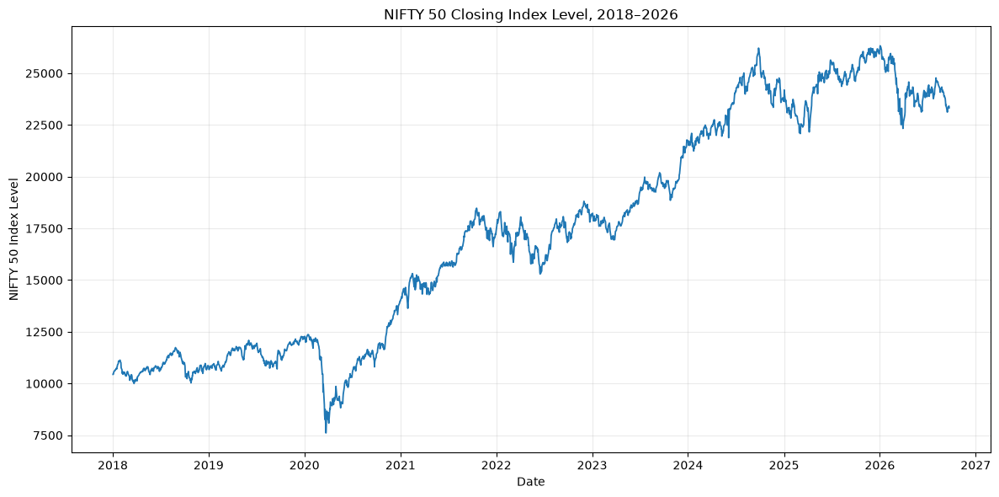

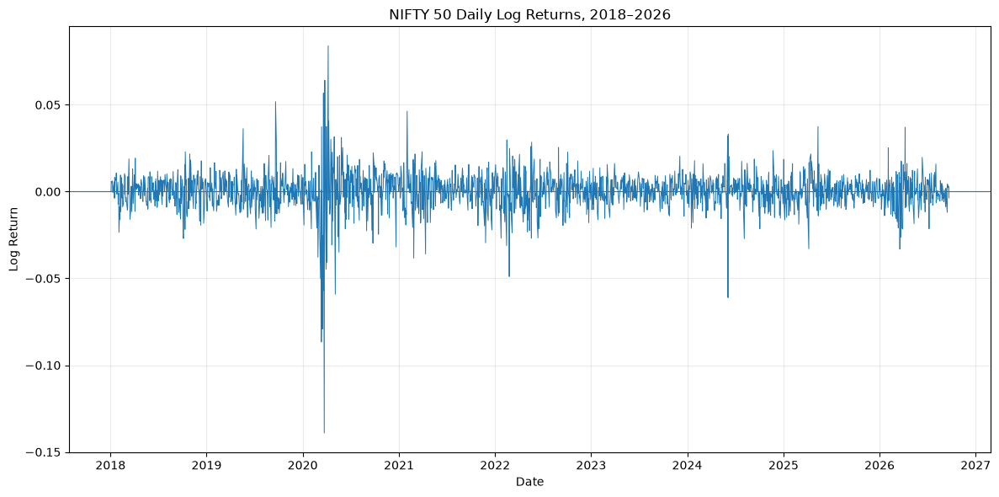

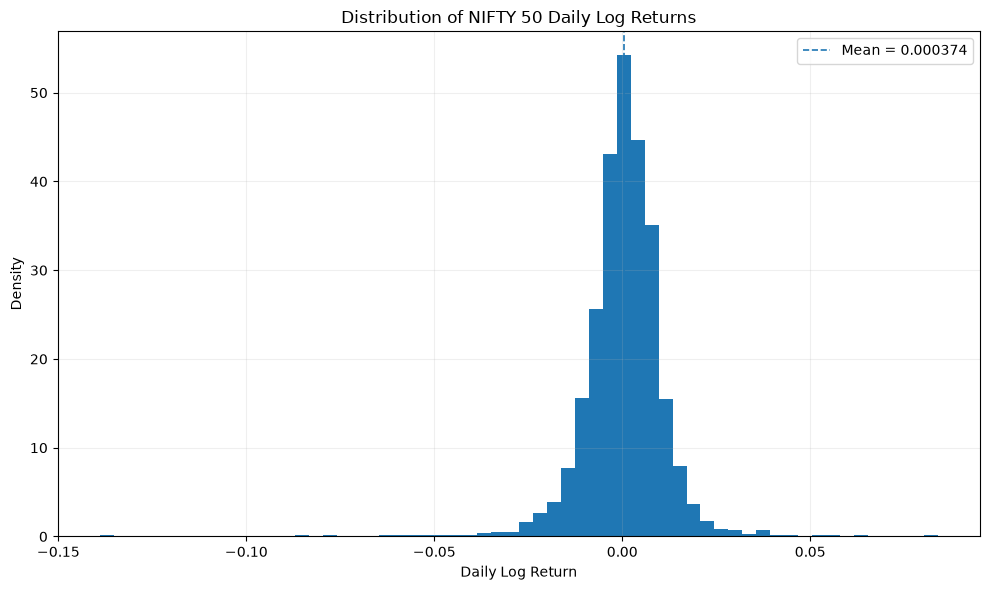

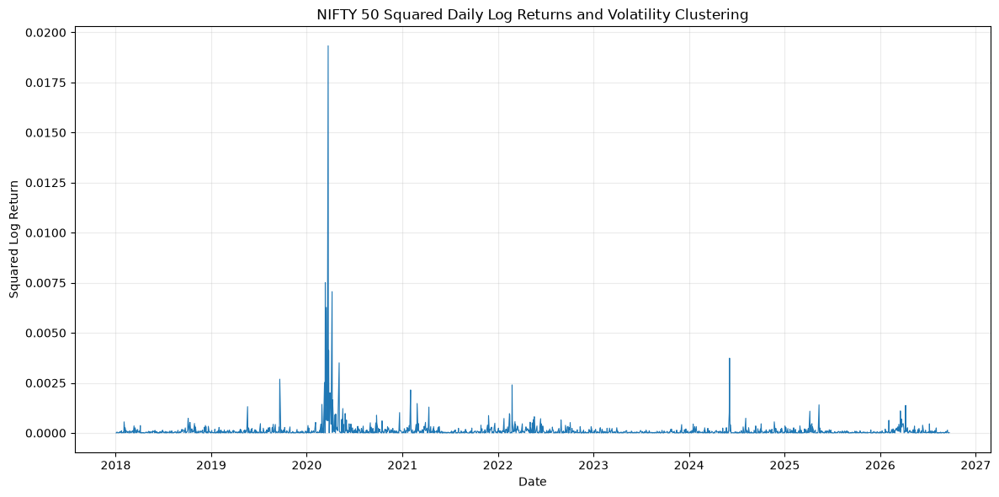


FIGURE FILE VERIFICATION
Figure_01_NIFTY_50_Index_Level.png                 exists=True size=228,545 bytes
Figure_02_NIFTY_50_Daily_Log_Returns.png           exists=True size=356,120 bytes
Figure_03_NIFTY_50_Return_Distribution.png         exists=True size=78,331 bytes
Figure_04_NIFTY_50_Squared_Returns.png             exists=True size=187,863 bytes

DESCRIPTIVE FIGURE GENERATION COMPLETE
Output folder:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures

Resolution: 300 DPI
Format    : PNG
Status    : ALL 4 FIGURES VERIFIED


In [362]:
# ============================================================
# FIGURES 1–4: DESCRIPTIVE MARKET ANALYSIS
# FINAL RESEARCH FIGURE OUTPUT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 1. PROJECT AND OUTPUT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
)

OUTPUT_DIR = PROJECT_ROOT / "output"
FILES_DIR = OUTPUT_DIR / "files"
RESEARCH_DIR = FILES_DIR / "research"
FIGURE_DIR = RESEARCH_DIR / "figures"

# Create required folders
FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. VERIFY OUTPUT LOCATION
# ============================================================

print("=" * 90)
print("FINAL RESEARCH FIGURE OUTPUT DIRECTORY")
print("=" * 90)

print("Project root :", PROJECT_ROOT)
print("Output       :", OUTPUT_DIR)
print("Files        :", FILES_DIR)
print("Research     :", RESEARCH_DIR)
print("Figures      :", FIGURE_DIR)

print("\nFolder verification:")
print("Project root exists :", PROJECT_ROOT.exists())
print("Output exists       :", OUTPUT_DIR.exists())
print("Files exists        :", FILES_DIR.exists())
print("Research exists     :", RESEARCH_DIR.exists())
print("Figures exists      :", FIGURE_DIR.exists())


# ============================================================
# 3. PREPARE NIFTY DATA
# ============================================================

fig_data = clean_nifty.copy()

fig_data["Date"] = pd.to_datetime(
    fig_data["Date"]
)

fig_data = (
    fig_data
    .sort_values("Date")
    .set_index("Date")
)

returns = pd.to_numeric(
    fig_data["Log_Return"],
    errors="coerce"
).dropna()

close = pd.to_numeric(
    fig_data["Close"],
    errors="coerce"
).dropna()

squared_returns = returns ** 2


# ============================================================
# 4. FIGURE 1
# NIFTY 50 CLOSING INDEX LEVEL
# ============================================================

fig = plt.figure(figsize=(12, 6))

plt.plot(
    close.index,
    close.values,
    linewidth=1.3
)

plt.title(
    "NIFTY 50 Closing Index Level, 2018–2026"
)

plt.xlabel("Date")
plt.ylabel("NIFTY 50 Index Level")

plt.grid(alpha=0.25)

plt.tight_layout()

figure_01_path = (
    FIGURE_DIR /
    "Figure_01_NIFTY_50_Index_Level.png"
)

fig.savefig(
    figure_01_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 5. FIGURE 2
# NIFTY 50 DAILY LOG RETURNS
# ============================================================

fig = plt.figure(figsize=(12, 6))

plt.plot(
    returns.index,
    returns.values,
    linewidth=0.7
)

plt.axhline(
    0,
    linewidth=0.8
)

plt.title(
    "NIFTY 50 Daily Log Returns, 2018–2026"
)

plt.xlabel("Date")
plt.ylabel("Log Return")

plt.grid(alpha=0.25)

plt.tight_layout()

figure_02_path = (
    FIGURE_DIR /
    "Figure_02_NIFTY_50_Daily_Log_Returns.png"
)

fig.savefig(
    figure_02_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 6. FIGURE 3
# DISTRIBUTION OF DAILY LOG RETURNS
# ============================================================

fig = plt.figure(figsize=(10, 6))

plt.hist(
    returns.values,
    bins=60,
    density=True
)

plt.axvline(
    returns.mean(),
    linestyle="--",
    linewidth=1.2,
    label=f"Mean = {returns.mean():.6f}"
)

plt.title(
    "Distribution of NIFTY 50 Daily Log Returns"
)

plt.xlabel("Daily Log Return")
plt.ylabel("Density")

plt.legend()

plt.grid(alpha=0.20)

plt.tight_layout()

figure_03_path = (
    FIGURE_DIR /
    "Figure_03_NIFTY_50_Return_Distribution.png"
)

fig.savefig(
    figure_03_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 7. FIGURE 4
# SQUARED RETURNS / VOLATILITY CLUSTERING
# ============================================================

fig = plt.figure(figsize=(12, 6))

plt.plot(
    squared_returns.index,
    squared_returns.values,
    linewidth=0.8
)

plt.title(
    "NIFTY 50 Squared Daily Log Returns and Volatility Clustering"
)

plt.xlabel("Date")
plt.ylabel("Squared Log Return")

plt.grid(alpha=0.25)

plt.tight_layout()

figure_04_path = (
    FIGURE_DIR /
    "Figure_04_NIFTY_50_Squared_Returns.png"
)

fig.savefig(
    figure_04_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 8. FINAL FILE VERIFICATION
# ============================================================

print("\n" + "=" * 90)
print("FIGURE FILE VERIFICATION")
print("=" * 90)

figure_paths = [
    figure_01_path,
    figure_02_path,
    figure_03_path,
    figure_04_path
]

all_verified = True

for path in figure_paths:

    exists = path.exists()

    if not exists:
        all_verified = False

    size = path.stat().st_size if exists else 0

    print(
        f"{path.name:<50} "
        f"exists={exists} "
        f"size={size:,} bytes"
    )


# ============================================================
# 9. FINAL STATUS
# ============================================================

print("\n" + "=" * 90)
print("DESCRIPTIVE FIGURE GENERATION COMPLETE")
print("=" * 90)

print("Output folder:")
print(FIGURE_DIR)

print("\nResolution: 300 DPI")
print("Format    : PNG")

if all_verified:
    print("Status    : ALL 4 FIGURES VERIFIED")
else:
    print("Status    : VERIFICATION FAILED — CHECK ABOVE")

print("=" * 90)

In [363]:

# ============================================================
# DIAGNOSTIC — LOCATE AUTHORITATIVE VIX-ENHANCED OOS OBJECTS
# DO NOT MODIFY ANY MODEL OBJECT
# ============================================================

print("=" * 80)
print("SEARCHING FOR EXISTING VIX-ENHANCED FORECAST OBJECTS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Show relevant DataFrame / Series objects
# ------------------------------------------------------------

candidate_names = []

for name, obj in globals().items():

    try:
        if isinstance(obj, (pd.DataFrame, pd.Series)):

            name_lower = name.lower()

            if any(term in name_lower for term in [
                "vix",
                "egarch",
                "hist20",
                "historical",
                "ewma",
                "oos",
                "forecast"
            ]):

                candidate_names.append(name)

    except Exception:
        pass


print("\nCandidate objects currently in kernel:\n")

for name in sorted(candidate_names):
    obj = globals()[name]

    print(
        f"{name:<45} "
        f"type={type(obj).__name__:<10} "
        f"shape={getattr(obj, 'shape', None)}"
    )


# ------------------------------------------------------------
# 2. Inspect columns of important OOS DataFrames
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("OOS DATAFRAME COLUMN INVENTORY")
print("=" * 80)

for name in sorted(candidate_names):

    obj = globals()[name]

    if isinstance(obj, pd.DataFrame):

        try:

            # Only inspect reasonably sized DataFrames
            if len(obj) >= 500:

                print(f"\n{name}")
                print("-" * len(name))
                print("Shape:", obj.shape)
                print("Index type:", type(obj.index).__name__)
                print("Columns:")

                for col in obj.columns:
                    print(f"   {col}")

        except Exception:
            pass


# ------------------------------------------------------------
# 3. Specifically inspect likely authoritative objects
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("KNOWN FINAL / LEGACY OBJECT CHECK")
print("=" * 80)

known_names = [
    "oos_garch_vix",
    "garch_vix_oos",
    "egarch_vix",
    "garch_vix_forecast",
    "egarch_vix_oos",
    "egarch_vix_oos_forecast",
    "egarch_vix_forecast",
    "historical_vix_oos_forecast",
    "hist20_vix_forecast",
    "EWMA_VIX_Forecast",
    "ewma_vix_forecast",
    "ewma_vix_oos_forecast"
]

for name in known_names:

    exists = name in globals()

    print(f"{name:<40} present={exists}")

    if exists:

        obj = globals()[name]

        print(
            f"    type={type(obj).__name__}, "
            f"shape={getattr(obj, 'shape', None)}"
        )

        if isinstance(obj, pd.DataFrame):
            print(
                "    columns:",
                list(obj.columns)
            )


# ------------------------------------------------------------
# 4. Check the three authoritative final result structures
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CHECKING AUTHORITATIVE FINAL CELL OBJECTS")
print("=" * 80)

for name in [
    "oos",
    "test_data_vix_timing",
    "evaluation"
]:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}")
        print("Type:", type(obj).__name__)
        print("Shape:", getattr(obj, "shape", None))

        if isinstance(obj, pd.DataFrame):

            print("Columns containing VIX / forecast:")
            relevant = [
                c for c in obj.columns
                if any(
                    term in str(c).lower()
                    for term in [
                        "vix",
                        "forecast",
                        "egarch",
                        "ewma",
                        "historical"
                    ]
                )
            ]

            for c in relevant:
                print("   ", c)


print("\n" + "=" * 80)
print("DIAGNOSTIC COMPLETE")
print("=" * 80)



SEARCHING FOR EXISTING VIX-ENHANCED FORECAST OBJECTS

Candidate objects currently in kernel:

X_vix                                         type=DataFrame  shape=(493, 3)
X_vix_level                                   type=DataFrame  shape=(1476, 2)
X_vix_log                                     type=DataFrame  shape=(1476, 2)
arch_gjr_forecasts                            type=Series     shape=(673,)
calibration_hist_vix                          type=DataFrame  shape=(1636, 3)
combined_forecast                             type=Series     shape=(493,)
egarch_base                                   type=Series     shape=(673,)
egarch_estimation                             type=DataFrame  shape=(983, 1)
egarch_full_validation_sample                 type=DataFrame  shape=(1476, 1)
egarch_inventory                              type=DataFrame  shape=(3, 6)
egarch_oos_volatility                         type=Series     shape=(673,)
egarch_strict_history                         type=DataFrame  sha

FIGURE DATA-LINEAGE CHECK
Observations : 673
First date   : 2024-01-01
Last date    : 2026-09-22
Missing      : 0

Authoritative sources:
  EGARCH-t + VIX       : egarch_vix
  Historical 20D + VIX : oos_hist_vix['Historical_20D_VIX_WalkForward']
  EWMA + VIX            : ewma_vix_forecast
  EGARCH-t              : test_data_vix_timing['EGARCH_T_Volatility']
  GJR-GARCH-t           : test_data_vix_timing['GJR_GARCH_T_Volatility']
  GARCH-t               : test_data_vix_timing['GARCH_T_Volatility']
  EWMA                  : test_data_vix_timing['EWMA_OneStep_Forecast']
  Historical 20D        : historical_20d_strict

Data-lineage check: PASS


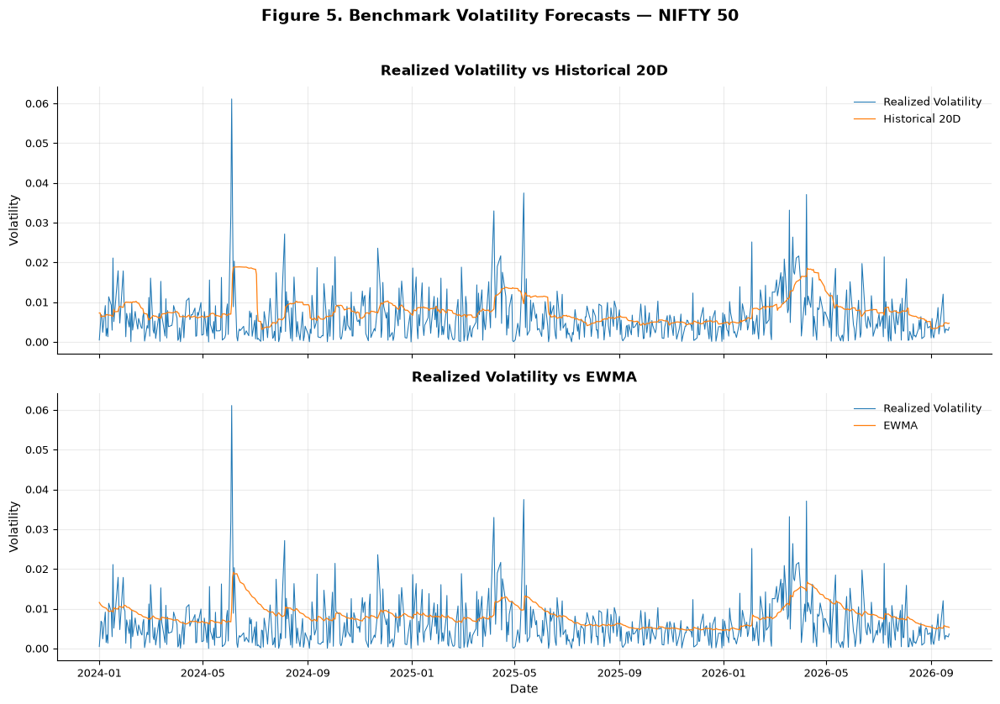

Saved: Figure_05_Benchmark_Volatility_Forecasts.png


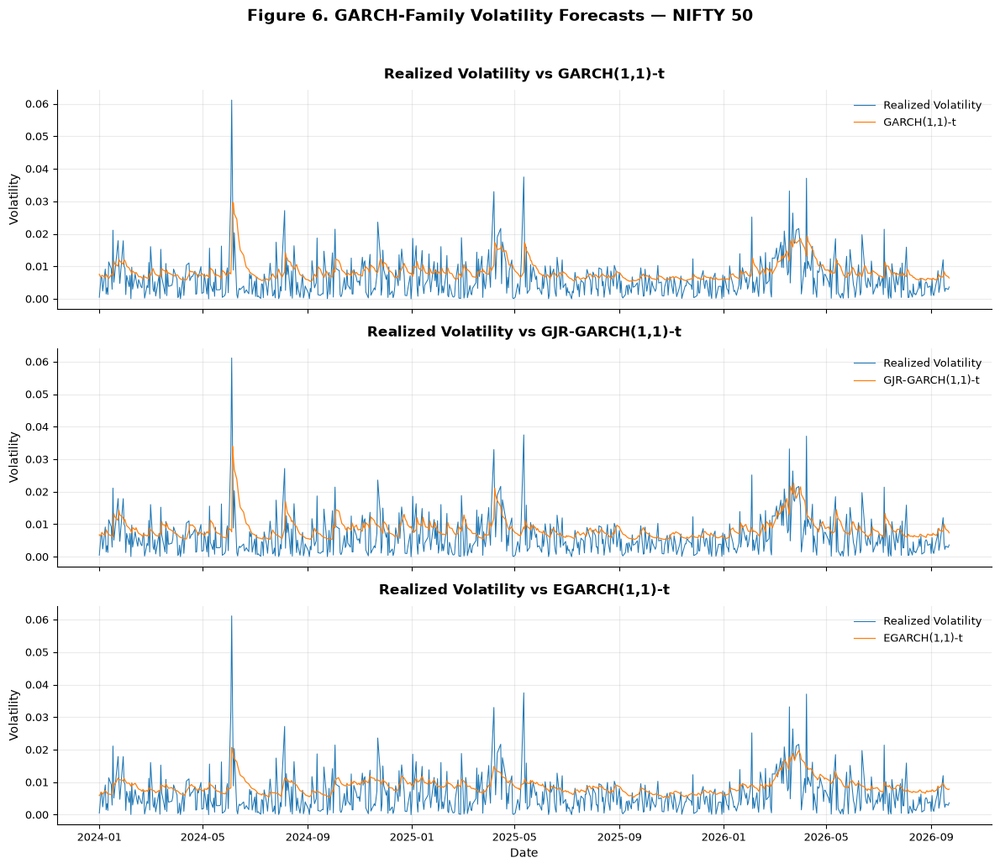

Saved: Figure_06_GARCH_Family_Forecasts.png


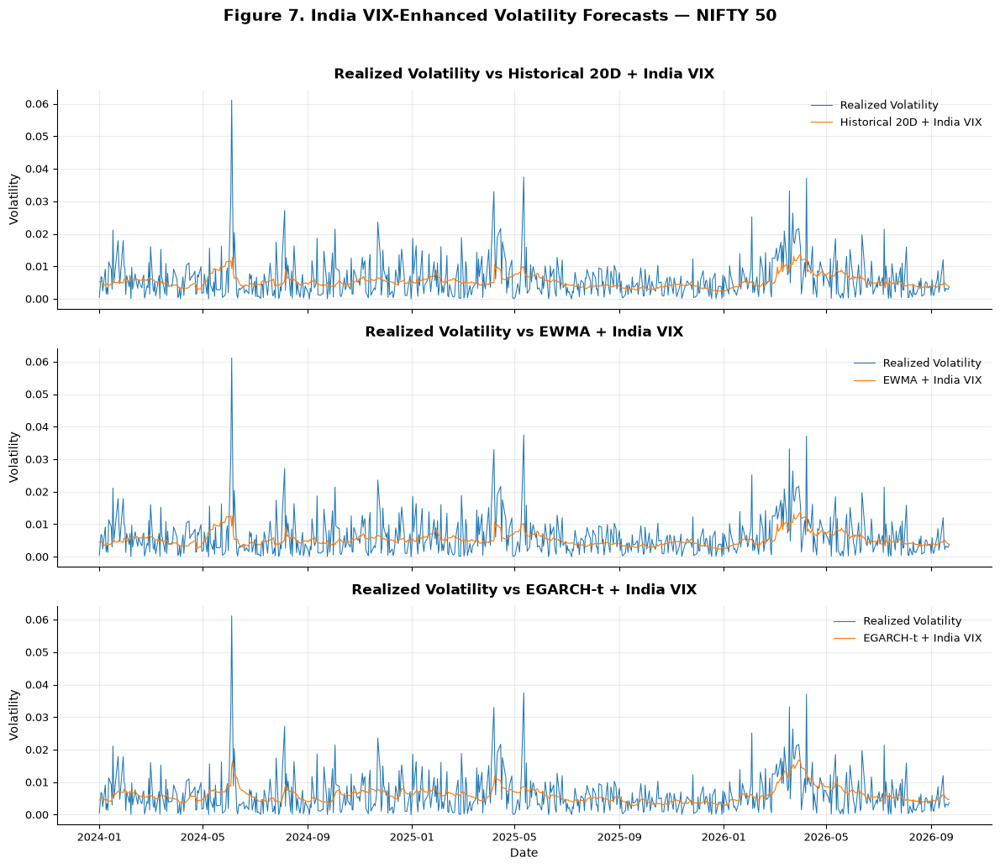

Saved: Figure_07_VIX_Enhanced_Forecasts.png


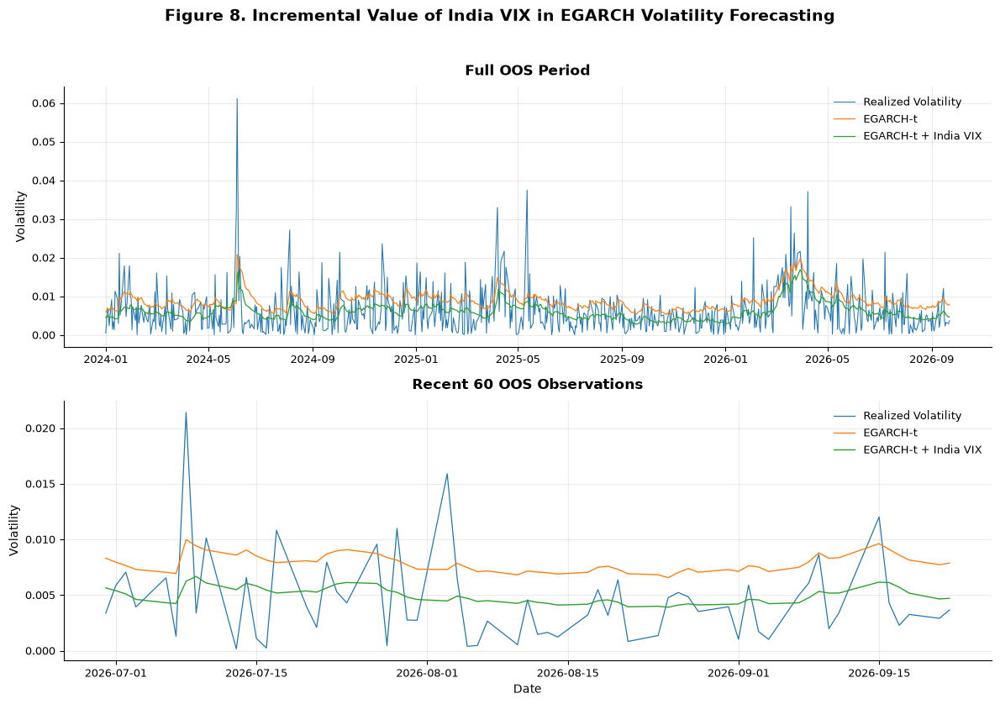

Saved: Figure_08_EGARCH_vs_EGARCH_VIX.png

FINAL FIGURE FILE VERIFICATION
Figure_05_Benchmark_Volatility_Forecasts.png       exists=True size=755,633 bytes
Figure_06_GARCH_Family_Forecasts.png               exists=True size=1,027,561 bytes
Figure_07_VIX_Enhanced_Forecasts.png               exists=True size=1,015,820 bytes
Figure_08_EGARCH_vs_EGARCH_VIX.png                 exists=True size=723,245 bytes

FIGURES 5–8: FINAL REFINED VERSION COMPLETE


In [364]:

# ============================================================
# FINAL REFINED RESEARCH FIGURES 5–8
# Uses ONLY authoritative existing forecast objects
# NO MODEL REFITTING
# NO CALIBRATION RECONSTRUCTION
# NO FORECAST MODIFICATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)


# ============================================================
# 2. COMMON AUTHORITATIVE OOS DATA
# ============================================================

fig_data = test_data_vix_timing.copy()

fig_data["Actual_Volatility"] = (
    fig_data["Log_Return"].abs()
)

# Strict Historical 20D benchmark
fig_data["Historical_20D"] = (
    historical_20d_strict.reindex(fig_data.index)
)

# Authoritative core forecasts
fig_data["EWMA"] = (
    fig_data["EWMA_OneStep_Forecast"]
)

fig_data["GARCH_t"] = (
    fig_data["GARCH_T_Volatility"]
)

fig_data["GJR_GARCH_t"] = (
    fig_data["GJR_GARCH_T_Volatility"]
)

fig_data["EGARCH_t"] = (
    fig_data["EGARCH_T_Volatility"]
)


# ============================================================
# 3. AUTHORITATIVE VIX-ENHANCED FORECASTS
# ============================================================

# EGARCH + India VIX
fig_data["EGARCH_t_VIX"] = (
    egarch_vix.reindex(fig_data.index)
)

# Historical 20D + India VIX
fig_data["Historical_20D_VIX"] = (
    oos_hist_vix[
        "Historical_20D_VIX_WalkForward"
    ].reindex(fig_data.index)
)

# EWMA + India VIX
fig_data["EWMA_VIX"] = (
    ewma_vix_forecast.reindex(fig_data.index)
)


# ============================================================
# 4. VERIFY COMMON OOS SAMPLE
# ============================================================

plot_columns = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
    "Historical_20D_VIX",
    "EWMA_VIX",
    "EGARCH_t_VIX"
]

plot_data = fig_data[plot_columns].copy()

print("=" * 80)
print("FIGURE DATA-LINEAGE CHECK")
print("=" * 80)

print("Observations :", len(plot_data))
print("First date   :", plot_data.index.min().date())
print("Last date    :", plot_data.index.max().date())
print("Missing      :", plot_data.isna().sum().sum())

if len(plot_data) != 673:
    raise ValueError(
        f"Expected 673 OOS observations; found {len(plot_data)}."
    )

if plot_data.isna().sum().sum() != 0:
    raise ValueError(
        "Missing values detected in figure data."
    )

print("\nAuthoritative sources:")
print("  EGARCH-t + VIX       : egarch_vix")
print("  Historical 20D + VIX : oos_hist_vix['Historical_20D_VIX_WalkForward']")
print("  EWMA + VIX            : ewma_vix_forecast")
print("  EGARCH-t              : test_data_vix_timing['EGARCH_T_Volatility']")
print("  GJR-GARCH-t           : test_data_vix_timing['GJR_GARCH_T_Volatility']")
print("  GARCH-t               : test_data_vix_timing['GARCH_T_Volatility']")
print("  EWMA                  : test_data_vix_timing['EWMA_OneStep_Forecast']")
print("  Historical 20D        : historical_20d_strict")

print("\nData-lineage check: PASS")


# ============================================================
# 5. COMMON PLOT SETTINGS
# ============================================================

def clean_axis(ax, title):
    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=10
    )

    ax.set_ylabel(
        "Volatility",
        fontsize=10
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        labelsize=9
    )


def save_plot(fig, filename):

    path = os.path.join(
        FIGURE_DIR,
        filename
    )

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {filename}")


# ============================================================
# FIGURE 5
# REALIZED VOLATILITY VS SIMPLE BENCHMARKS
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8.5),
    sharex=True
)

# Historical 20D
axes[0].plot(
    plot_data.index,
    plot_data["Actual_Volatility"],
    linewidth=0.75,
    label="Realized Volatility"
)

axes[0].plot(
    plot_data.index,
    plot_data["Historical_20D"],
    linewidth=0.90,
    label="Historical 20D"
)

clean_axis(
    axes[0],
    "Realized Volatility vs Historical 20D"
)

axes[0].legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)


# EWMA
axes[1].plot(
    plot_data.index,
    plot_data["Actual_Volatility"],
    linewidth=0.75,
    label="Realized Volatility"
)

axes[1].plot(
    plot_data.index,
    plot_data["EWMA"],
    linewidth=0.90,
    label="EWMA"
)

clean_axis(
    axes[1],
    "Realized Volatility vs EWMA"
)

axes[1].set_xlabel(
    "Date",
    fontsize=10
)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

fig.suptitle(
    "Figure 5. Benchmark Volatility Forecasts — NIFTY 50",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 1, 0.96]
)

save_plot(
    fig,
    "Figure_05_Benchmark_Volatility_Forecasts.png"
)


# ============================================================
# FIGURE 6
# GARCH-FAMILY MODELS
# ============================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 10.5),
    sharex=True
)

garch_models = [
    ("GARCH_t", "GARCH(1,1)-t"),
    ("GJR_GARCH_t", "GJR-GARCH(1,1)-t"),
    ("EGARCH_t", "EGARCH(1,1)-t")
]

for ax, (column, title) in zip(
    axes,
    garch_models
):

    ax.plot(
        plot_data.index,
        plot_data["Actual_Volatility"],
        linewidth=0.75,
        label="Realized Volatility"
    )

    ax.plot(
        plot_data.index,
        plot_data[column],
        linewidth=0.90,
        label=title
    )

    clean_axis(
        ax,
        f"Realized Volatility vs {title}"
    )

    ax.legend(
        frameon=False,
        fontsize=9,
        loc="upper right"
    )


axes[-1].set_xlabel(
    "Date",
    fontsize=10
)

fig.suptitle(
    "Figure 6. GARCH-Family Volatility Forecasts — NIFTY 50",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 1, 0.96]
)

save_plot(
    fig,
    "Figure_06_GARCH_Family_Forecasts.png"
)


# ============================================================
# FIGURE 7
# INDIA VIX-ENHANCED MODELS
# ============================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 10.5),
    sharex=True
)

vix_models = [
    (
        "Historical_20D_VIX",
        "Historical 20D + India VIX"
    ),
    (
        "EWMA_VIX",
        "EWMA + India VIX"
    ),
    (
        "EGARCH_t_VIX",
        "EGARCH-t + India VIX"
    )
]

for ax, (column, title) in zip(
    axes,
    vix_models
):

    ax.plot(
        plot_data.index,
        plot_data["Actual_Volatility"],
        linewidth=0.75,
        label="Realized Volatility"
    )

    ax.plot(
        plot_data.index,
        plot_data[column],
        linewidth=0.90,
        label=title
    )

    clean_axis(
        ax,
        f"Realized Volatility vs {title}"
    )

    ax.legend(
        frameon=False,
        fontsize=9,
        loc="upper right"
    )


axes[-1].set_xlabel(
    "Date",
    fontsize=10
)

fig.suptitle(
    "Figure 7. India VIX-Enhanced Volatility Forecasts — NIFTY 50",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 1, 0.96]
)

save_plot(
    fig,
    "Figure_07_VIX_Enhanced_Forecasts.png"
)


# ============================================================
# FIGURE 8
# EGARCH-T VS EGARCH-T + INDIA VIX
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8.5)
)

# ------------------------------------------------------------
# Full OOS period
# ------------------------------------------------------------

axes[0].plot(
    plot_data.index,
    plot_data["Actual_Volatility"],
    linewidth=0.75,
    label="Realized Volatility"
)

axes[0].plot(
    plot_data.index,
    plot_data["EGARCH_t"],
    linewidth=0.90,
    label="EGARCH-t"
)

axes[0].plot(
    plot_data.index,
    plot_data["EGARCH_t_VIX"],
    linewidth=0.90,
    label="EGARCH-t + India VIX"
)

clean_axis(
    axes[0],
    "Full OOS Period"
)

axes[0].legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)


# ------------------------------------------------------------
# Recent 60 observations
# ------------------------------------------------------------

recent = plot_data.tail(60)

axes[1].plot(
    recent.index,
    recent["Actual_Volatility"],
    linewidth=0.90,
    label="Realized Volatility"
)

axes[1].plot(
    recent.index,
    recent["EGARCH_t"],
    linewidth=1.00,
    label="EGARCH-t"
)

axes[1].plot(
    recent.index,
    recent["EGARCH_t_VIX"],
    linewidth=1.00,
    label="EGARCH-t + India VIX"
)

clean_axis(
    axes[1],
    "Recent 60 OOS Observations"
)

axes[1].set_xlabel(
    "Date",
    fontsize=10
)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

fig.suptitle(
    "Figure 8. Incremental Value of India VIX in EGARCH Volatility Forecasting",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 1, 0.96]
)

save_plot(
    fig,
    "Figure_08_EGARCH_vs_EGARCH_VIX.png"
)


# ============================================================
# 6. FINAL FILE VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("FINAL FIGURE FILE VERIFICATION")
print("=" * 80)

figure_files = [
    "Figure_05_Benchmark_Volatility_Forecasts.png",
    "Figure_06_GARCH_Family_Forecasts.png",
    "Figure_07_VIX_Enhanced_Forecasts.png",
    "Figure_08_EGARCH_vs_EGARCH_VIX.png"
]

for filename in figure_files:

    path = os.path.join(
        FIGURE_DIR,
        filename
    )

    exists = os.path.exists(path)

    size = (
        os.path.getsize(path)
        if exists
        else 0
    )

    print(
        f"{filename:<50} "
        f"exists={exists} "
        f"size={size:,} bytes"
    )

print("\n" + "=" * 80)
print("FIGURES 5–8: FINAL REFINED VERSION COMPLETE")
print("=" * 80)


In [365]:
# ============================================================
# INTERACTIVE NIFTY 50 VOLATILITY FORECAST VISUALIZATION
# ============================================================
#
# Purpose:
#   1. Interactive volatility forecast explorer
#   2. Individual-model forecast comparison
#   3. Full OOS combined forecast comparison
#
# Data lineage:
#   - Realized Volatility      -> |Log_Return|
#   - Historical 20D           -> historical_20d_strict
#   - EWMA                      -> EWMA_OneStep_Forecast
#   - GARCH(1,1)-t              -> GARCH_T_Volatility
#   - GJR-GARCH(1,1)-t          -> GJR_GARCH_T_Volatility
#   - EGARCH(1,1)-t             -> EGARCH_T_Volatility
#   - Historical 20D + VIX      -> oos_hist_vix
#   - EWMA + VIX                 -> ewma_vix_forecast
#   - EGARCH-t + VIX             -> egarch_vix
#
# Common OOS period:
#   2024-01-01 to 2026-09-22
#   673 observations
#
# IMPORTANT:
#   This cell only reads existing validated forecast objects.
#   It does NOT refit, overwrite, or modify forecasting models.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go

from plotly.subplots import make_subplots


# ============================================================
# 2. CREATE FINAL FIGURE DIRECTORY
# ============================================================

PROJECT_ROOT = r"D:\DS Projects\Adaptive Market Risk Intelligence System"

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)


# ============================================================
# 3. BUILD AUTHORITATIVE INTERACTIVE DATASET
# ============================================================

interactive_data = pd.DataFrame(index=test_data_vix_timing.index.copy())


# ------------------------------------------------------------
# Realized volatility
# ------------------------------------------------------------

interactive_data["Realized Volatility"] = (
    test_data_vix_timing["Log_Return"].abs()
)


# ------------------------------------------------------------
# Historical 20D
# ------------------------------------------------------------

interactive_data["Historical 20D"] = (
    historical_20d_strict
    .reindex(interactive_data.index)
)


# ------------------------------------------------------------
# Core volatility models
# ------------------------------------------------------------

interactive_data["EWMA"] = (
    test_data_vix_timing["EWMA_OneStep_Forecast"]
    .reindex(interactive_data.index)
)

interactive_data["GARCH(1,1)-t"] = (
    test_data_vix_timing["GARCH_T_Volatility"]
    .reindex(interactive_data.index)
)

interactive_data["GJR-GARCH(1,1)-t"] = (
    test_data_vix_timing["GJR_GARCH_T_Volatility"]
    .reindex(interactive_data.index)
)

interactive_data["EGARCH(1,1)-t"] = (
    test_data_vix_timing["EGARCH_T_Volatility"]
    .reindex(interactive_data.index)
)


# ------------------------------------------------------------
# VIX-enhanced models
# ------------------------------------------------------------

interactive_data["Historical 20D + India VIX"] = (
    oos_hist_vix["Historical_20D_VIX_WalkForward"]
    .reindex(interactive_data.index)
)

interactive_data["EWMA + India VIX"] = (
    ewma_vix_forecast
    .reindex(interactive_data.index)
)

interactive_data["EGARCH-t + India VIX"] = (
    egarch_vix
    .reindex(interactive_data.index)
)


# ============================================================
# 4. DEFINE MODEL LISTS
# ============================================================

benchmark_models = [
    "Historical 20D",
    "EWMA",
    "GARCH(1,1)-t"
]

garch_family_models = [
    "GARCH(1,1)-t",
    "GJR-GARCH(1,1)-t",
    "EGARCH(1,1)-t"
]

vix_models = [
    "Historical 20D + India VIX",
    "EWMA + India VIX",
    "EGARCH-t + India VIX"
]

all_forecast_models = [
    "Historical 20D",
    "EWMA",
    "GARCH(1,1)-t",
    "GJR-GARCH(1,1)-t",
    "EGARCH(1,1)-t",
    "Historical 20D + India VIX",
    "EWMA + India VIX",
    "EGARCH-t + India VIX"
]


# ============================================================
# 5. BASIC DATA INTEGRITY CHECK
# ============================================================

expected_n = 673

assert len(interactive_data) == expected_n, (
    f"Expected {expected_n} observations, "
    f"found {len(interactive_data)}."
)

assert interactive_data.index.min() == pd.Timestamp("2024-01-01")
assert interactive_data.index.max() == pd.Timestamp("2026-09-22")

missing_summary = interactive_data.isna().sum()

if missing_summary.sum() != 0:
    print("WARNING — Missing values detected:")
    print(missing_summary[missing_summary > 0])
else:
    print("DATA CHECK: PASS — No missing values.")


print("=" * 80)
print("INTERACTIVE VISUALIZATION DATASET")
print("=" * 80)
print(f"Observations : {len(interactive_data)}")
print(f"First date   : {interactive_data.index.min().date()}")
print(f"Last date    : {interactive_data.index.max().date()}")
print(f"Models       : {len(all_forecast_models)}")
print("=" * 80)


# ============================================================
# 6. PERFORMANCE METRICS FROM EXACT PLOTTED DATA
# ============================================================

performance_rows = []

actual = interactive_data["Realized Volatility"]

for model in all_forecast_models:

    forecast = interactive_data[model]

    valid = pd.concat(
        [actual, forecast],
        axis=1
    ).dropna()

    y_actual = valid.iloc[:, 0]
    y_forecast = valid.iloc[:, 1]

    error = y_actual - y_forecast

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    performance_rows.append({
        "Model": model,
        "MAE": mae,
        "RMSE": rmse,
        "N": len(valid)
    })


performance_table = pd.DataFrame(performance_rows)

performance_table = performance_table.sort_values(
    "RMSE"
).reset_index(drop=True)

print("\nPERFORMANCE OF PLOTTED FORECASTS")
print("-" * 80)
print(
    performance_table.to_string(
        index=False,
        formatters={
            "MAE": "{:.6f}".format,
            "RMSE": "{:.6f}".format
        }
    )
)


# ============================================================
# 7. LINE WIDTH SETTINGS
# ============================================================

REALIZED_WIDTH = 1.8
FORECAST_WIDTH = 1.05


# ============================================================
# 8. COMMON HOVER TEMPLATE
# ============================================================

def hover_template(model_name):
    return (
        "Date: %{x|%d %b %Y}"
        f"<br>{model_name}: %{{y:.5f}}"
        "<extra></extra>"
    )


# ============================================================
# 9. FUNCTION TO ADD FORECAST TRACE
# ============================================================

def add_forecast_trace(
    fig,
    model_name,
    showlegend=True,
    legendgroup=None
):

    fig.add_trace(
        go.Scatter(
            x=interactive_data.index,
            y=interactive_data[model_name],
            mode="lines",
            name=model_name,
            legendgroup=legendgroup or model_name,
            showlegend=showlegend,
            line=dict(
                width=FORECAST_WIDTH
            ),
            hovertemplate=hover_template(model_name)
        )
    )


# ============================================================
# 10. MAIN INTERACTIVE EXPLORER
# ============================================================

fig_main = go.Figure()


# ------------------------------------------------------------
# Realized volatility
# ------------------------------------------------------------

fig_main.add_trace(
    go.Scatter(
        x=interactive_data.index,
        y=interactive_data["Realized Volatility"],
        mode="lines",
        name="Realized Volatility",
        line=dict(
            width=REALIZED_WIDTH
        ),
        hovertemplate=hover_template(
            "Realized Volatility"
        )
    )
)


# ------------------------------------------------------------
# Add all forecast models
# ------------------------------------------------------------

for model in all_forecast_models:

    add_forecast_trace(
        fig_main,
        model,
        showlegend=True
    )


# ============================================================
# 11. DROPDOWN VISIBILITY CONTROLS
# ============================================================

total_traces = 1 + len(all_forecast_models)


def visibility_for(selected_models):

    visibility = [True]

    for model in all_forecast_models:
        visibility.append(
            model in selected_models
        )

    return visibility


dropdown_buttons = [

    dict(
        label="All Models",
        method="update",
        args=[
            {
                "visible": [True] * total_traces
            },
            {
                "title.text":
                    "NIFTY 50 — All Volatility Forecast Models"
            }
        ]
    ),

    dict(
        label="Benchmarks",
        method="update",
        args=[
            {
                "visible": visibility_for(
                    benchmark_models
                )
            },
            {
                "title.text":
                    "NIFTY 50 — Benchmark Volatility Models"
            }
        ]
    ),

    dict(
        label="GARCH Family",
        method="update",
        args=[
            {
                "visible": visibility_for(
                    garch_family_models
                )
            },
            {
                "title.text":
                    "NIFTY 50 — GARCH Family Comparison"
            }
        ]
    ),

    dict(
        label="VIX Enhanced",
        method="update",
        args=[
            {
                "visible": visibility_for(
                    vix_models
                )
            },
            {
                "title.text":
                    "NIFTY 50 — India VIX Enhanced Forecasts"
            }
        ]
    ),

    dict(
        label="EGARCH vs EGARCH + VIX",
        method="update",
        args=[
            {
                "visible": visibility_for(
                    [
                        "EGARCH(1,1)-t",
                        "EGARCH-t + India VIX"
                    ]
                )
            },
            {
                "title.text":
                    "NIFTY 50 — EGARCH-t vs EGARCH-t + India VIX"
            }
        ]
    ),

    dict(
        label="Historical 20D vs + VIX",
        method="update",
        args=[
            {
                "visible": visibility_for(
                    [
                        "Historical 20D",
                        "Historical 20D + India VIX"
                    ]
                )
            },
            {
                "title.text":
                    "NIFTY 50 — Historical 20D vs Historical 20D + India VIX"
            }
        ]
    ),

    dict(
        label="EWMA vs + VIX",
        method="update",
        args=[
            {
                "visible": visibility_for(
                    [
                        "EWMA",
                        "EWMA + India VIX"
                    ]
                )
            },
            {
                "title.text":
                    "NIFTY 50 — EWMA vs EWMA + India VIX"
            }
        ]
    )
]


# ============================================================
# 12. MAIN FIGURE LAYOUT
# ============================================================

fig_main.update_layout(

    width=2000,
    height=950,

    template="plotly_white",

    title=dict(
        text="NIFTY 50 — Interactive Volatility Forecast Explorer",
        x=0.5,
        xanchor="center",
        font=dict(
            size=26
        )
    ),

    font=dict(
        family="Arial",
        size=14
    ),

    hovermode="x unified",

    margin=dict(
        l=85,
        r=55,
        t=150,
        b=95
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.01,
        xanchor="center",
        x=0.5,
        font=dict(
            size=13
        )
    ),

    updatemenus=[
        dict(
            type="dropdown",
            direction="down",
            x=0.01,
            y=1.14,
            xanchor="left",
            yanchor="top",
            buttons=dropdown_buttons,
            font=dict(
                size=13
            ),
            bgcolor="white"
        )
    ],

    xaxis=dict(
        title=dict(
            text="Date",
            font=dict(size=17)
        ),
        tickfont=dict(size=13),

        rangeslider=dict(
            visible=True,
            thickness=0.055
        ),

        rangeselector=dict(
            buttons=[
                dict(
                    count=3,
                    label="3M",
                    step="month",
                    stepmode="backward"
                ),
                dict(
                    count=6,
                    label="6M",
                    step="month",
                    stepmode="backward"
                ),
                dict(
                    count=1,
                    label="1Y",
                    step="year",
                    stepmode="backward"
                ),
                dict(
                    count=2,
                    label="2Y",
                    step="year",
                    stepmode="backward"
                ),
                dict(
                    step="all",
                    label="Full OOS"
                )
            ],
            x=0,
            y=1.075,
            font=dict(size=12)
        ),

        showgrid=True,
        gridwidth=0.5
    ),

    yaxis=dict(
        title=dict(
            text="Volatility",
            font=dict(size=17)
        ),
        tickfont=dict(size=13),
        showgrid=True,
        gridwidth=0.5
    )
)


# ============================================================
# 13. SAVE MAIN INTERACTIVE HTML
# ============================================================

main_html = os.path.join(
    FIGURE_DIR,
    "Interactive_NIFTY_Volatility_Forecast_Explorer.html"
)

fig_main.write_html(
    main_html,
    include_plotlyjs=True,
    full_html=True
)

fig_main.show()


# ============================================================
# 14. INDIVIDUAL MODEL SMALL-MULTIPLE GRAPH
# ============================================================
#
# 8 panels:
#   Each panel = Realized Volatility + ONE forecast model
#
# This avoids putting eight forecast lines on top of each other.
# ============================================================

fig_individual = make_subplots(

    rows=4,
    cols=2,

    shared_xaxes=False,
    shared_yaxes=False,

    vertical_spacing=0.075,
    horizontal_spacing=0.075,

    subplot_titles=all_forecast_models
)


for i, model in enumerate(all_forecast_models):

    row = (i // 2) + 1
    col = (i % 2) + 1


    # --------------------------------------------------------
    # Realized volatility
    # --------------------------------------------------------

    fig_individual.add_trace(

        go.Scatter(
            x=interactive_data.index,
            y=interactive_data["Realized Volatility"],
            mode="lines",
            name="Realized Volatility",
            legendgroup="Realized",
            showlegend=(i == 0),

            line=dict(
                width=REALIZED_WIDTH
            ),

            hovertemplate=hover_template(
                "Realized Volatility"
            )
        ),

        row=row,
        col=col
    )


    # --------------------------------------------------------
    # Individual forecast
    # --------------------------------------------------------

    fig_individual.add_trace(

        go.Scatter(
            x=interactive_data.index,
            y=interactive_data[model],
            mode="lines",
            name=model,
            legendgroup=model,
            showlegend=False,

            line=dict(
                width=FORECAST_WIDTH
            ),

            hovertemplate=hover_template(model)
        ),

        row=row,
        col=col
    )


    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------

    fig_individual.update_xaxes(
        title_text="Date",
        tickfont=dict(size=10),
        title_font=dict(size=11),
        showgrid=True,
        gridwidth=0.4,
        row=row,
        col=col
    )

    fig_individual.update_yaxes(
        title_text="Volatility",
        tickfont=dict(size=10),
        title_font=dict(size=11),
        showgrid=True,
        gridwidth=0.4,
        row=row,
        col=col
    )


# ============================================================
# INDIVIDUAL GRAPH LAYOUT
# ============================================================

fig_individual.update_layout(

    width=2000,
    height=1550,

    template="plotly_white",

    title=dict(
        text="NIFTY 50 — Individual Out-of-Sample Volatility Forecasts",
        x=0.5,
        xanchor="center",
        font=dict(size=26)
    ),

    font=dict(
        family="Arial",
        size=12
    ),

    hovermode="x",

    margin=dict(
        l=70,
        r=50,
        t=110,
        b=70
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.01,
        xanchor="center",
        x=0.5,
        font=dict(size=13)
    )
)


# ============================================================
# SAVE INDIVIDUAL MODEL GRAPH
# ============================================================

individual_html = os.path.join(
    FIGURE_DIR,
    "Interactive_NIFTY_Individual_Model_Forecasts.html"
)

fig_individual.write_html(
    individual_html,
    include_plotlyjs=True,
    full_html=True
)

fig_individual.show()


# ============================================================
# 15. FULL OOS COMBINED GRAPH
# ============================================================
#
# Purpose:
#   Direct comparison of all forecasts across the entire
#   untouched 2024–2026 OOS period.
#
#   Realized volatility is shown together with all eight
#   forecasting specifications.
# ============================================================

fig_combined = go.Figure()


# ------------------------------------------------------------
# Realized volatility
# ------------------------------------------------------------

fig_combined.add_trace(

    go.Scatter(
        x=interactive_data.index,
        y=interactive_data["Realized Volatility"],
        mode="lines",

        name="Realized Volatility",

        line=dict(
            width=REALIZED_WIDTH
        ),

        hovertemplate=hover_template(
            "Realized Volatility"
        )
    )
)


# ------------------------------------------------------------
# Forecast models
# ------------------------------------------------------------

for model in all_forecast_models:

    fig_combined.add_trace(

        go.Scatter(
            x=interactive_data.index,
            y=interactive_data[model],
            mode="lines",

            name=model,

            line=dict(
                width=FORECAST_WIDTH
            ),

            hovertemplate=hover_template(model)
        )
    )


# ============================================================
# FULL COMBINED GRAPH LAYOUT
# ============================================================

fig_combined.update_layout(

    width=2000,
    height=1000,

    template="plotly_white",

    title=dict(
        text="NIFTY 50 — Full Out-of-Sample Volatility Forecast Comparison",
        x=0.5,
        xanchor="center",
        font=dict(size=26)
    ),

    font=dict(
        family="Arial",
        size=14
    ),

    hovermode="x unified",

    margin=dict(
        l=85,
        r=55,
        t=125,
        b=95
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.015,
        xanchor="center",
        x=0.5,
        font=dict(size=13)
    ),

    xaxis=dict(
        title=dict(
            text="Date",
            font=dict(size=17)
        ),

        tickfont=dict(size=13),

        rangeslider=dict(
            visible=True,
            thickness=0.055
        ),

        rangeselector=dict(
            buttons=[
                dict(
                    count=3,
                    label="3M",
                    step="month",
                    stepmode="backward"
                ),
                dict(
                    count=6,
                    label="6M",
                    step="month",
                    stepmode="backward"
                ),
                dict(
                    count=1,
                    label="1Y",
                    step="year",
                    stepmode="backward"
                ),
                dict(
                    count=2,
                    label="2Y",
                    step="year",
                    stepmode="backward"
                ),
                dict(
                    step="all",
                    label="Full OOS"
                )
            ],

            x=0,
            y=1.075,

            font=dict(size=12)
        ),

        showgrid=True,
        gridwidth=0.5
    ),

    yaxis=dict(
        title=dict(
            text="Volatility",
            font=dict(size=17)
        ),

        tickfont=dict(size=13),

        showgrid=True,
        gridwidth=0.5
    )
)


# ============================================================
# SAVE FULL COMBINED GRAPH
# ============================================================

combined_html = os.path.join(
    FIGURE_DIR,
    "Interactive_NIFTY_Full_OOS_Combined_Forecasts.html"
)

fig_combined.write_html(
    combined_html,
    include_plotlyjs=True,
    full_html=True
)

fig_combined.show()


# ============================================================
# 16. FINAL OUTPUT REPORT
# ============================================================

print("\n")
print("=" * 80)
print("INTERACTIVE VISUALIZATION GENERATION COMPLETE")
print("=" * 80)

print(f"\nFigure directory:")
print(FIGURE_DIR)

print("\nGenerated files:")

for filepath in [
    main_html,
    individual_html,
    combined_html
]:

    if os.path.exists(filepath):

        size_kb = os.path.getsize(filepath) / 1024

        print(
            f"  PASS  {os.path.basename(filepath)}"
            f"  ({size_kb:,.1f} KB)"
        )

    else:

        print(
            f"  FAIL  {os.path.basename(filepath)}"
        )


print("\n")
print("=" * 80)
print("DATA LINEAGE USED")
print("=" * 80)

for column in interactive_data.columns:

    missing = interactive_data[column].isna().sum()

    print(
        f"{column:<35} "
        f"N={len(interactive_data):<4} "
        f"Missing={missing}"
    )


print("\n")
print("=" * 80)
print("OOS PERIOD")
print("=" * 80)

print(
    f"{interactive_data.index.min().date()} "
    f"to "
    f"{interactive_data.index.max().date()}"
)

print(f"Observations: {len(interactive_data)}")

print("\nVisualization generation: PASS")
print("=" * 80)

DATA CHECK: PASS — No missing values.
INTERACTIVE VISUALIZATION DATASET
Observations : 673
First date   : 2024-01-01
Last date    : 2026-09-22
Models       : 8

PERFORMANCE OF PLOTTED FORECASTS
--------------------------------------------------------------------------------
                     Model      MAE     RMSE   N
      EGARCH-t + India VIX 0.003737 0.005262 673
Historical 20D + India VIX 0.003863 0.005630 673
          EWMA + India VIX 0.003863 0.005637 673
             EGARCH(1,1)-t 0.004628 0.005796 673
              GARCH(1,1)-t 0.004852 0.006291 673
          GJR-GARCH(1,1)-t 0.004865 0.006349 673
                      EWMA 0.004924 0.006419 673
            Historical 20D 0.004923 0.006564 673




INTERACTIVE VISUALIZATION GENERATION COMPLETE

Figure directory:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures

Generated files:
  PASS  Interactive_NIFTY_Volatility_Forecast_Explorer.html  (4,928.2 KB)
  PASS  Interactive_NIFTY_Individual_Model_Forecasts.html  (5,094.8 KB)
  PASS  Interactive_NIFTY_Full_OOS_Combined_Forecasts.html  (4,926.5 KB)


DATA LINEAGE USED
Realized Volatility                 N=673  Missing=0
Historical 20D                      N=673  Missing=0
EWMA                                N=673  Missing=0
GARCH(1,1)-t                        N=673  Missing=0
GJR-GARCH(1,1)-t                    N=673  Missing=0
EGARCH(1,1)-t                       N=673  Missing=0
Historical 20D + India VIX          N=673  Missing=0
EWMA + India VIX                    N=673  Missing=0
EGARCH-t + India VIX                N=673  Missing=0


OOS PERIOD
2024-01-01 to 2026-09-22
Observations: 673

Visualization generation: PASS


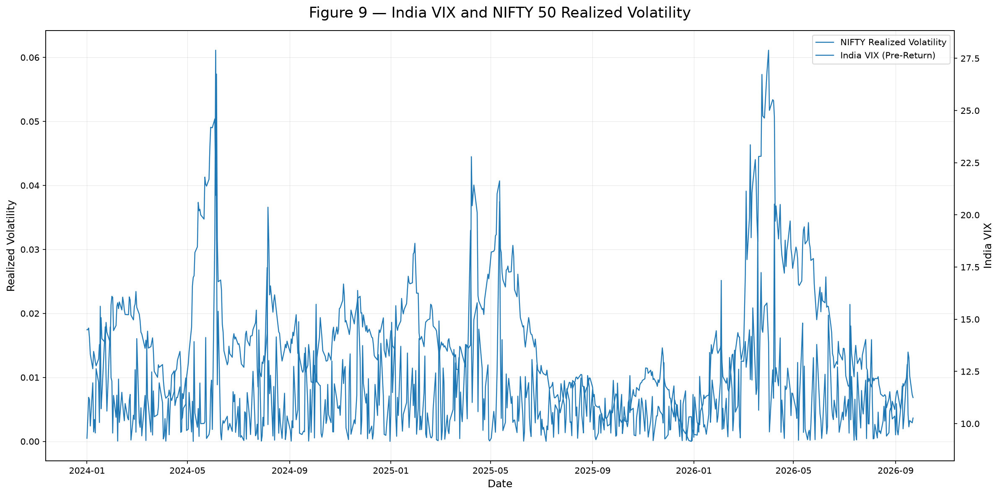

FIGURE 09 — VERIFICATION
Observations : 673
First date   : 2024-01-01
Last date    : 2026-09-22
Missing      : 0
Saved to     : D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_09_India_VIX_vs_NIFTY_Realized_Volatility.png
File exists  : True


In [366]:
# ============================================================
# FIGURE 09 — INDIA VIX VS NIFTY REALIZED VOLATILITY
# ============================================================
#
# Purpose:
#   Examine the relationship between the strict pre-return
#   India VIX signal and realized NIFTY 50 volatility.
#
# Data lineage:
#   Realized Volatility -> |Log_Return|
#   India VIX           -> India_VIX_PreReturn
#
# OOS period:
#   2024-01-01 to 2026-09-22
#
# This cell does NOT modify any forecasting object.
# ============================================================

import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Figure directory
# ------------------------------------------------------------

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)


# ------------------------------------------------------------
# Build plotting data from authoritative OOS objects
# ------------------------------------------------------------

fig9_data = pd.DataFrame(index=test_data_vix_timing.index)

fig9_data["Realized_Volatility"] = (
    test_data_vix_timing["Log_Return"].abs()
)

fig9_data["India_VIX"] = (
    test_data_vix_timing["India_VIX_PreReturn"]
)

fig9_data = fig9_data.dropna()


# ------------------------------------------------------------
# Basic integrity checks
# ------------------------------------------------------------

assert len(fig9_data) == 673
assert fig9_data.index.min() == pd.Timestamp("2024-01-01")
assert fig9_data.index.max() == pd.Timestamp("2026-09-22")
assert fig9_data["Realized_Volatility"].isna().sum() == 0
assert fig9_data["India_VIX"].isna().sum() == 0


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax1 = plt.subplots(
    figsize=(16, 8),
    dpi=150
)

ax1.plot(
    fig9_data.index,
    fig9_data["Realized_Volatility"],
    linewidth=1.15,
    label="NIFTY Realized Volatility"
)

ax1.set_xlabel(
    "Date",
    fontsize=12
)

ax1.set_ylabel(
    "Realized Volatility",
    fontsize=12
)

ax1.tick_params(
    axis="both",
    labelsize=10
)

ax1.grid(
    True,
    linewidth=0.4,
    alpha=0.4
)


# ------------------------------------------------------------
# India VIX on secondary axis
# ------------------------------------------------------------

ax2 = ax1.twinx()

ax2.plot(
    fig9_data.index,
    fig9_data["India_VIX"],
    linewidth=1.15,
    label="India VIX (Pre-Return)"
)

ax2.set_ylabel(
    "India VIX",
    fontsize=12
)

ax2.tick_params(
    axis="y",
    labelsize=10
)


# ------------------------------------------------------------
# Combined legend
# ------------------------------------------------------------

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right",
    fontsize=10,
    frameon=True
)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax1.set_title(
    "Figure 9 — India VIX and NIFTY 50 Realized Volatility",
    fontsize=17,
    pad=15
)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

fig.tight_layout()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

FIGURE_09_PATH = os.path.join(
    FIGURE_DIR,
    "Figure_09_India_VIX_vs_NIFTY_Realized_Volatility.png"
)

fig.savefig(
    FIGURE_09_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 80)
print("FIGURE 09 — VERIFICATION")
print("=" * 80)

print(f"Observations : {len(fig9_data)}")
print(f"First date   : {fig9_data.index.min().date()}")
print(f"Last date    : {fig9_data.index.max().date()}")
print(f"Missing      : {fig9_data.isna().sum().sum()}")
print(f"Saved to     : {FIGURE_09_PATH}")
print(f"File exists  : {os.path.exists(FIGURE_09_PATH)}")

print("=" * 80)

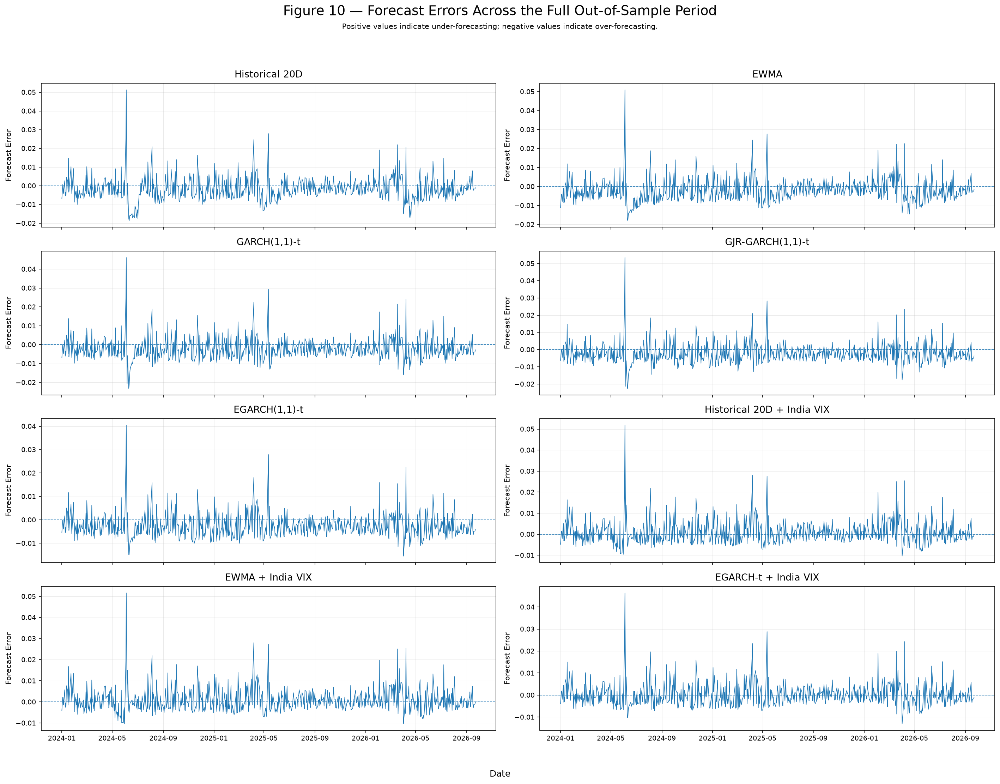

FIGURE 10 — FORECAST ERROR VERIFICATION
OOS period : 2024-01-01 to 2026-09-22
Observations: 673
Missing     : 0

Error summary:
                     Model Mean_Error Mean_Absolute_Error     RMSE
            Historical 20D  -0.001883            0.004923 0.006564
                      EWMA  -0.002174            0.004924 0.006419
              GARCH(1,1)-t  -0.002361            0.004852 0.006291
          GJR-GARCH(1,1)-t  -0.002447            0.004865 0.006349
             EGARCH(1,1)-t  -0.002651            0.004628 0.005796
Historical 20D + India VIX   0.000680            0.003863 0.005630
          EWMA + India VIX   0.000714            0.003863 0.005637
      EGARCH-t + India VIX   0.000012            0.003737 0.005262

Saved to:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_10_Forecast_Errors_Full_OOS.png

File exists: True


In [367]:
# ============================================================
# FIGURE 10 — FORECAST ERRORS OVER THE FULL OOS PERIOD
# ============================================================
#
# Error definition:
#   Forecast Error = Realized Volatility - Forecast Volatility
#
# Positive error  -> model under-forecast volatility
# Negative error  -> model over-forecast volatility
#
# OOS:
#   2024-01-01 to 2026-09-22
#   N = 673
#
# No forecasting model is refitted or modified.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. FIGURE DIRECTORY
# ============================================================

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)


# ============================================================
# 2. AUTHORITATIVE MODEL LIST
# ============================================================

error_models = [
    "Historical 20D",
    "EWMA",
    "GARCH(1,1)-t",
    "GJR-GARCH(1,1)-t",
    "EGARCH(1,1)-t",
    "Historical 20D + India VIX",
    "EWMA + India VIX",
    "EGARCH-t + India VIX"
]


# ============================================================
# 3. BUILD ERROR DATA
# ============================================================

fig10_errors = pd.DataFrame(
    index=interactive_data.index.copy()
)

realized = interactive_data["Realized Volatility"]


for model in error_models:

    fig10_errors[model] = (
        realized
        - interactive_data[model]
    )


# ============================================================
# 4. INTEGRITY CHECKS
# ============================================================

assert len(fig10_errors) == 673

assert (
    fig10_errors.index.min()
    == pd.Timestamp("2024-01-01")
)

assert (
    fig10_errors.index.max()
    == pd.Timestamp("2026-09-22")
)

assert fig10_errors.isna().sum().sum() == 0


# ============================================================
# 5. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(19, 15),
    dpi=150,
    sharex=True
)

axes = axes.flatten()


for i, model in enumerate(error_models):

    ax = axes[i]

    errors = fig10_errors[model]

    ax.plot(
        fig10_errors.index,
        errors,
        linewidth=0.8
    )

    # Zero-error reference
    ax.axhline(
        0,
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_title(
        model,
        fontsize=13,
        pad=8
    )

    ax.set_ylabel(
        "Forecast Error",
        fontsize=10
    )

    ax.tick_params(
        axis="both",
        labelsize=9
    )

    ax.grid(
        True,
        linewidth=0.35,
        alpha=0.35
    )


# ============================================================
# 6. HIDE UNUSED AXES
# ============================================================

for i in range(len(error_models), len(axes)):
    axes[i].set_visible(False)


# ============================================================
# 7. COMMON X LABEL
# ============================================================

fig.supxlabel(
    "Date",
    fontsize=12,
    y=0.02
)


# ============================================================
# 8. MAIN TITLE
# ============================================================

fig.suptitle(
    "Figure 10 — Forecast Errors Across the Full Out-of-Sample Period",
    fontsize=18,
    y=0.995
)


# ============================================================
# 9. EXPLANATORY NOTE
# ============================================================

fig.text(
    0.5,
    0.965,
    "Positive values indicate under-forecasting; "
    "negative values indicate over-forecasting.",
    ha="center",
    fontsize=10
)


# ============================================================
# 10. LAYOUT
# ============================================================

plt.tight_layout(
    rect=[0, 0.035, 1, 0.95]
)


# ============================================================
# 11. SAVE
# ============================================================

FIGURE_10_PATH = os.path.join(
    FIGURE_DIR,
    "Figure_10_Forecast_Errors_Full_OOS.png"
)

fig.savefig(
    FIGURE_10_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. ERROR SUMMARY
# ============================================================

error_summary = pd.DataFrame({
    "Model": error_models,
    "Mean_Error": [
        fig10_errors[m].mean()
        for m in error_models
    ],
    "Mean_Absolute_Error": [
        fig10_errors[m].abs().mean()
        for m in error_models
    ],
    "RMSE": [
        np.sqrt(
            np.mean(fig10_errors[m] ** 2)
        )
        for m in error_models
    ]
})


print("=" * 90)
print("FIGURE 10 — FORECAST ERROR VERIFICATION")
print("=" * 90)

print(
    f"OOS period : "
    f"{fig10_errors.index.min().date()} "
    f"to "
    f"{fig10_errors.index.max().date()}"
)

print(f"Observations: {len(fig10_errors)}")
print(f"Missing     : {fig10_errors.isna().sum().sum()}")

print("\nError summary:")
print(
    error_summary.to_string(
        index=False,
        formatters={
            "Mean_Error": "{:.6f}".format,
            "Mean_Absolute_Error": "{:.6f}".format,
            "RMSE": "{:.6f}".format
        }
    )
)

print("\nSaved to:")
print(FIGURE_10_PATH)

print(f"\nFile exists: {os.path.exists(FIGURE_10_PATH)}")

print("=" * 90)

FIGURE 11 — ROLLING FORECAST ACCURACY AUDIT
OOS observations       : 673
OOS period             : 2024-01-01 to 2026-09-22
Rolling window         : 60 trading days
First rolling MAE date : 2024-03-28
Missing forecast inputs: 0
Missing rolling MAEs   : 472


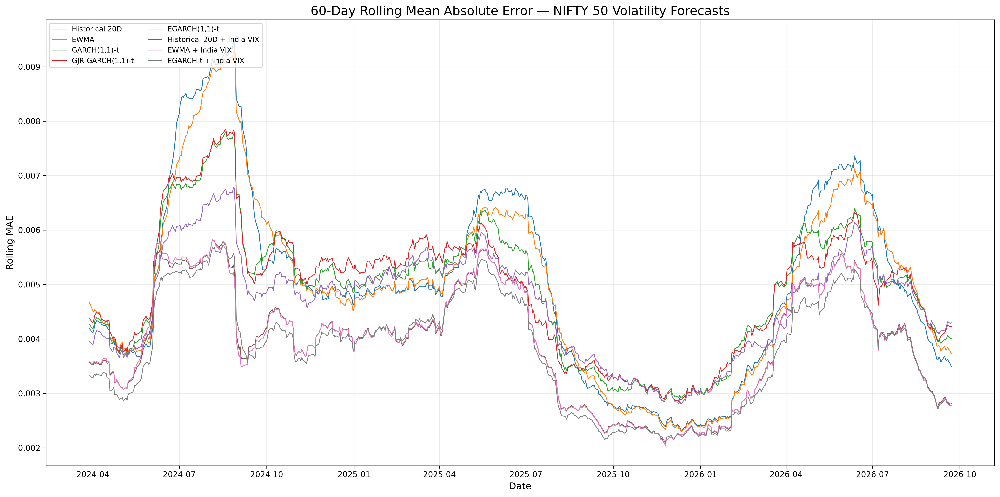


Final 60-day rolling MAE ranking:
EWMA + India VIX              0.002773
Historical 20D + India VIX    0.002783
EGARCH-t + India VIX          0.002809
Historical 20D                0.003496
EWMA                           0.00373
GARCH(1,1)-t                  0.004003
GJR-GARCH(1,1)-t              0.004231
EGARCH(1,1)-t                 0.004294

Saved:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_11_Rolling_Forecast_Accuracy.png


In [368]:
# =============================================================================
# FIGURE 11 — ROLLING FORECAST ACCURACY
# =============================================================================
# Purpose:
# Show how forecast accuracy evolves through the untouched OOS period.
#
# Metric:
# 60-trading-day rolling MAE
#
# Lower MAE = better forecasting performance.
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# -----------------------------------------------------------------------------

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# 2. COPY AUTHORITATIVE INTERACTIVE DATA
# -----------------------------------------------------------------------------

fig11_data = interactive_data.copy()

# -----------------------------------------------------------------------------
# 3. HANDLE DATE STRUCTURE SAFELY
# -----------------------------------------------------------------------------
# interactive_data may store Date either:
#   A) as a normal column, or
#   B) as a DatetimeIndex.
#
# We create a local Date column only inside fig11_data.
# No forecasting object is modified.

if "Date" in fig11_data.columns:

    fig11_data["Date"] = pd.to_datetime(fig11_data["Date"])

else:

    if isinstance(fig11_data.index, pd.DatetimeIndex):

        fig11_data = fig11_data.reset_index()

        # The reset index may be named "Date", "index", or something else.
        if "Date" not in fig11_data.columns:

            datetime_columns = [
                col for col in fig11_data.columns
                if pd.api.types.is_datetime64_any_dtype(
                    fig11_data[col]
                )
            ]

            if len(datetime_columns) == 1:
                fig11_data = fig11_data.rename(
                    columns={datetime_columns[0]: "Date"}
                )

            else:
                raise ValueError(
                    "Could not uniquely identify the date column "
                    "after resetting the DatetimeIndex."
                )

        fig11_data["Date"] = pd.to_datetime(
            fig11_data["Date"]
        )

    else:
        raise ValueError(
            "interactive_data has neither a 'Date' column "
            "nor a DatetimeIndex."
        )

# -----------------------------------------------------------------------------
# 4. REQUIRED FORECAST COLUMNS
# -----------------------------------------------------------------------------

required_columns = [
    "Realized Volatility",
    "Historical 20D",
    "EWMA",
    "GARCH(1,1)-t",
    "GJR-GARCH(1,1)-t",
    "EGARCH(1,1)-t",
    "Historical 20D + India VIX",
    "EWMA + India VIX",
    "EGARCH-t + India VIX"
]

missing_columns = [
    col
    for col in required_columns
    if col not in fig11_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required Figure 11 columns: {missing_columns}"
    )

# -----------------------------------------------------------------------------
# 5. SORT BY DATE
# -----------------------------------------------------------------------------

fig11_data = (
    fig11_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# -----------------------------------------------------------------------------
# 6. OOS INTEGRITY CHECKS
# -----------------------------------------------------------------------------

assert len(fig11_data) == 673, (
    f"Expected 673 OOS observations, found {len(fig11_data)}"
)

assert fig11_data["Date"].min() == pd.Timestamp("2024-01-01"), (
    f"Unexpected first OOS date: {fig11_data['Date'].min()}"
)

assert fig11_data["Date"].max() == pd.Timestamp("2026-09-22"), (
    f"Unexpected last OOS date: {fig11_data['Date'].max()}"
)

assert fig11_data["Date"].duplicated().sum() == 0, (
    "Duplicate OOS dates detected."
)

# -----------------------------------------------------------------------------
# 7. MODEL DEFINITIONS
# -----------------------------------------------------------------------------

model_columns = {
    "Historical 20D": "Historical 20D",
    "EWMA": "EWMA",
    "GARCH(1,1)-t": "GARCH(1,1)-t",
    "GJR-GARCH(1,1)-t": "GJR-GARCH(1,1)-t",
    "EGARCH(1,1)-t": "EGARCH(1,1)-t",
    "Historical 20D + India VIX": "Historical 20D + India VIX",
    "EWMA + India VIX": "EWMA + India VIX",
    "EGARCH-t + India VIX": "EGARCH-t + India VIX"
}

rolling_window = 60

# -----------------------------------------------------------------------------
# 8. MISSING-VALUE CHECK
# -----------------------------------------------------------------------------

forecast_missing = (
    fig11_data[["Realized Volatility"] + list(model_columns.values())]
    .isna()
    .sum()
)

if forecast_missing.sum() != 0:
    raise ValueError(
        "Missing values detected in Figure 11 input data:\n"
        + forecast_missing.to_string()
    )

# -----------------------------------------------------------------------------
# 9. CALCULATE 60-DAY ROLLING MAE
# -----------------------------------------------------------------------------

rolling_mae = pd.DataFrame({
    "Date": fig11_data["Date"]
})

for model_name, forecast_column in model_columns.items():

    absolute_error = (
        fig11_data["Realized Volatility"]
        - fig11_data[forecast_column]
    ).abs()

    rolling_mae[model_name] = (
        absolute_error
        .rolling(
            window=rolling_window,
            min_periods=rolling_window
        )
        .mean()
    )

# -----------------------------------------------------------------------------
# 10. ROLLING-MAE INTEGRITY CHECK
# -----------------------------------------------------------------------------

rolling_model_columns = list(model_columns.keys())

# First 59 observations cannot have a complete 60-day window.
assert (
    rolling_mae[rolling_model_columns]
    .iloc[:rolling_window - 1]
    .isna()
    .all()
    .all()
)

# First complete window must contain values.
assert (
    rolling_mae[rolling_model_columns]
    .iloc[rolling_window - 1]
    .notna()
    .all()
)

# Final observation must contain values.
assert (
    rolling_mae[rolling_model_columns]
    .iloc[-1]
    .notna()
    .all()
)

# -----------------------------------------------------------------------------
# 11. AUDIT OUTPUT
# -----------------------------------------------------------------------------

print("=" * 90)
print("FIGURE 11 — ROLLING FORECAST ACCURACY AUDIT")
print("=" * 90)

print(f"OOS observations       : {len(fig11_data)}")
print(
    f"OOS period             : "
    f"{fig11_data['Date'].min().date()} "
    f"to "
    f"{fig11_data['Date'].max().date()}"
)
print(f"Rolling window         : {rolling_window} trading days")
print(
    f"First rolling MAE date : "
    f"{rolling_mae['Date'].iloc[rolling_window - 1].date()}"
)

print(
    f"Missing forecast inputs: "
    f"{forecast_missing.sum()}"
)

print(
    f"Missing rolling MAEs   : "
    f"{rolling_mae[rolling_model_columns].isna().sum().sum()}"
)

# -----------------------------------------------------------------------------
# 12. PLOT
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, 9),
    dpi=300
)

for model_name in rolling_model_columns:

    ax.plot(
        rolling_mae["Date"],
        rolling_mae[model_name],
        linewidth=1.0,
        label=model_name
    )

ax.set_title(
    "60-Day Rolling Mean Absolute Error — NIFTY 50 Volatility Forecasts",
    fontsize=16
)

ax.set_xlabel(
    "Date",
    fontsize=12
)

ax.set_ylabel(
    "Rolling MAE",
    fontsize=12
)

ax.grid(
    True,
    alpha=0.25
)

ax.legend(
    loc="upper left",
    fontsize=9,
    ncol=2
)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 13. SAVE
# -----------------------------------------------------------------------------

figure11_path = os.path.join(
    FIGURE_DIR,
    "Figure_11_Rolling_Forecast_Accuracy.png"
)

plt.savefig(
    figure11_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# -----------------------------------------------------------------------------
# 14. FINAL 60-DAY ROLLING MAE RANKING
# -----------------------------------------------------------------------------

final_rolling_mae = (
    rolling_mae
    .iloc[-1][rolling_model_columns]
    .sort_values()
)

print("\nFinal 60-day rolling MAE ranking:")
print(final_rolling_mae.to_string())

print("\nSaved:")
print(figure11_path)

FIGURE 12 — INPUT DATA AUDIT
OOS period  : 2024-01-01 to 2026-09-22
Observations: 673

Missing values:
Realized Volatility           0
Historical 20D                0
EWMA                          0
GARCH(1,1)-t                  0
GJR-GARCH(1,1)-t              0
EGARCH(1,1)-t                 0
Historical 20D + India VIX    0
EWMA + India VIX              0
EGARCH-t + India VIX          0

FINAL OOS MODEL PERFORMANCE

MAE ranking — lower is better
----------------------------------------------------------------------------------------------------
 MAE_Rank                      Model      MAE     RMSE
        1       EGARCH-t + India VIX 0.003737 0.005262
        2           EWMA + India VIX 0.003863 0.005637
        3 Historical 20D + India VIX 0.003863 0.005630
        4              EGARCH(1,1)-t 0.004628 0.005796
        5               GARCH(1,1)-t 0.004852 0.006291
        6           GJR-GARCH(1,1)-t 0.004865 0.006349
        7             Historical 20D 0.004923 0.006564
        

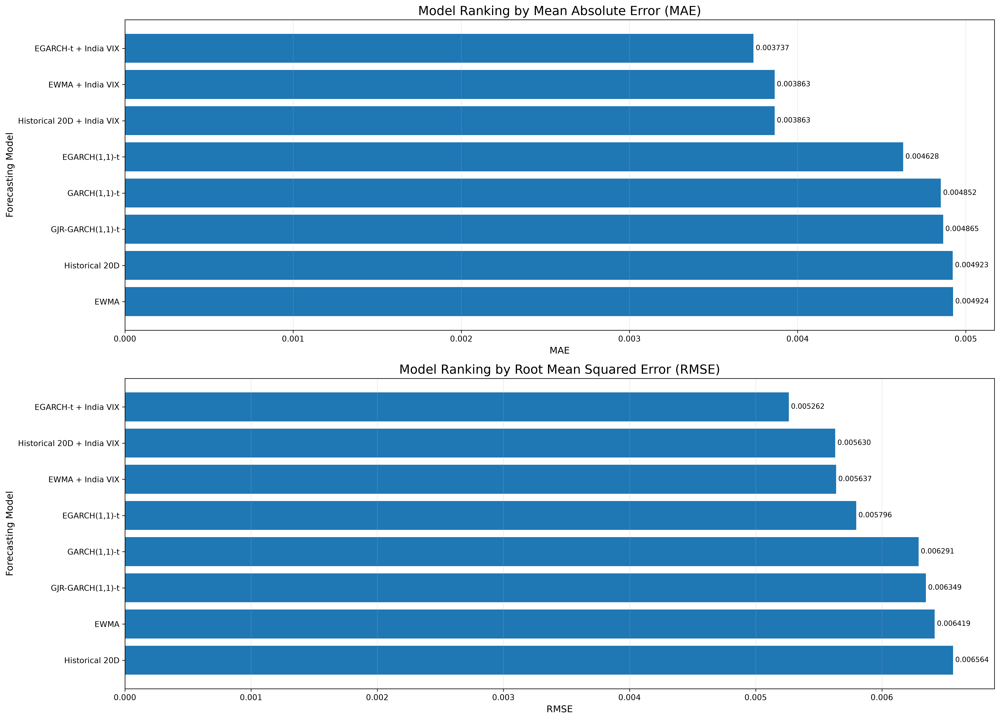


FIGURE 12 SAVED
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_12_Model_Performance_Ranking_MAE_RMSE.png


In [369]:
# =============================================================================
# FIGURE 12 — MODEL PERFORMANCE RANKING (MAE & RMSE)
# =============================================================================
# Purpose:
# Compare all final volatility forecasting models over the complete
# untouched 2024-01-01 to 2026-09-22 OOS period.
#
# Lower MAE / RMSE = better forecasting performance.
#
# IMPORTANT:
# Performance is calculated directly from the current authoritative
# OOS forecasting objects.
#
# No model is refitted.
# No forecast object is modified.
# No historical benchmark values are hard-coded.
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# -----------------------------------------------------------------------------

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# 2. BUILD FIGURE DATA FROM AUTHORITATIVE OBJECTS
# -----------------------------------------------------------------------------

fig12_data = pd.DataFrame(index=test_data_vix_timing.index)

fig12_data["Realized Volatility"] = (
    test_data_vix_timing["Log_Return"].abs()
)

# Strict Historical 20D
fig12_data["Historical 20D"] = (
    historical_20d_strict
    .reindex(fig12_data.index)
)

# EWMA
fig12_data["EWMA"] = (
    test_data_vix_timing["EWMA_OneStep_Forecast"]
)

# GARCH-t
fig12_data["GARCH(1,1)-t"] = (
    test_data_vix_timing["GARCH_T_Volatility"]
)

# GJR-GARCH-t
fig12_data["GJR-GARCH(1,1)-t"] = (
    test_data_vix_timing["GJR_GARCH_T_Volatility"]
)

# EGARCH-t
fig12_data["EGARCH(1,1)-t"] = (
    test_data_vix_timing["EGARCH_T_Volatility"]
)

# Historical 20D + India VIX
fig12_data["Historical 20D + India VIX"] = (
    oos_hist_vix["Historical_20D_VIX_WalkForward"]
    .reindex(fig12_data.index)
)

# EWMA + India VIX
fig12_data["EWMA + India VIX"] = (
    ewma_vix_forecast
    .reindex(fig12_data.index)
)

# EGARCH-t + India VIX
fig12_data["EGARCH-t + India VIX"] = (
    egarch_vix
    .reindex(fig12_data.index)
)

# -----------------------------------------------------------------------------
# 3. DATE COLUMN
# -----------------------------------------------------------------------------

fig12_data = fig12_data.reset_index()

# Whatever the original index name is, standardize it to Date.
if "Date" not in fig12_data.columns:

    datetime_columns = [
        col
        for col in fig12_data.columns
        if pd.api.types.is_datetime64_any_dtype(
            fig12_data[col]
        )
    ]

    if len(datetime_columns) != 1:
        raise ValueError(
            "Could not uniquely identify the OOS date column."
        )

    fig12_data = fig12_data.rename(
        columns={datetime_columns[0]: "Date"}
    )

fig12_data["Date"] = pd.to_datetime(
    fig12_data["Date"]
)

fig12_data = (
    fig12_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# -----------------------------------------------------------------------------
# 4. MODEL LIST
# -----------------------------------------------------------------------------

model_columns = [
    "Historical 20D",
    "EWMA",
    "GARCH(1,1)-t",
    "GJR-GARCH(1,1)-t",
    "EGARCH(1,1)-t",
    "Historical 20D + India VIX",
    "EWMA + India VIX",
    "EGARCH-t + India VIX"
]

# -----------------------------------------------------------------------------
# 5. OOS INTEGRITY CHECK
# -----------------------------------------------------------------------------

assert len(fig12_data) == 673

assert (
    fig12_data["Date"].min()
    == pd.Timestamp("2024-01-01")
)

assert (
    fig12_data["Date"].max()
    == pd.Timestamp("2026-09-22")
)

assert (
    fig12_data["Date"].duplicated().sum()
    == 0
)

# -----------------------------------------------------------------------------
# 6. MISSING-VALUE CHECK
# -----------------------------------------------------------------------------

required_columns = [
    "Realized Volatility"
] + model_columns

missing_values = (
    fig12_data[required_columns]
    .isna()
    .sum()
)

print("=" * 100)
print("FIGURE 12 — INPUT DATA AUDIT")
print("=" * 100)

print(
    f"OOS period  : "
    f"{fig12_data['Date'].min().date()} "
    f"to "
    f"{fig12_data['Date'].max().date()}"
)

print(
    f"Observations: {len(fig12_data)}"
)

print("\nMissing values:")
print(missing_values.to_string())

if missing_values.sum() != 0:
    raise ValueError(
        "Figure 12 cannot be generated because "
        "required OOS values are missing."
    )

# -----------------------------------------------------------------------------
# 7. CALCULATE PERFORMANCE
# -----------------------------------------------------------------------------

performance_rows = []

for model in model_columns:

    error = (
        fig12_data["Realized Volatility"]
        - fig12_data[model]
    )

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(error ** 2)
    )

    performance_rows.append({
        "Model": model,
        "MAE": mae,
        "RMSE": rmse,
        "Observations": len(error)
    })

performance_table = pd.DataFrame(
    performance_rows
)

# -----------------------------------------------------------------------------
# 8. RANKINGS
# -----------------------------------------------------------------------------

performance_table["MAE_Rank"] = (
    performance_table["MAE"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

performance_table["RMSE_Rank"] = (
    performance_table["RMSE"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

mae_ranking = (
    performance_table
    .sort_values(
        ["MAE", "RMSE"]
    )
    .reset_index(drop=True)
)

rmse_ranking = (
    performance_table
    .sort_values(
        ["RMSE", "MAE"]
    )
    .reset_index(drop=True)
)

# -----------------------------------------------------------------------------
# 9. PRINT FINAL PERFORMANCE TABLE
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("FINAL OOS MODEL PERFORMANCE")
print("=" * 100)

print("\nMAE ranking — lower is better")
print("-" * 100)

print(
    mae_ranking[
        [
            "MAE_Rank",
            "Model",
            "MAE",
            "RMSE"
        ]
    ].to_string(
        index=False,
        formatters={
            "MAE": "{:.6f}".format,
            "RMSE": "{:.6f}".format
        }
    )
)

print("\nRMSE ranking — lower is better")
print("-" * 100)

print(
    rmse_ranking[
        [
            "RMSE_Rank",
            "Model",
            "MAE",
            "RMSE"
        ]
    ].to_string(
        index=False,
        formatters={
            "MAE": "{:.6f}".format,
            "RMSE": "{:.6f}".format
        }
    )
)

# -----------------------------------------------------------------------------
# 10. PLOT
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(18, 13),
    dpi=300
)

# -----------------------------------------------------------------------------
# MAE
# -----------------------------------------------------------------------------

mae_plot = mae_ranking.copy()

axes[0].barh(
    mae_plot["Model"],
    mae_plot["MAE"]
)

axes[0].invert_yaxis()

axes[0].set_title(
    "Model Ranking by Mean Absolute Error (MAE)",
    fontsize=16
)

axes[0].set_xlabel(
    "MAE",
    fontsize=12
)

axes[0].set_ylabel(
    "Forecasting Model",
    fontsize=12
)

axes[0].grid(
    axis="x",
    alpha=0.25
)

for i, value in enumerate(
    mae_plot["MAE"]
):

    axes[0].text(
        value,
        i,
        f" {value:.6f}",
        va="center",
        fontsize=9
    )

# -----------------------------------------------------------------------------
# RMSE
# -----------------------------------------------------------------------------

rmse_plot = rmse_ranking.copy()

axes[1].barh(
    rmse_plot["Model"],
    rmse_plot["RMSE"]
)

axes[1].invert_yaxis()

axes[1].set_title(
    "Model Ranking by Root Mean Squared Error (RMSE)",
    fontsize=16
)

axes[1].set_xlabel(
    "RMSE",
    fontsize=12
)

axes[1].set_ylabel(
    "Forecasting Model",
    fontsize=12
)

axes[1].grid(
    axis="x",
    alpha=0.25
)

for i, value in enumerate(
    rmse_plot["RMSE"]
):

    axes[1].text(
        value,
        i,
        f" {value:.6f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()

# -----------------------------------------------------------------------------
# 11. SAVE
# -----------------------------------------------------------------------------

figure12_path = os.path.join(
    FIGURE_DIR,
    "Figure_12_Model_Performance_Ranking_MAE_RMSE.png"
)

plt.savefig(
    figure12_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 100)
print("FIGURE 12 SAVED")
print("=" * 100)

print(figure12_path)

FIGURE 13 — INPUT DATA AUDIT
OOS period  : 2024-01-01 to 2026-09-22
Observations: 673

Missing values:
Realized_Volatility    0
EGARCH_t               0
EGARCH_t_VIX           0

FIGURE 13 — EGARCH PERFORMANCE
               Model      MAE     RMSE
            EGARCH-t 0.004628 0.005796
EGARCH-t + India VIX 0.003737 0.005262

Improvement from adding India VIX:
MAE improvement  : 19.2349%
RMSE improvement : 9.2227%


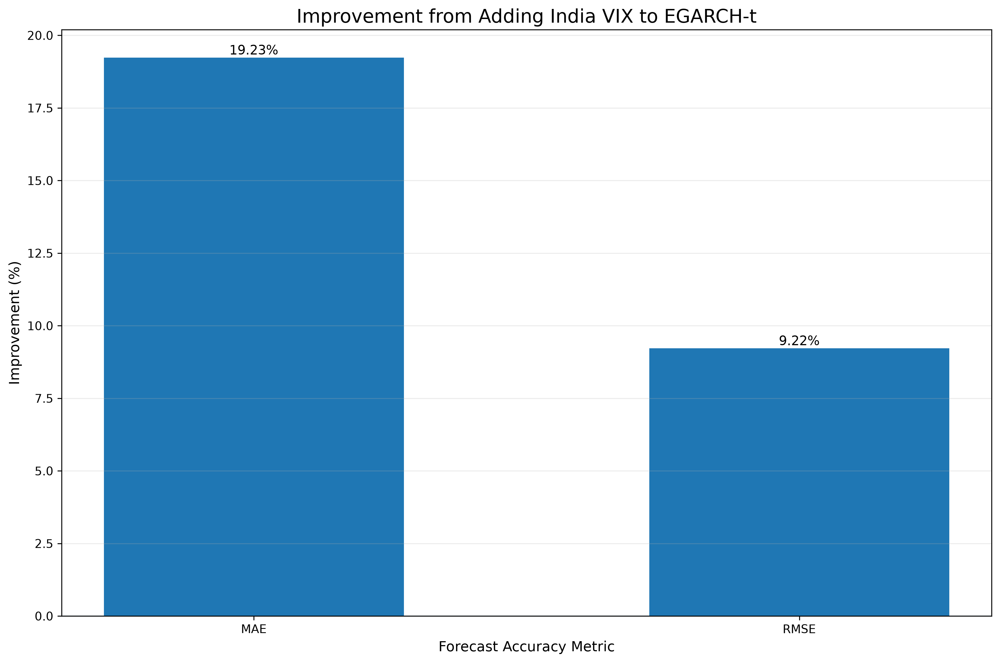


Figure 13 saved:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_13_EGARCH_t_vs_EGARCH_t_VIX_Improvement.png


In [370]:
# =============================================================================
# FIGURE 13 — EGARCH-t VS EGARCH-t + INDIA VIX
# =============================================================================
# Purpose:
# Quantify the improvement obtained by augmenting the EGARCH-t volatility
# forecast with India VIX information over the complete untouched OOS period.
#
# Metrics:
#   1. MAE improvement (%)
#   2. RMSE improvement (%)
#
# Formula:
# Improvement (%) =
#     ((Baseline Error - Enhanced Error) / Baseline Error) * 100
#
# Positive value = India VIX enhanced model performs better.
#
# No model is refitted or modified.
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# -----------------------------------------------------------------------------

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# 2. BUILD DATA FROM AUTHORITATIVE OOS OBJECTS
# -----------------------------------------------------------------------------

fig13_data = pd.DataFrame(
    index=test_data_vix_timing.index
)

fig13_data["Realized_Volatility"] = (
    test_data_vix_timing["Log_Return"].abs()
)

fig13_data["EGARCH_t"] = (
    test_data_vix_timing[
        "EGARCH_T_Volatility"
    ]
)

fig13_data["EGARCH_t_VIX"] = (
    egarch_vix
    .reindex(fig13_data.index)
)

# -----------------------------------------------------------------------------
# 3. DATE HANDLING
# -----------------------------------------------------------------------------

fig13_data = fig13_data.reset_index()

if "Date" not in fig13_data.columns:

    datetime_columns = [
        col
        for col in fig13_data.columns
        if pd.api.types.is_datetime64_any_dtype(
            fig13_data[col]
        )
    ]

    if len(datetime_columns) != 1:
        raise ValueError(
            "Could not uniquely identify the OOS Date column."
        )

    fig13_data = fig13_data.rename(
        columns={
            datetime_columns[0]: "Date"
        }
    )

fig13_data["Date"] = pd.to_datetime(
    fig13_data["Date"]
)

fig13_data = (
    fig13_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# -----------------------------------------------------------------------------
# 4. OOS INTEGRITY CHECK
# -----------------------------------------------------------------------------

assert len(fig13_data) == 673

assert (
    fig13_data["Date"].min()
    == pd.Timestamp("2024-01-01")
)

assert (
    fig13_data["Date"].max()
    == pd.Timestamp("2026-09-22")
)

assert (
    fig13_data["Date"].duplicated().sum()
    == 0
)

# -----------------------------------------------------------------------------
# 5. MISSING-VALUE CHECK
# -----------------------------------------------------------------------------

required_columns = [
    "Realized_Volatility",
    "EGARCH_t",
    "EGARCH_t_VIX"
]

missing_values = (
    fig13_data[required_columns]
    .isna()
    .sum()
)

print("=" * 90)
print("FIGURE 13 — INPUT DATA AUDIT")
print("=" * 90)

print(
    f"OOS period  : "
    f"{fig13_data['Date'].min().date()} "
    f"to "
    f"{fig13_data['Date'].max().date()}"
)

print(
    f"Observations: {len(fig13_data)}"
)

print("\nMissing values:")
print(missing_values.to_string())

if missing_values.sum() != 0:
    raise ValueError(
        "Missing values detected in Figure 13 inputs."
    )

# -----------------------------------------------------------------------------
# 6. CALCULATE FORECAST ERRORS
# -----------------------------------------------------------------------------

egarch_error = (
    fig13_data["Realized_Volatility"]
    - fig13_data["EGARCH_t"]
)

egarch_vix_error = (
    fig13_data["Realized_Volatility"]
    - fig13_data["EGARCH_t_VIX"]
)

# -----------------------------------------------------------------------------
# 7. CALCULATE MAE
# -----------------------------------------------------------------------------

egarch_mae = (
    np.abs(egarch_error)
    .mean()
)

egarch_vix_mae = (
    np.abs(egarch_vix_error)
    .mean()
)

# -----------------------------------------------------------------------------
# 8. CALCULATE RMSE
# -----------------------------------------------------------------------------

egarch_rmse = np.sqrt(
    np.mean(
        egarch_error ** 2
    )
)

egarch_vix_rmse = np.sqrt(
    np.mean(
        egarch_vix_error ** 2
    )
)

# -----------------------------------------------------------------------------
# 9. CALCULATE IMPROVEMENT
# -----------------------------------------------------------------------------

mae_improvement = (
    (egarch_mae - egarch_vix_mae)
    / egarch_mae
) * 100

rmse_improvement = (
    (egarch_rmse - egarch_vix_rmse)
    / egarch_rmse
) * 100

# -----------------------------------------------------------------------------
# 10. PERFORMANCE TABLE
# -----------------------------------------------------------------------------

fig13_performance = pd.DataFrame({
    "Model": [
        "EGARCH-t",
        "EGARCH-t + India VIX"
    ],
    "MAE": [
        egarch_mae,
        egarch_vix_mae
    ],
    "RMSE": [
        egarch_rmse,
        egarch_vix_rmse
    ]
})

print("\n" + "=" * 90)
print("FIGURE 13 — EGARCH PERFORMANCE")
print("=" * 90)

print(
    fig13_performance.to_string(
        index=False,
        formatters={
            "MAE": "{:.6f}".format,
            "RMSE": "{:.6f}".format
        }
    )
)

print("\nImprovement from adding India VIX:")
print(
    f"MAE improvement  : {mae_improvement:.4f}%"
)

print(
    f"RMSE improvement : {rmse_improvement:.4f}%"
)

# -----------------------------------------------------------------------------
# 11. CREATE IMPROVEMENT DATA
# -----------------------------------------------------------------------------

improvement_table = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE"
    ],
    "Improvement_Percent": [
        mae_improvement,
        rmse_improvement
    ]
})

# -----------------------------------------------------------------------------
# 12. PLOT
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 8),
    dpi=300
)

bars = ax.bar(
    improvement_table["Metric"],
    improvement_table["Improvement_Percent"],
    width=0.55
)

ax.axhline(
    0,
    linewidth=0.8
)

ax.set_title(
    "Improvement from Adding India VIX to EGARCH-t",
    fontsize=16
)

ax.set_xlabel(
    "Forecast Accuracy Metric",
    fontsize=12
)

ax.set_ylabel(
    "Improvement (%)",
    fontsize=12
)

ax.grid(
    axis="y",
    alpha=0.25
)

# -----------------------------------------------------------------------------
# 13. VALUE LABELS
# -----------------------------------------------------------------------------

for bar, value in zip(
    bars,
    improvement_table["Improvement_Percent"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=11
    )

plt.tight_layout()

# -----------------------------------------------------------------------------
# 14. SAVE
# -----------------------------------------------------------------------------

figure13_path = os.path.join(
    FIGURE_DIR,
    "Figure_13_EGARCH_t_vs_EGARCH_t_VIX_Improvement.png"
)

plt.savefig(
    figure13_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure 13 saved:")
print(figure13_path)

FIGURE 14 — INPUT DATA AUDIT
OOS period  : 2024-01-01 to 2026-09-22
Observations: 673

Missing values:
Realized_Volatility    0
EGARCH_t               0
EGARCH_t_VIX           0

FIGURE 14 — ROLLING EGARCH + VIX PERFORMANCE
Rolling window              : 60 trading days
Valid rolling windows       : 614
VIX-enhanced model better   : 614 windows
Plain EGARCH better         : 0 windows
Equal performance           : 0 windows
Mean rolling improvement    : 19.5011%
Median rolling improvement  : 19.4773%
Maximum improvement         : 37.1409%
Maximum deterioration       : 4.8341%
Positive-window proportion  : 100.00%


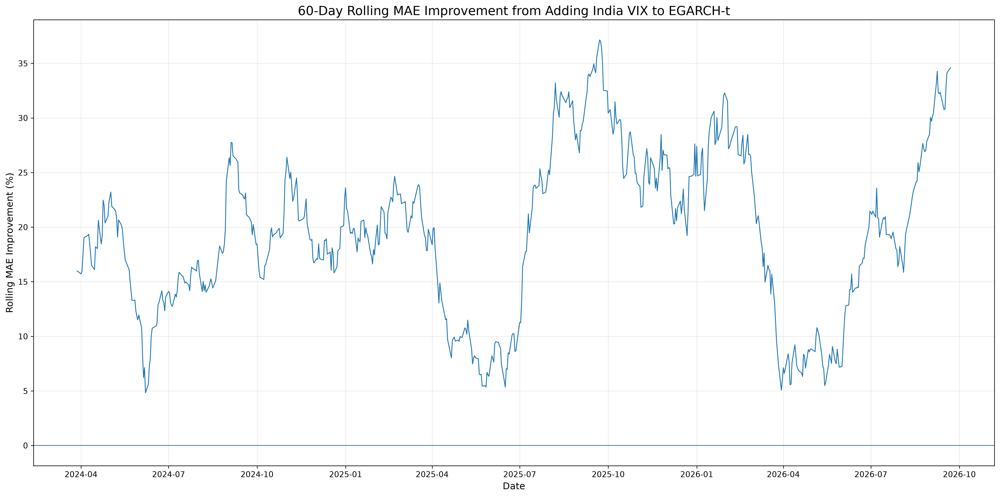


Figure 14 saved:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_14_Rolling_EGARCH_t_VIX_Performance_Improvement.png


In [371]:
# =============================================================================
# FIGURE 14 — ROLLING EGARCH-t VS EGARCH-t + INDIA VIX
# =============================================================================
# Purpose:
# Examine whether the forecasting improvement from India VIX is persistent
# through the OOS period rather than being driven only by the full-sample result.
#
# Metric:
#   60-trading-day rolling MAE difference
#
# Definition:
#   Rolling MAE(EGARCH-t) - Rolling MAE(EGARCH-t + VIX)
#
# Interpretation:
#   Positive  -> EGARCH-t + VIX has lower error -> improvement
#   Negative  -> EGARCH-t has lower error -> VIX enhancement worse
#   Zero      -> equal rolling MAE
#
# No model is refitted or modified.
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# -----------------------------------------------------------------------------

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# 2. BUILD DATA FROM AUTHORITATIVE OOS OBJECTS
# -----------------------------------------------------------------------------

fig14_data = pd.DataFrame(
    index=test_data_vix_timing.index
)

fig14_data["Realized_Volatility"] = (
    test_data_vix_timing["Log_Return"].abs()
)

fig14_data["EGARCH_t"] = (
    test_data_vix_timing[
        "EGARCH_T_Volatility"
    ]
)

fig14_data["EGARCH_t_VIX"] = (
    egarch_vix
    .reindex(fig14_data.index)
)

# -----------------------------------------------------------------------------
# 3. DATE HANDLING
# -----------------------------------------------------------------------------

fig14_data = fig14_data.reset_index()

if "Date" not in fig14_data.columns:

    datetime_columns = [
        col
        for col in fig14_data.columns
        if pd.api.types.is_datetime64_any_dtype(
            fig14_data[col]
        )
    ]

    if len(datetime_columns) != 1:
        raise ValueError(
            "Could not uniquely identify the OOS Date column."
        )

    fig14_data = fig14_data.rename(
        columns={
            datetime_columns[0]: "Date"
        }
    )

fig14_data["Date"] = pd.to_datetime(
    fig14_data["Date"]
)

fig14_data = (
    fig14_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# -----------------------------------------------------------------------------
# 4. OOS INTEGRITY CHECK
# -----------------------------------------------------------------------------

assert len(fig14_data) == 673

assert (
    fig14_data["Date"].min()
    == pd.Timestamp("2024-01-01")
)

assert (
    fig14_data["Date"].max()
    == pd.Timestamp("2026-09-22")
)

assert (
    fig14_data["Date"].duplicated().sum()
    == 0
)

# -----------------------------------------------------------------------------
# 5. MISSING-VALUE CHECK
# -----------------------------------------------------------------------------

required_columns = [
    "Realized_Volatility",
    "EGARCH_t",
    "EGARCH_t_VIX"
]

missing_values = (
    fig14_data[required_columns]
    .isna()
    .sum()
)

print("=" * 90)
print("FIGURE 14 — INPUT DATA AUDIT")
print("=" * 90)

print(
    f"OOS period  : "
    f"{fig14_data['Date'].min().date()} "
    f"to "
    f"{fig14_data['Date'].max().date()}"
)

print(
    f"Observations: {len(fig14_data)}"
)

print("\nMissing values:")
print(missing_values.to_string())

if missing_values.sum() != 0:
    raise ValueError(
        "Missing values detected in Figure 14 inputs."
    )

# -----------------------------------------------------------------------------
# 6. CALCULATE DAILY ABSOLUTE ERRORS
# -----------------------------------------------------------------------------

fig14_data["EGARCH_Absolute_Error"] = (
    fig14_data["Realized_Volatility"]
    - fig14_data["EGARCH_t"]
).abs()

fig14_data["EGARCH_VIX_Absolute_Error"] = (
    fig14_data["Realized_Volatility"]
    - fig14_data["EGARCH_t_VIX"]
).abs()

# -----------------------------------------------------------------------------
# 7. CALCULATE 60-DAY ROLLING MAE
# -----------------------------------------------------------------------------

rolling_window = 60

fig14_data["Rolling_MAE_EGARCH"] = (
    fig14_data["EGARCH_Absolute_Error"]
    .rolling(
        window=rolling_window,
        min_periods=rolling_window
    )
    .mean()
)

fig14_data["Rolling_MAE_EGARCH_VIX"] = (
    fig14_data["EGARCH_VIX_Absolute_Error"]
    .rolling(
        window=rolling_window,
        min_periods=rolling_window
    )
    .mean()
)

# -----------------------------------------------------------------------------
# 8. CALCULATE ROLLING IMPROVEMENT
# -----------------------------------------------------------------------------
# Positive = VIX-enhanced model is better.

fig14_data["Rolling_MAE_Improvement"] = (
    fig14_data["Rolling_MAE_EGARCH"]
    - fig14_data["Rolling_MAE_EGARCH_VIX"]
)

# Percentage improvement relative to plain EGARCH.

fig14_data["Rolling_MAE_Improvement_Percent"] = (
    fig14_data["Rolling_MAE_Improvement"]
    / fig14_data["Rolling_MAE_EGARCH"]
) * 100

# -----------------------------------------------------------------------------
# 9. ROLLING-WINDOW INTEGRITY
# -----------------------------------------------------------------------------

assert (
    fig14_data[
        "Rolling_MAE_Improvement"
    ]
    .iloc[:rolling_window - 1]
    .isna()
    .all()
)

assert (
    fig14_data[
        "Rolling_MAE_Improvement"
    ]
    .iloc[rolling_window - 1:]
    .notna()
    .all()
)

# -----------------------------------------------------------------------------
# 10. SUMMARY STATISTICS
# -----------------------------------------------------------------------------

valid_improvement = (
    fig14_data[
        "Rolling_MAE_Improvement_Percent"
    ]
    .dropna()
)

positive_windows = (
    valid_improvement > 0
).sum()

negative_windows = (
    valid_improvement < 0
).sum()

zero_windows = (
    valid_improvement == 0
).sum()

print("\n" + "=" * 90)
print("FIGURE 14 — ROLLING EGARCH + VIX PERFORMANCE")
print("=" * 90)

print(
    f"Rolling window              : "
    f"{rolling_window} trading days"
)

print(
    f"Valid rolling windows       : "
    f"{len(valid_improvement)}"
)

print(
    f"VIX-enhanced model better   : "
    f"{positive_windows} windows"
)

print(
    f"Plain EGARCH better         : "
    f"{negative_windows} windows"
)

print(
    f"Equal performance           : "
    f"{zero_windows} windows"
)

print(
    f"Mean rolling improvement    : "
    f"{valid_improvement.mean():.4f}%"
)

print(
    f"Median rolling improvement  : "
    f"{valid_improvement.median():.4f}%"
)

print(
    f"Maximum improvement         : "
    f"{valid_improvement.max():.4f}%"
)

print(
    f"Maximum deterioration       : "
    f"{valid_improvement.min():.4f}%"
)

print(
    f"Positive-window proportion  : "
    f"{(positive_windows / len(valid_improvement)) * 100:.2f}%"
)

# -----------------------------------------------------------------------------
# 11. PLOT — ROLLING MAE IMPROVEMENT (%)
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, 9),
    dpi=300
)

ax.plot(
    fig14_data["Date"],
    fig14_data["Rolling_MAE_Improvement_Percent"],
    linewidth=1.1
)

ax.axhline(
    0,
    linewidth=0.9
)

ax.set_title(
    "60-Day Rolling MAE Improvement from Adding India VIX to EGARCH-t",
    fontsize=16
)

ax.set_xlabel(
    "Date",
    fontsize=12
)

ax.set_ylabel(
    "Rolling MAE Improvement (%)",
    fontsize=12
)

ax.grid(
    True,
    alpha=0.25
)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 12. SAVE
# -----------------------------------------------------------------------------

figure14_path = os.path.join(
    FIGURE_DIR,
    "Figure_14_Rolling_EGARCH_t_VIX_Performance_Improvement.png"
)

plt.savefig(
    figure14_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure 14 saved:")
print(figure14_path)

FIGURE 15 — INPUT DATA AUDIT
OOS period  : 2024-01-01 to 2026-09-22
Observations: 673

Missing values:
Realized_Volatility          0
Historical_20D_Volatility    0

FIGURE 15 — PRE-OOS REGIME THRESHOLDS
Pre-OOS observations used : 1457
25th percentile           : 0.006191
50th percentile           : 0.007958
75th percentile           : 0.010906

OOS regime distribution:
                   Observations  Percentage
Volatility_Regime                          
Low                         214       31.80
Normal                      201       29.87
High                        164       24.37
Extreme                      94       13.97

Number of regime transitions: 79


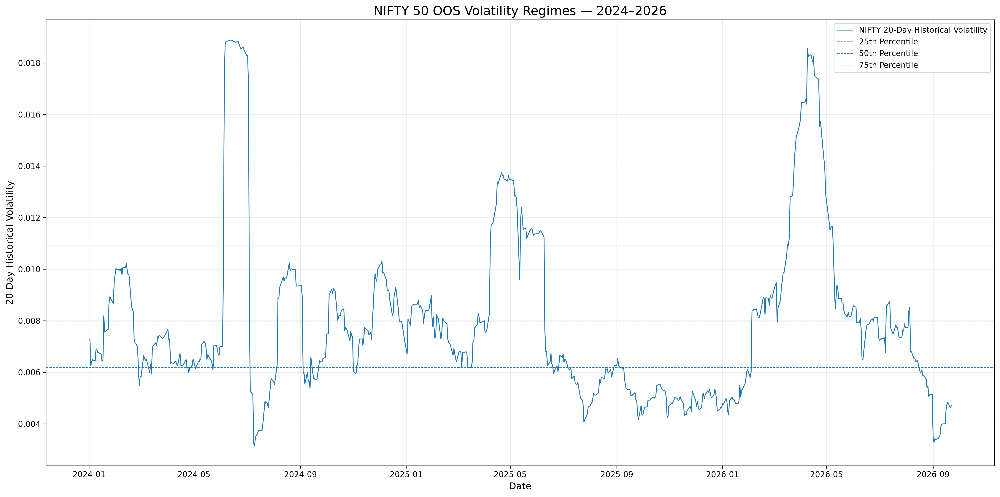


Figure 15 saved:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_15_OOS_Volatility_Regimes.png
Regime classification data saved:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\files\research\figures\Figure_15_OOS_Volatility_Regime_Data.csv


In [372]:
# =============================================================================
# FIGURE 15 — OOS VOLATILITY REGIMES
# =============================================================================
# Purpose:
# Identify and visualize volatility regimes during the untouched 2024–2026
# NIFTY OOS period.
#
# Regime classification is based on realized historical volatility and does
# NOT use any forecasting model.
#
# Thresholds are estimated ONLY from the pre-OOS period (2018–2023) to avoid
# using future OOS information when defining the regimes.
#
# Regimes:
#   Low      : <= 25th percentile
#   Normal   : >25th and <=50th percentile
#   High     : >50th and <=75th percentile
#   Extreme  : >75th percentile
#
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# -----------------------------------------------------------------------------

FIGURE_DIR = os.path.join(
    PROJECT_ROOT,
    "output",
    "files",
    "research",
    "figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# 2. PRE-OOS REALIZED VOLATILITY
# -----------------------------------------------------------------------------
# Use NIFTY Log_Return only.
# 20-day rolling volatility is calculated from information available through
# each historical date.

nifty_regime_source = clean_nifty.copy()

nifty_regime_source["Date"] = pd.to_datetime(
    nifty_regime_source["Date"]
)

nifty_regime_source = (
    nifty_regime_source
    .sort_values("Date")
    .reset_index(drop=True)
)

nifty_regime_source["Realized_Historical_Volatility_20D"] = (
    nifty_regime_source["Log_Return"]
    .rolling(20)
    .std()
)

# -----------------------------------------------------------------------------
# 3. PRE-OOS THRESHOLD SAMPLE
# -----------------------------------------------------------------------------
# IMPORTANT:
# Thresholds are calculated only from observations before 2024-01-01.

pre_oos_regime = (
    nifty_regime_source[
        nifty_regime_source["Date"]
        < pd.Timestamp("2024-01-01")
    ]
    ["Realized_Historical_Volatility_20D"]
    .dropna()
)

if len(pre_oos_regime) == 0:
    raise ValueError(
        "No valid pre-OOS volatility observations available."
    )

q25 = pre_oos_regime.quantile(0.25)
q50 = pre_oos_regime.quantile(0.50)
q75 = pre_oos_regime.quantile(0.75)

# -----------------------------------------------------------------------------
# 4. AUTHORITATIVE OOS SAMPLE
# -----------------------------------------------------------------------------

fig15_data = pd.DataFrame({
    "Date": pd.to_datetime(
        test_data_vix_timing.index
    ),
    "Realized_Volatility": (
        test_data_vix_timing["Log_Return"]
        .abs()
        .to_numpy()
    )
})

# Strict 20-day historical volatility for OOS.
# This object was already validated for information-set timing.

historical_20d_oos = (
    historical_20d_strict
    .reindex(test_data_vix_timing.index)
    .to_numpy()
)

fig15_data["Historical_20D_Volatility"] = (
    historical_20d_oos
)

# -----------------------------------------------------------------------------
# 5. OOS INTEGRITY CHECK
# -----------------------------------------------------------------------------

assert len(fig15_data) == 673

assert (
    fig15_data["Date"].min()
    == pd.Timestamp("2024-01-01")
)

assert (
    fig15_data["Date"].max()
    == pd.Timestamp("2026-09-22")
)

assert (
    fig15_data["Date"].duplicated().sum()
    == 0
)

required_columns = [
    "Realized_Volatility",
    "Historical_20D_Volatility"
]

missing_values = (
    fig15_data[required_columns]
    .isna()
    .sum()
)

print("=" * 90)
print("FIGURE 15 — INPUT DATA AUDIT")
print("=" * 90)

print(
    f"OOS period  : "
    f"{fig15_data['Date'].min().date()} "
    f"to "
    f"{fig15_data['Date'].max().date()}"
)

print(
    f"Observations: {len(fig15_data)}"
)

print("\nMissing values:")
print(missing_values.to_string())

if missing_values.sum() != 0:
    raise ValueError(
        "Missing values detected in Figure 15 inputs."
    )

# -----------------------------------------------------------------------------
# 6. CLASSIFY OOS VOLATILITY REGIMES
# -----------------------------------------------------------------------------

fig15_data["Volatility_Regime"] = pd.cut(
    fig15_data["Historical_20D_Volatility"],
    bins=[
        -np.inf,
        q25,
        q50,
        q75,
        np.inf
    ],
    labels=[
        "Low",
        "Normal",
        "High",
        "Extreme"
    ],
    include_lowest=True
)

# -----------------------------------------------------------------------------
# 7. REGIME AUDIT
# -----------------------------------------------------------------------------

regime_counts = (
    fig15_data["Volatility_Regime"]
    .value_counts()
    .reindex(
        ["Low", "Normal", "High", "Extreme"],
        fill_value=0
    )
)

regime_percentages = (
    regime_counts
    / len(fig15_data)
    * 100
)

print("\n" + "=" * 90)
print("FIGURE 15 — PRE-OOS REGIME THRESHOLDS")
print("=" * 90)

print(
    f"Pre-OOS observations used : "
    f"{len(pre_oos_regime)}"
)

print(
    f"25th percentile           : "
    f"{q25:.6f}"
)

print(
    f"50th percentile           : "
    f"{q50:.6f}"
)

print(
    f"75th percentile           : "
    f"{q75:.6f}"
)

print("\nOOS regime distribution:")

regime_audit = pd.DataFrame({
    "Observations": regime_counts,
    "Percentage": regime_percentages.round(2)
})

print(
    regime_audit.to_string()
)

# -----------------------------------------------------------------------------
# 8. REGIME TRANSITION COUNT
# -----------------------------------------------------------------------------

fig15_data["Regime_Changed"] = (
    fig15_data["Volatility_Regime"]
    != fig15_data["Volatility_Regime"].shift(1)
)

regime_transitions = (
    fig15_data["Regime_Changed"]
    .iloc[1:]
    .sum()
)

print(
    f"\nNumber of regime transitions: "
    f"{regime_transitions}"
)

# -----------------------------------------------------------------------------
# 9. PLOT
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, 9),
    dpi=300
)

ax.plot(
    fig15_data["Date"],
    fig15_data["Historical_20D_Volatility"],
    linewidth=1.1,
    label="NIFTY 20-Day Historical Volatility"
)

# Threshold lines

ax.axhline(
    q25,
    linewidth=0.8,
    linestyle="--",
    label="25th Percentile"
)

ax.axhline(
    q50,
    linewidth=0.8,
    linestyle="--",
    label="50th Percentile"
)

ax.axhline(
    q75,
    linewidth=0.8,
    linestyle="--",
    label="75th Percentile"
)

ax.set_title(
    "NIFTY 50 OOS Volatility Regimes — 2024–2026",
    fontsize=16
)

ax.set_xlabel(
    "Date",
    fontsize=12
)

ax.set_ylabel(
    "20-Day Historical Volatility",
    fontsize=12
)

ax.legend(
    loc="upper right"
)

ax.grid(
    True,
    alpha=0.25
)

plt.tight_layout()

# -----------------------------------------------------------------------------
# 10. SAVE
# -----------------------------------------------------------------------------

figure15_path = os.path.join(
    FIGURE_DIR,
    "Figure_15_OOS_Volatility_Regimes.png"
)

plt.savefig(
    figure15_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure 15 saved:")
print(figure15_path)

# -----------------------------------------------------------------------------
# 11. OPTIONAL: SAVE REGIME DATA FOR RESEARCH USE
# -----------------------------------------------------------------------------
# This does not alter any forecasting object.

fig15_regime_output = fig15_data.copy()

fig15_regime_output.to_csv(
    os.path.join(
        FIGURE_DIR,
        "Figure_15_OOS_Volatility_Regime_Data.csv"
    ),
    index=False
)

print(
    "Regime classification data saved:"
)

print(
    os.path.join(
        FIGURE_DIR,
        "Figure_15_OOS_Volatility_Regime_Data.csv"
    )
)

# FINAL AUTHORITATIVE RESEARCH OUTPUT EXPORT

This section creates the frozen, validated output contract between the
research layer and all downstream business analytics.

Downstream notebooks must consume these saved outputs rather than relying
on in-memory variables from this research notebook.

This section does not modify any research calculation.

In [373]:
# ============================================================
# FINAL AUTHORITATIVE RESEARCH OUTPUT EXPORT
# ============================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path

RESEARCH_OUTPUT_VERSION = "v1"

AUTHORITATIVE_OUTPUT_DIR = (
    Path(PROJECT_ROOT)
    / "data"
    / "research_outputs"
    / RESEARCH_OUTPUT_VERSION
)

AUTHORITATIVE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 80)
print("FINAL AUTHORITATIVE RESEARCH OUTPUT EXPORT")
print("=" * 80)
print("Output directory:")
print(AUTHORITATIVE_OUTPUT_DIR)

FINAL AUTHORITATIVE RESEARCH OUTPUT EXPORT
Output directory:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\research_outputs\v1


In [374]:
# ============================================================
# CONSTRUCT CANONICAL OOS FORECAST DATASET
# ============================================================

# ------------------------------------------------------------
# Base OOS data
# ------------------------------------------------------------

if not isinstance(test_data_vix_timing, pd.DataFrame):
    raise TypeError(
        "test_data_vix_timing must be a pandas DataFrame."
    )

biz_export_base = test_data_vix_timing.copy()

biz_export_base.index = pd.to_datetime(
    biz_export_base.index
)

biz_export_base = biz_export_base.sort_index()


# ------------------------------------------------------------
# Identify pre-return India VIX column
# ------------------------------------------------------------

if "India_VIX_PreReturn" in biz_export_base.columns:

    vix_column = "India_VIX_PreReturn"

elif "India_VIX_Lag1" in biz_export_base.columns:

    vix_column = "India_VIX_Lag1"

else:

    raise KeyError(
        "Could not identify the authoritative pre-return India VIX column."
    )


# ------------------------------------------------------------
# Required base return column
# ------------------------------------------------------------

if "Log_Return" not in biz_export_base.columns:
    raise KeyError(
        "Authoritative OOS dataset does not contain Log_Return."
    )


# ------------------------------------------------------------
# Construct canonical dataset
# ------------------------------------------------------------

oos_authoritative = pd.DataFrame(
    index=biz_export_base.index
)

oos_authoritative["NIFTY_Log_Return"] = (
    biz_export_base["Log_Return"]
)

oos_authoritative["Actual_Volatility"] = (
    biz_export_base["Log_Return"].abs()
)

oos_authoritative["India_VIX_PreReturn"] = (
    biz_export_base[vix_column]
)


# ------------------------------------------------------------
# Helper for authoritative forecast series
# ------------------------------------------------------------

def _authoritative_series(obj, name):
    """
    Convert an authoritative Series/DataFrame object into
    a clean Series aligned to the OOS index.
    """

    if isinstance(obj, pd.DataFrame):

        if obj.shape[1] != 1:
            raise ValueError(
                f"{name} DataFrame contains {obj.shape[1]} columns. "
                "Expected exactly one authoritative forecast column."
            )

        obj = obj.iloc[:, 0]

    if not isinstance(obj, pd.Series):
        raise TypeError(
            f"{name} must be a pandas Series or one-column DataFrame."
        )

    result = obj.copy()
    result.index = pd.to_datetime(result.index)

    return result.reindex(oos_authoritative.index)


# ------------------------------------------------------------
# Authoritative forecast sources
# ------------------------------------------------------------

forecast_sources = {

    "Historical_20D":
        historical_20d_strict,

    "EWMA":
        biz_export_base["EWMA_OneStep_Forecast"],

    "GARCH_t":
        biz_export_base["GARCH_T_Volatility"],

    "GJR_GARCH_t":
        biz_export_base["GJR_GARCH_T_Volatility"],

    "EGARCH_t":
        biz_export_base["EGARCH_T_Volatility"],

    "Historical_20D_VIX":
        oos_hist_vix[
            "Historical_20D_VIX_WalkForward"
        ],

    "EWMA_VIX":
        ewma_vix_forecast,

    "EGARCH_t_VIX":
        egarch_vix,
}


# ------------------------------------------------------------
# Add forecasts
# ------------------------------------------------------------

for forecast_name, forecast_source in forecast_sources.items():

    oos_authoritative[forecast_name] = (
        _authoritative_series(
            forecast_source,
            forecast_name
        )
    )


# ------------------------------------------------------------
# Convert index to explicit Date column
# ------------------------------------------------------------

oos_authoritative = (
    oos_authoritative
    .reset_index()
    .rename(columns={"index": "Date"})
)

oos_authoritative["Date"] = pd.to_datetime(
    oos_authoritative["Date"]
)

oos_authoritative = (
    oos_authoritative
    .sort_values("Date")
    .reset_index(drop=True)
)


display(oos_authoritative.head())
print()
print("Shape:", oos_authoritative.shape)
print(
    "Date range:",
    oos_authoritative["Date"].min(),
    "to",
    oos_authoritative["Date"].max()
)

,Date,NIFTY_Log_Return,Actual_Volatility,India_VIX_PreReturn,Historical_20D,EWMA,GARCH_t,GJR_GARCH_t,EGARCH_t,Historical_20D_VIX,EWMA_VIX,EGARCH_t_VIX
0,2024-01-01,0.000483,0.000483,14.50,0.007280,0.011568,0.007547,0.006755,0.005899,0.005299,0.004533,0.004508
1,2024-01-02,-0.003506,0.003506,14.50,0.007284,0.011216,0.006990,0.006427,0.006179,0.005292,0.004597,0.004651
2,2024-01-03,-0.006875,0.006875,14.58,0.006246,0.010908,0.006801,0.006577,0.006909,0.005408,0.004719,0.005065
3,2024-01-04,0.006543,0.006543,14.10,0.006411,0.010709,0.007200,0.007510,0.006681,0.005085,0.004408,0.004787
4,2024-01-05,0.002407,0.002407,13.33,0.006488,0.010506,0.007104,0.007052,0.006374,0.004576,0.003881,0.004372



Shape: (673, 12)
Date range: 2024-01-01 00:00:00 to 2026-09-22 00:00:00


In [375]:
# ============================================================
# AUTHORITATIVE DATA CONTRACT VALIDATION
# ============================================================

EXPECTED_COLUMNS = [
    "Date",
    "NIFTY_Log_Return",
    "Actual_Volatility",
    "India_VIX_PreReturn",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
    "Historical_20D_VIX",
    "EWMA_VIX",
    "EGARCH_t_VIX",
]

EXPECTED_N = 673
EXPECTED_START = pd.Timestamp("2024-01-01")
EXPECTED_END = pd.Timestamp("2026-09-22")


# ------------------------------------------------------------
# Column validation
# ------------------------------------------------------------

missing_columns = [
    col
    for col in EXPECTED_COLUMNS
    if col not in oos_authoritative.columns
]

if missing_columns:
    raise ValueError(
        f"Missing authoritative columns: {missing_columns}"
    )


# ------------------------------------------------------------
# Observation count
# ------------------------------------------------------------

if len(oos_authoritative) != EXPECTED_N:
    raise ValueError(
        f"Expected {EXPECTED_N} observations, "
        f"found {len(oos_authoritative)}."
    )


# ------------------------------------------------------------
# Date validation
# ------------------------------------------------------------

if oos_authoritative["Date"].min() != EXPECTED_START:
    raise ValueError(
        "Unexpected OOS start date."
    )

if oos_authoritative["Date"].max() != EXPECTED_END:
    raise ValueError(
        "Unexpected OOS end date."
    )


# ------------------------------------------------------------
# Duplicate-date validation
# ------------------------------------------------------------

duplicate_dates = (
    oos_authoritative["Date"]
    .duplicated()
    .sum()
)

if duplicate_dates != 0:
    raise ValueError(
        f"Duplicate OOS dates detected: {duplicate_dates}"
    )


# ------------------------------------------------------------
# Missing-value validation
# ------------------------------------------------------------

missing_counts = (
    oos_authoritative[EXPECTED_COLUMNS]
    .isna()
    .sum()
)

if missing_counts.sum() != 0:

    raise ValueError(
        "Missing values detected:\n"
        + missing_counts[
            missing_counts > 0
        ].to_string()
    )


# ------------------------------------------------------------
# Infinite-value validation
# ------------------------------------------------------------

numeric_columns = [
    col
    for col in EXPECTED_COLUMNS
    if col != "Date"
]

if not np.isfinite(
    oos_authoritative[numeric_columns].to_numpy()
).all():

    raise ValueError(
        "Infinite or non-finite values detected."
    )


# ------------------------------------------------------------
# Chronological validation
# ------------------------------------------------------------

if not oos_authoritative["Date"].is_monotonic_increasing:

    raise ValueError(
        "OOS dates are not chronologically ordered."
    )


print("=" * 80)
print("AUTHORITATIVE DATA CONTRACT: PASSED")
print("=" * 80)
print("Observations :", len(oos_authoritative))
print("First date   :", oos_authoritative["Date"].min().date())
print("Last date    :", oos_authoritative["Date"].max().date())
print("Missing      :", oos_authoritative[EXPECTED_COLUMNS].isna().sum().sum())
print("Duplicates   :", duplicate_dates)
print("Non-finite   :", 0)
print("Status       : VALID")

AUTHORITATIVE DATA CONTRACT: PASSED
Observations : 673
First date   : 2024-01-01
Last date    : 2026-09-22
Missing      : 0
Duplicates   : 0
Non-finite   : 0
Status       : VALID


In [376]:
# ============================================================
# AUTHORITATIVE OOS MODEL PERFORMANCE
# ============================================================

MODEL_COLUMNS = [
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
    "Historical_20D_VIX",
    "EWMA_VIX",
    "EGARCH_t_VIX",
]

performance_rows = []

actual = oos_authoritative["Actual_Volatility"]

for model_name in MODEL_COLUMNS:

    forecast = oos_authoritative[model_name]

    mae = np.mean(
        np.abs(actual - forecast)
    )

    rmse = np.sqrt(
        np.mean(
            (actual - forecast) ** 2
        )
    )

    performance_rows.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "N": len(oos_authoritative),
        "OOS_Start": oos_authoritative["Date"].min(),
        "OOS_End": oos_authoritative["Date"].max(),
    })


authoritative_model_performance = pd.DataFrame(
    performance_rows
)

display(authoritative_model_performance)

,Model,MAE,RMSE,N,OOS_Start,OOS_End
0,Historical_20D,0.004923,0.006564,673,2024-01-01,2026-09-22
1,EWMA,0.004924,0.006419,673,2024-01-01,2026-09-22
2,GARCH_t,0.004852,0.006291,673,2024-01-01,2026-09-22
3,GJR_GARCH_t,0.004865,0.006349,673,2024-01-01,2026-09-22
4,EGARCH_t,0.004628,0.005796,673,2024-01-01,2026-09-22
5,Historical_20D_VIX,0.003863,0.005630,673,2024-01-01,2026-09-22
6,EWMA_VIX,0.003863,0.005637,673,2024-01-01,2026-09-22
7,EGARCH_t_VIX,0.003737,0.005262,673,2024-01-01,2026-09-22


In [377]:
# ============================================================
# WRITE AUTHORITATIVE OUTPUT FILES
# ============================================================

OOS_FILE = (
    AUTHORITATIVE_OUTPUT_DIR
    / "oos_forecasts.csv"
)

PERFORMANCE_FILE = (
    AUTHORITATIVE_OUTPUT_DIR
    / "model_performance.csv"
)

METADATA_FILE = (
    AUTHORITATIVE_OUTPUT_DIR
    / "research_metadata.json"
)


# ------------------------------------------------------------
# CSV exports
# ------------------------------------------------------------

oos_authoritative.to_csv(
    OOS_FILE,
    index=False
)

authoritative_model_performance.to_csv(
    PERFORMANCE_FILE,
    index=False
)


# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

metadata = {

    "research_version":
        RESEARCH_OUTPUT_VERSION,

    "project":
        "Adaptive Market Risk Intelligence System",

    "asset":
        "NIFTY 50",

    "forecast_target":
        "Next-day volatility",

    "oos_start":
        str(EXPECTED_START.date()),

    "oos_end":
        str(EXPECTED_END.date()),

    "observations":
        int(len(oos_authoritative)),

    "information_set":
        "Strict pre-return information set",

    "india_vix_column":
        vix_column,

    "models": MODEL_COLUMNS,

    "authoritative_sources": {

        "Historical_20D":
            "historical_20d_strict",

        "EWMA":
            "test_data_vix_timing['EWMA_OneStep_Forecast']",

        "GARCH_t":
            "test_data_vix_timing['GARCH_T_Volatility']",

        "GJR_GARCH_t":
            "test_data_vix_timing['GJR_GARCH_T_Volatility']",

        "EGARCH_t":
            "test_data_vix_timing['EGARCH_T_Volatility']",

        "Historical_20D_VIX":
            "oos_hist_vix['Historical_20D_VIX_WalkForward']",

        "EWMA_VIX":
            "ewma_vix_forecast",

        "EGARCH_t_VIX":
            "egarch_vix",
    },

    "validation": {

        "missing_values": 0,

        "duplicate_dates": 0,

        "non_finite_values": 0,

        "chronological_order": True,

        "data_contract": "PASSED",
    },

    "downstream_rule":
        "Downstream notebooks must consume the saved authoritative outputs rather than relying on research-notebook in-memory variables.",
}


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )


print("=" * 80)
print("AUTHORITATIVE OUTPUTS WRITTEN")
print("=" * 80)

print("OOS forecasts:")
print(OOS_FILE)

print("\nModel performance:")
print(PERFORMANCE_FILE)

print("\nMetadata:")
print(METADATA_FILE)

AUTHORITATIVE OUTPUTS WRITTEN
OOS forecasts:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\research_outputs\v1\oos_forecasts.csv

Model performance:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\research_outputs\v1\model_performance.csv

Metadata:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\research_outputs\v1\research_metadata.json


In [378]:
# ============================================================
# OUTPUT CHECKSUM / MANIFEST
# ============================================================

def sha256_file(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):

            sha256.update(block)

    return sha256.hexdigest()


manifest = {

    "research_version":
        RESEARCH_OUTPUT_VERSION,

    "oos_forecasts.csv":
        sha256_file(OOS_FILE),

    "model_performance.csv":
        sha256_file(PERFORMANCE_FILE),

    "research_metadata.json":
        sha256_file(METADATA_FILE),
}


MANIFEST_FILE = (
    AUTHORITATIVE_OUTPUT_DIR
    / "output_manifest.json"
)


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=4
    )


print("=" * 80)
print("OUTPUT MANIFEST CREATED")
print("=" * 80)

for filename, checksum in manifest.items():

    print(f"{filename}")
    print(f"SHA256: {checksum}")
    print()

OUTPUT MANIFEST CREATED
research_version
SHA256: v1

oos_forecasts.csv
SHA256: 9b2a0e97aa72da82d3455c64dcd46c0ecbe6458af02a08f055f2810f03b59ee3

model_performance.csv
SHA256: 5d0f35125c9b3ffa667b054fb0b87783bf71ca76417826d3175c7ced516400dc

research_metadata.json
SHA256: 528652b013817342a3f906f5c9627e4c2ad2cbbda0d9aa778088a27a039dc717



In [379]:
# ============================================================
# INDEPENDENT RECOVERY TEST
# ============================================================

print("=" * 80)
print("INDEPENDENT RECOVERY TEST")
print("=" * 80)


recovered_oos = pd.read_csv(
    OOS_FILE,
    parse_dates=["Date"]
)

recovered_performance = pd.read_csv(
    PERFORMANCE_FILE,
    parse_dates=[
        "OOS_Start",
        "OOS_End"
    ]
)


# ------------------------------------------------------------
# Recovery validation
# ------------------------------------------------------------

assert len(recovered_oos) == EXPECTED_N

assert recovered_oos["Date"].min() == EXPECTED_START

assert recovered_oos["Date"].max() == EXPECTED_END

assert recovered_oos["Date"].duplicated().sum() == 0

assert (
    recovered_oos[EXPECTED_COLUMNS]
    .isna()
    .sum()
    .sum()
    == 0
)


print("Recovered observations :", len(recovered_oos))
print(
    "Recovered date range   :",
    recovered_oos["Date"].min().date(),
    "to",
    recovered_oos["Date"].max().date()
)

print(
    "Recovered missing      :",
    recovered_oos[EXPECTED_COLUMNS].isna().sum().sum()
)

print()
print("RECOVERY TEST: PASSED")
print("=" * 80)

INDEPENDENT RECOVERY TEST
Recovered observations : 673
Recovered date range   : 2024-01-01 to 2026-09-22
Recovered missing      : 0

RECOVERY TEST: PASSED


Auditing Cells

In [380]:
"""from pathlib import Path
import nbformat
import json

# ============================================================
# COMPLETE AUDIT EXPORT
# ONE SINGLE TXT FILE
# SOURCE + ALL STORED OUTPUTS
# ============================================================

START_CELL = 450
END_CELL = 497

PROJECT_ROOT = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
)

NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"

# ============================================================
# SEPARATE AUDIT DIRECTORY
# ============================================================

AUDIT_DIR = PROJECT_ROOT / "Audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_NOTEBOOK = (
    "01_market_risk_research_organized - Copy copy.ipynb"
)

OUTPUT_FILE = (
    AUDIT_DIR
    / "Audit_450_-_COMPLETE-1.txt"
)


# ============================================================
# VERIFY NOTEBOOK
# ============================================================

source_notebook = NOTEBOOK_DIR / SOURCE_NOTEBOOK

if not source_notebook.exists():
    raise FileNotFoundError(
        f"Notebook not found:\n{source_notebook}"
    )


# ============================================================
# READ SAVED NOTEBOOK
# ============================================================

with open(
    source_notebook,
    "r",
    encoding="utf-8"
) as f:

    nb = nbformat.read(
        f,
        as_version=4
    )


total_cells = len(nb.cells)

if END_CELL > total_cells:
    raise ValueError(
        f"Notebook contains only {total_cells} cells."
    )


# ============================================================
# CREATE SINGLE AUDIT FILE
# ============================================================

with open(
    OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as out:

    # --------------------------------------------------------
    # FILE HEADER
    # --------------------------------------------------------

    out.write(
        "=" * 120 + "\n"
    )

    out.write(
        "ADAPTIVE MARKET RISK INTELLIGENCE SYSTEM\n"
    )

    out.write(
        f"COMPLETE NOTEBOOK AUDIT — CELLS "
        f"{START_CELL:03d}–{END_CELL:03d}\n"
    )

    out.write(
        "=" * 120 + "\n\n"
    )

    out.write(
        f"Source notebook: {source_notebook}\n"
    )

    out.write(
        f"Audit output directory: {AUDIT_DIR}\n"
    )

    out.write(
        f"Total notebook cells: {total_cells}\n"
    )

    out.write(
        f"Audited cells: {START_CELL}–{END_CELL}\n"
    )

    out.write(
        "\n"
    )

    # --------------------------------------------------------
    # EACH CELL
    # --------------------------------------------------------

    for cell_number in range(
        START_CELL,
        END_CELL + 1
    ):

        cell = nb.cells[cell_number - 1]

        out.write(
            "\n\n"
            + "#" * 120
            + "\n"
        )

        out.write(
            f"CELL {cell_number:03d}\n"
        )

        out.write(
            "#" * 120
            + "\n\n"
        )

        # ====================================================
        # CELL METADATA
        # ====================================================

        out.write(
            "=" * 100 + "\n"
        )

        out.write(
            "CELL INFORMATION\n"
        )

        out.write(
            "=" * 100 + "\n\n"
        )

        out.write(
            f"Cell number: {cell_number}\n"
        )

        out.write(
            f"Cell type: {cell.cell_type}\n"
        )

        if cell.cell_type == "code":

            out.write(
                "Execution count: "
                f"{cell.get('execution_count', None)}\n"
            )

        out.write(
            "\n"
        )

        # ====================================================
        # COMPLETE SOURCE
        # ====================================================

        out.write(
            "=" * 100 + "\n"
        )

        out.write(
            "BEGIN COMPLETE SOURCE / CONTENT\n"
        )

        out.write(
            "=" * 100 + "\n\n"
        )

        out.write(
            cell.source
        )

        if not cell.source.endswith("\n"):
            out.write("\n")

        out.write(
            "\n"
            + "=" * 100
            + "\n"
        )

        out.write(
            "END COMPLETE SOURCE / CONTENT\n"
        )

        out.write(
            "=" * 100
            + "\n\n"
        )

        # ====================================================
        # OUTPUTS
        # ====================================================

        if cell.cell_type != "code":

            out.write(
                "[NON-CODE CELL — NO EXECUTION OUTPUT]\n"
            )

            continue

        outputs = cell.get(
            "outputs",
            []
        )

        out.write(
            "=" * 100 + "\n"
        )

        out.write(
            f"BEGIN STORED OUTPUTS "
            f"({len(outputs)} OUTPUT OBJECTS)\n"
        )

        out.write(
            "=" * 100 + "\n\n"
        )

        if not outputs:

            out.write(
                "[NO STORED OUTPUT]\n"
            )

        # ====================================================
        # EACH OUTPUT OBJECT
        # ====================================================

        for output_number, output in enumerate(
            outputs,
            start=1
        ):

            output_type = output.get(
                "output_type",
                "unknown"
            )

            out.write(
                "\n"
                + "-" * 90
                + "\n"
            )

            out.write(
                f"OUTPUT {output_number}\n"
            )

            out.write(
                f"OUTPUT TYPE: {output_type}\n"
            )

            out.write(
                "-" * 90
                + "\n\n"
            )

            # ------------------------------------------------
            # STREAM OUTPUT
            # ------------------------------------------------

            if output_type == "stream":

                value = output.get(
                    "text",
                    ""
                )

                if isinstance(value, list):
                    value = "".join(value)

                out.write(
                    "STREAM CONTENT:\n\n"
                )

                out.write(
                    str(value)
                )

                if not str(value).endswith("\n"):
                    out.write("\n")

            # ------------------------------------------------
            # ERROR OUTPUT
            # ------------------------------------------------

            elif output_type == "error":

                out.write(
                    "EXCEPTION NAME:\n"
                )

                out.write(
                    str(
                        output.get(
                            "ename",
                            ""
                        )
                    )
                )

                out.write("\n\n")

                out.write(
                    "EXCEPTION MESSAGE:\n"
                )

                out.write(
                    str(
                        output.get(
                            "evalue",
                            ""
                        )
                    )
                )

                out.write("\n\n")

                out.write(
                    "COMPLETE TRACEBACK:\n\n"
                )

                traceback = output.get(
                    "traceback",
                    []
                )

                if isinstance(
                    traceback,
                    list
                ):

                    for line in traceback:

                        out.write(
                            str(line)
                        )

                        if not str(
                            line
                        ).endswith("\n"):

                            out.write("\n")

                else:

                    out.write(
                        str(traceback)
                    )

                    out.write("\n")

            # ------------------------------------------------
            # DISPLAY / EXECUTE RESULT
            # ------------------------------------------------

            elif output_type in (
                "display_data",
                "execute_result"
            ):

                data = output.get(
                    "data",
                    {}
                )

                if not data:

                    out.write(
                        "[OUTPUT HAS NO DATA FIELD]\n"
                    )

                for mime_type, value in data.items():

                    out.write(
                        "\n"
                        + "MIME TYPE: "
                        + mime_type
                        + "\n"
                    )

                    out.write(
                        "-" * 70
                        + "\n"
                    )

                    if isinstance(
                        value,
                        str
                    ):

                        out.write(
                            value
                        )

                        if not value.endswith("\n"):

                            out.write("\n")

                    else:

                        try:

                            serialized = json.dumps(
                                value,
                                ensure_ascii=False,
                                indent=2
                            )

                        except Exception:

                            serialized = str(
                                value
                            )

                        out.write(
                            serialized
                        )

                        out.write("\n")

                    if mime_type in (
                        "image/png",
                        "image/jpeg",
                        "image/svg+xml"
                    ):

                        out.write(
                            "\n"
                            "[IMAGE DATA IS STORED "
                            "IN THE NOTEBOOK]\n"
                        )

            # ------------------------------------------------
            # UNKNOWN OUTPUT
            # ------------------------------------------------

            else:

                out.write(
                    "RAW OUTPUT OBJECT:\n\n"
                )

                try:

                    raw = json.dumps(
                        output,
                        ensure_ascii=False,
                        indent=2
                    )

                except Exception:

                    raw = str(
                        output
                    )

                out.write(
                    raw
                )

                out.write("\n")

        # ====================================================
        # END OUTPUTS
        # ====================================================

        out.write(
            "\n"
            + "=" * 100
            + "\n"
        )

        out.write(
            "END STORED OUTPUTS\n"
        )

        out.write(
            "=" * 100
            + "\n"
        )


    # --------------------------------------------------------
    # FINAL FILE MARKER
    # --------------------------------------------------------

    out.write(
        "\n\n"
        + "=" * 120
        + "\n"
    )

    out.write(
        f"END COMPLETE AUDIT — CELLS "
        f"{START_CELL:03d}–{END_CELL:03d}\n"
    )

    out.write(
        "=" * 120
        + "\n"
    )


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 80)
print("AUDIT EXPORT COMPLETE")
print("=" * 80)

print(
    f"\nCells exported: "
    f"{START_CELL}–{END_CELL}"
)

print(
    "\nSource notebook:"
)

print(
    source_notebook
)

print(
    "\nAudit directory:"
)

print(
    AUDIT_DIR
)

print(
    "\nOutput file:"
)

print(
    OUTPUT_FILE
)

print(
    f"\nFile size: "
    f"{OUTPUT_FILE.stat().st_size:,} bytes"
)

print(
    "\n✓ Complete cell source/content exported"
)

print(
    "✓ Stored outputs exported"
)

print(
    "✓ Errors and tracebacks exported"
)

print(
    "✓ Cell order preserved"
)

print(
    "✓ Audit file stored OUTSIDE the Notebooks folder"
)

print(
    "\nUpload this ONE file for the audit:"
)

print(
    OUTPUT_FILE.name
)
"""

<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\D'
C:\Users\user\AppData\Local\Temp\ipykernel_10048\2674814930.py:15: SyntaxWarning: invalid escape sequence '\D'
  r"D:\DS Projects\Adaptive Market Risk Intelligence System"


'from pathlib import Path\nimport nbformat\nimport json\n\n# ============================================================\n# COMPLETE AUDIT EXPORT\n# ONE SINGLE TXT FILE\n# SOURCE + ALL STORED OUTPUTS\n# ============================================================\n\nSTART_CELL = 450\nEND_CELL = 497\n\nPROJECT_ROOT = Path(\n    r"D:\\DS Projects\\Adaptive Market Risk Intelligence System"\n)\n\nNOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"\n\n# ============================================================\n# SEPARATE AUDIT DIRECTORY\n# ============================================================\n\nAUDIT_DIR = PROJECT_ROOT / "Audit"\nAUDIT_DIR.mkdir(parents=True, exist_ok=True)\n\nSOURCE_NOTEBOOK = (\n    "01_market_risk_research_organized - Copy copy.ipynb"\n)\n\nOUTPUT_FILE = (\n    AUDIT_DIR\n    / "Audit_450_-_COMPLETE-1.txt"\n)\n\n\n# ============================================================\n# VERIFY NOTEBOOK\n# ============================================================\n\nsource_

In [381]:

import pandas as pd

print("EWMA + VIX calibration history")
print("Rows:", len(strict_ewma_vix_history))
print("Duplicate dates:", strict_ewma_vix_history.index.has_duplicates)
print("First date:", strict_ewma_vix_history.index.min())
print("Last date:", strict_ewma_vix_history.index.max())
print("Dates on/after 2024-01-01:",
      (strict_ewma_vix_history.index >= "2024-01-01").sum())

print("\nHistorical 20D + VIX calibration history")
print("Rows:", len(calibration_hist_vix))
print("Duplicate dates:", calibration_hist_vix.index.has_duplicates)
print("First date:", calibration_hist_vix.index.min())
print("Last date:", calibration_hist_vix.index.max())
print("Dates on/after 2024-01-01:",
      (calibration_hist_vix.index >= "2024-01-01").sum())


EWMA + VIX calibration history
Rows: 1226
Duplicate dates: False
First date: 2019-01-10 00:00:00
Last date: 2023-12-29 00:00:00
Dates on/after 2024-01-01: 0

Historical 20D + VIX calibration history
Rows: 1636
Duplicate dates: False
First date: 2018-02-01 00:00:00
Last date: 2026-09-22 00:00:00
Dates on/after 2024-01-01: 673


In [382]:

import pandas as pd

pre_oos = calibration_hist_vix.loc[
    calibration_hist_vix.index < pd.Timestamp("2024-01-01")
]

print("Historical 20D + VIX initial sample")
print("Rows before OOS:", len(pre_oos))
print("Duplicate dates:", pre_oos.index.has_duplicates)
print("First date:", pre_oos.index.min())
print("Last date:", pre_oos.index.max())
print("Rows on/after OOS boundary:",
      (pre_oos.index >= pd.Timestamp("2024-01-01")).sum())

print("\nStored initial calibration size:",
      initial_calibration_size)


Historical 20D + VIX initial sample
Rows before OOS: 963
Duplicate dates: False
First date: 2018-02-01 00:00:00
Last date: 2021-12-31 00:00:00
Rows on/after OOS boundary: 0

Stored initial calibration size: 963


In [383]:

print("Initial calibration size:", initial_calibration_size)
print("Current history size:", len(calibration_hist_vix))
print("Expected final size:", initial_calibration_size + 673)
print("Actual final size:", len(calibration_hist_vix))

print("\nLast five history dates:")
print(calibration_hist_vix.index[-5:].tolist())

print("\nFirst five OOS forecast dates:")
print(oos_hist_vix.index[:5].tolist())


Initial calibration size: 963
Current history size: 1636
Expected final size: 1636
Actual final size: 1636

Last five history dates:
[Timestamp('2026-09-16 00:00:00'), Timestamp('2026-09-17 00:00:00'), Timestamp('2026-09-18 00:00:00'), Timestamp('2026-09-21 00:00:00'), Timestamp('2026-09-22 00:00:00')]

First five OOS forecast dates:
[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-02 00:00:00'), Timestamp('2024-01-03 00:00:00'), Timestamp('2024-01-04 00:00:00'), Timestamp('2024-01-05 00:00:00')]


In [384]:

import pandas as pd

oos_dates = pd.DatetimeIndex(oos_hist_vix.index)
initial_dates = pd.DatetimeIndex(
    calibration_hist_vix.index[
        calibration_hist_vix.index < pd.Timestamp("2024-01-01")
    ]
)

print("FORECAST TIMING CHECK")
print("=" * 55)

for date in oos_dates[:5]:
    train = initial_dates[initial_dates < date]

    print(
        f"Forecast date: {date.date()} | "
        f"Training observations: {len(train)} | "
        f"Latest training date: "
        f"{train.max().date() if len(train) else 'NONE'} | "
        f"Strictly prior: {len(train) > 0 and train.max() < date}"
    )


FORECAST TIMING CHECK
Forecast date: 2024-01-01 | Training observations: 963 | Latest training date: 2021-12-31 | Strictly prior: True
Forecast date: 2024-01-02 | Training observations: 963 | Latest training date: 2021-12-31 | Strictly prior: True
Forecast date: 2024-01-03 | Training observations: 963 | Latest training date: 2021-12-31 | Strictly prior: True
Forecast date: 2024-01-04 | Training observations: 963 | Latest training date: 2021-12-31 | Strictly prior: True
Forecast date: 2024-01-05 | Training observations: 963 | Latest training date: 2021-12-31 | Strictly prior: True


In [385]:

from pathlib import Path
import numpy as np
import pandas as pd

saved_path = (
    Path.cwd()
    / "data"
    / "research_outputs"
    / "v1"
    / "oos_forecasts.csv"
)

if not saved_path.exists():
    raise FileNotFoundError(
        f"Cannot find frozen CSV at: {saved_path}"
    )

if "oos_authoritative" not in globals():
    raise RuntimeError(
        "oos_authoritative is unavailable. "
        "Do not rerun the full notebook; tell me."
    )

saved = pd.read_csv(saved_path, parse_dates=["Date"])
current = oos_authoritative.copy()

saved["Date"] = pd.to_datetime(saved["Date"])
current["Date"] = pd.to_datetime(current["Date"])

saved = saved.sort_values("Date").reset_index(drop=True)
current = current.sort_values("Date").reset_index(drop=True)

forecast_cols = [
    "Historical_20D", "EWMA", "GARCH_t", "GJR_GARCH_t",
    "EGARCH_t", "Historical_20D_VIX", "EWMA_VIX", "EGARCH_t_VIX"
]

print("Saved rows:", len(saved))
print("Current rows:", len(current))
print("Dates identical:", saved["Date"].equals(current["Date"]))

for col in forecast_cols:
    if col not in saved.columns or col not in current.columns:
        print(f"{col}: MISSING COLUMN")
        continue

    a = saved[col].to_numpy(dtype=float)
    b = current[col].to_numpy(dtype=float)

    if len(a) != len(b):
        print(f"{col}: ROW COUNT MISMATCH")
        continue

    valid = np.isfinite(a) & np.isfinite(b)
    if not valid.all():
        print(
            f"{col}: NON-FINITE VALUES "
            f"(saved={np.sum(~np.isfinite(a))}, "
            f"current={np.sum(~np.isfinite(b))})"
        )
        continue

    diff = np.abs(a - b)
    print(
        f"{col}: max difference={diff.max():.3e}, "
        f"rows > 1e-12={np.sum(diff > 1e-12)}, "
        f"{'PASS' if np.all(diff <= 1e-12) else 'CHECK'}"
    )

print("\nRead-only comparison complete.")


Saved rows: 673
Current rows: 673
Dates identical: False
Historical_20D: max difference=9.975e-17, rows > 1e-12=0, PASS
EWMA: max difference=9.975e-17, rows > 1e-12=0, PASS
GARCH_t: max difference=9.975e-17, rows > 1e-12=0, PASS
GJR_GARCH_t: max difference=9.975e-17, rows > 1e-12=0, PASS
EGARCH_t: max difference=9.975e-17, rows > 1e-12=0, PASS
Historical_20D_VIX: max difference=9.975e-17, rows > 1e-12=0, PASS
EWMA_VIX: max difference=9.975e-17, rows > 1e-12=0, PASS
EGARCH_t_VIX: max difference=9.975e-17, rows > 1e-12=0, PASS

Read-only comparison complete.


In [386]:

print("SAVED DATE RANGE:",
      saved["Date"].min(), "to", saved["Date"].max())
print("CURRENT DATE RANGE:",
      current["Date"].min(), "to", current["Date"].max())

print("\nSaved duplicate dates:", saved["Date"].duplicated().sum())
print("Current duplicate dates:", current["Date"].duplicated().sum())

date_check = pd.DataFrame({
    "Saved_Date": saved["Date"],
    "Current_Date": current["Date"]
})

mismatch = date_check[
    date_check["Saved_Date"] != date_check["Current_Date"]
]

print("\nDate mismatches:", len(mismatch))
print(mismatch.head(10).to_string(index=False))

print("\nFirst five saved dates:")
print(saved["Date"].head().tolist())

print("\nFirst five current dates:")
print(current["Date"].head().tolist())


SAVED DATE RANGE: 2024-01-01 00:00:00 to 2026-09-22 00:00:00
CURRENT DATE RANGE: 2024-01-01 00:00:00 to 2026-09-22 00:00:00

Saved duplicate dates: 0
Current duplicate dates: 0

Date mismatches: 0
Empty DataFrame
Columns: [Saved_Date, Current_Date]
Index: []

First five saved dates:
[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-02 00:00:00'), Timestamp('2024-01-03 00:00:00'), Timestamp('2024-01-04 00:00:00'), Timestamp('2024-01-05 00:00:00')]

First five current dates:
[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-02 00:00:00'), Timestamp('2024-01-03 00:00:00'), Timestamp('2024-01-04 00:00:00'), Timestamp('2024-01-05 00:00:00')]


In [387]:

# Independent check of the strict Historical 20D forecast
# Read-only: does not change or save any files.

import numpy as np
import pandas as pd

prices = pd.read_csv(
    "data/processed/nifty50_prices_clean.csv",
    parse_dates=["Date"]
).sort_values("Date")

prices["Log_Return_Rebuilt"] = np.log(
    prices["Close"] / prices["Close"].shift(1)
)

prices["Historical_20D_Rebuilt"] = (
    prices["Log_Return_Rebuilt"]
    .rolling(20)
    .std()
    .shift(1)
)

rebuilt = prices.loc[
    prices["Date"].between("2024-01-01", "2026-09-22"),
    ["Date", "Historical_20D_Rebuilt"]
]

comparison = saved[["Date", "Historical_20D"]].merge(
    rebuilt,
    on="Date",
    how="left",
    validate="one_to_one"
)

diff = (
    comparison["Historical_20D"]
    - comparison["Historical_20D_Rebuilt"]
).abs()

print("Rows compared:", len(comparison))
print("Missing rebuilt values:",
      comparison["Historical_20D_Rebuilt"].isna().sum())
print("Maximum absolute difference:", diff.max())
print("Rows exceeding 1e-12:", (diff > 1e-12).sum())
print("Independent reconstruction:",
      "PASS" if diff.notna().all() and (diff <= 1e-12).all()
      else "CHECK")


Rows compared: 673
Missing rebuilt values: 0
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Independent reconstruction: PASS


In [388]:

import numpy as np
import pandas as pd

prices = pd.read_csv(
    "data/processed/nifty50_prices_clean.csv",
    parse_dates=["Date"]
).sort_values("Date").copy()

prices["Log_Return_Rebuilt"] = np.log(
    prices["Close"] / prices["Close"].shift(1)
)

train_returns = prices.loc[
    prices["Date"] <= pd.Timestamp("2023-12-31"),
    "Log_Return_Rebuilt"
].dropna()

oos = prices.loc[
    prices["Date"].between("2024-01-01", "2026-09-22"),
    ["Date", "Log_Return_Rebuilt"]
].copy()

lam = 0.94
variance = train_returns.var()
forecasts = []

for r in oos["Log_Return_Rebuilt"]:
    forecasts.append(np.sqrt(variance))
    variance = lam * variance + (1 - lam) * r**2

rebuilt_ewma = pd.DataFrame({
    "Date": oos["Date"].to_numpy(),
    "EWMA_Rebuilt": forecasts
})

check = saved[["Date", "EWMA"]].merge(
    rebuilt_ewma, on="Date", how="left", validate="one_to_one"
)

diff = (check["EWMA"] - check["EWMA_Rebuilt"]).abs()

print("Training returns:", len(train_returns))
print("OOS rows:", len(check))
print("Missing reconstructed forecasts:",
      check["EWMA_Rebuilt"].isna().sum())
print("Maximum absolute difference:", diff.max())
print("Rows exceeding 1e-12:", (diff > 1e-12).sum())
print("Result:",
      "PASS" if diff.notna().all() and (diff <= 1e-12).all()
      else "CHECK")


Training returns: 1476
OOS rows: 673
Missing reconstructed forecasts: 0
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Result: PASS


In [389]:

import numpy as np
import pandas as pd
from arch import arch_model

# Canonical returns, reconstructed independently
prices = pd.read_csv(
    "data/processed/nifty50_prices_clean.csv",
    parse_dates=["Date"]
).sort_values("Date")

prices["Log_Return_Rebuilt"] = np.log(
    prices["Close"] / prices["Close"].shift(1)
)

train = prices.loc[
    prices["Date"] <= "2023-12-31", "Log_Return_Rebuilt"
].dropna()

oos = prices.loc[
    prices["Date"].between("2024-01-01", "2026-09-22"),
    ["Date", "Log_Return_Rebuilt"]
].copy()

# Fit a separate training-only GARCH(1,1)-t model
train_pct = train * 100
fit = arch_model(
    train_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
).fit(disp="off")

params = fit.params
mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
beta = params["beta[1]"]

previous_return = train_pct.iloc[-1]
previous_variance = fit.conditional_volatility.iloc[-1] ** 2

forecasts = []

for r in oos["Log_Return_Rebuilt"].to_numpy() * 100:
    forecast_variance = (
        omega
        + alpha * (previous_return - mu) ** 2
        + beta * previous_variance
    )
    forecasts.append(np.sqrt(forecast_variance) / 100)

    previous_variance = (
        omega
        + alpha * (r - mu) ** 2
        + beta * forecast_variance
    )
    previous_return = r

rebuilt = pd.DataFrame({
    "Date": oos["Date"].to_numpy(),
    "GARCH_t_Rebuilt": forecasts
})

check = saved[["Date", "GARCH_t"]].merge(
    rebuilt, on="Date", how="left", validate="one_to_one"
)

diff = (check["GARCH_t"] - check["GARCH_t_Rebuilt"]).abs()

print("Training observations:", len(train))
print("OOS observations:", len(check))
print("Missing reconstructed forecasts:",
      check["GARCH_t_Rebuilt"].isna().sum())
print("Maximum absolute difference:", diff.max())
print("Rows exceeding 1e-12:", (diff > 1e-12).sum())
print("Result:",
      "PASS" if diff.notna().all() and (diff <= 1e-12).all()
      else "CHECK")


Training observations: 1476
OOS observations: 673
Missing reconstructed forecasts: 0
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Result: PASS


In [390]:

import numpy as np
import pandas as pd
from arch import arch_model

prices = pd.read_csv(
    "data/processed/nifty50_prices_clean.csv",
    parse_dates=["Date"]
).sort_values("Date")

prices["Log_Return_Rebuilt"] = np.log(
    prices["Close"] / prices["Close"].shift(1)
)

train = prices.loc[
    prices["Date"] <= "2023-12-31", "Log_Return_Rebuilt"
].dropna()

oos = prices.loc[
    prices["Date"].between("2024-01-01", "2026-09-22"),
    ["Date", "Log_Return_Rebuilt"]
].copy()

train_pct = train * 100

fit_gjr = arch_model(
    train_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
).fit(disp="off")

params = fit_gjr.params
mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
gamma = params["gamma[1]"]
beta = params["beta[1]"]

previous_return = train_pct.iloc[-1]
previous_variance = fit_gjr.conditional_volatility.iloc[-1] ** 2

forecasts = []

for r in oos["Log_Return_Rebuilt"].to_numpy() * 100:
    indicator = 1.0 if previous_return - mu < 0 else 0.0

    forecast_variance = (
        omega
        + alpha * (previous_return - mu) ** 2
        + gamma * indicator * (previous_return - mu) ** 2
        + beta * previous_variance
    )

    forecasts.append(np.sqrt(forecast_variance) / 100)

    current_indicator = 1.0 if r - mu < 0 else 0.0
    previous_variance = (
        omega
        + alpha * (r - mu) ** 2
        + gamma * current_indicator * (r - mu) ** 2
        + beta * forecast_variance
    )
    previous_return = r

rebuilt = pd.DataFrame({
    "Date": oos["Date"].to_numpy(),
    "GJR_GARCH_t_Rebuilt": forecasts
})

check = saved[["Date", "GJR_GARCH_t"]].merge(
    rebuilt, on="Date", how="left", validate="one_to_one"
)

diff = (check["GJR_GARCH_t"] - check["GJR_GARCH_t_Rebuilt"]).abs()

print("Training observations:", len(train))
print("OOS observations:", len(check))
print("Missing reconstructed forecasts:",
      check["GJR_GARCH_t_Rebuilt"].isna().sum())
print("Maximum absolute difference:", diff.max())
print("Rows exceeding 1e-12:", (diff > 1e-12).sum())
print("Result:",
      "PASS" if diff.notna().all() and (diff <= 1e-12).all()
      else "CHECK")


Training observations: 1476
OOS observations: 673
Missing reconstructed forecasts: 0
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Result: PASS


In [391]:

import numpy as np
import pandas as pd
from arch import arch_model

prices = pd.read_csv(
    "data/processed/nifty50_prices_clean.csv",
    parse_dates=["Date"]
).sort_values("Date")

prices["Log_Return_Rebuilt"] = np.log(
    prices["Close"] / prices["Close"].shift(1)
)

returns = prices.set_index("Date")["Log_Return_Rebuilt"].sort_index()

train_returns_ind = returns.loc[:"2023-12-31"].dropna()
test_returns_ind = returns.loc["2024-01-01":"2026-09-22"].dropna()

train_pct_ind = train_returns_ind * 100
test_pct_ind = test_returns_ind * 100

# Independently fit EGARCH-t using training data only
fit_ind = arch_model(
    train_pct_ind,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
).fit(disp="off")

if fit_ind.convergence_flag != 0:
    raise RuntimeError(
        f"Independent EGARCH fit did not converge: "
        f"{fit_ind.convergence_flag}"
    )

# Forecast over the complete chronological series with fixed parameters
all_returns_pct_ind = pd.concat(
    [train_pct_ind, test_pct_ind]
)

forecast_model_ind = arch_model(
    all_returns_pct_ind,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

forecast_result_ind = forecast_model_ind.forecast(
    params=fit_ind.params,
    horizon=1,
    start=test_pct_ind.index[0],
    reindex=True
)

rebuilt_vol = (
    np.sqrt(forecast_result_ind.variance.iloc[:, 0])
    .loc[test_pct_ind.index]
    / 100
)

rebuilt = rebuilt_vol.rename(
    "EGARCH_t_Rebuilt"
).rename_axis("Date").reset_index()

saved_check = saved[["Date", "EGARCH_t"]].copy()
saved_check["Date"] = pd.to_datetime(saved_check["Date"])

check = saved_check.merge(
    rebuilt,
    on="Date",
    how="left",
    validate="one_to_one"
)

diff = (
    check["EGARCH_t"] - check["EGARCH_t_Rebuilt"]
).abs()

print("Training observations:", len(train_returns_ind))
print("OOS observations:", len(test_returns_ind))
print("Missing reconstructed forecasts:",
      check["EGARCH_t_Rebuilt"].isna().sum())
print("Maximum absolute difference:", diff.max())
print("Rows exceeding 1e-12:", (diff > 1e-12).sum())
print(
    "Result:",
    "PASS"
    if diff.notna().all() and (diff <= 1e-12).all()
    else "CHECK"
)


Training observations: 1476
OOS observations: 673
Missing reconstructed forecasts: 0
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Result: PASS


In [392]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Recover the original pre-OOS calibration rows.
# The live calibration_hist_vix has since been expanded by cell 485.
initial_history = calibration_hist_vix.loc[
    calibration_hist_vix.index < pd.Timestamp("2024-01-01"),
    ["Actual_Volatility", "Historical_20D", "India_VIX_PreReturn"]
].copy().sort_index()

# Independently prepare the OOS forecast inputs.
oos_inputs = oos_hist_vix[
    ["Actual_Volatility", "Historical_20D", "India_VIX_PreReturn"]
].copy().sort_index()

rebuilt_forecasts = []
calibration_sizes = []
history = initial_history.copy()

for date, row in oos_inputs.iterrows():
    train = history.loc[history.index < date]

    X_train = sm.add_constant(
        train[["Historical_20D", "India_VIX_PreReturn"]],
        has_constant="add"
    )
    y_train = train["Actual_Volatility"]

    fit = sm.OLS(y_train, X_train).fit()

    X_current = pd.DataFrame({
        "const": [1.0],
        "Historical_20D": [row["Historical_20D"]],
        "India_VIX_PreReturn": [row["India_VIX_PreReturn"]]
    })

    rebuilt_forecasts.append(float(fit.predict(X_current).iloc[0]))
    calibration_sizes.append(len(train))

    # Add today's realized target only after forecasting.
    history.loc[date, [
        "Actual_Volatility", "Historical_20D", "India_VIX_PreReturn"
    ]] = row[
        ["Actual_Volatility", "Historical_20D", "India_VIX_PreReturn"]
    ].to_numpy()

rebuilt = pd.DataFrame({
    "Date": oos_inputs.index,
    "Historical_20D_VIX_Rebuilt": rebuilt_forecasts,
    "Calibration_N": calibration_sizes
})

frozen = saved[["Date", "Historical_20D_VIX"]].copy()
frozen["Date"] = pd.to_datetime(frozen["Date"])

check = frozen.merge(
    rebuilt,
    on="Date",
    how="left",
    validate="one_to_one"
)

diff = (
    check["Historical_20D_VIX"]
    - check["Historical_20D_VIX_Rebuilt"]
).abs()

print("Initial calibration observations:", len(initial_history))
print("OOS observations:", len(check))
print("Missing reconstructed forecasts:",
      check["Historical_20D_VIX_Rebuilt"].isna().sum())
print("First calibration size:", check["Calibration_N"].iloc[0])
print("Last calibration size:", check["Calibration_N"].iloc[-1])
print("Maximum absolute difference:", diff.max())
print("Rows exceeding 1e-12:", (diff > 1e-12).sum())
print(
    "Result:",
    "PASS"
    if diff.notna().all() and (diff <= 1e-12).all()
    else "CHECK"
)


Initial calibration observations: 963
OOS observations: 673
Missing reconstructed forecasts: 0
First calibration size: 963
Last calibration size: 1635
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Result: PASS


In [393]:

import numpy as np
import pandas as pd
from statsmodels.regression.linear_model import OLS

# Reconstruct the initial pre-OOS calibration history
history_ind = pd.concat([
    strict_vix_calibration[
        ["Actual_Volatility", "India_VIX_PreReturn"]
    ].copy(),
    strict_validation_calibration[
        ["Actual_Volatility", "India_VIX_PreReturn"]
    ].copy()
]).sort_index()

history_ind.index = pd.to_datetime(history_ind.index)
history_ind = history_ind.loc[
    history_ind.index < pd.Timestamp("2024-01-01")
]

ewma_hist_ind = historical_ewma_strict.copy()
ewma_hist_ind.index = pd.to_datetime(ewma_hist_ind.index)
ewma_hist_ind = ewma_hist_ind.loc[
    ewma_hist_ind.index < pd.Timestamp("2024-01-01")
].rename("EWMA_t")

history_ind = (
    history_ind.join(ewma_hist_ind, how="inner")
    .sort_index()
    .dropna()
)

history_ind = history_ind[
    ["Actual_Volatility", "EWMA_t", "India_VIX_PreReturn"]
].copy()

# Prepare OOS predictors and targets
oos_ind = test_data_vix_timing.copy()
oos_ind.index = pd.to_datetime(oos_ind.index)
oos_ind = oos_ind.sort_index()
oos_ind["Actual_Volatility"] = oos_ind["Log_Return"].abs()

forecasts_ind = []
sizes_ind = []

for date, row in oos_ind.iterrows():
    estimation = history_ind.loc[history_ind.index < date]

    X = np.column_stack([
        np.ones(len(estimation)),
        estimation["EWMA_t"].to_numpy(),
        estimation["India_VIX_PreReturn"].to_numpy()
    ])
    y = estimation["Actual_Volatility"].to_numpy()

    fit = OLS(y, X).fit()

    x_current = np.array([
        1.0,
        row["EWMA_OneStep_Forecast"],
        row["India_VIX_PreReturn"]
    ])

    forecasts_ind.append(float(fit.params @ x_current))
    sizes_ind.append(len(estimation))

    # Append today's realized outcome only after forecasting
    history_ind.loc[date, [
        "Actual_Volatility", "EWMA_t", "India_VIX_PreReturn"
    ]] = [
        abs(row["Log_Return"]),
        row["EWMA_OneStep_Forecast"],
        row["India_VIX_PreReturn"]
    ]

rebuilt_ind = pd.DataFrame({
    "Date": oos_ind.index,
    "EWMA_VIX_Rebuilt": forecasts_ind,
    "Calibration_N": sizes_ind
})

frozen_ind = saved[["Date", "EWMA_VIX"]].copy()
frozen_ind["Date"] = pd.to_datetime(frozen_ind["Date"])

check_ind = frozen_ind.merge(
    rebuilt_ind,
    on="Date",
    how="left",
    validate="one_to_one"
)

diff_ind = (
    check_ind["EWMA_VIX"] - check_ind["EWMA_VIX_Rebuilt"]
).abs()

print("Initial calibration observations:",
      len(history_ind) - len(oos_ind))
print("OOS forecasts checked:", len(check_ind))
print("Missing reconstructed forecasts:",
      check_ind["EWMA_VIX_Rebuilt"].isna().sum())
print("First calibration size:", check_ind["Calibration_N"].iloc[0])
print("Last calibration size:", check_ind["Calibration_N"].iloc[-1])
print("Maximum absolute difference:", diff_ind.max())
print("Rows exceeding 1e-12:", (diff_ind > 1e-12).sum())
print(
    "Result:",
    "PASS"
    if diff_ind.notna().all() and (diff_ind <= 1e-12).all()
    else "CHECK"
)


Initial calibration observations: 1226
OOS forecasts checked: 673
Missing reconstructed forecasts: 0
First calibration size: 1226
Last calibration size: 1898
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Result: PASS


In [394]:

h = strict_walk_forward_calibration_history.copy()
h.index = pd.to_datetime(h.index)

print("Initial calibration observations:", len(h))
print("Date range:", h.index.min(), "to", h.index.max())
print("Columns:", h.columns.tolist())
print("Duplicate dates:", h.index.duplicated().sum())
print("Missing values:", h[
    ["Actual_Volatility", "EGARCH_t", "India_VIX_PreReturn"]
].isna().sum().to_dict())
print("Dates on/after 2024-01-01:",
      (h.index >= pd.Timestamp("2024-01-01")).sum())
print("First 3 rows:")
print(h.head(3))
print("Last 3 rows:")
print(h.tail(3))


Initial calibration observations: 1226
Date range: 2019-01-10 00:00:00 to 2023-12-29 00:00:00
Columns: ['Actual_Volatility', 'EGARCH_t', 'India_VIX_PreReturn']
Duplicate dates: 0
Missing values: {'Actual_Volatility': 0, 'EGARCH_t': 0, 'India_VIX_PreReturn': 0}
Dates on/after 2024-01-01: 0
First 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2019-01-10           0.003096  0.006360                15.27
2019-01-11           0.002466  0.007063                15.35
2019-01-14           0.005327  0.007437                15.35
Last 3 rows:
            Actual_Volatility  EGARCH_t  India_VIX_PreReturn
Date                                                        
2023-12-27           0.009904  0.006198                14.68
2023-12-28           0.005708  0.005966                15.56
2023-12-29           0.002174  0.006105                15.14


In [395]:

import numpy as np
import pandas as pd
import statsmodels.api as sm

# Independent copies of the initial calibration and OOS data
history_ind = strict_walk_forward_calibration_history[
    ["Actual_Volatility", "EGARCH_t", "India_VIX_PreReturn"]
].copy()

history_ind.index = pd.to_datetime(history_ind.index)
history_ind = history_ind.sort_index()

oos_ind = test_data_vix_timing.copy()
oos_ind.index = pd.to_datetime(oos_ind.index)
oos_ind = oos_ind.sort_index()

oos_ind["Actual_Volatility"] = oos_ind["Log_Return"].abs()
oos_ind["EGARCH_t"] = oos_ind["EGARCH_T_Volatility"]

forecasts_ind = []
sizes_ind = []

for date in oos_ind.index:
    train_ind = history_ind.loc[history_ind.index < date]

    X_train_ind = sm.add_constant(
        train_ind[["EGARCH_t", "India_VIX_PreReturn"]],
        has_constant="add"
    )
    y_train_ind = train_ind["Actual_Volatility"]

    fit_ind = sm.OLS(y_train_ind, X_train_ind).fit()

    X_current_ind = pd.DataFrame({
        "const": [1.0],
        "EGARCH_t": [oos_ind.loc[date, "EGARCH_t"]],
        "India_VIX_PreReturn": [
            oos_ind.loc[date, "India_VIX_PreReturn"]
        ]
    })

    forecasts_ind.append(
        float(fit_ind.predict(X_current_ind).iloc[0])
    )
    sizes_ind.append(len(train_ind))

    # Append the realized outcome only after the forecast
    history_ind.loc[date, [
        "Actual_Volatility", "EGARCH_t", "India_VIX_PreReturn"
    ]] = [
        oos_ind.loc[date, "Actual_Volatility"],
        oos_ind.loc[date, "EGARCH_t"],
        oos_ind.loc[date, "India_VIX_PreReturn"]
    ]

rebuilt_ind = pd.DataFrame({
    "Date": oos_ind.index,
    "EGARCH_t_VIX_Rebuilt": forecasts_ind,
    "Calibration_N": sizes_ind
})

frozen_ind = saved[["Date", "EGARCH_t_VIX"]].copy()
frozen_ind["Date"] = pd.to_datetime(frozen_ind["Date"])

check_ind = frozen_ind.merge(
    rebuilt_ind,
    on="Date",
    how="left",
    validate="one_to_one"
)

diff_ind = (
    check_ind["EGARCH_t_VIX"]
    - check_ind["EGARCH_t_VIX_Rebuilt"]
).abs()

print("Initial calibration observations:",
      len(strict_walk_forward_calibration_history))
print("OOS forecasts checked:", len(check_ind))
print("Missing reconstructed forecasts:",
      check_ind["EGARCH_t_VIX_Rebuilt"].isna().sum())
print("First calibration size:", check_ind["Calibration_N"].iloc[0])
print("Last calibration size:", check_ind["Calibration_N"].iloc[-1])
print("Maximum absolute difference:", diff_ind.max())
print("Rows exceeding 1e-12:", (diff_ind > 1e-12).sum())
print(
    "Result:",
    "PASS"
    if diff_ind.notna().all() and (diff_ind <= 1e-12).all()
    else "CHECK"
)


Initial calibration observations: 1226
OOS forecasts checked: 673
Missing reconstructed forecasts: 0
First calibration size: 1226
Last calibration size: 1898
Maximum absolute difference: 9.974659986866641e-17
Rows exceeding 1e-12: 0
Result: PASS


In [396]:
from pathlib import Path
import pandas as pd

root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")
out_dir = root / "data" / "research_outputs" / "v1"

performance = pd.read_csv(out_dir / "model_performance.csv")
forecasts = pd.read_csv(out_dir / "oos_forecasts.csv")

print("Performance file shape:", performance.shape)
print("Performance columns:", performance.columns.tolist())
print("\nPerformance records:")
print(performance.to_string(index=False))

print("\nFrozen forecast shape:", forecasts.shape)
print("Forecast columns:", forecasts.columns.tolist())
print("Frozen forecast date range:",
      forecasts["Date"].min(), "to", forecasts["Date"].max())

Performance file shape: (8, 6)
Performance columns: ['Model', 'MAE', 'RMSE', 'N', 'OOS_Start', 'OOS_End']

Performance records:
             Model      MAE     RMSE   N  OOS_Start    OOS_End
    Historical_20D 0.004923 0.006564 673 2024-01-01 2026-09-22
              EWMA 0.004924 0.006419 673 2024-01-01 2026-09-22
           GARCH_t 0.004852 0.006291 673 2024-01-01 2026-09-22
       GJR_GARCH_t 0.004865 0.006349 673 2024-01-01 2026-09-22
          EGARCH_t 0.004628 0.005796 673 2024-01-01 2026-09-22
Historical_20D_VIX 0.003863 0.005630 673 2024-01-01 2026-09-22
          EWMA_VIX 0.003863 0.005637 673 2024-01-01 2026-09-22
      EGARCH_t_VIX 0.003737 0.005262 673 2024-01-01 2026-09-22

Frozen forecast shape: (673, 12)
Forecast columns: ['Date', 'NIFTY_Log_Return', 'Actual_Volatility', 'India_VIX_PreReturn', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t', 'Historical_20D_VIX', 'EWMA_VIX', 'EGARCH_t_VIX']
Frozen forecast date range: 2024-01-01 to 2026-09-22


In [397]:

import numpy as np
import pandas as pd
from pathlib import Path

root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")
out_dir = root / "data" / "research_outputs" / "v1"

forecasts = pd.read_csv(out_dir / "oos_forecasts.csv")
reported = pd.read_csv(out_dir / "model_performance.csv")

forecasts["Date"] = pd.to_datetime(forecasts["Date"])
reported["OOS_Start"] = pd.to_datetime(reported["OOS_Start"])
reported["OOS_End"] = pd.to_datetime(reported["OOS_End"])

models = [
    "Historical_20D", "EWMA", "GARCH_t", "GJR_GARCH_t",
    "EGARCH_t", "Historical_20D_VIX", "EWMA_VIX", "EGARCH_t_VIX"
]

# Basic integrity checks
assert forecasts["Date"].is_monotonic_increasing
assert not forecasts["Date"].duplicated().any()
assert len(forecasts) == 673
assert forecasts["Actual_Volatility"].notna().all()

results = []

for model_name in models:
    actual = forecasts["Actual_Volatility"].to_numpy(dtype=float)
    predicted = forecasts[model_name].to_numpy(dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)
    errors = actual[valid] - predicted[valid]

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    row = reported.loc[reported["Model"] == model_name]

    results.append({
        "Model": model_name,
        "N_Recalculated": int(valid.sum()),
        "MAE_Recalculated": mae,
        "MAE_Reported": float(row["MAE"].iloc[0]),
        "MAE_Difference": mae - float(row["MAE"].iloc[0]),
        "RMSE_Recalculated": rmse,
        "RMSE_Reported": float(row["RMSE"].iloc[0]),
        "RMSE_Difference": rmse - float(row["RMSE"].iloc[0]),
        "Reported_N": int(row["N"].iloc[0])
    })

audit = pd.DataFrame(results)

print("METRIC RECONCILIATION")
print(audit.to_string(index=False, float_format=lambda x: f"{x:.10f}"))

print("\nAll models have 673 valid observations:",
      (audit["N_Recalculated"] == 673).all())
print("Reported sample sizes match:",
      (audit["N_Recalculated"] == audit["Reported_N"]).all())

# The CSV metrics are rounded to 6 decimal places.
print("MAE matches reported rounding:",
      np.allclose(
          audit["MAE_Recalculated"],
          audit["MAE_Reported"],
          atol=0.00000051,
          rtol=0
      ))
print("RMSE matches reported rounding:",
      np.allclose(
          audit["RMSE_Recalculated"],
          audit["RMSE_Reported"],
          atol=0.00000051,
          rtol=0
      ))


METRIC RECONCILIATION
             Model  N_Recalculated  MAE_Recalculated  MAE_Reported  MAE_Difference  RMSE_Recalculated  RMSE_Reported  RMSE_Difference  Reported_N
    Historical_20D             673      0.0049225638  0.0049225638    0.0000000000       0.0065638806   0.0065638806     0.0000000000         673
              EWMA             673      0.0049239459  0.0049239459    0.0000000000       0.0064187383   0.0064187383     0.0000000000         673
           GARCH_t             673      0.0048517631  0.0048517631    0.0000000000       0.0062906815   0.0062906815     0.0000000000         673
       GJR_GARCH_t             673      0.0048651907  0.0048651907    0.0000000000       0.0063486328   0.0063486328     0.0000000000         673
          EGARCH_t             673      0.0046275976  0.0046275976    0.0000000000       0.0057964268   0.0057964268     0.0000000000         673
Historical_20D_VIX             673      0.0038631911  0.0038631911    0.0000000000       0.0056299258 

In [398]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
from scipy import stats

# Read frozen out-of-sample forecasts
root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")
forecast_path = root / "data" / "research_outputs" / "v1" / "oos_forecasts.csv"

df_test = pd.read_csv(forecast_path)
df_test["Date"] = pd.to_datetime(df_test["Date"])
df_test = df_test.sort_values("Date").reset_index(drop=True)

baseline = "EGARCH_t"
candidate = "EGARCH_t_VIX"

required = ["Date", "Actual_Volatility", baseline, candidate]
assert all(c in df_test.columns for c in required)
assert not df_test["Date"].duplicated().any()

df_test = df_test.dropna(subset=required).copy()

actual = df_test["Actual_Volatility"].to_numpy(dtype=float)
pred_base = df_test[baseline].to_numpy(dtype=float)
pred_candidate = df_test[candidate].to_numpy(dtype=float)

assert np.isfinite(actual).all()
assert np.isfinite(pred_base).all()
assert np.isfinite(pred_candidate).all()

error_base = actual - pred_base
error_candidate = actual - pred_candidate

# Positive differential means EGARCH_t_VIX has lower loss
loss_diff = {
    "Squared error": error_base**2 - error_candidate**2,
    "Absolute error": np.abs(error_base) - np.abs(error_candidate)
}

print("PAIRED OUT-OF-SAMPLE LOSS COMPARISON")
print("Baseline:", baseline)
print("Candidate:", candidate)
print("Observations:", len(df_test))
print("Dates:", df_test["Date"].min().date(),
      "to", df_test["Date"].max().date())

for metric, d in loss_diff.items():
    print(f"\n--- {metric} ---")
    print("Mean loss differential:", d.mean())
    print("Positive favors:", candidate)

    for lag in [0, 5, 10, 20]:
        # HAC-robust inference on the mean loss differential
        fit = sm.OLS(d, np.ones((len(d), 1))).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": lag}
        )

        mean_diff = float(fit.params[0])
        se = float(fit.bse[0])
        t_stat = mean_diff / se if se > 0 else np.nan
        p_two_sided = float(fit.pvalues[0])

        print(
            f"HAC lag={lag:2d} | "
            f"mean={mean_diff:.10f} | "
            f"SE={se:.10f} | "
            f"t={t_stat:.4f} | "
            f"two-sided p={p_two_sided:.6f}"
        )

print("\nDESCRIPTIVE RMSE CHECK")
rmse_base = np.sqrt(np.mean(error_base**2))
rmse_candidate = np.sqrt(np.mean(error_candidate**2))

print("Baseline RMSE:", rmse_base)
print("Candidate RMSE:", rmse_candidate)
print("RMSE reduction (%):",
      100 * (rmse_base - rmse_candidate) / rmse_base)


PAIRED OUT-OF-SAMPLE LOSS COMPARISON
Baseline: EGARCH_t
Candidate: EGARCH_t_VIX
Observations: 673
Dates: 2024-01-01 to 2026-09-22

--- Squared error ---
Mean loss differential: 5.911611011166922e-06
Positive favors: EGARCH_t_VIX
HAC lag= 0 | mean=0.0000059116 | SE=0.0000013478 | t=4.3860 | two-sided p=0.000012
HAC lag= 5 | mean=0.0000059116 | SE=0.0000014402 | t=4.1048 | two-sided p=0.000040
HAC lag=10 | mean=0.0000059116 | SE=0.0000013941 | t=4.2405 | two-sided p=0.000022
HAC lag=20 | mean=0.0000059116 | SE=0.0000013183 | t=4.4842 | two-sided p=0.000007

--- Absolute error ---
Mean loss differential: 0.0008901115874174053
Positive favors: EGARCH_t_VIX
HAC lag= 0 | mean=0.0008901116 | SE=0.0000924581 | t=9.6272 | two-sided p=0.000000
HAC lag= 5 | mean=0.0008901116 | SE=0.0000927314 | t=9.5988 | two-sided p=0.000000
HAC lag=10 | mean=0.0008901116 | SE=0.0000945971 | t=9.4095 | two-sided p=0.000000
HAC lag=20 | mean=0.0008901116 | SE=0.0000992433 | t=8.9690 | two-sided p=0.000000

DESCRI

In [399]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
from statsmodels.stats.multitest import multipletests

root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")
path = root / "data" / "research_outputs" / "v1" / "oos_forecasts.csv"

compare_df = pd.read_csv(path).sort_values("Date").reset_index(drop=True)

candidate = "EGARCH_t_VIX"
models = [
    "Historical_20D", "EWMA", "GARCH_t", "GJR_GARCH_t",
    "EGARCH_t", "Historical_20D_VIX", "EWMA_VIX"
]

actual = compare_df["Actual_Volatility"].to_numpy(dtype=float)
candidate_error = actual - compare_df[candidate].to_numpy(dtype=float)
candidate_loss = candidate_error ** 2

rows = []

for model in models:
    competitor_error = actual - compare_df[model].to_numpy(dtype=float)

    # Positive differential favors the candidate
    d = competitor_error**2 - candidate_loss

    fit = sm.OLS(d, np.ones((len(d), 1))).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    rows.append({
        "Competitor": model,
        "Mean_Squared_Loss_Difference": float(d.mean()),
        "Candidate_RMSE": float(np.sqrt(candidate_loss.mean())),
        "Competitor_RMSE": float(np.sqrt(np.mean(competitor_error**2))),
        "HAC5_t_stat": float(fit.tvalues[0]),
        "P_value_raw": float(fit.pvalues[0]),
        "Candidate_better_on_mean_loss": bool(d.mean() > 0)
    })

results = pd.DataFrame(rows)

# Correct for the seven comparisons
results["P_value_Holm"] = multipletests(
    results["P_value_raw"].to_numpy(),
    alpha=0.05,
    method="holm"
)[1]

results = results.sort_values("P_value_Holm")

print("CANDIDATE VS ALL OTHER MODELS")
print(results.to_string(
    index=False,
    float_format=lambda x: f"{x:.8f}"
))

print("\nAll seven mean-loss comparisons favor candidate:",
      results["Candidate_better_on_mean_loss"].all())
print("Comparisons significant after Holm adjustment:",
      int((results["P_value_Holm"] < 0.05).sum()),
      "of", len(results))


CANDIDATE VS ALL OTHER MODELS
        Competitor  Mean_Squared_Loss_Difference  Candidate_RMSE  Competitor_RMSE  HAC5_t_stat  P_value_raw  Candidate_better_on_mean_loss  P_value_Holm
              EWMA                    0.00001351      0.00526184       0.00641874   6.04999534   0.00000000                           True    0.00000001
           GARCH_t                    0.00001189      0.00526184       0.00629068   5.87737922   0.00000000                           True    0.00000003
       GJR_GARCH_t                    0.00001262      0.00526184       0.00634863   5.15813820   0.00000025                           True    0.00000125
    Historical_20D                    0.00001540      0.00526184       0.00656388   4.64312359   0.00000343                           True    0.00001373
          EGARCH_t                    0.00000591      0.00526184       0.00579643   4.10478684   0.00004047                           True    0.00012141
Historical_20D_VIX                    0.00000401    

In [400]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
from statsmodels.stats.multitest import multipletests

root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")
path = root / "data" / "research_outputs" / "v1" / "oos_forecasts.csv"

df_sens = pd.read_csv(path).sort_values("Date").reset_index(drop=True)

candidate = "EGARCH_t_VIX"
competitors = [
    "Historical_20D", "EWMA", "GARCH_t", "GJR_GARCH_t",
    "EGARCH_t", "Historical_20D_VIX", "EWMA_VIX"
]

required = ["Actual_Volatility", candidate] + competitors
assert df_sens[required].notna().all().all()
assert np.isfinite(df_sens[required].to_numpy(dtype=float)).all()
assert not df_sens["Date"].duplicated().any()

actual = df_sens["Actual_Volatility"].to_numpy(dtype=float)
candidate_error = actual - df_sens[candidate].to_numpy(dtype=float)
candidate_loss = candidate_error**2

rows = []

for lag in [0, 5, 10, 20]:
    lag_rows = []

    for model in competitors:
        competitor_error = actual - df_sens[model].to_numpy(dtype=float)
        differential = competitor_error**2 - candidate_loss

        fit = sm.OLS(
            differential,
            np.ones((len(differential), 1))
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": lag}
        )

        lag_rows.append({
            "HAC_Lag": lag,
            "Competitor": model,
            "Mean_Loss_Difference": float(differential.mean()),
            "Raw_P": float(fit.pvalues[0]),
            "Candidate_Has_Lower_Mean_Loss": bool(differential.mean() > 0)
        })

    # Holm adjustment across all seven comparisons at this lag
    adjusted = multipletests(
        [row["Raw_P"] for row in lag_rows],
        alpha=0.05,
        method="holm"
    )[1]

    for row, p_adj in zip(lag_rows, adjusted):
        row["Holm_P"] = float(p_adj)
        row["Significant_After_Holm"] = bool(p_adj < 0.05)
        rows.append(row)

sensitivity = pd.DataFrame(rows)

print("PAIRWISE HAC LAG SENSITIVITY")
print(sensitivity.to_string(
    index=False,
    float_format=lambda x: f"{x:.8f}"
))

summary = sensitivity.groupby("HAC_Lag").agg(
    Comparisons_Favoring_Candidate=(
        "Candidate_Has_Lower_Mean_Loss", "sum"
    ),
    Significant_After_Holm=("Significant_After_Holm", "sum"),
    Largest_Holm_P=("Holm_P", "max")
).reset_index()

print("\nSUMMARY BY HAC LAG")
print(summary.to_string(
    index=False,
    float_format=lambda x: f"{x:.8f}"
))

print("\nAll comparisons favor candidate at every lag:",
      sensitivity.groupby("HAC_Lag")[
          "Candidate_Has_Lower_Mean_Loss"
      ].all().all())
print("All seven comparisons significant at every lag:",
      (summary["Significant_After_Holm"] == 7).all())


PAIRWISE HAC LAG SENSITIVITY
 HAC_Lag         Competitor  Mean_Loss_Difference      Raw_P  Candidate_Has_Lower_Mean_Loss     Holm_P  Significant_After_Holm
       0     Historical_20D            0.00001540 0.00000000                           True 0.00000000                    True
       0               EWMA            0.00001351 0.00000000                           True 0.00000000                    True
       0            GARCH_t            0.00001189 0.00000000                           True 0.00000000                    True
       0        GJR_GARCH_t            0.00001262 0.00000000                           True 0.00000000                    True
       0           EGARCH_t            0.00000591 0.00001154                           True 0.00003463                    True
       0 Historical_20D_VIX            0.00000401 0.00040706                           True 0.00081411                    True
       0           EWMA_VIX            0.00000409 0.00042742                      

In [401]:

from pathlib import Path
import pandas as pd

root = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
)

folders = [
    root / "data" / "risk_outputs" / "v1",
    root / "data" / "business_evaluation" / "v1",
    root / "data" / "business_decision" / "v1",
]

for folder in folders:
    print("\n" + "=" * 85)
    print("FOLDER:", folder)
    print("=" * 85)

    if not folder.exists():
        print("Folder not found.")
        continue

    files = sorted(folder.glob("*.csv"))

    if not files:
        print("No CSV files found.")
        continue

    for file in files:
        try:
            sample = pd.read_csv(file, nrows=5)
            full = pd.read_csv(file)

            print(f"\nFILE: {file.name}")
            print("Shape:", full.shape)
            print("Columns:", full.columns.tolist())
            print("Sample:")
            print(sample.head(3).to_string(index=False))
        except Exception as exc:
            print(f"Could not inspect {file.name}: {exc}")



FOLDER: D:\DS Projects\Adaptive Market Risk Intelligence System\data\risk_outputs\v1

FILE: historical_tail_risk.csv
Shape: (6, 10)
Columns: ['Series', 'Start_Date', 'End_Date', 'Confidence_Level', 'Horizon', 'Return_Convention', 'Loss_Convention', 'VaR', 'ES_CVaR', 'Tail_Observations']
Sample:
                 Series Start_Date   End_Date  Confidence_Level       Horizon Return_Convention                                   Loss_Convention      VaR  ES_CVaR  Tail_Observations
OOS_Market_2024_to_2026 2024-01-01 2026-09-22              0.95 1 trading day     Simple return Loss = -simple return; positive VaR/ES means loss 0.013337 0.019271                 34
OOS_Market_2024_to_2026 2024-01-01 2026-09-22              0.99 1 trading day     Simple return Loss = -simple return; positive VaR/ES means loss 0.021181 0.031394                  7
 Evaluation_Static_2026 2026-01-01 2026-09-22              0.95 1 trading day     Simple return Loss = -simple return; positive VaR/ES means loss 0.015608

In [402]:

from pathlib import Path
import pandas as pd

root = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
)
data_root = root / "data"

keywords = ("var", "backtest", "breach", "calibration",
            "risk", "evaluation", "decision")

for file in sorted(data_root.rglob("*.csv")):
    if not any(word in file.name.lower() for word in keywords):
        continue

    try:
        sample = pd.read_csv(file, nrows=2)
        print(f"\nFILE: {file.relative_to(root)}")
        print("Columns:", sample.columns.tolist())
    except Exception as exc:
        print(f"\nFILE: {file.relative_to(root)}")
        print("Read error:", exc)



FILE: data\business_decision\v1\business_decision_data.csv
Columns: ['Date', 'NIFTY_Log_Return', 'Actual_Volatility', 'India_VIX_PreReturn', 'EGARCH_t_VIX', 'Forecasted_Volatility', 'Business_Period', 'Risk_Regime', 'Portfolio_Exposure']

FILE: data\business_decision_review\v1\decision_gates.csv
Columns: ['gate_id', 'gate', 'purpose', 'required_evidence', 'proposed_exit_criteria', 'status']

FILE: data\business_decision_review\v1_backup_20261011_151207\decision_gates.csv
Columns: ['gate_id', 'gate', 'purpose', 'required_evidence', 'proposed_exit_criteria', 'status']

FILE: data\business_evaluation\v1\business_evaluation.csv
Columns: ['Date', 'NIFTY_Log_Return', 'Actual_Volatility', 'India_VIX_PreReturn', 'EGARCH_t_VIX', 'Forecasted_Volatility', 'Business_Period', 'Risk_Regime', 'Portfolio_Exposure', 'Static_Exposure', 'Static_Return', 'Adaptive_Log_Return', 'Adaptive_Return', 'Static_Wealth', 'Adaptive_Wealth', 'Daily_Protection_Benefit']

FILE: data\business_reporting\v1\decision_met

In [403]:

import pandas as pd
from pathlib import Path

path = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
    r"\data\risk_outputs\v1\rolling_historical_risk_126d.csv"
)

df = pd.read_csv(path, parse_dates=["Date", "Window_Start", "Window_End"])

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Strategies:", df["Strategy"].unique())
print("Confidence levels:", sorted(df["Confidence_Level"].unique()))

print("\nWindow boundary check:")
print("Rows where Window_End >= Date:", (df["Window_End"] >= df["Date"]).sum())
print("Rows where Window_Start > Window_End:", (df["Window_Start"] > df["Window_End"]).sum())
print("Unexpected window sizes:", (df["Window_Observations"] != 126).sum())

print("\nFirst 12 records:")
print(df.head(12).to_string(index=False))

print("\nVaR/ES summary:")
print(
    df.groupby(["Strategy", "Confidence_Level"])[["VaR", "ES_CVaR"]]
      .agg(["min", "median", "max"])
      .to_string()
)

print("\nREAD-ONLY CHECK COMPLETE")


Shape: (2188, 10)
Columns: ['Date', 'Window_Start', 'Window_End', 'Window_Observations', 'Strategy', 'Confidence_Level', 'Horizon', 'VaR', 'ES_CVaR', 'Tail_Observations']
Date range: 2024-07-09 00:00:00 to 2026-09-22 00:00:00
Strategies: <ArrowStringArray>
['Static', 'Adaptive']
Length: 2, dtype: str
Confidence levels: [np.float64(0.95), np.float64(0.99)]

Window boundary check:
Rows where Window_End >= Date: 0
Rows where Window_Start > Window_End: 0
Unexpected window sizes: 0

First 12 records:
      Date Window_Start Window_End  Window_Observations Strategy  Confidence_Level       Horizon      VaR  ES_CVaR  Tail_Observations
2024-07-09   2024-01-01 2024-07-08                  126   Static              0.95 1 trading day 0.010923 0.021519                  7
2024-07-09   2024-01-01 2024-07-08                  126   Static              0.99 1 trading day 0.020106 0.040094                  2
2024-07-09   2024-01-01 2024-07-08                  126 Adaptive              0.95 1 trading day 

In [404]:

import numpy as np
import pandas as pd
from pathlib import Path

root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")

source = pd.read_csv(
    root / "data" / "business_decision" / "v1"
    / "business_decision_data.csv",
    parse_dates=["Date"]
)

risk = pd.read_csv(
    root / "data" / "risk_outputs" / "v1"
    / "rolling_historical_risk_126d.csv",
    parse_dates=["Date", "Window_Start", "Window_End"]
)

# Reconstruct returns according to risk_metadata.json.
source["Market_Return"] = np.expm1(source["NIFTY_Log_Return"])
source["Adaptive_Return"] = (
    source["Portfolio_Exposure"] * source["Market_Return"]
)

risk_date = risk["Date"].min()
day_rows = risk[risk["Date"].eq(risk_date)]

print("Risk date:", risk_date.date())

for _, row in day_rows.iterrows():
    strategy = row["Strategy"]
    confidence = float(row["Confidence_Level"])
    return_col = (
        "Market_Return" if strategy == "Static"
        else "Adaptive_Return"
    )

    window = source[
        source["Date"].between(
            row["Window_Start"], row["Window_End"]
        )
    ].sort_values("Date")

    losses = -window[return_col].to_numpy(dtype=float)
    losses = losses[np.isfinite(losses)]

    expected_var = np.quantile(losses, confidence)
    tail = losses[losses >= expected_var]
    expected_es = tail.mean()

    print(f"\n{strategy} | {confidence:.0%}")
    print("Window observations:", len(window))
    print("Recorded observations:", int(row["Window_Observations"]))
    print(f"Saved VaR:       {row['VaR']:.10f}")
    print(f"Recomputed VaR:  {expected_var:.10f}")
    print(f"Saved ES:        {row['ES_CVaR']:.10f}")
    print(f"Recomputed ES:   {expected_es:.10f}")
    print("Saved tail count:", int(row["Tail_Observations"]))
    print("Recomputed tail count:", len(tail))
    print("VaR matches:", np.isclose(row["VaR"], expected_var, atol=1e-12))
    print("ES matches:", np.isclose(row["ES_CVaR"], expected_es, atol=1e-12))
    print("Tail count matches:", int(row["Tail_Observations"]) == len(tail))

print("\nREAD-ONLY RECONSTRUCTION COMPLETE")


Risk date: 2024-07-09

Static | 95%
Window observations: 126
Recorded observations: 126
Saved VaR:       0.0109234721
Recomputed VaR:  0.0109234721
Saved ES:        0.0215186434
Recomputed ES:   0.0215186434
Saved tail count: 7
Recomputed tail count: 7
VaR matches: True
ES matches: True
Tail count matches: True

Static | 99%
Window observations: 126
Recorded observations: 126
Saved VaR:       0.0201060059
Recomputed VaR:  0.0201060059
Saved ES:        0.0400939965
Recomputed ES:   0.0400939965
Saved tail count: 2
Recomputed tail count: 2
VaR matches: True
ES matches: True
Tail count matches: True

Adaptive | 95%
Window observations: 126
Recorded observations: 126
Saved VaR:       0.0092387802
Recomputed VaR:  0.0092387802
Saved ES:        0.0133900859
Recomputed ES:   0.0133900859
Saved tail count: 7
Recomputed tail count: 7
VaR matches: True
ES matches: True
Tail count matches: True

Adaptive | 99%
Window observations: 126
Recorded observations: 126
Saved VaR:       0.0155631812
Recom

In [405]:

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
)

SOURCE_FILE = (
    ROOT / "data" / "business_decision" / "v1"
    / "business_decision_data.csv"
)

RISK_FILE = (
    ROOT / "data" / "risk_outputs" / "v1"
    / "rolling_historical_risk_126d.csv"
)

TOL = 1e-12
EXPECTED_WINDOW = 126

print("=" * 76)
print("AMRIS — FULL ROLLING VaR / ES INDEPENDENT VALIDATION")
print("=" * 76)

# ---------------------------------------------------------
# 1. Load source files without modifying them
# ---------------------------------------------------------
source = pd.read_csv(SOURCE_FILE, parse_dates=["Date"])
risk = pd.read_csv(
    RISK_FILE,
    parse_dates=["Date", "Window_Start", "Window_End"]
)

required_source = {
    "Date", "NIFTY_Log_Return", "Portfolio_Exposure"
}
required_risk = {
    "Date", "Window_Start", "Window_End",
    "Window_Observations", "Strategy", "Confidence_Level",
    "VaR", "ES_CVaR", "Tail_Observations"
}

assert required_source.issubset(source.columns), (
    f"Missing source columns: {required_source - set(source.columns)}"
)
assert required_risk.issubset(risk.columns), (
    f"Missing risk columns: {required_risk - set(risk.columns)}"
)

source["Date"] = pd.to_datetime(source["Date"]).dt.normalize()
risk["Date"] = pd.to_datetime(risk["Date"]).dt.normalize()
risk["Window_Start"] = pd.to_datetime(risk["Window_Start"]).dt.normalize()
risk["Window_End"] = pd.to_datetime(risk["Window_End"]).dt.normalize()

source = source.sort_values("Date").reset_index(drop=True)
risk = risk.sort_values(
    ["Date", "Strategy", "Confidence_Level"]
).reset_index(drop=True)

print("Source rows:", len(source))
print("Risk rows:", len(risk))
print("Source duplicate dates:", int(source["Date"].duplicated().sum()))
print(
    "Duplicate risk keys:",
    int(risk.duplicated(
        ["Date", "Strategy", "Confidence_Level"]
    ).sum())
)

# ---------------------------------------------------------
# 2. Reconstruct the documented return conventions
# ---------------------------------------------------------
source["Market_Return"] = np.expm1(
    source["NIFTY_Log_Return"].astype(float)
)
source["Adaptive_Return"] = (
    source["Portfolio_Exposure"].astype(float)
    * source["Market_Return"]
)

source = source.set_index("Date").sort_index()

# ---------------------------------------------------------
# 3. Independently recalculate every risk row
# ---------------------------------------------------------
results = []

for row in risk.itertuples(index=False):
    risk_date = pd.Timestamp(row.Date)
    window_start = pd.Timestamp(row.Window_Start)
    window_end = pd.Timestamp(row.Window_End)

    strategy = row.Strategy
    confidence = float(row.Confidence_Level)

    return_column = {
        "Static": "Market_Return",
        "Adaptive": "Adaptive_Return",
    }.get(strategy)

    issues = []

    if return_column is None:
        results.append({
            "Date": risk_date,
            "Strategy": strategy,
            "Confidence_Level": confidence,
            "Issues": "UNKNOWN_STRATEGY",
        })
        continue

    # Reconstruct the exact saved window.
    window = source.loc[
        (source.index >= window_start)
        & (source.index <= window_end),
        return_column
    ].dropna()

    # Verify the window contains the immediately preceding
    # 126 source observations, not merely 126 arbitrary rows.
    prior = source.loc[source.index < risk_date, return_column].dropna()
    expected_prior = prior.tail(EXPECTED_WINDOW)

    expected_dates = expected_prior.index
    actual_dates = window.index

    if len(window) != EXPECTED_WINDOW:
        issues.append("WINDOW_SIZE")
    if int(row.Window_Observations) != len(window):
        issues.append("RECORDED_WINDOW_COUNT")
    if window_end >= risk_date:
        issues.append("LOOKAHEAD_BOUNDARY")
    if len(expected_dates) != EXPECTED_WINDOW:
        issues.append("INSUFFICIENT_PRIOR_HISTORY")
    elif not actual_dates.equals(expected_dates):
        issues.append("WINDOW_NOT_EXACT_PREVIOUS_126")

    losses = -window.to_numpy(dtype=float)

    if not np.isfinite(losses).all():
        issues.append("NONFINITE_LOSSES")

    if len(losses) == 0 or not np.isfinite(losses).all():
        results.append({
            "Date": risk_date,
            "Strategy": strategy,
            "Confidence_Level": confidence,
            "Issues": ";".join(issues + ["INVALID_LOSS_SAMPLE"]),
        })
        continue

    # Documented empirical quantile and ES convention.
    expected_var = float(np.quantile(losses, confidence))
    tail = losses[losses >= expected_var]
    expected_es = float(tail.mean())
    expected_tail_count = int(len(tail))

    var_diff = abs(float(row.VaR) - expected_var)
    es_diff = abs(float(row.ES_CVaR) - expected_es)
    tail_count_match = (
        int(row.Tail_Observations) == expected_tail_count
    )

    if var_diff > TOL:
        issues.append("VAR_MISMATCH")
    if es_diff > TOL:
        issues.append("ES_MISMATCH")
    if not tail_count_match:
        issues.append("TAIL_COUNT_MISMATCH")

    results.append({
        "Date": risk_date,
        "Strategy": strategy,
        "Confidence_Level": confidence,
        "Window_N": len(window),
        "Saved_VaR": float(row.VaR),
        "Recomputed_VaR": expected_var,
        "VaR_Abs_Diff": var_diff,
        "Saved_ES": float(row.ES_CVaR),
        "Recomputed_ES": expected_es,
        "ES_Abs_Diff": es_diff,
        "Saved_Tail_Count": int(row.Tail_Observations),
        "Recomputed_Tail_Count": expected_tail_count,
        "Issues": ";".join(issues) if issues else "PASS",
    })

# ---------------------------------------------------------
# 4. Report aggregate validation results
# ---------------------------------------------------------
check = pd.DataFrame(results)
passed = check["Issues"].eq("PASS")

print("\n" + "=" * 76)
print("OVERALL RESULTS")
print("=" * 76)
print("Rows tested:", len(check))
print("Rows passed:", int(passed.sum()))
print("Rows with issues:", int((~passed).sum()))

print("\nIssue counts:")
issue_rows = check.loc[~passed, "Issues"]
if issue_rows.empty:
    print("No issues found.")
else:
    print(issue_rows.value_counts().to_string())

for col in ["VaR_Abs_Diff", "ES_Abs_Diff"]:
    if col in check.columns:
        print(f"\nMaximum {col}:", check[col].max())

print("\nResults by strategy and confidence:")
print(
    check.groupby(["Strategy", "Confidence_Level"], dropna=False)
    .agg(
        Rows=("Issues", "size"),
        Passed=("Issues", lambda s: int(s.eq("PASS").sum())),
        Max_VaR_Diff=("VaR_Abs_Diff", "max"),
        Max_ES_Diff=("ES_Abs_Diff", "max"),
    )
    .to_string()
)

if not passed.all():
    print("\nFirst 25 rows requiring investigation:")
    print(check.loc[~passed].head(25).to_string(index=False))

print("\n" + "=" * 76)
print("READ-ONLY VALIDATION COMPLETE")
print("No source or output files were written.")
print("=" * 76)


AMRIS — FULL ROLLING VaR / ES INDEPENDENT VALIDATION
Source rows: 673
Risk rows: 2188
Source duplicate dates: 0
Duplicate risk keys: 0

OVERALL RESULTS
Rows tested: 2188
Rows passed: 2188
Rows with issues: 0

Issue counts:
No issues found.

Maximum VaR_Abs_Diff: 9.8879238130678e-17

Maximum ES_Abs_Diff: 9.8879238130678e-17

Results by strategy and confidence:
                           Rows  Passed  Max_VaR_Diff   Max_ES_Diff
Strategy Confidence_Level                                          
Adaptive 0.95               547     547  9.887924e-17  9.887924e-17
         0.99               547     547  9.020562e-17  9.714451e-17
Static   0.95               547     547  9.887924e-17  9.714451e-17
         0.99               547     547  9.540979e-17  9.887924e-17

READ-ONLY VALIDATION COMPLETE
No source or output files were written.


In [406]:
names = [
    "validation_data",
    "validation_forecasts",
    "egarch_validation_returns",
    "egarch_validation_eval",
    "garch_vix_oos",
    "garch_vix_forecast",
]

for name in names:
    obj = globals().get(name)
    print(f"{name}: ", end="")
    if obj is None:
        print("NOT AVAILABLE")
    else:
        print(type(obj).__name__, getattr(obj, "shape", ""))

validation_data: DataFrame (493, 17)
validation_forecasts: DataFrame (493, 7)
egarch_validation_returns: DataFrame (493, 2)
egarch_validation_eval: DataFrame (493, 3)
garch_vix_oos: DataFrame (673, 4)
garch_vix_forecast: Series (673,)


In [407]:
print("validation_forecasts columns:")
print(validation_forecasts.columns.tolist())

print("\nFirst 3 rows:")
display(validation_forecasts.head(3))

print("\nDate range:")
print(validation_forecasts.index.min(), "to",
      validation_forecasts.index.max())

validation_forecasts columns:
['Log_Return', 'Actual_Volatility', 'Historical_20D', 'EWMA', 'GARCH_t', 'GJR_GARCH_t', 'EGARCH_t']

First 3 rows:


,Log_Return,Actual_Volatility,Historical_20D,EWMA,GARCH_t,GJR_GARCH_t,EGARCH_t
Date,,,,,,,
2022-01-03,0.015532,0.015532,0.010488,0.012703,0.009016,0.009443,0.009120
2022-01-04,0.010135,0.010135,0.010187,0.012890,0.009811,0.009035,0.008711
2022-01-05,0.006717,0.006717,0.009880,0.012742,0.009765,0.008660,0.008285



Date range:
2022-01-03 00:00:00 to 2023-12-29 00:00:00


In [408]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
)
OUTPUT_DIR = PROJECT_ROOT / "data" / "ml_experiments" / "v1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required = [
    "Actual_Volatility",
    "Historical_20D",
    "EWMA",
    "GARCH_t",
    "GJR_GARCH_t",
    "EGARCH_t",
]

historical = validation_forecasts[required].copy()
historical.index = pd.to_datetime(historical.index)
historical.index.name = "Date"
historical = historical.reset_index()

assert len(historical) == 493
assert historical["Date"].is_unique
assert historical["Date"].is_monotonic_increasing
assert historical["Date"].min() == pd.Timestamp("2022-01-03")
assert historical["Date"].max() == pd.Timestamp("2023-12-29")
assert historical.iloc[:, 1:].notna().all().all()
assert np.isfinite(historical.iloc[:, 1:].to_numpy(dtype=float)).all()

output_file = OUTPUT_DIR / "historical_validation_base_forecasts.csv"
historical.to_csv(output_file, index=False)

# Verify the written file
check = pd.read_csv(output_file, parse_dates=["Date"])
assert check.shape == (493, 7)
assert check.columns.tolist() == ["Date"] + required

print("Historical validation export: PASS")
print("Rows:", len(check))
print("Date range:", check["Date"].min().date(), "to",
      check["Date"].max().date())
print("Saved:", output_file)
print("Frozen research outputs modified: NO")

Historical validation export: PASS
Rows: 493
Date range: 2022-01-03 to 2023-12-29
Saved: D:\DS Projects\Adaptive Market Risk Intelligence System\data\ml_experiments\v1\historical_validation_base_forecasts.csv
Frozen research outputs modified: NO
